# 1 Overview

## 1.1 File Structure

Dataset yang merupakan time series:
1. Memiliki rentang waktu
2. Memiliki korelasi antar fitur
3. Memiliki pola berulang
<br>

NOTE: <br>
[Bebas, apakah itu penjelasan dataset...]


**File**

| **File** | **Deskripsi** |
|:---------|:--------------|
| `train.csv` | Dataset pelatihan berisi data historis TMA |
| `test.csv` | Dataset pengujian untuk prediksi (kolom `id`) |
| `sample_submission.csv` | File contoh format submisi |
| `data_pendukung/data_lingkungan.csv` | Data fitur eksogen (cuaca, tanah, iklim) resolusi per jam |
| `data_pendukung/koordinat_pos.csv` | Koordinat 30 pos pemantauan |
| `data_pendukung/HydroRIVERS_v10_au_shp/` | Data sungai (shapefile) |

**Target**
| Variable   | Tipe     | Deskripsi              |
|------------|----------|------------------------|
| `datetime` | datetime | Waktu Observasi        |
| `nama_pos` | str      | Nama pos pemantauan    |
| `tma_mdpl` | float    | Tinggi Muka Air (mdpl) |
<br>

**Fitur Pendukung**
| Variable                   | Tipe  | Deskripsi                               |
|----------------------------|-------|-----------------------------------------|
| `rainfall_mm`              | float | Curah hujan (mm)                        |
| `humidity_pct`             | float | Kelembapan udara (%)                    |
| `wind_direction_deg`       | float | Arah mata angin (o)                     |
| `dew_point_c`              | float | Titik embun (Celsius)                   |
| `cloud_cover_pct`          | float | Tutupan awan (%)                        |
| `temperature_c`            | float | Suhu udara 2m (Celsius)                 |
| `wind_speed_kmh`           | float | Kecepatan angin 10m (km/h)              |
| `rainfall_openmeteo_mm`    | float | Curah hujan (mm)                        |
| `rainfall_max_24h_mm`      | float | Curah hujan maksimum 24 jam roling      |
| `solar_radiation_mj_m2`    | float | Radiasi Surya ALLSKU_SFC_SW_SWN (MJ/m2) |
| `soil_moisture_0_7cm`      | float | Kelembapan tanah 0 - 7cm (m3/m3)        |
| `soil_moisture_7_28cm`     | float | Kelembapan tanah 7 - 28cm (m3/m3)       |
| `soil_moisture_28_100_cm`  | float | Kelembapan tanah 28 - 100cm (m3/m3)     |
| `soil_moisture_100_255_cm` | float | Kelembapan tanah 100 - 255cm (m3/m3)    |
| `surface_pressure_hpa`     | float | Tekanan udara (hPa)                     |
| `pressure_msl_hpa`         | float | Tekanan udara mean sea level (hPa)      |
| `built_surface_m2`         | float | Luas permukaan terbangun (m3)           |
| `landcover_class`          | int   | Kelas tutupan lahan (10-80)             |
| `landcover_name`           | str   | Nama kelas tutupan lahan                |
| `rmm1`                     | float | Komponen RMM1 MJO (harian)              |
| `rmm2`                     | float | Komponen RMM2 MJO (harian)              |
| `mjo_phase`                | int   | Fase MJO (1-8)                          |
| `mjo_amplitude`            | float | Amplitudo MJO                           |
| `mjo_active`               | int   | MJO aktif (1) / tidak (2)               |
| `nino_34`                  | float | Indeks ENSO Nino 3.4 (Celsius, bulanan) |

## 1.2 Explanation

| Variable                   | Tipe  | Deskripsi                               | Penjelasan                                                                                                                                                                                                                                                                                                                                                                                                                                                        |
| -------------------------- | ----- | --------------------------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| `rainfall_mm`              | float | Curah hujan (mm)                        | Mengukur jumlah air hujan yang jatuh pada suatu lokasi. Satuan **1 mm** setara dengan **1 liter air yang jatuh pada 1 meter persegi permukaan tanah**. Variabel ini menggambarkan intensitas hujan aktual dan sering digunakan sebagai target maupun prediktor pada model banjir, longsor, serta analisis hidrologi.                                                                                                                                              |
| `humidity_pct`             | float | Kelembapan udara (%)                    | Mengukur persentase uap air yang terdapat di udara dibandingkan dengan kapasitas maksimum yang dapat ditampung udara pada suhu tersebut (Relative Humidity). Semakin tinggi nilainya, udara semakin mendekati kondisi jenuh sehingga peluang pembentukan awan dan hujan semakin besar.                                                                                                                                                                            |
| `wind_direction_deg`       | float | Arah mata angin (°)                     | Menunjukkan arah asal angin dalam derajat. **0° berarti angin berasal dari utara, 90° dari timur, 180° dari selatan, dan 270° dari barat.** Karena merupakan data siklik (0° sama dengan 360°), pada Machine Learning variabel ini umumnya ditransformasikan menjadi fitur **sin(direction)** dan **cos(direction)** agar hubungan sudut dapat dipahami model.                                                                                                    |
| `dew_point_c`              | float | Titik embun (Celsius)                   | Merupakan suhu ketika udara mencapai kondisi jenuh sehingga uap air mulai mengembun menjadi embun atau kabut. Dew point menggambarkan kandungan uap air absolut di udara dan biasanya lebih stabil dibandingkan kelembapan relatif. Nilai dew point yang tinggi menunjukkan udara mengandung lebih banyak uap air.                                                                                                                                                |
| `cloud_cover_pct`          | float | Tutupan awan (%)                        | Menunjukkan persentase langit yang tertutup awan. Nilai 0% berarti langit cerah, sedangkan 100% berarti seluruh langit tertutup awan. Tutupan awan mempengaruhi jumlah radiasi matahari yang mencapai permukaan bumi dan berkaitan erat dengan peluang terjadinya hujan.                                                                                                                                                                                          |
| `temperature_c`            | float | Suhu udara 2m (Celsius)                 | Mengukur suhu udara pada ketinggian sekitar **2 meter di atas permukaan tanah**, sesuai standar meteorologi internasional. Suhu merupakan salah satu penggerak utama proses atmosfer karena mempengaruhi penguapan, kelembapan udara, pembentukan awan, dan tekanan udara.                                                                                                                                                                                        |
| `wind_speed_kmh`           | float | Kecepatan angin 10m (km/h)              | Mengukur kecepatan angin pada ketinggian sekitar **10 meter di atas permukaan tanah** agar tidak terlalu dipengaruhi oleh bangunan atau vegetasi. Angin berperan dalam memindahkan panas, uap air, serta awan dari satu wilayah ke wilayah lain.                                                                                                                                                                                                                  |
| `rainfall_openmeteo_mm`    | float | Curah hujan (mm)                        | Mengukur estimasi atau prediksi curah hujan yang dihasilkan oleh model cuaca Open-Meteo. Berbeda dengan `rainfall_mm` yang biasanya berasal dari pengamatan langsung, variabel ini merupakan hasil simulasi atau model numerik atmosfer.                                                                                                                                                                                                                          |
| `rainfall_max_24h_mm`      | float | Curah hujan maksimum 24 jam roling      | Menunjukkan nilai curah hujan maksimum yang terjadi selama **24 jam terakhir (rolling window)**. Variabel ini merepresentasikan akumulasi hujan jangka pendek yang sangat penting untuk analisis potensi banjir karena banyak kejadian banjir dipengaruhi oleh hujan yang terakumulasi selama satu hari, bukan hanya hujan pada satu waktu pengamatan.                                                                                                            |
| `solar_radiation_mj_m2`    | float | Radiasi Surya ALLSKU_SFC_SW_SWN (MJ/m²) | Mengukur jumlah energi matahari yang diterima setiap meter persegi permukaan bumi dalam satuan Mega Joule. Radiasi matahari merupakan sumber energi utama sistem atmosfer karena mempengaruhi suhu permukaan, penguapan, pembentukan awan, dan siklus hidrologi secara keseluruhan.                                                                                                                                                                               |
| `soil_moisture_0_7cm`      | float | Kelembapan tanah 0–7 cm (m³/m³)         | Mengukur kandungan air pada lapisan tanah paling atas (0–7 cm). Lapisan ini paling cepat berubah setelah hujan maupun saat terjadi penguapan, sehingga sangat responsif terhadap kondisi cuaca harian.                                                                                                                                                                                                                                                            |
| `soil_moisture_7_28cm`     | float | Kelembapan tanah 7–28 cm (m³/m³)        | Mengukur kandungan air pada lapisan tanah kedalaman 7–28 cm. Lapisan ini lebih stabil dibanding lapisan permukaan dan umumnya mewakili kondisi zona akar tanaman yang lebih dangkal.                                                                                                                                                                                                                                                                              |
| `soil_moisture_28_100_cm`  | float | Kelembapan tanah 28–100 cm (m³/m³)      | Mengukur kandungan air pada lapisan tanah yang lebih dalam. Nilainya berubah lebih lambat dan mencerminkan akumulasi infiltrasi air hujan selama beberapa minggu atau lebih lama.                                                                                                                                                                                                                                                                                 |
| `soil_moisture_100_255_cm` | float | Kelembapan tanah 100–255 cm (m³/m³)     | Mengukur kandungan air pada lapisan tanah terdalam. Perubahannya sangat lambat sehingga sering digunakan untuk menggambarkan kondisi cadangan air tanah jangka panjang dan tingkat kejenuhan tanah yang lebih permanen.                                                                                                                                                                                                                                           |
| `surface_pressure_hpa`     | float | Tekanan udara (hPa)                     | Mengukur tekanan udara pada lokasi pengamatan. Tekanan rendah biasanya berkaitan dengan udara yang naik sehingga meningkatkan peluang pembentukan awan dan hujan, sedangkan tekanan tinggi berkaitan dengan udara yang turun dan kondisi cuaca yang lebih cerah.                                                                                                                                                                                                  |
| `pressure_msl_hpa`         | float | Tekanan udara mean sea level (hPa)      | Merupakan tekanan udara yang telah dikoreksi ke permukaan laut (Mean Sea Level Pressure). Koreksi ini dilakukan agar tekanan udara dari lokasi dengan ketinggian berbeda dapat dibandingkan secara adil tanpa dipengaruhi oleh elevasi wilayah.                                                                                                                                                                                                                   |
| `built_surface_m2`         | float | Luas permukaan terbangun (m³)           | Mengukur luas permukaan yang tertutup bangunan, beton, aspal, atau permukaan kedap air lainnya. Semakin besar luas permukaan terbangun, semakin kecil kemampuan tanah menyerap air sehingga limpasan permukaan (runoff) dan potensi banjir meningkat. **Catatan:** deskripsi satuan tampaknya mengandung kesalahan penulisan; luas seharusnya menggunakan **m²**, bukan **m³**.                                                                                   |
| `landcover_class`          | int   | Kelas tutupan lahan (10–80)             | Merupakan kode numerik yang menunjukkan jenis tutupan lahan, seperti hutan, sawah, permukiman, badan air, atau vegetasi lainnya. Nilai ini adalah **label kategori**, bukan skala numerik, sehingga tidak memiliki makna urutan besar-kecil.                                                                                                                                                                                                                      |
| `landcover_name`           | str   | Nama kelas tutupan lahan                | Berisi nama tekstual dari `landcover_class`, misalnya **Forest**, **Cropland**, **Urban**, atau **Water**. Variabel ini memudahkan interpretasi jenis tutupan lahan dibandingkan menggunakan kode numerik.                                                                                                                                                                                                                                                        |
| `rmm1`                     | float | Komponen RMM1 MJO (harian)              | Merupakan komponen pertama dari indeks **Real-time Multivariate MJO (RMM)** yang digunakan untuk menentukan posisi fenomena **Madden–Julian Oscillation (MJO)**. Bersama `rmm2`, variabel ini membentuk koordinat dua dimensi yang menunjukkan lokasi dan evolusi MJO.                                                                                                                                                                                            |
| `rmm2`                     | float | Komponen RMM2 MJO (harian)              | Merupakan komponen kedua dari indeks **Real-time Multivariate MJO (RMM)**. Nilai `rmm1` dan `rmm2` digunakan secara bersamaan untuk menentukan fase, arah pergerakan, dan kekuatan fenomena MJO di wilayah tropis.                                                                                                                                                                                                                                                |
| `mjo_phase`                | int   | Fase MJO (1–8)                          | Menunjukkan posisi fenomena **Madden–Julian Oscillation (MJO)** dalam delapan fase pergerakan mengelilingi wilayah tropis. Setiap fase menggambarkan lokasi utama aktivitas konveksi yang berbeda dan memiliki pengaruh berbeda terhadap peluang hujan di Indonesia.                                                                                                                                                                                              |
| `mjo_amplitude`            | float | Amplitudo MJO                           | Menggambarkan kekuatan atau intensitas fenomena MJO. Semakin besar amplitudonya, semakin kuat pengaruh MJO terhadap pola cuaca dan curah hujan.                                                                                                                                                                                                                                                                                                                   |
| `mjo_active`               | int   | MJO aktif (1) / tidak (2)               | Menunjukkan apakah fenomena MJO sedang aktif atau tidak. Umumnya MJO dianggap aktif ketika amplitudo lebih besar dari 1, sehingga pengaruhnya terhadap cuaca lokal menjadi lebih signifikan.                                                                                                                                                                                                                                                                      |
| `nino_34`                  | float | Indeks ENSO Nino 3.4 (Celsius, bulanan) | Mengukur anomali suhu permukaan laut di wilayah Pasifik Tengah (Nino 3.4) yang digunakan sebagai indikator fenomena **ENSO (El Niño Southern Oscillation)**. Nilai positif mengarah pada kondisi **El Niño**, yang umumnya membuat Indonesia lebih kering, sedangkan nilai negatif mengarah pada **La Niña**, yang cenderung meningkatkan curah hujan di Indonesia. Variabel ini menggambarkan kondisi iklim berskala bulanan hingga tahunan, bukan cuaca harian. |

```
Driver energi: solar_radiation_mj_m2, temperature_c.
Keadaan atmosfer: humidity_pct, dew_point_c, surface_pressure_hpa, pressure_msl_hpa, wind_speed_kmh, wind_direction_deg, cloud_cover_pct, rainfall_*.
Respons permukaan: soil_moisture_*, built_surface_m2, landcover_class.
Konteks iklim global: rmm1, rmm2, mjo_phase, mjo_amplitude, mjo_active, nino_34.
```

Harus dipahami bahwa fitur-fitur tersebut berkaitan satu sama lain:
```
                    Matahari
                        │
                        ▼
          Solar Radiation (Energi)
                        │
                        ▼
                 Temperature
                        │
        ┌───────────────┴───────────────┐
        ▼                               ▼
   Humidity                      Surface Pressure
        │                               │
        ▼                               ▼
    Dew Point                    Wind Movement
        │                               │
        └──────────────┬────────────────┘
                       ▼
                  Cloud Cover
                       │
                       ▼
                   Rainfall
                       │
                       ▼
                 Soil Moisture
                       │
                       ▼
             Runoff / Flood Potential
```



## 1.3 Analisis Korelasi-Relasi Hipotetikal Antar Fitur

**Hubungan antar-fitur pada dataset ini tidak bersifat acak.** Hampir seluruh variabel merupakan bagian dari satu sistem fisik yang saling mempengaruhi. Sebagai Data Scientist, hubungan ini penting dipahami karena akan menghasilkan **korelasi, multikolinearitas, hingga hubungan sebab-akibat (causal mechanism)** yang mempengaruhi interpretasi model.

---

### Gambaran Besar Sistem

Secara sederhana, alur sistem atmosfer dapat digambarkan sebagai berikut.

```text
                    Matahari
                        │
                        ▼
          Solar Radiation (Energi)
                        │
                        ▼
                 Temperature
                        │
        ┌───────────────┴───────────────┐
        ▼                               ▼
   Humidity                      Surface Pressure
        │                               │
        ▼                               ▼
    Dew Point                    Wind Movement
        │                               │
        └──────────────┬────────────────┘
                       ▼
                  Cloud Cover
                       │
                       ▼
                   Rainfall
                       │
                       ▼
                 Soil Moisture
                       │
                       ▼
             Runoff / Flood Potential
```

Fenomena iklim global seperti **ENSO** dan **MJO** berada di lapisan paling atas yang mempengaruhi seluruh sistem tersebut.

---

### 1. Solar Radiation → Temperature

Hubungan paling mendasar.

Semakin besar energi Matahari yang diterima permukaan bumi,

↓

permukaan tanah semakin panas

↓

udara di atasnya ikut memanas.

Secara umum

```text
Solar Radiation ↑
        ↓
Temperature ↑
```

Korelasi biasanya **positif**.

Namun tidak selalu sempurna karena masih dipengaruhi awan dan angin.

---

### 2. Cloud Cover ↔ Solar Radiation

Awan menghalangi cahaya Matahari.

```text
Cloud Cover ↑

↓

Solar Radiation ↓
```

Biasanya memiliki korelasi negatif.

Semakin banyak awan,

semakin sedikit energi Matahari mencapai permukaan.

---

### 3. Temperature ↔ Humidity

Hubungan ini sedikit lebih rumit.

Udara yang lebih panas mampu menyimpan lebih banyak uap air.

Namun Relative Humidity justru dapat turun jika kandungan uap air tidak ikut bertambah.

Misalnya

```text
25°C
RH = 80%

naik menjadi

35°C

jumlah uap air tetap

↓

RH turun menjadi

60%
```

Jadi hubungan keduanya **tidak selalu linear**.

---

### 4. Temperature ↔ Dew Point

Dew Point menunjukkan jumlah uap air absolut.

Jika udara mengandung lebih banyak uap air,

dew point naik.

Biasanya

```text
Temperature tinggi

+

Dew Point tinggi

↓

udara terasa gerah
```

Perbedaan

```text
Temperature - Dew Point
```

merupakan indikator seberapa dekat udara menuju kondensasi.

Semakin kecil selisihnya,

semakin mudah terbentuk awan.

---

### 5. Humidity → Cloud Cover

Semakin banyak uap air,

semakin mudah terbentuk awan.

```text
Humidity ↑

↓

Cloud Cover ↑
```

Namun diperlukan pendinginan udara agar kondensasi benar-benar terjadi.

---

### 6. Dew Point → Cloud Formation

Saat suhu udara mendekati dew point,

uap air mulai berubah menjadi tetesan air.

```text
Temperature ≈ Dew Point

↓

Cloud Formation
```

Inilah alasan dew point sering menjadi indikator yang lebih baik dibanding Relative Humidity.

---

### 7. Cloud Cover → Rainfall

Tidak semua awan menghasilkan hujan.

Namun semakin tebal awan,

peluang hujan meningkat.

```text
Cloud Cover ↑

↓

Rainfall ↑
```

---

### 8. Wind Speed → Rainfall

Angin memindahkan massa udara.

Semakin kuat angin,

semakin cepat awan berpindah.

Kadang

```text
Wind Speed ↑

↓

Rainfall ↑
```

Kadang

```text
Wind Speed ↑

↓

Awan menjauh

↓

Rainfall ↓
```

Hubungan ini tergantung kondisi atmosfer.

---

### 9. Wind Direction → Rainfall

Arah angin menentukan dari mana udara berasal.

Misalnya

```text
Angin dari laut

↓

membawa uap air

↓

peluang hujan naik
```

Sebaliknya

```text
Angin dari daratan

↓

lebih kering

↓

peluang hujan turun
```

Hubungan ini sangat bergantung lokasi geografis.

---

### 10. Pressure → Rainfall

Tekanan udara rendah

↓

udara naik

↓

mendingin

↓

awan

↓

hujan

Sebaliknya

```text
Pressure tinggi

↓

udara turun

↓

langit cerah
```

Maka biasanya

```text
Pressure ↓

↓

Rainfall ↑
```

Korelasi negatif.

---

### 11. Surface Pressure ↔ Pressure MSL

Kedua variabel ini sangat mirip.

Bedanya

Surface Pressure dipengaruhi elevasi.

Pressure MSL sudah dikoreksi ke permukaan laut.

Akibatnya,

keduanya hampir selalu memiliki korelasi tinggi.

---

### 12. Rainfall → Soil Moisture

Hubungan paling jelas.

```text
Rainfall ↑

↓

Soil Moisture ↑
```

Namun terdapat jeda waktu.

Lapisan atas meningkat lebih dulu.

Baru kemudian lapisan bawah.

---

### 13. Antar-Lapisan Soil Moisture

Keempat variabel soil moisture saling berkaitan.

```text
Rain

↓

0–7 cm

↓

7–28 cm

↓

28–100 cm

↓

100–255 cm
```

Semakin dalam,

perubahan semakin lambat.

Akibatnya

```text
soil_0_7

dan

soil_7_28
```

biasanya memiliki korelasi tinggi.

Sedangkan

```text
soil_100_255
```

lebih mencerminkan kondisi jangka panjang.

---

### 14. Soil Moisture ↔ Flood

Tanah yang telah jenuh

↓

air tidak bisa masuk lagi

↓

runoff meningkat

↓

potensi banjir naik.

Karena itu,

soil moisture sering menjadi predictor yang lebih baik daripada rainfall saja.

---

### 15. Built Surface → Flood

Daerah perkotaan

↓

lebih banyak beton

↓

infiltrasi turun

↓

runoff naik

↓

banjir meningkat.

Built surface hampir tidak mempengaruhi hujan,

tetapi mempengaruhi respon setelah hujan turun.

---

### 16. Land Cover → Soil Moisture

Tutupan lahan mempengaruhi kemampuan tanah menyimpan air.

Contoh

```text
Forest

↓

akar banyak

↓

infiltrasi tinggi

↓

Soil Moisture stabil
```

Sedangkan

```text
Urban

↓

beton

↓

infiltrasi rendah

↓

Runoff tinggi
```

---

### 17. MJO → Rainfall

MJO merupakan gelombang atmosfer tropis.

Saat fase aktif berada di Indonesia,

konveksi meningkat.

```text
MJO Active

↓

Cloud Cover ↑

↓

Rainfall ↑
```

Efeknya biasanya berlangsung beberapa hari hingga beberapa minggu.

---

### 18. ENSO → Rainfall

ENSO bekerja jauh lebih lambat.

```text
El Niño

↓

Indonesia lebih kering

↓

Rainfall turun
```

Sebaliknya

```text
La Niña

↓

Rainfall naik
```

Efeknya terlihat dalam skala bulanan hingga tahunan.

---

### 19. ENSO ↔ Soil Moisture

Karena ENSO mengubah pola hujan selama berbulan-bulan,

kelembapan tanah ikut berubah.

```text
La Niña

↓

Rainfall meningkat

↓

Soil Moisture meningkat
```

---

### 20. MJO ↔ ENSO

Keduanya sering dianggap mirip, padahal berbeda.

| MJO                          | ENSO                                   |
| ---------------------------- | -------------------------------------- |
| Skala mingguan (30–60 hari)  | Skala bulanan hingga tahunan           |
| Bergerak mengelilingi tropis | Berasal dari anomali suhu laut Pasifik |
| Mengubah cuaca harian        | Mengubah pola musim                    |

MJO menentukan **kapan hujan terjadi dalam beberapa minggu**, sedangkan ENSO menentukan **apakah satu musim cenderung lebih basah atau lebih kering**.

---

### Ringkasan hubungan utama

| Penyebab                | Dampak                    |
| ----------------------- | ------------------------- |
| Solar Radiation ↑       | Temperature ↑             |
| Cloud Cover ↑           | Solar Radiation ↓         |
| Temperature ↑           | Penguapan ↑               |
| Humidity ↑              | Cloud Cover ↑             |
| Temperature ≈ Dew Point | Kondensasi ↑              |
| Cloud Cover ↑           | Rainfall ↑                |
| Pressure ↓              | Rainfall ↑                |
| Rainfall ↑              | Soil Moisture ↑           |
| Soil Moisture ↑         | Runoff ↑ jika tanah jenuh |
| Built Surface ↑         | Runoff ↑                  |
| Forest Land Cover ↑     | Infiltrasi ↑              |
| Urban Land Cover ↑      | Runoff ↑                  |
| MJO Active              | Cloud Cover ↑, Rainfall ↑ |
| El Niño                 | Rainfall ↓                |
| La Niña                 | Rainfall ↑                |

**Dari perspektif Data Science, fitur-fitur ini dapat dibagi menjadi empat kelompok mekanisme:**

1. **Driver energi:** `solar_radiation_mj_m2`.
2. **Respon atmosfer:** `temperature_c`, `humidity_pct`, `dew_point_c`, `surface_pressure_hpa`, `pressure_msl_hpa`, `wind_speed_kmh`, `wind_direction_deg`, `cloud_cover_pct`, `rainfall_*`.
3. **Respon permukaan:** `soil_moisture_*`, `built_surface_m2`, `landcover_class`, `landcover_name`.
4. **Pengendali iklim skala besar:** `rmm1`, `rmm2`, `mjo_phase`, `mjo_amplitude`, `mjo_active`, `nino_34`.

Pembagian ini membantu saat melakukan EDA, feature engineering, interpretasi model, dan analisis multikolinearitas karena fitur-fitur dalam kelompok yang sama cenderung memiliki hubungan statistik yang lebih kuat dibandingkan fitur dari kelompok yang berbeda.


# 2 Program

## 2.1 Inisialisasi Library

ENABLE CUDA

In [ ]:
!nvcc --version

DISABLE CUDA

In [ ]:
# @title
!pip install -q kagglehub shap

In [ ]:
!pip install -q catboost geopandas

In [ ]:
import geopandas as gpd

rivers = gpd.read_file(r"river_topology.gpkg")

In [ ]:
rivers.plot(figsize=(12, 8))

In [ ]:
# @title
# import cupy as np, use when needed
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub as kh
import math
import scipy
import shap

PATH_LINGKUNGAN = kh.competition_download("sebelas-maret-statistics-data-science-2026", path='data_pendukung/data_lingkungan.csv')
PATH_KOORDINAT = kh.competition_download("sebelas-maret-statistics-data-science-2026", path='data_pendukung/koordinat_pos.csv')
PATH_TRAIN = kh.competition_download("sebelas-maret-statistics-data-science-2026", path='train.csv')
PATH_TEST = kh.competition_download("sebelas-maret-statistics-data-science-2026", path='test.csv')
PATH_SUBMISSION = kh.competition_download("sebelas-maret-statistics-data-science-2026", path='sample_submission.csv')
df_submission = pd.read_csv(PATH_SUBMISSION)
df_test = pd.read_csv(PATH_TEST)
df_lingkungan = pd.read_csv(PATH_LINGKUNGAN)
df_koordinat = pd.read_csv(PATH_KOORDINAT)
df_train = pd.read_csv(PATH_TRAIN)
df_combined = df_train.merge(
    df_lingkungan,
    on=["datetime", "nama_pos"],
    how="left"
)
df_final = df_koordinat.merge(
    df_combined,
    on="nama_pos",
    how="left"
)
df_combined

In [ ]:
# jalanin ini kalau mau di download
df_final.to_csv('df_final.csv', index=False)
df_test.to_csv('df_test.csv', index=False)
df_submission.to_csv('df_submission.csv', index=False)

In [ ]:
df_submission.head(20)

In [ ]:
df_koordinat.head(40)

In [ ]:
df_lingkungan.describe()

In [ ]:
df_combined.describe()

In [ ]:
df_test

In [ ]:
df_final

In [ ]:
df_final.head(100).to_csv('final_first_100_row.csv', index=False)
df_train.head(100).to_csv('train_first_100_row.csv', index=False)
df_test.head(100).to_csv('test_first_100_row.csv', index=False)

## 2.2 Profilisasi

In [ ]:
# @title
from pandas.api.types import (
    is_numeric_dtype,
    is_bool_dtype,
    is_datetime64_any_dtype,
)
import scipy.stats as stats

def profile_feature(series):
    total = len(series)
    missing = series.isna().sum()
    missing_pct = missing / total * 100
    s = series.dropna()

    profile = {
        "Dtype": str(series.dtype),
        "Total": total,
        "Count": len(s),              # non-missing
        "Missing": missing,
        "Missing (%)": round(missing_pct, 2),
        "Unique": s.nunique()
    }

    # Numeric
    if is_numeric_dtype(series):

        mean = s.mean()
        median = s.median()
        mode = s.mode().tolist()

        q1 = s.quantile(.25)
        q2 = s.quantile(.50)
        q3 = s.quantile(.75)

        minimum = s.min()
        maximum = s.max()

        variance = s.var()
        std = s.std()

        iqr = q3 - q1
        value_range = maximum - minimum
        mad = stats.median_abs_deviation(s)

        cv = std / mean if mean != 0 else np.nan

        skewness = stats.skew(s)
        kurtosis = stats.kurtosis(s)

        if len(s) >= 3:
            _, shapiro_p = stats.shapiro(
                s.sample(min(len(s), 5000), random_state=42)
            )
        else:
            shapiro_p = np.nan

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        iqr_outliers = ((s < lower) | (s > upper)).sum()

        z = np.abs(stats.zscore(s, nan_policy="omit"))
        z_outliers = (z > 3).sum()

        profile.update({
            "Mean": mean,
            "Median": median,
            "Mode": mode,
            "Min": minimum,
            "Q1": q1,
            "Q2": q2,
            "Q3": q3,
            "Max": maximum,

            "Variance": variance,
            "Std Dev": std,
            "IQR": iqr,
            "Range": value_range,
            "MAD": mad,
            "Coeff Variation": cv,

            "Skewness": skewness,
            "Kurtosis": kurtosis,
            "Shapiro p-value": shapiro_p,

            "IQR Outliers": iqr_outliers,
            "IQR Outlier (%)": round(iqr_outliers / len(s) * 100, 2),

            "Z-score Outliers": z_outliers,
            "Z-score Outlier (%)": round(z_outliers / len(s) * 100, 2),
        })

    # Boolean
    elif is_bool_dtype(series):
        profile.update({
            "True": (s == True).sum(),
            "False": (s == False).sum(),
            "True (%)": round((s == True).mean() * 100, 2),
            "False (%)": round((s == False).mean() * 100, 2),
        })

    # Datetime
    elif is_datetime64_any_dtype(series):
        profile.update({
            "Start": s.min(),
            "End": s.max(),
            "Span (days)": (s.max() - s.min()).days if len(s) else np.nan,
        })

    # Object / Category
    else:
        vc = s.value_counts()
        profile.update({
            "Most Frequent": vc.index[0] if len(vc) else np.nan,
            "Frequency": vc.iloc[0] if len(vc) else np.nan,
            "Frequency (%)": round(vc.iloc[0] / len(s) * 100, 2) if len(vc) else np.nan,
            "Entropy": stats.entropy(vc.values) if len(vc) > 1 else 0,
        })

    return pd.Series(profile)

**df_lingkungan**

In [ ]:
# @title
profile_df_lingkungan = (

    df_lingkungan
    .apply(profile_feature)
    .T
)

display(profile_df_lingkungan)

# Catatan: Hanya untuk df_combined, tidak mempunyai missing pada semua fitur. Tetapi df_lingkungan, mempunyai missing yang autocorrelated dari `soil_moisture_0_7cm` sampai dengan `pressure_msl_hpa`, `rmm1` - `mjo_amplitude`, dan `nino_34` yang paling besar.

**df_combined**

In [ ]:
# @title
profile_df_combined = (
    df_combined
    .apply(profile_feature)
    .T
)
display(profile_df_combined)

**df_final**

In [ ]:
profile_df_final = (
    df_final
    .apply(profile_feature)
    .T
)
display(profile_df_final)

In [ ]:
# @title
import math
import matplotlib.pyplot as plt
import seaborn as sns

def plot_histograms(df, bins=30, figsize_per_plot=(4, 3)):
    """
    Plot histogram + KDE
    """
    numeric_df = df.select_dtypes(include="number")
    n_features = len(numeric_df.columns)
    if n_features == 0:
        raise ValueError("No numeric columns found.")
    ncols = 3
    nrows = math.ceil(n_features / ncols)
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(figsize_per_plot[0] * ncols,
                 figsize_per_plot[1] * nrows)
    )
    axes = axes.flatten()
    for ax, col in zip(axes, numeric_df.columns):
        sns.histplot(
            numeric_df[col].dropna(),
            bins=bins,
            kde=True,
            ax=ax
        )
        ax.set_title(col)
        ax.set_xlabel("")
        ax.set_ylabel("Count")
    for ax in axes[n_features:]: # kalau ngak dipakai buang
        fig.delaxes(ax)
    plt.tight_layout()
    plt.show()
plot_histograms(df_combined, bins=30, figsize_per_plot=(4, 3))

In [ ]:
# @title
import pandas as pd

df_lingkungan['datetime'] = pd.to_datetime(df_lingkungan['datetime'])

# ambil tahun minimal dan maksimal
tahun_mulai = df_lingkungan['datetime'].min().year
tahun_selesai = df_lingkungan['datetime'].max().year

# hitung jumlah keunikan tahun yang ada
tahun_unik = df_lingkungan['datetime'].dt.year.unique()
jumlah_tahun = df_lingkungan['datetime'].dt.year.nunique()

print(f"Data dimulai dari tahun: {tahun_mulai}")
print(f"Data berakhir sampai tahun: {tahun_selesai}")
print(f"Total ada {jumlah_tahun} tahun dalam dataset.")
print(f"Daftar tahun yang tersedia: {sorted(tahun_unik)}")

In [ ]:
# @title
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_impossible_rows_zscore_fast(df, z_threshold=3.0, show_plots=True):
    """
    Ultra-fast, Z-score only outlier detection.
    Optimized for large datasets by using direct vectorized matrices.
    """
    # Select only numeric columns
    num_df = df.select_dtypes(include=[np.number])
    if num_df.empty:
        return set(), pd.DataFrame()

    # 1. Direct Vectorized Z-Scores across the entire DataFrame at once
    means = num_df.mean()
    stds = num_df.std()

    # Avoid dividing by zero for constant columns
    stds = stds.replace(0, np.nan)

    # This single line computes Z-scores for every element instantly via broadcasting
    z_matrix = (num_df - means) / stds

    # 2. Get absolute values and flag thresholds
    outlier_mask = z_matrix.abs() > z_threshold

    # Find row indices where any column has a True value
    flagged_rows_mask = outlier_mask.any(axis=1)
    outlier_rows_set = set(df.index[flagged_rows_mask])
    outlier_rows_df = df[flagged_rows_mask]

    print(f"Total baris outlier (Z-score > {z_threshold}): {len(outlier_rows_set)}")

    # 3. High-Performance Plotting Engine (Swapped out heavy Seaborn KDE for basic Matplotlib)
    if show_plots and not num_df.empty:
        num_cols = num_df.columns.tolist()
        ncols_plot = 2
        nrows_plot = int(np.ceil(len(num_cols) / ncols_plot))

        fig, axes = plt.subplots(nrows=nrows_plot, ncols=ncols_plot, figsize=(14, 4 * nrows_plot), constrained_layout=True)
        axes = np.array([axes]).flatten() if len(num_cols) == 1 else axes.flatten()

        for i, col in enumerate(num_cols):
            ax_dist = axes[i]
            col_data = num_df[col].dropna()

            if col_data.empty:
                continue

            # Standard raw fast histogram (No expensive KDE curve line-drawing)
            ax_dist.hist(col_data, bins=30, color='steelblue', alpha=0.6, edgecolor='none')

            # Lightweight overlay of the boxplot directly inside the shared X space
            ax_box = ax_dist.twinx()
            ax_box.boxplot(col_data, vert=False, widths=0.2, positions=[ax_dist.get_ylim()[1] * 0.5],
                           patch_artist=True, boxprops=dict(facecolor='orange', alpha=0.4),
                           flierprops=dict(marker='o', markerfacecolor='red', markersize=3, markeredgecolor='none'))
            ax_box.set_yticks([])

            # Render visual limits
            c_mean = means[col]
            c_std = stds[col]
            if not np.isnan(c_mean) and not np.isnan(c_std):
                ax_dist.axvline(c_mean - z_threshold * c_std, color='red', linestyle='--', alpha=0.7)
                ax_dist.axvline(c_mean + z_threshold * c_std, color='red', linestyle='--', alpha=0.7)

            ax_dist.set_title(f'{col} (Z-Score Limits Marked)', fontsize=11)

        for j in range(len(num_cols), len(axes)):
            axes[j].set_visible(False)
        plt.show()

    return outlier_rows_set, outlier_rows_df

# Quick invocation
outlier_rows_set, outlier_rows_df = find_impossible_rows_zscore_fast(df_lingkungan, z_threshold=3.0)

**Catatan:**
Walaupun beberapa kolom ada outliernya tersendiri, ada beberapa kolom yang diberikan mempunyai outlier, tetapi seharusnya berdasarkan fakta-fakta kejadian, seharusnya masih termasuk alami.

1. Outlier Alami (Valid & Jangan Dihapus)
temperature_c (Suhu): Titik-titik di atas 35°C memang seharusnya jarang di Indonesia, tapi tetap mungkin terjadi saat puncak musim kemarau atau adanya El Nino yang kuat. Dan juga pula titik di bawah 20°C—sangat mungkin terjadi di malam hari, misalnya daerah dataran tinggi (seperti Wonogiri/Pacitan), atau saat hujan lebat. Jadi sangat kemungkinan data outlier itu masih valid.


rainfall_mm & rainfall_max_24h_mm (Curah Hujan): Jika dilihat betapa panjangnya titik-titik di sebelah kanan. Data hujan alami memang skewed (menceng). Sebagian besar waktu tidak hujan (=0), tapi begitu ada badai atau hujan lebat, nilainya melonjak (30-40mm>=). Jadi ya ini valid.

wind_speed_kmh (Kecepatan Angin): Titik-titik hingga 40 km/jam adalah angin kencang saat cuaca buruk/badai. Valid.

humidity_pct (Keblemapan): Ada titik-titik drop sampai di bawah 40%. Di Indonesia yang tropis ini memang jarang, tapi di siang hari yang terik saat musim kemarau, kelembapan bisa aja sih drop serendah itu.A

surface_pressure_hpa & pressure_msl_hpa (Tekanan Udara): Valid. Di daerah tropis seperti Indonesia, tekanan udara sangat stabil (berkisar di ~1010 hPa). Tapi, jika ada badai tropis (cyclone) atau pola cuaca tekanan rendah di sekitar samudra, tekanan bisa drop (titik kiri). Sebaliknya saat cuaca sangat tenang dan kering, tekanan naik sedikit (titik kanan).

built_surface_m2: Valid. Beberapa pos mungkin memang lebih luas. Tapi ada beberapa yang lebih padat.

rmm1 & rmm2 (Indeks MJO): Valid. Ada beberapa titik outlier di ujung kiri dan kanan (terutama di rmm1 yang sampai di bawah -4 dan di atas 3). Ingat bahwa, RMM (Real-time Multivariate MJO) mengukur kekuatan gelombang awan atmosfer. Angka di luar batas normal (sangat minus atau sangat positif) menandakan bahwa MJO sedang sangat aktif dan kuat melewati wilayah Indonesia. Malah ya, ini justru data berharga untuk mendeteksi potensi banjir bandang skala regional!.

mjo_phase, mjo_amplitude, mjo_active: Fase (mjo_phase) menyebar rata dari 1 sampai 8 (pas sesuai siklus bumi). Amplitudo memiliki sedikit outlier di kanan (saat energinya sangat kuat), dan mjo_active berbentuk balok penuh (0 atau 1). Semuanya normal.

nino_34 (Indeks El Niño / La Niña): Valid. Nilai positif tinggi (+2.0) menandakan kondisi El Ninyo Kuat (kemarau parah), dan nilai minus menandakan La Niña (hujan terus). Karena ini fenomena global jangka panjang, datanya tidak memiliki lonjakan eror yang aneh.

2. Outlier Error (Invalid)
solar_radiation_mj_m2 = Sudah dibuktikan pada 2.3.1.


**$\bbox[green]{\text{Kesimpulan}}$**: Semua kolom valid, terkecuali `solar_radiation_mj_m2`.

## 2.3 Quality Check

### 2.3.1 Missing Value dan Impossible Value Hypothesis (df_lingkungan)

Pada `df_lingkungan` ada beberapa fitur yang mempunyai missing value $720$, tetapi konsistent di beberapa fitur seperti `soil_moisture_0_7cm` sampai dengan `pressure_msl_hpa`, `rmm1` - `mjo_amplitude`, dan `nino_34` yang paling besar.

Setelah menginspeksi kode lebih lanjut kita melihat bahwa:

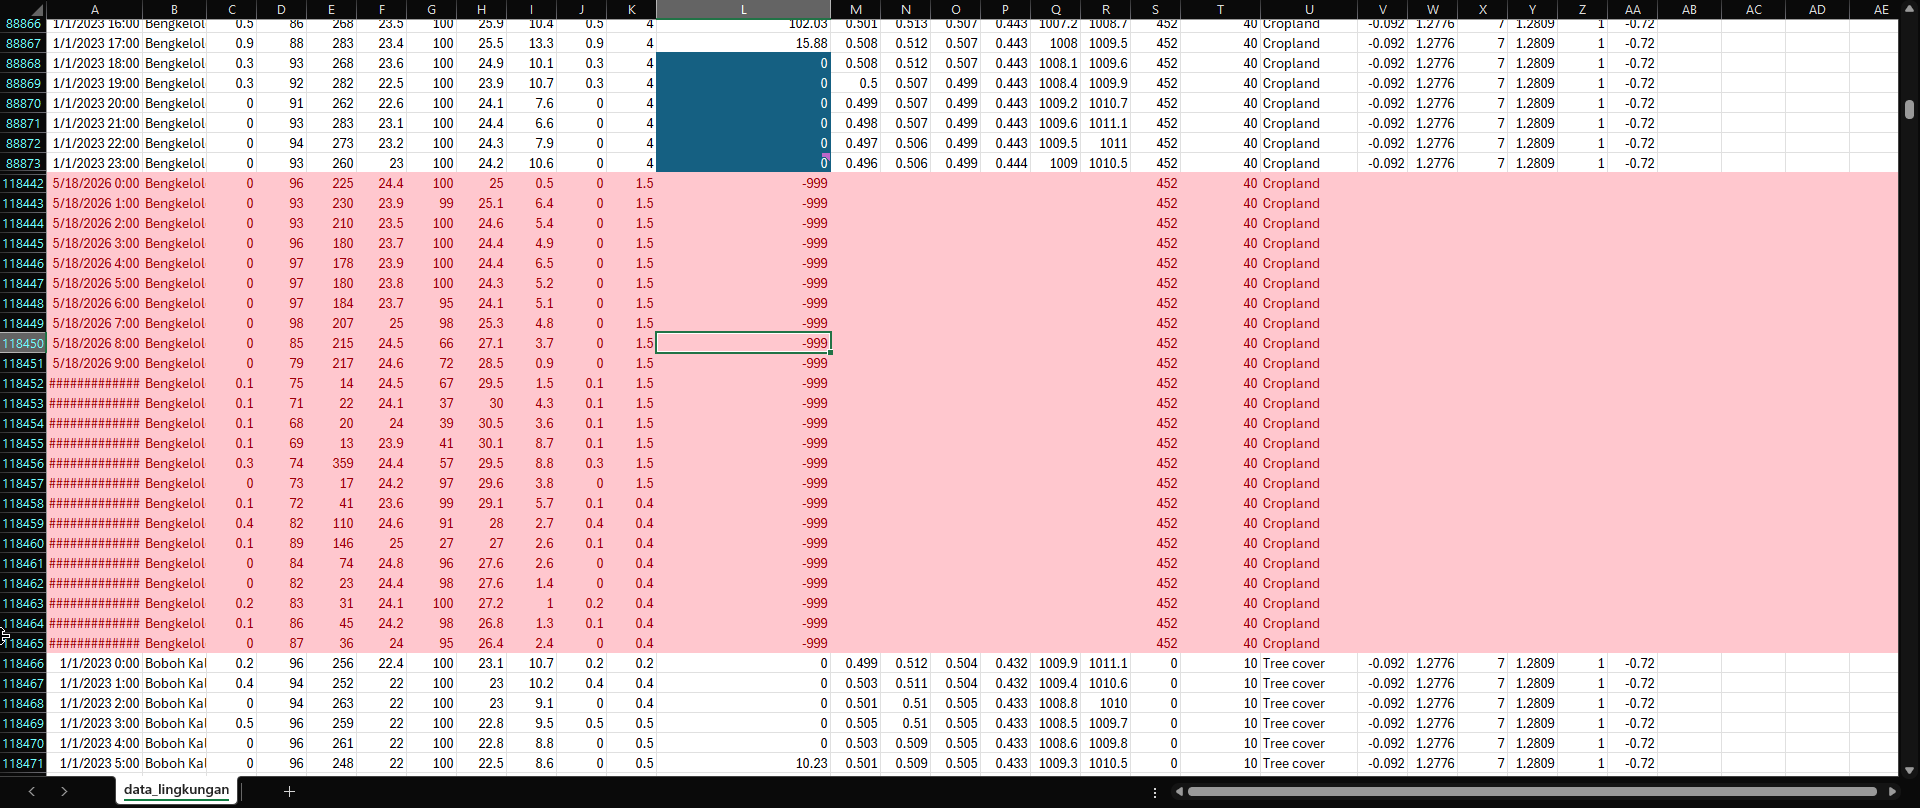


*NB: Baris pada background merah adalah baris yang mempunyai missing value pada fitur-fitur yang telah disebutkan.*

Dilihat bahwa, semua missing value mempunyai pola yang sama:
- Jika semua fitur-fitur yang disebutkan missing, maka berkemungkinan tinggi `solar_radiation_mj_m2` juga mempunyai nilai tidak memungkinkan seperti $-999$.

Karena ini masih hipotesis awal, mari kita buktikan menggunakan korelasi sederhana untuk menentukan, apakah nilai mustahil pada `solar_radiation_mj_m2` berkorelasi tinggi terhadap fitur-fitur yang juga hilang? Dan juga, Klasifikasi apa yang dapat diberikan untuk baris baris tersebut? MCAR? MNAR? MAR?

#### 2.3.1.1 Pembuktian secara korelasi sederhana ($\phi$-Coefficient dan Chi-Square Test of Independence)

In [ ]:
# @title
from scipy.stats import chi2_contingency

# Penanda invalid untuk solar
solar_invalid = df_lingkungan["solar_radiation_mj_m2"].eq(-999)

results = []

# Tes untuk setiap fitur
for col in df_lingkungan.columns:

    if col == "solar_radiation_mj_m2":
        continue

    missing = df_lingkungan[col].isna()

    # Asumsikan violation, jika Tidak ada DAN Tidak sama dengan -999
    violations = df_lingkungan[
        missing &
        df_lingkungan["solar_radiation_mj_m2"].ne(-999)
    ]


    tp = (missing & solar_invalid).sum()
    fp = (missing & ~solar_invalid).sum()
    fn = (~missing & solar_invalid).sum()
    tn = (~missing & ~solar_invalid).sum()

    phi = np.nan
    p = np.nan

    # Kalau ada nilai kosong, lakukan chi-square
    # Kalaupun tabl kontingen tidak kosong pada baris awal
    if missing.any():
        contingency = pd.DataFrame(
            [[tp, fp],
             [fn, tn]]
        )

        try:
            chi2, p, _, _ = chi2_contingency(contingency)
            # Pembilang phi tidak bisa 0
            if contingency.values.sum() > 0:
                phi = np.sqrt(chi2 / contingency.values.sum())
            else:
                phi = np.nan
                p = np.nan
        except ValueError as e:
            # Jika chi2_contingency masih gagal tanpa alasan jelas, skip aja
            print(f"Skip. {col} :{e}")
            phi = np.nan
            p = np.nan
    else: # Kalau tidak ada yang kosong di fiturnya, yaa ngak mungkin ada korelasi
        phi = 0.0 # Tanpa hubungan
        p = 1.0 # Tidak signifikan

    # Presisi / Recall
    precision = tp / (tp + fp) if (tp + fp) else np.nan
    recall = tp / (tp + fn) if (tp + fn) else np.nan

    # Hipotesis alternatif
    counter_missing_only = fp
    counter_solar_only = fn

    # Sebelum dibuat tabel, kita log untuk yang janggal
    if not violations.empty:
        print(f"\n=== {col} ({len(violations)} ?!?) ===")
        display(violations)

    # Store
    results.append({
        "Fitur": col,
        "Miss total": missing.sum(),
        "Solar -999 Count": solar_invalid.sum(),
        "Keduanya missing": tp,
        "Missing tapi Solar Valid": counter_missing_only,
        "Solar -999 tapi Fitur Ada": counter_solar_only,
        "Presisi": precision,
        "Recall": recall,
        "Phi": phi,
        "Chi2 p-value": p

    })

print("<0.05 Chi2 p-val = Signifikan")
result = (
    pd.DataFrame(results)
    .sort_values(
        ["Phi", "Presisi"],
        ascending=False
    )
    .reset_index(drop=True)
)

display(result)

Dari sini kita melihat bahwa hipotesis awal (missing ->  solar $-999$) **benar** ($H_0$). Tetapi jika arahnya kita balik, (solar $-999$ -> missing) maka tidak benar.

Tidak ada kesimpulan kuat, setelah diberikan `2.3.1.2 Hubungan solar` terhadap fitur-fitur yang disebutkan juga bersamaan hilang. Bisa saja data outage.

Sebagai bukti, jika kita coba pergi ke baris 26282, kita dapat melihat bahwa tidak ada satupun fitur yang kita asumsikan jika semua fitur kosong, maka solar $-999$ tidak dibuktikan dalam kasus ini:

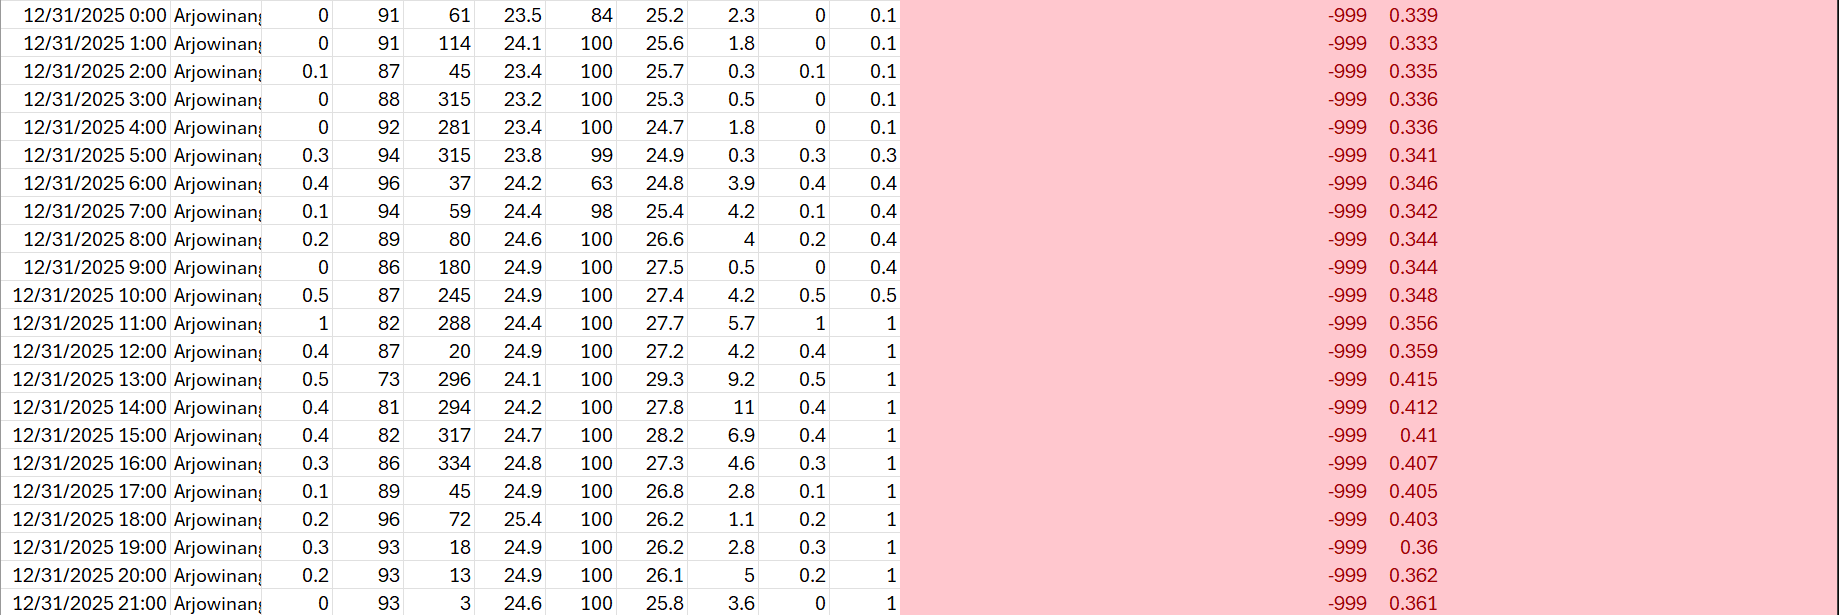

Kami juga melihat pola yang dimana:
P1 :  Jika datettime = 5/18/2026, maka solar = -999, dan N-S and W-Z fitur hilang
P2 : Jika datetime >= 5/14/2026, maka solar = -999

Pada premis ke-2, kita mendapatkan pada datetime = 5/14/2026 8:00, baris sebelumnya mempunyai nilai solar yang normal (>0=). Untuk mengetahui lebih lanjut apakah ini benar untuk semua nilai, mohon lihat analisis lanjutan di [2.3.1.2 Hubungan solar -999 terhadap semua kolom](2.3.1.2-Hubungan-solar-$-999$-terhadap-semua-kolom)

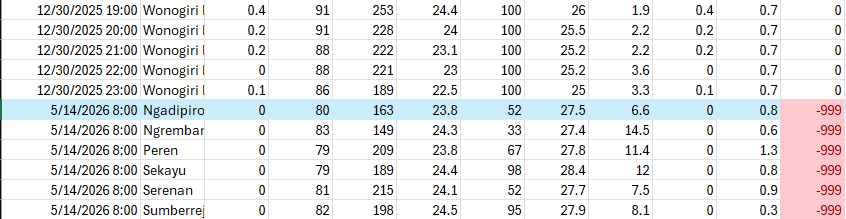

#### 2.3.1.2 Hubungan solar $-999$ terhadap semua kolom

In [ ]:
# @title
from scipy.stats import mannwhitneyu

df_lingkungan['solar_invalid'] = df_lingkungan['solar_radiation_mj_m2'] == -999

invalid_idx = set(df_lingkungan.index[df_lingkungan['solar_invalid']])
print(f"Total baris        : {len(df_lingkungan)}")
print(f"Solar = -999 baris : {len(invalid_idx)}")
print(f"Baris       : {invalid_idx}")

# ------------

num_cols = df_lingkungan.select_dtypes(include=np.number).columns.tolist()
num_cols = [c for c in num_cols if c not in ['solar_radiation_mj_m2', 'solar_invalid']]

rows = []
for col in num_cols:
    valid   = df_lingkungan.loc[~df_lingkungan['solar_invalid'], col].dropna()
    invalid = df_lingkungan.loc[ df_lingkungan['solar_invalid'], col].dropna()

    if len(valid) < 2 or len(invalid) < 2:
        continue

    _, p = mannwhitneyu(valid, invalid, alternative='two-sided')

    rows.append({
        'col'            : col,
        'mean_valid'        : round(valid.mean(),   4),
        'mean_invalid'      : round(invalid.mean(), 4),
        'mean_diff'         : round(invalid.mean() - valid.mean(), 4),
        'mannwhitney_p'     : round(p, 6),
        'signifikan_p.05'  : p < 0.05
    })

numeric_result = (pd.DataFrame(rows)
                    .sort_values('mannwhitney_p')
                    .reset_index(drop=True))

print("\n=== Kolom numerik vs solar=-999 ===")
print(numeric_result.to_string())

# -----------
cat_cols = df_lingkungan.select_dtypes(include=['object', 'category']).columns.tolist()

print("\n=== Kolom kategori: rate kesalahan per kategori ===")
for col in cat_cols:
    print(f"\n── {col} ──")
    tmp = (df_lingkungan.groupby(col)['solar_invalid']
             .agg(invalid_rate='mean', n='size')
             .sort_values('invalid_rate', ascending=False))
    print(tmp.to_string())

# -----------

df_lingkungan['datetime'] = pd.to_datetime(df_lingkungan['datetime'])

print("\n=== Rate kesalahan per jam ===")
print(df_lingkungan.groupby(df_lingkungan['datetime'].dt.hour)['solar_invalid']
        .agg(invalid_rate='mean', n='size').to_string())

print("\n=== Rate kesalahan per bulan ===")
print(df_lingkungan.groupby(df_lingkungan['datetime'].dt.month)['solar_invalid']
        .agg(invalid_rate='mean', n='size').to_string())

# ----------

sig = numeric_result[numeric_result['signifikan_p.05']].copy()

if len(sig):
    fig, axes = plt.subplots(
        nrows=len(sig), ncols=1,
        figsize=(8, 3 * len(sig)),
        constrained_layout=True
    )
    if len(sig) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, sig.iterrows()):
        col = row['col']
        df_lingkungan.boxplot(
            column=col,
            by='solar_invalid',
            ax=ax,
            boxprops=dict(color='steelblue'),
            medianprops=dict(color='red')
        )
        ax.set_title(f"{col}  (p={row['mannwhitney_p']})")
        ax.set_xlabel("solar_invalid  (False=valid, True=-999)")
        ax.set_ylabel(col)

    plt.suptitle("Kolom berbeda signifikan saat solar=-999", y=1.01)
    plt.show()
else:
    print("Tidak ada kolom numerik signifikan ditemukan")

Hasil analisis menunjukkan bahwa nilai -999 MJ pada kolom solar (radiasi/energi surya) hampir 100% adalah "Missing Value Marker" (tanda bahwa data kosong/rusak), bukan nilai minus sungguhan.

Ditambah lagi, angka -999 atau -99 sering dipakai oleh sistem sensor otomatis untuk melambangkan "Sensor Error" atau "Gagal Membaca Data".

Pada hasil dua kelompok yang terbagi: Valid (data solar normal) dan Invalid (data solar = -999). Berdasarkan hasil uji statistik (Mann-Whitney U Test dan tingkat kegagalan), hasil menunjukan:

1. **Pola Cuaca Saat Sensor Rusak (Kolom Numerik) ($\bbox[green]{\text{Signifikan}}$)**
Hampir semua kolom numerik menunjukkan nilai signifikan_p.05 = True dengan mannwhitney_p = 0.0. Artinya, kondisi cuaca saat data solar rusak berbeda nyata secara statistik dibandingkan saat data normal.

Jika kita lihat nilai mean_diff (selisih rata-rata Kelompok Invalid dikurang Kelompok Valid):

**Lebih Lembap & Berawan**: Saat data rusak (invalid), kelembapan (humidity_pct) lebih tinggi sekitar ~5.8%, tutupan awan (cloud_cover_pct) lebih tinggi ~10.4%, dan kelembapan tanah (soil_moisture) juga lebih tinggi.

**Lebih Banyak Hujan**: Curah hujan (rainfall_mm) lebih tinggi di kelompok invalid.

**Suhu Lebih Rendah**: Suhu udara (temperature_c) sedikit lebih dingin (-0.54°C).

**$\bbox[green]{\text{Kesimpulan}}$**: Sensor solar ini kemungkinan besar sensitif terhadap cuaca buruk (hujan/mendung tebal). Saat hujan atau awan terlalu tebal, sensor mengalami error atau tidak mendapat suplai daya/sinyal yang cukup, sehingga memunculkan angka -999.

2. **Bukan Masalah Lokasi atau Jam (Kolom Kategori & Jam) ($\bbox[red]{\text{Tiada kesimpulan signifikan}}$)**
Per Lokasi (nama_pos) & Landcover: Tingkat error-nya sama rata di angka 0.112642 (~11.2%) untuk semua pos dan semua jenis tutupan lahan. Ini artinya eror ini tidak disebabkan oleh satu stasiun yang rusak sendiri, melainkan fenomena yang terjadi serentak di semua alat stasiun.

Per Jam (datetime): Angka error-nya juga sama rata 0.112642 dari jam 0 sampai jam 23. Ini membuktikan bahwa error -999 ini bukan karena malam hari tidak ada matahari (kalau karena malam hari, harusnya tingkat eror melonjak di jam 18.00–05.00). Ini murni masalah teknis/sistem.

3. **Pola Musiman (Rate Kesalahan per Bulan) ($\bbox[green]{\text{Signifikan}}$)**

Januari - April: Tingkat error sangat tinggi (25% atau 1 dari 4 data rusak).

Mei: Mulai turun ke 16.2%.

Juni - November: Tingkat error 0% (tidak ada error sama sekali!).

Desember: Mulai muncul error sedikit (1.0%).

**$\bbox[green]{\text{Kesimpulan Akhir}}$**: Error -999 pada kolom solar ini berkorelasi kuat dengan Musim Hujan di Indonesia (Desember–April). Saat musim kemarau (Juni–November), sensor bekerja sempurna tanpa eror.

#### 2.3.1.3 Kesimpulan

Dalam kasus ini, dan berdasarkan informasi yang kita kumpulkan. Adanya nilai mustahil solar seperti $-999$ terklafikasi sebagai MNAR. Nilai ini biasanya mustahil didapatkan secara teori fisika tentang energi, dan merupakan kode sentinel. Dan sangat mungkin merupakan bagian dari kesalahan komputer. Tetapi dari hasil 2.3.1.1, sangat kemungkinan besar juga adalah hasil dari musim seperit hujan.

Tetapi untuk nilai-nilai missing dari semua fitur yang kita sebutkan di awal, juga diasumsikan MCAR karena, tidak ada hubungan ataupun korelasi kuat atas kenapa fitur-fitur tersebut kosong, dan kejadianya selalu bertepatan pada tanggal 18/5/2026 (butuh pembuktian lebih lanjut, lihat ToDo trello), jika benar, MAR.

Solusi untuk kasus tanggal 18/5/20262, dimana solar $-999$, dan N-S dan W-Z fitur juga kosong, adalah dengan mengubah setiap solar=$-999$ menjadi Null, dan di drop, melakukan penghapusan perbaris (*listwise-deletion*). Ditambah lagi, sampel dalam kasus ini juga sangat sedikit, sehingga populasi tetap valid, jikalaupun beberapa sampel dihapus.

## 2.4 Analisis Univariat

### 2.4.05 Modul

In [ ]:
# @title
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)

if "df_eda" in globals() and {"tma_anomaly", "tma_climatology"}.issubset(df_eda.columns):
    data_master = df_eda.copy()
else:
    data_master = df_final.copy()
    data_master["datetime"] = pd.to_datetime(data_master["datetime"])
    data_master["jam"] = data_master["datetime"].dt.hour
    data_master["day_of_year"] = data_master["datetime"].dt.dayofyear

    # Climatology sederhana untuk membuat anomaly jika bagian 4 belum dijalankan.
    # Untuk modelling/validasi, climatology wajib dihitung hanya dari train fold.
    clim = (
        data_master.groupby(["nama_pos", "jam", "day_of_year"], as_index=False)
        ["tma_mdpl"].median()
        .rename(columns={"tma_mdpl": "tma_climatology"})
    )
    data_master = data_master.merge(
        clim, on=["nama_pos", "jam", "day_of_year"], how="left"
    )
    data_master["tma_anomaly"] = (
        data_master["tma_mdpl"] - data_master["tma_climatology"]
    )

data_master["datetime"] = pd.to_datetime(data_master["datetime"])
data_master = data_master.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)


def pasangan_horizon(data, fitur, horizon, target_cols):
    """Pasangkan origin dengan observasi tepat h hari kemudian."""
    origin = data[["nama_pos", "datetime"] + fitur].copy()
    origin["datetime_target"] = origin["datetime"] + pd.Timedelta(days=horizon)
    target = data[["nama_pos", "datetime"] + target_cols].copy()
    target = target.rename(columns={
        "datetime": "datetime_target",
        **{c: f"future_{c}" for c in target_cols}
    })
    return origin.merge(target, on=["nama_pos", "datetime_target"], how="inner")


def korelasi_per_pos(data, features, target, min_n=30):
    """Spearman per pos; aman terhadap fitur konstan dan sampel kecil."""
    rows = []
    for pos, g in data.groupby("nama_pos"):
        for feature in features:
            valid = g[[feature, target]].replace([np.inf, -np.inf], np.nan).dropna()
            if len(valid) < min_n or valid[feature].nunique() < 2:
                continue
            rows.append({
                "nama_pos": pos,
                "feature": feature,
                "target": target,
                "n": len(valid),
                "spearman": valid[feature].corr(valid[target], method="spearman")
            })
    return pd.DataFrame(rows)


def plot_heatmap(data, index, columns, values, title, center=0, cmap="vlag"):
    if data.empty:
        print("Tidak ada data cukup untuk:", title)
        return
    table = data.pivot(index=index, columns=columns, values=values)
    plt.figure(figsize=(max(8, .8 * len(table.columns)), max(4, .42 * len(table))))
    sns.heatmap(table, cmap=cmap, center=center, annot=True, fmt=".2f")
    plt.title(title)
    plt.tight_layout()
    plt.show()


### 2.4.1 Terhadap `tma_mdpl` (Tinggi Air)

#### 2.4.1.1 Distribusi

##### 2.4.1.1.1 Distribusi (tanpa dikategorikan terhadap `nama_pos`)

In [ ]:
sns.histplot(data=df_combined, x='tma_mdpl', kde=True, color='skyblue', edgecolor='black')
plt.title('Histogram and KDE tma_mdpl', fontsize=14)
plt.xlabel('tma_mdpl', fontsize=12)
plt.ylabel('Densitas', fontsize=12)
plt.tight_layout()
plt.savefig('tma_mdpl_plot.png')

Poin distribusi:
- Modalitas => Multi-modal

Hypothesis data:
- **Dari 0 sampai ~20**: Frekuensi tertinggi, kemungkinan ini juga batas/ambang normal tinggi airnya.
- **Dari ~80 sampai ~90**: Frekuensi tertinggi juga, seperti frekuensi pada ~0 sampai dengan ~20. Terlihat seakan-akan memuncak gitu aja, hipotesis yang memungkinkan:
  - Data dari semua stasiun kemungkinan bergabung, jadi kemungkinan ada satu yang pendek, tapi ada satu yang sering banjir. $\bbox[green]{\text{Solusi}}$: Pisahkan berdasarkan nama stasiun, lakukan analisis KDE dan Histo sekali lagi.
- **Dari ~120 sampai ~150**: Memuncak juga, tapi lebih pendek, kemungkinan ini stasiun yang lebih tinggi. Biasanya di puncak gunung.
  - $H_1$: Adanya stasiun yang lebih tinggi, seperti di puncak gunung
- **Dari ~150 + 320+**: Distribusi udah mulai memudar, jikalaupun ada nilai outlier disini *(4, berdasarkan analisis IQR pada 2.2::df_combined)*, berarti kmungkinan adanya situasi banjir, atau juga bisa stasiun yang lebih tinggi(?)
  - $H_2^?$: adanya stasiun yang sangat lebih tinggi

Selanjutnya akan dilakukan:
- $\bbox[green]{\text{Analisis 1}}$: Pisahkan berdasarkan nama stasiun, lakukan analisis KDE dan Histo sekali lagi. (2.4.1.1.2)
- $\bbox[green]{\text{Analisis 2}}$: Analisa dengan korelasi time-lag
- $\bbox[green]{\text{Analisis 3}}$: Lanjutan dari Analisis 3, tetapi lakukan korelasi heat map terhadap fitur fitur yang rasanya penting, seperti `rainfall_mm`. Nah, nanti kan untuk tiap korelasi heat map untuk tiap `nama_pos`, ntar kita cari korelasi sekali dari korelasi heatmap itu sendiri.. Jadi lebih tepatnya, kita melakukan korelasi heatmap versi 3D. Misalnya nanti ada korelasi heatmap untuk `pos_name`=A,B,C itu nanti kita bisa nampak mana salah satu fitur yang korelasinya selalu tinggi, ntar kita rata-ratakan.

##### 2.4.1.1.2 Distribusi (dikategorikan terhadap `nama_pos`)

In [ ]:
# @title
def distribusi_fitur_terhadap_fitur_lain(
    df,
    station_col="nama_pos",
    value_col="tma_mdpl",
    bins=30,
    ncols=3,
    figsize_per_plot=(5, 4),
):
    stations = sorted(df[station_col].dropna().unique())
    nplots = len(stations)
    nrows = math.ceil(nplots / ncols)
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(
            figsize_per_plot[0] * ncols,
            figsize_per_plot[1] * nrows
        ),
        squeeze=False
    )
    axes = axes.flatten()
    for ax, station in zip(axes, stations):
        series = (
            df.loc[df[station_col] == station, value_col]
            .dropna()
        )
        sns.histplot(
            series,
            bins=bins,
            kde=True,
            stat="count",
            ax=ax
        )
        ax.set_title(station)
        ax.set_xlabel(value_col)
        ax.set_ylabel("Count")
    for ax in axes[nplots:]: # kalau ada plot gk kepakai hilangin aja
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

distribusi_fitur_terhadap_fitur_lain(df_combined, "nama_pos", "tma_mdpl")

In [ ]:
# @title
import math
import matplotlib.pyplot as plt
import pandas as pd

def plot_fitur_terhadap_waktu(
    df,
    station_col="nama_pos",
    value_col="tma_mdpl",
    datetime_col="datetime",
    ncols=3,
    figsize_per_plot=(6, 4),
):
    df_copy = df.copy()
    df_copy[datetime_col] = pd.to_datetime(df_copy[datetime_col])

    stations = sorted(df_copy[station_col].dropna().unique())
    nplots = len(stations)
    nrows = math.ceil(nplots / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(
            figsize_per_plot[0] * ncols,
            figsize_per_plot[1] * nrows
        ),
        squeeze=False
    )
    axes = axes.flatten()

    for ax, station in zip(axes, stations):

        station_data = (
            df_copy.loc[
                df_copy[station_col] == station,
                [datetime_col, value_col]
            ]
            .dropna()
            .sort_values(datetime_col)
        )

        if station_data.empty:
            ax.text(0.5, 0.5, "no data",
                    ha="center", va="center")
            ax.set_title(station)
            continue

        y = station_data[value_col]

        # --------------------------
        # statistics
        # --------------------------
        mean = y.mean()
        std = y.std()

        q1 = y.quantile(0.25)
        q3 = y.quantile(0.75)

        minus3std = mean - 5 * std
        plus3std = mean + 5 * std

       # Optional: highlight outliers
        outliers = station_data[
            (y < minus3std) | (y > plus3std)
        ].copy()

        if not outliers.empty:

            # Hitung Z-score
            outliers["z_score"] = (outliers[value_col] - mean) / std

            # Ambil nilai sebelum & sesudah
            outliers["previous_time"] = station_data[datetime_col].shift(1).loc[outliers.index]
            outliers["previous_value"] = station_data[value_col].shift(1).loc[outliers.index]

            outliers["next_time"] = station_data[datetime_col].shift(-1).loc[outliers.index]
            outliers["next_value"] = station_data[value_col].shift(-1).loc[outliers.index]

            # Plot titik outlier
            ax.scatter(
                outliers[datetime_col],
                outliers[value_col],
                color="crimson",
                s=18,
                zorder=5,
                label=">5σ Outlier",
            )

            # Print lokasi outlier
            print("\n" + "=" * 120)
            print(f"Station : {station}")
            print(f"Total Outlier (>3σ): {len(outliers)}")
            print(
                outliers[
                    [
                        "previous_time",
                        "previous_value",
                        datetime_col,
                        value_col,
                        "next_time",
                        "next_value",
                        "z_score",
                    ]
                ].to_string(index=False)
            )

        # --------------------------
        # time series
        # --------------------------
        ax.plot(
            station_data[datetime_col],
            y,
            color="steelblue",
            linewidth=1,
            alpha=0.8,
            label=value_col,
        )

        # --------------------------
        # mean
        # --------------------------
        ax.axhline(
            mean,
            color="red",
            linestyle="--",
            linewidth=1.8,
            label=f"mean ({mean:.2f})",
        )

        # --------------------------
        # quartiles
        # --------------------------
        ax.axhline(
            q1,
            color="green",
            linestyle=":",
            linewidth=1.5,
            label=f"q1 ({q1:.2f})",
        )

        ax.axhline(
            q3,
            color="green",
            linestyle=":",
            linewidth=1.5,
            label=f"q3 ({q3:.2f})",
        )

        # shade iqr region
        ax.axhspan(
            q1,
            q3,
            color="green",
            alpha=0.08,
            zorder=0,
        )

        # --------------------------
        # ±3 standard deviations
        # --------------------------
        ax.axhline(
            minus3std,
            color="purple",
            linestyle="-.",
            linewidth=1.5,
            label=f"-5σ ({minus3std:.2f})",
        )

        ax.axhline(
            plus3std,
            color="purple",
            linestyle="-.",
            linewidth=1.5,
            label=f"+5σ ({plus3std:.2f})",
        )

        # optional: highlight outliers
        outliers = station_data[
            (y < minus3std) | (y > plus3std)
        ]

        if not outliers.empty:
            ax.scatter(
                outliers[datetime_col],
                outliers[value_col],
                color="crimson",
                s=18,
                zorder=5,
                label=">5σ outlier",
            )

        ax.set_title(station)
        ax.set_xlabel("time")
        ax.set_ylabel(value_col)

        ax.tick_params(axis="x", rotation=35)
        ax.legend(fontsize=7)

    # Remove unused axes
    for ax in axes[nplots:]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

plot_fitur_terhadap_waktu(df_train, "nama_pos", "tma_mdpl")

###### Outlier!

========================================================================================================================
Station : Bojonegoro - Kali Kethek
      previous_time  previous_value            datetime  tma_mdpl           next_time  next_value   z_score
2023-11-23 06:00:00            6.54 2023-11-23 12:00:00    225.13 2023-11-23 18:00:00        6.52 37.786494
2023-11-27 18:00:00            7.24 2023-11-28 06:00:00    174.13 2023-11-28 12:00:00        7.02 28.867769

=============================================================================================================
Station : Floodway Bridge C
Total Outlier (>5σ): 1
      previous_time  previous_value            datetime  tma_mdpl           next_time  next_value  z_score
2025-06-15 12:00:00             4.7 2025-06-15 18:00:00      47.0 2025-06-16 06:00:00    2.434565 31.24392

========================================================================================================================
Station : Jarum
Total Outlier (>5σ): 4
      previous_time  previous_value            datetime   tma_mdpl           next_time  next_value   z_score
2023-02-22 12:00:00       90.740000 2023-02-22 18:00:00 250.140000 2023-02-23 06:00:00   91.340000 40.684136
2023-03-10 12:00:00       90.840000 2023-03-10 18:00:00 150.140000 2023-03-11 06:00:00   90.542677 15.163950
2023-03-11 06:00:00       90.542677 2023-03-11 12:00:00 135.140000 2023-03-11 18:00:00   90.540000 11.335922
2023-05-11 12:00:00       90.690000 2023-05-11 18:00:00 200.395917 2023-05-12 06:00:00   91.711323 27.989354

========================================================================================================================
Station : Jurug
Total Outlier (>5σ): 1
      previous_time  previous_value            datetime  tma_mdpl           next_time  next_value    z_score
2025-02-03 18:00:00           79.58 2025-02-28 06:00:00       0.0 2025-02-28 18:00:00       80.73 -40.550287

========================================================================================================================
Station : Kajangan
Total Outlier (>5σ): 1
      previous_time  previous_value            datetime  tma_mdpl           next_time  next_value   z_score
2023-08-02 06:00:00        50.13306 2023-08-02 12:00:00    172.77 2023-08-02 18:00:00       50.01 46.664132

========================================================================================================================
Station : Kali Anyar - Kreteg Abang
Total Outlier (>5σ): 1
      previous_time  previous_value            datetime   tma_mdpl           next_time  next_value   z_score
2023-06-13 12:00:00           87.59 2023-06-13 18:00:00 323.207409 2023-06-14 06:00:00       87.64 53.030883

========================================================================================================================
Station : Kali Pepe - PTPN
Total Outlier (>5σ): 3
      previous_time  previous_value            datetime  tma_mdpl           next_time  next_value    z_score
2023-05-23 18:00:00           82.47 2023-05-24 06:00:00    122.07 2023-05-24 12:00:00       82.47  19.735154
2023-11-04 12:00:00           82.35 2023-11-04 18:00:00      0.00 2023-11-05 06:00:00       82.35 -41.217854
2023-12-18 06:00:00           82.63 2023-12-18 12:00:00    138.07 2023-12-18 18:00:00       82.61  27.724408

========================================================================================================================
Station : Karangnongko
Total Outlier (>5σ): 3
      previous_time  previous_value            datetime  tma_mdpl           next_time  next_value   z_score
2023-05-30 06:00:00           21.58 2023-05-30 12:00:00     177.0 2023-05-30 18:00:00       21.57 30.740808
2023-06-09 12:00:00           21.55 2023-06-09 18:00:00     172.0 2023-06-10 06:00:00       21.50 29.744756
2023-06-29 12:00:00           21.44 2023-06-29 18:00:00     164.0 2023-06-30 06:00:00       21.43 28.151072

========================================================================================================================
Station : Kedungupit
Total Outlier (>5σ): 1
      previous_time  previous_value            datetime  tma_mdpl           next_time  next_value   z_score
2023-10-25 12:00:00           64.01 2023-10-25 18:00:00 207.73648 2023-10-26 06:00:00       63.84 46.363355

========================================================================================================================
Station : Ketonggo
Total Outlier (>5σ): 1
      previous_time  previous_value            datetime  tma_mdpl           next_time  next_value    z_score
2023-10-11 12:00:00       35.910622 2023-10-11 18:00:00 -0.059668 2023-10-12 06:00:00       35.71 -20.043545

========================================================================================================================
Station : Napel
Total Outlier (>5σ): 1
      previous_time  previous_value            datetime  tma_mdpl           next_time  next_value   z_score
2023-04-09 18:00:00           34.95 2023-04-10 06:00:00    325.83 2023-04-10 12:00:00       34.55 51.230282

========================================================================================================================
Station : Peren
Total Outlier (>5σ): 2
      previous_time  previous_value            datetime  tma_mdpl           next_time  next_value   z_score
2023-11-09 12:00:00           90.85 2023-11-09 18:00:00     160.1 2023-11-10 06:00:00       90.80 34.117316
2025-04-28 18:00:00           90.90 2025-04-29 06:00:00     170.1 2025-04-29 12:00:00       90.85 39.076599



Analisis:
Stasiun pada level Gunung (Sumber: Google Gemini, dengan sumber):
- Gatuk: 190-200 mdpl $\bbox[green]{\text{Valid}}$
- Ngembat: 140-143 mdpl $\bbox[green]{\text{Valid}}$

- Ngadipiro: 143-144 mdpl $\bbox[green]{\text{Valid}}$
- Badegan: 112-114 mdpl $\bbox[green]{\text{Valid}}$
- Golek & Wonogiri: 125-138 mdpl. $\bbox[green]{\text{Valid}}$

Stasiun pada level Rendah (Sumber: Google Gemini, dengan sumber):
- Arjosari/Arjowinangun - Pcaitan: 1-2 mdpl $\bbox[green]{\text{Valid}}$
- Babat Kali Lamong: 1-6 mdpl $\bbox[green]{\text{Valid}}$
- Plangki: 1-2 mdpl $\bbox[green]{\text{Valid}}$

Maka: $H_1$ benar.


Kemungkinan tidak valid:
- (Bojonegoro - Kali Ketek, Kedungupit, Peron, Catur): Plot ini nunjukin satu bar yang ntah gimana kedorong sangat jauh di sini kiri, masih tidak diketahui kenapa ini terjadi, tapi ada hipotesis seperti:
  - Kalibrasi sensor yang error, yang default ke numerik 0. $\bbox[maroon]{\text{Tidak diketahui}}$
- (Gatuk, Kali Pepe - PIPA): Sama kayak yang diatas, cuman versi ekstrimnya.

$\bbox[green]{\text{Solusi}}$: Normalisasikan data, suka hati mau pakai apa z-score, min-max.

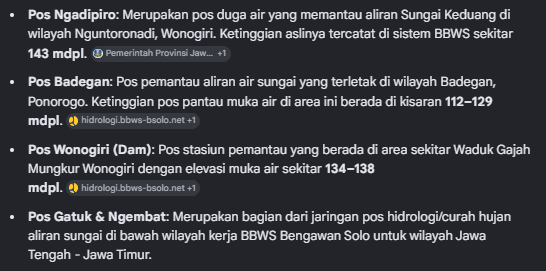

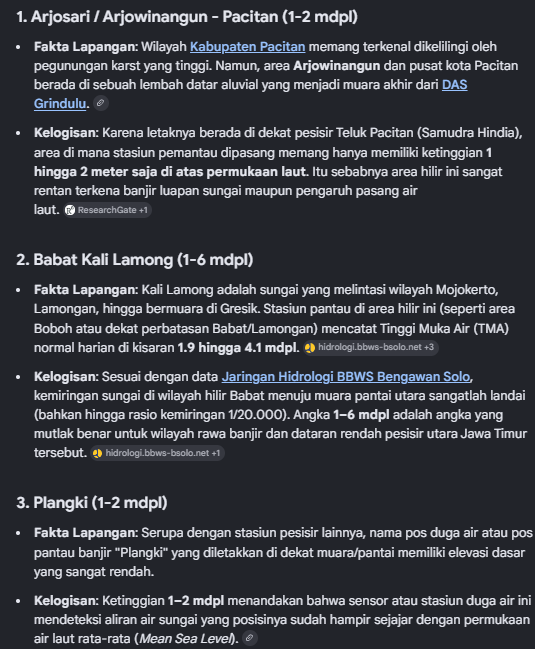

#### 2.4.1.2 Korelasi Heatmap

##### 2.4.1.2.1 Korelasi Heatmap 3-dimensi terhadap semua fitur DIBAWAH tiap nilai unik `pos_name`

In [ ]:
# @title
def analisis_stasiun_lengkap(df, station_col="nama_pos", target_col="tma_mdpl"):
    stations = sorted(df[station_col].dropna().unique())
    all_corr_matrices = []

    # 1. Plot korelasi heatmap per stasiun
    ncols = 2
    nrows = math.ceil(len(stations) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 5 * nrows))
    axes = axes.flatten()
    for i, station in enumerate(stations):
        # Filter data per stasiun
        station_df = df[df[station_col] == station].select_dtypes(include=[np.number])
        # Hitung korelasi
        corr_matrix = station_df.corr()
        all_corr_matrices.append(corr_matrix)
        # Plot Heatmap
        sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', ax=axes[i], cbar=True)
        axes[i].set_title(f"Correlation Heatmap: {station}")
    # Hapus axes sisa
    for j in range(len(stations), len(axes)):
        fig.delaxes(axes[j])
    plt.tight_layout()
    plt.show()
    # 2. Analisis Agregat (Mencari korelasi rata-rata tertinggi)
    # Kita tumpuk semua matriks korelasi untuk mencari rata-ratanya
    combined_corr = pd.concat(all_corr_matrices)
    avg_corr = combined_corr.groupby(combined_corr.index).mean()
    print("\n=== Rata-rata Korelasi Antar Fitur di Semua Stasiun ===")
    plt.figure(figsize=(12, 8))
    sns.heatmap(avg_corr, annot=True, fmt=".2f", cmap='RdYlGn')
    plt.title("Matrix Korelasi rata-rata terhadap semua stasiun")
    plt.show()
    # Ambil fitur dengan korelasi rata-rata tertinggi terhadap target
    if target_col in avg_corr.columns:
        top_corr = avg_corr[target_col].sort_values(ascending=False)
        print(f"\nFitur dengan korelasi tertinggi terhadap {target_col} (rata-rata):")
        print(top_corr)

analisis_stasiun_lengkap(df_combined)

*NB: Dikarenakan terlalu banyak informasi yang bisa saja dijelaskan di sini, tetapi informasi ini hanya difokuskan kepada variabel target (`tma_mdpl`)*

Hubungan utama berdasarkan fitur-fitur yang memiliki korelasi tinggi terhadap `tma_mdpl`:

1. Hubungan Utama: Kejenuhan Tanah (Soil Moisture): Secara realita masuk akal. Gini, **air yang ada di sungai tidak hanya datang dari air hujan yang langsung jatuh ke permukaan sungai, tetapi juga dari limpasan permukaan (surface runoff) dan rembesan tanah setelah tanah jenuh**.
- Ketika lapisan tanah atas (0-28cm) basah dan jenuh, tanah tidak bisa lagi menyerap air. **Akibatnya, kalau ada hujan tambahan, air akan otomatis mengalir ke sungai dan menaikkan tma_mdpl secara drastis**.
- Lapisan Dalam (100-255cm) Korelasinya Rendah (0.14): Ini juga realistis. Dikarenakan, lapisan tanah yang sangat dalam membutuhkan waktu berhari-hari atau berminggu-minggu untuk menyerap air hujan, sehingga tidak langsung memengaruhi lompatan/fluktuasi harian air sungai.

2. Paradoks Hujan: Korelasi rainfall_max_24h_mm (0.31) jauh lebih tinggi daripada korelasi hujan per jam/seketika rainfall_mm (0.09)? Kok bisa?
- (Efek Jeda Waktu / Time Lag): Sungai memiliki waktu respons (concentration time). Hujan lebat yang terjadi jam 1 siang tidak langsung membuat sungai di hilir meluap di jam 1 siang itu juga. Jadi, **air butuh waktu untuk mengalir dari bukit, masuk ke anak sungai, hingga akhirnya berkumpul di sungai utama. Oleh karena itu, akumulasi hujan dalam 24 jam terakhir jauh lebih menentukan volume air total di sungai dibanding data hujan real-time per jam.**

3. Faktor Atmosfer & Cuaca Lintasan (Korelasi Positif): Fitur seperti dew_point_c (0.30), humidity_pct (0.25), dan cloud_cover_pct (0.21) berkorelasi positif.
- **Kelembapan tinggi, titik embun tinggi, dan tutupan awan yang tebal adalah indikator kuat bahwa atmosfer sedang berada dalam kondisi tidak stabil dan siap memicu hujan (kondisi monsun/musim hujan)**. Secara tidak langsung, ketika cuaca mendung dan lembap secara terus-menerus, penguapan berkurang dan curah hujan meningkat, menjaga permukaan air tetap tinggi.

4. Indikator Tekanan & Suhu (Korelasi Negatif): Fitur surface_pressure_hpa (-0.22), pressure_msl_hpa (-0.21), dan temperature_c (-0.11) memiliki korelasi negatif.
- **Tekanan Udara Rendah = Badai/Hujan: Dalam meteorologi, tekanan udara yang rendah (low pressure system) menandakan adanya konvergensi udara yang memicu pertumbuhan awan badai dan hujan lebat**. Jadi, saat tekanan udara turun (makin negatif), permukaan air justru naik (karena hujan).

5. Indikator Makro: nino_34 (-0.18) & Nilai indeks El Niño (nino_34) menunjukkan korelasi negatif.
- (Efek La Niña): **Di wilayah Indonesia, nilai nino_34 yang negatif berarti wilayah Pasifik mendingin, yang menandakan terjadinya fenomena La Niña.** Fenomena La Niña membawa pasokan uap air berlebih ke Indonesia yang menyebabkan musim hujan lebih basah/panjang. Korelasi negatif ini menyatakan: semakin negatif nilai Nino 3.4 (makin kuat La Niña), maka permukaan air (tma_mdpl) cenderung makin tinggi.

#### 2.4.1.3 Hubungan secara Time-Series

##### 2.4.1.3.1 Terhadap `tma_mdpl` dan beberapa variabel korelasi tinggi (ACF & PACF)

In [ ]:
# @title
from sklearn.preprocessing import MinMaxScaler # ini metode normalisasinya, boleh ganti
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

def plot_ts(
    df,
    station_col="pos_name",
    datetime_col="datetime",
    target="tma_mdpl",
    features=None,
    ncols=4,
    lags=30,
):
    if features is None: # ini default, ini diambil dari 2.4.1.2.1, fitur paling berkorelatif
        features = [
            "rainfall_max_24h_mm",
            "soil_moisture_0_7cm",
        ]
    df = df.copy()
    df[datetime_col] = pd.to_datetime(df[datetime_col])
    stations = sorted(df[station_col].dropna().unique())
    nrows = math.ceil(len(stations) / ncols)
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(6 * ncols, 4 * nrows),
        squeeze=False,
        sharex=False
    )
    axes = axes.flatten()
    scaler = MinMaxScaler()
    for ax, station in zip(axes, stations):
        d = (
            df[df[station_col] == station]
            .sort_values(datetime_col)
            .set_index(datetime_col)
        )
        cols = [target] + features
        daily = d[cols].resample("D").mean()
        # normalisasikan prediktor
        scaled = daily.copy()
        if len(features):
            scaled[features] = scaler.fit_transform(
                daily[features]
            )
        # target
        sns.lineplot(
            data=scaled,
            x=scaled.index,
            y=target,
            ax=ax,
            linewidth=2.8,
            label=target
        )
        # prediktor
        palette = sns.color_palette("tab10", len(features))
        for feature, color in zip(features, palette):
            sns.lineplot(
                data=scaled,
                x=scaled.index,
                y=feature,
                ax=ax,
                linewidth=1.4,
                color=color,
                alpha=.85,
                label=feature
            )
        ax.set_title(station)
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.legend(fontsize=8)
    for ax in axes[len(stations):]:
        fig.delaxes(ax)
    plt.tight_layout()
    plt.show()
    # ACF PACF
    for station in stations:
        d = (
            df[df[station_col] == station]
            .sort_values(datetime_col)
            .set_index(datetime_col)
        )
        daily = d[[target] + features].resample("D").mean()
        print("=" * 80)
        print(station)
        print("=" * 80)
        for variable in daily.columns:
            series = daily[variable].dropna()
            if len(series) < lags + 5:
                continue
            fig, ax = plt.subplots(
                1,
                2,
                figsize=(10,3)
            )
            plot_acf(
                series,
                lags=lags,
                ax=ax[0]
            )
            plot_pacf(
                series,
                lags=lags,
                ax=ax[1],
                method="ywm"
            )
            ax[0].set_title(f"{variable} ACF")
            ax[1].set_title(f"{variable} PACF")
            plt.suptitle(station)
            plt.tight_layout()
            plt.show()

plot_ts(
    df_combined,
    station_col="nama_pos",
    datetime_col="datetime",
    target="tma_mdpl",
    features=[
        "soil_moisture_7_28cm",
        "rainfall_max_24h_mm",
        "dew_point_c",
        "humidity_pct",
        "nino_34",
    ],
)

*NB: Jangan ketipu sama grafik visualnya, saat variabel target adalah nilai yang besar, pergerakan fitur exogen tetap masih ada. Jadikan ACF dan PACF pacuan utama!*

ACF: korelasi antara observasi sekarang dengan observasi pada lag $k$.


PACF: Agak sedikit susah untuk dijelaskan, PACF menggambarkan pada $k$ lag, apakah informasinya cukup (dari -1 sampai 1), untuk menebak observasi ke-0? Semakin tinggi, mengartikan, untuk mengetahui pada $k$ lag, cukup untuk menebak pada observasi ke-0. Misal: 2 4 6 8 10.. Pada k=3, apakah cukup untuk menebak pada k=5? (asumsikan kamu ngak liat angka setelah k=3) Belum tentu, tapi coba pas k=4, bisa tidak? Bisa dong. Kamu udah liat polanya, 2, 4, 6, 8.. Berarti setelahnya sudah pasti 10. Maka PACF disini lumayan tinggi.

Dari observasi ini, ada beberapa masalah pada `tma_mdpl`, contoh: Kajangan.
- Kajangan memiliki baseline di sekitar 50 (lihat pada 2.4.1.1.2), karena Kajangan ini kemungkinan posnya berada pada dataran tinggi. Tapi adanya hal aneh seperti fluktuasi tiba tiba yang sangat panjang pada rentang 90.

Tidak ada hipotesis kuat untuk bagian ini.



#### 2.4.1.4 Perbandingan timestamp, gap, spike, flatline, change point TERHADAP `tma_mdpl`

##### Tujuan

Mengukur kelengkapan grid waktu setiap pos dan mengetahui apakah lag berdasarkan nomor baris masih merepresentasikan waktu yang benar. [Gambar 1]

Mendeteksi observasi TMA yang tidak mengikuti dinamika lokal dan kemungkinan merupakan kesalahan sensor. [Gambar 2]

In [ ]:
# @title
df_audit = df_audit.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)

# Duplicate dan gap observasi.
duplicate_rows = df_audit.duplicated(["nama_pos", "datetime"], keep=False)
df_audit["gap_jam"] = (
    df_audit.groupby("nama_pos")["datetime"].diff().dt.total_seconds() / 3600
)
print("Duplicate pos-datetime:", duplicate_rows.sum())

# Grid yang memang diharapkan: pukul 06, 12, dan 18 setiap hari.
grid_parts = []
for pos, gpos in df_audit.groupby("nama_pos"):
    hari = pd.date_range(gpos["datetime"].min().normalize(),
                         gpos["datetime"].max().normalize(), freq="D")
    waktu = pd.DatetimeIndex([
        d + pd.Timedelta(hours=h) for d in hari for h in (6, 12, 18)
        if gpos["datetime"].min() <= d + pd.Timedelta(hours=h) <= gpos["datetime"].max()
    ])
    grid_parts.append(pd.DataFrame({"nama_pos": pos, "datetime": waktu}))
grid = pd.concat(grid_parts, ignore_index=True)
grid = grid.merge(
    df_audit[["nama_pos", "datetime", "tma_mdpl"]],
    on=["nama_pos", "datetime"], how="left", indicator=True
)
grid["timestamp_hilang"] = grid["_merge"].eq("left_only")
missing_per_pos = (
    grid.groupby("nama_pos")["timestamp_hilang"].sum()
        .sort_values(ascending=False).rename("jumlah_timestamp_hilang")
        .reset_index()
)
print("Total timestamp hilang:", int(grid["timestamp_hilang"].sum()))
print(missing_per_pos.head(30))

def audit_sensor(g):
    g = g.sort_values("datetime").copy()
    s = g.set_index("datetime")["tma_mdpl"]
    median_7d = s.rolling("7D", center=True, min_periods=7).median()
    mad_7d = s.rolling("7D", center=True, min_periods=7).apply(
        lambda x: np.median(np.abs(x - np.median(x))), raw=True
    )
    skala = (1.4826 * mad_7d).replace(0, np.nan)
    g["level_robust_z"] = ((s - median_7d).abs() / skala).to_numpy()

    delta = s.diff()
    delta_med = np.nanmedian(delta)
    delta_mad = np.nanmedian(np.abs(delta - delta_med))
    delta_scale = max(1.4826 * delta_mad, 1e-6)
    g["jump_robust_z"] = (np.abs(delta - delta_med) / delta_scale).to_numpy()
    g["flag_spike"] = (g["level_robust_z"] > 6) | (g["jump_robust_z"] > 8)

    rounded = s.round(3)
    run_id = rounded.ne(rounded.shift()).cumsum()
    g["flatline_length"] = rounded.groupby(run_id).transform("size").to_numpy()
    g["flag_flatline"] = g["flatline_length"] >= 9  # >= 3 hari

    # Kandidat perubahan rezim: median 30 hari sebelum vs sesudah.
    past = s.shift(1).rolling(90, min_periods=30).median()
    future = s.iloc[::-1].shift(1).rolling(90, min_periods=30).median().iloc[::-1]
    scale_pos = max(1.4826 * np.nanmedian(np.abs(s - np.nanmedian(s))), 1e-6)
    g["change_score"] = (future - past).abs().to_numpy() / scale_pos
    g["flag_change_point"] = g["change_score"] > 2.5
    return g

df_audit = pd.concat(
    [audit_sensor(g) for _, g in df_audit.groupby("nama_pos")],
    ignore_index=True
)

flag_per_pos = (
    df_audit.groupby("nama_pos")
    .agg(
        spike=("flag_spike", "sum"),
        flatline=("flag_flatline", "sum"),
        change_point=("flag_change_point", "sum"),
        gap_maksimum_jam=("gap_jam", "max")
    ).reset_index()
)
print("\nRingkasan flag sensor")
print(flag_per_pos.sort_values(["spike", "change_point"], ascending=False).head(30))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(
    data=missing_per_pos.head(30), y="nama_pos", x="jumlah_timestamp_hilang",
    color="#E76F51", ax=axes[0]
)
axes[0].set_title("Timestamp hilang per pos")
axes[0].set_ylabel("")
sns.histplot(data=df_audit, x="gap_jam", bins=40, ax=axes[1], color="#2A9D8F")
axes[1].set_title("Distribusi gap antarobservasi")
axes[1].set_xlim(left=0)
plt.tight_layout()
plt.show()

top_pos = flag_per_pos.assign(
    total_flag=lambda x: x["spike"] + x["flatline"] + x["change_point"]
).nlargest(6, "total_flag")["nama_pos"]
plot_sensor = df_audit[df_audit["nama_pos"].isin(top_pos)]
g = sns.relplot(
    data=plot_sensor, x="datetime", y="tma_mdpl", col="nama_pos",
    col_wrap=2, kind="line", height=3, facet_kws={"sharey": False}
)
for ax, pos in zip(g.axes.flat, g.col_names):
    titik = plot_sensor[(plot_sensor["nama_pos"] == pos) & plot_sensor["flag_spike"]]
    ax.scatter(titik["datetime"], titik["tma_mdpl"], color="red", s=1, zorder=5)
g.fig.suptitle("Pos dengan flag terbanyak; merah = kandidat spike", y=1.02)
plt.show()

##### Kesimpulan
mengukur kelengkapan grid waktu setiap pos dan mengetahui apakah lag berdasarkan nomor baris masih merepresentasikan waktu yang benar.

[Gambar 1]

Floodway Bridge C memiliki sekitar 600 timestamp hilang, jauh di atas pos lain.
- Babat, Jarum, Sumberrejo, Cepu, dan Gunungsari juga memiliki missingness relatif tinggi.
- Histogram didominasi gap pendek, tetapi terdapat ekor sampai sekitar 4.000 jam.
- Karena jadwal pengamatan 06:00, 12:00, 18:00, gap enam dan dua belas jam merupakan pola normal. Yang bermasalah adalah kelipatan lebih panjang dan outage berkepanjangan.
- Grafik count belum adil jika panjang histori setiap pos berbeda. Yang lebih tepat adalah missing rate.

Analisis lanjutan:
- Hitung persentase timestamp hilang per pos dan tahun.
- Buat heatmap pos × tanggal.
- Hitung panjang setiap contiguous outage.
- Pisahkan gap <=12 jam, 12–48 jam, 2–7 hari, dan >7 hari.
- Periksa apakah gap bertepatan dengan spike, perubahan datum, atau pergantian sensor.

Ide:
- Daripada kita gabungin df_lingkungan dengan df_pos, dengan kekurangan periode 1 jam jadi 6 jam. Kita buat begini, kita gabungin, tetapi periode masih retain 1 jam..

[Gambar 2]

Ada beberapa kejadian yang hampir pasti bukan perubahan hidrologis normal:

- Floodway Bridge C melonjak dari kisaran 3–6 menjadi sekitar 47.
- Jarum melonjak dari sekitar 90 menjadi 135–250.
- Kali Pepe–PTPN memiliki lonjakan sekitar 122–138 dan penurunan ke sekitar nol.
- Pos lain memiliki banyak titik merah yang sebenarnya masih mengikuti variasi normal.

Detektor saat ini terlalu sensitif pada pos dengan variansi kecil, seperti Kali Pepe–Tugu Boto, Lorog, dan Ngrembang. Jadi flag merah tidak otomatis berarti sensor rusak.

Analisis lanjutan:

Klasifikasikan flag menjadi:
```
isolated spike
isolated drop
flatline
level shift permanen
valid hydrological peak
recovery setelah outage
```
Gunakan informasi titik sebelum dan sesudah. Isolated spike yang langsung kembali ke level lama jauh lebih mencurigakan daripada kenaikan yang bertahan beberapa hari.

### 2.4.2 Terhadap `rainfall_mm`, `rainfall_openmeteo_mm`, `rainfall_max_24h_mm`

#### 2.4.2.1 Distribusi

##### 2.4.1.1.1 Distribusi (Tanpa dikategorikan)

In [ ]:
sns.histplot(data=df_combined, x='rainfall_max_24h_mm', kde=True, color='skyblue', edgecolor='black')
plt.title('Histogram and KDE rainfall_max_24h_mm', fontsize=14)
plt.xlabel('rainfall_max_24h_mm', fontsize=12)
plt.ylabel('Densitas', fontsize=12)
plt.tight_layout()
plt.savefig('rainfall_max_24h_mm_distribution.png')

##### 2.4.1.1.2 Distribusi (Dikategorikan)

In [ ]:
distribusi_fitur_terhadap_fitur_lain(df_final, value_col="rainfall_max_24h_mm")

Semua pos mempunyai distribusi rainfall_max_24h_mm yang menyamai satu dengan yang lain. Artinya, semua pos, mempunyai rainfall yang selalu ada di rentang 0 sampai 1 biasanya, tidak ada rainfall yang lebih tinggi daripada biasanya dibandingkan semua pos. Semuanya sama rata.

#### 2.4.2.2 Perbandingan `rainfall_max_24h_mm` dengan satuan radiasi solar

##### Tujuan

Menentukan definisi fitur dan memeriksa apakah ia trailing, forward-looking, atau dibentuk dari data lain. [Gambar 1]

Memeriksa kewajaran satuan dan siklus intrahari solar radiation. [Gambar 2]

In [ ]:
# @title
df = df_final.copy()
df["datetime"] = pd.to_datetime(df["datetime"])
df = df.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)

def tambah_kandidat_hujan_24h(g):
    """Membandingkan fitur 24h dengan hujan teramati pada jendela waktu nyata."""
    g = g.sort_values("datetime").copy()
    waktu = g["datetime"].astype("int64").to_numpy()
    hujan = g["rainfall_mm"].to_numpy(float)
    satu_hari = pd.Timedelta("24h").value

    hasil = {k: [] for k in [
        "rain_trailing_24h_max", "rain_trailing_24h_sum",
        "rain_forward_24h_max", "rain_forward_24h_sum"
    ]}
    for i, t in enumerate(waktu):
        kiri = np.searchsorted(waktu, t - satu_hari, side="left")
        kanan = np.searchsorted(waktu, t + satu_hari, side="right")
        belakang = hujan[kiri:i + 1]
        depan = hujan[i:kanan]
        hasil["rain_trailing_24h_max"].append(np.nanmax(belakang))
        hasil["rain_trailing_24h_sum"].append(np.nansum(belakang))
        hasil["rain_forward_24h_max"].append(np.nanmax(depan))
        hasil["rain_forward_24h_sum"].append(np.nansum(depan))

    for kolom, nilai in hasil.items():
        g[kolom] = nilai
    return g

audit_24h = pd.concat(
    [tambah_kandidat_hujan_24h(g) for _, g in df.groupby("nama_pos")],
    ignore_index=True
)

kandidat = [
    "rain_trailing_24h_max", "rain_trailing_24h_sum",
    "rain_forward_24h_max", "rain_forward_24h_sum"
]
ringkasan_24h = []
for kolom in kandidat:
    valid = audit_24h[["rainfall_max_24h_mm", kolom]].dropna()
    ringkasan_24h.append({
        "kandidat": kolom,
        "n": len(valid),
        "mae": np.mean(np.abs(valid["rainfall_max_24h_mm"] - valid[kolom])),
        "rmse": np.sqrt(np.mean((valid["rainfall_max_24h_mm"] - valid[kolom]) ** 2)),
        "spearman": valid.corr(method="spearman").iloc[0, 1]
    })
ringkasan_24h = pd.DataFrame(ringkasan_24h).sort_values("rmse")
print("\nAudit rainfall_max_24h_mm")
print(ringkasan_24h.to_string(index=False))
print("\nJika kandidat forward jauh lebih cocok daripada trailing, audit potensi leakage.")
print("Ketidakcocokan tidak otomatis berarti salah karena sumber mungkin memakai data hourly.")

plot_24h = audit_24h.melt(
    id_vars="rainfall_max_24h_mm", value_vars=kandidat,
    var_name="kandidat", value_name="hasil_rekonstruksi"
)
g = sns.relplot(
    data=plot_24h, x="hasil_rekonstruksi", y="rainfall_max_24h_mm",
    col="kandidat", col_wrap=2, kind="scatter", alpha=.35,
    height=3.2, facet_kws={"sharex": False, "sharey": False}
)
g.set_axis_labels("Rekonstruksi dari rainfall_mm", "rainfall_max_24h_mm")
g.fig.suptitle("Audit definisi rainfall_max_24h_mm", y=1.03)
plt.show()

solar_summary = (
    df.assign(jam=df["datetime"].dt.hour)
      .groupby("jam")["solar_radiation_mj_m2"]
      .agg(["count", "min", "median", "max"])
)
print("\nSolar radiation menurut jam")
print(solar_summary)
if df["solar_radiation_mj_m2"].max() > 100:
    print("PERINGATAN: besar nilai menyerupai W/m²; verifikasi variabel dan satuan sumber.")

plt.figure(figsize=(8, 4))
sns.boxplot(
    data=df.assign(jam=df["datetime"].dt.hour),
    x="jam", y="solar_radiation_mj_m2", color="#F4A261"
)
plt.title("Distribusi solar radiation menurut jam")
plt.xlabel("Jam")
plt.ylabel("Nilai pada kolom solar_radiation_mj_m2")
plt.tight_layout()
plt.show()


##### Kesimpulan

[Gambar 1]
Trailing vs Forward Rainfall: Fitur historis (rain_trailing_24h_sum dan max) memiliki korelasi Spearman yang jauh lebih tinggi (~0.76) dan error (RMSE/MAE) yang lebih rendah dibandingkan fitur masa depan (forward). Artinya, TMA merespons hujan yang telah terjadi dalam 24 jam terakhir, bukan hujan yang akan datang.

Kemungkinan terbesar: rainfall_max_24h_mm dihitung dari data hourly lengkap, sedangkan rainfall_mm di df_final hanya diambil pada tiga timestamp.

$\bbox[green]{\text{Gunakan data trailing untuk modelnya nanti.}}$

Anomali Satuan Radiasi Surya: Nilai median pada jam 12 siang sebesar 697.99 sangat tidak masuk akal jika satuannya adalah MJ/m² (btw nilai wajarnya berkisar di angka 1 hingga 5 MJ/m² per jam). Angka ~700 ini adalah karakteristik satuan Watt per meter persegi (W/m²).

Analisis lanjutan:

- Periksa kode pembentukan dan nama variabel Open-Meteo asli.
- Rekonstruksi menggunakan seluruh data hourly.
- Pastikan jendela adalah (t−24h, t], bukan (t, t+24h].
- Catat timestamp ketersediaan fitur, bukan hanya timestamp cuacanya.
- Lakukan ablation setelah provenance dipastikan.

PS: Definisi belum dapat disimpulkan hanya dari grafik. Jadi 50:50 untuk bagian ini.

[Gambar 2]
- Jam 06:00 berada sekitar 80–140.
- Jam 12:00 umumnya sekitar 600–780, dengan maksimum melebihi 1.000.
- Jam 18:00 hampir selalu nol.

Polanya masuk akal secara fisik, tetapi besar nilainya jauh lebih menyerupai W/m² daripada MJ/m².

Nama solar_radiation_mj_m2 kemungkinan salah satuan.. like engak mungkin sampai seperit itu

Analisis lanjutan:
- Verifikasi metadata sumber.
- Jika benar W/m², ubah nama menjadi solar_radiation_w_m2.
- Jika ingin MJ/m² harian, integrasikan W/m² terhadap waktu; jangan sekadar menjumlahkan tiga titik.
- Bentuk solar_anomaly per bulan × jam, sehingga efek jam tidak mendominasi.

Kepercayaan: tinggi.

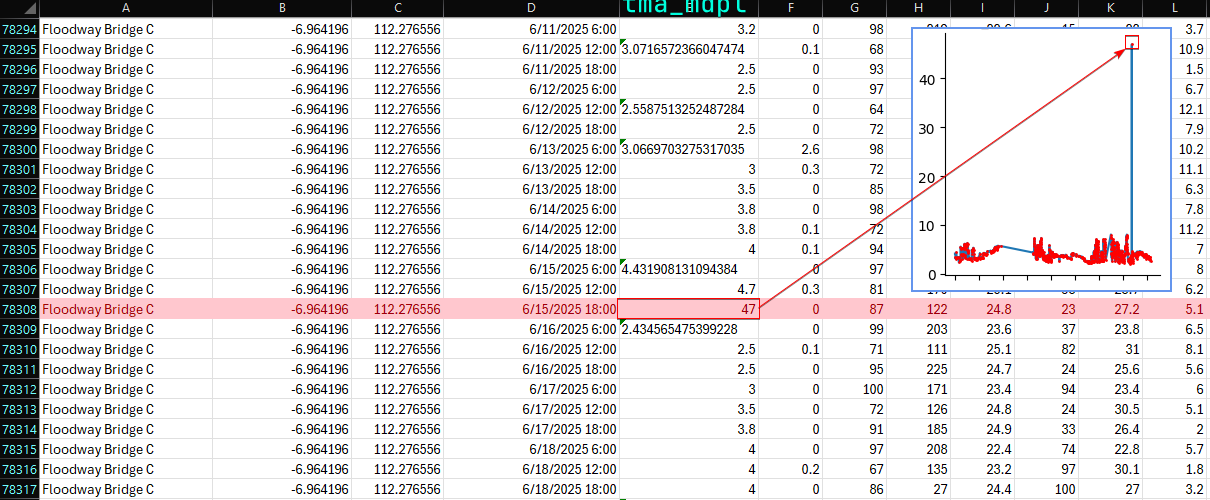

#### 2.4.2.3 Akumulasi rainfal dan API

##### Tujuan

Menentukan accumulation window dan API yang paling berhubungan dengan perubahan TMA pada berbagai horizon. [Gambar 1]

Melihat memori hujan, seasonality, dan perbedaan dinamika antarpos. [Gambar 2]

In [ ]:
# @title
df_rain = data_master.copy()

if np.allclose(
    df_rain["rainfall_mm"], df_rain["rainfall_openmeteo_mm"],
    equal_nan=True, atol=1e-10
):
    print("rainfall_mm dan rainfall_openmeteo_mm identik; memakai rainfall_mm.")


def tambah_rain_features(g):
    g = g.sort_values("datetime").copy()
    indexed = g.set_index("datetime")
    rain = indexed["rainfall_mm"].clip(lower=0)

    for hari in [1, 3, 7, 14, 30]:
        g[f"rain_sum_{hari}d"] = (
            rain.rolling(f"{hari}D", min_periods=1).sum().to_numpy()
        )
        g[f"rain_max_{hari}d"] = (
            rain.rolling(f"{hari}D", min_periods=1).max().to_numpy()
        )
        g[f"wet_obs_{hari}d"] = (
            rain.gt(0.1).rolling(f"{hari}D", min_periods=1).sum().to_numpy()
        )

    waktu = g["datetime"].astype("int64").to_numpy()
    nilai = rain.to_numpy(float)
    for k in [0.70, 0.85, 0.93]:
        api = np.zeros(len(g), dtype=float)
        for i in range(len(g)):
            if i == 0:
                api[i] = 0 if np.isnan(nilai[i]) else nilai[i]
            else:
                delta_hari = (waktu[i] - waktu[i - 1]) / pd.Timedelta("1D").value
                hujan_i = 0 if np.isnan(nilai[i]) else nilai[i]
                api[i] = hujan_i + api[i - 1] * (k ** delta_hari)
        g[f"api_{int(round(k * 100)):03d}"] = api

    last_rain_time = pd.NaT
    dry_hours = []
    for t, r in zip(g["datetime"], nilai):
        if pd.notna(r) and r > 0.1:
            last_rain_time = t
            dry_hours.append(0.0)
        elif pd.isna(last_rain_time):
            dry_hours.append(np.nan)
        else:
            dry_hours.append((t - last_rain_time).total_seconds() / 3600)
    g["hours_since_rain"] = dry_hours
    return g


df_rain = pd.concat(
    [tambah_rain_features(g) for _, g in df_rain.groupby("nama_pos")],
    ignore_index=True
)

rain_features = [
    "rain_sum_1d", "rain_sum_3d", "rain_sum_7d", "rain_sum_14d", "rain_sum_30d",
    "rain_max_1d", "rain_max_3d", "rain_max_7d",
    "wet_obs_3d", "wet_obs_7d", "wet_obs_14d",
    "api_070", "api_085", "api_093", "hours_since_rain"
]

rain_corr_parts = []
for h in [1, 3, 7, 14, 30]:
    pair = pasangan_horizon(
        df_rain, rain_features + ["tma_mdpl", "tma_anomaly"], h,
        ["tma_mdpl", "tma_anomaly"]
    )
    pair["future_delta_tma"] = pair["future_tma_mdpl"] - pair["tma_mdpl"]
    corr = korelasi_per_pos(pair, rain_features, "future_delta_tma", min_n=30)
    if not corr.empty:
        corr["horizon_hari"] = h
        rain_corr_parts.append(corr)

rain_corr = (
    pd.concat(rain_corr_parts, ignore_index=True)
    if rain_corr_parts else pd.DataFrame()
)

if not rain_corr.empty:
    rain_summary = (
        rain_corr.groupby(["feature", "horizon_hari"])
        .agg(
            median_spearman=("spearman", "median"),
            jumlah_pos=("nama_pos", "nunique")
        ).reset_index()
    )
    plot_heatmap(
        rain_summary, "feature", "horizon_hari", "median_spearman",
        "Rainfall/API vs perubahan TMA masa depan"
    )
    print("\nFitur hujan terbaik per horizon")
    print(
        rain_summary.loc[
            rain_summary.groupby("horizon_hari")["median_spearman"]
            .apply(lambda s: s.abs().idxmax())
        ].sort_values("horizon_hari")
    )

pos_plot = df_rain["nama_pos"].drop_duplicates().head(6)
plot_rain = df_rain[df_rain["nama_pos"].isin(pos_plot)]
g = sns.relplot(
    data=plot_rain, x="datetime", y="api_085", col="nama_pos",
    col_wrap=2, kind="line", height=3, facet_kws={"sharey": False}
)
g.fig.suptitle("Antecedent Precipitation Index, decay 0.85", y=1.02)
plt.show()

##### Kesimpulan

[Gambar 1]
- Hampir seluruh fitur hujan memiliki korelasi negatif kecil, sekitar −0.02 sampai −0.15.
- Efek negatif cenderung membesar pada horizon 30 hari.
- hours_since_rain justru positif dan naik sampai sekitar 0.10.

Jika origin berada setelah periode hujan dan TMA sudah tinggi, kondisi berikutnya memang sering berupa recession. Karena itu API tinggi di origin diikuti perubahan negatif.

Analisis lanjutan
Uji hujan terhadap empat target berbeda:
```
future TMA level
future TMA anomaly
maximum rise dalam 1–7 hari
probability of rising/peak
```
Tambahkan conditioning berdasarkan:
```
TMA anomaly saat origin;
slope saat origin;
rising/stable/recession regime;
waktu sejak peak.
```

[Gambar 2]
- Seluruh pos memperlihatkan periode basah dan kering yang jelas.
- Banyak peak API terjadi pada periode yang hampir bersamaan, menandakan adanya regional weather component.
- Besar peak berbeda antarpos, sehingga masih terdapat variasi lokal.
- API 0.85 menghasilkan kurva yang cukup halus tanpa kehilangan event besar.

Analisis lanjutan:
- Hitung korelasi API antarpos.
- Pecah API menjadi:
```
regional_API = median seluruh pos pada timestamp
local_API = API_pos - regional_API
```
- Bandingkan decay 0.70, 0.85, dan 0.93 secara OOF.
- Normalisasi API menjadi percentile atau anomaly per pos.
- Cari decay terbaik per cluster, bukan per pos jika data terbatas.

#### 2.4.2.4 Interaksi rainfall sama soil moisture

##### Tujuan

Menguji apakah soil moisture menambah informasi di luar hujan. [Gambar 1]

Mencari threshold runoff: apakah hujan lebih berdampak saat tanah sudah jenuh. [Gambar 2]

In [ ]:
# @title
df_soil = df_rain.copy()
soil_cols = [
    "soil_moisture_0_7cm", "soil_moisture_7_28cm",
    "soil_moisture_28_100cm", "soil_moisture_100_255cm"
]

for col in soil_cols:
    df_soil[f"{col}_pct"] = (
        df_soil.groupby("nama_pos")[col].rank(pct=True, method="average")
    )
    df_soil[f"{col}_anom_7d"] = (
        df_soil[col] -
        df_soil.groupby("nama_pos")[col]
        .transform(lambda s: s.rolling(21, min_periods=6).median())
    )

df_soil["soil_surface_minus_deep"] = (
    df_soil["soil_moisture_0_7cm"] - df_soil["soil_moisture_28_100cm"]
)
df_soil["soil_shallow_mean"] = df_soil[
    ["soil_moisture_0_7cm", "soil_moisture_7_28cm"]
].mean(axis=1)
df_soil["soil_deep_mean"] = df_soil[
    ["soil_moisture_28_100cm", "soil_moisture_100_255cm"]
].mean(axis=1)

interaction_features = []
for rain_col in ["rain_sum_3d", "rain_sum_7d", "api_085"]:
    for soil_col in soil_cols[:3]:
        nama = f"{rain_col}_x_{soil_col}"
        df_soil[nama] = df_soil[rain_col] * df_soil[f"{soil_col}_pct"]
        interaction_features.append(nama)

soil_base_features = [
    f"{c}_pct" for c in soil_cols
] + ["soil_surface_minus_deep", "soil_shallow_mean", "soil_deep_mean"]

soil_corr_parts = []
pair_soil_7d = None
for h in [1, 3, 7, 14, 30]:
    features = ["rain_sum_3d", "rain_sum_7d", "api_085"] + soil_base_features + interaction_features
    pair = pasangan_horizon(
        df_soil, features + ["tma_mdpl"], h, ["tma_mdpl"]
    )
    pair["future_delta_tma"] = pair["future_tma_mdpl"] - pair["tma_mdpl"]
    if h == 7:
        pair_soil_7d = pair.copy()
    corr = korelasi_per_pos(pair, features, "future_delta_tma", min_n=30)
    if not corr.empty:
        corr["horizon_hari"] = h
        soil_corr_parts.append(corr)

soil_corr = (
    pd.concat(soil_corr_parts, ignore_index=True)
    if soil_corr_parts else pd.DataFrame()
)

if not soil_corr.empty:
    soil_summary = (
        soil_corr.groupby(["feature", "horizon_hari"])["spearman"]
        .median().rename("median_spearman").reset_index()
    )
    top_soil = (
        soil_summary.assign(abs_corr=lambda x: x["median_spearman"].abs())
        .sort_values("abs_corr", ascending=False)
        .groupby("horizon_hari").head(6)
    )
    plot_heatmap(
        top_soil, "feature", "horizon_hari", "median_spearman",
        "Fitur rainfall–soil terbaik per horizon"
    )

if pair_soil_7d is not None and len(pair_soil_7d):
    q1, q2 = pair_soil_7d["rain_sum_7d"].quantile([.60, .85])
    bins = [-np.inf, 0, max(q1, 1e-9), max(q2, q1 + 1e-9), np.inf]
    labels = ["Kering", "Hujan rendah", "Hujan sedang", "Hujan tinggi"]
    pair_soil_7d["rain_bin"] = pd.cut(
        pair_soil_7d["rain_sum_7d"], bins=bins, labels=labels,
        include_lowest=True, duplicates="drop"
    )
    pair_soil_7d["soil_bin"] = pd.cut(
        pair_soil_7d["soil_moisture_0_7cm_pct"],
        bins=[0, .25, .50, .75, 1.0],
        labels=["Q1 kering", "Q2", "Q3", "Q4 jenuh"], include_lowest=True
    )
    response_2d = pair_soil_7d.pivot_table(
        index="soil_bin", columns="rain_bin", values="future_delta_tma",
        aggfunc="median", observed=False
    )
    plt.figure(figsize=(8, 5))
    sns.heatmap(response_2d, cmap="vlag", center=0, annot=True, fmt=".2f")
    plt.title("Median perubahan TMA 7 hari: hujan × kejenuhan tanah")
    plt.xlabel("")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()


##### Kesimpulan

[Gambar 1]
- Soil moisture sendiri terlihat lebih kuat daripada sebagian besar interaksi rainfall–soil.
- Efek terbesar muncul pada horizon 30 hari:
- - soil_deep_mean: sekitar −0.27;
- - soil_moisture_28_100cm_pct: sekitar −0.24;
- - lapisan 7–28 cm dan shallow mean: sekitar −0.19.
- Interaksi API/rain dengan soil mencapai sekitar −0.19 sampai −0.20.

Lapisan dalam membawa informasi tentang state hidrologis yang bertahan lebih lama. Namun tanda negatif kembali mengarah ke mean reversion/recession.

Analisis lanjutan:

- Uji soil terhadap future anomaly, bukan hanya future change.
- Gunakan perubahan soil 3/7/14 hari.
- Tambahkan gradient vertikal.
- Pisahkan rising dan recession.
- Periksa incremental value: bandingkan model rain only, soil only, dan rain + soil.

[Gambar 2]
- Sebagian besar median perubahan TMA tujuh hari dekat nol.
- Pada tanah Q4/jenuh, seluruh kondisi cenderung negatif.
- Nilai paling negatif justru terjadi ketika tanah jenuh tetapi hujan saat ini kering, sekitar −0.51.

Ini sangat konsisten dengan kondisi post-rainfall recession: tanah masih basah, hujan telah berhenti, dan TMA sedang turun.

Masalahnya, penyimpulan bahwa tanah jenuh memperbesar runoff karena targetnya tidak langsung mengukur kenaikan setelah event belum bisa.

Analisis lanjutan:
- Tampilkan jumlah observasi di setiap cell.
- Hitung confidence interval menggunakan block bootstrap.
- Gunakan target maximum ΔTMA dalam 1–7 hari.
- Definisikan hujan sebagai event yang dimulai setelah origin.
- Buat analisis per pos atau cluster agar perbedaan skala tidak tercampur.

### 2.4.3 Terhadap `tma_anomaly`

#### 2.4.3.1 Pembuatan smooth climatology dengan `tma_anomaly`
Ingat ya tma_anomaly itu deviasi antara tma rata rata dengan tma sebenarnya untuk tiap pos

##### Tujuan

Membentuk baseline musiman per pos dan jam. [Gambar 1]

Membandingkan variabilitas residual setelah seasonality dihilangkan. [Gambar 2]

In [ ]:
# @title
df_eda = df_final.copy()
df_eda["datetime"] = pd.to_datetime(df_eda["datetime"])
df_eda["jam"] = df_eda["datetime"].dt.hour
df_eda["day_of_year"] = df_eda["datetime"].dt.dayofyear

def circular_smooth_climatology(g, window=31):
    base = g.groupby("day_of_year")["tma_mdpl"].median().reindex(range(1, 367))
    extended = pd.concat([base, base, base], ignore_index=True)
    smooth = extended.rolling(window, center=True, min_periods=5).median()
    middle = smooth.iloc[366:732].to_numpy()
    return pd.DataFrame({"day_of_year": range(1, 367), "tma_climatology": middle})

climatology_parts = []
for (pos, jam), gpos in df_eda.groupby(["nama_pos", "jam"]):
    temp = circular_smooth_climatology(gpos, window=31)
    temp["nama_pos"] = pos
    temp["jam"] = jam
    climatology_parts.append(temp)
climatology = pd.concat(climatology_parts, ignore_index=True)

df_eda = df_eda.merge(
    climatology, on=["nama_pos", "jam", "day_of_year"], how="left"
)
df_eda["tma_anomaly"] = df_eda["tma_mdpl"] - df_eda["tma_climatology"]

print(df_eda[["tma_climatology", "tma_anomaly"]].describe())
print("CATATAN: climatology ini untuk EDA. Dalam validasi/model, hitung hanya dari train fold.")

pos_plot = df_eda["nama_pos"].drop_duplicates().head(6)
plot_clim = df_eda[df_eda["nama_pos"].isin(pos_plot)]
g = sns.relplot(
    data=plot_clim, x="day_of_year", y="tma_mdpl", hue="jam",
    col="nama_pos", col_wrap=2, kind="scatter", alpha=.18,
    palette="viridis", height=3, facet_kws={"sharey": False}
)
for ax, pos in zip(g.axes.flat, g.col_names):
    garis = climatology[climatology["nama_pos"] == pos]
    sns.lineplot(
        data=garis, x="day_of_year", y="tma_climatology",
        hue="jam", palette="viridis", legend=False, ax=ax, linewidth=2
    )
g.fig.suptitle("TMA aktual dan smooth climatology per jam", y=1.02)
plt.show()

plt.figure(figsize=(12, max(5, .3 * df_eda["nama_pos"].nunique())))
sns.boxplot(data=df_eda, y="nama_pos", x="tma_anomaly", showfliers=False)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("Distribusi TMA anomaly per pos")
plt.tight_layout()
plt.show()

##### Kesimpulan

[Gambar 1]
- Seasonality sangat jelas dan berbeda antarpos.
- Ketonggo, Sekayu, Cepu, dan Badegan menunjukkan level lebih tinggi pada awal/akhir tahun serta trough pada pertengahan tahun.
- Efek jam relatif kecil dibanding efek musim pada sebagian besar pos.
- Karanggeneng memiliki penurunan tajam mendekati akhir tahun yang perlu diperiksa.
- Ketonggo memiliki titik mendekati nol.
- Bojonegoro–Kali Kethek memiliki outlier sangat ekstrem di atas 150–200, sementara climatology normalnya jauh lebih rendah.

Seharusnya, smooth climatology layak menjadi baseline utama, tetapi harus dibangun setelah pembersihan sensor.

- Bangun climatology dari target yang sudah diflag.
- Bandingkan window circular 15, 31, 45, dan 61 hari.
- Hitung climatology secara fold-safe.
- Uji kestabilan pola per tahun.
- Tambahkan Fourier sebagai alternatif yang lebih halus.

[Gambar 2]

Skala anomaly berbeda besar antarpos:
- Wonogiri Dam paling lebar, sekitar −4 sampai lebih dari +3.
- Bojonegoro–Kali Kethek, Kali Anyar–Kreteg Abang, Kedungupit, Karangnongko, dan Floodway Bridge C juga lebar.
- Lorog, Ngadipiro, Ngrembang, dan beberapa pos lain jauh lebih stabil.

Analisis lanjutan:
- Hitung MAD/IQR anomaly per pos.
- Pisahkan variance normal dari sensor outlier.
- Audit Wonogiri Dam sebagai pos operasional/reservoir.
- Evaluasi RMSE per pos pada raw scale dan normalized scale.

#### 2.4.3.2 Memory Decay per Pos sama Horizon

##### Tujuan

Mengukur berapa lama kondisi TMA origin masih membawa informasi untuk masa depan. [Gambar 1]

Mengetahui heterogenitas memori hidrologis antarpos.

In [ ]:
# @title
horizon_hari = [1, 3, 7, 14, 30, 60, 90, 180, 240]
base = (
    df_eda[["nama_pos", "datetime", "tma_anomaly"]]
    .dropna().drop_duplicates(["nama_pos", "datetime"])
)
hasil_memory = []

for h in horizon_hari:
    origin = base.rename(columns={"tma_anomaly": "anomaly_origin"}).copy()
    origin["datetime_target"] = origin["datetime"] + pd.Timedelta(days=h)
    target = base.rename(columns={
        "datetime": "datetime_target", "tma_anomaly": "anomaly_future"
    })
    pasangan = origin.merge(target, on=["nama_pos", "datetime_target"], how="inner")

    for pos, gp in pasangan.groupby("nama_pos"):
        gp = gp[["anomaly_origin", "anomaly_future"]].dropna()
        if len(gp) < 30 or gp["anomaly_origin"].var() == 0:
            continue
        slope = np.cov(
            gp["anomaly_origin"], gp["anomaly_future"], ddof=1
        )[0, 1] / gp["anomaly_origin"].var(ddof=1)
        hasil_memory.append({
            "nama_pos": pos,
            "horizon_hari": h,
            "n_pasangan": len(gp),
            "memory_slope": slope,
            "spearman": gp["anomaly_origin"].corr(gp["anomaly_future"], method="spearman"),
            "rmse_persistence": np.sqrt(np.mean(
                (gp["anomaly_future"] - gp["anomaly_origin"]) ** 2
            )),
            "rmse_climatology": np.sqrt(np.mean(gp["anomaly_future"] ** 2))
        })

memory = pd.DataFrame(hasil_memory)
print(memory.head())

if memory.empty:
    print("Belum ada pasangan >=30 observasi; gunakan df_final lengkap.")
else:
    ringkasan_memory = (
        memory.groupby("horizon_hari")
        .agg(
            jumlah_pos=("nama_pos", "nunique"),
            median_slope=("memory_slope", "median"),
            median_spearman=("spearman", "median"),
            median_n=("n_pasangan", "median")
        ).reset_index()
    )
    print("\nRingkasan memory decay")
    print(ringkasan_memory)

    plt.figure(figsize=(9, 5))
    sns.lineplot(
        data=memory, x="horizon_hari", y="memory_slope",
        units="nama_pos", estimator=None, alpha=.22, color="gray"
    )
    sns.lineplot(
        data=memory, x="horizon_hari", y="memory_slope",
        estimator="median", errorbar=None, marker="o",
        color="#D62828", linewidth=3, label="Median antarpos"
    )
    plt.axhline(.5, color="black", linestyle="--", label="Memory 50%")
    plt.axhline(0, color="black", linewidth=.8)
    plt.title("Peluruhan pengaruh TMA anomaly terhadap horizon")
    plt.ylabel("Slope anomaly future ~ anomaly origin")
    plt.legend()
    plt.tight_layout()
    plt.show()

    heat = memory.pivot(index="nama_pos", columns="horizon_hari", values="memory_slope")
    plt.figure(figsize=(12, max(6, .35 * len(heat))))
    sns.heatmap(heat, cmap="vlag", center=0, vmin=-1, vmax=1, annot=False)
    plt.title("Memory slope per pos dan horizon")
    plt.xlabel("Horizon (hari)")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

    # Horizon pertama ketika median memory turun ke <= 0.5.
    below = ringkasan_memory[ringkasan_memory["median_slope"] <= .5]
    if len(below):
        print("Median memory turun ke <=50% pada sekitar", int(below.iloc[0]["horizon_hari"]), "hari.")
    else:
        print("Median memory belum turun ke <=50% pada horizon yang diuji.")

##### Kesimpulan
[Gambar 1]
Penurunan Performa Drastis (Decay): Daya ingat sistem sungai (autokorelasi) sangat pendek. Untuk memprediksi 1 hari ke depan (horizon 1), model persistence (mengasumsikan TMA besok = TMA hari ini) sangat kuat dengan Spearman 0.71.

Batas Waktu Prediksi: Begitu masuk horizon 3 hari, korelasi anjlok ke 0.48, dan pada horizon 7 hari menjadi 0.35. Setelah 14 hari, nilai korelasi sudah berada di bawah 0.2, yang berarti sistem sudah sepenuhnya "lupa" dengan kondisi awal.

Kesimpulan Pemodelan: Jangan mencoba membuat model yang memprediksi TMA lebih dari 3-7 hari ke depan hanya dengan mengandalkan data TMA historis. Untuk prediksi jangka panjang (di atas 7 hari), model Anda wajib bergantung kuat pada prakiraan cuaca eksternal (curah hujan masa depan dari model cuaca seperti ECMWF atau GFS).

Ini juga dikonfirmasi pada 2.4.1.3.1

Analisis lanjutan:
- Tambahkan confidence interval per pos.
- Estimasi half-life dengan interpolasi, bukan hanya horizon diskret.
- Hitung OOF memory per fold agar tidak dipengaruhi climatology full-data.
- Bandingkan memory dalam musim hujan dan kemarau.
- Uji memory untuk raw level, anomaly, dan slope.

[Gambar 2]
Pos dengan memori relatif panjang antara lain:
- Wonogiri Dam, sangat kuat sampai 60–90 hari;
- Boboh Kali Lamong;
- Colo Weir;
- Serenan;
- Sekayu;
- Lorog;
- Sumberrejo;
- Karanggeneng.

Pos dengan memori sangat rendah antara lain:
- Jarum;
- Kali Anyar–Kreteg Abang;
- Kali Pepe–PTPN;
- Karangnongko;
- Napel;

Floodway Bridge C menunjukkan kecenderungan negatif pada horizon panjang. Mengingat missingness-nya sangat besar, nilai tersebut lebih mungkin terpengaruh masalah coverage daripada dinamika fisik.

Wonogiri Dam terlihat sebagai proses yang berbeda dari sungai biasa—kemungkinan dipengaruhi penyimpanan dan operasi bendungan?

Analisis lanjutan:
- Shrink memory per pos menuju median global.
- Validasi per fold dan per tahun.
- Hubungkan memory dengan jenis pos, bendungan/weir, dan karakteristik DAS.
- Jangan membentuk 30 model langsung; gunakan kelompok high-, medium-, dan low-memory.

### 2.4.4 Terhadap `temperature_c`, `humidity_pct`, `dew_point_c`, `cloud_cover_pct`, `solar_radiation_mj_m2`, `surface_pressure_hpa`, `pressure_msl_hpa` (Atmospheric tendency) sama Hujan/TMA

#### 2.4.4.1 Atmospheric Tendency dengan precursor hujan/TMA

##### Tujuan

Mencari fitur atmosfer yang langsung memberi sinyal perubahan TMA. [Gambar 1]

Mengetahui apakah atmosfer di origin dapat mengenali wet-weather regime. [Gambar 2]

Memeriksa bentuk hubungan nonlinear antara perubahan tekanan dan hujan. [Gambar 3]

In [ ]:
# @title
df_atm = df_soil.copy()
df_atm["bulan"] = df_atm["datetime"].dt.month
df_atm["jam"] = df_atm["datetime"].dt.hour
df_atm["dewpoint_depression"] = df_atm["temperature_c"] - df_atm["dew_point_c"]
arah_rad = np.deg2rad(df_atm["wind_direction_deg"])
df_atm["wind_u"] = df_atm["wind_speed_kmh"] * np.cos(arah_rad)
df_atm["wind_v"] = df_atm["wind_speed_kmh"] * np.sin(arah_rad)
df_atm["cloud_x_humidity"] = (
    df_atm["cloud_cover_pct"] / 100 * df_atm["humidity_pct"] / 100
)

for col in [
    "temperature_c", "humidity_pct", "dew_point_c", "cloud_cover_pct",
    "solar_radiation_mj_m2", "surface_pressure_hpa", "pressure_msl_hpa"
]:
    baseline = df_atm.groupby(["nama_pos", "bulan", "jam"])[col].transform("median")
    df_atm[f"{col}_anomaly"] = df_atm[col] - baseline


def tambah_tendency_exact(data, cols, days):
    lag = data[["nama_pos", "datetime"] + cols].copy()
    lag["datetime"] = lag["datetime"] + pd.Timedelta(days=days)
    lag = lag.rename(columns={c: f"{c}_lag_{days}d" for c in cols})
    result = data.merge(lag, on=["nama_pos", "datetime"], how="left")
    for c in cols:
        result[f"{c}_change_{days}d"] = result[c] - result[f"{c}_lag_{days}d"]
    return result


tendency_cols = [
    "surface_pressure_hpa", "pressure_msl_hpa", "humidity_pct",
    "temperature_c", "dew_point_c", "cloud_cover_pct"
]
df_atm = tambah_tendency_exact(df_atm, tendency_cols, 1)
df_atm = tambah_tendency_exact(df_atm, tendency_cols, 3)

atm_features = [
    "dewpoint_depression", "wind_u", "wind_v", "cloud_x_humidity",
    "temperature_c_anomaly", "humidity_pct_anomaly", "dew_point_c_anomaly",
    "cloud_cover_pct_anomaly", "solar_radiation_mj_m2_anomaly",
    "surface_pressure_hpa_change_1d", "surface_pressure_hpa_change_3d",
    "humidity_pct_change_1d", "temperature_c_change_1d",
    "cloud_cover_pct_change_1d"
]

atm_corr_parts = []
for h in [1, 3, 7, 14]:
    # rain_sum_h di timestamp target mewakili hujan pada jendela sebelum target.
    rain_target = f"rain_sum_{h}d" if h in [1, 3, 7, 14] else "rain_sum_7d"
    pair = pasangan_horizon(
        df_atm, atm_features + ["tma_mdpl"], h,
        [rain_target, "tma_mdpl"]
    )
    pair["future_delta_tma"] = pair["future_tma_mdpl"] - pair["tma_mdpl"]
    pair = pair.rename(columns={f"future_{rain_target}": "future_rain"})
    for target in ["future_rain", "future_delta_tma"]:
        corr = korelasi_per_pos(pair, atm_features, target, min_n=30)
        if not corr.empty:
            corr["horizon_hari"] = h
            atm_corr_parts.append(corr)

atm_corr = (
    pd.concat(atm_corr_parts, ignore_index=True)
    if atm_corr_parts else pd.DataFrame()
)

if not atm_corr.empty:
    atm_summary = (
        atm_corr.groupby(["target", "feature", "horizon_hari"])["spearman"]
        .median().rename("median_spearman").reset_index()
    )
    for target in atm_summary["target"].unique():
        temp = atm_summary[atm_summary["target"] == target]
        plot_heatmap(
            temp, "feature", "horizon_hari", "median_spearman",
            f"Atmospheric tendency vs {target}"
        )

sample_atm = df_atm.sample(min(5000, len(df_atm)), random_state=42)
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=sample_atm, x="surface_pressure_hpa_change_1d", y="rain_sum_1d",
    hue="humidity_pct_anomaly", palette="viridis", alpha=.35, legend=False
)
plt.title("Pressure tendency, humidity anomaly, dan hujan 1 hari")
plt.tight_layout()
plt.show()

##### Kesimpulan

[Gambar 1]
Semua korelasi relatif kecil, maksimum sekitar ±0.11.

Pola terkuat:
- humidity anomaly menjadi negatif pada 7–14 hari;
- temperature anomaly menjadi positif sampai 0.10;
- pressure change 3 hari sekitar −0.10 pada horizon 7 hari;
- humidity change satu hari sekitar +0.10 pada horizon pendek.

Ini mungkin lebih ke mencerminkan pergantian regime dan seasonality daripada hubungan langsung yang kuat.

Analisis lanjutan:
- Uji incremental importance setelah rain, soil, calendar, dan current TMA dikontrol.
- Gunakan conditional permutation importance.
- Pisahkan rising dan recession.
- Hindari memasukkan semua fitur atmosfer yang sangat berkorelasi tanpa ablation.

[Gambar 2]

Hubungannya jauh lebih kuat daripada terhadap TMA:

- cloud_x_humidity: sekitar 0.46–0.52;
- dew-point depression: sekitar −0.33 sampai −0.36;
- wind_u: sekitar 0.31–0.34;
- wind_v: sekitar −0.25 sampai −0.31;
- dew-point anomaly: sekitar 0.19–0.25;
- solar anomaly negatif.

Ini menunjukkan atmosfer lebih cocok dipakai sebagai indikator atau prediktor hujan daripada sebagai prediktor TMA langsung.

Namun persistensi sampai 14 hari masih perlu diuji terhadap seasonality dan autocorrelation.

Analisis lanjutan:
- Modelkan probabilitas hujan dan magnitude secara terpisah.
- Gunakan time-block validation.
- Residualize semua fitur terhadap pos × day-of-year × jam.
-Bandingkan terhadap baseline seasonal rainfall.
- Pastikan hanya atmosfer pada origin yang menjadi input.

[Gambar 3]

Tidak terlihat hubungan monotonic yang jelas. Hujan besar tersebar pada perubahan tekanan negatif maupun positif.

Pressure change sendiri hampir tidak informatif. Jika fitur tekanan sebelumnya membantu model (Experiment 3), manfaatnya mungkin berasal dari:

- interaksi nonlinear;
- station/elevation proxy;
- korelasi dengan fitur cuaca lain;
- seasonality.

Analisis lanjutan:
- Plot per musim dan pos.
- Gunakan pressure anomaly, bukan raw level.
- Bandingkan model dengan dan tanpa pressure.
- Periksa apakah pressure_msl − surface_pressure hampir statis per pos?

### 2.4.5 Terhadap `mjo`

#### 2.4.5.1 Jalur MJO -> Rainfall -> TMA

##### Tujuan

Menguji apakah phase MJO membedakan hujan dan TMA tujuh hari berikutnya. [Gambar 1]

Menguji apakah pengaruh MJO bergantung pada musim. [Gambar 2]

In [ ]:
# @title
daily_mjo = (
    df_atm.assign(tanggal=df_atm["datetime"].dt.normalize())
    .groupby(["nama_pos", "tanggal"], as_index=False)
    .agg(
        rainfall_daily=("rainfall_mm", "sum"),
        tma_daily=("tma_mdpl", "median"),
        tma_anomaly_daily=("tma_anomaly", "median"),
        rmm1=("rmm1", "first"),
        rmm2=("rmm2", "first"),
        mjo_phase=("mjo_phase", "first"),
        mjo_amplitude=("mjo_amplitude", "first"),
        mjo_active=("mjo_active", "first")
    )
)
daily_mjo["bulan"] = daily_mjo["tanggal"].dt.month
daily_mjo["rain_anomaly_month"] = (
    daily_mjo["rainfall_daily"] -
    daily_mjo.groupby(["nama_pos", "bulan"])["rainfall_daily"].transform("median")
)


def tambah_future_daily(g):
    g = g.sort_values("tanggal").copy()
    rain = g["rainfall_daily"]
    for h in [3, 7, 14]:
        g[f"rain_next_{h}d"] = (
            rain.shift(-1).iloc[::-1].rolling(h, min_periods=1).sum().iloc[::-1]
        )
    return g


daily_mjo = pd.concat(
    [tambah_future_daily(g) for _, g in daily_mjo.groupby("nama_pos")],
    ignore_index=True
)

for h in [3, 7, 14]:
    future = daily_mjo[["nama_pos", "tanggal", "tma_anomaly_daily"]].copy()
    future["tanggal"] = future["tanggal"] - pd.Timedelta(days=h)
    future = future.rename(columns={"tma_anomaly_daily": f"tma_anomaly_future_{h}d"})
    daily_mjo = daily_mjo.merge(future, on=["nama_pos", "tanggal"], how="left")

active_mjo = daily_mjo[
    (daily_mjo["mjo_active"] == 1) & daily_mjo["mjo_phase"].between(1, 8)
].copy()
active_mjo["mjo_phase"] = active_mjo["mjo_phase"].astype(int).astype(str)

if len(active_mjo):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.boxplot(
        data=active_mjo, x="mjo_phase", y="rain_next_7d",
        showfliers=False, color="#4CC9F0", ax=axes[0]
    )
    axes[0].set_title("Hujan 7 hari ke depan menurut MJO aktif")
    axes[0].set_xlabel("MJO phase")
    sns.pointplot(
        data=active_mjo, x="mjo_phase", y="tma_anomaly_future_7d",
        errorbar=("ci", 90), color="#D00000", ax=axes[1]
    )
    axes[1].axhline(0, color="black", linewidth=.8)
    axes[1].set_title("TMA anomaly 7 hari ke depan menurut MJO aktif")
    axes[1].set_xlabel("MJO phase")
    plt.tight_layout()
    plt.show()

    phase_month = active_mjo.pivot_table(
        index="mjo_phase", columns="bulan", values="rain_anomaly_month",
        aggfunc="median"
    )
    plt.figure(figsize=(12, 5))
    sns.heatmap(phase_month, cmap="BrBG", center=0, annot=True, fmt=".2f")
    plt.title("Median rainfall anomaly: MJO phase × bulan")
    plt.tight_layout()
    plt.show()


def eta_squared(data, group_col, value_col):
    valid = data[[group_col, value_col]].dropna()
    if len(valid) == 0 or valid[group_col].nunique() < 2:
        return np.nan
    grand = valid[value_col].mean()
    ss_between = sum(
        len(g) * (g[value_col].mean() - grand) ** 2
        for _, g in valid.groupby(group_col)
    )
    ss_total = ((valid[value_col] - grand) ** 2).sum()
    return ss_between / ss_total if ss_total > 0 else np.nan


mjo_effect_rows = []
for h in [3, 7, 14]:
    rain_col = f"rain_next_{h}d"
    tma_col = f"tma_anomaly_future_{h}d"
    valid = active_mjo[["mjo_phase", rain_col, tma_col]].dropna()
    if len(valid) < 30:
        continue
    # Residual TMA setelah hubungan linear dengan hujan dihilangkan.
    coef = np.polyfit(valid[rain_col], valid[tma_col], 1)
    valid = valid.copy()
    valid["tma_after_rain"] = valid[tma_col] - np.polyval(coef, valid[rain_col])
    mjo_effect_rows.append({
        "horizon_hari": h,
        "n": len(valid),
        "eta2_phase_to_rain": eta_squared(valid, "mjo_phase", rain_col),
        "eta2_phase_to_tma": eta_squared(valid, "mjo_phase", tma_col),
        "eta2_phase_to_tma_after_rain": eta_squared(valid, "mjo_phase", "tma_after_rain")
    })
mjo_effect = pd.DataFrame(mjo_effect_rows)
print("\nEfek MJO; eta² bukan bukti sebab-akibat")
print(mjo_effect)

##### Kesimpulan

[Gambar 1]

- Phase 8 dan 1 cenderung memiliki hujan lebih rendah.
- Phase 3, 4, 7, dan 2 terlihat lebih basah.
- TMA anomaly tertinggi muncul pada phase 5, sekitar +0.22.
- Phase 7 sedikit negatif, sedangkan phase lain umumnya positif.

Pola TMA tidak sepenuhnya sama dengan pola hujan. Ini bisa berasal dari response lag, soil storage, atau confounding bulan.

Error bar TMA kemungkinan terlalu optimistis karena satu nilai MJO yang sama dihitung berulang untuk banyak pos. Unit independen sebenarnya adalah hari atau episode MJO, bukan pos × hari?

Analisis lanjutan:
- Bootstrap berdasarkan tanggal/episode MJO.
- Urutkan phase 1–8.
- Kontrol bulan dan ENSO.
- Gunakan rmm1, rmm2, dan amplitude sebagai representasi utama.
- Uji efek per cluster pos.

[Gambar 2]

Banyak cell kosong dan sebagian besar median dekat nol. Nilai besar seperti:

- phase 4 pada Maret sekitar +0.80;
- phase 5 pada Maret sekitar +0.50;
- phase 8 pada Februari sekitar −1.20;
- phase 1 pada Februari sekitar −1.00;

kemungkinan memiliki jumlah episode sangat sedikit.

Dengan histori kurang dari tiga tahun, kombinasi phase × bulan terlalu sparse untuk dipelajari sebagai kategori bebas.

Analisis lanjutan:
- Tampilkan n_independent_days dan n_episode.
- Abaikan cell yang hanya muncul dalam satu tahun.
- Gunakan smoothing circular atau rmm1/rmm2 × Fourier month.
- Hindari one-hot phase × month penuh.

### 2.4.6 Terhadap ENSO/Nino 3.4 bulanan sama musiman

#### 2.4.6.1 ENSO/Nino 3.4 bulanan sama musiman

##### Tujuan

Menilai apakah Nino 3.4 menjelaskan variasi hujan, soil, dan TMA pada skala bulanan. [Gambar 1]

Menempatkan korelasi ENSO dalam konteks waktunya. [Gambar 2]

In [ ]:
# @title
monthly_enso = (
    df_atm.assign(periode=df_atm["datetime"].dt.to_period("M"))
    .groupby(["nama_pos", "periode"], as_index=False)
    .agg(
        tma_monthly=("tma_mdpl", "median"),
        tma_anomaly_monthly=("tma_anomaly", "median"),
        rain_monthly=("rainfall_mm", "sum"),
        soil_surface=("soil_moisture_0_7cm", "mean"),
        soil_deep=("soil_moisture_28_100cm", "mean"),
        nino_34=("nino_34", "median")
    )
)
monthly_enso["bulan"] = monthly_enso["periode"].dt.month
monthly_enso["tahun"] = monthly_enso["periode"].dt.year
monthly_enso["tanggal"] = monthly_enso["periode"].dt.to_timestamp()
monthly_enso["enso_state"] = pd.cut(
    monthly_enso["nino_34"], bins=[-np.inf, -.5, .5, np.inf],
    labels=["La Nina", "Netral", "El Nino"]
)

for col in ["rain_monthly", "tma_monthly", "soil_surface", "soil_deep"]:
    monthly_enso[f"{col}_anomaly"] = (
        monthly_enso[col] -
        monthly_enso.groupby(["nama_pos", "bulan"])[col].transform("median")
    )


def tambah_nino_lag(data, lag_month):
    lag = data[["nama_pos", "periode", "nino_34"]].copy()
    lag["periode"] = lag["periode"] + lag_month
    lag = lag.rename(columns={"nino_34": f"nino_lag_{lag_month}m"})
    return data.merge(lag, on=["nama_pos", "periode"], how="left")


for lag in [1, 3, 6]:
    monthly_enso = tambah_nino_lag(monthly_enso, lag)

enso_features = ["nino_34", "nino_lag_1m", "nino_lag_3m", "nino_lag_6m"]
enso_targets = [
    "rain_monthly_anomaly", "tma_monthly_anomaly",
    "soil_surface_anomaly", "soil_deep_anomaly"
]
enso_corr_rows = []
for target in enso_targets:
    for feature in enso_features:
        for pos, g in monthly_enso.groupby("nama_pos"):
            valid = g[[feature, target]].dropna()
            if len(valid) < 12 or valid[feature].nunique() < 3:
                continue
            enso_corr_rows.append({
                "nama_pos": pos, "feature": feature, "target": target,
                "n_month": len(valid),
                "spearman": valid[feature].corr(valid[target], method="spearman")
            })
enso_corr = pd.DataFrame(enso_corr_rows)

if not enso_corr.empty:
    enso_summary = (
        enso_corr.groupby(["feature", "target"])["spearman"]
        .median().rename("median_spearman").reset_index()
    )
    plot_heatmap(
        enso_summary, "target", "feature", "median_spearman",
        "ENSO vs anomaly bulanan"
    )

state_coverage = (
    monthly_enso.groupby("enso_state", observed=False)
    .agg(
        bulan=("periode", "nunique"),
        tahun=("tahun", "nunique"),
        pos=("nama_pos", "nunique")
    ).reset_index()
)
print("\nCakupan state ENSO")
print(state_coverage)
print("Kesimpulan ENSO dianggap kuat hanya jika state muncul di beberapa tahun.")

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
enso_time = monthly_enso.groupby("tanggal", as_index=False).agg(
    nino_34=("nino_34", "median"),
    rain_anomaly=("rain_monthly_anomaly", "median"),
    tma_anomaly=("tma_monthly_anomaly", "median")
)
sns.lineplot(data=enso_time, x="tanggal", y="nino_34", marker="o", ax=axes[0])
axes[0].axhline(.5, color="red", linestyle="--")
axes[0].axhline(-.5, color="blue", linestyle="--")
axes[0].set_title("Nino 3.4")
enso_long = enso_time.melt(
    id_vars="tanggal", value_vars=["rain_anomaly", "tma_anomaly"],
    var_name="variable", value_name="anomaly"
)
sns.lineplot(data=enso_long, x="tanggal", y="anomaly", hue="variable", ax=axes[1])
axes[1].axhline(0, color="black", linewidth=.8)
axes[1].set_title("Median anomaly antarpos")
plt.tight_layout()
plt.show()

##### Kesimpulan

[Gambar 1]
Korelasi negatifnya cukup kuat dan konsisten:

- rain anomaly: sekitar −0.46 sampai −0.48 pada lag 0–1 bulan;
- soil surface: sekitar −0.55 sampai −0.57;
- deep soil: sekitar −0.43 sampai −0.53, tetap kuat sampai lag enam bulan;
- TMA anomaly: sekitar −0.44 sampai −0.50.

Secara fisik, ini masuk akal: **Nino 3.4 tinggi/El Niño berasosiasi dengan kondisi lebih kering**.

Namun dataset hanya mengandung satu transisi besar El Niño menuju netral/La Niña. Autocorrelation dan tren tahun dapat memperbesar korelasi.

Analisis lanjutan:
- Leave-one-year-out validation.
- Detrend dan prewhiten seri bulanan.
- Gunakan effective sample size, bukan jumlah bulan mentah.
- Bandingkan dengan model month + year trend tanpa ENSO.
- Uji lag menggunakan origin Nino, bukan target-period Nino.

[Gambar 2]

- Awal 2023 berada pada nilai negatif.
- Nino 3.4 naik sampai sekitar +2 pada akhir 2023.
- Turun menuju netral sepanjang 2024.
- Menjadi negatif kembali pada akhir 2024/awal 2025.
- Rain anomaly memiliki lonjakan sangat besar, termasuk sekitar −50 dan +20–25.
- Median TMA anomaly antarpos jauh lebih stabil.

Rain anomaly yang ekstrem dapat dipengaruhi oleh:
- zero-inflated rainfall;
- coverage bulanan berbeda;
- timestamp hilang;
- satu regional weather field yang digunakan berulang;
- satu atau dua bulan ekstrem.

Karena Gambar 1 menunjukkan missingness yang besar, raw monthly rainfall sum harus dikoreksi berdasarkan coverage sebelum analisis ENSO dipercaya.

Analisis lanjutan:
- Hitung rainfall per observed interval atau coverage-adjusted monthly total.
- Pisahkan regional rainfall factor dan local anomaly.
- Gunakan robust median/winsorization hanya untuk diagnostik.
- Laporkan jumlah timestamp valid setiap bulan.

### 2.4.7 Terhadap `pos_nama`

#### 2.4.7.1 Lead-lag antarpos berdasarkan waktu aktual

##### Tujuan

Mencari pos yang secara konsisten mendahului perubahan pos lain. [Gambar 1]

In [ ]:
# @title
leadlag = pd.DataFrame()
pos_list = sorted(data_master["nama_pos"].dropna().unique())

if len(pos_list) < 2:
    print("gk cukup, lebihin.")
else:
    pivot_anom = data_master.pivot_table(
        index="datetime", columns="nama_pos", values="tma_anomaly", aggfunc="median"
    ).sort_index()
    pivot_delta = pivot_anom.diff()
    lag_days = [0, 1, 2, 3, 5, 7, 14, 21, 30]
    rows = []

    for source in pos_list:
        for target in pos_list:
            if source == target:
                continue
            for lag in lag_days:
                source_a = pivot_anom[source].copy()
                source_d = pivot_delta[source].copy()
                source_a.index = source_a.index + pd.Timedelta(days=lag)
                source_d.index = source_d.index + pd.Timedelta(days=lag)
                pair = pd.concat([
                    source_a.rename("source_anom"),
                    pivot_anom[target].rename("target_anom"),
                    source_d.rename("source_delta"),
                    pivot_delta[target].rename("target_delta")
                ], axis=1).dropna()
                if len(pair) < 100:
                    continue
                corr_anom = pair["source_anom"].corr(pair["target_anom"], method="spearman")
                corr_delta = pair["source_delta"].corr(pair["target_delta"], method="spearman")
                nilai_valid = [x for x in [corr_anom, corr_delta] if pd.notna(x)]
                if not nilai_valid:
                    continue
                rows.append({
                    "source_pos": source,
                    "target_pos": target,
                    "lag_hari": lag,
                    "n": len(pair),
                    "corr_anomaly": corr_anom,
                    "corr_delta": corr_delta,
                    "score": np.mean(nilai_valid)
                })
    leadlag = pd.DataFrame(rows)

    if leadlag.empty:
        print("Tidak ada pasangan dengan minimal 100 observasi sejajar.")
    else:
        positive_lag = leadlag[leadlag["lag_hari"] > 0].copy()
        best_idx = (
            positive_lag.groupby(["source_pos", "target_pos"])["score"].idxmax()
        )
        best_leadlag = positive_lag.loc[best_idx].reset_index(drop=True)

        # Stabilitas tahun untuk pasangan teratas.
        top_pairs = best_leadlag.nlargest(30, "score").copy()
        stability_rows = []
        for _, row in top_pairs.iterrows():
            source = row["source_pos"]
            target = row["target_pos"]
            lag = int(row["lag_hari"])
            s = pivot_delta[source].copy()
            s.index = s.index + pd.Timedelta(days=lag)
            pair = pd.concat([
                s.rename("source"), pivot_delta[target].rename("target")
            ], axis=1).dropna()
            pair["tahun"] = pair.index.year
            year_corr = pair.groupby("tahun").apply(
                lambda g: g["source"].corr(g["target"], method="spearman"),
                include_groups=False
            )
            stability_rows.append({
                "source_pos": source,
                "target_pos": target,
                "lag_hari": lag,
                "jumlah_tahun": year_corr.notna().sum(),
                "median_corr_delta_tahunan": year_corr.median(),
                "proporsi_tahun_positif": (year_corr > 0).mean()
            })
        leadlag_stability = pd.DataFrame(stability_rows)
        best_leadlag = best_leadlag.merge(
            leadlag_stability,
            on=["source_pos", "target_pos", "lag_hari"], how="left"
        )
        best_leadlag["pair"] = (
            best_leadlag["source_pos"] + " → " + best_leadlag["target_pos"]
        )

        top_plot = best_leadlag[
            (best_leadlag["proporsi_tahun_positif"] >= .67) &
            (best_leadlag["jumlah_tahun"] >= 2)
        ].nlargest(20, "score")
        print("\nKandidat lead–lag stabil")
        print(top_plot[[
            "pair", "lag_hari", "corr_anomaly", "corr_delta", "score",
            "jumlah_tahun", "proporsi_tahun_positif"
        ]])

        if len(top_plot):
            plt.figure(figsize=(10, max(5, .35 * len(top_plot))))
            sns.barplot(data=top_plot, y="pair", x="score", hue="lag_hari", dodge=False)
            plt.title("Kandidat hubungan lead–lag antarpos")
            plt.xlabel("Rata-rata korelasi anomaly dan delta")
            plt.ylabel("")
            plt.tight_layout()
            plt.show()

        matrix_score = best_leadlag.pivot(
            index="source_pos", columns="target_pos", values="score"
        )
        plt.figure(figsize=(14, 11))
        sns.heatmap(matrix_score, cmap="vlag", center=0, vmin=-1, vmax=1)
        plt.title("Best lead–lag score; baris mendahului kolom")
        plt.xlabel("Target pos")
        plt.ylabel("Source pos")
        plt.tight_layout()
        plt.show()

        print("NOTEEEE: Hubungan ini masih harus diverifikasi dengan topologi HydroRivers.")


##### Kesimpulan

Kandidat terkuat antara lain:

Cepu → Karanggeneng, sekitar 0.56;
Cepu → Sumberrejo, sekitar 0.54;
Napel → Sumberrejo, sekitar 0.52;
Napel → Bojonegoro–Kali Kethek, sekitar 0.51;
Kajangan → Cepu, sekitar 0.50.

Tetapi seluruh pasangan terbaik memilih lag satu hari. Ini mencurigakan karena:

1. Pemilihan mengecualikan lag nol dan mencari lag positif terbaik.
2. Pada seri yang halus dan autocorrelated, lag positif terkecil hampir selalu menang.
3. Banyak pos menerima regional rainfall yang sama.
4. Seasonality residual yang belum sempurna dapat menghasilkan korelasi spasial palsu.
5. Beberapa target, khususnya Bojonegoro, mempunyai spike besar.

Jadi ini adalah daftar kandidat, bukan bukti upstream/downstream.

Analisis lanjutan:
Hitung:
```
gain_vs_lag0
directional_asymmetry
incremental_gain_after_target_own_lag
correlation_after_regional_factor_removed
correlation_after_rainfall_controlled
```

Kemudian validasi arah menggunakan HydroRivers.

#### 2.4.7.2 Hydrological Clustering per pos

In [ ]:
# @title
from sklearn.cluster import AgglomerativeClustering
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler


def iqr(s):
    return s.quantile(.75) - s.quantile(.25)


def seasonal_amplitude(g):
    monthly = g.groupby(g["datetime"].dt.month)["tma_mdpl"].median()
    return monthly.max() - monthly.min() if len(monthly) >= 2 else np.nan


profile_rows = []
for pos, g in data_master.groupby("nama_pos"):
    g = g.sort_values("datetime").copy()
    delta = g["tma_mdpl"].diff()
    q80 = g["tma_mdpl"].quantile(.80)
    high = g["tma_mdpl"] >= q80
    recession = delta[high & (delta < 0)]
    row = {
        "nama_pos": pos,
        "latitude": g["latitude"].median(),
        "longitude": g["longitude"].median(),
        "built_surface_m2": g["built_surface_m2"].median(),
        "landcover_name": g["landcover_name"].mode().iloc[0] if g["landcover_name"].notna().any() else "Unknown",
        "median_tma": g["tma_mdpl"].median(),
        "tma_iqr": iqr(g["tma_mdpl"]),
        "tma_anomaly_std": g["tma_anomaly"].std(),
        "seasonal_amplitude": seasonal_amplitude(g),
        "median_abs_change": delta.abs().median(),
        "recession_speed": recession.median() if len(recession) else np.nan,
        "peak_frequency": high.mean(),
        "rain_mean": g["rainfall_mm"].mean(),
        "rain_wet_fraction": g["rainfall_mm"].gt(.1).mean(),
        "soil_surface_mean": g["soil_moisture_0_7cm"].mean(),
        "soil_deep_mean": g["soil_moisture_28_100cm"].mean()
    }
    profile_rows.append(row)

profil_pos = pd.DataFrame(profile_rows)

# Tambahkan memory dari bagian 5 bila tersedia.
if "memory" in globals() and isinstance(memory, pd.DataFrame) and not memory.empty:
    memory_wide = memory.pivot_table(
        index="nama_pos", columns="horizon_hari", values="memory_slope"
    )
    memory_wide.columns = [f"memory_{int(c)}d" for c in memory_wide.columns]
    profil_pos = profil_pos.merge(memory_wide.reset_index(), on="nama_pos", how="left")

# Tambahkan response horizon hujan terkuat dari bagian 6.
if not rain_corr.empty:
    response = (
        rain_corr[rain_corr["feature"].isin(["rain_sum_3d", "rain_sum_7d", "api_085"])]
        .sort_values("spearman", key=lambda s: s.abs(), ascending=False)
        .groupby("nama_pos").first().reset_index()
        [["nama_pos", "horizon_hari", "spearman"]]
        .rename(columns={
            "horizon_hari": "rain_response_horizon",
            "spearman": "rain_response_strength"
        })
    )
    profil_pos = profil_pos.merge(response, on="nama_pos", how="left")

# Tambahkan jumlah koneksi lead–lag kuat bila tersedia.
if "best_leadlag" in globals() and isinstance(best_leadlag, pd.DataFrame) and not best_leadlag.empty:
    strong = best_leadlag[
        (best_leadlag["score"] > .25) &
        (best_leadlag["proporsi_tahun_positif"] >= .67)
    ]
    out_count = strong.groupby("source_pos").size().rename("strong_outgoing")
    in_count = strong.groupby("target_pos").size().rename("strong_incoming")
    profil_pos = profil_pos.merge(
        out_count, left_on="nama_pos", right_index=True, how="left"
    ).merge(
        in_count, left_on="nama_pos", right_index=True, how="left"
    )
    profil_pos[["strong_outgoing", "strong_incoming"]] = (
        profil_pos[["strong_outgoing", "strong_incoming"]].fillna(0)
    )

if len(profil_pos) < 3:
    print("Bagian 12 memerlukan minimal tiga pos; jalankan pada df_final lengkap.")
else:
    id_cols = ["nama_pos", "landcover_name"]
    numeric_cols = [
        c for c in profil_pos.select_dtypes(include="number").columns
        if c not in ["cluster", "pca1", "pca2"]
    ]
    categorical_cols = ["landcover_name"]

    transformer = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", RobustScaler())
        ]), numeric_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), categorical_cols)
    ])
    X = transformer.fit_transform(profil_pos)

    silhouette_rows = []
    max_k = min(8, len(profil_pos) - 1)
    for k in range(2, max_k + 1):
        labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
        silhouette_rows.append({
            "k": k, "silhouette": silhouette_score(X, labels)
        })
    silhouette_table = pd.DataFrame(silhouette_rows)
    best_k = int(silhouette_table.loc[silhouette_table["silhouette"].idxmax(), "k"])
    print("Jumlah cluster terpilih:", best_k)
    print(silhouette_table)

    plt.figure(figsize=(7, 4))
    sns.lineplot(data=silhouette_table, x="k", y="silhouette", marker="o")
    plt.axvline(best_k, color="red", linestyle="--")
    plt.title("Pemilihan jumlah hydrological cluster")
    plt.tight_layout()
    plt.show()

    profil_pos["cluster"] = (
        AgglomerativeClustering(n_clusters=best_k, linkage="ward")
        .fit_predict(X)
        .astype(str)
    )
    coords = PCA(n_components=2).fit_transform(X)
    profil_pos["pca1"] = coords[:, 0]
    profil_pos["pca2"] = coords[:, 1]

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    sns.scatterplot(
        data=profil_pos, x="pca1", y="pca2", hue="cluster",
        style="landcover_name", s=120, ax=axes[0]
    )
    axes[0].set_title("Hydrological cluster dalam ruang PCA")
    sns.scatterplot(
        data=profil_pos, x="longitude", y="latitude", hue="cluster",
        style="landcover_name", s=120, ax=axes[1]
    )
    axes[1].set_title("Lokasi geografis cluster")
    plt.tight_layout()
    plt.show()

    cluster_numeric = [
        c for c in numeric_cols
        if c not in ["latitude", "longitude", "built_surface_m2"]
    ]
    standardized = profil_pos[cluster_numeric].copy()
    standardized = standardized.fillna(standardized.median())
    standardized = (standardized - standardized.median()) / (
        standardized.quantile(.75) - standardized.quantile(.25)
    ).replace(0, 1)
    standardized["cluster"] = profil_pos["cluster"].values
    cluster_profile = standardized.groupby("cluster").median().T

    plt.figure(figsize=(10, max(7, .38 * len(cluster_profile))))
    sns.heatmap(cluster_profile, cmap="vlag", center=0, annot=True, fmt=".2f")
    plt.title("Profil median terstandardisasi setiap cluster")
    plt.xlabel("Cluster")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

    print("\nAnggota cluster")
    print(
        profil_pos[["nama_pos", "cluster", "landcover_name"]]
        .sort_values(["cluster", "nama_pos"]).to_string(index=False)
    )
    print("Cluster adalah hipotesis eksploratif; validasi dengan DAS/HydroRivers.")

# 3 Prediction

## 3.05 Data Cleaning

In [ ]:
# Buang -999
# df_cleaned = df_final[df_final['solar_radiation_mj_m2'] != -999].copy() # Aku baru sadar, pada df_combined ini ke delete otomatis

In [ ]:
import numpy as np
import pandas as pd

# Pastikan datetime bertipe datetime
df_final["datetime"] = pd.to_datetime(df_final["datetime"])

# Semua outlier yang ingin diperbaiki
outliers = [
    ("Bojonegoro - Kali Kethek", "2023-11-23 12:00:00"),
    ("Bojonegoro - Kali Kethek", "2023-11-28 06:00:00"),

    ("Floodway Bridge C", "2025-06-15 18:00:00"),

    ("Jarum", "2023-02-22 18:00:00"),
    ("Jarum", "2023-03-10 18:00:00"),
    ("Jarum", "2023-03-11 12:00:00"),
    ("Jarum", "2023-05-11 18:00:00"),

    ("Jurug", "2025-02-28 06:00:00"),

    ("Kajangan", "2023-08-02 12:00:00"),

    ("Kali Anyar - Kreteg Abang", "2023-06-13 18:00:00"),

    ("Kali Pepe - PTPN", "2023-05-24 06:00:00"),
    ("Kali Pepe - PTPN", "2023-11-04 18:00:00"),
    ("Kali Pepe - PTPN", "2023-12-18 12:00:00"),

    ("Karangnongko", "2023-05-30 12:00:00"),
    ("Karangnongko", "2023-06-09 18:00:00"),
    ("Karangnongko", "2023-06-29 18:00:00"),

    ("Kedungupit", "2023-10-25 18:00:00"),

    ("Ketonggo", "2023-10-11 18:00:00"),

    ("Napel", "2023-04-10 06:00:00"),

    ("Peren", "2023-11-09 18:00:00"),
    ("Peren", "2025-04-29 06:00:00"),
]

# Ubah ke datetime
outliers = [(s, pd.Timestamp(t)) for s, t in outliers]

# Tandai sebagai NaN
mask = pd.Series(False, index=df_final.index)

for station, dt in outliers:
    mask |= (
        (df_final["nama_pos"] == station) &
        (df_final["datetime"] == dt)
    )

print(f"Total outlier diperbaiki: {mask.sum()}")

df_final.loc[mask, "tma_mdpl"] = np.nan

# Interpolasi PER STASIUN
df_final = df_final.sort_values(["nama_pos", "datetime"])

df_final["tma_mdpl"] = (
    df_final
    .groupby("nama_pos")["tma_mdpl"]
    .transform(lambda s: s.interpolate(method="linear"))
)

In [ ]:
def clean_tma_spikes(
    df,
    station_col="nama_pos",
    time_col=None,
    value_col="tma_mdpl",
    window=7,
    z_limit=5,
    jump_limit=4,
    return_limit=3,
    max_run=3,
    min_points=15,
):
    """
    Remove isolated gauge impulses per station without deleting real peaks.

    A value is changed only when it is:
    1. far from the rolling median,
    2. an abrupt jump followed by an abrupt reversal,
    3. part of a consecutive outlier block no longer than max_run,
    4. far from the normal sibling immediately before the block,
    5. far from the normal sibling immediately after the block, and
    6. surrounded by boundary siblings that agree with each other.

    Returns
    -------
    clean : original dataframe with cleaned tma_mdpl
    audit : all robust outliers, including preserved and replaced values
    """
    if time_col is None:
        common_names = [
            "time", "datetime", "timestamp", "tanggal", "waktu",
            "date", "ds", "tanggal_waktu", "date_time",
        ]
        column_lookup = {str(col).strip().lower(): col for col in df.columns}
        time_col = next(
            (column_lookup[name] for name in common_names if name in column_lookup),
            None,
        )

        if time_col is None:
            datetime_columns = [
                col for col in df.columns
                if pd.api.types.is_datetime64_any_dtype(df[col])
            ]
            if len(datetime_columns) == 1:
                time_col = datetime_columns[0]

    if time_col is None:
        raise ValueError(
            "Timestamp column was not found. Available columns: "
            + ", ".join(map(str, df.columns))
            + ". Pass it explicitly, for example time_col='datetime'."
        )

    needed = {station_col, time_col, value_col}
    missing = needed.difference(df.columns)
    if missing:
        raise ValueError("Missing columns: " + ", ".join(sorted(missing)))

    data = df.copy()
    data[time_col] = pd.to_datetime(data[time_col])
    data["_row_order"] = np.arange(len(data))
    data["_original_tma"] = data[value_col]
    data["_is_outlier"] = False
    data["_is_spike"] = False
    data["_robust_score"] = np.nan
    data["_previous_sibling"] = np.nan
    data["_next_sibling"] = np.nan
    data["_distance_previous"] = np.nan
    data["_distance_next"] = np.nan
    data["_sibling_distance"] = np.nan
    data["_allowed_distance"] = np.nan

    output = []

    for station, part in data.groupby(station_col, sort=False, dropna=False):
        part = part.sort_values(time_col).copy()
        x = pd.to_numeric(part[value_col], errors="coerce")

        if x.notna().sum() < min_points:
            output.append(part)
            continue

        median = x.rolling(window, center=True, min_periods=3).median()
        deviation = (x - median).abs()
        mad = deviation.rolling(window, center=True, min_periods=3).median()

        station_scale = np.nanmedian(np.abs(x - np.nanmedian(x))) * 1.4826
        diff_scale = np.nanmedian(np.abs(x.diff() - np.nanmedian(x.diff()))) * 1.4826
        scale_floor = max(station_scale * 0.02, diff_scale, 1e-6)
        local_scale = (mad * 1.4826).clip(lower=scale_floor)
        score = deviation / local_scale

        prev = x.shift(1)
        nxt = x.shift(-1)
        is_outlier = score >= z_limit
        spike = pd.Series(False, index=part.index)

        previous_sibling = prev.to_numpy(copy=True)
        next_sibling = nxt.to_numpy(copy=True)
        distance_previous = (x - prev).abs().to_numpy()
        distance_next = (x - nxt).abs().to_numpy()
        sibling_distance = (prev - nxt).abs().to_numpy()
        allowed_distance = (jump_limit * local_scale).to_numpy()

        # Treat consecutive outliers as one block. Values inside a bad block
        # must not be allowed to validate each other as temporal siblings.
        mask = is_outlier.fillna(False).to_numpy()
        padded = np.r_[False, mask, False]
        starts = np.flatnonzero(~padded[:-1] & padded[1:])
        ends = np.flatnonzero(padded[:-1] & ~padded[1:]) - 1

        for start, end in zip(starts, ends):
            run_length = end - start + 1
            left_pos = start - 1
            right_pos = end + 1

            if left_pos < 0 or right_pos >= len(part):
                continue

            left = x.iloc[left_pos]
            right = x.iloc[right_pos]
            run_values = x.iloc[start:end + 1]
            run_scale = local_scale.iloc[start:end + 1].max()

            previous_sibling[start:end + 1] = left
            next_sibling[start:end + 1] = right
            distance_previous[start:end + 1] = (run_values - left).abs()
            distance_next[start:end + 1] = (run_values - right).abs()
            sibling_distance[start:end + 1] = abs(left - right)
            allowed_distance[start:end + 1] = jump_limit * run_scale

            if run_length > max_run or pd.isna(left) or pd.isna(right):
                continue

            siblings_agree = abs(left - right) <= return_limit * run_scale
            far_from_left = (run_values - left).abs().min() >= jump_limit * run_scale
            far_from_right = (run_values - right).abs().min() >= jump_limit * run_scale
            all_above = run_values.min() > max(left, right) + jump_limit * run_scale
            all_below = run_values.max() < min(left, right) - jump_limit * run_scale
            same_direction = all_above or all_below

            if siblings_agree and far_from_left and far_from_right and same_direction:
                spike.iloc[start:end + 1] = True

        cleaned = x.mask(spike)
        cleaned = cleaned.interpolate(method="linear", limit=max_run, limit_area="inside")

        part[value_col] = cleaned
        part["_is_outlier"] = is_outlier.to_numpy()
        part["_is_spike"] = spike.to_numpy()
        part["_robust_score"] = score.to_numpy()
        part["_previous_sibling"] = previous_sibling
        part["_next_sibling"] = next_sibling
        part["_distance_previous"] = distance_previous
        part["_distance_next"] = distance_next
        part["_sibling_distance"] = sibling_distance
        part["_allowed_distance"] = allowed_distance
        output.append(part)

    result = pd.concat(output).sort_values("_row_order")

    audit = result.loc[result["_is_outlier"], [
        station_col,
        time_col,
        "_original_tma",
        value_col,
        "_robust_score",
        "_previous_sibling",
        "_next_sibling",
        "_distance_previous",
        "_distance_next",
        "_sibling_distance",
        "_allowed_distance",
        "_is_spike",
    ]].copy()
    audit = audit.rename(columns={
        "_original_tma": "tma_original",
        value_col: "tma_replacement",
        "_robust_score": "robust_score",
        "_previous_sibling": "previous_sibling",
        "_next_sibling": "next_sibling",
        "_distance_previous": "distance_previous",
        "_distance_next": "distance_next",
        "_sibling_distance": "distance_between_siblings",
        "_allowed_distance": "sudden_jump_threshold",
        "_is_spike": "is_sudden_spike",
    })
    audit["action"] = np.where(audit["is_sudden_spike"], "replaced", "preserved")
    audit["reason"] = np.where(
        audit["is_sudden_spike"],
        "short_outlier_block_far_from_boundary_siblings",
        "outlier_but_temporally_supported",
    )

    result = result.drop(columns=[
        "_row_order", "_original_tma", "_is_outlier", "_is_spike",
        "_robust_score", "_previous_sibling", "_next_sibling",
        "_distance_previous", "_distance_next", "_sibling_distance",
        "_allowed_distance",
    ])
    return result, audit.reset_index(drop=True)


def spike_summary(audit, station_col="nama_pos"):
    if audit.empty:
        return pd.DataFrame(columns=[
            station_col, "outliers_detected", "values_replaced",
            "values_preserved", "max_score",
        ])

    summary = (
        audit.groupby(station_col, dropna=False)
        .agg(
            outliers_detected=("robust_score", "size"),
            values_replaced=("is_sudden_spike", "sum"),
            max_score=("robust_score", "max"),
        )
        .sort_values("values_replaced", ascending=False)
        .reset_index()
    )
    summary["values_preserved"] = summary["outliers_detected"] - summary["values_replaced"]
    return summary

In [ ]:
df_final, spike_audit = clean_tma_spikes(df_final)

print(spike_summary(spike_audit))
print("Sudden spikes replaced:",
      spike_audit["is_sudden_spike"].sum())

In [ ]:
plot_fitur_terhadap_waktu(df_final, "nama_pos", "tma_mdpl")

## 3.1 LightGBM + GroupKFold + Temporal Split

### 3.1.1 $\bbox[red]{\text{Model Evaluation}}$

In [ ]:
import lightgbm as lgb
from sklearn.model_selection import GroupKFold, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

def create_anomaly_target(df):
    """
    Daripada ngeprediksi tma_mdpl mentah mentah gitu aja, kita prediksi anomaly: selisih dari tiap tiap rata rata (mean) stasiun

    Physics:
      tma_mdpl = station_baseline(lat, lon, elevation_proxy) + anomaly(weather, climate)

    Jadi nanti model hanya liat dan mempelajari anomalinya aja, untuk mengeneralisir terhadap semua statisun
    """
    df = df.copy()

    # Statistik Per-station
    station_stats = df.groupby('nama_pos')['tma_mdpl'].agg(
        tma_mean='mean',
        tma_std='std',
        tma_median='median',
        tma_q25=lambda x: x.quantile(0.25),
        tma_q75=lambda x: x.quantile(0.75)
    ).reset_index()

    # Ambil info spasial tiap stasiun
    if 'latitude' in df.columns and 'longitude' in df.columns:
        station_spatial = df.groupby('nama_pos').agg(
            latitude=('latitude', 'first'),
            longitude=('longitude', 'first')
        ).reset_index()
        station_stats = station_stats.merge(station_spatial, on='nama_pos')

    # Gabungin
    df = df.merge(station_stats[['nama_pos', 'tma_mean', 'tma_std', 'tma_median']],
                  on='nama_pos', how='left')

    # Buat target anomali (zero-centered per station)
    df['tma_anomaly'] = df['tma_mdpl'] - df['tma_mean']

    # anomali yang udah dinormalized (z-score per station) — biar nanti pas belajar cross-station gampaing dibandingkan
    df['tma_anomaly_normalized'] = df['tma_anomaly'] / (df['tma_std'] + 1e-6)

    return df, station_stats

def engineer_features_v2(df):
    """
    V2: Fitur untuk prediksi anomali
    Lebih ke dinamika cuaca, bukan statisun
    """
    df = df.copy()

    # Temporal
    df['datetime'] = pd.to_datetime(df['datetime'])
    df['month'] = df['datetime'].dt.month
    df['day_of_year'] = df['datetime'].dt.dayofyear
    df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)
    df['doy_sin'] = np.sin(2 * np.pi * df['day_of_year'] / 365.25)
    df['doy_cos'] = np.cos(2 * np.pi * df['day_of_year'] / 365.25)

    # Fitur-fitur lag (penting buat dinamika temporal)
    # urutkan secara statiun sama waktu dlu
    df = df.sort_values(['nama_pos', 'datetime']).reset_index(drop=True)

    lag_features = ['rainfall_mm', 'rainfall_openmeteo_mm', 'soil_moisture_0_7cm',
                    'soil_moisture_7_28cm', 'humidity_pct', 'tma_anomaly']

    for col in lag_features:
        if col in df.columns:
            for lag in [1, 3, 7]:
                df[f'{col}_lag{lag}'] = df.groupby('nama_pos')[col].shift(lag)

    # Rolling statistics (antecedent conditions)
    rolling_features = ['rainfall_mm', 'rainfall_openmeteo_mm', 'soil_moisture_0_7cm']
    for col in rolling_features:
        if col in df.columns:
            for window in [3, 7, 14, 30]:
                rolled = df.groupby('nama_pos')[col].transform(
                    lambda x: x.rolling(window, min_periods=1).mean()
                )
                df[f'{col}_roll{window}_mean'] = rolled

                if window >= 7:
                    rolled_sum = df.groupby('nama_pos')[col].transform(
                        lambda x: x.rolling(window, min_periods=1).sum()
                    )
                    df[f'{col}_roll{window}_sum'] = rolled_sum

    # akeselerasi air (apakh tinggi air naik atau jatuh?)
    if 'tma_anomaly' in df.columns:
        df['tma_anomaly_diff1'] = df.groupby('nama_pos')['tma_anomaly'].diff(1)
        df['tma_anomaly_diff7'] = df.groupby('nama_pos')['tma_anomaly'].diff(7)

    # komposit berhubungan dengan moinstur
    df['soil_moisture_weighted'] = (
        0.4 * df['soil_moisture_0_7cm'] +
        0.3 * df['soil_moisture_7_28cm'] +
        0.2 * df['soil_moisture_28_100cm'] +
        0.1 * df['soil_moisture_100_255cm']
    )

    df['soil_moisture_surface_deep_diff'] = (
        df['soil_moisture_0_7cm'] - df['soil_moisture_100_255cm']
    )

    # Atmosfers
    df['dewpoint_depression'] = df['temperature_c'] - df['dew_point_c']
    df['rainfall_combined'] = df[['rainfall_mm', 'rainfall_openmeteo_mm']].mean(axis=1)
    df['pressure_anomaly'] = df['surface_pressure_hpa'] - df['pressure_msl_hpa']

    # Angin
    wind_rad = np.deg2rad(df['wind_direction_deg'])
    df['wind_u'] = df['wind_speed_kmh'] * np.sin(wind_rad)
    df['wind_v'] = df['wind_speed_kmh'] * np.cos(wind_rad)

    # Climatologi
    df['mjo_rmm1_active'] = df['rmm1'] * df['mjo_active'].astype(float)
    df['mjo_rmm2_active'] = df['rmm2'] * df['mjo_active'].astype(float)
    df['enso_mjo_interaction'] = df['nino_34'] * df['mjo_amplitude']

    # fase MJO dianggap kayak siklik
    df['mjo_phase_sin'] = np.sin(2 * np.pi * df['mjo_phase'] / 8)
    df['mjo_phase_cos'] = np.cos(2 * np.pi * df['mjo_phase'] / 8)

    return df

def evaluate_temporal_hybrid(df, test_frac=0.2):
    """
    Untuk tiap statisun, laith di 80%, test di akhir 20%.
    """
    df_processed, station_stats = create_anomaly_target(df)
    df_processed = engineer_features_v2(df_processed)
    df_processed = df_processed.sort_values(['nama_pos', 'datetime']).reset_index(drop=True)

    target = 'tma_anomaly'

    drop_cols = [
        'datetime', 'tma_mdpl', 'tma_anomaly', 'tma_anomaly_normalized',
        'tma_mean', 'tma_std', 'tma_median', 'tma_scaled', 'landcover_name',
    ]

    for include_station in [False, True]:
        label = "WITH nama_pos" if include_station else "WITHOUT nama_pos" # jika mencoba untuk memprediksi tanpa nama_pos, tapi g guna juga sih

        _drop = drop_cols.copy()
        if not include_station:
            _drop.append('nama_pos')
        _drop = [c for c in _drop if c in df_processed.columns]

        valid_mask = df_processed[target].notna()
        df_valid = df_processed[valid_mask].reset_index(drop=True)

        X_all = df_valid.drop(columns=_drop, errors='ignore')
        y_all = df_valid[target]

        cat_features = ['mjo_phase', 'landcover_class', 'month']
        if include_station:
            cat_features.append('nama_pos')
        cat_features = [c for c in cat_features if c in X_all.columns]
        for c in cat_features:
            X_all[c] = X_all[c].astype('category')

        # Split secara temporal untuk tiap stasiun
        train_idx, test_idx = [], []
        for station in df_valid['nama_pos'].unique():
            s_idx = df_valid.index[df_valid['nama_pos'] == station].tolist()
            split = int(len(s_idx) * (1 - test_frac))
            train_idx.extend(s_idx[:split])
            test_idx.extend(s_idx[split:])

        X_train, X_test = X_all.iloc[train_idx], X_all.iloc[test_idx]
        y_train, y_test = y_all.iloc[train_idx], y_all.iloc[test_idx]

        model = lgb.LGBMRegressor(
            objective='huber', metric='mae', boosting_type='gbdt',
            n_estimators=3000, learning_rate=0.02, num_leaves=63,
            max_depth=7, min_child_samples=30, subsample=0.75,
            colsample_bytree=0.75, reg_alpha=0.5, reg_lambda=2.0,
            random_state=42, verbose=-1
        )
        model.fit(
            X_train, y_train,
            eval_set=[(X_test, y_test)],
            callbacks=[lgb.early_stopping(100), lgb.log_evaluation(500)],
            categorical_feature=cat_features
        )

        pred_anomaly = model.predict(X_test)

        # Rekonstruksi tma mentah
        test_means = df_valid.iloc[test_idx]['tma_mean'].values
        pred_raw = test_means + pred_anomaly
        actual_raw = df_valid.iloc[test_idx]['tma_mdpl'].values

        mae = mean_absolute_error(actual_raw, pred_raw)
        rmse = np.sqrt(mean_squared_error(actual_raw, pred_raw))
        r2 = r2_score(actual_raw, pred_raw)

        anomaly_mae = mean_absolute_error(y_test, pred_anomaly)
        anomaly_r2 = r2_score(y_test, pred_anomaly)

        print(f"\nValidasi Temporal ({label}):")
        print(f"  Mentah     → MAE: {mae:.4f}, RMSE: {rmse:.4f}, R²: {r2:.4f}")
        print(f"  Anomali → MAE: {anomaly_mae:.4f}, R²: {anomaly_r2:.4f}")

print("\n\n Validasi Temporal (scenario deployment)")
print("=" * 100)
evaluate_temporal_hybrid(df_final, test_frac=0.2)

### 3.1.2 Predict df_test

#### 3.1.2.1 $\bbox[red]{\text{Experiment 1}}$

In [ ]:
# ambil data stasitun dari TRAIN saja (jangan hitung data dari data tes)
df_train_anom, station_stats = create_anomaly_target(df_final)

df_test = df_test.copy()
id_parts = df_test['id'].str.split(' - ', n=1, expand=True)
df_test['datetime']  = id_parts[0]
df_test['nama_pos']  = id_parts[1]

# pasang train-turunan data statisutn buat ngetes baris
df_test = df_test.merge(
    station_stats[['nama_pos', 'tma_mean', 'tma_std', 'tma_median']],
    on='nama_pos', how='left'
)
df_test['tma_mdpl'] = np.nan       # unknown — yang mau diprediksi
df_test['tma_anomaly'] = np.nan    # unknown for now

# 3. Concatenate train + test BEFORE feature engineering.
#    This matters: lag/rolling features for the first test rows of each
#    station need to "see" the tail end of that station's train history.
df_train_anom['is_test'] = False
df_test['is_test'] = True

combined = pd.concat([df_train_anom, df_test], ignore_index=True, sort=False)
combined = engineer_features_v2(combined)

df_train_final = combined[~combined['is_test']].reset_index(drop=True)
df_test_final  = combined[ combined['is_test']].reset_index(drop=True)

# 4. Train the production model on ALL of df_train_final
#    (reuse same drop_cols / cat_features logic as evaluate_temporal_hybrid)
drop_cols = [
    'datetime', 'tma_mdpl', 'tma_anomaly', 'tma_anomaly_normalized',
    'tma_mean', 'tma_std', 'tma_median', 'tma_scaled', 'landcover_name',
    'is_test', 'id'
]
drop_cols = [c for c in drop_cols if c in df_train_final.columns]

X_train = df_train_final.drop(columns=drop_cols, errors='ignore')
y_train = df_train_final['tma_anomaly']

cat_features = [c for c in ['mjo_phase', 'landcover_class', 'month', 'nama_pos']
                if c in X_train.columns]
for c in cat_features:
    X_train[c] = X_train[c].astype('category')

model = lgb.LGBMRegressor(
            objective='huber', metric='mae', boosting_type='gbdt',
            n_estimators=3000, learning_rate=0.02, num_leaves=63,
            max_depth=7, min_child_samples=30, subsample=0.75,
            colsample_bytree=0.75, reg_alpha=0.5, reg_lambda=2.0,
            random_state=42, verbose=-1
        )
model.fit(X_train, y_train, categorical_feature=cat_features)

# 5. Predict on test, reconstruct raw tma_mdpl, build submission
X_test = df_test_final.drop(columns=[c for c in drop_cols if c in df_test_final.columns],
                             errors='ignore')
for c in cat_features:
    X_test[c] = X_test[c].astype('category')

pred_anomaly = model.predict(X_test)
pred_raw = df_test_final['tma_mean'].values + pred_anomaly

sample_submission = pd.DataFrame({
    'id': df_test_final['id'],   # reuse original id string, don't rebuild it
    'tma_mdpl': pred_raw
})

sample_submission.to_csv('sample_submission.csv', index=False)

#### 3.1.2.2 $\bbox[green]{\text{Experiment 2}}$

In [ ]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    explained_variance_score,
)
import warnings
warnings.filterwarnings('ignore')

# 1. Station baseline stats
def compute_station_stats(df):
    stats = df.groupby('nama_pos')['tma_mdpl'].agg(
        tma_mean='mean', tma_std='std', tma_median='median'
    ).reset_index()
    if 'latitude' in df.columns and 'longitude' in df.columns:
        spatial = df.groupby('nama_pos').agg(
            latitude=('latitude', 'first'), longitude=('longitude', 'first')
        ).reset_index()
        stats = stats.merge(spatial, on='nama_pos')
    return stats

def attach_anomaly_target(df, station_stats, has_target=True):
    df = df.copy()
    # Avoid duplicate columns if station_stats already merged
    cols_to_use = [c for c in station_stats.columns if c == 'nama_pos' or c not in df.columns]
    df = df.merge(station_stats[cols_to_use], on='nama_pos', how='left')

    for col in ['tma_mean', 'tma_std', 'tma_median']:
        if col in df.columns:
            fallback_val = station_stats[col].mean() if col in station_stats.columns else 0.0
            df[col] = df[col].fillna(fallback_val)

    if has_target and 'tma_mdpl' in df.columns:
        df['tma_anomaly'] = df['tma_mdpl'] - df['tma_mean']
    else:
        df['tma_anomaly'] = np.nan
    return df

# 2. Features built from id (datetime + nama_pos)
def build_calendar_features(df):
    df = df.copy()
    df['datetime'] = pd.to_datetime(df['datetime'])
    df['year'] = df['datetime'].dt.year
    df['month'] = df['datetime'].dt.month
    df['day_of_year'] = df['datetime'].dt.dayofyear
    df['month_sin'] = np.sin(2*np.pi*df['month']/12)
    df['month_cos'] = np.cos(2*np.pi*df['month']/12)
    df['doy_sin'] = np.sin(2*np.pi*df['day_of_year']/365.25)
    df['doy_cos'] = np.cos(2*np.pi*df['day_of_year']/365.25)
    return df

AR_LAGS = [1, 2, 3, 7, 14, 30]
AR_WINDOWS = [3, 7, 14, 30]

def add_ar_features_offline(df, target_col='tma_anomaly'):
    df = df.sort_values(['nama_pos', 'datetime']).reset_index(drop=True)
    g = df.groupby('nama_pos')[target_col]
    for lag in AR_LAGS:
        df[f'{target_col}_lag{lag}'] = g.shift(lag)
    shifted = g.shift(1)
    df['_shift1'] = shifted
    for w in AR_WINDOWS:
        df[f'{target_col}_roll{w}_mean'] = df.groupby('nama_pos')['_shift1'].transform(lambda x: x.rolling(w, min_periods=1).mean())
        df[f'{target_col}_roll{w}_std'] = df.groupby('nama_pos')['_shift1'].transform(lambda x: x.rolling(w, min_periods=2).std())
    df.drop(columns='_shift1', inplace=True)
    df[f'{target_col}_mom_1_7'] = df[f'{target_col}_lag1'] - df[f'{target_col}_lag7']
    df[f'{target_col}_mom_7_30'] = df[f'{target_col}_lag7'] - df[f'{target_col}_lag30']
    return df

AR_FEATURE_COLS = [f'tma_anomaly_lag{l}' for l in AR_LAGS] + [f'tma_anomaly_roll{w}_mean' for w in AR_WINDOWS] + [f'tma_anomaly_roll{w}_std' for w in AR_WINDOWS] + ['tma_anomaly_mom_1_7', 'tma_anomaly_mom_7_30']
CALENDAR_COLS = ['year', 'month_sin', 'month_cos', 'doy_sin', 'doy_cos']
STATION_COLS = ['tma_mean', 'tma_std', 'tma_median', 'latitude', 'longitude']
CAT_FEATURES = ['nama_pos']

# 3. Recursive Forecasting
def recursive_forecast_station(model, history_vals, future_rows, feature_cols, cat_features):
    vals = list(history_vals)
    preds = []
    static_cols = CALENDAR_COLS + [c for c in STATION_COLS if c in future_rows.columns] + cat_features

    for _, row in future_rows.iterrows():
        feat = {c: row[c] for c in static_cols if c in row}
        for lag in AR_LAGS: feat[f'tma_anomaly_lag{lag}'] = vals[-lag] if len(vals) >= lag else 0.0
        for w in AR_WINDOWS:
            window_vals = vals[-w:] if len(vals) >= 1 else []
            feat[f'tma_anomaly_roll{w}_mean'] = np.mean(window_vals) if window_vals else 0.0
            feat[f'tma_anomaly_roll{w}_std'] = np.std(window_vals) if len(window_vals) > 1 else 0.0

        lag1 = vals[-1] if len(vals) >= 1 else 0.0
        lag7 = vals[-7] if len(vals) >= 7 else 0.0
        lag30 = vals[-30] if len(vals) >= 30 else 0.0
        feat['tma_anomaly_mom_1_7'] = lag1 - lag7
        feat['tma_anomaly_mom_7_30'] = lag7 - lag30

        X_row = pd.DataFrame([feat])
        for col in feature_cols:
            if col not in X_row.columns:
                X_row[col] = 0.0
        X_row = X_row[feature_cols]

        for c in cat_features:
            X_row[c] = pd.Categorical([feat[c]], categories=model._cat_categories[c])

        pred = model.predict(X_row)[0]
        preds.append(pred)
        vals.append(pred)
    return np.array(preds)

def make_model(random_state=42):
    return lgb.LGBMRegressor(objective='huber', metric='mae', n_estimators=1000, learning_rate=0.05, random_state=random_state, verbose=-1)

# 4. Execution
station_stats = compute_station_stats(df_final)
df_full = attach_anomaly_target(df_final, station_stats, has_target=True)
df_full = build_calendar_features(df_full)
df_full = add_ar_features_offline(df_full)

feature_cols = CALENDAR_COLS + [c for c in STATION_COLS if c in df_full.columns] + AR_FEATURE_COLS + CAT_FEATURES
X_full = df_full[feature_cols].copy()
y_full = df_full['tma_anomaly']
for c in CAT_FEATURES: X_full[c] = X_full[c].astype('category')

X_train, X_valid, y_train, y_valid = train_test_split(
    X_full,
    y_full,
    test_size=0.2,
    random_state=42,
    shuffle=False      # cocok utk time series
)

final_model = make_model()

final_model.fit(
    X_train,
    y_train,
    categorical_feature=CAT_FEATURES
)

final_model._cat_categories = {
    c: X_full[c].cat.categories
    for c in CAT_FEATURES
}

# VALIDASI
pred = final_model.predict(X_valid)

mae = mean_absolute_error(y_valid, pred)
rmse = np.sqrt(mean_squared_error(y_valid, pred))
r2 = r2_score(y_valid, pred)
evs = explained_variance_score(y_valid, pred)

mape = (
    np.abs((y_valid - pred) / np.maximum(np.abs(y_valid), 1e-8))
).mean() * 100

print("Lapor")
print(f"MAE                 : {mae:.6f}")
print(f"RMSE                : {rmse:.6f}")
print(f"R²                  : {r2:.6f}")
print(f"Explained Variance  : {evs:.6f}")
print(f"MAPE                : {mape:.2f}%")

df_test_proc = df_test.copy()
id_parts = df_test_proc['id'].str.split(' - ', n=1, expand=True)
df_test_proc['datetime'] = id_parts[0]
df_test_proc['nama_pos'] = id_parts[1]
df_test_feat = attach_anomaly_target(df_test_proc, station_stats, has_target=False)
df_test_feat = build_calendar_features(df_test_feat)

all_test_preds = []
for station in df_test_feat['nama_pos'].unique():
    hist_vals = df_full.loc[df_full['nama_pos'] == station, 'tma_anomaly'].values
    fut_rows = df_test_feat[df_test_feat['nama_pos'] == station].sort_values('datetime').copy()
    hist_to_use = hist_vals if len(hist_vals) > 0 else [0.0]
    preds = recursive_forecast_station(final_model, hist_to_use, fut_rows, feature_cols, CAT_FEATURES)
    fut_rows['pred_anomaly'] = preds
    all_test_preds.append(fut_rows)

importance = (
    pd.DataFrame({
        "Feature": feature_cols,
        "Importance": final_model.feature_importances_
    })
    .sort_values("Importance", ascending=False)
)

print("FITUR IMPORTANCE")
print(importance.head(20))

residual = y_valid - pred

print("RESIDU")
print(f"Mean residual : {residual.mean():.6f}")
print(f"Std residual  : {residual.std():.6f}")
print(f"Max error     : {np.abs(residual).max():.6f}")

test_result = pd.concat(all_test_preds)
test_result['tma_mdpl'] = test_result['tma_mean'] + test_result['pred_anomaly']
submission_2 = test_result[['id', 'tma_mdpl']].sort_values('id')
submission_2.to_csv('submission_2.csv', index=False)
print(f'Saved submission_2.csv with {len(submission_2)} rows')

#### 3.1.2.3 $\bbox[green]{\text{Experiment 3}}$

##### 3.1.2.3.1 $\bbox[orange]{\text{Non-CUDA}}$

JANGAN DIPAKAI, TRAININGNYA LAMA POL. TRUST. soalnya aku udah nunggu 3 jam, cuman nyampe validasi ke 2.

In [ ]:
# @title
"""
FORECASTING TMA

Catatan penting:
- Tidak ada fitur cuaca masa depan di test. Jadi cuaca cuma dipakai sebagai kondisi
  terakhir/historis, bukan pura-pura dianggap diketahui di masa depan.
- Model direct multi-horizon jadi model utama buat ramalan jauh.. walaupun yaa GPU si GC yang keok :3.
Model recursive cuma membantu horizon dekat karena error recursive makin lama makin numpuk.
Karena ini, aku kepikiran pakai yang versi multi-horizon biar enggak kena error.
- Semua validasi dipotong berdasarkan waktu. Baris masa depan tidak pernah ikut
  bikin fitur target pada data masa lalu.
"""

import warnings, math

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import lightgbm as lgb
import shap

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance


# ================================================================
# KONFIGURASI MODEL
# ================================================================

FOLDER_HASIL = "/content"

SEED = 42

# Datanya 3 kali sehari. Jadi lag 3 = kemarin di jam yang sama,
# lag 21 = seminggu lalu di jam yang sama, bukan lag 28 ya.
AR_LAGS = [1, 2, 3, 4, 6, 9, 12, 18, 21, 30, 42, 63, 90, 126, 189]
ROLLING_WINDOWS = [3, 6, 9, 21, 42, 90]

# Validasi dibikin beberapa panjang horizon supaya model nggak cuma bagus 1-2 hari.
# Kalau RAM sempit, bisa ganti jadi [30,90].
VALIDASI_HARI = [30, 90, 180]

# Pasangan direct bisa banyak banget. Batas ini menjaga Colab tetap waras.
JUMLAH_HORIZON_ACAK = 3
MAKS_PASANGAN_DIRECT = 650000
MAKS_BARIS_IMPORTANCE = 5000
MAKS_RECURSIVE_LANGKAH = 180

PARAM_MODEL = {
    "objective": "regression_l2",
    "metric": "rmse",
    "learning_rate": 0.025,
    "n_estimators": 1800,
    "num_leaves": 31,
    "max_depth": -1,
    "min_child_samples": 45,
    "subsample": 0.82,
    "subsample_freq": 1,
    "colsample_bytree": 0.80,
    "reg_alpha": 0.15,
    "reg_lambda": 1.5,
    "random_state": SEED,
    "n_jobs": -1,
    "verbosity": -1,
}


FITUR_CUACA_DAN_TANAH = [
    "rainfall_mm",
    "humidity_pct",
    "wind_direction_deg",
    "dew_point_c",
    "cloud_cover_pct",
    "temperature_c",
    "wind_speed_kmh",
    "rainfall_openmeteo_mm",
    "rainfall_max_24h_mm",
    "solar_radiation_mj_m2",
    "soil_moisture_0_7cm",
    "soil_moisture_7_28cm",
    "soil_moisture_28_100cm",
    "soil_moisture_100_255cm",
    "surface_pressure_hpa",
    "pressure_msl_hpa",
    "rmm1",
    "rmm2",
    "mjo_phase",
    "mjo_amplitude",
    "mjo_active",
    "nino_34",
]


def rmse(y_asli, y_prediksi):
    return float(np.sqrt(mean_squared_error(y_asli, y_prediksi)))


def rapikan_nama_kolom(data):
    # Ada deskripsi yang pakai 28_100_cm, sedangkan contoh CSV pakai 28_100cm.
    # Di sini dua-duanya diterima biar nggak gampang error gara-gara satu underscore.
    ganti = {
        "soil_moisture_28_100_cm": "soil_moisture_28_100cm",
        "soil_moisture_100_255_cm": "soil_moisture_100_255cm",
    }
    data = data.rename(columns=ganti).copy()
    data.columns = [str(x).strip() for x in data.columns]
    return data


def pecah_id_test(data_test):
    # Nama pos bisa punya tanda minus, makanya jangan pakai split(' - ') biasa.
    # Regex ini cuma mengambil 19 karakter pertama sebagai datetime.
    hasil = (
        data_test["id"]
        .astype(str)
        .str.extract(r"^(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2})\s+-\s+(.+)$")
    )
    if hasil.isna().any().any():
        contoh = data_test.loc[hasil.isna().any(axis=1), "id"].head(5).tolist()
        raise ValueError(
            "Ada id test yang formatnya nggak kebaca. Contoh: " + str(contoh)
        )
    keluar = data_test.copy()
    keluar["datetime"] = pd.to_datetime(hasil[0], errors="raise")
    keluar["nama_pos"] = hasil[1].str.strip()
    return keluar


def cek_dan_siapkan_data(df_train, df_final, df_submission):
    # Semuanya langsung menerima DataFrame yang sudah dibuat dari kagglehub.
    # copy() penting supaya DataFrame asli di notebook nggak ikut berubah diam-diam.
    for nama, dataframe in [
        ("df_train", df_train),
        ("df_final", df_final),
        ("df_submission", df_submission),
    ]:
        if not isinstance(dataframe, pd.DataFrame):
            raise TypeError(
                nama + " harus berupa pandas DataFrame, bukan " + str(type(dataframe))
            )

    train = rapikan_nama_kolom(df_train.copy())
    test = pecah_id_test(df_submission.copy())
    final = rapikan_nama_kolom(df_final.copy())

    wajib_train = {"datetime", "nama_pos", "tma_mdpl"}
    wajib_final = {"datetime", "nama_pos", "latitude", "longitude"}
    if not wajib_train.issubset(train.columns):
        raise ValueError("Kolom train kurang: " + str(wajib_train - set(train.columns)))
    if not wajib_final.issubset(final.columns):
        raise ValueError(
            "Kolom df_final kurang: " + str(wajib_final - set(final.columns))
        )

    train["datetime"] = pd.to_datetime(train["datetime"], errors="raise")
    final["datetime"] = pd.to_datetime(final["datetime"], errors="raise")
    train["nama_pos"] = train["nama_pos"].astype(str).str.strip()
    final["nama_pos"] = final["nama_pos"].astype(str).str.strip()
    train["tma_mdpl"] = pd.to_numeric(train["tma_mdpl"], errors="coerce")

    if train.duplicated(["nama_pos", "datetime"]).any():
        print("PERINGATAN: train punya duplikat pos-waktu, target dirata-ratakan dulu")
        train = train.groupby(["nama_pos", "datetime"], as_index=False)[
            "tma_mdpl"
        ].mean()
    if final.duplicated(["nama_pos", "datetime"]).any():
        print("PERINGATAN: df_final punya duplikat pos-waktu, baris terakhir dipakai")
        final = final.sort_values("datetime").drop_duplicates(
            ["nama_pos", "datetime"], keep="last"
        )
    if test["id"].duplicated().any():
        raise ValueError("id di test ternyata duplikat. Submission jadi ambigu.")

    # Target resmi tetap dari train. tma di df_final dibuang supaya nggak ada dua versi.
    final_tanpa_target = final.drop(columns=["tma_mdpl"], errors="ignore")
    data = train.merge(
        final_tanpa_target, on=["nama_pos", "datetime"], how="left", indicator=True
    )
    cakupan = (data["_merge"] == "both").mean()
    print("\nCakupan train yang ketemu fitur df_final : %.2f%%" % (100 * cakupan))
    if cakupan < 0.90:
        beda = train.loc[
            ~train.set_index(["nama_pos", "datetime"]).index.isin(
                final.set_index(["nama_pos", "datetime"]).index
            ),
            ["nama_pos", "datetime"],
        ].head()
        raise ValueError(
            "Join train-df_final kurang dari 90%. Cek ejaan nama_pos. Contoh gagal:\n"
            + str(beda)
        )
    data = data.drop(columns="_merge")
    data = data.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)

    if data["tma_mdpl"].isna().any():
        raise ValueError("Target tma_mdpl ada yang kosong, harus dibersihkan dulu.")
    if not np.isfinite(data["tma_mdpl"]).all():
        raise ValueError("Target punya inf/-inf.")

    jam_train = sorted(data.datetime.dt.hour.unique().tolist())
    jam_test = sorted(test.datetime.dt.hour.unique().tolist())
    print("Jam observasi train:", jam_train, "| test:", jam_test)
    if jam_train != [6, 12, 18]:
        print(
            "PERINGATAN: jam train bukan persis [6,12,18]. AR_LAGS mungkin perlu diubah."
        )

    pos_tidak_ada = sorted(set(test.nama_pos) - set(data.nama_pos))
    if pos_tidak_ada:
        raise ValueError(
            "Ada pos test yang nggak pernah ada di train: " + str(pos_tidak_ada[:10])
        )

    print("Ukuran data historis:", data.shape, "| test:", test.shape)
    print(
        "Jumlah pos historis:",
        data.nama_pos.nunique(),
        "| test:",
        test.nama_pos.nunique(),
    )
    print("Rentang historis:", data.datetime.min(), "sampai", data.datetime.max())
    print("Rentang test:", test.datetime.min(), "sampai", test.datetime.max())
    return data, test


def isi_fitur_historis_yang_kosong(data):
    data = data.sort_values(["nama_pos", "datetime"]).copy()
    tersedia = [x for x in FITUR_CUACA_DAN_TANAH if x in data.columns]
    fitur_static = [
        x
        for x in ["latitude", "longitude", "built_surface_m2", "landcover_class"]
        if x in data.columns
    ]

    # ffill aman buat urutan waktu. Bfill sengaja nggak dipakai karena bisa ngintip masa depan.
    for kolom in tersedia:
        data[kolom] = pd.to_numeric(data[kolom], errors="coerce")
        data[kolom] = data.groupby("nama_pos")[kolom].ffill()
        data[kolom] = data[kolom].fillna(data[kolom].median())
    for kolom in fitur_static:
        data[kolom] = pd.to_numeric(data[kolom], errors="coerce")
        per_pos = data.groupby("nama_pos")[kolom].transform("median")
        data[kolom] = data[kolom].fillna(per_pos).fillna(data[kolom].median())
    return data


def bikin_peta_kategori(data, test):
    semua_pos = sorted(set(data.nama_pos) | set(test.nama_pos))
    peta_pos = {nama: i for i, nama in enumerate(semua_pos)}

    if "landcover_name" in data.columns:
        semua_lahan = sorted(
            data.landcover_name.fillna("Tidak diketahui").astype(str).unique()
        )
    else:
        semua_lahan = ["Tidak diketahui"]
    peta_lahan = {nama: i for i, nama in enumerate(semua_lahan)}
    return peta_pos, peta_lahan


def tambah_fitur_waktu(data, nama_awal="target"):
    # Sin/cos bikin Desember dan Januari dianggap berdekatan, bukan berjauhan.
    dt = pd.to_datetime(data["datetime"])
    data[nama_awal + "_tahun"] = dt.dt.year
    data[nama_awal + "_bulan"] = dt.dt.month
    data[nama_awal + "_hari_dalam_tahun"] = dt.dt.dayofyear
    data[nama_awal + "_hari_dalam_minggu"] = dt.dt.dayofweek
    data[nama_awal + "_jam"] = dt.dt.hour
    data[nama_awal + "_akhir_pekan"] = (dt.dt.dayofweek >= 5).astype(int)
    data[nama_awal + "_sin_tahun"] = np.sin(2 * np.pi * dt.dt.dayofyear / 365.25)
    data[nama_awal + "_cos_tahun"] = np.cos(2 * np.pi * dt.dt.dayofyear / 365.25)
    data[nama_awal + "_sin_minggu"] = np.sin(2 * np.pi * dt.dt.dayofweek / 7)
    data[nama_awal + "_cos_minggu"] = np.cos(2 * np.pi * dt.dt.dayofweek / 7)
    data[nama_awal + "_sin_jam"] = np.sin(2 * np.pi * dt.dt.hour / 24)
    data[nama_awal + "_cos_jam"] = np.cos(2 * np.pi * dt.dt.hour / 24)
    return data


def tambah_fitur_spasial(data):
    # Koordinat mentah tetap dipakai, lalu ditambah bentuk radian dan jarak dari pusat.
    # Ini membantu model membedakan pos yang dekat dan pos yang jauh.
    if "latitude" not in data:
        data["latitude"] = np.nan
    if "longitude" not in data:
        data["longitude"] = np.nan
    lat = pd.to_numeric(data.latitude, errors="coerce")
    lon = pd.to_numeric(data.longitude, errors="coerce")
    lat0 = lat.median()
    lon0 = lon.median()
    data["lat_rad"] = np.radians(lat)
    data["lon_rad"] = np.radians(lon)
    data["lat_lon_interaksi"] = lat * lon
    data["lat_kuadrat"] = lat**2
    data["lon_kuadrat"] = lon**2
    data["jarak_dari_pusat_km"] = 111.0 * np.sqrt(
        (lat - lat0) ** 2 + ((lon - lon0) * np.cos(np.radians(lat0))) ** 2
    )
    return data


def buat_fitur_keadaan(data, peta_pos, peta_lahan):
    # Satu baris keadaan berarti: semua informasi yang sudah diketahui tepat di waktu itu.
    # Fitur ini nanti dipasangkan ke target h langkah setelahnya.
    d = data.sort_values(["nama_pos", "datetime"]).copy()
    d["kode_pos"] = d.nama_pos.map(peta_pos).astype(float)
    if "landcover_name" in d:
        d["kode_nama_lahan"] = (
            d.landcover_name.fillna("Tidak diketahui")
            .astype(str)
            .map(peta_lahan)
            .fillna(-1)
        )
    else:
        d["kode_nama_lahan"] = -1
    d = tambah_fitur_waktu(d, "asal")
    d = tambah_fitur_spasial(d)
    grup = d.groupby("nama_pos", sort=False)["tma_mdpl"]

    # ar_lag_1 di state adalah TMA sekarang, ar_lag_2 satu observasi sebelumnya, dst.
    # Nama lag tetap dimulai 1 supaya enak dibaca saat importance keluar.
    for lag in AR_LAGS:
        d["ar_lag_" + str(lag)] = grup.shift(lag - 1)

    for jendela in ROLLING_WINDOWS:
        r = grup.rolling(jendela, min_periods=max(2, jendela // 3))
        awalan = "tma_rolling_" + str(jendela) + "_"
        d[awalan + "mean"] = r.mean().reset_index(level=0, drop=True)
        d[awalan + "std"] = r.std().reset_index(level=0, drop=True)
        d[awalan + "median"] = r.median().reset_index(level=0, drop=True)
        d[awalan + "min"] = r.min().reset_index(level=0, drop=True)
        d[awalan + "max"] = r.max().reset_index(level=0, drop=True)
        d[awalan + "q10"] = r.quantile(0.10).reset_index(level=0, drop=True)
        d[awalan + "q25"] = r.quantile(0.25).reset_index(level=0, drop=True)
        d[awalan + "q75"] = r.quantile(0.75).reset_index(level=0, drop=True)
        d[awalan + "q90"] = r.quantile(0.90).reset_index(level=0, drop=True)
        d[awalan + "skew"] = r.skew().reset_index(level=0, drop=True)
        d[awalan + "range"] = d[awalan + "max"] - d[awalan + "min"]
        d[awalan + "iqr"] = d[awalan + "q75"] - d[awalan + "q25"]
        d[awalan + "cv"] = d[awalan + "std"] / (d[awalan + "mean"].abs() + 1e-4)

    d["tma_perubahan_1"] = d["ar_lag_1"] - d["ar_lag_2"]
    d["tma_perubahan_harian"] = d["ar_lag_1"] - d["ar_lag_3"]
    d["tma_perubahan_mingguan"] = d["ar_lag_1"] - d["ar_lag_21"]
    d["tma_momentum_pendek_panjang"] = (
        d["tma_rolling_6_mean"] - d["tma_rolling_42_mean"]
    )
    d["tma_posisi_dalam_range_21"] = (d.ar_lag_1 - d.tma_rolling_21_min) / (
        d.tma_rolling_21_range + 1e-4
    )

    # Cuaca di sini adalah kondisi saat origin. Dibikin ringkasan agar noise satu titik berkurang.
    fitur_ada = [x for x in FITUR_CUACA_DAN_TANAH if x in d.columns]
    for kolom in fitur_ada:
        g = d.groupby("nama_pos", sort=False)[kolom]
        d[kolom + "_sekarang"] = d[kolom]
        d[kolom + "_mean_3"] = (
            g.rolling(3, min_periods=1).mean().reset_index(level=0, drop=True)
        )
        d[kolom + "_mean_21"] = (
            g.rolling(21, min_periods=3).mean().reset_index(level=0, drop=True)
        )
        d[kolom + "_std_21"] = (
            g.rolling(21, min_periods=3).std().reset_index(level=0, drop=True)
        )

    # Interaksi domain sederhana. LightGBM memang bisa cari sendiri, tapi bentuk ini
    # sering lebih stabil waktu data per pos tidak terlalu banyak.
    def ambil(k):
        return (
            pd.to_numeric(d[k], errors="coerce")
            if k in d
            else pd.Series(np.nan, index=d.index)
        )

    d["hujan_x_lembap"] = ambil("rainfall_max_24h_mm") * ambil("humidity_pct")
    d["hujan_x_tanah_atas"] = ambil("rainfall_max_24h_mm") * ambil(
        "soil_moisture_0_7cm"
    )
    d["tanah_atas_x_tanah_tengah"] = ambil("soil_moisture_0_7cm") * ambil(
        "soil_moisture_7_28cm"
    )
    d["selisih_tanah_atas_bawah"] = ambil("soil_moisture_0_7cm") - ambil(
        "soil_moisture_28_100cm"
    )
    d["defisit_titik_embun"] = ambil("temperature_c") - ambil("dew_point_c")
    d["hujan_x_tutupan_awan"] = ambil("rainfall_max_24h_mm") * ambil("cloud_cover_pct")
    d["mjo_aktif_x_amplitudo"] = ambil("mjo_active") * ambil("mjo_amplitude")
    d["tekanan_selisih"] = ambil("pressure_msl_hpa") - ambil("surface_pressure_hpa")
    return d


def tambahkan_kalender_target(x, datetime_target, horizon):
    x = x.copy().reset_index(drop=True)
    x["datetime"] = pd.Series(pd.to_datetime(datetime_target)).reset_index(drop=True)
    x = tambah_fitur_waktu(x, "target")
    x["horizon_langkah"] = np.asarray(horizon, dtype=float)
    x["horizon_hari"] = x.horizon_langkah / 3.0
    x["log_horizon"] = np.log1p(x.horizon_langkah)
    x["akar_horizon"] = np.sqrt(x.horizon_langkah)
    x["horizon_x_sin_tahun"] = x.horizon_hari * x.target_sin_tahun
    return x.drop(columns="datetime")


def pilih_kolom_model(data):
    jangan = [
        "nama_pos",
        "datetime",
        "tma_mdpl",
        "landcover_name",
        "id",
        "target_direct",
    ]
    kolom = [
        x
        for x in data.columns
        if x not in jangan and pd.api.types.is_numeric_dtype(data[x])
    ]
    # Kolom mentah cuaca dibuang karena versi *_sekarang dan ringkasannya sudah ada.
    kolom = [x for x in kolom if x not in FITUR_CUACA_DAN_TANAH]
    return kolom


def buat_pasangan_direct(data, peta_pos, peta_lahan, horizon_maksimum):
    state = buat_fitur_keadaan(data, peta_pos, peta_lahan)
    rng = np.random.default_rng(SEED)
    daftar = []
    horizon_penting = np.array([1, 2, 3, 6, 9, 21, 42, 90, 180, 360, 540, 720])

    for nama, indeks in state.groupby("nama_pos", sort=False).groups.items():
        idx = np.asarray(list(indeks))
        n = len(idx)
        if n < 30:
            continue
        semua_asal = []
        semua_target = []
        semua_h = []
        for posisi_asal in range(20, n - 1):
            maksimum = min(horizon_maksimum, n - 1 - posisi_asal)
            if maksimum < 1:
                continue
            tetap = horizon_penting[horizon_penting <= maksimum]
            # Log-uniform memberi cukup contoh horizon pendek tanpa melupakan horizon jauh.
            acak = np.exp(
                rng.uniform(np.log(1), np.log(maksimum + 1), JUMLAH_HORIZON_ACAK)
            ).astype(int)
            kandidat = np.unique(
                np.r_[
                    acak,
                    rng.choice(tetap, min(2, len(tetap)), replace=False)
                    if len(tetap)
                    else [],
                ]
            )
            for h in kandidat:
                semua_asal.append(idx[posisi_asal])
                semua_target.append(idx[posisi_asal + h])
                semua_h.append(h)
        # Ambil sekaligus per pos. Jauh lebih hemat RAM daripada nyimpan ratusan ribu
        # DataFrame satu baris di dalam list.
        baris = state.loc[semua_asal].copy()
        baris["target_direct"] = state.loc[semua_target, "tma_mdpl"].to_numpy()
        baris["datetime_target_direct"] = state.loc[semua_target, "datetime"].to_numpy()
        baris["horizon_direct"] = semua_h
        daftar.append(baris)

    pasangan = pd.concat(daftar, ignore_index=True)
    if len(pasangan) > MAKS_PASANGAN_DIRECT:
        pasangan = pasangan.sample(MAKS_PASANGAN_DIRECT, random_state=SEED)
    x = tambahkan_kalender_target(
        pasangan.drop(columns=["datetime_target_direct", "horizon_direct"]),
        pasangan.datetime_target_direct,
        pasangan.horizon_direct,
    )
    y = pasangan.target_direct.to_numpy()
    kolom = pilih_kolom_model(x)
    x = x[kolom].replace([np.inf, -np.inf], np.nan)
    return x, y, kolom


def latih_model_direct(data, peta_pos, peta_lahan, horizon_maksimum, n_estimators=None):
    x, y, kolom = buat_pasangan_direct(data, peta_pos, peta_lahan, horizon_maksimum)
    batas = int(len(x) * 0.90)
    urut = np.argsort(
        x["asal_tahun"].to_numpy() * 400 + x["asal_hari_dalam_tahun"].to_numpy()
    )
    train_idx = urut[:batas]
    cek_idx = urut[batas:]
    param = PARAM_MODEL.copy()
    if n_estimators is not None:
        param["n_estimators"] = int(n_estimators)
    if n_estimators is None:
        model_awal = lgb.LGBMRegressor(**param)
        callback = [lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)]
        model_awal.fit(
            x.iloc[train_idx],
            y[train_idx],
            eval_set=[(x.iloc[cek_idx], y[cek_idx])],
            callbacks=callback,
        )
        iterasi = int(model_awal.best_iteration_ or PARAM_MODEL["n_estimators"])
    else:
        iterasi = int(n_estimators)

    # Setelah jumlah tree ketemu, latih ulang pakai 100% pasangan. Bagian terbaru
    # jangan dibuang karena justru paling mirip dengan awal periode test.
    param["n_estimators"] = iterasi
    model = lgb.LGBMRegressor(**param)
    model.fit(x, y)
    model.iterasi_dipakai = iterasi
    print(
        "Pasangan direct:",
        len(x),
        "| fitur:",
        len(kolom),
        "| iterasi dipakai:",
        iterasi,
    )
    return model, kolom, x, y


def state_terakhir_per_pos(data, peta_pos, peta_lahan):
    state = buat_fitur_keadaan(data, peta_pos, peta_lahan)
    return state.sort_values("datetime").groupby("nama_pos", as_index=False).tail(1)


def prediksi_direct(model, kolom, data_histori, data_masa_depan, peta_pos, peta_lahan):
    terakhir = state_terakhir_per_pos(data_histori, peta_pos, peta_lahan).set_index(
        "nama_pos"
    )
    hasil = []
    for nama, g in data_masa_depan.sort_values("datetime").groupby(
        "nama_pos", sort=False
    ):
        dasar = terakhir.loc[[nama]].reset_index().iloc[[0]]
        x = pd.concat([dasar] * len(g), ignore_index=True)
        horizon = np.arange(1, len(g) + 1)
        x = tambahkan_kalender_target(x, g.datetime.reset_index(drop=True), horizon)
        x = x.reindex(columns=kolom).replace([np.inf, -np.inf], np.nan)
        z = g[["nama_pos", "datetime"]].copy()
        z["pred_direct"] = model.predict(x)
        hasil.append(z)
    return pd.concat(hasil, ignore_index=True)


def prediksi_recursive(
    model, kolom, data_histori, data_masa_depan, peta_pos, peta_lahan
):
    # Ini sengaja ditulis sederhana walaupun agak lambat. Setiap prediksi dimasukkan lagi
    # sebagai sejarah, lalu fitur lag dihitung ulang. Cuaca masa depan di-hold dari nilai terakhir.
    semua = []
    for nama, g_test in data_masa_depan.sort_values("datetime").groupby(
        "nama_pos", sort=False
    ):
        hist = data_histori[data_histori.nama_pos == nama].copy()
        pred = []
        for langkah, waktu in enumerate(g_test.datetime, start=1):
            if langkah > MAKS_RECURSIVE_LANGKAH:
                pred.append(np.nan)
                continue
            keadaan = buat_fitur_keadaan(
                hist.tail(max(AR_LAGS) + 100), peta_pos, peta_lahan
            ).tail(1)
            x = tambahkan_kalender_target(keadaan, pd.Series([waktu]), np.array([1]))
            x = x.reindex(columns=kolom).replace([np.inf, -np.inf], np.nan)
            nilai = float(model.predict(x)[0])
            pred.append(nilai)
            baru = hist.tail(1).copy()
            baru["datetime"] = waktu
            baru["tma_mdpl"] = nilai
            hist = pd.concat([hist, baru], ignore_index=True)
        z = g_test[["nama_pos", "datetime"]].copy()
        z["pred_recursive"] = pred
        semua.append(z)
    return pd.concat(semua, ignore_index=True)


def prediksi_baseline_hierarkis(data_histori, data_masa_depan):
    # Pengganti global station mean:
    # 1) level robust tiap pos, 2) pola bulan-jam yang di-shrink ke pola global,
    # 3) kondisi terbaru yang efeknya makin pudar, 4) tren juga diredam.
    hist = data_histori.copy()
    hist["bulan"] = hist.datetime.dt.month
    hist["jam"] = hist.datetime.dt.hour
    level_pos = hist.groupby("nama_pos").tma_mdpl.median()
    level_global = float(hist.tma_mdpl.median())
    global_musim = (
        hist.assign(res=lambda x: x.tma_mdpl - x.nama_pos.map(level_pos))
        .groupby(["bulan", "jam"])
        .res.median()
    )
    hasil = []
    for nama, g in data_masa_depan.sort_values("datetime").groupby(
        "nama_pos", sort=False
    ):
        h = hist[hist.nama_pos == nama].sort_values("datetime").copy()
        level = float(level_pos.get(nama, level_global))
        h["res"] = h.tma_mdpl - level
        stat = h.groupby(["bulan", "jam"]).res.agg(["median", "count"])
        terbaru = float(h.tma_mdpl.tail(21).median())
        beda_mingguan = h.tma_mdpl.diff(21).dropna().tail(126)
        tren = float(beda_mingguan.median() / 21) if len(beda_mingguan) else 0.0
        pred = []
        for langkah, waktu in enumerate(g.datetime, start=1):
            k = (waktu.month, waktu.hour)
            global_anom = float(global_musim.get(k, 0.0))
            if k in stat.index:
                n = float(stat.loc[k, "count"])
                lokal = float(stat.loc[k, "median"])
                anom = (n / (n + 25)) * lokal + (25 / (n + 25)) * global_anom
            else:
                anom = global_anom
            efek_baru = (terbaru - level) * np.exp(-langkah / 90)
            efek_tren = np.clip(
                tren * langkah, -abs(level) * 0.20 - 1, abs(level) * 0.20 + 1
            ) * np.exp(-langkah / 180)
            pred.append(level + anom + efek_baru + efek_tren)
        z = g[["nama_pos", "datetime"]].copy()
        z["pred_baseline"] = pred
        hasil.append(z)
    return pd.concat(hasil, ignore_index=True)


def buat_lipatan_waktu(data):
    akhir = data.datetime.max()
    fold = []
    # Berjalan mundur, jadi periode validasi tidak saling tumpang tindih.
    for hari in sorted(VALIDASI_HARI, reverse=True):
        awal = akhir - pd.Timedelta(days=hari)
        train = data[data.datetime <= awal]
        valid = data[(data.datetime > awal) & (data.datetime <= akhir)]
        if train.datetime.nunique() > 180 and len(valid) > 0:
            fold.append((awal, akhir, train, valid, hari))
        akhir = awal
    return list(reversed(fold))


def hitung_semua_metric(y, p, nama="model"):
    return {
        "model": nama,
        "RMSE": rmse(y, p),
        "MAE": mean_absolute_error(y, p),
        "R2": r2_score(y, p),
        "Bias": float(np.mean(p - y)),
    }


def cari_bobot_ensemble(oof):
    terbaik = None
    for wd in np.arange(0, 1.01, 0.10):
        for wr in np.arange(0, 1.01 - wd, 0.10):
            wb = 1 - wd - wr
            p = wd * oof.pred_direct + wr * oof.pred_recursive + wb * oof.pred_baseline
            skor = rmse(oof.tma_mdpl, p)
            if terbaik is None or skor < terbaik[0]:
                terbaik = (skor, wd, wr, wb)
    return {"direct": terbaik[1], "recursive": terbaik[2], "baseline": terbaik[3]}


def jalankan_validasi_waktu(data, test, peta_pos, peta_lahan):
    daftar_oof = []
    best_iterasi = []
    maksimum_test = int(test.groupby("nama_pos").size().max())
    for nomor, (cutoff, akhir, train_fold, valid_fold, hari) in enumerate(
        buat_lipatan_waktu(data), 1
    ):
        print("\nVALIDASI", nomor, "| train s/d", cutoff, "| validasi", hari, "hari")
        train_fold = isi_fitur_historis_yang_kosong(train_fold)
        model, kolom, _, _ = latih_model_direct(
            train_fold, peta_pos, peta_lahan, min(maksimum_test, 3 * hari)
        )
        best_iterasi.append(model.iterasi_dipakai)
        masa = valid_fold[["nama_pos", "datetime"]].copy()
        d = prediksi_direct(model, kolom, train_fold, masa, peta_pos, peta_lahan)
        r = prediksi_recursive(model, kolom, train_fold, masa, peta_pos, peta_lahan)
        b = prediksi_baseline_hierarkis(train_fold, masa)
        gabung = (
            valid_fold[["nama_pos", "datetime", "tma_mdpl"]].merge(d).merge(r).merge(b)
        )
        # Setelah 60 hari recursive sengaja dihentikan dan diganti direct supaya runtime
        # tidak meledak dan error berantai jauh tidak ikut merusak ramalan.
        gabung["pred_recursive"] = gabung.pred_recursive.fillna(gabung.pred_direct)
        gabung["fold"] = nomor
        gabung["horizon_hari"] = gabung.groupby("nama_pos").cumcount() / 3
        daftar_oof.append(gabung)
        for k in ["direct", "recursive", "baseline"]:
            print(hitung_semua_metric(gabung.tma_mdpl, gabung["pred_" + k], k))

    oof = pd.concat(daftar_oof, ignore_index=True)
    bobot = cari_bobot_ensemble(oof)
    oof["pred_ensemble"] = np.nan
    # Metric jujur: bobot sebuah fold dicari dari fold lain, bukan dari fold yang sama.
    for fold in sorted(oof.fold.unique()):
        belajar_bobot = oof[oof.fold != fold]
        bobot_fold = cari_bobot_ensemble(belajar_bobot) if len(belajar_bobot) else bobot
        m = oof.fold == fold
        oof.loc[m, "pred_ensemble"] = sum(
            bobot_fold[k] * oof.loc[m, "pred_" + k] for k in bobot_fold
        )
    print("\nBobot ensemble dari seluruh backtest:", bobot)
    print(
        "METRIC OOF ENSEMBLE:",
        hitung_semua_metric(oof.tma_mdpl, oof.pred_ensemble, "ensemble"),
    )

    ringkas_fold = []
    for fold, g in oof.groupby("fold"):
        ringkas_fold.append(
            hitung_semua_metric(g.tma_mdpl, g.pred_ensemble, "fold_" + str(fold))
        )
    print("\nMetric per fold:\n", pd.DataFrame(ringkas_fold).to_string(index=False))

    per_pos = (
        oof.groupby("nama_pos")
        .apply(
            lambda g: pd.Series(
                {
                    "n": len(g),
                    "RMSE": rmse(g.tma_mdpl, g.pred_ensemble),
                    "MAE": mean_absolute_error(g.tma_mdpl, g.pred_ensemble),
                    "Bias": float((g.pred_ensemble - g.tma_mdpl).mean()),
                }
            )
        )
        .reset_index()
    )
    print(
        "\n10 pos dengan RMSE OOF terbesar:\n",
        per_pos.sort_values("RMSE", ascending=False).head(10).to_string(index=False),
    )

    zona = pd.cut(
        oof.horizon_hari,
        [-1, 7, 30, 90, np.inf],
        labels=["0-7 hari", "8-30 hari", "31-90 hari", ">90 hari"],
    )
    per_horizon = (
        oof.assign(zona_horizon=zona)
        .groupby("zona_horizon", observed=True)
        .apply(
            lambda g: pd.Series(
                {
                    "n": len(g),
                    "RMSE": rmse(g.tma_mdpl, g.pred_ensemble),
                    "MAE": mean_absolute_error(g.tma_mdpl, g.pred_ensemble),
                }
            )
        )
        .reset_index()
    )
    print("\nMetric berdasarkan jarak ramalan:\n", per_horizon.to_string(index=False))
    return oof, bobot, int(np.median(best_iterasi))


def periksa_importance(model, x, y, kolom):
    # Gain importance: seberapa besar total perbaikan split dari fitur itu.
    gain = pd.DataFrame(
        {
            "fitur": kolom,
            "gain": model.booster_.feature_importance("gain"),
            "split": model.booster_.feature_importance("split"),
        }
    )
    gain = gain.sort_values("gain", ascending=False)
    print("\n20 FEATURE IMPORTANCE (GAIN):\n", gain.head(20).to_string(index=False))

    # Permutation: fitur diacak satu-satu, lalu dilihat seberapa rusak RMSE-nya.
    n = min(MAKS_BARIS_IMPORTANCE, len(x))
    idx = np.random.default_rng(SEED).choice(len(x), n, replace=False)
    perm = permutation_importance(
        model,
        x.iloc[idx],
        y[idx],
        n_repeats=3,
        random_state=SEED,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )
    perm_df = pd.DataFrame(
        {
            "fitur": kolom,
            "permutation_mean": perm.importances_mean,
            "permutation_std": perm.importances_std,
        }
    ).sort_values("permutation_mean", ascending=False)
    print("\n20 PERMUTATION IMPORTANCE:\n", perm_df.head(20).to_string(index=False))

    # SHAP menjelaskan arah dan besar kontribusi fitur untuk tiap prediksi.
    n_shap = min(1500, len(x))
    xs = x.sample(n_shap, random_state=SEED)
    explainer = shap.TreeExplainer(model)
    nilai_shap = explainer.shap_values(xs)
    if isinstance(nilai_shap, list):
        nilai_shap = nilai_shap[0]
    shap_df = pd.DataFrame(
        {
            "fitur": kolom,
            "mean_abs_shap": np.abs(nilai_shap).mean(axis=0),
            "mean_shap": np.asarray(nilai_shap).mean(axis=0),
        }
    ).sort_values("mean_abs_shap", ascending=False)
    print("\n20 SHAP TERBESAR:\n", shap_df.head(20).to_string(index=False))
    return gain, perm_df, shap_df


def buat_submission(test, prediksi):
    hasil = test[["id", "nama_pos", "datetime"]].merge(
        prediksi, on=["nama_pos", "datetime"], how="left"
    )
    if hasil.tma_mdpl.isna().any():
        raise ValueError(
            "Ada " + str(hasil.tma_mdpl.isna().sum()) + " prediksi test yang kosong."
        )
    return hasil[["id", "tma_mdpl"]]


def jalankan_pipeline(df_train, df_final, df_submission):
    print("Mulai pipeline forecasting TMA...")
    data, test = cek_dan_siapkan_data(df_train, df_final, df_submission)
    peta_pos, peta_lahan = bikin_peta_kategori(data, test)

    oof, bobot, best_iterasi = jalankan_validasi_waktu(data, test, peta_pos, peta_lahan)
    oof.to_csv(FOLDER_HASIL + "/hasil_oof_validasi.csv", index=False)

    print("\nTRAINING FINAL, pakai semua sejarah...")
    data = isi_fitur_historis_yang_kosong(data)
    maksimum_test = int(test.groupby("nama_pos").size().max())
    model, kolom, x_direct, y_direct = latih_model_direct(
        data, peta_pos, peta_lahan, maksimum_test, n_estimators=max(100, best_iterasi)
    )

    masa_test = test[["nama_pos", "datetime"]].copy()
    direct = prediksi_direct(model, kolom, data, masa_test, peta_pos, peta_lahan)
    recursive = prediksi_recursive(model, kolom, data, masa_test, peta_pos, peta_lahan)
    baseline = prediksi_baseline_hierarkis(data, masa_test)
    pred = direct.merge(recursive).merge(baseline)
    pred["pred_recursive"] = pred.pred_recursive.fillna(pred.pred_direct)
    pred["tma_mdpl"] = sum(bobot[k] * pred["pred_" + k] for k in bobot)

    # Batas fisik lunak: prediksi dijaga dalam rentang historis pos ditambah margin 10%.
    batas = data.groupby("nama_pos").tma_mdpl.agg(["min", "max"])
    rentang = batas["max"] - batas["min"]
    bawah = (batas["min"] - 0.10 * rentang).to_dict()
    atas = (batas["max"] + 0.10 * rentang).to_dict()
    pred["tma_mdpl"] = [
        np.clip(v, bawah[n], atas[n]) for v, n in zip(pred.tma_mdpl, pred.nama_pos)
    ]

    submission = buat_submission(test, pred)
    submission.to_csv(FOLDER_HASIL + "/submission.csv", index=False)
    pred.to_csv(FOLDER_HASIL + "/prediksi_semua_model.csv", index=False)

    gain, perm, shap_df = periksa_importance(model, x_direct, y_direct, kolom)
    gain.to_csv(FOLDER_HASIL + "/feature_importance_gain.csv", index=False)
    perm.to_csv(FOLDER_HASIL + "/permutation_importance.csv", index=False)
    shap_df.to_csv(FOLDER_HASIL + "/shap_importance.csv", index=False)

    print("\nSELESAI. File submission:", FOLDER_HASIL + "/submission.csv")
    print(submission.head())
    return submission, oof, model


In [ ]:
submission,hasil_validasi,model_final=jalankan_pipeline(
 df_train,df_final,df_submission
)

##### 3.1.2.3.2 $\bbox[green]{\text{CUDA}}$

In [ ]:
import os
os.environ['PATH'] += ':/usr/local/cuda/bin'
os.environ['CUDAToolkit_ROOT'] = '/usr/local/cuda'
os.environ['CUDA_PATH'] = '/usr/local/cuda'

In [ ]:
!pip install build

In [ ]:
!pip uninstall -y lightgbm
!rm -rf /content/LightGBM
!git clone --recursive https://github.com/lightgbm-org/LightGBM /content/LightGBM
!cmake -B /content/LightGBM/build -S /content/LightGBM -DUSE_CUDA=ON
!cmake --build /content/LightGBM/build --target _lightgbm -j2
!cd /content/LightGBM && sh build-python.sh install --precompile
!pip -q install shap

In [ ]:
# @title
"""
FORECASTING TMA 3 KALI SEHARI

Cara pakainya di Google Colab:
1. Pastikan sudah ada df_train, df_final, dan df_submission dari kagglehub
2. Pilih Runtime > Change runtime type > T4 GPU atau GPU NVIDIA lain
3. LightGBM CUDA harus di-compile khusus. Jalankan ini di sel Colab terpisah:
   !pip uninstall -y lightgbm
   !rm -rf /content/LightGBM
   !git clone --recursive https://github.com/lightgbm-org/LightGBM /content/LightGBM
   !cmake -B /content/LightGBM/build -S /content/LightGBM -DUSE_CUDA=ON
   !cmake --build /content/LightGBM/build --target _lightgbm -j2
   !cd /content/LightGBM && sh build-python.sh install --precompile
   !pip -q install shap
4. Restart runtime setelah compile, lalu buat lagi ketiga DataFrame dari kagglehub
5. Jalankan: submission,hasil_validasi,model_final=jalankan_pipeline(
              df_train,df_final,df_submission)
6. Hasil utama juga disimpan sebagai submission.csv

Catatan penting:
- Tidak ada fitur cuaca masa depan di test. Jadi cuaca cuma dipakai sebagai kondisi
  terakhir/historis, bukan pura-pura dianggap diketahui di masa depan.
- Model direct multi-horizon jadi model utama buat ramalan jauh. Model recursive
  cuma membantu horizon dekat karena error recursive makin lama makin numpuk.
- Semua validasi dipotong berdasarkan waktu. Baris masa depan tidak pernah ikut
  bikin fitur target pada data masa lalu.
"""

import warnings, math

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import lightgbm as lgb
import shap

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance


# KONFIGURASI MODEL

FOLDER_HASIL = "/content"

SEED = 42

# Datanya 3 kali sehari. Jadi lag 3 = kemarin di jam yang sama,
# lag 21 = seminggu lalu di jam yang sama, bukan lag 28 ya.
AR_LAGS = [1, 2, 3, 4, 6, 9, 12, 18, 21, 30, 42, 63, 90, 126, 189]
ROLLING_WINDOWS = [3, 6, 9, 21, 42, 90]

# Validasi dibikin beberapa panjang horizon supaya model nggak cuma bagus 1-2 hari.
# Kalau RAM sempit, bisa ganti jadi [30,90].
VALIDASI_HARI = [30, 90, 180]

# Pasangan direct bisa banyak banget. Batas ini menjaga Colab tetap waras.
JUMLAH_HORIZON_ACAK = 3
MAKS_PASANGAN_DIRECT = 650000
MAKS_BARIS_IMPORTANCE = 5000
MAKS_RECURSIVE_LANGKAH = 180

PARAM_MODEL = {
    "objective": "regression_l2",
    "metric": "rmse",
    "learning_rate": 0.025,
    "n_estimators": 1800,
    "num_leaves": 31,
    "max_depth": -1,
    "min_child_samples": 45,
    "subsample": 0.82,
    "subsample_freq": 1,
    "colsample_bytree": 0.80,
    "reg_alpha": 0.15,
    "reg_lambda": 1.5,
    # Ini CUDA asli, beda dengan device_type='gpu' yang sebenarnya OpenCL.
    "device_type": "cuda",
    "gpu_device_id": 0,
    "num_gpu": 1,
    "max_bin": 127,
    "random_state": SEED,
    "n_jobs": -1,
    "verbosity": -1,
}


FITUR_CUACA_DAN_TANAH = [
    "rainfall_mm",
    "humidity_pct",
    "wind_direction_deg",
    "dew_point_c",
    "cloud_cover_pct",
    "temperature_c",
    "wind_speed_kmh",
    "rainfall_openmeteo_mm",
    "rainfall_max_24h_mm",
    "solar_radiation_mj_m2",
    "soil_moisture_0_7cm",
    "soil_moisture_7_28cm",
    "soil_moisture_28_100cm",
    "soil_moisture_100_255cm",
    "surface_pressure_hpa",
    "pressure_msl_hpa",
    "rmm1",
    "rmm2",
    "mjo_phase",
    "mjo_amplitude",
    "mjo_active",
    "nino_34",
]


def rmse(y_asli, y_prediksi):
    return float(np.sqrt(mean_squared_error(y_asli, y_prediksi)))


def cek_lightgbm_cuda_aktif():
    # Tes kecil ini sengaja dilakukan sebelum feature engineering yang lama.
    # Kalau LightGBM masih build CPU, mending ketahuan sekarang daripada 20 menit lagi.
    x_tes = np.array(
        [[0.0, 1.0], [1.0, 0.0], [2.0, 1.0], [3.0, 0.0], [4.0, 1.0], [5.0, 0.0]],
        dtype=np.float32,
    )
    y_tes = np.array([0.0, 1.0, 2.0, 3.0, 4.0, 5.0], dtype=np.float32)
    try:
        model_tes = lgb.LGBMRegressor(
            n_estimators=2,
            num_leaves=2,
            min_child_samples=1,
            device_type="cuda",
            gpu_device_id=0,
            num_gpu=1,
            verbosity=-1,
        )
        model_tes.fit(x_tes, y_tes)
    except Exception as error_cuda:
        raise RuntimeError(
            "LightGBM CUDA belum aktif. Pastikan runtime Colab memakai GPU NVIDIA, "
            "compile LightGBM dengan -DUSE_CUDA=ON, lalu Restart Runtime. Error asli: "
            + str(error_cuda)
        )
    print("LightGBM CUDA aktif | device=cuda | GPU id=0")


def rapikan_nama_kolom(data):
    # Ada deskripsi yang pakai 28_100_cm, sedangkan contoh CSV pakai 28_100cm.
    # Di sini dua-duanya diterima biar nggak gampang error gara-gara satu underscore.
    ganti = {
        "soil_moisture_28_100_cm": "soil_moisture_28_100cm",
        "soil_moisture_100_255_cm": "soil_moisture_100_255cm",
    }
    data = data.rename(columns=ganti).copy()
    data.columns = [str(x).strip() for x in data.columns]
    return data


def pecah_id_test(data_test):
    # Nama pos bisa punya tanda minus, makanya jangan pakai split(' - ') biasa.
    # Regex ini cuma mengambil 19 karakter pertama sebagai datetime.
    hasil = (
        data_test["id"]
        .astype(str)
        .str.extract(r"^(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2})\s+-\s+(.+)$")
    )
    if hasil.isna().any().any():
        contoh = data_test.loc[hasil.isna().any(axis=1), "id"].head(5).tolist()
        raise ValueError(
            "Ada id test yang formatnya nggak kebaca. Contoh: " + str(contoh)
        )
    keluar = data_test.copy()
    keluar["datetime"] = pd.to_datetime(hasil[0], errors="raise")
    keluar["nama_pos"] = hasil[1].str.strip()
    return keluar


def cek_dan_siapkan_data(df_train, df_final, df_submission):
    # Semuanya langsung menerima DataFrame yang sudah dibuat dari kagglehub.
    # copy() penting supaya DataFrame asli di notebook nggak ikut berubah diam-diam.
    for nama, dataframe in [
        ("df_train", df_train),
        ("df_final", df_final),
        ("df_submission", df_submission),
    ]:
        if not isinstance(dataframe, pd.DataFrame):
            raise TypeError(
                nama + " harus berupa pandas DataFrame, bukan " + str(type(dataframe))
            )

    train = rapikan_nama_kolom(df_train.copy())
    test = pecah_id_test(df_submission.copy())
    final = rapikan_nama_kolom(df_final.copy())

    wajib_train = {"datetime", "nama_pos", "tma_mdpl"}
    wajib_final = {"datetime", "nama_pos", "latitude", "longitude"}
    if not wajib_train.issubset(train.columns):
        raise ValueError("Kolom train kurang: " + str(wajib_train - set(train.columns)))
    if not wajib_final.issubset(final.columns):
        raise ValueError(
            "Kolom df_final kurang: " + str(wajib_final - set(final.columns))
        )

    train["datetime"] = pd.to_datetime(train["datetime"], errors="raise")
    final["datetime"] = pd.to_datetime(final["datetime"], errors="raise")
    train["nama_pos"] = train["nama_pos"].astype(str).str.strip()
    final["nama_pos"] = final["nama_pos"].astype(str).str.strip()
    train["tma_mdpl"] = pd.to_numeric(train["tma_mdpl"], errors="coerce")

    if train.duplicated(["nama_pos", "datetime"]).any():
        print("PERINGATAN: train punya duplikat pos-waktu, target dirata-ratakan dulu")
        train = train.groupby(["nama_pos", "datetime"], as_index=False)[
            "tma_mdpl"
        ].mean()
    if final.duplicated(["nama_pos", "datetime"]).any():
        print("PERINGATAN: df_final punya duplikat pos-waktu, baris terakhir dipakai")
        final = final.sort_values("datetime").drop_duplicates(
            ["nama_pos", "datetime"], keep="last"
        )
    if test["id"].duplicated().any():
        raise ValueError("id di test ternyata duplikat. Submission jadi ambigu.")

    # Target resmi tetap dari train. tma di df_final dibuang supaya nggak ada dua versi.
    final_tanpa_target = final.drop(columns=["tma_mdpl"], errors="ignore")
    data = train.merge(
        final_tanpa_target, on=["nama_pos", "datetime"], how="left", indicator=True
    )
    cakupan = (data["_merge"] == "both").mean()
    print("\nCakupan train yang ketemu fitur df_final : %.2f%%" % (100 * cakupan))
    if cakupan < 0.90:
        beda = train.loc[
            ~train.set_index(["nama_pos", "datetime"]).index.isin(
                final.set_index(["nama_pos", "datetime"]).index
            ),
            ["nama_pos", "datetime"],
        ].head()
        raise ValueError(
            "Join train-df_final kurang dari 90%. Cek ejaan nama_pos. Contoh gagal:\n"
            + str(beda)
        )
    data = data.drop(columns="_merge")
    data = data.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)

    if data["tma_mdpl"].isna().any():
        raise ValueError("Target tma_mdpl ada yang kosong, harus dibersihkan dulu.")
    if not np.isfinite(data["tma_mdpl"]).all():
        raise ValueError("Target punya inf/-inf.")

    jam_train = sorted(data.datetime.dt.hour.unique().tolist())
    jam_test = sorted(test.datetime.dt.hour.unique().tolist())
    print("Jam observasi train:", jam_train, "| test:", jam_test)
    if jam_train != [6, 12, 18]:
        print(
            "PERINGATAN: jam train bukan persis [6,12,18]. AR_LAGS mungkin perlu diubah."
        )

    pos_tidak_ada = sorted(set(test.nama_pos) - set(data.nama_pos))
    if pos_tidak_ada:
        raise ValueError(
            "Ada pos test yang nggak pernah ada di train: " + str(pos_tidak_ada[:10])
        )

    print("Ukuran data historis:", data.shape, "| test:", test.shape)
    print(
        "Jumlah pos historis:",
        data.nama_pos.nunique(),
        "| test:",
        test.nama_pos.nunique(),
    )
    print("Rentang historis:", data.datetime.min(), "sampai", data.datetime.max())
    print("Rentang test:", test.datetime.min(), "sampai", test.datetime.max())
    return data, test


def isi_fitur_historis_yang_kosong(data):
    data = data.sort_values(["nama_pos", "datetime"]).copy()
    tersedia = [x for x in FITUR_CUACA_DAN_TANAH if x in data.columns]
    fitur_static = [
        x
        for x in ["latitude", "longitude", "built_surface_m2", "landcover_class"]
        if x in data.columns
    ]

    # ffill aman buat urutan waktu. Bfill sengaja nggak dipakai karena bisa ngintip masa depan.
    for kolom in tersedia:
        data[kolom] = pd.to_numeric(data[kolom], errors="coerce")
        data[kolom] = data.groupby("nama_pos")[kolom].ffill()
        data[kolom] = data[kolom].fillna(data[kolom].median())
    for kolom in fitur_static:
        data[kolom] = pd.to_numeric(data[kolom], errors="coerce")
        per_pos = data.groupby("nama_pos")[kolom].transform("median")
        data[kolom] = data[kolom].fillna(per_pos).fillna(data[kolom].median())
    return data


def bikin_peta_kategori(data, test):
    semua_pos = sorted(set(data.nama_pos) | set(test.nama_pos))
    peta_pos = {nama: i for i, nama in enumerate(semua_pos)}

    if "landcover_name" in data.columns:
        semua_lahan = sorted(
            data.landcover_name.fillna("Tidak diketahui").astype(str).unique()
        )
    else:
        semua_lahan = ["Tidak diketahui"]
    peta_lahan = {nama: i for i, nama in enumerate(semua_lahan)}
    return peta_pos, peta_lahan


def tambah_fitur_waktu(data, nama_awal="target"):
    # Sin/cos bikin Desember dan Januari dianggap berdekatan, bukan berjauhan.
    dt = pd.to_datetime(data["datetime"])
    data[nama_awal + "_tahun"] = dt.dt.year
    data[nama_awal + "_bulan"] = dt.dt.month
    data[nama_awal + "_hari_dalam_tahun"] = dt.dt.dayofyear
    data[nama_awal + "_hari_dalam_minggu"] = dt.dt.dayofweek
    data[nama_awal + "_jam"] = dt.dt.hour
    data[nama_awal + "_akhir_pekan"] = (dt.dt.dayofweek >= 5).astype(int)
    data[nama_awal + "_sin_tahun"] = np.sin(2 * np.pi * dt.dt.dayofyear / 365.25)
    data[nama_awal + "_cos_tahun"] = np.cos(2 * np.pi * dt.dt.dayofyear / 365.25)
    data[nama_awal + "_sin_minggu"] = np.sin(2 * np.pi * dt.dt.dayofweek / 7)
    data[nama_awal + "_cos_minggu"] = np.cos(2 * np.pi * dt.dt.dayofweek / 7)
    data[nama_awal + "_sin_jam"] = np.sin(2 * np.pi * dt.dt.hour / 24)
    data[nama_awal + "_cos_jam"] = np.cos(2 * np.pi * dt.dt.hour / 24)
    return data


def tambah_fitur_spasial(data):
    # Koordinat mentah tetap dipakai, lalu ditambah bentuk radian dan jarak dari pusat.
    # Ini membantu model membedakan pos yang dekat dan pos yang jauh.
    if "latitude" not in data:
        data["latitude"] = np.nan
    if "longitude" not in data:
        data["longitude"] = np.nan
    lat = pd.to_numeric(data.latitude, errors="coerce")
    lon = pd.to_numeric(data.longitude, errors="coerce")
    lat0 = lat.median()
    lon0 = lon.median()
    data["lat_rad"] = np.radians(lat)
    data["lon_rad"] = np.radians(lon)
    data["lat_lon_interaksi"] = lat * lon
    data["lat_kuadrat"] = lat**2
    data["lon_kuadrat"] = lon**2
    data["jarak_dari_pusat_km"] = 111.0 * np.sqrt(
        (lat - lat0) ** 2 + ((lon - lon0) * np.cos(np.radians(lat0))) ** 2
    )
    return data


def buat_fitur_keadaan(data, peta_pos, peta_lahan):
    # Satu baris keadaan berarti: semua informasi yang sudah diketahui tepat di waktu itu.
    # Fitur ini nanti dipasangkan ke target h langkah setelahnya.
    d = data.sort_values(["nama_pos", "datetime"]).copy()
    d["kode_pos"] = d.nama_pos.map(peta_pos).astype(float)
    if "landcover_name" in d:
        d["kode_nama_lahan"] = (
            d.landcover_name.fillna("Tidak diketahui")
            .astype(str)
            .map(peta_lahan)
            .fillna(-1)
        )
    else:
        d["kode_nama_lahan"] = -1
    d = tambah_fitur_waktu(d, "asal")
    d = tambah_fitur_spasial(d)
    grup = d.groupby("nama_pos", sort=False)["tma_mdpl"]

    # ar_lag_1 di state adalah TMA sekarang, ar_lag_2 satu observasi sebelumnya, dst.
    # Nama lag tetap dimulai 1 supaya enak dibaca saat importance keluar.
    for lag in AR_LAGS:
        d["ar_lag_" + str(lag)] = grup.shift(lag - 1)

    for jendela in ROLLING_WINDOWS:
        r = grup.rolling(jendela, min_periods=max(2, jendela // 3))
        awalan = "tma_rolling_" + str(jendela) + "_"
        d[awalan + "mean"] = r.mean().reset_index(level=0, drop=True)
        d[awalan + "std"] = r.std().reset_index(level=0, drop=True)
        d[awalan + "median"] = r.median().reset_index(level=0, drop=True)
        d[awalan + "min"] = r.min().reset_index(level=0, drop=True)
        d[awalan + "max"] = r.max().reset_index(level=0, drop=True)
        d[awalan + "q10"] = r.quantile(0.10).reset_index(level=0, drop=True)
        d[awalan + "q25"] = r.quantile(0.25).reset_index(level=0, drop=True)
        d[awalan + "q75"] = r.quantile(0.75).reset_index(level=0, drop=True)
        d[awalan + "q90"] = r.quantile(0.90).reset_index(level=0, drop=True)
        d[awalan + "skew"] = r.skew().reset_index(level=0, drop=True)
        d[awalan + "range"] = d[awalan + "max"] - d[awalan + "min"]
        d[awalan + "iqr"] = d[awalan + "q75"] - d[awalan + "q25"]
        d[awalan + "cv"] = d[awalan + "std"] / (d[awalan + "mean"].abs() + 1e-4)

    d["tma_perubahan_1"] = d["ar_lag_1"] - d["ar_lag_2"]
    d["tma_perubahan_harian"] = d["ar_lag_1"] - d["ar_lag_3"]
    d["tma_perubahan_mingguan"] = d["ar_lag_1"] - d["ar_lag_21"]
    d["tma_momentum_pendek_panjang"] = (
        d["tma_rolling_6_mean"] - d["tma_rolling_42_mean"]
    )
    d["tma_posisi_dalam_range_21"] = (d.ar_lag_1 - d.tma_rolling_21_min) / (
        d.tma_rolling_21_range + 1e-4
    )

    # Cuaca di sini adalah kondisi saat origin. Dibikin ringkasan agar noise satu titik berkurang.
    fitur_ada = [x for x in FITUR_CUACA_DAN_TANAH if x in d.columns]
    for kolom in fitur_ada:
        g = d.groupby("nama_pos", sort=False)[kolom]
        d[kolom + "_sekarang"] = d[kolom]
        d[kolom + "_mean_3"] = (
            g.rolling(3, min_periods=1).mean().reset_index(level=0, drop=True)
        )
        d[kolom + "_mean_21"] = (
            g.rolling(21, min_periods=3).mean().reset_index(level=0, drop=True)
        )
        d[kolom + "_std_21"] = (
            g.rolling(21, min_periods=3).std().reset_index(level=0, drop=True)
        )

    # Interaksi domain sederhana. LightGBM memang bisa cari sendiri, tapi bentuk ini
    # sering lebih stabil waktu data per pos tidak terlalu banyak.
    def ambil(k):
        return (
            pd.to_numeric(d[k], errors="coerce")
            if k in d
            else pd.Series(np.nan, index=d.index)
        )

    d["hujan_x_lembap"] = ambil("rainfall_max_24h_mm") * ambil("humidity_pct")
    d["hujan_x_tanah_atas"] = ambil("rainfall_max_24h_mm") * ambil(
        "soil_moisture_0_7cm"
    )
    d["tanah_atas_x_tanah_tengah"] = ambil("soil_moisture_0_7cm") * ambil(
        "soil_moisture_7_28cm"
    )
    d["selisih_tanah_atas_bawah"] = ambil("soil_moisture_0_7cm") - ambil(
        "soil_moisture_28_100cm"
    )
    d["defisit_titik_embun"] = ambil("temperature_c") - ambil("dew_point_c")
    d["hujan_x_tutupan_awan"] = ambil("rainfall_max_24h_mm") * ambil("cloud_cover_pct")
    d["mjo_aktif_x_amplitudo"] = ambil("mjo_active") * ambil("mjo_amplitude")
    d["tekanan_selisih"] = ambil("pressure_msl_hpa") - ambil("surface_pressure_hpa")
    return d


def tambahkan_kalender_target(x, datetime_target, horizon):
    x = x.copy().reset_index(drop=True)
    x["datetime"] = pd.Series(pd.to_datetime(datetime_target)).reset_index(drop=True)
    x = tambah_fitur_waktu(x, "target")
    x["horizon_langkah"] = np.asarray(horizon, dtype=float)
    x["horizon_hari"] = x.horizon_langkah / 3.0
    x["log_horizon"] = np.log1p(x.horizon_langkah)
    x["akar_horizon"] = np.sqrt(x.horizon_langkah)
    x["horizon_x_sin_tahun"] = x.horizon_hari * x.target_sin_tahun
    return x.drop(columns="datetime")


def pilih_kolom_model(data):
    jangan = [
        "nama_pos",
        "datetime",
        "tma_mdpl",
        "landcover_name",
        "id",
        "target_direct",
    ]
    kolom = [
        x
        for x in data.columns
        if x not in jangan and pd.api.types.is_numeric_dtype(data[x])
    ]
    # Kolom mentah cuaca dibuang karena versi *_sekarang dan ringkasannya sudah ada.
    kolom = [x for x in kolom if x not in FITUR_CUACA_DAN_TANAH]
    return kolom


def buat_pasangan_direct(data, peta_pos, peta_lahan, horizon_maksimum):
    state = buat_fitur_keadaan(data, peta_pos, peta_lahan)
    rng = np.random.default_rng(SEED)
    daftar = []
    horizon_penting = np.array([1, 2, 3, 6, 9, 21, 42, 90, 180, 360, 540, 720])

    for nama, indeks in state.groupby("nama_pos", sort=False).groups.items():
        idx = np.asarray(list(indeks))
        n = len(idx)
        if n < 30:
            continue
        semua_asal = []
        semua_target = []
        semua_h = []
        for posisi_asal in range(20, n - 1):
            maksimum = min(horizon_maksimum, n - 1 - posisi_asal)
            if maksimum < 1:
                continue
            tetap = horizon_penting[horizon_penting <= maksimum]
            # Log-uniform memberi cukup contoh horizon pendek tanpa melupakan horizon jauh.
            acak = np.exp(
                rng.uniform(np.log(1), np.log(maksimum + 1), JUMLAH_HORIZON_ACAK)
            ).astype(int)
            kandidat = np.unique(
                np.r_[
                    acak,
                    rng.choice(tetap, min(2, len(tetap)), replace=False)
                    if len(tetap)
                    else [],
                ]
            )
            for h in kandidat:
                semua_asal.append(idx[posisi_asal])
                semua_target.append(idx[posisi_asal + h])
                semua_h.append(h)
        # Ambil sekaligus per pos. Jauh lebih hemat RAM daripada nyimpan ratusan ribu
        # DataFrame satu baris di dalam list.
        baris = state.loc[semua_asal].copy()
        baris["target_direct"] = state.loc[semua_target, "tma_mdpl"].to_numpy()
        baris["datetime_target_direct"] = state.loc[semua_target, "datetime"].to_numpy()
        baris["horizon_direct"] = semua_h
        daftar.append(baris)

    pasangan = pd.concat(daftar, ignore_index=True)
    if len(pasangan) > MAKS_PASANGAN_DIRECT:
        pasangan = pasangan.sample(MAKS_PASANGAN_DIRECT, random_state=SEED)
    x = tambahkan_kalender_target(
        pasangan.drop(columns=["datetime_target_direct", "horizon_direct"]),
        pasangan.datetime_target_direct,
        pasangan.horizon_direct,
    )
    y = pasangan.target_direct.to_numpy()
    kolom = pilih_kolom_model(x)
    x = x[kolom].replace([np.inf, -np.inf], np.nan)
    # float32 memperkecil RAM dan transfer host-ke-GPU. Target tetap float64 nggak masalah.
    x = x.astype(np.float32)
    return x, y, kolom


def latih_model_direct(data, peta_pos, peta_lahan, horizon_maksimum, n_estimators=None):
    x, y, kolom = buat_pasangan_direct(data, peta_pos, peta_lahan, horizon_maksimum)
    batas = int(len(x) * 0.90)
    urut = np.argsort(
        x["asal_tahun"].to_numpy() * 400 + x["asal_hari_dalam_tahun"].to_numpy()
    )
    train_idx = urut[:batas]
    cek_idx = urut[batas:]
    param = PARAM_MODEL.copy()
    if n_estimators is not None:
        param["n_estimators"] = int(n_estimators)
    if n_estimators is None:
        model_awal = lgb.LGBMRegressor(**param)
        callback = [lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)]
        model_awal.fit(
            x.iloc[train_idx],
            y[train_idx],
            eval_set=[(x.iloc[cek_idx], y[cek_idx])],
            callbacks=callback,
        )
        iterasi = int(model_awal.best_iteration_ or PARAM_MODEL["n_estimators"])
    else:
        iterasi = int(n_estimators)

    # Setelah jumlah tree ketemu, latih ulang pakai 100% pasangan. Bagian terbaru
    # jangan dibuang karena justru paling mirip dengan awal periode test.
    param["n_estimators"] = iterasi
    model = lgb.LGBMRegressor(**param)
    model.fit(x, y)
    model.iterasi_dipakai = iterasi
    print(
        "Pasangan direct:",
        len(x),
        "| fitur:",
        len(kolom),
        "| iterasi dipakai:",
        iterasi,
    )
    return model, kolom, x, y


def state_terakhir_per_pos(data, peta_pos, peta_lahan):
    state = buat_fitur_keadaan(data, peta_pos, peta_lahan)
    return state.sort_values("datetime").groupby("nama_pos", as_index=False).tail(1)


def prediksi_direct(model, kolom, data_histori, data_masa_depan, peta_pos, peta_lahan):
    terakhir = state_terakhir_per_pos(data_histori, peta_pos, peta_lahan).set_index(
        "nama_pos"
    )
    hasil = []
    for nama, g in data_masa_depan.sort_values("datetime").groupby(
        "nama_pos", sort=False
    ):
        dasar = terakhir.loc[[nama]].reset_index().iloc[[0]]
        x = pd.concat([dasar] * len(g), ignore_index=True)
        horizon = np.arange(1, len(g) + 1)
        x = tambahkan_kalender_target(x, g.datetime.reset_index(drop=True), horizon)
        x = x.reindex(columns=kolom).replace([np.inf, -np.inf], np.nan)
        x = x.astype(np.float32)
        z = g[["nama_pos", "datetime"]].copy()
        z["pred_direct"] = model.predict(x)
        hasil.append(z)
    return pd.concat(hasil, ignore_index=True)


def prediksi_recursive(
    model, kolom, data_histori, data_masa_depan, peta_pos, peta_lahan
):
    # Ini sengaja ditulis sederhana walaupun agak lambat. Setiap prediksi dimasukkan lagi
    # sebagai sejarah, lalu fitur lag dihitung ulang. Cuaca masa depan di-hold dari nilai terakhir.
    semua = []
    for nama, g_test in data_masa_depan.sort_values("datetime").groupby(
        "nama_pos", sort=False
    ):
        hist = data_histori[data_histori.nama_pos == nama].copy()
        pred = []
        for langkah, waktu in enumerate(g_test.datetime, start=1):
            if langkah > MAKS_RECURSIVE_LANGKAH:
                pred.append(np.nan)
                continue
            keadaan = buat_fitur_keadaan(
                hist.tail(max(AR_LAGS) + 100), peta_pos, peta_lahan
            ).tail(1)
            x = tambahkan_kalender_target(keadaan, pd.Series([waktu]), np.array([1]))
            x = x.reindex(columns=kolom).replace([np.inf, -np.inf], np.nan)
            x = x.astype(np.float32)
            nilai = float(model.predict(x)[0])
            pred.append(nilai)
            baru = hist.tail(1).copy()
            baru["datetime"] = waktu
            baru["tma_mdpl"] = nilai
            hist = pd.concat([hist, baru], ignore_index=True)
        z = g_test[["nama_pos", "datetime"]].copy()
        z["pred_recursive"] = pred
        semua.append(z)
    return pd.concat(semua, ignore_index=True)


def prediksi_baseline_hierarkis(data_histori, data_masa_depan):
    # Pengganti global station mean:
    # 1) level robust tiap pos, 2) pola bulan-jam yang di-shrink ke pola global,
    # 3) kondisi terbaru yang efeknya makin pudar, 4) tren juga diredam.
    hist = data_histori.copy()
    hist["bulan"] = hist.datetime.dt.month
    hist["jam"] = hist.datetime.dt.hour
    level_pos = hist.groupby("nama_pos").tma_mdpl.median()
    level_global = float(hist.tma_mdpl.median())
    global_musim = (
        hist.assign(res=lambda x: x.tma_mdpl - x.nama_pos.map(level_pos))
        .groupby(["bulan", "jam"])
        .res.median()
    )
    hasil = []
    for nama, g in data_masa_depan.sort_values("datetime").groupby(
        "nama_pos", sort=False
    ):
        h = hist[hist.nama_pos == nama].sort_values("datetime").copy()
        level = float(level_pos.get(nama, level_global))
        h["res"] = h.tma_mdpl - level
        stat = h.groupby(["bulan", "jam"]).res.agg(["median", "count"])
        terbaru = float(h.tma_mdpl.tail(21).median())
        beda_mingguan = h.tma_mdpl.diff(21).dropna().tail(126)
        tren = float(beda_mingguan.median() / 21) if len(beda_mingguan) else 0.0
        pred = []
        for langkah, waktu in enumerate(g.datetime, start=1):
            k = (waktu.month, waktu.hour)
            global_anom = float(global_musim.get(k, 0.0))
            if k in stat.index:
                n = float(stat.loc[k, "count"])
                lokal = float(stat.loc[k, "median"])
                anom = (n / (n + 25)) * lokal + (25 / (n + 25)) * global_anom
            else:
                anom = global_anom
            efek_baru = (terbaru - level) * np.exp(-langkah / 90)
            efek_tren = np.clip(
                tren * langkah, -abs(level) * 0.20 - 1, abs(level) * 0.20 + 1
            ) * np.exp(-langkah / 180)
            pred.append(level + anom + efek_baru + efek_tren)
        z = g[["nama_pos", "datetime"]].copy()
        z["pred_baseline"] = pred
        hasil.append(z)
    return pd.concat(hasil, ignore_index=True)


def buat_lipatan_waktu(data):
    akhir = data.datetime.max()
    fold = []
    # Berjalan mundur, jadi periode validasi tidak saling tumpang tindih.
    for hari in sorted(VALIDASI_HARI, reverse=True):
        awal = akhir - pd.Timedelta(days=hari)
        train = data[data.datetime <= awal]
        valid = data[(data.datetime > awal) & (data.datetime <= akhir)]
        if train.datetime.nunique() > 180 and len(valid) > 0:
            fold.append((awal, akhir, train, valid, hari))
        akhir = awal
    return list(reversed(fold))


def hitung_semua_metric(y, p, nama="model"):
    return {
        "model": nama,
        "RMSE": rmse(y, p),
        "MAE": mean_absolute_error(y, p),
        "R2": r2_score(y, p),
        "Bias": float(np.mean(p - y)),
    }


def cari_bobot_ensemble(oof):
    terbaik = None
    for wd in np.arange(0, 1.01, 0.10):
        for wr in np.arange(0, 1.01 - wd, 0.10):
            wb = 1 - wd - wr
            p = wd * oof.pred_direct + wr * oof.pred_recursive + wb * oof.pred_baseline
            skor = rmse(oof.tma_mdpl, p)
            if terbaik is None or skor < terbaik[0]:
                terbaik = (skor, wd, wr, wb)
    return {"direct": terbaik[1], "recursive": terbaik[2], "baseline": terbaik[3]}


def jalankan_validasi_waktu(data, test, peta_pos, peta_lahan):
    daftar_oof = []
    best_iterasi = []
    maksimum_test = int(test.groupby("nama_pos").size().max())
    for nomor, (cutoff, akhir, train_fold, valid_fold, hari) in enumerate(
        buat_lipatan_waktu(data), 1
    ):
        print("\nVALIDASI", nomor, "| train s/d", cutoff, "| validasi", hari, "hari")
        train_fold = isi_fitur_historis_yang_kosong(train_fold)
        model, kolom, _, _ = latih_model_direct(
            train_fold, peta_pos, peta_lahan, min(maksimum_test, 3 * hari)
        )
        best_iterasi.append(model.iterasi_dipakai)
        masa = valid_fold[["nama_pos", "datetime"]].copy()
        d = prediksi_direct(model, kolom, train_fold, masa, peta_pos, peta_lahan)
        r = prediksi_recursive(model, kolom, train_fold, masa, peta_pos, peta_lahan)
        b = prediksi_baseline_hierarkis(train_fold, masa)
        gabung = (
            valid_fold[["nama_pos", "datetime", "tma_mdpl"]].merge(d).merge(r).merge(b)
        )
        # Setelah 60 hari recursive sengaja dihentikan dan diganti direct supaya runtime
        # tidak meledak dan error berantai jauh tidak ikut merusak ramalan.
        gabung["pred_recursive"] = gabung.pred_recursive.fillna(gabung.pred_direct)
        gabung["fold"] = nomor
        gabung["horizon_hari"] = gabung.groupby("nama_pos").cumcount() / 3
        daftar_oof.append(gabung)
        for k in ["direct", "recursive", "baseline"]:
            print(hitung_semua_metric(gabung.tma_mdpl, gabung["pred_" + k], k))

    oof = pd.concat(daftar_oof, ignore_index=True)
    bobot = cari_bobot_ensemble(oof)
    oof["pred_ensemble"] = np.nan
    # Metric jujur: bobot sebuah fold dicari dari fold lain, bukan dari fold yang sama.
    for fold in sorted(oof.fold.unique()):
        belajar_bobot = oof[oof.fold != fold]
        bobot_fold = cari_bobot_ensemble(belajar_bobot) if len(belajar_bobot) else bobot
        m = oof.fold == fold
        oof.loc[m, "pred_ensemble"] = sum(
            bobot_fold[k] * oof.loc[m, "pred_" + k] for k in bobot_fold
        )
    print("\nBobot ensemble dari seluruh backtest:", bobot)
    print(
        "METRIC OOF ENSEMBLE:",
        hitung_semua_metric(oof.tma_mdpl, oof.pred_ensemble, "ensemble"),
    )

    ringkas_fold = []
    for fold, g in oof.groupby("fold"):
        ringkas_fold.append(
            hitung_semua_metric(g.tma_mdpl, g.pred_ensemble, "fold_" + str(fold))
        )
    print("\nMetric per fold:\n", pd.DataFrame(ringkas_fold).to_string(index=False))

    per_pos = (
        oof.groupby("nama_pos")
        .apply(
            lambda g: pd.Series(
                {
                    "n": len(g),
                    "RMSE": rmse(g.tma_mdpl, g.pred_ensemble),
                    "MAE": mean_absolute_error(g.tma_mdpl, g.pred_ensemble),
                    "Bias": float((g.pred_ensemble - g.tma_mdpl).mean()),
                }
            )
        )
        .reset_index()
    )
    print(
        "\n10 pos dengan RMSE OOF terbesar:\n",
        per_pos.sort_values("RMSE", ascending=False).head(10).to_string(index=False),
    )

    zona = pd.cut(
        oof.horizon_hari,
        [-1, 7, 30, 90, np.inf],
        labels=["0-7 hari", "8-30 hari", "31-90 hari", ">90 hari"],
    )
    per_horizon = (
        oof.assign(zona_horizon=zona)
        .groupby("zona_horizon", observed=True)
        .apply(
            lambda g: pd.Series(
                {
                    "n": len(g),
                    "RMSE": rmse(g.tma_mdpl, g.pred_ensemble),
                    "MAE": mean_absolute_error(g.tma_mdpl, g.pred_ensemble),
                }
            )
        )
        .reset_index()
    )
    print("\nMetric berdasarkan jarak ramalan:\n", per_horizon.to_string(index=False))
    return oof, bobot, int(np.median(best_iterasi))


def periksa_importance(model, x, y, kolom):
    # Gain importance: seberapa besar total perbaikan split dari fitur itu.
    gain = pd.DataFrame(
        {
            "fitur": kolom,
            "gain": model.booster_.feature_importance("gain"),
            "split": model.booster_.feature_importance("split"),
        }
    )
    gain = gain.sort_values("gain", ascending=False)
    print("\n20 FEATURE IMPORTANCE (GAIN):\n", gain.head(20).to_string(index=False))

    # Permutation: fitur diacak satu-satu, lalu dilihat seberapa rusak RMSE-nya.
    n = min(MAKS_BARIS_IMPORTANCE, len(x))
    idx = np.random.default_rng(SEED).choice(len(x), n, replace=False)
    perm = permutation_importance(
        model,
        x.iloc[idx],
        y[idx],
        n_repeats=3,
        random_state=SEED,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )
    perm_df = pd.DataFrame(
        {
            "fitur": kolom,
            "permutation_mean": perm.importances_mean,
            "permutation_std": perm.importances_std,
        }
    ).sort_values("permutation_mean", ascending=False)
    print("\n20 PERMUTATION IMPORTANCE:\n", perm_df.head(20).to_string(index=False))

    # SHAP menjelaskan arah dan besar kontribusi fitur untuk tiap prediksi.
    n_shap = min(1500, len(x))
    xs = x.sample(n_shap, random_state=SEED)
    explainer = shap.TreeExplainer(model)
    nilai_shap = explainer.shap_values(xs)
    if isinstance(nilai_shap, list):
        nilai_shap = nilai_shap[0]
    shap_df = pd.DataFrame(
        {
            "fitur": kolom,
            "mean_abs_shap": np.abs(nilai_shap).mean(axis=0),
            "mean_shap": np.asarray(nilai_shap).mean(axis=0),
        }
    ).sort_values("mean_abs_shap", ascending=False)
    print("\n20 SHAP TERBESAR:\n", shap_df.head(20).to_string(index=False))
    return gain, perm_df, shap_df


def buat_submission(test, prediksi):
    hasil = test[["id", "nama_pos", "datetime"]].merge(
        prediksi, on=["nama_pos", "datetime"], how="left"
    )
    if hasil.tma_mdpl.isna().any():
        raise ValueError(
            "Ada " + str(hasil.tma_mdpl.isna().sum()) + " prediksi test yang kosong."
        )
    return hasil[["id", "tma_mdpl"]]


def jalankan_pipeline(df_train, df_final, df_submission):
    print("Mulai pipeline forecasting TMA...")
    cek_lightgbm_cuda_aktif()
    data, test = cek_dan_siapkan_data(df_train, df_final, df_submission)
    peta_pos, peta_lahan = bikin_peta_kategori(data, test)

    oof, bobot, best_iterasi = jalankan_validasi_waktu(data, test, peta_pos, peta_lahan)
    oof.to_csv(FOLDER_HASIL + "/hasil_oof_validasi.csv", index=False)

    print("\nTRAINING FINAL, pakai semua sejarah...")
    data = isi_fitur_historis_yang_kosong(data)
    maksimum_test = int(test.groupby("nama_pos").size().max())
    model, kolom, x_direct, y_direct = latih_model_direct(
        data, peta_pos, peta_lahan, maksimum_test, n_estimators=max(100, best_iterasi)
    )

    masa_test = test[["nama_pos", "datetime"]].copy()
    direct = prediksi_direct(model, kolom, data, masa_test, peta_pos, peta_lahan)
    recursive = prediksi_recursive(model, kolom, data, masa_test, peta_pos, peta_lahan)
    baseline = prediksi_baseline_hierarkis(data, masa_test)
    pred = direct.merge(recursive).merge(baseline)
    pred["pred_recursive"] = pred.pred_recursive.fillna(pred.pred_direct)
    pred["tma_mdpl"] = sum(bobot[k] * pred["pred_" + k] for k in bobot)

    # Batas fisik lunak: prediksi dijaga dalam rentang historis pos ditambah margin 10%.
    batas = data.groupby("nama_pos").tma_mdpl.agg(["min", "max"])
    rentang = batas["max"] - batas["min"]
    bawah = (batas["min"] - 0.10 * rentang).to_dict()
    atas = (batas["max"] + 0.10 * rentang).to_dict()
    pred["tma_mdpl"] = [
        np.clip(v, bawah[n], atas[n]) for v, n in zip(pred.tma_mdpl, pred.nama_pos)
    ]

    submission = buat_submission(test, pred)
    submission.to_csv(FOLDER_HASIL + "/submission.csv", index=False)
    pred.to_csv(FOLDER_HASIL + "/prediksi_semua_model.csv", index=False)

    gain, perm, shap_df = periksa_importance(model, x_direct, y_direct, kolom)
    gain.to_csv(FOLDER_HASIL + "/feature_importance_gain.csv", index=False)
    perm.to_csv(FOLDER_HASIL + "/permutation_importance.csv", index=False)
    shap_df.to_csv(FOLDER_HASIL + "/shap_importance.csv", index=False)

    print("\nSELESAI. File submission:", FOLDER_HASIL + "/submission.csv")
    print(submission.head())
    return submission, oof, model


In [ ]:
submission,hasil_validasi,model_final=jalankan_pipeline(
 df_train,df_final,df_submission
)

In [ ]:
# @title
prediksi_train=model_final.predict(x_direct)

rmse_train=rmse(y_direct,prediksi_train)
rmse_oof_direct=rmse(
 oof['tma_mdpl'],
 oof['pred_direct']
)

print('RMSE train direct :',rmse_train)
print('RMSE OOF direct   :',rmse_oof_direct)
print('Rasio OOF/train   :',rmse_oof_direct/rmse_train)

##### 3.1.2.3.3 $\bbox[green]{\text{Kesimpulan}}$

**Tidak ada underfitting maupun overfitting yang kuat. **
**Performa cukup stabil dan sepertinya mampu belajar pola.**

Sayangnya, **ensemble dan desain validasinya masih memiliki beberapa kelemahan** karena hanya **belajar bobot dari tiga fold yang mempunyai horizon dan musim berbeda**


##### Perbandingan direct dengan baseline
**Skill dihitung berdasarkan penurunan MSE terhadap baseline**:
| Fold |  Horizon |    Direct |  Baseline |     Skill direct |
| ---- | -------: | --------: | --------: | ---------------: |
| 1    |  30 hari | **1.467** |     1.901 | sekitar **+40%** |
| 2    |  90 hari | **1.622** |     1.665 |  sekitar **+5%** |
| 3    | 180 hari |     1.417 | **1.237** | sekitar **−31%** |

Maksudnya gini:
* Horizon 30 hari: **direct sangat berguna**.
* Horizon 90 hari: **direct hanya sedikit lebih baik**.
* Horizon 180 hari: **baseline lebih baik**.
* Ini bukan overfitting ya. Tapi lebih ke arah, **lag memang semakin tidak berguna pada horizon jauh**.

##### Apakah overfitting?
Ngak ada bukti kuat, tapi belum bisa dipastikan karena training RMSE lupa untuk dicetak (artinya harus ngulang 1 jam lagi + improvement).

Tanda yang mendukung model cukup sehat:
* **RMSE direct stabil di kisaran `1.42–1.62`**.
* **Tidak ada kerusakan performa drastis pada fold berikutnya**.
* **Early stopping berhenti di 317, 829, dan 987, masih jauh dari batas 1.800**.
* **Direct mengalahkan baseline pada dua fold pertama**.
* **Bias direct masih relatif kecil**.

Tapi ya resiko overfitting tetap masih ada:
* **Ada 235 fitur yang sebagian besar sangat berkorelasi**.
* **Banyak rolling quantile dari jendela yang mirip**.
* **Bobot ensemble hanya dipilih dari tiga fold**.
* **Permutation importance dihitung pada data training final, bukan data holdout**.
* **Horizon test 242 hari, sedangkan validasi terpanjang hanya 180 hari**.

Untuk diri ku sendiri. Jangan lupa, tambahkan pemeriksaan ini setelah training final:

```python
prediksi_train=model.predict(x_direct)

rmse_train=rmse(y_direct,prediksi_train)
rmse_oof_direct=rmse(
 oof['tma_mdpl'],
 oof['pred_direct']
)

print('RMSE train direct :',rmse_train)
print('RMSE OOF direct   :',rmse_oof_direct)
print('Rasio OOF/train   :',rmse_oof_direct/rmse_train)
```

Nanti tafsiranya begini:
* Rasio `<1.25`: cukup sehat.
* `1.25–1.50`: mulai ada gap generalisasi.
* `>1.50`: risiko overfitting kuat.

Perbandingan ini tidak sempurna karena distribusi horizon pasangan training dan OOF berbeda, tetapi tetap berguna sebagai alarm awal.

##### Apakah underfitting?

Tidak terlihat underfit secara umum.

Kalau underfit, biasanya:

* **train dan validation sama-sama buruk**;
* **model hampir selalu kalah dari baseline**;
* **prediksi terlalu datar**;
* **penambahan iteration terus memperbaiki validation hingga menyentuh batas maksimum**.

Malah di sini direct justru sangat baik pada 30 hari.

Pada 180 hari, baseline menang bukan berarti direct underfit. Kemungkinan besar:
* informasi kondisi terkini sudah kehilangan relevansi;
* periode tersebut lebih mudah diprediksi secara musiman;
* tidak tersedia cuaca masa depan;
* baseline hierarkis memang lebih sesuai untuk horizon jauh.



##### 3.1.2.3.4 Peningkatan

##### Recursive model sebaiknya dibuang

Hasilnya sangat ngak stabil:

| Horizon  | Recursive RMSE |   Bias |
| -------- | -------------: | -----: |
| 30 hari  |          3.485 | +1.354 |
| 90 hari  |         16.058 | +9.570 |
| 180 hari |         10.134 | +3.008 |

Bobot akhirnya memang nol:
```python
'recursive': 0.0
```

Recursive tidak berkontribusi pada submission. Sebaiknya hapus dari pipeline agar:
* runtime jauh lebih cepat;
* kode lebih sederhana;
* tidak perlu menghitung ribuan state recursive;
* risiko drift hilang.

##### Masalah terbesar: bobot ensemble belum stabil
Bobot final:
```python
direct   = 0.4
baseline = 0.6
```
Tetapi ensemble cross-fitted tidak selalu mengalahkan komponen terbaik:
| Fold |  Ensemble |    Komponen terbaik |
| ---- | --------: | ------------------: |
| 1    |     1.744 |   Direct: **1.467** |
| 2    | **1.596** |       Direct: 1.622 |
| 3    |     1.370 | Baseline: **1.237** |

Artinya, satu bobot global tidak cocok untuk semua horizon.

Lebih baik gunakan bobot yang didasari sama horizon:
```text
0–30 hari   → direct dominan
31–90 hari  → direct dan baseline berimbang
>90 hari    → baseline dominan
```

Contoh awal—nantinya tetap harus dipilih dari OOF:
```python
def bobot_berdasarkan_horizon(hari):
 if hari<=30: return .80,.20
 if hari<=90: return .55,.45
 return .25,.75
```

Idealnya bobot dicari melalui grid search terpisah untuk setiap zona horizon.

##### Metric `>90 hari = 0.668` agak menyesatkan

Hasil ini bukan berarti horizon lebih dari 90 hari jauh lebih mudah secara universal.

Penyebabnya:
* Data `>90 hari` hanya berasal dari fold ketiga.
* Fold ketiga mencakup musim/periode yang berbeda.
* Fold ketiga memang sangat mudah bagi baseline.
* Horizon dan musim tercampur menjadi satu perbandingan.

Jadi metric tersebut lebih tepat dibaca sebagai:
> Periode akhir fold ketiga mudah diprediksi

dann bukan:
> Semakin jauh horizon, model semakin akurat

Metric horizon rasaku sebaiknya dihitung per fold:
```python
oof.groupby(['fold','zona_horizon']).apply(...)
```

##### Validasi belum sepenuhnya menyerupai test
Test mempunyai:
```text
21.780 / 30 pos = 726 observasi per pos
726 / 3 = 242 hari
```

Tetapi validasi maksimum hanya 180 hari. Artinya 62 hari terakhir test berada di luar horizon yang pernah diuji secara OOF.

Sebaiknya tambahkan minimal satu backtest 240 hari.

Lebih baik lagi, gunakan beberapa rolling-origin fold dengan horizon yang sama:

```text
Fold A: train → validasi 180/240 hari
Fold B: train lebih panjang → validasi 180/240 hari
Fold C: train lebih panjang → validasi 180/240 hari
```

Nah, ntar. Sekarang horizon 30, 90, dan 180 juga berada pada musim berbeda. Akibatnya kita tidak bisa memisahkan apakah perubahan RMSE disebabkan oleh horizon atau musim.

##### Station yang perlu diperiksa

Ini yang ingin aku analisis kembali, lebih tepatnya aku ingin kembali ke EDA, dan melihat lagi. Karena, beberapa pos mempunyai perbedaan RMSE dan MAE sangat besar:

Handle bagian ini. Buat kasus khusus untuk ini ya.
```text
Jurug: RMSE 3.12, MAE 0.98
Peren: RMSE 2.81, MAE 0.55
Napel: RMSE 3.00, MAE 1.41
```

Khusus Peren, MAE rendah tetapi RMSE tinggi. Itu menunjukkan sebagian besar prediksi bagus, tetapi ada sedikit error yang sangat besar—kemungkinan saat kenaikan atau puncak TMA.

Karena kompetisi memakai RMSE, error ekstrem ini sangat penting.

Tambahkan pemeriksaan:

```python
oof['abs_error']=abs(oof.tma_mdpl-oof.pred_ensemble)
oof['sq_error']=(oof.tma_mdpl-oof.pred_ensemble)**2

print(
 oof.sort_values('sq_error',ascending=False)[
  ['nama_pos','datetime','tma_mdpl',
   'pred_ensemble','abs_error','horizon_hari']
 ].head(30)
)
```

Metric tambahan per pos:

* error maksimum;
* persentil error ke-95;
* RMSE pada 10% TMA tertinggi;
* RMSE ketika TMA naik tajam;
* skill terhadap baseline per pos.

##### Feature importance

Dominasi rolling TMA masuk akal:

```text
tma_rolling_42_q75
tma_rolling_3_q25
tma_rolling_9_q25
```

Artinya model terutama memakai level dan distribusi TMA historis. Itu wajar.

Yang perlu diperiksa adalah:

```text
tekanan_selisih
```

Fitur ini sangat dominan di gain, permutation, dan SHAP. Kemungkinan fitur tersebut menjadi proxy untuk:

* elevasi;
* lokasi;
* identitas stasiun.

Itu belum tentu leakage, tetapi harus diuji:

1. Apakah nilainya hampir konstan per pos?
2. Apakah importance tetap tinggi pada setiap validation fold?
3. Apakah menghapusnya merusak OOF atau hanya training score?

Tapi nantilah aku coba tes lagi.

Sama, lakukan ablation test:
```text
Model A: semua fitur
Model B: tanpa tekanan_selisih
```
Bandingkan OOF, bukan train RMSE.

##### Daftar Peningkatan
Urutan yang paling penting:

1. Hapus recursive model karena bobotnya nol.
2. Tambahkan validasi 240 hari agar sama dengan horizon test.
3. Gunakan beberapa rolling fold dengan horizon yang sama.
4. Pelajari bobot direct–baseline berdasarkan horizon.
5. Cetak train RMSE versus OOF RMSE.
6. Evaluasi error puncak untuk Jurug, Napel, dan Peren.
7. Hitung metric horizon per fold, bukan digabung.
8. Hitung permutation importance pada validation, bukan training.
9. Uji ablation untuk `tekanan_selisih`.
10. Tampilkan jumlah prediksi yang terkena soft clipping.

Secara keseluruhan, model direct-nya menjanjikan dan tidak terlihat underfit. Risiko terbesarnya bukan kapasitas model, melainkan desain validasi dan pemilihan bobot ensemble yang terlalu global.

#### 3.1.2.4 $\bbox[red]{\text{Experiment 4}}$
Ini adalah improvisasi dari Eksperimen 3. Dengan perubahan yang ada, lihat urutan terakhir.

In [ ]:
# @title
"""
FORECASTING TMA 3 KALI SEHARI

Cara pakainya di Google Colab:
1. Pastikan sudah ada df_train, df_final, dan df_submission dari kagglehub
2. Pilih Runtime > Change runtime type > T4 GPU atau GPU NVIDIA lain
3. LightGBM CUDA harus di-compile khusus. Jalankan ini di sel Colab terpisah:
   !pip uninstall -y lightgbm
   !rm -rf /content/LightGBM
   !git clone --recursive https://github.com/lightgbm-org/LightGBM /content/LightGBM
   !cmake -B /content/LightGBM/build -S /content/LightGBM -DUSE_CUDA=ON
   !cmake --build /content/LightGBM/build --target _lightgbm -j2
   !cd /content/LightGBM && sh build-python.sh install --precompile
   !pip -q install shap
4. Restart runtime setelah compile, lalu buat lagi ketiga DataFrame dari kagglehub
5. Jalankan: submission,hasil_validasi,model_final=jalankan_pipeline(
              df_train,df_final,df_submission)
6. Hasil utama juga disimpan sebagai submission.csv

Catatan penting:
- Tidak ada fitur cuaca masa depan di test. Jadi cuaca cuma dipakai sebagai kondisi
  terakhir/historis, bukan pura-pura dianggap diketahui di masa depan.
- Model direct multi-horizon digabung baseline hierarkis. Recursive dibuang karena
  OOF sebelumnya memberi bobot nol dan error-nya meledak pada horizon panjang.
- Semua validasi dipotong berdasarkan waktu. Baris masa depan tidak pernah ikut
  bikin fitur target pada data masa lalu.
"""

import warnings, math

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import lightgbm as lgb
import shap

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance


# ================================================================
# KONFIGURASI MODEL
# ================================================================

FOLDER_HASIL = "/content"

SEED = 42

# Datanya 3 kali sehari. Jadi lag 3 = kemarin di jam yang sama,
# lag 21 = seminggu lalu di jam yang sama, bukan lag 28 ya.
AR_LAGS = [1, 2, 3, 4, 6, 9, 12, 18, 21, 30, 42, 63, 90, 126, 189]
ROLLING_WINDOWS = [3, 6, 9, 21, 42, 90]

# Semua fold memakai horizon yang sama supaya efek musim tidak tercampur dengan
# efek panjang horizon. Tiga cutoff digeser 120 hari dan validasinya boleh overlap.
HORIZON_VALIDASI_HARI = 240
JUMLAH_FOLD_VALIDASI = 3
JARAK_ANTAR_FOLD_HARI = 120
BATAS_ZONA_HORIZON = [0, 30, 90, 180, np.inf]
NAMA_ZONA_HORIZON = ["0-30 hari", "31-90 hari", "91-180 hari", "181+ hari"]

# Pasangan direct bisa banyak banget. Batas ini menjaga Colab tetap waras.
JUMLAH_HORIZON_ACAK = 3
MAKS_PASANGAN_DIRECT = 650000
MAKS_BARIS_IMPORTANCE = 5000
POS_PUNCAK_YANG_DIPERIKSA = ["Jurug", "Napel", "Peren"]

PARAM_MODEL = {
    "objective": "regression_l2",
    "metric": "rmse",
    "learning_rate": 0.025,
    "n_estimators": 1800,
    "num_leaves": 31,
    "max_depth": -1,
    "min_child_samples": 45,
    "subsample": 0.82,
    "subsample_freq": 1,
    "colsample_bytree": 0.80,
    "reg_alpha": 0.15,
    "reg_lambda": 1.5,
    # Ini CUDA asli, beda dengan device_type='gpu' yang sebenarnya OpenCL.
    "device_type": "cuda",
    "gpu_device_id": 0,
    "num_gpu": 1,
    "max_bin": 127,
    "random_state": SEED,
    "n_jobs": -1,
    "verbosity": -1,
}


FITUR_CUACA_DAN_TANAH = [
    "rainfall_mm",
    "humidity_pct",
    "wind_direction_deg",
    "dew_point_c",
    "cloud_cover_pct",
    "temperature_c",
    "wind_speed_kmh",
    "rainfall_openmeteo_mm",
    "rainfall_max_24h_mm",
    "solar_radiation_mj_m2",
    "soil_moisture_0_7cm",
    "soil_moisture_7_28cm",
    "soil_moisture_28_100cm",
    "soil_moisture_100_255cm",
    "surface_pressure_hpa",
    "pressure_msl_hpa",
    "rmm1",
    "rmm2",
    "mjo_phase",
    "mjo_amplitude",
    "mjo_active",
    "nino_34",
]


def rmse(y_asli, y_prediksi):
    return float(np.sqrt(mean_squared_error(y_asli, y_prediksi)))


def cek_lightgbm_cuda_aktif():
    # Tes kecil ini sengaja dilakukan sebelum feature engineering yang lama.
    # Kalau LightGBM masih build CPU, mending ketahuan sekarang daripada 20 menit lagi.
    x_tes = np.array(
        [[0.0, 1.0], [1.0, 0.0], [2.0, 1.0], [3.0, 0.0], [4.0, 1.0], [5.0, 0.0]],
        dtype=np.float32,
    )
    y_tes = np.array([0.0, 1.0, 2.0, 3.0, 4.0, 5.0], dtype=np.float32)
    try:
        model_tes = lgb.LGBMRegressor(
            n_estimators=2,
            num_leaves=2,
            min_child_samples=1,
            device_type="cuda",
            gpu_device_id=0,
            num_gpu=1,
            verbosity=-1,
        )
        model_tes.fit(x_tes, y_tes)
    except Exception as error_cuda:
        raise RuntimeError(
            "LightGBM CUDA belum aktif. Pastikan runtime Colab memakai GPU NVIDIA, "
            "compile LightGBM dengan -DUSE_CUDA=ON, lalu Restart Runtime. Error asli: "
            + str(error_cuda)
        )
    print("LightGBM CUDA aktif | device=cuda | GPU id=0")


def rapikan_nama_kolom(data):
    # Ada deskripsi yang pakai 28_100_cm, sedangkan contoh CSV pakai 28_100cm.
    # Di sini dua-duanya diterima biar nggak gampang error gara-gara satu underscore.
    ganti = {
        "soil_moisture_28_100_cm": "soil_moisture_28_100cm",
        "soil_moisture_100_255_cm": "soil_moisture_100_255cm",
    }
    data = data.rename(columns=ganti).copy()
    data.columns = [str(x).strip() for x in data.columns]
    return data


def pecah_id_test(data_test):
    # Nama pos bisa punya tanda minus, makanya jangan pakai split(' - ') biasa.
    # Regex ini cuma mengambil 19 karakter pertama sebagai datetime.
    hasil = (
        data_test["id"]
        .astype(str)
        .str.extract(r"^(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2})\s+-\s+(.+)$")
    )
    if hasil.isna().any().any():
        contoh = data_test.loc[hasil.isna().any(axis=1), "id"].head(5).tolist()
        raise ValueError(
            "Ada id test yang formatnya nggak kebaca. Contoh: " + str(contoh)
        )
    keluar = data_test.copy()
    keluar["datetime"] = pd.to_datetime(hasil[0], errors="raise")
    keluar["nama_pos"] = hasil[1].str.strip()
    return keluar


def cek_dan_siapkan_data(df_train, df_final, df_submission):
    # Semuanya langsung menerima DataFrame yang sudah dibuat dari kagglehub.
    # copy() penting supaya DataFrame asli di notebook nggak ikut berubah diam-diam.
    for nama, dataframe in [
        ("df_train", df_train),
        ("df_final", df_final),
        ("df_submission", df_submission),
    ]:
        if not isinstance(dataframe, pd.DataFrame):
            raise TypeError(
                nama + " harus berupa pandas DataFrame, bukan " + str(type(dataframe))
            )

    train = rapikan_nama_kolom(df_train.copy())
    test = pecah_id_test(df_submission.copy())
    final = rapikan_nama_kolom(df_final.copy())

    wajib_train = {"datetime", "nama_pos", "tma_mdpl"}
    wajib_final = {"datetime", "nama_pos", "latitude", "longitude"}
    if not wajib_train.issubset(train.columns):
        raise ValueError("Kolom train kurang: " + str(wajib_train - set(train.columns)))
    if not wajib_final.issubset(final.columns):
        raise ValueError(
            "Kolom df_final kurang: " + str(wajib_final - set(final.columns))
        )

    train["datetime"] = pd.to_datetime(train["datetime"], errors="raise")
    final["datetime"] = pd.to_datetime(final["datetime"], errors="raise")
    train["nama_pos"] = train["nama_pos"].astype(str).str.strip()
    final["nama_pos"] = final["nama_pos"].astype(str).str.strip()
    train["tma_mdpl"] = pd.to_numeric(train["tma_mdpl"], errors="coerce")

    if train.duplicated(["nama_pos", "datetime"]).any():
        print("PERINGATAN: train punya duplikat pos-waktu, target dirata-ratakan dulu")
        train = train.groupby(["nama_pos", "datetime"], as_index=False)[
            "tma_mdpl"
        ].mean()
    if final.duplicated(["nama_pos", "datetime"]).any():
        print("PERINGATAN: df_final punya duplikat pos-waktu, baris terakhir dipakai")
        final = final.sort_values("datetime").drop_duplicates(
            ["nama_pos", "datetime"], keep="last"
        )
    if test["id"].duplicated().any():
        raise ValueError("id di test ternyata duplikat. Submission jadi ambigu.")

    # Target resmi tetap dari train. tma di df_final dibuang supaya nggak ada dua versi.
    final_tanpa_target = final.drop(columns=["tma_mdpl"], errors="ignore")
    data = train.merge(
        final_tanpa_target, on=["nama_pos", "datetime"], how="left", indicator=True
    )
    cakupan = (data["_merge"] == "both").mean()
    print("\nCakupan train yang ketemu fitur df_final : %.2f%%" % (100 * cakupan))
    if cakupan < 0.90:
        beda = train.loc[
            ~train.set_index(["nama_pos", "datetime"]).index.isin(
                final.set_index(["nama_pos", "datetime"]).index
            ),
            ["nama_pos", "datetime"],
        ].head()
        raise ValueError(
            "Join train-df_final kurang dari 90%. Cek ejaan nama_pos. Contoh gagal:\n"
            + str(beda)
        )
    data = data.drop(columns="_merge")
    data = data.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)

    if data["tma_mdpl"].isna().any():
        raise ValueError("Target tma_mdpl ada yang kosong, harus dibersihkan dulu.")
    if not np.isfinite(data["tma_mdpl"]).all():
        raise ValueError("Target punya inf/-inf.")

    jam_train = sorted(data.datetime.dt.hour.unique().tolist())
    jam_test = sorted(test.datetime.dt.hour.unique().tolist())
    print("Jam observasi train:", jam_train, "| test:", jam_test)
    if jam_train != [6, 12, 18]:
        print(
            "PERINGATAN: jam train bukan persis [6,12,18]. AR_LAGS mungkin perlu diubah."
        )

    pos_tidak_ada = sorted(set(test.nama_pos) - set(data.nama_pos))
    if pos_tidak_ada:
        raise ValueError(
            "Ada pos test yang nggak pernah ada di train: " + str(pos_tidak_ada[:10])
        )

    print("Ukuran data historis:", data.shape, "| test:", test.shape)
    print(
        "Jumlah pos historis:",
        data.nama_pos.nunique(),
        "| test:",
        test.nama_pos.nunique(),
    )
    print("Rentang historis:", data.datetime.min(), "sampai", data.datetime.max())
    print("Rentang test:", test.datetime.min(), "sampai", test.datetime.max())
    return data, test


def isi_fitur_historis_yang_kosong(data):
    data = data.sort_values(["nama_pos", "datetime"]).copy()
    tersedia = [x for x in FITUR_CUACA_DAN_TANAH if x in data.columns]
    fitur_static = [
        x
        for x in ["latitude", "longitude", "built_surface_m2", "landcover_class"]
        if x in data.columns
    ]

    # ffill aman buat urutan waktu. Bfill sengaja nggak dipakai karena bisa ngintip masa depan.
    for kolom in tersedia:
        data[kolom] = pd.to_numeric(data[kolom], errors="coerce")
        data[kolom] = data.groupby("nama_pos")[kolom].ffill()
        data[kolom] = data[kolom].fillna(data[kolom].median())
    for kolom in fitur_static:
        data[kolom] = pd.to_numeric(data[kolom], errors="coerce")
        per_pos = data.groupby("nama_pos")[kolom].transform("median")
        data[kolom] = data[kolom].fillna(per_pos).fillna(data[kolom].median())
    return data


def bikin_peta_kategori(data, test):
    semua_pos = sorted(set(data.nama_pos) | set(test.nama_pos))
    peta_pos = {nama: i for i, nama in enumerate(semua_pos)}

    if "landcover_name" in data.columns:
        semua_lahan = sorted(
            data.landcover_name.fillna("Tidak diketahui").astype(str).unique()
        )
    else:
        semua_lahan = ["Tidak diketahui"]
    peta_lahan = {nama: i for i, nama in enumerate(semua_lahan)}
    return peta_pos, peta_lahan


def tambah_fitur_waktu(data, nama_awal="target"):
    # Sin/cos bikin Desember dan Januari dianggap berdekatan, bukan berjauhan.
    dt = pd.to_datetime(data["datetime"])
    data[nama_awal + "_tahun"] = dt.dt.year
    data[nama_awal + "_bulan"] = dt.dt.month
    data[nama_awal + "_hari_dalam_tahun"] = dt.dt.dayofyear
    data[nama_awal + "_hari_dalam_minggu"] = dt.dt.dayofweek
    data[nama_awal + "_jam"] = dt.dt.hour
    data[nama_awal + "_akhir_pekan"] = (dt.dt.dayofweek >= 5).astype(int)
    data[nama_awal + "_sin_tahun"] = np.sin(2 * np.pi * dt.dt.dayofyear / 365.25)
    data[nama_awal + "_cos_tahun"] = np.cos(2 * np.pi * dt.dt.dayofyear / 365.25)
    data[nama_awal + "_sin_minggu"] = np.sin(2 * np.pi * dt.dt.dayofweek / 7)
    data[nama_awal + "_cos_minggu"] = np.cos(2 * np.pi * dt.dt.dayofweek / 7)
    data[nama_awal + "_sin_jam"] = np.sin(2 * np.pi * dt.dt.hour / 24)
    data[nama_awal + "_cos_jam"] = np.cos(2 * np.pi * dt.dt.hour / 24)
    return data


def tambah_fitur_spasial(data):
    # Koordinat mentah tetap dipakai, lalu ditambah bentuk radian dan jarak dari pusat.
    # Ini membantu model membedakan pos yang dekat dan pos yang jauh.
    if "latitude" not in data:
        data["latitude"] = np.nan
    if "longitude" not in data:
        data["longitude"] = np.nan
    lat = pd.to_numeric(data.latitude, errors="coerce")
    lon = pd.to_numeric(data.longitude, errors="coerce")
    lat0 = lat.median()
    lon0 = lon.median()
    data["lat_rad"] = np.radians(lat)
    data["lon_rad"] = np.radians(lon)
    data["lat_lon_interaksi"] = lat * lon
    data["lat_kuadrat"] = lat**2
    data["lon_kuadrat"] = lon**2
    data["jarak_dari_pusat_km"] = 111.0 * np.sqrt(
        (lat - lat0) ** 2 + ((lon - lon0) * np.cos(np.radians(lat0))) ** 2
    )
    return data


def buat_fitur_keadaan(data, peta_pos, peta_lahan):
    # Satu baris keadaan berarti: semua informasi yang sudah diketahui tepat di waktu itu.
    # Fitur ini nanti dipasangkan ke target h langkah setelahnya.
    d = data.sort_values(["nama_pos", "datetime"]).copy()
    d["kode_pos"] = d.nama_pos.map(peta_pos).astype(float)
    if "landcover_name" in d:
        d["kode_nama_lahan"] = (
            d.landcover_name.fillna("Tidak diketahui")
            .astype(str)
            .map(peta_lahan)
            .fillna(-1)
        )
    else:
        d["kode_nama_lahan"] = -1
    d = tambah_fitur_waktu(d, "asal")
    d = tambah_fitur_spasial(d)
    grup = d.groupby("nama_pos", sort=False)["tma_mdpl"]

    # ar_lag_1 di state adalah TMA sekarang, ar_lag_2 satu observasi sebelumnya, dst.
    # Nama lag tetap dimulai 1 supaya enak dibaca saat importance keluar.
    for lag in AR_LAGS:
        d["ar_lag_" + str(lag)] = grup.shift(lag - 1)

    for jendela in ROLLING_WINDOWS:
        r = grup.rolling(jendela, min_periods=max(2, jendela // 3))
        awalan = "tma_rolling_" + str(jendela) + "_"
        d[awalan + "mean"] = r.mean().reset_index(level=0, drop=True)
        d[awalan + "std"] = r.std().reset_index(level=0, drop=True)
        d[awalan + "median"] = r.median().reset_index(level=0, drop=True)
        d[awalan + "min"] = r.min().reset_index(level=0, drop=True)
        d[awalan + "max"] = r.max().reset_index(level=0, drop=True)
        d[awalan + "q10"] = r.quantile(0.10).reset_index(level=0, drop=True)
        d[awalan + "q25"] = r.quantile(0.25).reset_index(level=0, drop=True)
        d[awalan + "q75"] = r.quantile(0.75).reset_index(level=0, drop=True)
        d[awalan + "q90"] = r.quantile(0.90).reset_index(level=0, drop=True)
        d[awalan + "skew"] = r.skew().reset_index(level=0, drop=True)
        d[awalan + "range"] = d[awalan + "max"] - d[awalan + "min"]
        d[awalan + "iqr"] = d[awalan + "q75"] - d[awalan + "q25"]
        d[awalan + "cv"] = d[awalan + "std"] / (d[awalan + "mean"].abs() + 1e-4)

    d["tma_perubahan_1"] = d["ar_lag_1"] - d["ar_lag_2"]
    d["tma_perubahan_harian"] = d["ar_lag_1"] - d["ar_lag_3"]
    d["tma_perubahan_mingguan"] = d["ar_lag_1"] - d["ar_lag_21"]
    d["tma_momentum_pendek_panjang"] = (
        d["tma_rolling_6_mean"] - d["tma_rolling_42_mean"]
    )
    d["tma_posisi_dalam_range_21"] = (d.ar_lag_1 - d.tma_rolling_21_min) / (
        d.tma_rolling_21_range + 1e-4
    )

    # Cuaca di sini adalah kondisi saat origin. Dibikin ringkasan agar noise satu titik berkurang.
    fitur_ada = [x for x in FITUR_CUACA_DAN_TANAH if x in d.columns]
    for kolom in fitur_ada:
        g = d.groupby("nama_pos", sort=False)[kolom]
        d[kolom + "_sekarang"] = d[kolom]
        d[kolom + "_mean_3"] = (
            g.rolling(3, min_periods=1).mean().reset_index(level=0, drop=True)
        )
        d[kolom + "_mean_21"] = (
            g.rolling(21, min_periods=3).mean().reset_index(level=0, drop=True)
        )
        d[kolom + "_std_21"] = (
            g.rolling(21, min_periods=3).std().reset_index(level=0, drop=True)
        )

    # Interaksi domain sederhana. LightGBM memang bisa cari sendiri, tapi bentuk ini
    # sering lebih stabil waktu data per pos tidak terlalu banyak.
    def ambil(k):
        return (
            pd.to_numeric(d[k], errors="coerce")
            if k in d
            else pd.Series(np.nan, index=d.index)
        )

    d["hujan_x_lembap"] = ambil("rainfall_max_24h_mm") * ambil("humidity_pct")
    d["hujan_x_tanah_atas"] = ambil("rainfall_max_24h_mm") * ambil(
        "soil_moisture_0_7cm"
    )
    d["tanah_atas_x_tanah_tengah"] = ambil("soil_moisture_0_7cm") * ambil(
        "soil_moisture_7_28cm"
    )
    d["selisih_tanah_atas_bawah"] = ambil("soil_moisture_0_7cm") - ambil(
        "soil_moisture_28_100cm"
    )
    d["defisit_titik_embun"] = ambil("temperature_c") - ambil("dew_point_c")
    d["hujan_x_tutupan_awan"] = ambil("rainfall_max_24h_mm") * ambil("cloud_cover_pct")
    d["mjo_aktif_x_amplitudo"] = ambil("mjo_active") * ambil("mjo_amplitude")
    d["tekanan_selisih"] = ambil("pressure_msl_hpa") - ambil("surface_pressure_hpa")
    return d


def tambahkan_kalender_target(x, datetime_target, horizon):
    x = x.copy().reset_index(drop=True)
    x["datetime"] = pd.Series(pd.to_datetime(datetime_target)).reset_index(drop=True)
    x = tambah_fitur_waktu(x, "target")
    x["horizon_langkah"] = np.asarray(horizon, dtype=float)
    x["horizon_hari"] = x.horizon_langkah / 3.0
    x["log_horizon"] = np.log1p(x.horizon_langkah)
    x["akar_horizon"] = np.sqrt(x.horizon_langkah)
    x["horizon_x_sin_tahun"] = x.horizon_hari * x.target_sin_tahun
    return x.drop(columns="datetime")


def pilih_kolom_model(data):
    jangan = [
        "nama_pos",
        "datetime",
        "tma_mdpl",
        "landcover_name",
        "id",
        "target_direct",
    ]
    kolom = [
        x
        for x in data.columns
        if x not in jangan and pd.api.types.is_numeric_dtype(data[x])
    ]
    # Kolom mentah cuaca dibuang karena versi *_sekarang dan ringkasannya sudah ada.
    kolom = [x for x in kolom if x not in FITUR_CUACA_DAN_TANAH]
    return kolom


def buat_pasangan_direct(data, peta_pos, peta_lahan, horizon_maksimum):
    state = buat_fitur_keadaan(data, peta_pos, peta_lahan)
    rng = np.random.default_rng(SEED)
    daftar = []
    horizon_penting = np.array([1, 2, 3, 6, 9, 21, 42, 90, 180, 360, 540, 720])

    for nama, indeks in state.groupby("nama_pos", sort=False).groups.items():
        idx = np.asarray(list(indeks))
        n = len(idx)
        if n < 30:
            continue
        semua_asal = []
        semua_target = []
        semua_h = []
        for posisi_asal in range(20, n - 1):
            maksimum = min(horizon_maksimum, n - 1 - posisi_asal)
            if maksimum < 1:
                continue
            tetap = horizon_penting[horizon_penting <= maksimum]
            # Log-uniform memberi cukup contoh horizon pendek tanpa melupakan horizon jauh.
            acak = np.exp(
                rng.uniform(np.log(1), np.log(maksimum + 1), JUMLAH_HORIZON_ACAK)
            ).astype(int)
            kandidat = np.unique(
                np.r_[
                    acak,
                    rng.choice(tetap, min(2, len(tetap)), replace=False)
                    if len(tetap)
                    else [],
                ]
            )
            for h in kandidat:
                semua_asal.append(idx[posisi_asal])
                semua_target.append(idx[posisi_asal + h])
                semua_h.append(h)
        # Ambil sekaligus per pos. Jauh lebih hemat RAM daripada nyimpan ratusan ribu
        # DataFrame satu baris di dalam list.
        baris = state.loc[semua_asal].copy()
        baris["target_direct"] = state.loc[semua_target, "tma_mdpl"].to_numpy()
        baris["datetime_target_direct"] = state.loc[semua_target, "datetime"].to_numpy()
        baris["horizon_direct"] = semua_h
        daftar.append(baris)

    pasangan = pd.concat(daftar, ignore_index=True)
    if len(pasangan) > MAKS_PASANGAN_DIRECT:
        pasangan = pasangan.sample(MAKS_PASANGAN_DIRECT, random_state=SEED)
    x = tambahkan_kalender_target(
        pasangan.drop(columns=["datetime_target_direct", "horizon_direct"]),
        pasangan.datetime_target_direct,
        pasangan.horizon_direct,
    )
    y = pasangan.target_direct.to_numpy()
    kolom = pilih_kolom_model(x)
    x = x[kolom].replace([np.inf, -np.inf], np.nan)
    # float32 memperkecil RAM dan transfer host-ke-GPU. Target tetap float64 nggak masalah.
    x = x.astype(np.float32)
    return x, y, kolom


def latih_model_direct(data, peta_pos, peta_lahan, horizon_maksimum, n_estimators=None):
    x, y, kolom = buat_pasangan_direct(data, peta_pos, peta_lahan, horizon_maksimum)
    batas = int(len(x) * 0.90)
    urut = np.argsort(
        x["asal_tahun"].to_numpy() * 400 + x["asal_hari_dalam_tahun"].to_numpy()
    )
    train_idx = urut[:batas]
    cek_idx = urut[batas:]
    param = PARAM_MODEL.copy()
    if n_estimators is not None:
        param["n_estimators"] = int(n_estimators)
    if n_estimators is None:
        model_awal = lgb.LGBMRegressor(**param)
        callback = [lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)]
        model_awal.fit(
            x.iloc[train_idx],
            y[train_idx],
            eval_set=[(x.iloc[cek_idx], y[cek_idx])],
            callbacks=callback,
        )
        iterasi = int(model_awal.best_iteration_ or PARAM_MODEL["n_estimators"])
    else:
        iterasi = int(n_estimators)

    # Setelah jumlah tree ketemu, latih ulang pakai 100% pasangan. Bagian terbaru
    # jangan dibuang karena justru paling mirip dengan awal periode test.
    param["n_estimators"] = iterasi
    model = lgb.LGBMRegressor(**param)
    model.fit(x, y)
    model.iterasi_dipakai = iterasi
    print(
        "Pasangan direct:",
        len(x),
        "| fitur:",
        len(kolom),
        "| iterasi dipakai:",
        iterasi,
    )
    return model, kolom, x, y


def state_terakhir_per_pos(data, peta_pos, peta_lahan):
    state = buat_fitur_keadaan(data, peta_pos, peta_lahan)
    return state.sort_values("datetime").groupby("nama_pos", as_index=False).tail(1)


def prediksi_direct(
    model,
    kolom,
    data_histori,
    data_masa_depan,
    peta_pos,
    peta_lahan,
    kembalikan_x=False,
):
    terakhir = state_terakhir_per_pos(data_histori, peta_pos, peta_lahan).set_index(
        "nama_pos"
    )

    # Pemeriksaan tambahan supaya errornya lebih gampang dipahami.
    pos_masa_depan = set(data_masa_depan.nama_pos.unique())
    pos_punya_sejarah = set(terakhir.index)
    pos_tanpa_sejarah = sorted(pos_masa_depan - pos_punya_sejarah)

    if len(pos_tanpa_sejarah) > 0:
        raise ValueError(
            "Ada pos yang mau diramal tetapi belum punya sejarah sebelum cutoff: "
            + str(pos_tanpa_sejarah)
        )

    hasil = []
    semua_x = []
    for nama, g in data_masa_depan.sort_values("datetime").groupby(
        "nama_pos", sort=False
    ):
        dasar = terakhir.loc[[nama]].reset_index().iloc[[0]]
        x = pd.concat([dasar] * len(g), ignore_index=True)
        horizon = np.arange(1, len(g) + 1)
        x = tambahkan_kalender_target(x, g.datetime.reset_index(drop=True), horizon)
        x = x.reindex(columns=kolom).replace([np.inf, -np.inf], np.nan)
        x = x.astype(np.float32)
        z = g[["nama_pos", "datetime"]].copy()
        z["pred_direct"] = model.predict(x)
        hasil.append(z)
        semua_x.append(x)
    pred = pd.concat(hasil, ignore_index=True)
    if kembalikan_x:
        return pred, pd.concat(semua_x, ignore_index=True)
    return pred


def prediksi_baseline_hierarkis(data_histori, data_masa_depan):
    # Pengganti global station mean:
    # 1) level robust tiap pos, 2) pola bulan-jam yang di-shrink ke pola global,
    # 3) kondisi terbaru yang efeknya makin pudar, 4) tren juga diredam.
    hist = data_histori.copy()
    hist["bulan"] = hist.datetime.dt.month
    hist["jam"] = hist.datetime.dt.hour
    level_pos = hist.groupby("nama_pos").tma_mdpl.median()
    level_global = float(hist.tma_mdpl.median())
    global_musim = (
        hist.assign(res=lambda x: x.tma_mdpl - x.nama_pos.map(level_pos))
        .groupby(["bulan", "jam"])
        .res.median()
    )
    hasil = []
    for nama, g in data_masa_depan.sort_values("datetime").groupby(
        "nama_pos", sort=False
    ):
        h = hist[hist.nama_pos == nama].sort_values("datetime").copy()
        level = float(level_pos.get(nama, level_global))
        h["res"] = h.tma_mdpl - level
        stat = h.groupby(["bulan", "jam"]).res.agg(["median", "count"])
        terbaru = float(h.tma_mdpl.tail(21).median())
        beda_mingguan = h.tma_mdpl.diff(21).dropna().tail(126)
        tren = float(beda_mingguan.median() / 21) if len(beda_mingguan) else 0.0
        pred = []
        for langkah, waktu in enumerate(g.datetime, start=1):
            k = (waktu.month, waktu.hour)
            global_anom = float(global_musim.get(k, 0.0))
            if k in stat.index:
                n = float(stat.loc[k, "count"])
                lokal = float(stat.loc[k, "median"])
                anom = (n / (n + 25)) * lokal + (25 / (n + 25)) * global_anom
            else:
                anom = global_anom
            efek_baru = (terbaru - level) * np.exp(-langkah / 90)
            efek_tren = np.clip(
                tren * langkah, -abs(level) * 0.20 - 1, abs(level) * 0.20 + 1
            ) * np.exp(-langkah / 180)
            pred.append(level + anom + efek_baru + efek_tren)
        z = g[["nama_pos", "datetime"]].copy()
        z["pred_baseline"] = pred
        hasil.append(z)
    return pd.concat(hasil, ignore_index=True)


def buat_lipatan_waktu(data):
    akhir_data = data.datetime.max()
    fold = []

    # Fold boleh overlap. Setiap pos validasi wajib sudah punya sejarah.
    for mundur in reversed(range(JUMLAH_FOLD_VALIDASI)):
        akhir = akhir_data - pd.Timedelta(days=mundur * JARAK_ANTAR_FOLD_HARI)
        awal = akhir - pd.Timedelta(days=HORIZON_VALIDASI_HARI)

        train = data[data.datetime <= awal].copy()
        valid = data[(data.datetime > awal) & (data.datetime <= akhir)].copy()

        # Pos minimal punya 30 observasi sebelum boleh diramalkan.
        jumlah_sejarah = train.groupby("nama_pos").size()
        pos_yang_bisa_diramal = set(jumlah_sejarah[jumlah_sejarah >= 30].index)

        pos_validasi_awal = set(valid.nama_pos.unique())
        pos_dihapus = sorted(pos_validasi_awal - pos_yang_bisa_diramal)

        if len(pos_dihapus) > 0:
            print(
                "Pos dilepas dari validasi karena belum punya sejarah cukup:",
                pos_dihapus,
            )

        valid = valid[valid.nama_pos.isin(pos_yang_bisa_diramal)].copy()

        if train.datetime.nunique() > 180 and len(valid) > 0:
            fold.append((awal, akhir, train, valid, HORIZON_VALIDASI_HARI))

    return fold


def hitung_semua_metric(y, p, nama="model"):
    return {
        "model": nama,
        "RMSE": rmse(y, p),
        "MAE": mean_absolute_error(y, p),
        "R2": r2_score(y, p),
        "Bias": float(np.mean(p - y)),
    }


def buat_zona_horizon(horizon_hari):
    z = pd.cut(
        horizon_hari,
        BATAS_ZONA_HORIZON,
        labels=NAMA_ZONA_HORIZON,
        include_lowest=True,
        right=True,
    )
    return pd.Series(z, index=getattr(horizon_hari, "index", None)).astype(str)


def cari_bobot_horizon(oof):
    # Cuma direct dan baseline. Grid 0.05 cukup halus tapi nggak gampang sok presisi.
    bobot = {}
    zona = buat_zona_horizon(oof.horizon_hari)
    for nama_zona in NAMA_ZONA_HORIZON:
        g = oof[zona == nama_zona]
        terbaik = (np.inf, 0.5)
        for wd in np.arange(0, 1.001, 0.05):
            p = wd * g.pred_direct + (1 - wd) * g.pred_baseline
            skor = rmse(g.tma_mdpl, p) if len(g) else np.inf
            if skor < terbaik[0]:
                terbaik = (skor, float(wd))
        bobot[nama_zona] = terbaik[1]
    return bobot


def gabungkan_direct_baseline(data, bobot):
    zona = buat_zona_horizon(data.horizon_hari)
    wd = zona.map(bobot).fillna(0.5).astype(float)
    return wd * data.pred_direct + (1 - wd) * data.pred_baseline


def latih_ablation_tekanan(x, y, x_valid, iterasi):
    # Model pembanding sama persis, hanya tekanan_selisih yang dilepas.
    if "tekanan_selisih" not in x.columns:
        return None
    kolom = [k for k in x.columns if k != "tekanan_selisih"]
    param = PARAM_MODEL.copy()
    param["n_estimators"] = int(iterasi)
    model = lgb.LGBMRegressor(**param)
    model.fit(x[kolom], y)
    return model.predict(x_valid[kolom])


def ringkas_metric_horizon_per_fold(oof):
    baris = []
    oof = oof.copy()
    oof["zona_horizon"] = buat_zona_horizon(oof.horizon_hari)
    for (fold, zona), g in oof.groupby(["fold", "zona_horizon"]):
        baris.append(
            {
                "fold": fold,
                "zona_horizon": zona,
                "n": len(g),
                "RMSE_ensemble": rmse(g.tma_mdpl, g.pred_ensemble),
                "RMSE_direct": rmse(g.tma_mdpl, g.pred_direct),
                "RMSE_baseline": rmse(g.tma_mdpl, g.pred_baseline),
                "MAE_ensemble": mean_absolute_error(g.tma_mdpl, g.pred_ensemble),
                "Bias_ensemble": float((g.pred_ensemble - g.tma_mdpl).mean()),
            }
        )
    return pd.DataFrame(baris)


def evaluasi_error_puncak(oof):
    ringkasan = []
    semua_top = []
    for nama in POS_PUNCAK_YANG_DIPERIKSA:
        g = oof[oof.nama_pos == nama].sort_values(["fold", "datetime"]).copy()
        if len(g) == 0:
            continue
        g["abs_error"] = (g.pred_ensemble - g.tma_mdpl).abs()
        g["delta_tma"] = g.groupby("fold").tma_mdpl.diff().abs()
        ambang_tinggi = g.tma_mdpl.quantile(0.90)
        ambang_lonjak = g.delta_tma.quantile(0.95)
        tinggi = g[g.tma_mdpl >= ambang_tinggi]
        lonjak = g[g.delta_tma >= ambang_lonjak]
        q1 = g.tma_mdpl.quantile(0.25)
        q3 = g.tma_mdpl.quantile(0.75)
        iqr = q3 - q1
        g["target_aneh"] = (g.tma_mdpl < q1 - 6 * iqr) | (g.tma_mdpl > q3 + 6 * iqr)
        ringkasan.append(
            {
                "nama_pos": nama,
                "n": len(g),
                "RMSE": rmse(g.tma_mdpl, g.pred_ensemble),
                "MAE": g.abs_error.mean(),
                "P95_abs_error": g.abs_error.quantile(0.95),
                "max_abs_error": g.abs_error.max(),
                "RMSE_tma_10pct_tertinggi": rmse(tinggi.tma_mdpl, tinggi.pred_ensemble),
                "RMSE_lonjakan_5pct": rmse(lonjak.tma_mdpl, lonjak.pred_ensemble),
                "jumlah_target_aneh": int(g.target_aneh.sum()),
            }
        )
        semua_top.append(
            g.nlargest(15, "abs_error")[
                [
                    "fold",
                    "nama_pos",
                    "datetime",
                    "horizon_hari",
                    "tma_mdpl",
                    "pred_direct",
                    "pred_baseline",
                    "pred_ensemble",
                    "abs_error",
                    "delta_tma",
                    "target_aneh",
                ]
            ]
        )
    return pd.DataFrame(ringkasan), pd.concat(semua_top, ignore_index=True)


def jalankan_validasi_waktu(data, test, peta_pos, peta_lahan):
    daftar_oof = []
    best_iterasi = []
    gap_train = []
    paket_perm = None
    maksimum_test = int(test.groupby("nama_pos").size().max())
    for nomor, (cutoff, akhir, train_fold, valid_fold, hari) in enumerate(
        buat_lipatan_waktu(data), 1
    ):
        print("\nVALIDASI", nomor, "| train s/d", cutoff, "| validasi", hari, "hari")
        train_fold = isi_fitur_historis_yang_kosong(train_fold)
        model, kolom, x_pair, y_pair = latih_model_direct(
            train_fold, peta_pos, peta_lahan, min(maksimum_test, 3 * hari)
        )
        best_iterasi.append(model.iterasi_dipakai)
        masa = valid_fold[["nama_pos", "datetime"]].copy()
        d, x_valid = prediksi_direct(
            model, kolom, train_fold, masa, peta_pos, peta_lahan, True
        )
        target_urut = d[["nama_pos", "datetime"]].merge(
            valid_fold[["nama_pos", "datetime", "tma_mdpl"]],
            on=["nama_pos", "datetime"],
            how="left",
        )
        y_valid = target_urut.tma_mdpl.to_numpy()
        d["pred_direct_tanpa_tekanan"] = latih_ablation_tekanan(
            x_pair, y_pair, x_valid, model.iterasi_dipakai
        )
        b = prediksi_baseline_hierarkis(train_fold, masa)
        gabung = valid_fold[["nama_pos", "datetime", "tma_mdpl"]].merge(d).merge(b)
        gabung = gabung.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)
        gabung["fold"] = nomor
        gabung["horizon_hari"] = (gabung.groupby("nama_pos").cumcount() + 1) / 3
        daftar_oof.append(gabung)
        train_rmse = rmse(y_pair, model.predict(x_pair))
        valid_rmse = rmse(gabung.tma_mdpl, gabung.pred_direct)
        gap_train.append(
            {
                "fold": nomor,
                "RMSE_train": train_rmse,
                "RMSE_valid": valid_rmse,
                "rasio_valid_train": valid_rmse / train_rmse,
            }
        )
        print("GAP FIT:", gap_train[-1])
        for k in ["direct", "baseline", "direct_tanpa_tekanan"]:
            print(hitung_semua_metric(gabung.tma_mdpl, gabung["pred_" + k], k))
        # Fold terakhir paling dekat ke test, jadi dipakai untuk permutation importance.
        paket_perm = {
            "model": model,
            "x": x_valid,
            "y": y_valid,
            "kolom": kolom,
            "fold": nomor,
        }

    oof = pd.concat(daftar_oof, ignore_index=True)
    bobot = cari_bobot_horizon(oof)
    oof["pred_ensemble"] = np.nan
    # Tiap fold dinilai memakai bobot yang cuma dipelajari dari fold lain.
    for fold in sorted(oof.fold.unique()):
        belajar_bobot = oof[oof.fold != fold]
        bobot_fold = cari_bobot_horizon(belajar_bobot) if len(belajar_bobot) else bobot
        m = oof.fold == fold
        oof.loc[m, "pred_ensemble"] = gabungkan_direct_baseline(oof.loc[m], bobot_fold)
    print("\nBobot DIRECT per horizon dari seluruh backtest:", bobot)
    print("Bobot baseline otomatis = 1 - bobot direct")
    print(
        "METRIC OOF ENSEMBLE:",
        hitung_semua_metric(oof.tma_mdpl, oof.pred_ensemble, "ensemble"),
    )

    ringkas_fold = []
    for fold, g in oof.groupby("fold"):
        ringkas_fold.append(
            hitung_semua_metric(g.tma_mdpl, g.pred_ensemble, "fold_" + str(fold))
        )
    print("\nMetric per fold:\n", pd.DataFrame(ringkas_fold).to_string(index=False))

    per_pos = (
        oof.groupby("nama_pos")
        .apply(
            lambda g: pd.Series(
                {
                    "n": len(g),
                    "RMSE": rmse(g.tma_mdpl, g.pred_ensemble),
                    "MAE": mean_absolute_error(g.tma_mdpl, g.pred_ensemble),
                    "Bias": float((g.pred_ensemble - g.tma_mdpl).mean()),
                }
            )
        )
        .reset_index()
    )
    print(
        "\n10 pos dengan RMSE OOF terbesar:\n",
        per_pos.sort_values("RMSE", ascending=False).head(10).to_string(index=False),
    )

    per_horizon = ringkas_metric_horizon_per_fold(oof)
    print("\nMetric horizon PER FOLD:\n", per_horizon.to_string(index=False))
    peak, top_error = evaluasi_error_puncak(oof)
    print("\nEvaluasi error puncak:\n", peak.to_string(index=False))
    print("\nTop error Jurug/Napel/Peren:\n", top_error.head(30).to_string(index=False))
    ablation = []
    for fold, g in oof.groupby("fold"):
        ablation.append(
            {
                "fold": fold,
                "RMSE_dengan_tekanan": rmse(g.tma_mdpl, g.pred_direct),
                "RMSE_tanpa_tekanan": rmse(g.tma_mdpl, g.pred_direct_tanpa_tekanan),
            }
        )
    ablation.append(
        {
            "fold": "SEMUA",
            "RMSE_dengan_tekanan": rmse(oof.tma_mdpl, oof.pred_direct),
            "RMSE_tanpa_tekanan": rmse(oof.tma_mdpl, oof.pred_direct_tanpa_tekanan),
        }
    )
    ablation = pd.DataFrame(ablation)
    print("\nABLATION tekanan_selisih:\n", ablation.to_string(index=False))
    print(
        "\nGAP train vs validation:\n", pd.DataFrame(gap_train).to_string(index=False)
    )
    laporan = {
        "metric_horizon_per_fold": per_horizon,
        "evaluasi_puncak": peak,
        "top_error_puncak": top_error,
        "ablation_tekanan": ablation,
        "gap_train_valid": pd.DataFrame(gap_train),
        "bobot_horizon": pd.DataFrame(
            {
                "zona_horizon": list(bobot),
                "bobot_direct": [bobot[z] for z in bobot],
                "bobot_baseline": [1 - bobot[z] for z in bobot],
            }
        ),
    }
    return oof, bobot, int(np.median(best_iterasi)), paket_perm, laporan


def periksa_importance(model, x, y, kolom, paket_validasi):
    # Gain importance: seberapa besar total perbaikan split dari fitur itu.
    gain = pd.DataFrame(
        {
            "fitur": kolom,
            "gain": model.booster_.feature_importance("gain"),
            "split": model.booster_.feature_importance("split"),
        }
    )
    gain = gain.sort_values("gain", ascending=False)
    print("\n20 FEATURE IMPORTANCE (GAIN):\n", gain.head(20).to_string(index=False))

    # Permutation wajib pakai validation fold terakhir, bukan pasangan yang ikut training.
    pv = paket_validasi
    xv = pv["x"]
    yv = pv["y"]
    model_valid = pv["model"]
    n = min(MAKS_BARIS_IMPORTANCE, len(xv))
    idx = np.random.default_rng(SEED).choice(len(xv), n, replace=False)
    perm = permutation_importance(
        model_valid,
        xv.iloc[idx],
        yv[idx],
        n_repeats=3,
        random_state=SEED,
        scoring="neg_root_mean_squared_error",
        n_jobs=1,
    )
    perm_df = pd.DataFrame(
        {
            "fitur": kolom,
            "permutation_mean": perm.importances_mean,
            "permutation_std": perm.importances_std,
        }
    ).sort_values("permutation_mean", ascending=False)
    perm_df["fold_validasi"] = pv["fold"]
    print(
        "\n20 PERMUTATION IMPORTANCE, VALIDATION FOLD",
        pv["fold"],
        ":\n",
        perm_df.head(20).to_string(index=False),
    )

    # SHAP menjelaskan arah dan besar kontribusi fitur untuk tiap prediksi.
    n_shap = min(1500, len(x))
    xs = x.sample(n_shap, random_state=SEED)
    explainer = shap.TreeExplainer(model)
    nilai_shap = explainer.shap_values(xs)
    if isinstance(nilai_shap, list):
        nilai_shap = nilai_shap[0]
    shap_df = pd.DataFrame(
        {
            "fitur": kolom,
            "mean_abs_shap": np.abs(nilai_shap).mean(axis=0),
            "mean_shap": np.asarray(nilai_shap).mean(axis=0),
        }
    ).sort_values("mean_abs_shap", ascending=False)
    print("\n20 SHAP TERBESAR:\n", shap_df.head(20).to_string(index=False))
    return gain, perm_df, shap_df


def buat_submission(test, prediksi):
    hasil = test[["id", "nama_pos", "datetime"]].merge(
        prediksi, on=["nama_pos", "datetime"], how="left"
    )
    if hasil.tma_mdpl.isna().any():
        raise ValueError(
            "Ada " + str(hasil.tma_mdpl.isna().sum()) + " prediksi test yang kosong."
        )
    return hasil[["id", "tma_mdpl"]]


def jalankan_pipeline(df_train, df_final, df_submission):
    print("Mulai pipeline forecasting TMA...")
    cek_lightgbm_cuda_aktif()
    data, test = cek_dan_siapkan_data(df_train, df_final, df_submission)
    peta_pos, peta_lahan = bikin_peta_kategori(data, test)

    oof, bobot, best_iterasi, paket_perm, laporan = jalankan_validasi_waktu(
        data, test, peta_pos, peta_lahan
    )
    oof.to_csv(FOLDER_HASIL + "/hasil_oof_validasi.csv", index=False)
    for nama, tabel in laporan.items():
        tabel.to_csv(FOLDER_HASIL + "/" + nama + ".csv", index=False)

    print("\nTRAINING FINAL, pakai semua sejarah...")
    data = isi_fitur_historis_yang_kosong(data)
    maksimum_test = int(test.groupby("nama_pos").size().max())
    model, kolom, x_direct, y_direct = latih_model_direct(
        data, peta_pos, peta_lahan, maksimum_test, n_estimators=max(100, best_iterasi)
    )
    rmse_train_final = rmse(y_direct, model.predict(x_direct))
    rmse_oof_direct = rmse(oof.tma_mdpl, oof.pred_direct)
    print("\nRMSE TRAIN FINAL DIRECT:", rmse_train_final)
    print("RMSE OOF DIRECT        :", rmse_oof_direct)
    print("RASIO OOF / TRAIN      :", rmse_oof_direct / rmse_train_final)

    masa_test = test[["nama_pos", "datetime"]].copy()
    direct = prediksi_direct(model, kolom, data, masa_test, peta_pos, peta_lahan)
    baseline = prediksi_baseline_hierarkis(data, masa_test)
    pred = (
        direct.merge(baseline)
        .sort_values(["nama_pos", "datetime"])
        .reset_index(drop=True)
    )
    pred["horizon_hari"] = (pred.groupby("nama_pos").cumcount() + 1) / 3
    pred["tma_mdpl"] = gabungkan_direct_baseline(pred, bobot)

    # Batas fisik lunak: prediksi dijaga dalam rentang historis pos ditambah margin 10%.
    batas = data.groupby("nama_pos").tma_mdpl.agg(["min", "max"])
    rentang = batas["max"] - batas["min"]
    bawah = (batas["min"] - 0.10 * rentang).to_dict()
    atas = (batas["max"] + 0.10 * rentang).to_dict()
    pred["tma_sebelum_clip"] = pred.tma_mdpl
    pred["kena_soft_clip"] = [
        (v < bawah[n]) or (v > atas[n]) for v, n in zip(pred.tma_mdpl, pred.nama_pos)
    ]
    pred["tma_mdpl"] = [
        np.clip(v, bawah[n], atas[n]) for v, n in zip(pred.tma_mdpl, pred.nama_pos)
    ]
    print(
        "\nJumlah prediksi kena soft clipping:",
        int(pred.kena_soft_clip.sum()),
        "dari",
        len(pred),
        "(%.3f%%)" % (100 * pred.kena_soft_clip.mean()),
    )
    clip_per_pos = (
        pred.groupby("nama_pos").kena_soft_clip.agg(["sum", "count"]).reset_index()
    )
    clip_per_pos["persen_clip"] = 100 * clip_per_pos["sum"] / clip_per_pos["count"]
    clip_per_pos.to_csv(FOLDER_HASIL + "/soft_clip_per_pos.csv", index=False)
    if pred.kena_soft_clip.any():
        print(
            pred[pred.kena_soft_clip]
            .groupby("nama_pos")
            .size()
            .sort_values(ascending=False)
            .head(15)
            .to_string()
        )

    submission = buat_submission(test, pred)
    submission.to_csv(FOLDER_HASIL + "/submission.csv", index=False)
    pred.to_csv(FOLDER_HASIL + "/prediksi_semua_model.csv", index=False)

    gain, perm, shap_df = periksa_importance(
        model, x_direct, y_direct, kolom, paket_perm
    )
    gain.to_csv(FOLDER_HASIL + "/feature_importance_gain.csv", index=False)
    perm.to_csv(FOLDER_HASIL + "/permutation_importance.csv", index=False)
    shap_df.to_csv(FOLDER_HASIL + "/shap_importance.csv", index=False)

    print("\nSELESAI. File submission:", FOLDER_HASIL + "/submission.csv")
    print(submission.head())
    return submission, oof, model


In [ ]:
submission,hasil_validasi,model_final=jalankan_pipeline(
 df_train,df_final,df_submission
)

##### 3.1.2.4.1 Kesimpulan

| Pemeriksaan             |      Hasil | Kesimpulan                                          |
| ----------------------- | ---------: | --------------------------------------------------- |
| OOF direct              |     1.5952 | Model ML sendiri belum mengalahkan baseline         |
| OOF baseline            |     1.4227 | Baseline sangat kuat                                |
| OOF ensemble            |     1.4062 | Ensemble membantu, tetapi hanya sekitar 0.0165 RMSE |
| Fold 1                  |     1.0483 | Sangat bagus                                        |
| Fold 2                  |     1.7040 | Paling mirip periode test                           |
| Fold 3                  |     1.4143 | Cukup bagus                                         |
| Tanpa `tekanan_selisih` |     1.6400 | Lebih buruk; fitur harus dipertahankan              |
| Soft clipping           | 0 prediksi | Tidak memengaruhi submission                        |



Ya, masih ada ruang improvement yang cukup berarti. Pipeline sekarang jauh lebih sehat dan tidak menunjukkan overfitting/underfitting yang jelas. Masalah terbesarnya justru ada pada representasi waktu dan desain validasi, bukan kapasitas LightGBM.

##### Improvement
##### Prioritas 1 — Perbaiki perhitungan horizon

Ini temuan terpenting.

Kode sekarang menghitung:

```python
horizon_hari=(cumcount()+1)/3
```

Masalahnya, data ternyata memiliki gap besar sekitar 4–28 Februari 2025. Ada 67 timestamp yang hilang dari 75 timestamp yang seharusnya tersedia.

Akibatnya:

* 42.8% baris mempunyai kesalahan horizon lebih dari 7 hari.
* Sekitar 14% observasi masuk zona horizon yang salah.
* Data setelah gap Februari dianggap 25 hari lebih dekat dari kenyataannya.
* Lag berdasarkan nomor baris juga bergeser.

Horizon seharusnya dihitung berdasarkan selisih datetime:

```python
horizon_hari = (
 datetime_target-direct_datetime_asal
).dt.total_seconds()/86400
```

Hal yang sama perlu digunakan untuk:

* Training pasangan direct.
* Prediksi validation.
* Pembagian zona horizon.
* Prediksi test.
* Fitur `horizon_hari`, `log_horizon`, dan `akar_horizon`.

Mengganti zona horizon saja pada prediksi yang sudah ada menurunkan OOF dari 1.4062 menjadi sekitar 1.4023. Dampak penuh kemungkinan lebih besar setelah fitur horizon training ikut diperbaiki.

##### Prioritas 2 — Buat grid timestamp yang lengkap

Sebelum membuat lag, buat grid setiap pos dengan jam:

```text
06:00
12:00
18:00
```

Timestamp yang hilang tetap dibuat sebagai baris, tetapi targetnya dibiarkan `NaN`. Jangan menginterpolasi target dan menganggapnya sebagai kebenaran.

Setelah itu:

* Lag 3 benar-benar berarti waktu yang sama sehari sebelumnya.
* Lag 21 benar-benar berarti waktu yang sama tujuh hari sebelumnya.
* Baris dengan target kosong tidak digunakan sebagai target training.
* LightGBM tetap boleh menerima lag yang `NaN`.
* Tambahkan `jumlah_lag_kosong` dan `jam_sejak_observasi_terakhir`.

Saat ini, observasi 1 Maret setelah gap Februari dianggap berdekatan dengan 3 Februari. Itu dapat membuat fitur rolling dan tren menjadi keliru.

##### Prioritas 3 — Perbaiki validasi overlap

Ada 59,513 baris OOF, tetapi hanya 40,548 kombinasi pos–datetime unik. Sebanyak 18,965 observasi muncul dalam dua fold karena fold saling overlap.

Overlap tidak selalu salah untuk rolling backtest, tetapi:

* RMSE gabungan menghitung sebagian target dua kali.
* Anomali tertentu dihitung dua kali.
* Bobot ensemble dari fold lain masih dapat melihat target tanggal yang sama.
* OOF bukan lagi sepenuhnya out-of-fold independen.

Saran:

1. Tetap gunakan rolling fold 240 hari untuk diagnostik.
2. Tambahkan satu skor utama dari fold yang tidak overlap.
3. Pelajari bobot hanya dari periode yang tanggal targetnya tidak bersinggungan.
4. Laporkan rata-rata RMSE per fold, bukan hanya RMSE seluruh baris gabungan.
5. Tampilkan juga jumlah pos setiap fold—fold 1 hanya mempunyai 29 pos karena Gunungsari dikeluarkan.

##### Prioritas 4 — Gunakan validasi yang selaras musim test

Test berlangsung September–Mei. Karena TMA sangat musiman, validation origin sebaiknya juga berada sekitar September.

Fold 2 sekarang paling representatif:

```text
2024-09-24 sampai 2025-05-21
```

Jika sejarah memungkinkan, tambahkan:

```text
2023-09 sampai 2024-05
2024-09 sampai 2025-05
```

Fold Mei–Januari dan Januari–September tetap berguna sebagai robustness check, tetapi jangan diberi pengaruh yang sama besar ketika memilih konfigurasi untuk test September–Mei.

##### Prioritas 5 — Bersihkan anomali sensor untuk training

Ada dua nilai yang hampir pasti merupakan masalah sensor:

* Jurug: TMA tiba-tiba `0`, sedangkan kondisi normal sekitar `80`.
* Peren: lonjakan sekitar `170`, sedangkan kondisi normal sekitar `90`.

Karena fold overlap, dua kejadian unik tersebut muncul sebagai empat baris OOF. Hanya dengan mengeluarkan empat baris itu dari diagnostik:

```text
RMSE ensemble: 1.4062 → 1.2465
```

Ini bukan berarti nilai tersebut boleh dihapus dari evaluasi resmi. Praktik yang lebih benar:

* Validation tetap dilaporkan dalam versi raw.
* Tambahkan metric validation tanpa anomali untuk melihat kemampuan normal model.
* Pada training, nilai yang secara fisik mustahil bisa diganti `NaN`.
* Tambahkan fitur `target_sensor_aneh`.
* Gunakan aturan berbasis median/MAD atau lonjakan relatif terhadap nilai sebelum dan sesudahnya.

Jangan mencoba membuat model memprediksi Jurug tiba-tiba menjadi nol. Itu bukan pola hidrologi yang dapat dipelajari.

##### Prioritas 6 — Ubah direct model menjadi residual model

Karena baseline RMSE 1.4227 sedangkan direct RMSE 1.5952, baseline sudah menangkap sebagian besar level TMA. LightGBM sebaiknya tidak memprediksi TMA mentah.

Gunakan target:

```text
residual = tma_asli - prediksi_baseline
```

Kemudian:

```text
prediksi_final = baseline + prediksi_residual_lightgbm
```

Keuntungannya:

* Model fokus mempelajari penyimpangan dari pola normal.
* Perbedaan skala antarpos berkurang.
* Lebih sulit bagi LightGBM untuk merusak prediksi baseline yang sudah baik.
* Bias per pos lebih mudah diperbaiki.
* Cocok untuk direct multi-horizon.

Ini kemungkinan salah satu eksperimen model dengan potensi terbesar setelah masalah timestamp diselesaikan.

##### Prioritas 7 — Pisahkan model berdasarkan horizon

Satu LightGBM sekarang harus mempelajari horizon sangat pendek hingga 242 hari sekaligus. Padahal perilakunya berbeda:

* Horizon pendek: kondisi terakhir, lag, dan rolling sangat penting.
* Horizon menengah: tren dan musiman mulai dominan.
* Horizon panjang: baseline musiman lebih dapat dipercaya.

Gunakan tiga model LightGBM:

```text
Model pendek : 0–90 hari
Model sedang : 91–180 hari
Model panjang: 181–242 hari
```

Tidak perlu empat atau delapan model karena data akan terlalu terpecah. Model panjang dapat dibuat lebih sederhana dan lebih kuat regularisasinya.

##### Prioritas 8 — Perbaiki baseline musiman

Baseline sekarang memakai bulan × jam. Itu cukup kuat, tetapi pergantian bulan membuat pola menjadi kasar.

Tambahkan baseline yang menggunakan:

* Median pos × jam.
* Smooth day-of-year climatology.
* Fourier tahunan.
* Median rolling circular ±15 atau ±30 hari kalender.
* Recent level correction berdasarkan waktu sebenarnya.
* Tren per hari, bukan tren per nomor observasi.

Kemudian LightGBM memprediksi residual terhadap baseline ini.

##### Prioritas 9 — Bias correction yang di-shrink

OOF ensemble memiliki bias `-0.3867`, berarti secara umum prediksi terlalu rendah. Beberapa pos memiliki bias besar:

* Wonogiri Dam: sekitar `-1.24`.
* Bojonegoro–Kali Kethek: `-0.78`.
* Ketonggo: `-0.77`.
* Napel: `-0.75`.
* Kedungupit: `-0.71`.

Bias correction per pos berpotensi membantu, tetapi harus di-shrink ke bias global agar tidak overfit:

```text
bias_akhir =
(n_pos × bias_pos + kekuatan_shrink × bias_global)
/
(n_pos + kekuatan_shrink)
```

Simulasi pada OOF menunjukkan potensi sekitar 1.40 menjadi 1.37–1.38, tetapi hasil ini belum sepenuhnya valid karena fold masih overlap. Jadi perbaiki validasi dahulu sebelum memakai koreksi tersebut.

##### Hal yang tidak perlu dilakukan sekarang

* Jangan hapus `tekanan_selisih`. Ablation menunjukkan peningkatan konsisten di semua fold.
* Jangan menambah puluhan rolling quantile lagi. Sudah ada 235 fitur yang sangat berkorelasi.
* Jangan memakai bobot per pos × horizon tanpa shrinkage. Percobaan diagnostik menunjukkan pendekatan ini mudah overfit.
* Jangan menaikkan `num_leaves` atau jumlah tree secara agresif. Belum ada bukti model kekurangan kapasitas.
* Soft clipping sekarang tidak melakukan apa-apa. Tetap boleh dipertahankan sebagai pengaman, tetapi batas `min/max` sebaiknya nanti diganti batas robust karena min/max dapat dirusak anomali Jurug dan Peren.
* Permutation importance pada validation sudah benar, tetapi sebaiknya dihitung untuk semua fold lalu dirata-ratakan, bukan hanya fold 3.

Urutan eksperimen yang paling masuk akal:

1. Horizon berdasarkan datetime.
2. Grid timestamp lengkap dan lag yang gap-aware.
3. Validasi non-overlap serta validation September–Mei.
4. Pembersihan anomali target untuk training.
5. Baseline musiman yang lebih halus.
6. LightGBM residual per kelompok horizon.
7. Bias correction yang di-shrink.
8. Baru sesudahnya tuning parameter LightGBM.

Perubahan nomor 1–4 lebih penting daripada tuning hyperparameter apa pun. Saat ini modelnya tidak kekurangan tree; struktur waktunya yang masih memberikan informasi kurang tepat.


Kalau pun kita kumpul submissionya sekarang paling RMSE sekitar 1.72–1.74, dengan titik estimasi ≈ 1.73.
Jadi kemungkinan besar sangat dekat dengan skor sebelumnya 1.73243, bukan peningkatan besar.

Why, karena:
- Submission baru dan lama hampir identik: korelasi 0.9999966.
- RMSE perbedaan kedua submission hanya 0.154.
- Prediksi baru rata-rata lebih rendah 0.092.
- OOF baru membaik dari sekitar 1.470 menjadi 1.406.
- Namun bias OOF menjadi lebih negatif: sekitar -0.387.
- Prediksi baru juga turun pada pos yang sebelumnya sudah cenderung terlalu rendah, misalnya Wonogiri Dam, Napel, dan Kedungupit.
- Fold yang paling menyerupai periode test menghasilkan RMSE 1.704, tetapi perbedaan tahun dan anomali dapat mendorong leaderboard kembali ke sekitar 1.73.

Kira kira ya:
Rentang skor	Kemungkinan
1.68–1.71	20%
1.71–1.74	45%
1.74–1.77	25%
Di atas 1.77	10%

Kalau harus memilih satu angka: lets say lah 1.728

#### 3.1.2.5 $\bbox[red]{\text{Experiment 5}}$
Ini adalah versi yang paling memakan waktu ku :(.. Tetapi juga seharusnya yang paling performant.

In [ ]:
# @title
"""
PIPELINE FORECASTING TMA DARI DUA SUMBER ASLI

Sumber:
1. df_train       : datetime, nama_pos, tma_mdpl (target authoritative)
2. df_lingkungan  : data lingkungan per 1 jam untuk setiap pos
3. df_final       : sumber metadata pos; latitude, longitude, dan land cover
4. df_submission  : id submission Kaggle

Cara menjalankan:
    submission, hasil_validasi, model_final = jalankan_pipeline(
        df_train,
        df_lingkungan,
        df_submission,
        df_final=df_final,
    )

Prinsip penting:
- TMA tidak diinterpolasi dan tetap berada pada jam observasi 06, 12, 18.
- Data lingkungan dipertahankan pada resolusi satu jam sebelum dibuat agregasi.
- Semua fitur lingkungan adalah trailing/causal; tidak memakai cuaca masa depan.
- Target sensor ekstrem dibersihkan hanya pada bagian history setiap fold.
- Horizon dihitung dari selisih datetime sebenarnya, bukan nomor baris dibagi tiga.
- Model memprediksi residual terhadap smooth climatology yang dinormalisasi per pos.
- Model LightGBM dipisah untuk horizon 0-7, 8-30, 31-90, dan 91+ hari.
- Cluster hidrologi dipakai sebagai fitur, bukan sebagai tiga model terpisah.

LightGBM CUDA di Colab:
    !pip uninstall -y lightgbm
    !rm -rf /content/LightGBM
    !git clone --recursive https://github.com/lightgbm-org/LightGBM /content/LightGBM
    !cmake -B /content/LightGBM/build -S /content/LightGBM -DUSE_CUDA=ON
    !cmake --build /content/LightGBM/build --target _lightgbm -j2
    !cd /content/LightGBM && sh build-python.sh install --precompile

Restart runtime setelah compile.
"""

import math
import os
import warnings

warnings.filterwarnings("ignore")

import lightgbm as lgb
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ================================================================
# KONFIGURASI
# ================================================================

FOLDER_HASIL = "/content"
SEED = 42

JAM_OBSERVASI_TMA = [6, 12, 18]

HORIZON_VALIDASI_HARI = 240
JUMLAH_FOLD_VALIDASI = 3
# Sama dengan panjang validasi supaya target antar-fold tidak overlap.
JARAK_ANTAR_FOLD_HARI = 240

BATAS_ZONA_HORIZON = [0, 7, 30, 90, np.inf]
NAMA_ZONA_HORIZON = ["0-7 hari", "8-30 hari", "31-90 hari", "91+ hari"]

JUMLAH_HORIZON_ACAK = 3
MAKS_PASANGAN_DIRECT = 700000
# Aktifkan hanya setelah provenance membuktikan bahwa jendela 24 jam bersifat
# trailing dan tersedia tepat pada origin. Audit EDA belum membuktikannya.
GUNAKAN_RAINFALL_MAX_24H = False

# Posisi pada grid 3 kali sehari. Lag 3 benar-benar satu hari karena grid dilengkapi.
TMA_LAG_LANGKAH = {
    "6_12jam": 1,
    "12_24jam": 2,
    "1hari": 3,
    "2hari": 6,
    "3hari": 9,
    "7hari": 21,
    "14hari": 42,
    "30hari": 90,
    "60hari": 180,
    "90hari": 270,
}

TMA_ROLLING_HARI = [1, 3, 7, 14, 30, 60, 90]

# Hasil clustering yang diberikan pengguna.
CLUSTER_HIDROLOGI = {
    "Arjowinangun - Pacitan": 0,
    "Babat": 0,
    "Badegan": 0,
    "Bengkelolor": 0,
    "Boboh Kali Lamong": 0,
    "Brangkal": 0,
    "Colo Weir": 0,
    "Floodway Bridge C": 0,
    "Gunungsari": 0,
    "Jarum": 0,
    "Jurug": 0,
    "Kajangan": 0,
    "Kali Anyar - Kreteg Abang": 0,
    "Kali Pepe - PTPN": 0,
    "Kali Pepe - Tugu Boto": 0,
    "Kedungupit": 0,
    "Ketonggo": 0,
    "Lorog": 0,
    "Napel": 0,
    "Ngadipiro": 0,
    "Ngrembang": 0,
    "Peren": 0,
    "Sekayu": 0,
    "Serenan": 0,
    "Bojonegoro - Kali Kethek": 1,
    "Cepu": 1,
    "Karanggeneng": 1,
    "Karangnongko": 1,
    "Sumberrejo": 1,
    "Wonogiri Dam": 2,
}


PARAM_MODEL_DASAR = {
    "objective": "regression_l2",
    "metric": "rmse",
    "learning_rate": 0.025,
    "n_estimators": 1800,
    "num_leaves": 31,
    "max_depth": -1,
    "min_child_samples": 50,
    "subsample": 0.82,
    "subsample_freq": 1,
    "colsample_bytree": 0.78,
    "reg_alpha": 0.20,
    "reg_lambda": 1.8,
    "gpu_device_id": 0,
    "num_gpu": 1,
    "max_bin": 127,
    "random_state": SEED,
    "n_jobs": -1,
    "verbosity": -1,
}


FITUR_LINGKUNGAN_NUMERIK = [
    "latitude",
    "longitude",
    "rainfall_mm",
    "rainfall_openmeteo_mm",
    "rainfall_max_24h_mm",
    "humidity_pct",
    "wind_direction_deg",
    "dew_point_c",
    "cloud_cover_pct",
    "temperature_c",
    "wind_speed_kmh",
    "solar_radiation_w_m2",
    "soil_moisture_0_7cm",
    "soil_moisture_7_28cm",
    "soil_moisture_28_100cm",
    "soil_moisture_100_255cm",
    "surface_pressure_hpa",
    "pressure_msl_hpa",
    "built_surface_m2",
    "landcover_class",
    "rmm1",
    "rmm2",
    "mjo_phase",
    "mjo_amplitude",
    "mjo_active",
    "nino_34",
]

FITUR_STATIC_NUMERIK = [
    "latitude",
    "longitude",
    "built_surface_m2",
    "landcover_class",
]

FITUR_STATIC_KATEGORI = ["landcover_name"]

# Rentang sengaja cukup longgar. Nilai di luar rentang dibuat NaN, bukan di-clip.
RENTANG_VALID = {
    "rainfall_mm": (0, 500),
    "rainfall_openmeteo_mm": (0, 500),
    "rainfall_max_24h_mm": (0, 1000),
    "humidity_pct": (0, 100),
    "wind_direction_deg": (0, 360),
    "dew_point_c": (-20, 50),
    "cloud_cover_pct": (0, 100),
    "temperature_c": (-20, 60),
    "wind_speed_kmh": (0, 250),
    "solar_radiation_w_m2": (0, 1500),
    "soil_moisture_0_7cm": (0, 1),
    "soil_moisture_7_28cm": (0, 1),
    "soil_moisture_28_100cm": (0, 1),
    "soil_moisture_100_255cm": (0, 1),
    "surface_pressure_hpa": (800, 1100),
    "pressure_msl_hpa": (800, 1100),
    "mjo_phase": (1, 8),
    "mjo_amplitude": (0, 10),
    "mjo_active": (0, 1),
    "nino_34": (-5, 5),
}


# ================================================================
# UTILITAS UMUM
# ================================================================

def rmse(y_asli, y_prediksi):
    y = np.asarray(y_asli, dtype=float)
    p = np.asarray(y_prediksi, dtype=float)
    if len(y) != len(p):
        raise ValueError("Panjang target dan prediksi berbeda")
    invalid = ~np.isfinite(y) | ~np.isfinite(p)
    if invalid.any():
        raise ValueError(
            "Metric menerima nilai nonfinite | jumlah: "
            + str(int(invalid.sum()))
            + " dari " + str(len(y))
        )
    return float(np.sqrt(mean_squared_error(y, p)))


def hitung_metric(y, p, nama="model"):
    y = np.asarray(y, dtype=float)
    p = np.asarray(p, dtype=float)
    # rmse melakukan pemeriksaan finite dan panjang lebih dahulu.
    nilai_rmse = rmse(y, p)
    return {
        "model": nama,
        "RMSE": nilai_rmse,
        "MAE": mean_absolute_error(y, p),
        "R2": r2_score(y, p),
        "Bias": float(np.mean(p - y)),
    }


def cek_lightgbm_cuda_aktif():
    x = np.array(
        [[0, 1], [1, 0], [2, 1], [3, 0], [4, 1], [5, 0]],
        dtype=np.float32,
    )
    y = np.arange(6, dtype=np.float32)
    try:
        model = lgb.LGBMRegressor(
            n_estimators=2,
            num_leaves=2,
            min_child_samples=1,
            verbosity=-1,
        )
        model.fit(x, y)
    except Exception as error:
        raise RuntimeError(
            "LightGBM CUDA belum aktif. Compile dengan -DUSE_CUDA=ON lalu "
            "restart runtime. Error asli: " + str(error)
        )
    print("LightGBM CUDA aktif | device=cuda | GPU id=0")


def rapikan_nama_kolom(data):
    if "nama_pos" not in data.columns and "pos_nama" in data.columns:
        data = data.rename(columns={"pos_nama": "nama_pos"})
    ganti = {
        "soil_moisture_28_100_cm": "soil_moisture_28_100cm",
        "soil_moisture_100_255_cm": "soil_moisture_100_255cm",
        # Hasil EDA menunjukkan nilainya berbentuk W/m2, bukan MJ/m2.
        "solar_radiation_mj_m2": "solar_radiation_w_m2",
    }
    data = data.rename(columns=ganti).copy()
    data.columns = [str(x).strip() for x in data.columns]
    return data


def pecah_id_test(data_test):
    hasil = (
        data_test["id"]
        .astype(str)
        .str.extract(r"^(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2})\s+-\s+(.+)$")
    )
    if hasil.isna().any().any():
        contoh = data_test.loc[hasil.isna().any(axis=1), "id"].head(5).tolist()
        raise ValueError("Format id test tidak terbaca. Contoh: " + str(contoh))
    keluar = data_test.copy()
    keluar["datetime"] = pd.to_datetime(hasil[0], errors="raise")
    keluar["nama_pos"] = hasil[1].str.strip()
    return keluar


def mode_aman(s):
    m = s.dropna().mode()
    return m.iloc[0] if len(m) else np.nan


def buat_zona_horizon(horizon_hari):
    zona = pd.cut(
        horizon_hari,
        BATAS_ZONA_HORIZON,
        labels=NAMA_ZONA_HORIZON,
        include_lowest=True,
        right=True,
    )
    return pd.Series(zona, index=getattr(horizon_hari, "index", None)).astype(str)


def tambah_fitur_waktu(data, kolom_datetime="datetime", awalan="target"):
    d = data.copy()
    dt = pd.to_datetime(d[kolom_datetime])
    d[awalan + "_tahun"] = dt.dt.year
    d[awalan + "_bulan"] = dt.dt.month
    d[awalan + "_hari_dalam_tahun"] = dt.dt.dayofyear
    d[awalan + "_hari_dalam_minggu"] = dt.dt.dayofweek
    d[awalan + "_jam"] = dt.dt.hour
    d[awalan + "_sin_tahun"] = np.sin(2 * np.pi * dt.dt.dayofyear / 365.25)
    d[awalan + "_cos_tahun"] = np.cos(2 * np.pi * dt.dt.dayofyear / 365.25)
    d[awalan + "_sin_jam"] = np.sin(2 * np.pi * dt.dt.hour / 24)
    d[awalan + "_cos_jam"] = np.cos(2 * np.pi * dt.dt.hour / 24)
    return d


# ================================================================
# CLEANING df_train
# ================================================================

def bersihkan_df_train_sumber(df_train):
    if not isinstance(df_train, pd.DataFrame):
        raise TypeError("df_train harus berupa pandas DataFrame")

    train = rapikan_nama_kolom(df_train.copy())
    wajib = {"datetime", "nama_pos", "tma_mdpl"}
    if not wajib.issubset(train.columns):
        raise ValueError("Kolom df_train kurang: " + str(wajib - set(train.columns)))

    train["datetime"] = pd.to_datetime(train["datetime"], errors="coerce")
    train["nama_pos"] = train["nama_pos"].astype(str).str.strip()
    train["tma_mdpl"] = pd.to_numeric(train["tma_mdpl"], errors="coerce")

    jumlah_awal = len(train)
    waktu_invalid = train["datetime"].isna().sum()
    nama_invalid = train["nama_pos"].isin(["", "nan", "None"]).sum()
    target_invalid = (~np.isfinite(train["tma_mdpl"])).sum()

    train = train[
        train["datetime"].notna()
        & ~train["nama_pos"].isin(["", "nan", "None"])
    ].copy()
    train.loc[~np.isfinite(train["tma_mdpl"]), "tma_mdpl"] = np.nan

    duplikat = int(train.duplicated(["nama_pos", "datetime"], keep=False).sum())
    if duplikat:
        print("PERINGATAN: duplikat target pos-waktu digabung dengan median")
        train = (
            train.groupby(["nama_pos", "datetime"], as_index=False)
            .agg(tma_mdpl=("tma_mdpl", "median"))
        )

    menit_aneh = (
        (train["datetime"].dt.minute != 0)
        | (train["datetime"].dt.second != 0)
    )
    if menit_aneh.any():
        contoh = train.loc[menit_aneh, ["nama_pos", "datetime"]].head()
        raise ValueError(
            "Timestamp TMA tidak tepat di awal jam. Jangan floor otomatis. Contoh:\n"
            + str(contoh)
        )

    jam = sorted(train["datetime"].dt.hour.dropna().unique().tolist())
    jam_di_luar = sorted(set(jam) - set(JAM_OBSERVASI_TMA))
    if jam_di_luar:
        raise ValueError(
            "Ada jam target di luar [6,12,18]: " + str(jam_di_luar)
        )

    train = train.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)
    train = train.rename(columns={"tma_mdpl": "tma_raw"})

    laporan = pd.DataFrame(
        [{
            "jumlah_awal": jumlah_awal,
            "jumlah_akhir": len(train),
            "waktu_invalid": int(waktu_invalid),
            "nama_invalid": int(nama_invalid),
            "target_invalid": int(target_invalid),
            "baris_duplikat": duplikat,
            "jumlah_pos": train["nama_pos"].nunique(),
            "awal": train["datetime"].min(),
            "akhir": train["datetime"].max(),
        }]
    )
    return train, laporan


def bersihkan_target_sensor(data_histori):
    """
    Dijalankan TERPISAH di setiap train fold.
    Validation target tetap raw supaya metric sesuai kompetisi.
    """
    data = data_histori.copy()
    data["tma_clean"] = data["tma_raw"]
    data["flag_sensor_keras"] = False
    data["flag_sensor_lunak"] = False
    data["flag_flatline"] = False
    data["sensor_robust_z"] = np.nan

    hasil = []
    for nama, g in data.groupby("nama_pos", sort=False):
        g = g.sort_values("datetime").copy()
        obs = g[g["tma_raw"].notna()].copy()
        if len(obs) < 20:
            hasil.append(g)
            continue

        s = obs.set_index("datetime")["tma_raw"]
        median_lokal = s.rolling("7D", center=True, min_periods=7).median()
        mad_lokal = s.rolling("7D", center=True, min_periods=7).apply(
            lambda x: np.median(np.abs(x - np.median(x))), raw=True
        )

        mad_pos = float(np.nanmedian(np.abs(s - np.nanmedian(s))))
        iqr_pos = float(s.quantile(.75) - s.quantile(.25))
        skala_pos = max(1.4826 * mad_pos, iqr_pos / 1.349, 0.05)
        skala_lokal = (1.4826 * mad_lokal).clip(lower=0.05 * skala_pos)
        robust_z = (s - median_lokal).abs() / skala_lokal

        sebelum = s.shift(1)
        sesudah = s.shift(-1)
        median_tetangga = pd.concat([sebelum, sesudah], axis=1).median(axis=1)
        tetangga_dekat = (sebelum - sesudah).abs() <= max(3 * skala_pos, 0.25)
        deviasi_tetangga = (s - median_tetangga).abs()

        flag_lunak = (robust_z > 8) & (deviasi_tetangga > max(5 * skala_pos, 0.5))
        flag_keras = (
            (robust_z > 10)
            & tetangga_dekat
            & (deviasi_tetangga > max(8 * skala_pos, 1.0))
        )

        nilai_bulat = s.round(3)
        run_id = nilai_bulat.ne(nilai_bulat.shift()).cumsum()
        panjang_run = nilai_bulat.groupby(run_id).transform("size")
        flag_flatline = panjang_run >= 9

        peta_z = robust_z.to_dict()
        peta_lunak = flag_lunak.fillna(False).to_dict()
        peta_keras = flag_keras.fillna(False).to_dict()
        peta_flat = flag_flatline.fillna(False).to_dict()

        g["sensor_robust_z"] = g["datetime"].map(peta_z)
        g["flag_sensor_lunak"] = g["datetime"].map(peta_lunak).fillna(False)
        g["flag_sensor_keras"] = g["datetime"].map(peta_keras).fillna(False)
        g["flag_flatline"] = g["datetime"].map(peta_flat).fillna(False)
        g.loc[g["flag_sensor_keras"], "tma_clean"] = np.nan
        hasil.append(g)

    keluar = pd.concat(hasil, ignore_index=True)
    print(
        "Sensor cleaning | keras dibuat NaN:",
        int(keluar["flag_sensor_keras"].sum()),
        "| kandidat lunak:",
        int(keluar["flag_sensor_lunak"].sum()),
        "| flatline:",
        int(keluar["flag_flatline"].sum()),
    )
    return keluar


# ================================================================
# CLEANING df_lingkungan HOURLY
# ================================================================

def bersihkan_df_lingkungan_sumber(df_lingkungan):
    if not isinstance(df_lingkungan, pd.DataFrame):
        raise TypeError("df_lingkungan harus berupa pandas DataFrame")

    env = rapikan_nama_kolom(df_lingkungan.copy())
    wajib = {"datetime", "nama_pos"}
    if not wajib.issubset(env.columns):
        raise ValueError(
            "Kolom df_lingkungan kurang: " + str(wajib - set(env.columns))
        )

    env["datetime"] = pd.to_datetime(env["datetime"], errors="coerce")
    env["nama_pos"] = env["nama_pos"].astype(str).str.strip()
    env = env[
        env["datetime"].notna()
        & ~env["nama_pos"].isin(["", "nan", "None"])
    ].copy()

    menit_aneh = (
        (env["datetime"].dt.minute != 0)
        | (env["datetime"].dt.second != 0)
    )
    if menit_aneh.any():
        contoh = env.loc[menit_aneh, ["nama_pos", "datetime"]].head()
        raise ValueError(
            "Timestamp lingkungan tidak tepat di awal jam. Contoh:\n" + str(contoh)
        )

    for kolom in FITUR_LINGKUNGAN_NUMERIK:
        if kolom in env.columns:
            env[kolom] = pd.to_numeric(env[kolom], errors="coerce")

    invalid_per_kolom = {}
    for kolom, (bawah, atas) in RENTANG_VALID.items():
        if kolom not in env.columns:
            continue
        invalid = env[kolom].notna() & ~env[kolom].between(bawah, atas)
        invalid_per_kolom[kolom] = int(invalid.sum())
        env.loc[invalid, kolom] = np.nan

    duplikat = int(env.duplicated(["nama_pos", "datetime"], keep=False).sum())
    if duplikat:
        print("PERINGATAN: duplikat lingkungan pos-jam digabung")
        numerik = [
            c for c in env.columns
            if c not in ["nama_pos", "datetime"]
            and pd.api.types.is_numeric_dtype(env[c])
        ]
        kategori = [
            c for c in env.columns
            if c not in ["nama_pos", "datetime"] + numerik
        ]
        agg = {c: "median" for c in numerik}
        agg.update({c: mode_aman for c in kategori})
        env = env.groupby(["nama_pos", "datetime"], as_index=False).agg(agg)

    # Jika dua kolom hujan sama, satu disimpan sebagai canonical feature.
    if {"rainfall_mm", "rainfall_openmeteo_mm"}.issubset(env.columns):
        sama = np.isclose(
            env["rainfall_mm"],
            env["rainfall_openmeteo_mm"],
            equal_nan=True,
            atol=1e-10,
        ).mean()
        print("Kesamaan rainfall vs rainfall_openmeteo: %.3f%%" % (100 * sama))
        if sama > .999:
            env = env.drop(columns="rainfall_openmeteo_mm")
        else:
            env["rainfall_beda_sumber"] = (
                env["rainfall_mm"] - env["rainfall_openmeteo_mm"]
            )
            env["rainfall_mm"] = env["rainfall_mm"].fillna(
                env["rainfall_openmeteo_mm"]
            )
    elif "rainfall_mm" not in env and "rainfall_openmeteo_mm" in env:
        env["rainfall_mm"] = env["rainfall_openmeteo_mm"]

    env = env.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)

    # Grid satu jam lengkap. Missing tetap NaN dan dibedakan dari hujan nol.
    grid_parts = []
    for nama, g in env.groupby("nama_pos", sort=False):
        waktu = pd.date_range(g["datetime"].min(), g["datetime"].max(), freq="1h")
        grid_parts.append(pd.DataFrame({"nama_pos": nama, "datetime": waktu}))
    grid = pd.concat(grid_parts, ignore_index=True)
    env["env_observed"] = True
    grid = grid.merge(env, on=["nama_pos", "datetime"], how="left")
    grid["env_observed"] = grid["env_observed"].fillna(False)

    # Static feature boleh diisi dua arah karena nilainya tidak berubah terhadap waktu.
    for kolom in FITUR_STATIC_NUMERIK:
        if kolom in grid:
            peta = grid.groupby("nama_pos")[kolom].median()
            grid[kolom] = grid[kolom].fillna(grid["nama_pos"].map(peta))
    for kolom in FITUR_STATIC_KATEGORI:
        if kolom in grid:
            peta = grid.groupby("nama_pos")[kolom].agg(mode_aman)
            grid[kolom] = grid[kolom].fillna(grid["nama_pos"].map(peta))

    # Slow climate index boleh forward-fill secara terbatas, tidak bfill.
    batas_ffill = {
        "rmm1": 30,
        "rmm2": 30,
        "mjo_phase": 30,
        "mjo_amplitude": 30,
        "mjo_active": 30,
        "nino_34": 24 * 45,
    }
    for kolom, limit in batas_ffill.items():
        if kolom in grid:
            grid[kolom] = grid.groupby("nama_pos")[kolom].ffill(limit=limit)

    waktu_observasi = grid["datetime"].where(grid["env_observed"])
    terakhir_observasi = waktu_observasi.groupby(grid["nama_pos"]).ffill()
    grid["env_gap_hours"] = (
        grid["datetime"] - terakhir_observasi
    ).dt.total_seconds() / 3600

    laporan_invalid = pd.DataFrame(
        [{"kolom": k, "jumlah_invalid": v} for k, v in invalid_per_kolom.items()]
    )
    laporan_pos = (
        grid.groupby("nama_pos")
        .agg(
            jumlah_jam=("datetime", "size"),
            jam_observed=("env_observed", "sum"),
            gap_maksimum_jam=("env_gap_hours", "max"),
        )
        .reset_index()
    )
    laporan_pos["coverage_pct"] = (
        100 * laporan_pos["jam_observed"] / laporan_pos["jumlah_jam"]
    )
    print(
        "Lingkungan hourly | baris grid:",
        len(grid),
        "| coverage median: %.2f%%" % laporan_pos["coverage_pct"].median(),
    )
    return grid, laporan_invalid, laporan_pos


def buat_fitur_lingkungan_hourly(env_grid):
    hasil = []
    for nama, g in env_grid.groupby("nama_pos", sort=False):
        g = g.sort_values("datetime").copy()
        idx = g.set_index("datetime")

        if "rainfall_mm" in g:
            rain = idx["rainfall_mm"]
            for jam in [6, 24, 72, 168, 336, 720]:
                nama_waktu = {
                    6: "6h",
                    24: "24h",
                    72: "3d",
                    168: "7d",
                    336: "14d",
                    720: "30d",
                }[jam]
                roll = rain.rolling(jam, min_periods=max(1, jam // 4))
                g["rain_sum_" + nama_waktu] = roll.sum().to_numpy()
                g["rain_max_" + nama_waktu] = roll.max().to_numpy()
                g["rain_coverage_" + nama_waktu] = (
                    roll.count().to_numpy() / jam
                )
                coverage = g["rain_coverage_" + nama_waktu]
                g.loc[coverage < .75, "rain_sum_" + nama_waktu] = np.nan
                g.loc[coverage < .75, "rain_max_" + nama_waktu] = np.nan

            nilai_rain = rain.to_numpy(float)
            for decay in [0.70, 0.85, 0.93]:
                api = np.zeros(len(g), dtype=float)
                faktor_jam = decay ** (1 / 24)
                for i, nilai in enumerate(nilai_rain):
                    tambahan = 0.0 if np.isnan(nilai) else max(nilai, 0.0)
                    api[i] = tambahan + (api[i - 1] * faktor_jam if i else 0.0)
                g["api_" + str(int(round(decay * 100))).zfill(3)] = api
                if "rain_coverage_7d" in g:
                    g.loc[
                        g["rain_coverage_7d"] < .75,
                        "api_" + str(int(round(decay * 100))).zfill(3),
                    ] = np.nan

            last_rain = pd.NaT
            jam_kering = []
            for waktu, nilai in zip(g["datetime"], nilai_rain):
                if pd.notna(nilai) and nilai > 0.1:
                    last_rain = waktu
                    jam_kering.append(0.0)
                elif pd.isna(last_rain):
                    jam_kering.append(np.nan)
                else:
                    jam_kering.append((waktu - last_rain).total_seconds() / 3600)
            g["hours_since_rain"] = jam_kering

        arah = np.deg2rad(g.get("wind_direction_deg", np.nan))
        kecepatan = g.get("wind_speed_kmh", np.nan)
        g["wind_u"] = kecepatan * np.cos(arah)
        g["wind_v"] = kecepatan * np.sin(arah)
        g["dewpoint_depression"] = (
            g.get("temperature_c", np.nan) - g.get("dew_point_c", np.nan)
        )
        g["cloud_x_humidity"] = (
            g.get("cloud_cover_pct", np.nan) / 100
            * g.get("humidity_pct", np.nan) / 100
        )
        g["pressure_difference"] = (
            g.get("pressure_msl_hpa", np.nan)
            - g.get("surface_pressure_hpa", np.nan)
        )

        fitur_roll = [
            "humidity_pct",
            "cloud_cover_pct",
            "temperature_c",
            "dew_point_c",
            "wind_speed_kmh",
            "solar_radiation_w_m2",
            "surface_pressure_hpa",
            "pressure_msl_hpa",
            "soil_moisture_0_7cm",
            "soil_moisture_7_28cm",
            "soil_moisture_28_100cm",
            "soil_moisture_100_255cm",
        ]
        for kolom in fitur_roll:
            if kolom not in g:
                continue
            s = idx[kolom]
            g[kolom + "_mean_24h"] = s.rolling(24, min_periods=6).mean().to_numpy()
            g[kolom + "_mean_7d"] = s.rolling(168, min_periods=42).mean().to_numpy()
            g[kolom + "_std_7d"] = s.rolling(168, min_periods=42).std().to_numpy()

        for kolom in [
            "surface_pressure_hpa",
            "humidity_pct",
            "temperature_c",
            "cloud_cover_pct",
            "soil_moisture_0_7cm",
            "soil_moisture_7_28cm",
            "soil_moisture_28_100cm",
        ]:
            if kolom in g:
                g[kolom + "_change_24h"] = g[kolom] - g[kolom].shift(24)
                g[kolom + "_change_72h"] = g[kolom] - g[kolom].shift(72)

        if "soil_moisture_0_7cm" in g and "soil_moisture_28_100cm" in g:
            g["soil_surface_minus_deep"] = (
                g["soil_moisture_0_7cm"] - g["soil_moisture_28_100cm"]
            )
            g["soil_shallow_mean"] = g[
                ["soil_moisture_0_7cm", "soil_moisture_7_28cm"]
            ].mean(axis=1)
            g["soil_deep_mean"] = g[
                ["soil_moisture_28_100cm", "soil_moisture_100_255cm"]
            ].mean(axis=1)

        if "api_085" in g and "soil_moisture_0_7cm" in g:
            g["api_x_soil_surface"] = g["api_085"] * g["soil_moisture_0_7cm"]
        if "api_085" in g and "soil_moisture_28_100cm" in g:
            g["api_x_soil_deep"] = g["api_085"] * g["soil_moisture_28_100cm"]

        if "nino_34" in g:
            g["nino_lag_30d"] = g["nino_34"].shift(24 * 30)
            g["nino_lag_90d"] = g["nino_34"].shift(24 * 90)
            g["nino_lag_180d"] = g["nino_34"].shift(24 * 180)

        hasil.append(g)

    env = pd.concat(hasil, ignore_index=True)

    # Pisahkan common regional weather dan residual lokal.
    for kolom in ["rain_sum_24h", "rain_sum_7d", "api_085"]:
        if kolom in env:
            regional = env.groupby("datetime")[kolom].transform("median")
            env["regional_" + kolom] = regional
            env["local_" + kolom] = env[kolom] - regional
    return env


# ================================================================
# KOMBINASI df_train, df_lingkungan, DAN METADATA df_final
# ================================================================

def ambil_metadata_dari_df_final(df_final, train_raw):
    """
    df_final tidak dijadikan sumber cuaca dinamis karena versi hourly yang lebih
    lengkap sudah ada di df_lingkungan. Dari df_final kita ambil metadata pos
    yang statis. tma_mdpl hanya diaudit terhadap df_train; target authoritative
    tetap df_train.
    """
    kolom_laporan = [
        "jumlah_baris_df_final",
        "jumlah_pos_df_final",
        "baris_target_dibandingkan",
        "median_abs_beda_target",
        "maks_abs_beda_target",
        "pos_tanpa_metadata",
    ]
    if df_final is None:
        print(
            "PERINGATAN: df_final tidak diberikan; metadata spasial/land cover "
            "hanya tersedia jika ada di df_lingkungan."
        )
        return None, pd.DataFrame([dict.fromkeys(kolom_laporan, np.nan)])
    if not isinstance(df_final, pd.DataFrame):
        raise TypeError("df_final harus berupa pandas DataFrame")

    final = rapikan_nama_kolom(df_final.copy())
    wajib = {"nama_pos", "datetime"}
    if not wajib.issubset(final.columns):
        raise ValueError("Kolom df_final kurang: " + str(wajib - set(final.columns)))

    final["datetime"] = pd.to_datetime(final["datetime"], errors="coerce")
    final["nama_pos"] = final["nama_pos"].astype(str).str.strip()
    final = final[
        final["datetime"].notna()
        & ~final["nama_pos"].isin(["", "nan", "None"])
    ].copy()

    # Audit target. Jangan menimpa target df_train dengan target hasil merge.
    n_banding = 0
    median_beda = np.nan
    maks_beda = np.nan
    if "tma_mdpl" in final.columns:
        final["tma_mdpl"] = pd.to_numeric(final["tma_mdpl"], errors="coerce")
        ref = (
            final.groupby(["nama_pos", "datetime"], as_index=False)["tma_mdpl"]
            .median()
            .rename(columns={"tma_mdpl": "tma_final_audit"})
        )
        audit = train_raw.merge(ref, on=["nama_pos", "datetime"], how="inner")
        audit = audit[
            audit["tma_raw"].notna() & audit["tma_final_audit"].notna()
        ].copy()
        n_banding = len(audit)
        if n_banding:
            beda = (audit["tma_raw"] - audit["tma_final_audit"]).abs()
            median_beda = float(beda.median())
            maks_beda = float(beda.max())
            print(
                "Audit target df_train vs df_final | n:", n_banding,
                "| median abs beda:", median_beda,
                "| maks abs beda:", maks_beda,
            )

    # Hanya metadata statis yang diambil dari df_final. Cuaca dan indeks iklim
    # tetap berasal dari df_lingkungan hourly.
    numerik = [c for c in FITUR_STATIC_NUMERIK if c in final.columns]
    kategori = [c for c in FITUR_STATIC_KATEGORI if c in final.columns]
    for kolom in numerik:
        final[kolom] = pd.to_numeric(final[kolom], errors="coerce")
    agg = {c: "median" for c in numerik}
    agg.update({c: mode_aman for c in kategori})
    if agg:
        metadata = final.groupby("nama_pos", as_index=False).agg(agg)
    else:
        metadata = final[["nama_pos"]].drop_duplicates().copy()

    pos_train = set(train_raw["nama_pos"].unique())
    pos_meta = set(metadata["nama_pos"].unique())
    tanpa_meta = sorted(pos_train - pos_meta)
    if tanpa_meta:
        print("PERINGATAN pos tanpa metadata df_final:", tanpa_meta)

    laporan = pd.DataFrame([{
        "jumlah_baris_df_final": len(final),
        "jumlah_pos_df_final": final["nama_pos"].nunique(),
        "baris_target_dibandingkan": n_banding,
        "median_abs_beda_target": median_beda,
        "maks_abs_beda_target": maks_beda,
        "pos_tanpa_metadata": ", ".join(tanpa_meta),
    }])
    return metadata, laporan


def buat_grid_tma(train_raw, env_features, metadata_pos=None):
    grid_parts = []
    for nama, g in train_raw.groupby("nama_pos", sort=False):
        awal = g["datetime"].min()
        akhir = g["datetime"].max()
        hari = pd.date_range(awal.normalize(), akhir.normalize(), freq="D")
        waktu = [
            d + pd.Timedelta(hours=jam)
            for d in hari
            for jam in JAM_OBSERVASI_TMA
            if awal <= d + pd.Timedelta(hours=jam) <= akhir
        ]
        grid_parts.append(pd.DataFrame({"nama_pos": nama, "datetime": waktu}))
    grid = pd.concat(grid_parts, ignore_index=True)
    grid = grid.merge(train_raw, on=["nama_pos", "datetime"], how="left")
    grid["target_observed"] = grid["tma_raw"].notna()

    # Metadata df_final digabung per pos, bukan per jam. Jadi merge ini tidak
    # mengubah resolusi temporal maupun jumlah baris target.
    if metadata_pos is not None:
        grid = grid.merge(
            metadata_pos,
            on="nama_pos",
            how="left",
            validate="many_to_one",
        )

        # Jika df_lingkungan juga membawa salinan metadata, versi df_final
        # menjadi authoritative agar tidak terbentuk suffix _x/_y.
        overlap = [
            c for c in metadata_pos.columns
            if c != "nama_pos" and c in env_features.columns
        ]
        if overlap:
            env_features = env_features.drop(columns=overlap)

    # Exact join karena kedua sumber sudah tepat di awal jam.
    sebelum = len(grid)
    grid = grid.merge(
        env_features,
        on=["nama_pos", "datetime"],
        how="left",
        validate="one_to_one",
    )
    if len(grid) != sebelum:
        raise RuntimeError("Join lingkungan mengubah jumlah baris grid TMA")

    grid["cluster_hidrologi"] = grid["nama_pos"].map(CLUSTER_HIDROLOGI).fillna(0)
    grid["is_wonogiri_dam"] = (grid["nama_pos"] == "Wonogiri Dam").astype(int)

    waktu_obs = grid["datetime"].where(grid["target_observed"])
    terakhir = waktu_obs.groupby(grid["nama_pos"]).ffill()
    grid["hours_since_tma_observed"] = (
        grid["datetime"] - terakhir
    ).dt.total_seconds() / 3600

    coverage_join = grid.loc[grid["target_observed"], "env_observed"].mean()
    print("Cakupan exact join target-lingkungan: %.2f%%" % (100 * coverage_join))
    if coverage_join < .90:
        contoh = grid[
            grid["target_observed"] & ~grid["env_observed"].fillna(False)
        ][["nama_pos", "datetime"]].head()
        print("PERINGATAN coverage lingkungan <90%. Contoh:\n", contoh)

    return grid.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)


def cek_dan_siapkan_data(
    df_train,
    df_lingkungan,
    df_submission,
    df_final=None,
):
    if not isinstance(df_submission, pd.DataFrame):
        raise TypeError("df_submission harus berupa pandas DataFrame")

    train_raw, laporan_train = bersihkan_df_train_sumber(df_train)
    env_grid, laporan_env_invalid, laporan_env_pos = (
        bersihkan_df_lingkungan_sumber(df_lingkungan)
    )
    env_features = buat_fitur_lingkungan_hourly(env_grid)
    metadata_pos, laporan_final = ambil_metadata_dari_df_final(
        df_final,
        train_raw,
    )
    data_grid = buat_grid_tma(train_raw, env_features, metadata_pos)
    test = pecah_id_test(df_submission.copy())

    if test["id"].duplicated().any():
        raise ValueError("id test duplikat")
    pos_tidak_ada = sorted(set(test["nama_pos"]) - set(data_grid["nama_pos"]))
    if pos_tidak_ada:
        raise ValueError(
            "Pos test tidak ada di histori: " + str(pos_tidak_ada)
        )

    test = test.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)
    print("Data grid TMA:", data_grid.shape, "| test:", test.shape)
    print(
        "Target observed:",
        int(data_grid["target_observed"].sum()),
        "| timestamp grid hilang:",
        int((~data_grid["target_observed"]).sum()),
    )
    laporan = {
        "cleaning_df_train": laporan_train,
        "invalid_df_lingkungan": laporan_env_invalid,
        "coverage_df_lingkungan": laporan_env_pos,
        "audit_df_final": laporan_final,
    }
    return data_grid, test, laporan


# ================================================================
# CLIMATOLOGY, NORMALISASI, DAN MEMORY
# ================================================================

def bangun_climatology(data_histori):
    obs = data_histori[data_histori["tma_clean"].notna()].copy()
    obs["jam_clim"] = obs["datetime"].dt.hour
    obs["doy_clim"] = obs["datetime"].dt.dayofyear
    level_pos = obs.groupby("nama_pos")["tma_clean"].median()
    level_global = float(obs["tma_clean"].median())
    bagian = []

    for (nama, jam), g in obs.groupby(["nama_pos", "jam_clim"]):
        level = float(level_pos.get(nama, level_global))
        base = (
            g.assign(res=g["tma_clean"] - level)
            .groupby("doy_clim")["res"]
            .median()
            .reindex(range(1, 367))
        )
        extended = pd.concat([base, base, base], ignore_index=True)
        smooth = extended.rolling(31, center=True, min_periods=5).median()
        nilai = smooth.iloc[366:732].to_numpy()
        temp = pd.DataFrame({
            "nama_pos": nama,
            "jam_clim": jam,
            "doy_clim": np.arange(1, 367),
            "tma_climatology": level + nilai,
        })
        bagian.append(temp)

    tabel = pd.concat(bagian, ignore_index=True)
    return tabel, level_pos.to_dict(), level_global


def tambahkan_climatology(data, tabel, level_pos, level_global):
    d = data.copy()
    d["jam_clim"] = d["datetime"].dt.hour
    d["doy_clim"] = d["datetime"].dt.dayofyear
    d = d.merge(
        tabel,
        on=["nama_pos", "jam_clim", "doy_clim"],
        how="left",
    )
    fallback = d["nama_pos"].map(level_pos).fillna(level_global)
    d["tma_climatology"] = d["tma_climatology"].fillna(fallback)
    return d.drop(columns=["jam_clim", "doy_clim"])


def hitung_skala_pos(data_dengan_clim):
    obs = data_dengan_clim[data_dengan_clim["tma_clean"].notna()].copy()
    obs["anom"] = obs["tma_clean"] - obs["tma_climatology"]
    skala = {}
    for nama, g in obs.groupby("nama_pos"):
        s = g["anom"].dropna()
        mad = 1.4826 * np.median(np.abs(s - np.median(s))) if len(s) else np.nan
        iqr = (s.quantile(.75) - s.quantile(.25)) / 1.349 if len(s) else np.nan
        nilai = np.nanmax([mad, iqr, 0.05])
        skala[nama] = float(nilai)
    global_scale = float(np.nanmedian(list(skala.values()))) if skala else 1.0
    return skala, max(global_scale, 0.05)


def hitung_peta_memory(data_state):
    obs = data_state[
        data_state["tma_clean"].notna() & data_state["tma_anomaly"].notna()
    ][["nama_pos", "datetime", "tma_anomaly", "cluster_hidrologi"]].copy()

    horizon = [1, 3, 7, 14, 30, 60, 90, 180, 240]
    rows = []
    for h in horizon:
        origin = obs.rename(columns={"tma_anomaly": "asal"}).copy()
        origin["datetime_target"] = origin["datetime"] + pd.Timedelta(days=h)
        future = obs[["nama_pos", "datetime", "tma_anomaly"]].rename(
            columns={"datetime": "datetime_target", "tma_anomaly": "masa_depan"}
        )
        pair = origin.merge(future, on=["nama_pos", "datetime_target"], how="inner")
        for nama, g in pair.groupby("nama_pos"):
            g = g[["asal", "masa_depan"]].dropna()
            if len(g) < 30 or g["asal"].var() <= 1e-10:
                continue
            slope = np.cov(g["asal"], g["masa_depan"], ddof=1)[0, 1] / g["asal"].var()
            rows.append({
                "nama_pos": nama,
                "horizon_hari": h,
                "n": len(g),
                "slope_raw": slope,
            })
    memory = pd.DataFrame(rows)
    if memory.empty:
        return memory

    global_h = memory.groupby("horizon_hari")["slope_raw"].median()
    memory["prior_global"] = memory["horizon_hari"].map(global_h)
    kekuatan_prior = 120.0
    memory["memory_slope"] = (
        memory["n"] * memory["slope_raw"]
        + kekuatan_prior * memory["prior_global"]
    ) / (memory["n"] + kekuatan_prior)
    memory["memory_slope"] = memory["memory_slope"].clip(-0.20, 1.0)
    return memory


def ambil_memory(memory, nama_pos, horizon_hari):
    horizon_hari = np.asarray(horizon_hari, dtype=float)
    fallback = np.exp(-np.maximum(horizon_hari, 0) / 7)
    if memory is None or memory.empty:
        return fallback
    g = memory[memory["nama_pos"] == nama_pos].sort_values("horizon_hari")
    if len(g) == 0:
        global_h = memory.groupby("horizon_hari")["memory_slope"].median()
        x = global_h.index.to_numpy(float)
        y = global_h.to_numpy(float)
    else:
        x = g["horizon_hari"].to_numpy(float)
        y = g["memory_slope"].to_numpy(float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    if len(x) == 0:
        return fallback
    urut = np.argsort(x)
    x, y = x[urut], y[urut]
    pred = np.interp(horizon_hari, x, y, left=y[0], right=y[-1])
    return np.where(np.isfinite(pred), pred, fallback)


# ================================================================
# FEATURE ENGINEERING TMA DAN STATE ORIGIN
# ================================================================

def bikin_peta_kategori(data, test):
    semua_pos = sorted(set(data["nama_pos"]) | set(test["nama_pos"]))
    peta_pos = {nama: i for i, nama in enumerate(semua_pos)}
    if "landcover_name" in data:
        semua_lahan = sorted(
            data["landcover_name"].fillna("Tidak diketahui").astype(str).unique()
        )
    else:
        semua_lahan = ["Tidak diketahui"]
    peta_lahan = {nama: i for i, nama in enumerate(semua_lahan)}
    return peta_pos, peta_lahan


def tambah_fitur_spasial(data):
    d = data.copy()

    # d.get(..., np.nan) mengembalikan scalar float ketika kolom tidak ada.
    # Buat Series sepanjang data supaya operasi median dan vektor tetap aman.
    kolom_lat = next(
        (x for x in ["latitude", "lat"] if x in d.columns),
        None,
    )
    kolom_lon = next(
        (x for x in ["longitude", "lon", "lng"] if x in d.columns),
        None,
    )
    lat = (
        pd.to_numeric(d[kolom_lat], errors="coerce")
        if kolom_lat is not None
        else pd.Series(np.nan, index=d.index, dtype=float)
    )
    lon = (
        pd.to_numeric(d[kolom_lon], errors="coerce")
        if kolom_lon is not None
        else pd.Series(np.nan, index=d.index, dtype=float)
    )

    lat0 = lat.median(skipna=True)
    lon0 = lon.median(skipna=True)
    d["lat_rad"] = np.radians(lat)
    d["lon_rad"] = np.radians(lon)
    d["lat_lon_interaksi"] = lat * lon

    if pd.notna(lat0) and pd.notna(lon0):
        d["jarak_dari_pusat_km"] = 111 * np.sqrt(
            (lat - lat0) ** 2
            + ((lon - lon0) * np.cos(np.radians(lat0))) ** 2
        )
    else:
        d["jarak_dari_pusat_km"] = np.nan
    return d


def buat_fitur_keadaan(data_histori, peta_pos, peta_lahan):
    d = data_histori.sort_values(["nama_pos", "datetime"]).copy()

    tabel_clim, level_pos, level_global = bangun_climatology(d)
    d = tambahkan_climatology(d, tabel_clim, level_pos, level_global)
    skala_pos, skala_global = hitung_skala_pos(d)
    d["skala_residual_pos"] = d["nama_pos"].map(skala_pos).fillna(skala_global)
    d["tma_anomaly"] = d["tma_clean"] - d["tma_climatology"]
    d["tma_anomaly_scaled"] = d["tma_anomaly"] / d["skala_residual_pos"]

    d["kode_pos"] = d["nama_pos"].map(peta_pos).astype(float)
    if "landcover_name" in d:
        d["kode_nama_lahan"] = (
            d["landcover_name"].fillna("Tidak diketahui")
            .astype(str).map(peta_lahan).fillna(-1)
        )
    else:
        d["kode_nama_lahan"] = -1

    d = tambah_fitur_waktu(d, "datetime", "asal")
    d = tambah_fitur_spasial(d)

    grup = d.groupby("nama_pos", sort=False)["tma_clean"]
    d["tma_sekarang"] = d["tma_clean"]
    for nama_lag, langkah in TMA_LAG_LANGKAH.items():
        d["tma_lag_" + nama_lag] = grup.shift(langkah)

    for hari in TMA_ROLLING_HARI:
        langkah = 3 * hari
        rolling = grup.rolling(
            langkah,
            min_periods=max(3, langkah // 4),
        )
        awalan = "tma_roll_" + str(hari) + "d_"
        d[awalan + "mean"] = rolling.mean().reset_index(level=0, drop=True)
        d[awalan + "median"] = rolling.median().reset_index(level=0, drop=True)
        d[awalan + "std"] = rolling.std().reset_index(level=0, drop=True)
        d[awalan + "min"] = rolling.min().reset_index(level=0, drop=True)
        d[awalan + "max"] = rolling.max().reset_index(level=0, drop=True)
        d[awalan + "coverage"] = (
            rolling.count().reset_index(level=0, drop=True) / langkah
        )

    d["tma_slope_1d"] = d["tma_sekarang"] - d["tma_lag_1hari"]
    d["tma_slope_3d"] = (d["tma_sekarang"] - d["tma_lag_3hari"]) / 3
    d["tma_slope_7d"] = (d["tma_sekarang"] - d["tma_lag_7hari"]) / 7
    d["tma_acceleration"] = d["tma_slope_1d"] - d["tma_slope_3d"]
    d["tma_short_minus_long"] = d["tma_roll_7d_mean"] - d["tma_roll_30d_mean"]
    d["tma_posisi_range_7d"] = (
        d["tma_sekarang"] - d["tma_roll_7d_min"]
    ) / (d["tma_roll_7d_max"] - d["tma_roll_7d_min"] + 1e-4)

    skala = d["skala_residual_pos"]
    d["regime_rising"] = (d["tma_slope_3d"] > 0.10 * skala).astype(int)
    d["regime_recession"] = (d["tma_slope_3d"] < -0.10 * skala).astype(int)
    d["regime_high"] = (d["tma_anomaly_scaled"] > 1.0).astype(int)
    d["regime_low"] = (d["tma_anomaly_scaled"] < -1.0).astype(int)

    paket = {
        "tabel_clim": tabel_clim,
        "level_pos": level_pos,
        "level_global": level_global,
        "skala_pos": skala_pos,
        "skala_global": skala_global,
    }
    return d, paket


def tambahkan_kalender_target(
    x,
    datetime_target,
    datetime_asal,
    nama_pos,
    paket_clim,
):
    x = x.copy().reset_index(drop=True)
    target_time = pd.Series(pd.to_datetime(datetime_target)).reset_index(drop=True)
    asal_time = pd.Series(pd.to_datetime(datetime_asal)).reset_index(drop=True)
    nama = pd.Series(nama_pos).reset_index(drop=True)
    x["datetime_target_temp"] = target_time
    x = tambah_fitur_waktu(x, "datetime_target_temp", "target")
    x["horizon_hari"] = (
        target_time - asal_time
    ).dt.total_seconds().to_numpy() / 86400
    x["log_horizon"] = np.log1p(x["horizon_hari"].clip(lower=0))
    x["akar_horizon"] = np.sqrt(x["horizon_hari"].clip(lower=0))
    x["horizon_x_sin_tahun"] = x["horizon_hari"] * x["target_sin_tahun"]

    kalender = pd.DataFrame({
        "nama_pos": nama,
        "datetime": target_time,
    })
    kalender = tambahkan_climatology(
        kalender,
        paket_clim["tabel_clim"],
        paket_clim["level_pos"],
        paket_clim["level_global"],
    )
    x["target_climatology"] = kalender["tma_climatology"].to_numpy()
    x["target_skala_pos"] = nama.map(paket_clim["skala_pos"]).fillna(
        paket_clim["skala_global"]
    ).to_numpy()
    return x.drop(columns="datetime_target_temp")


def pilih_kolom_model(data):
    jangan = {
        "nama_pos",
        "datetime",
        "tma_raw",
        "tma_clean",
        "tma_climatology",
        "tma_anomaly",
        "landcover_name",
        "id",
        "target_observed",
        "flag_sensor_keras",
        "flag_sensor_lunak",
        "flag_flatline",
        "sensor_robust_z",
        "env_observed",
        "mjo_phase",
        "mjo_active",
        "rainfall_openmeteo_mm",
        "wind_direction_deg",
    }
    if not GUNAKAN_RAINFALL_MAX_24H:
        jangan.add("rainfall_max_24h_mm")
    kolom = [
        c for c in data.columns
        if c not in jangan and pd.api.types.is_numeric_dtype(data[c])
    ]
    return kolom


# ================================================================
# PASANGAN DIRECT RESIDUAL DAN TRAINING PER HORIZON
# ================================================================

def buat_pasangan_direct(
    data_histori,
    peta_pos,
    peta_lahan,
    horizon_maksimum_hari,
):
    state, paket_clim = buat_fitur_keadaan(data_histori, peta_pos, peta_lahan)
    rng = np.random.default_rng(SEED)
    horizon_penting = np.array([
        1, 2, 3, 6, 9, 21, 42, 90, 180, 270, 360, 540, 720
    ])
    maksimum_langkah_global = int(math.ceil(3 * horizon_maksimum_hari))
    daftar = []

    for nama, idx_group in state.groupby("nama_pos", sort=False).groups.items():
        idx = np.asarray(list(idx_group))
        n = len(idx)
        if n < 100:
            continue
        tma_clean = state.loc[idx, "tma_clean"].to_numpy()
        baris_asal = []
        baris_target = []

        for posisi_asal in range(30, n - 1):
            if not np.isfinite(tma_clean[posisi_asal]):
                continue
            maksimum = min(
                maksimum_langkah_global,
                n - 1 - posisi_asal,
            )
            if maksimum < 1:
                continue
            tetap = horizon_penting[horizon_penting <= maksimum]
            acak = np.exp(
                rng.uniform(
                    np.log(1),
                    np.log(maksimum + 1),
                    JUMLAH_HORIZON_ACAK,
                )
            ).astype(int)
            pilihan_tetap = (
                rng.choice(tetap, min(2, len(tetap)), replace=False)
                if len(tetap) else np.array([], dtype=int)
            )
            kandidat = np.unique(np.r_[acak, pilihan_tetap])
            for langkah in kandidat:
                posisi_target = posisi_asal + int(langkah)
                if posisi_target >= n or not np.isfinite(tma_clean[posisi_target]):
                    continue
                baris_asal.append(idx[posisi_asal])
                baris_target.append(idx[posisi_target])

        if not baris_asal:
            continue
        temp = state.loc[baris_asal].copy()
        target = state.loc[baris_target]
        temp["datetime_target_pair"] = target["datetime"].to_numpy()
        temp["target_clean_pair"] = target["tma_clean"].to_numpy()
        temp["target_clim_pair"] = target["tma_climatology"].to_numpy()
        temp["target_skala_pair"] = target["skala_residual_pos"].to_numpy()
        daftar.append(temp)

    if not daftar:
        raise ValueError("Tidak ada pasangan direct yang berhasil dibuat")

    pasangan = pd.concat(daftar, ignore_index=True)
    pasangan["horizon_hari_pair"] = (
        pasangan["datetime_target_pair"] - pasangan["datetime"]
    ).dt.total_seconds() / 86400
    pasangan["zona_horizon"] = buat_zona_horizon(
        pasangan["horizon_hari_pair"]
    )

    # Sampling seimbang per zona agar horizon panjang tidak tenggelam.
    if len(pasangan) > MAKS_PASANGAN_DIRECT:
        per_zona = max(1000, MAKS_PASANGAN_DIRECT // len(NAMA_ZONA_HORIZON))
        sampel = []
        for zona, g in pasangan.groupby("zona_horizon"):
            sampel.append(
                g.sample(min(len(g), per_zona), random_state=SEED)
            )
        pasangan = pd.concat(sampel, ignore_index=True)

    x = tambahkan_kalender_target(
        pasangan.drop(columns=[
            "datetime_target_pair",
            "target_clean_pair",
            "target_clim_pair",
            "target_skala_pair",
            "horizon_hari_pair",
            "zona_horizon",
        ]),
        pasangan["datetime_target_pair"],
        pasangan["datetime"],
        pasangan["nama_pos"],
        paket_clim,
    )

    y = (
        pasangan["target_clean_pair"] - pasangan["target_clim_pair"]
    ) / pasangan["target_skala_pair"]
    bobot = 1 + 0.15 * np.minimum(np.abs(y), 4)
    # Peak/rising diberi tambahan kecil, tetapi sensor keras sudah dibuang.
    bobot = bobot * (1 + 0.10 * pasangan["regime_rising"].fillna(0))

    metadata = pasangan[[
        "nama_pos", "datetime", "datetime_target_pair", "horizon_hari_pair",
        "zona_horizon", "target_clean_pair", "target_clim_pair",
        "target_skala_pair",
    ]].copy()
    kolom = pilih_kolom_model(x)
    kolom = [c for c in kolom if x[c].notna().any()]
    x = x[kolom].replace([np.inf, -np.inf], np.nan).astype(np.float32)
    if not np.isfinite(y.to_numpy(float)).all():
        raise ValueError("Target pasangan direct mengandung NaN/inf")
    return x, y.to_numpy(float), np.asarray(bobot, float), kolom, metadata, state, paket_clim


def parameter_per_zona(zona):
    param = PARAM_MODEL_DASAR.copy()
    if zona == "0-7 hari":
        param.update(num_leaves=31, min_child_samples=40, reg_lambda=1.5)
    elif zona == "8-30 hari":
        param.update(num_leaves=31, min_child_samples=50, reg_lambda=1.8)
    elif zona == "31-90 hari":
        param.update(num_leaves=23, min_child_samples=65, reg_lambda=2.2)
    else:
        param.update(
            num_leaves=15,
            min_child_samples=90,
            colsample_bytree=.70,
            reg_alpha=.35,
            reg_lambda=3.0,
        )
    return param


def latih_model_per_zona(
    data_histori,
    peta_pos,
    peta_lahan,
    horizon_maksimum_hari,
    iterasi_tetap=None,
):
    x, y, w, kolom, meta, state, paket_clim = buat_pasangan_direct(
        data_histori,
        peta_pos,
        peta_lahan,
        horizon_maksimum_hari,
    )
    model_zona = {}
    iterasi_zona = {}

    for zona in NAMA_ZONA_HORIZON:
        mask = meta["zona_horizon"].eq(zona).to_numpy()
        if mask.sum() < 300:
            print("Zona", zona, "terlalu sedikit:", int(mask.sum()))
            continue
        xz = x.loc[mask].reset_index(drop=True)
        yz = y[mask]
        wz = w[mask]
        mz = meta.loc[mask].reset_index(drop=True)
        urut = np.argsort(mz["datetime"].astype("int64").to_numpy())
        batas = max(1, int(.90 * len(urut)))
        train_idx = urut[:batas]
        valid_idx = urut[batas:]
        param = parameter_per_zona(zona)

        if iterasi_tetap is None:
            awal = lgb.LGBMRegressor(**param)
            awal.fit(
                xz.iloc[train_idx],
                yz[train_idx],
                sample_weight=wz[train_idx],
                eval_set=[(xz.iloc[valid_idx], yz[valid_idx])],
                callbacks=[
                    lgb.early_stopping(100, verbose=False),
                    lgb.log_evaluation(0),
                ],
            )
            iterasi = int(awal.best_iteration_ or param["n_estimators"])
        else:
            iterasi = int(iterasi_tetap.get(zona, param["n_estimators"]))

        param["n_estimators"] = max(100, iterasi)
        model = lgb.LGBMRegressor(**param)
        model.fit(xz, yz, sample_weight=wz)
        model_zona[zona] = model
        iterasi_zona[zona] = param["n_estimators"]
        print(
            "Zona", zona,
            "| pasangan:", len(xz),
            "| fitur:", len(kolom),
            "| iterasi:", param["n_estimators"],
        )

    if not model_zona:
        raise ValueError("Tidak ada model zona yang berhasil dilatih")

    memory = hitung_peta_memory(state)
    paket = {
        "model_zona": model_zona,
        "iterasi_zona": iterasi_zona,
        "kolom": kolom,
        "state": state,
        "paket_clim": paket_clim,
        "memory": memory,
        "x_train": x,
        "y_train": y,
        "metadata_train": meta,
    }
    return paket


# ================================================================
# PREDIKSI DIRECT RESIDUAL DAN BASELINE MEMORY
# ================================================================

def state_terakhir_per_pos(state):
    tersedia = state[state["tma_clean"].notna()].copy()
    return (
        tersedia.sort_values("datetime")
        .groupby("nama_pos", as_index=False)
        .tail(1)
        .set_index("nama_pos")
    )


def prediksi_direct(paket_model, data_masa_depan, kembalikan_x=False):
    model_zona = paket_model["model_zona"]
    kolom = paket_model["kolom"]
    paket_clim = paket_model["paket_clim"]
    terakhir = state_terakhir_per_pos(paket_model["state"])
    hasil = []
    semua_x = []

    pos_hilang = sorted(set(data_masa_depan["nama_pos"]) - set(terakhir.index))
    if pos_hilang:
        raise ValueError("Pos tanpa state terakhir: " + str(pos_hilang))

    for nama, g in data_masa_depan.sort_values("datetime").groupby(
        "nama_pos", sort=False
    ):
        dasar = terakhir.loc[[nama]].reset_index().iloc[[0]]
        x = pd.concat([dasar] * len(g), ignore_index=True)
        waktu_asal = pd.Series([dasar["datetime"].iloc[0]] * len(g))
        x = tambahkan_kalender_target(
            x,
            g["datetime"].reset_index(drop=True),
            waktu_asal,
            pd.Series([nama] * len(g)),
            paket_clim,
        )
        zona = buat_zona_horizon(x["horizon_hari"])
        x_model = x.reindex(columns=kolom).replace([np.inf, -np.inf], np.nan)
        x_model = x_model.astype(np.float32)
        pred_z = np.full(len(x_model), np.nan)

        for nama_zona in zona.unique():
            mask = zona.eq(nama_zona).to_numpy()
            model = model_zona.get(nama_zona)
            if model is None:
                # Fallback ke model zona terdekat yang tersedia.
                model = next(iter(model_zona.values()))
            pred_z[mask] = model.predict(x_model.loc[mask])

        if not np.isfinite(pred_z).all():
            buruk = np.flatnonzero(~np.isfinite(pred_z))[:5].tolist()
            raise ValueError(
                "Prediksi direct nonfinite pada pos " + str(nama)
                + " | indeks lokal: " + str(buruk)
            )

        z = g[["nama_pos", "datetime"]].copy().reset_index(drop=True)
        z["datetime_asal"] = dasar["datetime"].iloc[0]
        z["horizon_hari"] = x["horizon_hari"].to_numpy()
        z["pred_residual_scaled"] = pred_z
        z["target_climatology"] = x["target_climatology"].to_numpy()
        z["target_skala_pos"] = x["target_skala_pos"].to_numpy()
        z["pred_direct"] = (
            z["target_climatology"]
            + z["target_skala_pos"] * z["pred_residual_scaled"]
        )
        hasil.append(z)
        semua_x.append(x_model)

    pred = pd.concat(hasil, ignore_index=True)
    if kembalikan_x:
        return pred, pd.concat(semua_x, ignore_index=True)
    return pred


def prediksi_baseline_memory(paket_model, data_masa_depan):
    terakhir = state_terakhir_per_pos(paket_model["state"])
    paket_clim = paket_model["paket_clim"]
    memory = paket_model["memory"]
    hasil = []
    fallback_tren = 0
    fallback_anom = 0

    pos_hilang = sorted(set(data_masa_depan["nama_pos"]) - set(terakhir.index))
    if pos_hilang:
        raise ValueError("Pos tanpa state baseline terakhir: " + str(pos_hilang))

    for nama, g in data_masa_depan.sort_values("datetime").groupby(
        "nama_pos", sort=False
    ):
        asal = terakhir.loc[nama]
        waktu_asal = pd.Timestamp(asal["datetime"])
        horizon = (
            g["datetime"] - waktu_asal
        ).dt.total_seconds().to_numpy() / 86400
        kalender = pd.DataFrame({
            "nama_pos": nama,
            "datetime": g["datetime"].to_numpy(),
        })
        kalender = tambahkan_climatology(
            kalender,
            paket_clim["tabel_clim"],
            paket_clim["level_pos"],
            paket_clim["level_global"],
        )
        bobot_memory = ambil_memory(memory, nama, horizon)
        anom_asal = float(asal.get("tma_anomaly", 0.0))
        if not np.isfinite(anom_asal):
            anom_asal = 0.0
            fallback_anom += 1
        kandidat_tren = [
            asal.get("tma_slope_7d", np.nan),
            asal.get("tma_slope_3d", np.nan),
            asal.get("tma_slope_1d", np.nan),
        ]
        kandidat_tren = [float(v) for v in kandidat_tren if pd.notna(v)]
        tren = next((v for v in kandidat_tren if np.isfinite(v)), 0.0)
        if not kandidat_tren:
            fallback_tren += 1
        efek_tren = np.clip(tren * horizon, -3, 3) * np.exp(-horizon / 30)
        pred = (
            kalender["tma_climatology"].to_numpy()
            + bobot_memory * anom_asal
            + efek_tren
        )
        z = g[["nama_pos", "datetime"]].copy()
        z["pred_baseline"] = pred
        z["memory_weight"] = bobot_memory
        hasil.append(z)
    keluar = pd.concat(hasil, ignore_index=True)
    if not np.isfinite(keluar["pred_baseline"].to_numpy(float)).all():
        buruk = keluar.loc[
            ~np.isfinite(keluar["pred_baseline"].to_numpy(float)),
            ["nama_pos", "datetime", "pred_baseline"],
        ].head()
        raise ValueError("Baseline masih nonfinite:\n" + buruk.to_string(index=False))
    if fallback_tren or fallback_anom:
        print(
            "Baseline fallback | tren:", fallback_tren,
            "| anomaly:", fallback_anom,
        )
    return keluar


# ================================================================
# VALIDASI, BLENDING, DAN DIAGNOSTIK
# ================================================================

def buat_lipatan_waktu(data_grid):
    target = data_grid[data_grid["target_observed"]].copy()
    akhir_data = target["datetime"].max()
    folds = []

    for mundur in reversed(range(JUMLAH_FOLD_VALIDASI)):
        akhir = akhir_data - pd.Timedelta(days=mundur * JARAK_ANTAR_FOLD_HARI)
        cutoff = akhir - pd.Timedelta(days=HORIZON_VALIDASI_HARI)
        train_grid = data_grid[data_grid["datetime"] <= cutoff].copy()
        valid = target[
            (target["datetime"] > cutoff) & (target["datetime"] <= akhir)
        ].copy()

        jumlah_histori = (
            train_grid.groupby("nama_pos")["target_observed"].sum()
        )
        pos_valid = set(jumlah_histori[jumlah_histori >= 180].index)
        valid = valid[valid["nama_pos"].isin(pos_valid)].copy()
        if train_grid["datetime"].nunique() > 180 and len(valid):
            folds.append((cutoff, akhir, train_grid, valid))
    return folds


def cari_bobot_horizon(oof):
    bobot = {}
    zona = buat_zona_horizon(oof["horizon_hari"])
    for nama_zona in NAMA_ZONA_HORIZON:
        g = oof[zona == nama_zona]
        terbaik = (np.inf, .5)
        for wd in np.arange(0, 1.001, .05):
            pred = wd * g["pred_direct"] + (1 - wd) * g["pred_baseline"]
            skor = rmse(g["tma_raw"], pred) if len(g) else np.inf
            if skor < terbaik[0]:
                terbaik = (skor, float(wd))
        bobot[nama_zona] = terbaik[1]
    return bobot


def pastikan_prediksi_finite(data, kolom, konteks):
    for nama_kolom in kolom:
        nilai = pd.to_numeric(data[nama_kolom], errors="coerce").to_numpy(float)
        invalid = ~np.isfinite(nilai)
        if invalid.any():
            tersedia = [c for c in ["nama_pos", "datetime", nama_kolom] if c in data]
            contoh = data.loc[invalid, tersedia].head().to_string(index=False)
            raise ValueError(
                konteks + " | " + nama_kolom + " nonfinite: "
                + str(int(invalid.sum())) + "\n" + contoh
            )


def gabungkan_direct_baseline(data, bobot):
    pastikan_prediksi_finite(
        data, ["pred_direct", "pred_baseline"], "Sebelum blending"
    )
    zona = buat_zona_horizon(data["horizon_hari"])
    wd = zona.map(bobot).fillna(.5).astype(float)
    return wd * data["pred_direct"] + (1 - wd) * data["pred_baseline"]


def jalankan_validasi_waktu(data_grid, test, peta_pos, peta_lahan):
    oof_parts = []
    iterasi_semua = {zona: [] for zona in NAMA_ZONA_HORIZON}
    maksimum_test_hari = HORIZON_VALIDASI_HARI

    for nomor, (cutoff, akhir, train_grid, valid) in enumerate(
        buat_lipatan_waktu(data_grid), 1
    ):
        print("\nVALIDASI", nomor, "| train s/d", cutoff, "| akhir", akhir)
        train_clean = bersihkan_target_sensor(train_grid)
        paket = latih_model_per_zona(
            train_clean,
            peta_pos,
            peta_lahan,
            min(HORIZON_VALIDASI_HARI, maksimum_test_hari),
        )
        for zona, nilai in paket["iterasi_zona"].items():
            iterasi_semua[zona].append(nilai)

        masa = valid[["nama_pos", "datetime"]].copy()
        direct = prediksi_direct(paket, masa)
        baseline = prediksi_baseline_memory(paket, masa)
        gabung = (
            valid[["nama_pos", "datetime", "tma_raw"]]
            .merge(direct, on=["nama_pos", "datetime"], how="left", validate="one_to_one")
            .merge(baseline, on=["nama_pos", "datetime"], how="left", validate="one_to_one")
        )
        pastikan_prediksi_finite(
            gabung, ["tma_raw", "pred_direct", "pred_baseline"],
            "Validasi fold " + str(nomor),
        )
        gabung["fold"] = nomor
        oof_parts.append(gabung)
        print(hitung_metric(gabung["tma_raw"], gabung["pred_direct"], "direct"))
        print(hitung_metric(gabung["tma_raw"], gabung["pred_baseline"], "baseline"))

    if not oof_parts:
        raise ValueError("Tidak ada validation fold yang berhasil dibuat")
    oof = pd.concat(oof_parts, ignore_index=True)
    bobot_global = cari_bobot_horizon(oof)
    oof["pred_ensemble"] = np.nan

    for fold in sorted(oof["fold"].unique()):
        belajar = oof[oof["fold"] != fold]
        bobot_fold = cari_bobot_horizon(belajar) if len(belajar) else bobot_global
        mask = oof["fold"] == fold
        oof.loc[mask, "pred_ensemble"] = gabungkan_direct_baseline(
            oof.loc[mask], bobot_fold
        )

    print("\nBobot direct per zona:", bobot_global)
    print(
        "OOF ensemble:",
        hitung_metric(oof["tma_raw"], oof["pred_ensemble"], "ensemble"),
    )

    metric_fold = []
    metric_horizon = []
    oof["zona_horizon"] = buat_zona_horizon(oof["horizon_hari"])
    for fold, g in oof.groupby("fold"):
        metric_fold.append(hitung_metric(
            g["tma_raw"], g["pred_ensemble"], "fold_" + str(fold)
        ))
    for (fold, zona), g in oof.groupby(["fold", "zona_horizon"]):
        metric_horizon.append({
            "fold": fold,
            "zona_horizon": zona,
            "n": len(g),
            "RMSE_ensemble": rmse(g["tma_raw"], g["pred_ensemble"]),
            "RMSE_direct": rmse(g["tma_raw"], g["pred_direct"]),
            "RMSE_baseline": rmse(g["tma_raw"], g["pred_baseline"]),
            "Bias": float((g["pred_ensemble"] - g["tma_raw"]).mean()),
        })

    iterasi_final = {
        zona: int(np.median(nilai))
        for zona, nilai in iterasi_semua.items() if len(nilai)
    }
    laporan = {
        "metric_per_fold": pd.DataFrame(metric_fold),
        "metric_horizon_per_fold": pd.DataFrame(metric_horizon),
        "bobot_horizon": pd.DataFrame({
            "zona_horizon": list(bobot_global),
            "bobot_direct": [bobot_global[z] for z in bobot_global],
            "bobot_baseline": [1 - bobot_global[z] for z in bobot_global],
        }),
    }
    return oof, bobot_global, iterasi_final, laporan


def periksa_importance(paket_model, oof):
    bagian = []
    for zona, model in paket_model["model_zona"].items():
        bagian.append(pd.DataFrame({
            "zona_horizon": zona,
            "fitur": paket_model["kolom"],
            "gain": model.booster_.feature_importance("gain"),
            "split": model.booster_.feature_importance("split"),
        }))
    gain = pd.concat(bagian, ignore_index=True)
    gain["gain_pct_zona"] = gain.groupby("zona_horizon")["gain"].transform(
        lambda s: 100 * s / max(s.sum(), 1e-9)
    )
    print(
        "\nTop gain per zona:\n",
        gain.sort_values(["zona_horizon", "gain"], ascending=[True, False])
        .groupby("zona_horizon").head(15).to_string(index=False),
    )
    return gain


def buat_submission(test, prediksi):
    hasil = test[["id", "nama_pos", "datetime"]].merge(
        prediksi[["nama_pos", "datetime", "tma_mdpl"]],
        on=["nama_pos", "datetime"],
        how="left",
    )
    if hasil["tma_mdpl"].isna().any():
        raise ValueError(
            "Ada prediksi test kosong: " + str(hasil["tma_mdpl"].isna().sum())
        )
    return hasil[["id", "tma_mdpl"]]


# ================================================================
# PIPELINE UTAMA
# ================================================================

def jalankan_pipeline(
    df_train,
    df_lingkungan,
    df_submission,
    df_final=None,
):
    print("Mulai pipeline TMA dari target 3x sehari + lingkungan hourly...")
    os.makedirs(FOLDER_HASIL, exist_ok=True)
    cek_lightgbm_cuda_aktif()

    data_grid, test, laporan_cleaning = cek_dan_siapkan_data(
        df_train,
        df_lingkungan,
        df_submission,
        df_final=df_final,
    )
    peta_pos, peta_lahan = bikin_peta_kategori(data_grid, test)

    for nama, tabel in laporan_cleaning.items():
        tabel.to_csv(FOLDER_HASIL + "/" + nama + ".csv", index=False)

    oof, bobot, iterasi_final, laporan_validasi = jalankan_validasi_waktu(
        data_grid,
        test,
        peta_pos,
        peta_lahan,
    )
    oof.to_csv(FOLDER_HASIL + "/hasil_oof_validasi_hourly_v2.csv", index=False)
    for nama, tabel in laporan_validasi.items():
        tabel.to_csv(FOLDER_HASIL + "/" + nama + "_hourly_v2.csv", index=False)

    print("\nTRAINING FINAL memakai seluruh history...")
    data_clean = bersihkan_target_sensor(data_grid)
    laporan_sensor = (
        data_clean.groupby("nama_pos")
        .agg(
            target_observed=("target_observed", "sum"),
            sensor_keras=("flag_sensor_keras", "sum"),
            sensor_lunak=("flag_sensor_lunak", "sum"),
            flatline=("flag_flatline", "sum"),
        )
        .reset_index()
    )
    laporan_sensor.to_csv(
        FOLDER_HASIL + "/laporan_sensor_hourly_v2.csv", index=False
    )

    maksimum_test_hari = int(math.ceil(
        max(
            (g["datetime"].max() - data_clean[
                (data_clean["nama_pos"] == nama)
                & data_clean["tma_clean"].notna()
            ]["datetime"].max()).total_seconds() / 86400
            for nama, g in test.groupby("nama_pos")
        )
    ))
    paket_final = latih_model_per_zona(
        data_clean,
        peta_pos,
        peta_lahan,
        maksimum_test_hari,
        iterasi_tetap=iterasi_final,
    )

    masa_test = test[["nama_pos", "datetime"]].copy()
    direct = prediksi_direct(paket_final, masa_test)
    baseline = prediksi_baseline_memory(paket_final, masa_test)
    pred = (
        direct.merge(
            baseline, on=["nama_pos", "datetime"], how="left",
            validate="one_to_one",
        )
        .sort_values(["nama_pos", "datetime"])
        .reset_index(drop=True)
    )
    pastikan_prediksi_finite(
        pred, ["pred_direct", "pred_baseline"], "Prediksi test"
    )
    pred["tma_mdpl"] = gabungkan_direct_baseline(pred, bobot)

    # Robust soft bounds dari target clean. Tidak memakai min/max yang mudah rusak spike.
    obs_clean = data_clean[data_clean["tma_clean"].notna()]
    batas = obs_clean.groupby("nama_pos")["tma_clean"].agg(
        q001=lambda s: s.quantile(.001),
        q999=lambda s: s.quantile(.999),
        q25=lambda s: s.quantile(.25),
        q75=lambda s: s.quantile(.75),
    )
    batas["iqr"] = batas["q75"] - batas["q25"]
    batas["bawah"] = batas["q001"] - .50 * batas["iqr"]
    batas["atas"] = batas["q999"] + .50 * batas["iqr"]
    bawah = batas["bawah"].to_dict()
    atas = batas["atas"].to_dict()
    pred["tma_sebelum_clip"] = pred["tma_mdpl"]
    pred["kena_soft_clip"] = [
        nilai < bawah[nama] or nilai > atas[nama]
        for nilai, nama in zip(pred["tma_mdpl"], pred["nama_pos"])
    ]
    pred["tma_mdpl"] = [
        np.clip(nilai, bawah[nama], atas[nama])
        for nilai, nama in zip(pred["tma_mdpl"], pred["nama_pos"])
    ]
    print(
        "Soft clipping:",
        int(pred["kena_soft_clip"].sum()),
        "dari", len(pred),
        "(%.3f%%)" % (100 * pred["kena_soft_clip"].mean()),
    )

    submission = buat_submission(test, pred)
    submission.to_csv(FOLDER_HASIL + "/submission.csv", index=False)
    pred.to_csv(FOLDER_HASIL + "/prediksi_semua_model_hourly_v2.csv", index=False)

    if paket_final["memory"] is not None and not paket_final["memory"].empty:
        paket_final["memory"].to_csv(
            FOLDER_HASIL + "/memory_per_pos_hourly_v2.csv", index=False
        )
    gain = periksa_importance(paket_final, oof)
    gain.to_csv(FOLDER_HASIL + "/feature_importance_gain_hourly_v2.csv", index=False)

    print("\nSELESAI. Submission:", FOLDER_HASIL + "/submission.csv")
    print(submission.head())
    return submission, oof, paket_final


In [ ]:
submission, hasil_validasi, model_final = jalankan_pipeline(
    df_train,
    df_lingkungan,
    df_submission,
    df_final=df_final,
)

#### 3.1.2.6 $\bbox[green]{\text{Experiment 6}}$

In [ ]:
"""
PIPELINE FORECASTING TMA DARI DUA SUMBER ASLI
Sumber:
1. df_train       : datetime, nama_pos, tma_mdpl (target authoritative)
2. df_lingkungan  : data lingkungan per 1 jam untuk setiap pos
3. df_final       : sumber metadata pos; latitude, longitude, dan land cover
4. df_submission  : id submission Kaggle
Cara menjalankan:
    submission, hasil_validasi, model_final = jalankan_pipeline(
        df_train,
        df_lingkungan,
        df_submission,
        df_final=df_final,
    )
Prinsip penting:
- TMA tidak diinterpolasi dan tetap berada pada jam observasi 06, 12, 18.
- Data lingkungan dipertahankan pada resolusi satu jam sebelum dibuat agregasi.
- Semua fitur lingkungan adalah trailing/causal; tidak memakai cuaca masa depan.
- Target sensor ekstrem dibersihkan hanya pada bagian history setiap fold.
- Horizon dihitung dari selisih datetime sebenarnya, bukan nomor baris dibagi tiga.
- Model memprediksi residual terhadap smooth climatology yang dinormalisasi per pos.
- Model LightGBM dipisah untuk horizon 0-7, 8-30, 31-90, dan 91+ hari.
- Cluster hidrologi dipakai sebagai fitur, bukan sebagai tiga model terpisah.
LightGBM CUDA di Colab:
    !pip uninstall -y lightgbm
    !rm -rf /content/LightGBM
    !git clone --recursive https://github.com/lightgbm-org/LightGBM /content/LightGBM
    !cmake -B /content/LightGBM/build -S /content/LightGBM -DUSE_CUDA=ON
    !cmake --build /content/LightGBM/build --target _lightgbm -j2
    !cd /content/LightGBM && sh build-python.sh install --precompile
Restart runtime setelah compile.
"""
import math
import os
import warnings
warnings.filterwarnings("ignore")
import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
# ================================================================
# KONFIGURASI
# ================================================================
FOLDER_HASIL = "/content"
SEED = 42
JAM_OBSERVASI_TMA = [6, 12, 18]
HORIZON_VALIDASI_HARI = 240
JUMLAH_FOLD_VALIDASI = 3
# Sama dengan panjang validasi supaya target antar-fold tidak overlap.
JARAK_ANTAR_FOLD_HARI = 240
MIN_HISTORY_NON_STRESS_HARI = 450
BOBOT_FOLD_UTAMA = 3.0
MAKS_BARIS_PERMUTATION_PER_ZONA = 1500
TOLERANSI_ABLATION_RMSE = .002
POS_PRIORITAS = ["Jurug", "Napel", "Peren", "Wonogiri Dam"]
KONFIGURASI_ABLATION = {
    "lengkap": [],
    "tanpa_tahun": ["asal_tahun", "target_tahun"],
    "tanpa_weekday": ["target_hari_dalam_minggu"],
    "tanpa_tahun_weekday": [
        "asal_tahun", "target_tahun", "target_hari_dalam_minggu",
    ],
}
BATAS_ZONA_HORIZON = [0, 7, 30, 90, np.inf]
NAMA_ZONA_HORIZON = ["0-7 hari", "8-30 hari", "31-90 hari", "91+ hari"]
JUMLAH_HORIZON_ACAK = 3
MAKS_PASANGAN_DIRECT = 700000
# Aktifkan hanya setelah provenance membuktikan bahwa jendela 24 jam bersifat
# trailing dan tersedia tepat pada origin. Audit EDA belum membuktikannya.
GUNAKAN_RAINFALL_MAX_24H = False
# Posisi pada grid 3 kali sehari. Lag 3 benar-benar satu hari karena grid dilengkapi.
TMA_LAG_LANGKAH = {
    "6_12jam": 1,
    "12_24jam": 2,
    "1hari": 3,
    "2hari": 6,
    "3hari": 9,
    "7hari": 21,
    "14hari": 42,
    "30hari": 90,
    "60hari": 180,
    "90hari": 270,
}
TMA_ROLLING_HARI = [1, 3, 7, 14, 30, 60, 90]
# Hasil clustering yang diberikan pengguna.
CLUSTER_HIDROLOGI = {
    "Arjowinangun - Pacitan": 0,
    "Babat": 0,
    "Badegan": 0,
    "Bengkelolor": 0,
    "Boboh Kali Lamong": 0,
    "Brangkal": 0,
    "Colo Weir": 0,
    "Floodway Bridge C": 0,
    "Gunungsari": 0,
    "Jarum": 0,
    "Jurug": 0,
    "Kajangan": 0,
    "Kali Anyar - Kreteg Abang": 0,
    "Kali Pepe - PTPN": 0,
    "Kali Pepe - Tugu Boto": 0,
    "Kedungupit": 0,
    "Ketonggo": 0,
    "Lorog": 0,
    "Napel": 0,
    "Ngadipiro": 0,
    "Ngrembang": 0,
    "Peren": 0,
    "Sekayu": 0,
    "Serenan": 0,
    "Bojonegoro - Kali Kethek": 1,
    "Cepu": 1,
    "Karanggeneng": 1,
    "Karangnongko": 1,
    "Sumberrejo": 1,
    "Wonogiri Dam": 2,
}
PARAM_MODEL_DASAR = {
    "objective": "regression_l2",
    "metric": "rmse",
    "learning_rate": 0.025,
    "n_estimators": 1800,
    "num_leaves": 31,
    "max_depth": -1,
    "min_child_samples": 50,
    "subsample": 0.82,
    "subsample_freq": 1,
    "colsample_bytree": 0.78,
    "reg_alpha": 0.20,
    "reg_lambda": 1.8,
    "max_bin": 127,
    "random_state": SEED,
    "n_jobs": -1,
    "verbosity": -1,
}
FITUR_LINGKUNGAN_NUMERIK = [
    "latitude",
    "longitude",
    "rainfall_mm",
    "rainfall_openmeteo_mm",
    "rainfall_max_24h_mm",
    "humidity_pct",
    "wind_direction_deg",
    "dew_point_c",
    "cloud_cover_pct",
    "temperature_c",
    "wind_speed_kmh",
    "solar_radiation_w_m2",
    "soil_moisture_0_7cm",
    "soil_moisture_7_28cm",
    "soil_moisture_28_100cm",
    "soil_moisture_100_255cm",
    "surface_pressure_hpa",
    "pressure_msl_hpa",
    "built_surface_m2",
    "landcover_class",
    "rmm1",
    "rmm2",
    "mjo_phase",
    "mjo_amplitude",
    "mjo_active",
    "nino_34",
]
FITUR_STATIC_NUMERIK = [
    "latitude",
    "longitude",
    "built_surface_m2",
    "landcover_class",
]
FITUR_STATIC_KATEGORI = ["landcover_name"]
# Rentang sengaja cukup longgar. Nilai di luar rentang dibuat NaN, bukan di-clip.
RENTANG_VALID = {
    "rainfall_mm": (0, 500),
    "rainfall_openmeteo_mm": (0, 500),
    "rainfall_max_24h_mm": (0, 1000),
    "humidity_pct": (0, 100),
    "wind_direction_deg": (0, 360),
    "dew_point_c": (-20, 50),
    "cloud_cover_pct": (0, 100),
    "temperature_c": (-20, 60),
    "wind_speed_kmh": (0, 250),
    "solar_radiation_w_m2": (0, 1500),
    "soil_moisture_0_7cm": (0, 1),
    "soil_moisture_7_28cm": (0, 1),
    "soil_moisture_28_100cm": (0, 1),
    "soil_moisture_100_255cm": (0, 1),
    "surface_pressure_hpa": (800, 1100),
    "pressure_msl_hpa": (800, 1100),
    "mjo_phase": (1, 8),
    "mjo_amplitude": (0, 10),
    "mjo_active": (0, 1),
    "nino_34": (-5, 5),
}
# ================================================================
# UTILITAS UMUM
# ================================================================
def rmse(y_asli, y_prediksi):
    y = np.asarray(y_asli, dtype=float)
    p = np.asarray(y_prediksi, dtype=float)
    if len(y) != len(p):
        raise ValueError("Panjang target dan prediksi berbeda")
    invalid = ~np.isfinite(y) | ~np.isfinite(p)
    if invalid.any():
        raise ValueError(
            "Metric menerima nilai nonfinite | jumlah: "
            + str(int(invalid.sum()))
            + " dari " + str(len(y))
        )
    return float(np.sqrt(mean_squared_error(y, p)))
def hitung_metric(y, p, nama="model"):
    y = np.asarray(y, dtype=float)
    p = np.asarray(p, dtype=float)
    # rmse melakukan pemeriksaan finite dan panjang lebih dahulu.
    nilai_rmse = rmse(y, p)
    return {
        "model": nama,
        "RMSE": nilai_rmse,
        "MAE": mean_absolute_error(y, p),
        "R2": r2_score(y, p),
        "Bias": float(np.mean(p - y)),
    }
def cek_lightgbm_cuda_aktif():
    x = np.array(
        [[0, 1], [1, 0], [2, 1], [3, 0], [4, 1], [5, 0]],
        dtype=np.float32,
    )
    y = np.arange(6, dtype=np.float32)
    try:
        model = lgb.LGBMRegressor(
            n_estimators=2,
            num_leaves=2,
            min_child_samples=1,
            verbosity=-1,
        )
        model.fit(x, y)
    except Exception as error:
        raise RuntimeError(
            "LightGBM CUDA belum aktif. Compile dengan -DUSE_CUDA=ON lalu "
            "restart runtime. Error asli: " + str(error)
        )
    print("LightGBM CUDA aktif | device=cuda | GPU id=0")
def rapikan_nama_kolom(data):
    if "nama_pos" not in data.columns and "pos_nama" in data.columns:
        data = data.rename(columns={"pos_nama": "nama_pos"})
    ganti = {
        "soil_moisture_28_100_cm": "soil_moisture_28_100cm",
        "soil_moisture_100_255_cm": "soil_moisture_100_255cm",
        # Hasil EDA menunjukkan nilainya berbentuk W/m2, bukan MJ/m2.
        "solar_radiation_mj_m2": "solar_radiation_w_m2",
    }
    data = data.rename(columns=ganti).copy()
    data.columns = [str(x).strip() for x in data.columns]
    return data
def pecah_id_test(data_test):
    hasil = (
        data_test["id"]
        .astype(str)
        .str.extract(r"^(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2})\s+-\s+(.+)$")
    )
    if hasil.isna().any().any():
        contoh = data_test.loc[hasil.isna().any(axis=1), "id"].head(5).tolist()
        raise ValueError("Format id test tidak terbaca. Contoh: " + str(contoh))
    keluar = data_test.copy()
    keluar["datetime"] = pd.to_datetime(hasil[0], errors="raise")
    keluar["nama_pos"] = hasil[1].str.strip()
    return keluar
def mode_aman(s):
    m = s.dropna().mode()
    return m.iloc[0] if len(m) else np.nan
def buat_zona_horizon(horizon_hari):
    zona = pd.cut(
        horizon_hari,
        BATAS_ZONA_HORIZON,
        labels=NAMA_ZONA_HORIZON,
        include_lowest=True,
        right=True,
    )
    return pd.Series(zona, index=getattr(horizon_hari, "index", None)).astype(str)
def tambah_fitur_waktu(data, kolom_datetime="datetime", awalan="target"):
    d = data.copy()
    dt = pd.to_datetime(d[kolom_datetime])
    d[awalan + "_tahun"] = dt.dt.year
    d[awalan + "_bulan"] = dt.dt.month
    d[awalan + "_hari_dalam_tahun"] = dt.dt.dayofyear
    d[awalan + "_hari_dalam_minggu"] = dt.dt.dayofweek
    d[awalan + "_jam"] = dt.dt.hour
    d[awalan + "_sin_tahun"] = np.sin(2 * np.pi * dt.dt.dayofyear / 365.25)
    d[awalan + "_cos_tahun"] = np.cos(2 * np.pi * dt.dt.dayofyear / 365.25)
    d[awalan + "_sin_jam"] = np.sin(2 * np.pi * dt.dt.hour / 24)
    d[awalan + "_cos_jam"] = np.cos(2 * np.pi * dt.dt.hour / 24)
    return d
# ================================================================
# CLEANING df_train
# ================================================================
def bersihkan_df_train_sumber(df_train):
    if not isinstance(df_train, pd.DataFrame):
        raise TypeError("df_train harus berupa pandas DataFrame")
    train = rapikan_nama_kolom(df_train.copy())
    wajib = {"datetime", "nama_pos", "tma_mdpl"}
    if not wajib.issubset(train.columns):
        raise ValueError("Kolom df_train kurang: " + str(wajib - set(train.columns)))
    train["datetime"] = pd.to_datetime(train["datetime"], errors="coerce")
    train["nama_pos"] = train["nama_pos"].astype(str).str.strip()
    train["tma_mdpl"] = pd.to_numeric(train["tma_mdpl"], errors="coerce")
    jumlah_awal = len(train)
    waktu_invalid = train["datetime"].isna().sum()
    nama_invalid = train["nama_pos"].isin(["", "nan", "None"]).sum()
    target_invalid = (~np.isfinite(train["tma_mdpl"])).sum()
    train = train[
        train["datetime"].notna()
        & ~train["nama_pos"].isin(["", "nan", "None"])
    ].copy()
    train.loc[~np.isfinite(train["tma_mdpl"]), "tma_mdpl"] = np.nan
    duplikat = int(train.duplicated(["nama_pos", "datetime"], keep=False).sum())
    if duplikat:
        print("PERINGATAN: duplikat target pos-waktu digabung dengan median")
        train = (
            train.groupby(["nama_pos", "datetime"], as_index=False)
            .agg(tma_mdpl=("tma_mdpl", "median"))
        )
    menit_aneh = (
        (train["datetime"].dt.minute != 0)
        | (train["datetime"].dt.second != 0)
    )
    if menit_aneh.any():
        contoh = train.loc[menit_aneh, ["nama_pos", "datetime"]].head()
        raise ValueError(
            "Timestamp TMA tidak tepat di awal jam. Jangan floor otomatis. Contoh:\n"
            + str(contoh)
        )
    jam = sorted(train["datetime"].dt.hour.dropna().unique().tolist())
    jam_di_luar = sorted(set(jam) - set(JAM_OBSERVASI_TMA))
    if jam_di_luar:
        raise ValueError(
            "Ada jam target di luar [6,12,18]: " + str(jam_di_luar)
        )
    train = train.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)
    train = train.rename(columns={"tma_mdpl": "tma_raw"})
    laporan = pd.DataFrame(
        [{
            "jumlah_awal": jumlah_awal,
            "jumlah_akhir": len(train),
            "waktu_invalid": int(waktu_invalid),
            "nama_invalid": int(nama_invalid),
            "target_invalid": int(target_invalid),
            "baris_duplikat": duplikat,
            "jumlah_pos": train["nama_pos"].nunique(),
            "awal": train["datetime"].min(),
            "akhir": train["datetime"].max(),
        }]
    )
    return train, laporan
def bersihkan_target_sensor(data_histori):
    """
    Dijalankan TERPISAH di setiap train fold.
    Validation target tetap raw supaya metric sesuai kompetisi.
    """
    data = data_histori.copy()
    data["tma_clean"] = data["tma_raw"]
    data["flag_sensor_keras"] = False
    data["flag_sensor_lunak"] = False
    data["flag_flatline"] = False
    data["sensor_robust_z"] = np.nan
    hasil = []
    for nama, g in data.groupby("nama_pos", sort=False):
        g = g.sort_values("datetime").copy()
        obs = g[g["tma_raw"].notna()].copy()
        if len(obs) < 20:
            hasil.append(g)
            continue
        s = obs.set_index("datetime")["tma_raw"]
        median_lokal = s.rolling("7D", center=True, min_periods=7).median()
        mad_lokal = s.rolling("7D", center=True, min_periods=7).apply(
            lambda x: np.median(np.abs(x - np.median(x))), raw=True
        )
        mad_pos = float(np.nanmedian(np.abs(s - np.nanmedian(s))))
        iqr_pos = float(s.quantile(.75) - s.quantile(.25))
        skala_pos = max(1.4826 * mad_pos, iqr_pos / 1.349, 0.05)
        skala_lokal = (1.4826 * mad_lokal).clip(lower=0.05 * skala_pos)
        robust_z = (s - median_lokal).abs() / skala_lokal
        sebelum = s.shift(1)
        sesudah = s.shift(-1)
        median_tetangga = pd.concat([sebelum, sesudah], axis=1).median(axis=1)
        tetangga_dekat = (sebelum - sesudah).abs() <= max(3 * skala_pos, 0.25)
        deviasi_tetangga = (s - median_tetangga).abs()
        flag_lunak = (robust_z > 8) & (deviasi_tetangga > max(5 * skala_pos, 0.5))
        flag_keras = (
            (robust_z > 10)
            & tetangga_dekat
            & (deviasi_tetangga > max(8 * skala_pos, 1.0))
        )
        nilai_bulat = s.round(3)
        run_id = nilai_bulat.ne(nilai_bulat.shift()).cumsum()
        panjang_run = nilai_bulat.groupby(run_id).transform("size")
        flag_flatline = panjang_run >= 9
        peta_z = robust_z.to_dict()
        peta_lunak = flag_lunak.fillna(False).to_dict()
        peta_keras = flag_keras.fillna(False).to_dict()
        peta_flat = flag_flatline.fillna(False).to_dict()
        g["sensor_robust_z"] = g["datetime"].map(peta_z)
        g["flag_sensor_lunak"] = g["datetime"].map(peta_lunak).fillna(False)
        g["flag_sensor_keras"] = g["datetime"].map(peta_keras).fillna(False)
        g["flag_flatline"] = g["datetime"].map(peta_flat).fillna(False)
        g.loc[g["flag_sensor_keras"], "tma_clean"] = np.nan
        hasil.append(g)
    keluar = pd.concat(hasil, ignore_index=True)
    print(
        "Sensor cleaning | keras dibuat NaN:",
        int(keluar["flag_sensor_keras"].sum()),
        "| kandidat lunak:",
        int(keluar["flag_sensor_lunak"].sum()),
        "| flatline:",
        int(keluar["flag_flatline"].sum()),
    )
    return keluar
# ================================================================
# CLEANING df_lingkungan HOURLY
# ================================================================
def bersihkan_df_lingkungan_sumber(df_lingkungan):
    if not isinstance(df_lingkungan, pd.DataFrame):
        raise TypeError("df_lingkungan harus berupa pandas DataFrame")
    env = rapikan_nama_kolom(df_lingkungan.copy())
    wajib = {"datetime", "nama_pos"}
    if not wajib.issubset(env.columns):
        raise ValueError(
            "Kolom df_lingkungan kurang: " + str(wajib - set(env.columns))
        )
    env["datetime"] = pd.to_datetime(env["datetime"], errors="coerce")
    env["nama_pos"] = env["nama_pos"].astype(str).str.strip()
    env = env[
        env["datetime"].notna()
        & ~env["nama_pos"].isin(["", "nan", "None"])
    ].copy()
    menit_aneh = (
        (env["datetime"].dt.minute != 0)
        | (env["datetime"].dt.second != 0)
    )
    if menit_aneh.any():
        contoh = env.loc[menit_aneh, ["nama_pos", "datetime"]].head()
        raise ValueError(
            "Timestamp lingkungan tidak tepat di awal jam. Contoh:\n" + str(contoh)
        )
    for kolom in FITUR_LINGKUNGAN_NUMERIK:
        if kolom in env.columns:
            env[kolom] = pd.to_numeric(env[kolom], errors="coerce")
    invalid_per_kolom = {}
    for kolom, (bawah, atas) in RENTANG_VALID.items():
        if kolom not in env.columns:
            continue
        invalid = env[kolom].notna() & ~env[kolom].between(bawah, atas)
        invalid_per_kolom[kolom] = int(invalid.sum())
        env.loc[invalid, kolom] = np.nan
    duplikat = int(env.duplicated(["nama_pos", "datetime"], keep=False).sum())
    if duplikat:
        print("PERINGATAN: duplikat lingkungan pos-jam digabung")
        numerik = [
            c for c in env.columns
            if c not in ["nama_pos", "datetime"]
            and pd.api.types.is_numeric_dtype(env[c])
        ]
        kategori = [
            c for c in env.columns
            if c not in ["nama_pos", "datetime"] + numerik
        ]
        agg = {c: "median" for c in numerik}
        agg.update({c: mode_aman for c in kategori})
        env = env.groupby(["nama_pos", "datetime"], as_index=False).agg(agg)
    # Jika dua kolom hujan sama, satu disimpan sebagai canonical feature.
    if {"rainfall_mm", "rainfall_openmeteo_mm"}.issubset(env.columns):
        sama = np.isclose(
            env["rainfall_mm"],
            env["rainfall_openmeteo_mm"],
            equal_nan=True,
            atol=1e-10,
        ).mean()
        print("Kesamaan rainfall vs rainfall_openmeteo: %.3f%%" % (100 * sama))
        if sama > .999:
            env = env.drop(columns="rainfall_openmeteo_mm")
        else:
            env["rainfall_beda_sumber"] = (
                env["rainfall_mm"] - env["rainfall_openmeteo_mm"]
            )
            env["rainfall_mm"] = env["rainfall_mm"].fillna(
                env["rainfall_openmeteo_mm"]
            )
    elif "rainfall_mm" not in env and "rainfall_openmeteo_mm" in env:
        env["rainfall_mm"] = env["rainfall_openmeteo_mm"]
    env = env.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)
    # Grid satu jam lengkap. Missing tetap NaN dan dibedakan dari hujan nol.
    grid_parts = []
    for nama, g in env.groupby("nama_pos", sort=False):
        waktu = pd.date_range(g["datetime"].min(), g["datetime"].max(), freq="1h")
        grid_parts.append(pd.DataFrame({"nama_pos": nama, "datetime": waktu}))
    grid = pd.concat(grid_parts, ignore_index=True)
    env["env_observed"] = True
    grid = grid.merge(env, on=["nama_pos", "datetime"], how="left")
    grid["env_observed"] = grid["env_observed"].fillna(False)
    # Static feature boleh diisi dua arah karena nilainya tidak berubah terhadap waktu.
    for kolom in FITUR_STATIC_NUMERIK:
        if kolom in grid:
            peta = grid.groupby("nama_pos")[kolom].median()
            grid[kolom] = grid[kolom].fillna(grid["nama_pos"].map(peta))
    for kolom in FITUR_STATIC_KATEGORI:
        if kolom in grid:
            peta = grid.groupby("nama_pos")[kolom].agg(mode_aman)
            grid[kolom] = grid[kolom].fillna(grid["nama_pos"].map(peta))
    # Slow climate index boleh forward-fill secara terbatas, tidak bfill.
    batas_ffill = {
        "rmm1": 30,
        "rmm2": 30,
        "mjo_phase": 30,
        "mjo_amplitude": 30,
        "mjo_active": 30,
        "nino_34": 24 * 45,
    }
    for kolom, limit in batas_ffill.items():
        if kolom in grid:
            grid[kolom] = grid.groupby("nama_pos")[kolom].ffill(limit=limit)
    waktu_observasi = grid["datetime"].where(grid["env_observed"])
    terakhir_observasi = waktu_observasi.groupby(grid["nama_pos"]).ffill()
    grid["env_gap_hours"] = (
        grid["datetime"] - terakhir_observasi
    ).dt.total_seconds() / 3600
    laporan_invalid = pd.DataFrame(
        [{"kolom": k, "jumlah_invalid": v} for k, v in invalid_per_kolom.items()]
    )
    laporan_pos = (
        grid.groupby("nama_pos")
        .agg(
            jumlah_jam=("datetime", "size"),
            jam_observed=("env_observed", "sum"),
            gap_maksimum_jam=("env_gap_hours", "max"),
        )
        .reset_index()
    )
    laporan_pos["coverage_pct"] = (
        100 * laporan_pos["jam_observed"] / laporan_pos["jumlah_jam"]
    )
    print(
        "Lingkungan hourly | baris grid:",
        len(grid),
        "| coverage median: %.2f%%" % laporan_pos["coverage_pct"].median(),
    )
    return grid, laporan_invalid, laporan_pos
def buat_fitur_lingkungan_hourly(env_grid):
    hasil = []
    for nama, g in env_grid.groupby("nama_pos", sort=False):
        g = g.sort_values("datetime").copy()
        idx = g.set_index("datetime")
        if "rainfall_mm" in g:
            rain = idx["rainfall_mm"]
            for jam in [6, 24, 72, 168, 336, 720]:
                nama_waktu = {
                    6: "6h",
                    24: "24h",
                    72: "3d",
                    168: "7d",
                    336: "14d",
                    720: "30d",
                }[jam]
                roll = rain.rolling(jam, min_periods=max(1, jam // 4))
                g["rain_sum_" + nama_waktu] = roll.sum().to_numpy()
                g["rain_max_" + nama_waktu] = roll.max().to_numpy()
                g["rain_coverage_" + nama_waktu] = (
                    roll.count().to_numpy() / jam
                )
                coverage = g["rain_coverage_" + nama_waktu]
                g.loc[coverage < .75, "rain_sum_" + nama_waktu] = np.nan
                g.loc[coverage < .75, "rain_max_" + nama_waktu] = np.nan
            nilai_rain = rain.to_numpy(float)
            for decay in [0.70, 0.85, 0.93]:
                api = np.zeros(len(g), dtype=float)
                faktor_jam = decay ** (1 / 24)
                for i, nilai in enumerate(nilai_rain):
                    tambahan = 0.0 if np.isnan(nilai) else max(nilai, 0.0)
                    api[i] = tambahan + (api[i - 1] * faktor_jam if i else 0.0)
                g["api_" + str(int(round(decay * 100))).zfill(3)] = api
                if "rain_coverage_7d" in g:
                    g.loc[
                        g["rain_coverage_7d"] < .75,
                        "api_" + str(int(round(decay * 100))).zfill(3),
                    ] = np.nan
            last_rain = pd.NaT
            jam_kering = []
            for waktu, nilai in zip(g["datetime"], nilai_rain):
                if pd.notna(nilai) and nilai > 0.1:
                    last_rain = waktu
                    jam_kering.append(0.0)
                elif pd.isna(last_rain):
                    jam_kering.append(np.nan)
                else:
                    jam_kering.append((waktu - last_rain).total_seconds() / 3600)
            g["hours_since_rain"] = jam_kering
        arah = np.deg2rad(g.get("wind_direction_deg", np.nan))
        kecepatan = g.get("wind_speed_kmh", np.nan)
        g["wind_u"] = kecepatan * np.cos(arah)
        g["wind_v"] = kecepatan * np.sin(arah)
        g["dewpoint_depression"] = (
            g.get("temperature_c", np.nan) - g.get("dew_point_c", np.nan)
        )
        g["cloud_x_humidity"] = (
            g.get("cloud_cover_pct", np.nan) / 100
            * g.get("humidity_pct", np.nan) / 100
        )
        g["pressure_difference"] = (
            g.get("pressure_msl_hpa", np.nan)
            - g.get("surface_pressure_hpa", np.nan)
        )
        fitur_roll = [
            "humidity_pct",
            "cloud_cover_pct",
            "temperature_c",
            "dew_point_c",
            "wind_speed_kmh",
            "solar_radiation_w_m2",
            "surface_pressure_hpa",
            "pressure_msl_hpa",
            "soil_moisture_0_7cm",
            "soil_moisture_7_28cm",
            "soil_moisture_28_100cm",
            "soil_moisture_100_255cm",
        ]
        for kolom in fitur_roll:
            if kolom not in g:
                continue
            s = idx[kolom]
            g[kolom + "_mean_24h"] = s.rolling(24, min_periods=6).mean().to_numpy()
            g[kolom + "_mean_7d"] = s.rolling(168, min_periods=42).mean().to_numpy()
            g[kolom + "_std_7d"] = s.rolling(168, min_periods=42).std().to_numpy()
        for kolom in [
            "surface_pressure_hpa",
            "humidity_pct",
            "temperature_c",
            "cloud_cover_pct",
            "soil_moisture_0_7cm",
            "soil_moisture_7_28cm",
            "soil_moisture_28_100cm",
        ]:
            if kolom in g:
                g[kolom + "_change_24h"] = g[kolom] - g[kolom].shift(24)
                g[kolom + "_change_72h"] = g[kolom] - g[kolom].shift(72)
        if "soil_moisture_0_7cm" in g and "soil_moisture_28_100cm" in g:
            g["soil_surface_minus_deep"] = (
                g["soil_moisture_0_7cm"] - g["soil_moisture_28_100cm"]
            )
            g["soil_shallow_mean"] = g[
                ["soil_moisture_0_7cm", "soil_moisture_7_28cm"]
            ].mean(axis=1)
            g["soil_deep_mean"] = g[
                ["soil_moisture_28_100cm", "soil_moisture_100_255cm"]
            ].mean(axis=1)
        if "api_085" in g and "soil_moisture_0_7cm" in g:
            g["api_x_soil_surface"] = g["api_085"] * g["soil_moisture_0_7cm"]
        if "api_085" in g and "soil_moisture_28_100cm" in g:
            g["api_x_soil_deep"] = g["api_085"] * g["soil_moisture_28_100cm"]
        if "nino_34" in g:
            g["nino_lag_30d"] = g["nino_34"].shift(24 * 30)
            g["nino_lag_90d"] = g["nino_34"].shift(24 * 90)
            g["nino_lag_180d"] = g["nino_34"].shift(24 * 180)
        hasil.append(g)
    env = pd.concat(hasil, ignore_index=True)
    # Pisahkan common regional weather dan residual lokal.
    for kolom in ["rain_sum_24h", "rain_sum_7d", "api_085"]:
        if kolom in env:
            regional = env.groupby("datetime")[kolom].transform("median")
            env["regional_" + kolom] = regional
            env["local_" + kolom] = env[kolom] - regional
    return env
# ================================================================
# KOMBINASI df_train, df_lingkungan, DAN METADATA df_final
# ================================================================
def ambil_metadata_dari_df_final(df_final, train_raw):
    """
    df_final tidak dijadikan sumber cuaca dinamis karena versi hourly yang lebih
    lengkap sudah ada di df_lingkungan. Dari df_final kita ambil metadata pos
    yang statis. tma_mdpl hanya diaudit terhadap df_train; target authoritative
    tetap df_train.
    """
    kolom_laporan = [
        "jumlah_baris_df_final",
        "jumlah_pos_df_final",
        "baris_target_dibandingkan",
        "median_abs_beda_target",
        "maks_abs_beda_target",
        "pos_tanpa_metadata",
    ]
    if df_final is None:
        print(
            "PERINGATAN: df_final tidak diberikan; metadata spasial/land cover "
            "hanya tersedia jika ada di df_lingkungan."
        )
        return None, pd.DataFrame([dict.fromkeys(kolom_laporan, np.nan)])
    if not isinstance(df_final, pd.DataFrame):
        raise TypeError("df_final harus berupa pandas DataFrame")
    final = rapikan_nama_kolom(df_final.copy())
    wajib = {"nama_pos", "datetime"}
    if not wajib.issubset(final.columns):
        raise ValueError("Kolom df_final kurang: " + str(wajib - set(final.columns)))
    final["datetime"] = pd.to_datetime(final["datetime"], errors="coerce")
    final["nama_pos"] = final["nama_pos"].astype(str).str.strip()
    final = final[
        final["datetime"].notna()
        & ~final["nama_pos"].isin(["", "nan", "None"])
    ].copy()
    # Audit target. Jangan menimpa target df_train dengan target hasil merge.
    n_banding = 0
    median_beda = np.nan
    maks_beda = np.nan
    if "tma_mdpl" in final.columns:
        final["tma_mdpl"] = pd.to_numeric(final["tma_mdpl"], errors="coerce")
        ref = (
            final.groupby(["nama_pos", "datetime"], as_index=False)["tma_mdpl"]
            .median()
            .rename(columns={"tma_mdpl": "tma_final_audit"})
        )
        audit = train_raw.merge(ref, on=["nama_pos", "datetime"], how="inner")
        audit = audit[
            audit["tma_raw"].notna() & audit["tma_final_audit"].notna()
        ].copy()
        n_banding = len(audit)
        if n_banding:
            beda = (audit["tma_raw"] - audit["tma_final_audit"]).abs()
            median_beda = float(beda.median())
            maks_beda = float(beda.max())
            print(
                "Audit target df_train vs df_final | n:", n_banding,
                "| median abs beda:", median_beda,
                "| maks abs beda:", maks_beda,
            )
    # Hanya metadata statis yang diambil dari df_final. Cuaca dan indeks iklim
    # tetap berasal dari df_lingkungan hourly.
    numerik = [c for c in FITUR_STATIC_NUMERIK if c in final.columns]
    kategori = [c for c in FITUR_STATIC_KATEGORI if c in final.columns]
    for kolom in numerik:
        final[kolom] = pd.to_numeric(final[kolom], errors="coerce")
    agg = {c: "median" for c in numerik}
    agg.update({c: mode_aman for c in kategori})
    if agg:
        metadata = final.groupby("nama_pos", as_index=False).agg(agg)
    else:
        metadata = final[["nama_pos"]].drop_duplicates().copy()
    pos_train = set(train_raw["nama_pos"].unique())
    pos_meta = set(metadata["nama_pos"].unique())
    tanpa_meta = sorted(pos_train - pos_meta)
    if tanpa_meta:
        print("PERINGATAN pos tanpa metadata df_final:", tanpa_meta)
    laporan = pd.DataFrame([{
        "jumlah_baris_df_final": len(final),
        "jumlah_pos_df_final": final["nama_pos"].nunique(),
        "baris_target_dibandingkan": n_banding,
        "median_abs_beda_target": median_beda,
        "maks_abs_beda_target": maks_beda,
        "pos_tanpa_metadata": ", ".join(tanpa_meta),
    }])
    return metadata, laporan
def buat_grid_tma(train_raw, env_features, metadata_pos=None):
    grid_parts = []
    for nama, g in train_raw.groupby("nama_pos", sort=False):
        awal = g["datetime"].min()
        akhir = g["datetime"].max()
        hari = pd.date_range(awal.normalize(), akhir.normalize(), freq="D")
        waktu = [
            d + pd.Timedelta(hours=jam)
            for d in hari
            for jam in JAM_OBSERVASI_TMA
            if awal <= d + pd.Timedelta(hours=jam) <= akhir
        ]
        grid_parts.append(pd.DataFrame({"nama_pos": nama, "datetime": waktu}))
    grid = pd.concat(grid_parts, ignore_index=True)
    grid = grid.merge(train_raw, on=["nama_pos", "datetime"], how="left")
    grid["target_observed"] = grid["tma_raw"].notna()
    # Metadata df_final digabung per pos, bukan per jam. Jadi merge ini tidak
    # mengubah resolusi temporal maupun jumlah baris target.
    if metadata_pos is not None:
        grid = grid.merge(
            metadata_pos,
            on="nama_pos",
            how="left",
            validate="many_to_one",
        )
        # Jika df_lingkungan juga membawa salinan metadata, versi df_final
        # menjadi authoritative agar tidak terbentuk suffix _x/_y.
        overlap = [
            c for c in metadata_pos.columns
            if c != "nama_pos" and c in env_features.columns
        ]
        if overlap:
            env_features = env_features.drop(columns=overlap)
    # Exact join karena kedua sumber sudah tepat di awal jam.
    sebelum = len(grid)
    grid = grid.merge(
        env_features,
        on=["nama_pos", "datetime"],
        how="left",
        validate="one_to_one",
    )
    if len(grid) != sebelum:
        raise RuntimeError("Join lingkungan mengubah jumlah baris grid TMA")
    grid["cluster_hidrologi"] = grid["nama_pos"].map(CLUSTER_HIDROLOGI).fillna(0)
    grid["is_wonogiri_dam"] = (grid["nama_pos"] == "Wonogiri Dam").astype(int)
    waktu_obs = grid["datetime"].where(grid["target_observed"])
    terakhir = waktu_obs.groupby(grid["nama_pos"]).ffill()
    grid["hours_since_tma_observed"] = (
        grid["datetime"] - terakhir
    ).dt.total_seconds() / 3600
    coverage_join = grid.loc[grid["target_observed"], "env_observed"].mean()
    print("Cakupan exact join target-lingkungan: %.2f%%" % (100 * coverage_join))
    if coverage_join < .90:
        contoh = grid[
            grid["target_observed"] & ~grid["env_observed"].fillna(False)
        ][["nama_pos", "datetime"]].head()
        print("PERINGATAN coverage lingkungan <90%. Contoh:\n", contoh)
    return grid.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)
def cek_dan_siapkan_data(
    df_train,
    df_lingkungan,
    df_submission,
    df_final=None,
):
    if not isinstance(df_submission, pd.DataFrame):
        raise TypeError("df_submission harus berupa pandas DataFrame")
    train_raw, laporan_train = bersihkan_df_train_sumber(df_train)
    env_grid, laporan_env_invalid, laporan_env_pos = (
        bersihkan_df_lingkungan_sumber(df_lingkungan)
    )
    env_features = buat_fitur_lingkungan_hourly(env_grid)
    metadata_pos, laporan_final = ambil_metadata_dari_df_final(
        df_final,
        train_raw,
    )
    data_grid = buat_grid_tma(train_raw, env_features, metadata_pos)
    test = pecah_id_test(df_submission.copy())
    if test["id"].duplicated().any():
        raise ValueError("id test duplikat")
    pos_tidak_ada = sorted(set(test["nama_pos"]) - set(data_grid["nama_pos"]))
    if pos_tidak_ada:
        raise ValueError(
            "Pos test tidak ada di histori: " + str(pos_tidak_ada)
        )
    test = test.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)
    print("Data grid TMA:", data_grid.shape, "| test:", test.shape)
    print(
        "Target observed:",
        int(data_grid["target_observed"].sum()),
        "| timestamp grid hilang:",
        int((~data_grid["target_observed"]).sum()),
    )
    laporan = {
        "cleaning_df_train": laporan_train,
        "invalid_df_lingkungan": laporan_env_invalid,
        "coverage_df_lingkungan": laporan_env_pos,
        "audit_df_final": laporan_final,
    }
    return data_grid, test, laporan
# ================================================================
# CLIMATOLOGY, NORMALISASI, DAN MEMORY
# ================================================================
def bangun_climatology(data_histori):
    obs = data_histori[data_histori["tma_clean"].notna()].copy()
    obs["jam_clim"] = obs["datetime"].dt.hour
    obs["doy_clim"] = obs["datetime"].dt.dayofyear
    level_pos = obs.groupby("nama_pos")["tma_clean"].median()
    level_global = float(obs["tma_clean"].median())
    bagian = []
    for (nama, jam), g in obs.groupby(["nama_pos", "jam_clim"]):
        level = float(level_pos.get(nama, level_global))
        base = (
            g.assign(res=g["tma_clean"] - level)
            .groupby("doy_clim")["res"]
            .median()
            .reindex(range(1, 367))
        )
        extended = pd.concat([base, base, base], ignore_index=True)
        smooth = extended.rolling(31, center=True, min_periods=5).median()
        nilai = smooth.iloc[366:732].to_numpy()
        temp = pd.DataFrame({
            "nama_pos": nama,
            "jam_clim": jam,
            "doy_clim": np.arange(1, 367),
            "tma_climatology": level + nilai,
        })
        bagian.append(temp)
    tabel = pd.concat(bagian, ignore_index=True)
    return tabel, level_pos.to_dict(), level_global
def tambahkan_climatology(data, tabel, level_pos, level_global):
    d = data.copy()
    d["jam_clim"] = d["datetime"].dt.hour
    d["doy_clim"] = d["datetime"].dt.dayofyear
    d = d.merge(
        tabel,
        on=["nama_pos", "jam_clim", "doy_clim"],
        how="left",
    )
    fallback = d["nama_pos"].map(level_pos).fillna(level_global)
    d["tma_climatology"] = d["tma_climatology"].fillna(fallback)
    return d.drop(columns=["jam_clim", "doy_clim"])
def hitung_skala_pos(data_dengan_clim):
    obs = data_dengan_clim[data_dengan_clim["tma_clean"].notna()].copy()
    obs["anom"] = obs["tma_clean"] - obs["tma_climatology"]
    skala = {}
    for nama, g in obs.groupby("nama_pos"):
        s = g["anom"].dropna()
        mad = 1.4826 * np.median(np.abs(s - np.median(s))) if len(s) else np.nan
        iqr = (s.quantile(.75) - s.quantile(.25)) / 1.349 if len(s) else np.nan
        nilai = np.nanmax([mad, iqr, 0.05])
        skala[nama] = float(nilai)
    global_scale = float(np.nanmedian(list(skala.values()))) if skala else 1.0
    return skala, max(global_scale, 0.05)
def hitung_peta_memory(data_state):
    obs = data_state[
        data_state["tma_clean"].notna() & data_state["tma_anomaly"].notna()
    ][["nama_pos", "datetime", "tma_anomaly", "cluster_hidrologi"]].copy()
    horizon = [1, 3, 7, 14, 30, 60, 90, 180, 240]
    rows = []
    for h in horizon:
        origin = obs.rename(columns={"tma_anomaly": "asal"}).copy()
        origin["datetime_target"] = origin["datetime"] + pd.Timedelta(days=h)
        future = obs[["nama_pos", "datetime", "tma_anomaly"]].rename(
            columns={"datetime": "datetime_target", "tma_anomaly": "masa_depan"}
        )
        pair = origin.merge(future, on=["nama_pos", "datetime_target"], how="inner")
        for nama, g in pair.groupby("nama_pos"):
            g = g[["asal", "masa_depan"]].dropna()
            if len(g) < 30 or g["asal"].var() <= 1e-10:
                continue
            slope = np.cov(g["asal"], g["masa_depan"], ddof=1)[0, 1] / g["asal"].var()
            rows.append({
                "nama_pos": nama,
                "horizon_hari": h,
                "n": len(g),
                "slope_raw": slope,
            })
    memory = pd.DataFrame(rows)
    if memory.empty:
        return memory
    global_h = memory.groupby("horizon_hari")["slope_raw"].median()
    memory["prior_global"] = memory["horizon_hari"].map(global_h)
    kekuatan_prior = 120.0
    memory["memory_slope"] = (
        memory["n"] * memory["slope_raw"]
        + kekuatan_prior * memory["prior_global"]
    ) / (memory["n"] + kekuatan_prior)
    memory["memory_slope"] = memory["memory_slope"].clip(-0.20, 1.0)
    return memory
def ambil_memory(memory, nama_pos, horizon_hari):
    horizon_hari = np.asarray(horizon_hari, dtype=float)
    fallback = np.exp(-np.maximum(horizon_hari, 0) / 7)
    if memory is None or memory.empty:
        return fallback
    g = memory[memory["nama_pos"] == nama_pos].sort_values("horizon_hari")
    if len(g) == 0:
        global_h = memory.groupby("horizon_hari")["memory_slope"].median()
        x = global_h.index.to_numpy(float)
        y = global_h.to_numpy(float)
    else:
        x = g["horizon_hari"].to_numpy(float)
        y = g["memory_slope"].to_numpy(float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    if len(x) == 0:
        return fallback
    urut = np.argsort(x)
    x, y = x[urut], y[urut]
    pred = np.interp(horizon_hari, x, y, left=y[0], right=y[-1])
    return np.where(np.isfinite(pred), pred, fallback)
# ================================================================
# FEATURE ENGINEERING TMA DAN STATE ORIGIN
# ================================================================
def bikin_peta_kategori(data, test):
    semua_pos = sorted(set(data["nama_pos"]) | set(test["nama_pos"]))
    peta_pos = {nama: i for i, nama in enumerate(semua_pos)}
    if "landcover_name" in data:
        semua_lahan = sorted(
            data["landcover_name"].fillna("Tidak diketahui").astype(str).unique()
        )
    else:
        semua_lahan = ["Tidak diketahui"]
    peta_lahan = {nama: i for i, nama in enumerate(semua_lahan)}
    return peta_pos, peta_lahan
def tambah_fitur_spasial(data):
    d = data.copy()
    # d.get(..., np.nan) mengembalikan scalar float ketika kolom tidak ada.
    # Buat Series sepanjang data supaya operasi median dan vektor tetap aman.
    kolom_lat = next(
        (x for x in ["latitude", "lat"] if x in d.columns),
        None,
    )
    kolom_lon = next(
        (x for x in ["longitude", "lon", "lng"] if x in d.columns),
        None,
    )
    lat = (
        pd.to_numeric(d[kolom_lat], errors="coerce")
        if kolom_lat is not None
        else pd.Series(np.nan, index=d.index, dtype=float)
    )
    lon = (
        pd.to_numeric(d[kolom_lon], errors="coerce")
        if kolom_lon is not None
        else pd.Series(np.nan, index=d.index, dtype=float)
    )
    lat0 = lat.median(skipna=True)
    lon0 = lon.median(skipna=True)
    d["lat_rad"] = np.radians(lat)
    d["lon_rad"] = np.radians(lon)
    d["lat_lon_interaksi"] = lat * lon
    if pd.notna(lat0) and pd.notna(lon0):
        d["jarak_dari_pusat_km"] = 111 * np.sqrt(
            (lat - lat0) ** 2
            + ((lon - lon0) * np.cos(np.radians(lat0))) ** 2
        )
    else:
        d["jarak_dari_pusat_km"] = np.nan
    return d
def buat_fitur_keadaan(data_histori, peta_pos, peta_lahan):
    d = data_histori.sort_values(["nama_pos", "datetime"]).copy()
    tabel_clim, level_pos, level_global = bangun_climatology(d)
    d = tambahkan_climatology(d, tabel_clim, level_pos, level_global)
    skala_pos, skala_global = hitung_skala_pos(d)
    d["skala_residual_pos"] = d["nama_pos"].map(skala_pos).fillna(skala_global)
    d["tma_anomaly"] = d["tma_clean"] - d["tma_climatology"]
    d["tma_anomaly_scaled"] = d["tma_anomaly"] / d["skala_residual_pos"]
    d["kode_pos"] = d["nama_pos"].map(peta_pos).astype(float)
    if "landcover_name" in d:
        d["kode_nama_lahan"] = (
            d["landcover_name"].fillna("Tidak diketahui")
            .astype(str).map(peta_lahan).fillna(-1)
        )
    else:
        d["kode_nama_lahan"] = -1
    d = tambah_fitur_waktu(d, "datetime", "asal")
    d = tambah_fitur_spasial(d)
    grup = d.groupby("nama_pos", sort=False)["tma_clean"]
    d["tma_sekarang"] = d["tma_clean"]
    for nama_lag, langkah in TMA_LAG_LANGKAH.items():
        d["tma_lag_" + nama_lag] = grup.shift(langkah)
    for hari in TMA_ROLLING_HARI:
        langkah = 3 * hari
        rolling = grup.rolling(
            langkah,
            min_periods=max(3, langkah // 4),
        )
        awalan = "tma_roll_" + str(hari) + "d_"
        d[awalan + "mean"] = rolling.mean().reset_index(level=0, drop=True)
        d[awalan + "median"] = rolling.median().reset_index(level=0, drop=True)
        d[awalan + "std"] = rolling.std().reset_index(level=0, drop=True)
        d[awalan + "min"] = rolling.min().reset_index(level=0, drop=True)
        d[awalan + "max"] = rolling.max().reset_index(level=0, drop=True)
        d[awalan + "coverage"] = (
            rolling.count().reset_index(level=0, drop=True) / langkah
        )
    d["tma_slope_1d"] = d["tma_sekarang"] - d["tma_lag_1hari"]
    d["tma_slope_3d"] = (d["tma_sekarang"] - d["tma_lag_3hari"]) / 3
    d["tma_slope_7d"] = (d["tma_sekarang"] - d["tma_lag_7hari"]) / 7
    d["tma_acceleration"] = d["tma_slope_1d"] - d["tma_slope_3d"]
    d["tma_short_minus_long"] = d["tma_roll_7d_mean"] - d["tma_roll_30d_mean"]
    d["tma_posisi_range_7d"] = (
        d["tma_sekarang"] - d["tma_roll_7d_min"]
    ) / (d["tma_roll_7d_max"] - d["tma_roll_7d_min"] + 1e-4)
    skala = d["skala_residual_pos"]
    d["regime_rising"] = (d["tma_slope_3d"] > 0.10 * skala).astype(int)
    d["regime_recession"] = (d["tma_slope_3d"] < -0.10 * skala).astype(int)
    d["regime_high"] = (d["tma_anomaly_scaled"] > 1.0).astype(int)
    d["regime_low"] = (d["tma_anomaly_scaled"] < -1.0).astype(int)
    paket = {
        "tabel_clim": tabel_clim,
        "level_pos": level_pos,
        "level_global": level_global,
        "skala_pos": skala_pos,
        "skala_global": skala_global,
    }
    return d, paket
def tambahkan_kalender_target(
    x,
    datetime_target,
    datetime_asal,
    nama_pos,
    paket_clim,
):
    x = x.copy().reset_index(drop=True)
    target_time = pd.Series(pd.to_datetime(datetime_target)).reset_index(drop=True)
    asal_time = pd.Series(pd.to_datetime(datetime_asal)).reset_index(drop=True)
    nama = pd.Series(nama_pos).reset_index(drop=True)
    x["datetime_target_temp"] = target_time
    x = tambah_fitur_waktu(x, "datetime_target_temp", "target")
    x["horizon_hari"] = (
        target_time - asal_time
    ).dt.total_seconds().to_numpy() / 86400
    x["log_horizon"] = np.log1p(x["horizon_hari"].clip(lower=0))
    x["akar_horizon"] = np.sqrt(x["horizon_hari"].clip(lower=0))
    x["horizon_x_sin_tahun"] = x["horizon_hari"] * x["target_sin_tahun"]
    kalender = pd.DataFrame({
        "nama_pos": nama,
        "datetime": target_time,
    })
    kalender = tambahkan_climatology(
        kalender,
        paket_clim["tabel_clim"],
        paket_clim["level_pos"],
        paket_clim["level_global"],
    )
    x["target_climatology"] = kalender["tma_climatology"].to_numpy()
    x["target_skala_pos"] = nama.map(paket_clim["skala_pos"]).fillna(
        paket_clim["skala_global"]
    ).to_numpy()
    return x.drop(columns="datetime_target_temp")
def pilih_kolom_model(data):
    jangan = {
        "nama_pos",
        "datetime",
        "tma_raw",
        "tma_clean",
        "tma_climatology",
        "tma_anomaly",
        "landcover_name",
        "id",
        "target_observed",
        "flag_sensor_keras",
        "flag_sensor_lunak",
        "flag_flatline",
        "sensor_robust_z",
        "env_observed",
        "mjo_phase",
        "mjo_active",
        "rainfall_openmeteo_mm",
        "wind_direction_deg",
    }
    if not GUNAKAN_RAINFALL_MAX_24H:
        jangan.add("rainfall_max_24h_mm")
    kolom = [
        c for c in data.columns
        if c not in jangan and pd.api.types.is_numeric_dtype(data[c])
    ]
    return kolom
# ================================================================
# PASANGAN DIRECT RESIDUAL DAN TRAINING PER HORIZON
# ================================================================
def buat_pasangan_direct(
    data_histori,
    peta_pos,
    peta_lahan,
    horizon_maksimum_hari,
    fitur_dihapus=None,
):
    state, paket_clim = buat_fitur_keadaan(data_histori, peta_pos, peta_lahan)
    rng = np.random.default_rng(SEED)
    horizon_penting = np.array([
        1, 2, 3, 6, 9, 21, 42, 90, 180, 270, 360, 540, 720
    ])
    maksimum_langkah_global = int(math.ceil(3 * horizon_maksimum_hari))
    daftar = []
    for nama, idx_group in state.groupby("nama_pos", sort=False).groups.items():
        idx = np.asarray(list(idx_group))
        n = len(idx)
        if n < 100:
            continue
        tma_clean = state.loc[idx, "tma_clean"].to_numpy()
        baris_asal = []
        baris_target = []
        for posisi_asal in range(30, n - 1):
            if not np.isfinite(tma_clean[posisi_asal]):
                continue
            maksimum = min(
                maksimum_langkah_global,
                n - 1 - posisi_asal,
            )
            if maksimum < 1:
                continue
            tetap = horizon_penting[horizon_penting <= maksimum]
            acak = np.exp(
                rng.uniform(
                    np.log(1),
                    np.log(maksimum + 1),
                    JUMLAH_HORIZON_ACAK,
                )
            ).astype(int)
            pilihan_tetap = (
                rng.choice(tetap, min(2, len(tetap)), replace=False)
                if len(tetap) else np.array([], dtype=int)
            )
            kandidat = np.unique(np.r_[acak, pilihan_tetap])
            for langkah in kandidat:
                posisi_target = posisi_asal + int(langkah)
                if posisi_target >= n or not np.isfinite(tma_clean[posisi_target]):
                    continue
                baris_asal.append(idx[posisi_asal])
                baris_target.append(idx[posisi_target])
        if not baris_asal:
            continue
        temp = state.loc[baris_asal].copy()
        target = state.loc[baris_target]
        temp["datetime_target_pair"] = target["datetime"].to_numpy()
        temp["target_clean_pair"] = target["tma_clean"].to_numpy()
        temp["target_clim_pair"] = target["tma_climatology"].to_numpy()
        temp["target_skala_pair"] = target["skala_residual_pos"].to_numpy()
        daftar.append(temp)
    if not daftar:
        raise ValueError("Tidak ada pasangan direct yang berhasil dibuat")
    pasangan = pd.concat(daftar, ignore_index=True)
    pasangan["horizon_hari_pair"] = (
        pasangan["datetime_target_pair"] - pasangan["datetime"]
    ).dt.total_seconds() / 86400
    pasangan["zona_horizon"] = buat_zona_horizon(
        pasangan["horizon_hari_pair"]
    )
    # Sampling seimbang per zona agar horizon panjang tidak tenggelam.
    if len(pasangan) > MAKS_PASANGAN_DIRECT:
        per_zona = max(1000, MAKS_PASANGAN_DIRECT // len(NAMA_ZONA_HORIZON))
        sampel = []
        for zona, g in pasangan.groupby("zona_horizon"):
            sampel.append(
                g.sample(min(len(g), per_zona), random_state=SEED)
            )
        pasangan = pd.concat(sampel, ignore_index=True)
    x = tambahkan_kalender_target(
        pasangan.drop(columns=[
            "datetime_target_pair",
            "target_clean_pair",
            "target_clim_pair",
            "target_skala_pair",
            "horizon_hari_pair",
            "zona_horizon",
        ]),
        pasangan["datetime_target_pair"],
        pasangan["datetime"],
        pasangan["nama_pos"],
        paket_clim,
    )
    y = (
        pasangan["target_clean_pair"] - pasangan["target_clim_pair"]
    ) / pasangan["target_skala_pair"]
    bobot = 1 + 0.15 * np.minimum(np.abs(y), 4)
    # Peak/rising diberi tambahan kecil, tetapi sensor keras sudah dibuang.
    bobot = bobot * (1 + 0.10 * pasangan["regime_rising"].fillna(0))
    metadata = pasangan[[
        "nama_pos", "datetime", "datetime_target_pair", "horizon_hari_pair",
        "zona_horizon", "target_clean_pair", "target_clim_pair",
        "target_skala_pair",
    ]].copy()
    kolom = pilih_kolom_model(x)
    kolom = [c for c in kolom if x[c].notna().any()]
    fitur_dihapus = set(fitur_dihapus or [])
    kolom = [c for c in kolom if c not in fitur_dihapus]
    x = x[kolom].replace([np.inf, -np.inf], np.nan).astype(np.float32)
    if not np.isfinite(y.to_numpy(float)).all():
        raise ValueError("Target pasangan direct mengandung NaN/inf")
    return x, y.to_numpy(float), np.asarray(bobot, float), kolom, metadata, state, paket_clim
def parameter_per_zona(zona):
    param = PARAM_MODEL_DASAR.copy()
    if zona == "0-7 hari":
        param.update(num_leaves=31, min_child_samples=40, reg_lambda=1.5)
    elif zona == "8-30 hari":
        param.update(num_leaves=31, min_child_samples=50, reg_lambda=1.8)
    elif zona == "31-90 hari":
        param.update(num_leaves=23, min_child_samples=65, reg_lambda=2.2)
    else:
        param.update(
            num_leaves=15,
            min_child_samples=90,
            colsample_bytree=.70,
            reg_alpha=.35,
            reg_lambda=3.0,
        )
    return param
def latih_model_per_zona(
    data_histori,
    peta_pos,
    peta_lahan,
    horizon_maksimum_hari,
    iterasi_tetap=None,
    fitur_dihapus=None,
):
    x, y, w, kolom, meta, state, paket_clim = buat_pasangan_direct(
        data_histori,
        peta_pos,
        peta_lahan,
        horizon_maksimum_hari,
        fitur_dihapus=fitur_dihapus,
    )
    model_zona = {}
    iterasi_zona = {}
    for zona in NAMA_ZONA_HORIZON:
        mask = meta["zona_horizon"].eq(zona).to_numpy()
        if mask.sum() < 300:
            print("Zona", zona, "terlalu sedikit:", int(mask.sum()))
            continue
        xz = x.loc[mask].reset_index(drop=True)
        yz = y[mask]
        wz = w[mask]
        mz = meta.loc[mask].reset_index(drop=True)
        urut = np.argsort(mz["datetime"].astype("int64").to_numpy())
        batas = max(1, int(.90 * len(urut)))
        train_idx = urut[:batas]
        valid_idx = urut[batas:]
        param = parameter_per_zona(zona)
        if iterasi_tetap is None:
            awal = lgb.LGBMRegressor(**param)
            awal.fit(
                xz.iloc[train_idx],
                yz[train_idx],
                sample_weight=wz[train_idx],
                eval_set=[(xz.iloc[valid_idx], yz[valid_idx])],
                callbacks=[
                    lgb.early_stopping(100, verbose=False),
                    lgb.log_evaluation(0),
                ],
            )
            iterasi = int(awal.best_iteration_ or param["n_estimators"])
        else:
            iterasi = int(iterasi_tetap.get(zona, param["n_estimators"]))
        param["n_estimators"] = max(100, iterasi)
        model = lgb.LGBMRegressor(**param)
        model.fit(xz, yz, sample_weight=wz)
        model_zona[zona] = model
        iterasi_zona[zona] = param["n_estimators"]
        print(
            "Zona", zona,
            "| pasangan:", len(xz),
            "| fitur:", len(kolom),
            "| iterasi:", param["n_estimators"],
        )
    if not model_zona:
        raise ValueError("Tidak ada model zona yang berhasil dilatih")
    memory = hitung_peta_memory(state)
    paket = {
        "model_zona": model_zona,
        "iterasi_zona": iterasi_zona,
        "kolom": kolom,
        "state": state,
        "paket_clim": paket_clim,
        "memory": memory,
        "x_train": x,
        "y_train": y,
        "w_train": w,
        "metadata_train": meta,
        "fitur_dihapus": list(fitur_dihapus or []),
    }
    return paket
def latih_ulang_dari_paket(paket_asal, fitur_dihapus):
    """Ablation memakai pasangan, target, bobot, dan iterasi yang sama."""
    hapus = set(fitur_dihapus)
    kolom = [c for c in paket_asal["kolom"] if c not in hapus]
    model_zona = {}
    for zona in NAMA_ZONA_HORIZON:
        mask = paket_asal["metadata_train"]["zona_horizon"].eq(zona).to_numpy()
        if mask.sum() < 300 or zona not in paket_asal["iterasi_zona"]:
            continue
        param = parameter_per_zona(zona)
        param["n_estimators"] = paket_asal["iterasi_zona"][zona]
        model = lgb.LGBMRegressor(**param)
        model.fit(
            paket_asal["x_train"].loc[mask, kolom],
            paket_asal["y_train"][mask],
            sample_weight=paket_asal["w_train"][mask],
        )
        model_zona[zona] = model
    paket = paket_asal.copy()
    paket.update({
        "model_zona": model_zona,
        "kolom": kolom,
        "fitur_dihapus": list(fitur_dihapus),
    })
    return paket
# ================================================================
# PREDIKSI DIRECT RESIDUAL DAN BASELINE MEMORY
# ================================================================
def state_terakhir_per_pos(state):
    tersedia = state[state["tma_clean"].notna()].copy()
    return (
        tersedia.sort_values("datetime")
        .groupby("nama_pos", as_index=False)
        .tail(1)
        .set_index("nama_pos")
    )
def prediksi_direct(paket_model, data_masa_depan, kembalikan_x=False):
    model_zona = paket_model["model_zona"]
    kolom = paket_model["kolom"]
    paket_clim = paket_model["paket_clim"]
    terakhir = state_terakhir_per_pos(paket_model["state"])
    hasil = []
    semua_x = []
    pos_hilang = sorted(set(data_masa_depan["nama_pos"]) - set(terakhir.index))
    if pos_hilang:
        raise ValueError("Pos tanpa state terakhir: " + str(pos_hilang))
    for nama, g in data_masa_depan.sort_values("datetime").groupby(
        "nama_pos", sort=False
    ):
        dasar = terakhir.loc[[nama]].reset_index().iloc[[0]]
        x = pd.concat([dasar] * len(g), ignore_index=True)
        waktu_asal = pd.Series([dasar["datetime"].iloc[0]] * len(g))
        x = tambahkan_kalender_target(
            x,
            g["datetime"].reset_index(drop=True),
            waktu_asal,
            pd.Series([nama] * len(g)),
            paket_clim,
        )
        zona = buat_zona_horizon(x["horizon_hari"])
        x_model = x.reindex(columns=kolom).replace([np.inf, -np.inf], np.nan)
        x_model = x_model.astype(np.float32)
        pred_z = np.full(len(x_model), np.nan)
        for nama_zona in zona.unique():
            mask = zona.eq(nama_zona).to_numpy()
            model = model_zona.get(nama_zona)
            if model is None:
                # Fallback ke model zona terdekat yang tersedia.
                model = next(iter(model_zona.values()))
            pred_z[mask] = model.predict(x_model.loc[mask])
        if not np.isfinite(pred_z).all():
            buruk = np.flatnonzero(~np.isfinite(pred_z))[:5].tolist()
            raise ValueError(
                "Prediksi direct nonfinite pada pos " + str(nama)
                + " | indeks lokal: " + str(buruk)
            )
        z = g[["nama_pos", "datetime"]].copy().reset_index(drop=True)
        z["datetime_asal"] = dasar["datetime"].iloc[0]
        z["horizon_hari"] = x["horizon_hari"].to_numpy()
        z["pred_residual_scaled"] = pred_z
        z["target_climatology"] = x["target_climatology"].to_numpy()
        z["target_skala_pos"] = x["target_skala_pos"].to_numpy()
        z["pred_direct"] = (
            z["target_climatology"]
            + z["target_skala_pos"] * z["pred_residual_scaled"]
        )
        hasil.append(z)
        semua_x.append(x_model)
    pred = pd.concat(hasil, ignore_index=True)
    if kembalikan_x:
        return pred, pd.concat(semua_x, ignore_index=True)
    return pred
def prediksi_baseline_memory(paket_model, data_masa_depan):
    terakhir = state_terakhir_per_pos(paket_model["state"])
    paket_clim = paket_model["paket_clim"]
    memory = paket_model["memory"]
    hasil = []
    fallback_tren = 0
    fallback_anom = 0
    pos_hilang = sorted(set(data_masa_depan["nama_pos"]) - set(terakhir.index))
    if pos_hilang:
        raise ValueError("Pos tanpa state baseline terakhir: " + str(pos_hilang))
    for nama, g in data_masa_depan.sort_values("datetime").groupby(
        "nama_pos", sort=False
    ):
        asal = terakhir.loc[nama]
        waktu_asal = pd.Timestamp(asal["datetime"])
        horizon = (
            g["datetime"] - waktu_asal
        ).dt.total_seconds().to_numpy() / 86400
        kalender = pd.DataFrame({
            "nama_pos": nama,
            "datetime": g["datetime"].to_numpy(),
        })
        kalender = tambahkan_climatology(
            kalender,
            paket_clim["tabel_clim"],
            paket_clim["level_pos"],
            paket_clim["level_global"],
        )
        bobot_memory = ambil_memory(memory, nama, horizon)
        anom_asal = float(asal.get("tma_anomaly", 0.0))
        if not np.isfinite(anom_asal):
            anom_asal = 0.0
            fallback_anom += 1
        kandidat_tren = [
            asal.get("tma_slope_7d", np.nan),
            asal.get("tma_slope_3d", np.nan),
            asal.get("tma_slope_1d", np.nan),
        ]
        kandidat_tren = [float(v) for v in kandidat_tren if pd.notna(v)]
        tren = next((v for v in kandidat_tren if np.isfinite(v)), 0.0)
        if not kandidat_tren:
            fallback_tren += 1
        efek_tren = np.clip(tren * horizon, -3, 3) * np.exp(-horizon / 30)
        pred = (
            kalender["tma_climatology"].to_numpy()
            + bobot_memory * anom_asal
            + efek_tren
        )
        z = g[["nama_pos", "datetime"]].copy()
        z["pred_baseline"] = pred
        z["memory_weight"] = bobot_memory
        hasil.append(z)
    keluar = pd.concat(hasil, ignore_index=True)
    if not np.isfinite(keluar["pred_baseline"].to_numpy(float)).all():
        buruk = keluar.loc[
            ~np.isfinite(keluar["pred_baseline"].to_numpy(float)),
            ["nama_pos", "datetime", "pred_baseline"],
        ].head()
        raise ValueError("Baseline masih nonfinite:\n" + buruk.to_string(index=False))
    if fallback_tren or fallback_anom:
        print(
            "Baseline fallback | tren:", fallback_tren,
            "| anomaly:", fallback_anom,
        )
    return keluar
# ================================================================
# VALIDASI, BLENDING, DAN DIAGNOSTIK
# ================================================================
def buat_lipatan_waktu(data_grid, test):
    target = data_grid[data_grid["target_observed"]].copy()
    akhir_data = target["datetime"].max()
    kandidat = []
    awal_utama = test["datetime"].min() - pd.DateOffset(years=1)
    akhir_utama = test["datetime"].max() - pd.DateOffset(years=1)
    sebelum_utama = target.loc[target["datetime"] < awal_utama, "datetime"]
    if len(sebelum_utama):
        kandidat.append((sebelum_utama.max(), akhir_utama, True))
    for mundur in reversed(range(JUMLAH_FOLD_VALIDASI)):
        akhir = akhir_data - pd.Timedelta(days=mundur * JARAK_ANTAR_FOLD_HARI)
        cutoff = akhir - pd.Timedelta(days=HORIZON_VALIDASI_HARI)
        kandidat.append((cutoff, akhir, False))
    folds = []
    sudah = set()
    for cutoff, akhir, utama in kandidat:
        kunci = (pd.Timestamp(cutoff), pd.Timestamp(akhir))
        if kunci in sudah:
            continue
        sudah.add(kunci)
        train_grid = data_grid[data_grid["datetime"] <= cutoff].copy()
        valid = target[
            (target["datetime"] > cutoff) & (target["datetime"] <= akhir)
        ].copy()
        obs = train_grid[train_grid["target_observed"]]
        jumlah_histori = obs.groupby("nama_pos").size()
        awal_pos = obs.groupby("nama_pos")["datetime"].min()
        pos_valid = set(jumlah_histori[jumlah_histori >= 180].index)
        valid = valid[valid["nama_pos"].isin(pos_valid)].copy()
        history_pos = (pd.Timestamp(cutoff) - awal_pos).dt.total_seconds() / 86400
        median_history = float(history_pos.reindex(sorted(pos_valid)).median())
        jenis = (
            "stress" if median_history < MIN_HISTORY_NON_STRESS_HARI else
            "utama" if utama else "pendukung"
        )
        if train_grid["datetime"].nunique() > 180 and len(valid):
            folds.append({
                "cutoff": cutoff, "akhir": akhir, "train": train_grid,
                "valid": valid, "jenis": jenis,
                "history_hari": median_history,
                "prior_bobot": BOBOT_FOLD_UTAMA if jenis == "utama" else
                0.0 if jenis == "stress" else 1.0,
            })
    return folds
def cari_bobot_horizon(oof, gunakan_prior=False):
    bobot = {}
    zona = buat_zona_horizon(oof["horizon_hari"])
    for nama_zona in NAMA_ZONA_HORIZON:
        g = oof[zona == nama_zona].copy()
        if gunakan_prior and len(g):
            g["bobot_meta"] = g.groupby("fold")["prior_bobot"].transform(
                lambda s: s.iloc[0] / len(s) if s.iloc[0] > 0 else 0.0
            )
            g = g[g["bobot_meta"] > 0]
        else:
            g["bobot_meta"] = 1.0
        terbaik = (np.inf, .5)
        for wd in np.arange(0, 1.001, .05):
            pred = wd * g["pred_direct"] + (1 - wd) * g["pred_baseline"]
            skor = (
                float(np.sqrt(np.average(
                    (g["tma_raw"].to_numpy() - pred.to_numpy()) ** 2,
                    weights=g["bobot_meta"].to_numpy(),
                ))) if len(g) else np.inf
            )
            if skor < terbaik[0]:
                terbaik = (skor, float(wd))
        bobot[nama_zona] = terbaik[1]
    return bobot
def pastikan_prediksi_finite(data, kolom, konteks):
    for nama_kolom in kolom:
        nilai = pd.to_numeric(data[nama_kolom], errors="coerce").to_numpy(float)
        invalid = ~np.isfinite(nilai)
        if invalid.any():
            tersedia = [c for c in ["nama_pos", "datetime", nama_kolom] if c in data]
            contoh = data.loc[invalid, tersedia].head().to_string(index=False)
            raise ValueError(
                konteks + " | " + nama_kolom + " nonfinite: "
                + str(int(invalid.sum())) + "\n" + contoh
            )
def jalankan_ablation_utama(paket_asal, masa, valid, baseline):
    hasil = []
    terbaik = None
    for nama_konfigurasi, fitur_dihapus in KONFIGURASI_ABLATION.items():
        paket = (
            paket_asal if not fitur_dihapus else
            latih_ulang_dari_paket(paket_asal, fitur_dihapus)
        )
        direct, x_valid = prediksi_direct(paket, masa, kembalikan_x=True)
        evaluasi = (
            direct.merge(
                valid[["nama_pos", "datetime", "tma_raw"]],
                on=["nama_pos", "datetime"], validate="one_to_one",
            ).merge(
                baseline, on=["nama_pos", "datetime"], validate="one_to_one",
            )
        )
        bobot = cari_bobot_horizon(evaluasi)
        evaluasi["pred_ensemble"] = gabungkan_direct_baseline(evaluasi, bobot)
        skor_direct = rmse(evaluasi["tma_raw"], evaluasi["pred_direct"])
        skor_ensemble = rmse(evaluasi["tma_raw"], evaluasi["pred_ensemble"])
        hasil.append({
            "konfigurasi": nama_konfigurasi,
            "fitur_dihapus": ",".join(fitur_dihapus),
            "jumlah_fitur": len(paket["kolom"]),
            "RMSE_direct": skor_direct,
            "RMSE_ensemble_in_sample": skor_ensemble,
        })
        lebih_baik = terbaik is None or skor_direct < terbaik[0] - TOLERANSI_ABLATION_RMSE
        hampir_sama_lebih_ringkas = (
            terbaik is not None
            and abs(skor_direct - terbaik[0]) <= TOLERANSI_ABLATION_RMSE
            and len(paket["kolom"]) < len(terbaik[2]["kolom"])
        )
        if lebih_baik or hampir_sama_lebih_ringkas:
            terbaik = (skor_direct, nama_konfigurasi, paket, direct, x_valid)
    laporan = pd.DataFrame(hasil).sort_values("RMSE_direct").reset_index(drop=True)
    print("\nABLATION FOLD UTAMA:\n", laporan.to_string(index=False))
    print("Konfigurasi fitur terpilih:", terbaik[1])
    return laporan, terbaik[2], terbaik[3], terbaik[4]
def hitung_permutation_validation(paket, direct, x_valid, valid):
    evaluasi = direct.merge(
        valid[["nama_pos", "datetime", "tma_raw"]],
        on=["nama_pos", "datetime"], validate="one_to_one",
    )
    y = (
        evaluasi["tma_raw"] - evaluasi["target_climatology"]
    ) / evaluasi["target_skala_pos"]
    zona = buat_zona_horizon(evaluasi["horizon_hari"])
    rng = np.random.default_rng(SEED)
    bagian = []
    for nama_zona in NAMA_ZONA_HORIZON:
        indeks = np.flatnonzero(zona.eq(nama_zona).to_numpy())
        model = paket["model_zona"].get(nama_zona)
        if model is None or len(indeks) < 20:
            continue
        if len(indeks) > MAKS_BARIS_PERMUTATION_PER_ZONA:
            indeks = rng.choice(
                indeks, MAKS_BARIS_PERMUTATION_PER_ZONA, replace=False,
            )
        hasil = permutation_importance(
            model, x_valid.iloc[indeks], y.iloc[indeks],
            scoring="neg_root_mean_squared_error", n_repeats=1,
            random_state=SEED, n_jobs=1,
        )
        bagian.append(pd.DataFrame({
            "zona_horizon": nama_zona,
            "fitur": paket["kolom"],
            "permutation_mean": hasil.importances_mean,
            "permutation_std": hasil.importances_std,
            "n_validasi": len(indeks),
        }))
    laporan = pd.concat(bagian, ignore_index=True) if bagian else pd.DataFrame()
    if len(laporan):
        print(
            "\nTop permutation importance validation:\n",
            laporan.sort_values(
                ["zona_horizon", "permutation_mean"], ascending=[True, False]
            ).groupby("zona_horizon").head(15).to_string(index=False),
        )
    return laporan
def gabungkan_direct_baseline(data, bobot):
    pastikan_prediksi_finite(
        data, ["pred_direct", "pred_baseline"], "Sebelum blending"
    )
    zona = buat_zona_horizon(data["horizon_hari"])
    wd = zona.map(bobot).fillna(.5).astype(float)
    return wd * data["pred_direct"] + (1 - wd) * data["pred_baseline"]
def jalankan_validasi_waktu(data_grid, test, peta_pos, peta_lahan):
    oof_parts = []
    iterasi_semua = {zona: [] for zona in NAMA_ZONA_HORIZON}
    laporan_ablation = pd.DataFrame()
    laporan_permutation = pd.DataFrame()
    fitur_dihapus_final = []
    folds = buat_lipatan_waktu(data_grid, test)
    for nomor, info in enumerate(folds, 1):
        cutoff, akhir = info["cutoff"], info["akhir"]
        train_grid, valid = info["train"], info["valid"]
        print(
            "\nVALIDASI", nomor, "|", info["jenis"].upper(),
            "| history median %.0f hari" % info["history_hari"],
            "| train s/d", cutoff, "| akhir", akhir,
        )
        train_clean = bersihkan_target_sensor(train_grid)
        horizon_fold = int(math.ceil(
            (pd.Timestamp(akhir) - pd.Timestamp(cutoff)).total_seconds() / 86400
        ))
        paket = latih_model_per_zona(
            train_clean, peta_pos, peta_lahan, horizon_fold,
            fitur_dihapus=fitur_dihapus_final,
        )
        masa = valid[["nama_pos", "datetime"]].copy()
        baseline = prediksi_baseline_memory(paket, masa)
        if info["jenis"] == "utama":
            laporan_ablation, paket, direct, x_valid = jalankan_ablation_utama(
                paket, masa, valid, baseline,
            )
            fitur_dihapus_final = paket["fitur_dihapus"]
            laporan_permutation = hitung_permutation_validation(
                paket, direct, x_valid, valid,
            )
        else:
            direct = prediksi_direct(paket, masa)
        if info["jenis"] != "stress":
            for zona, nilai in paket["iterasi_zona"].items():
                iterasi_semua[zona].append(nilai)
        gabung = (
            valid[["nama_pos", "datetime", "tma_raw"]]
            .merge(direct, on=["nama_pos", "datetime"], how="left", validate="one_to_one")
            .merge(baseline, on=["nama_pos", "datetime"], how="left", validate="one_to_one")
        )
        pastikan_prediksi_finite(
            gabung, ["tma_raw", "pred_direct", "pred_baseline"],
            "Validasi fold " + str(nomor),
        )
        gabung["fold"] = nomor
        gabung["jenis_fold"] = info["jenis"]
        gabung["history_hari"] = info["history_hari"]
        gabung["prior_bobot"] = info["prior_bobot"]
        oof_parts.append(gabung)
        print(hitung_metric(gabung["tma_raw"], gabung["pred_direct"], "direct"))
        print(hitung_metric(gabung["tma_raw"], gabung["pred_baseline"], "baseline"))
    if not oof_parts:
        raise ValueError("Tidak ada validation fold yang berhasil dibuat")
    oof = pd.concat(oof_parts, ignore_index=True)
    bobot_global = cari_bobot_horizon(oof, gunakan_prior=True)
    oof["pred_ensemble"] = np.nan
    bobot_fold_rows = []
    for fold in sorted(oof["fold"].unique()):
        mask = oof["fold"] == fold
        evaluasi = oof.loc[mask]
        belajar = oof[(oof["fold"] != fold) & (oof["prior_bobot"] > 0)].copy()
        kunci_eval = set(zip(evaluasi["nama_pos"], evaluasi["datetime"]))
        belajar = belajar[[
            (n, d) not in kunci_eval
            for n, d in zip(belajar["nama_pos"], belajar["datetime"])
        ]]
        bobot_fold = (
            cari_bobot_horizon(belajar, gunakan_prior=True)
            if len(belajar) else bobot_global
        )
        oof.loc[mask, "pred_ensemble"] = gabungkan_direct_baseline(
            oof.loc[mask], bobot_fold
        )
        for zona, nilai in bobot_fold.items():
            bobot_fold_rows.append({
                "fold_target": fold,
                "jenis_fold": evaluasi["jenis_fold"].iloc[0],
                "zona_horizon": zona, "bobot_direct": nilai,
                "bobot_baseline": 1 - nilai, "n_belajar": len(belajar),
            })
    bobot_fold_df = pd.DataFrame(bobot_fold_rows)
    print("\nBOBOT CROSSFIT PER FOLD:\n", bobot_fold_df.to_string(index=False))
    print("\nBobot FINAL, fold utama berbobot lebih besar:", bobot_global)
    metric_fold = []
    metric_horizon = []
    metric_pos = []
    oof["zona_horizon"] = buat_zona_horizon(oof["horizon_hari"])
    for fold, g in oof.groupby("fold"):
        metric_fold.append({
            "fold": fold, "jenis_fold": g["jenis_fold"].iloc[0],
            "history_hari": g["history_hari"].iloc[0], "n": len(g),
            "RMSE_direct": rmse(g["tma_raw"], g["pred_direct"]),
            "RMSE_baseline": rmse(g["tma_raw"], g["pred_baseline"]),
            "RMSE_ensemble": rmse(g["tma_raw"], g["pred_ensemble"]),
            "Bias_ensemble": float((g["pred_ensemble"] - g["tma_raw"]).mean()),
        })
        for nama, gp in g.groupby("nama_pos"):
            metric_pos.append({
                "fold": fold, "jenis_fold": g["jenis_fold"].iloc[0],
                "nama_pos": nama, "n": len(gp),
                "RMSE_direct": rmse(gp["tma_raw"], gp["pred_direct"]),
                "RMSE_baseline": rmse(gp["tma_raw"], gp["pred_baseline"]),
                "RMSE_ensemble": rmse(gp["tma_raw"], gp["pred_ensemble"]),
                "Bias_ensemble": float((gp["pred_ensemble"] - gp["tma_raw"]).mean()),
                "pos_prioritas": nama in POS_PRIORITAS,
            })
    for (fold, zona), g in oof.groupby(["fold", "zona_horizon"]):
        metric_horizon.append({
            "fold": fold,
            "zona_horizon": zona,
            "n": len(g),
            "RMSE_ensemble": rmse(g["tma_raw"], g["pred_ensemble"]),
            "RMSE_direct": rmse(g["tma_raw"], g["pred_direct"]),
            "RMSE_baseline": rmse(g["tma_raw"], g["pred_baseline"]),
            "Bias": float((g["pred_ensemble"] - g["tma_raw"]).mean()),
        })
    metric_fold = pd.DataFrame(metric_fold)
    metric_pos = pd.DataFrame(metric_pos)
    print("\nRMSE ENSEMBLE PER FOLD:\n", metric_fold.to_string(index=False))
    print(
        "\nPOS PRIORITAS:\n",
        metric_pos[metric_pos["pos_prioritas"]].to_string(index=False),
    )
    utama = oof[oof["jenis_fold"] == "utama"]
    nonstress = oof[oof["jenis_fold"] != "stress"]
    print("\nOOF fold utama:", hitung_metric(
        utama["tma_raw"], utama["pred_ensemble"], "ensemble_utama"
    ))
    print("OOF non-stress:", hitung_metric(
        nonstress["tma_raw"], nonstress["pred_ensemble"], "ensemble_nonstress"
    ))
    iterasi_final = {
        zona: int(np.median(nilai))
        for zona, nilai in iterasi_semua.items() if len(nilai)
    }
    laporan = {
        "metric_per_fold": metric_fold,
        "metric_horizon_per_fold": pd.DataFrame(metric_horizon),
        "metric_per_pos_fold": metric_pos,
        "ablation_fold_utama": laporan_ablation,
        "permutation_importance_validation": laporan_permutation,
        "bobot_crossfit_per_fold": bobot_fold_df,
        "bobot_horizon": pd.DataFrame({
            "zona_horizon": list(bobot_global),
            "bobot_direct": [bobot_global[z] for z in bobot_global],
            "bobot_baseline": [1 - bobot_global[z] for z in bobot_global],
        }),
    }
    return oof, bobot_global, iterasi_final, laporan, fitur_dihapus_final
def periksa_importance(paket_model, oof):
    bagian = []
    for zona, model in paket_model["model_zona"].items():
        bagian.append(pd.DataFrame({
            "zona_horizon": zona,
            "fitur": paket_model["kolom"],
            "gain": model.booster_.feature_importance("gain"),
            "split": model.booster_.feature_importance("split"),
        }))
    gain = pd.concat(bagian, ignore_index=True)
    gain["gain_pct_zona"] = gain.groupby("zona_horizon")["gain"].transform(
        lambda s: 100 * s / max(s.sum(), 1e-9)
    )
    print(
        "\nTop gain per zona:\n",
        gain.sort_values(["zona_horizon", "gain"], ascending=[True, False])
        .groupby("zona_horizon").head(15).to_string(index=False),
    )
    return gain
def buat_submission(test, prediksi):
    hasil = test[["id", "nama_pos", "datetime"]].merge(
        prediksi[["nama_pos", "datetime", "tma_mdpl"]],
        on=["nama_pos", "datetime"],
        how="left",
    )
    if hasil["tma_mdpl"].isna().any():
        raise ValueError(
            "Ada prediksi test kosong: " + str(hasil["tma_mdpl"].isna().sum())
        )
    return hasil[["id", "tma_mdpl"]]
# ================================================================
# PIPELINE UTAMA
# ================================================================
def jalankan_pipeline(
    df_train,
    df_lingkungan,
    df_submission,
    df_final=None,
):
    print("Mulai pipeline TMA dari target 3x sehari + lingkungan hourly...")
    os.makedirs(FOLDER_HASIL, exist_ok=True)
    cek_lightgbm_cuda_aktif()
    data_grid, test, laporan_cleaning = cek_dan_siapkan_data(
        df_train,
        df_lingkungan,
        df_submission,
        df_final=df_final,
    )
    peta_pos, peta_lahan = bikin_peta_kategori(data_grid, test)
    for nama, tabel in laporan_cleaning.items():
        tabel.to_csv(FOLDER_HASIL + "/" + nama + ".csv", index=False)
    oof, bobot, iterasi_final, laporan_validasi, fitur_dihapus_final = jalankan_validasi_waktu(
        data_grid,
        test,
        peta_pos,
        peta_lahan,
    )
    oof.to_csv(FOLDER_HASIL + "/hasil_oof_validasi_hourly_v3.csv", index=False)
    for nama, tabel in laporan_validasi.items():
        tabel.to_csv(FOLDER_HASIL + "/" + nama + "_hourly_v3.csv", index=False)
    print("\nTRAINING FINAL memakai seluruh history...")
    data_clean = bersihkan_target_sensor(data_grid)
    laporan_sensor = (
        data_clean.groupby("nama_pos")
        .agg(
            target_observed=("target_observed", "sum"),
            sensor_keras=("flag_sensor_keras", "sum"),
            sensor_lunak=("flag_sensor_lunak", "sum"),
            flatline=("flag_flatline", "sum"),
        )
        .reset_index()
    )
    laporan_sensor.to_csv(
        FOLDER_HASIL + "/laporan_sensor_hourly_v3.csv", index=False
    )
    maksimum_test_hari = int(math.ceil(
        max(
            (g["datetime"].max() - data_clean[
                (data_clean["nama_pos"] == nama)
                & data_clean["tma_clean"].notna()
            ]["datetime"].max()).total_seconds() / 86400
            for nama, g in test.groupby("nama_pos")
        )
    ))
    paket_final = latih_model_per_zona(
        data_clean,
        peta_pos,
        peta_lahan,
        maksimum_test_hari,
        iterasi_tetap=iterasi_final,
        fitur_dihapus=fitur_dihapus_final,
    )
    print("Fitur final yang dihapus oleh ablation:", fitur_dihapus_final)
    masa_test = test[["nama_pos", "datetime"]].copy()
    direct = prediksi_direct(paket_final, masa_test)
    baseline = prediksi_baseline_memory(paket_final, masa_test)
    pred = (
        direct.merge(
            baseline, on=["nama_pos", "datetime"], how="left",
            validate="one_to_one",
        )
        .sort_values(["nama_pos", "datetime"])
        .reset_index(drop=True)
    )
    pastikan_prediksi_finite(
        pred, ["pred_direct", "pred_baseline"], "Prediksi test"
    )
    pred["tma_mdpl"] = gabungkan_direct_baseline(pred, bobot)
    # Robust soft bounds dari target clean. Tidak memakai min/max yang mudah rusak spike.
    obs_clean = data_clean[data_clean["tma_clean"].notna()]
    batas = obs_clean.groupby("nama_pos")["tma_clean"].agg(
        q001=lambda s: s.quantile(.001),
        q999=lambda s: s.quantile(.999),
        q25=lambda s: s.quantile(.25),
        q75=lambda s: s.quantile(.75),
    )
    batas["iqr"] = batas["q75"] - batas["q25"]
    batas["bawah"] = batas["q001"] - .50 * batas["iqr"]
    batas["atas"] = batas["q999"] + .50 * batas["iqr"]
    bawah = batas["bawah"].to_dict()
    atas = batas["atas"].to_dict()
    pred["tma_sebelum_clip"] = pred["tma_mdpl"]
    pred["kena_soft_clip"] = [
        nilai < bawah[nama] or nilai > atas[nama]
        for nilai, nama in zip(pred["tma_mdpl"], pred["nama_pos"])
    ]
    pred["tma_mdpl"] = [
        np.clip(nilai, bawah[nama], atas[nama])
        for nilai, nama in zip(pred["tma_mdpl"], pred["nama_pos"])
    ]
    print(
        "Soft clipping:",
        int(pred["kena_soft_clip"].sum()),
        "dari", len(pred),
        "(%.3f%%)" % (100 * pred["kena_soft_clip"].mean()),
    )
    submission = buat_submission(test, pred)
    submission.to_csv(FOLDER_HASIL + "/submission.csv", index=False)
    pred.to_csv(FOLDER_HASIL + "/prediksi_semua_model_hourly_v3.csv", index=False)
    if paket_final["memory"] is not None and not paket_final["memory"].empty:
        paket_final["memory"].to_csv(
            FOLDER_HASIL + "/memory_per_pos_hourly_v3.csv", index=False
        )
    gain = periksa_importance(paket_final, oof)
    gain.to_csv(FOLDER_HASIL + "/feature_importance_gain_hourly_v3.csv", index=False)
    print("\nSELESAI. Submission:", FOLDER_HASIL + "/submission.csv")
    print(submission.head())
    return submission, oof, paket_final


In [ ]:
submission, hasil_validasi, model_final = jalankan_pipeline(
    df_train,
    df_lingkungan,
    df_submission,
    df_final=df_final,
)

#### 3.1.2.7 Experiment 7


In [ ]:
# @title
"""
PIPELINE FORECASTING TMA DARI DUA SUMBER ASLI
Sumber:
1. df_train       : datetime, nama_pos, tma_mdpl (target authoritative)
2. df_lingkungan  : data lingkungan per 1 jam untuk setiap pos
3. df_final       : sumber metadata pos; latitude, longitude, dan land cover
4. df_submission  : id submission Kaggle
Cara menjalankan:
    submission, hasil_validasi, model_final = jalankan_pipeline(
        df_train,
        df_lingkungan,
        df_submission,
        df_final=df_final,
    )
Prinsip penting:
- TMA tidak diinterpolasi dan tetap berada pada jam observasi 06, 12, 18.
- Data lingkungan dipertahankan pada resolusi satu jam sebelum dibuat agregasi.
- Semua fitur lingkungan adalah trailing/causal; tidak memakai cuaca masa depan.
- Target sensor ekstrem dibersihkan hanya pada bagian history setiap fold.
- Horizon dihitung dari selisih datetime sebenarnya, bukan nomor baris dibagi tiga.
- Model memprediksi residual terhadap smooth climatology yang dinormalisasi per pos.
- Model LightGBM dipisah untuk horizon 0-7, 8-30, 31-90, dan 91+ hari.
- Cluster hidrologi dipakai sebagai fitur, bukan sebagai tiga model terpisah.
LightGBM CUDA di Colab:
    !pip uninstall -y lightgbm
    !rm -rf /content/LightGBM
    !git clone --recursive https://github.com/lightgbm-org/LightGBM /content/LightGBM
    !cmake -B /content/LightGBM/build -S /content/LightGBM -DUSE_CUDA=ON
    !cmake --build /content/LightGBM/build --target _lightgbm -j2
    !cd /content/LightGBM && sh build-python.sh install --precompile
Restart runtime setelah compile.
"""
import math
import os
import warnings
warnings.filterwarnings("ignore")
import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
# ================================================================
# KONFIGURASI
# ================================================================
FOLDER_HASIL = "/content"
SEED = 42
JAM_OBSERVASI_TMA = [6, 12, 18]
HORIZON_VALIDASI_HARI = 240
JUMLAH_FOLD_VALIDASI = 3
# Sama dengan panjang validasi supaya target antar-fold tidak overlap.
JARAK_ANTAR_FOLD_HARI = 240
MIN_HISTORY_NON_STRESS_HARI = 450
BOBOT_FOLD_UTAMA = 3.0
MAKS_BARIS_PERMUTATION_PER_ZONA = 1500
TOLERANSI_ABLATION_RMSE = .002
BATAS_ABSOLUT_KOREKSI_BIAS = 2.5
POS_PRIORITAS = ["Jurug", "Napel", "Peren", "Wonogiri Dam"]
KONFIGURASI_ABLATION = {
    "lengkap": [],
    "tanpa_tahun": ["asal_tahun", "target_tahun"],
    "tanpa_weekday": ["target_hari_dalam_minggu"],
    "tanpa_tahun_weekday": [
        "asal_tahun", "target_tahun", "target_hari_dalam_minggu",
    ],
}
BATAS_ZONA_HORIZON = [0, 7, 30, 90, np.inf]
NAMA_ZONA_HORIZON = ["0-7 hari", "8-30 hari", "31-90 hari", "91+ hari"]
# Empat zona di atas menentukan model yang dilatih. Enam zona berikut hanya
# dipakai untuk blending agar transisi direct ke baseline lebih halus.
BATAS_ZONA_BLEND = [0, 7, 30, 60, 90, 150, np.inf]
NAMA_ZONA_BLEND = [
    "0-7 hari", "8-30 hari", "31-60 hari", "61-90 hari",
    "91-150 hari", "151+ hari",
]
# Lambda mengatur shrinkage: makin besar, koreksi kelompok makin dekat ke
# koreksi global. Kandidat dipilih hanya dari prediksi calibration cross-fit.
KANDIDAT_KALIBRASI = [
    {"nama": "tanpa_kalibrasi", "lambda_horizon": None,
     "lambda_pos": None, "lambda_prioritas": None, "lambda_pos_zona": None},
    {"nama": "global", "lambda_horizon": None,
     "lambda_pos": None, "lambda_prioritas": None, "lambda_pos_zona": None},
    {"nama": "global_horizon", "lambda_horizon": 1500,
     "lambda_pos": None, "lambda_prioritas": None, "lambda_pos_zona": None},
    {"nama": "shrink_kuat", "lambda_horizon": 1500,
     "lambda_pos": 3000, "lambda_prioritas": 600, "lambda_pos_zona": 1200},
    {"nama": "shrink_sedang", "lambda_horizon": 1000,
     "lambda_pos": 1500, "lambda_prioritas": 300, "lambda_pos_zona": 600},
    {"nama": "shrink_agresif", "lambda_horizon": 500,
     "lambda_pos": 700, "lambda_prioritas": 150, "lambda_pos_zona": 300},
]
JUMLAH_HORIZON_ACAK = 3
MAKS_PASANGAN_DIRECT = 700000
# Aktifkan hanya setelah provenance membuktikan bahwa jendela 24 jam bersifat
# trailing dan tersedia tepat pada origin. Audit EDA belum membuktikannya.
GUNAKAN_RAINFALL_MAX_24H = False
# Posisi pada grid 3 kali sehari. Lag 3 benar-benar satu hari karena grid dilengkapi.
TMA_LAG_LANGKAH = {
    "6_12jam": 1,
    "12_24jam": 2,
    "1hari": 3,
    "2hari": 6,
    "3hari": 9,
    "7hari": 21,
    "14hari": 42,
    "30hari": 90,
    "60hari": 180,
    "90hari": 270,
}
TMA_ROLLING_HARI = [1, 3, 7, 14, 30, 60, 90]
# Hasil clustering yang diberikan pengguna.
CLUSTER_HIDROLOGI = {
    "Arjowinangun - Pacitan": 0,
    "Babat": 0,
    "Badegan": 0,
    "Bengkelolor": 0,
    "Boboh Kali Lamong": 0,
    "Brangkal": 0,
    "Colo Weir": 0,
    "Floodway Bridge C": 0,
    "Gunungsari": 0,
    "Jarum": 0,
    "Jurug": 0,
    "Kajangan": 0,
    "Kali Anyar - Kreteg Abang": 0,
    "Kali Pepe - PTPN": 0,
    "Kali Pepe - Tugu Boto": 0,
    "Kedungupit": 0,
    "Ketonggo": 0,
    "Lorog": 0,
    "Napel": 0,
    "Ngadipiro": 0,
    "Ngrembang": 0,
    "Peren": 0,
    "Sekayu": 0,
    "Serenan": 0,
    "Bojonegoro - Kali Kethek": 1,
    "Cepu": 1,
    "Karanggeneng": 1,
    "Karangnongko": 1,
    "Sumberrejo": 1,
    "Wonogiri Dam": 2,
}
PARAM_MODEL_DASAR = {
    "objective": "regression_l2",
    "metric": "rmse",
    "learning_rate": 0.025,
    "n_estimators": 1800,
    "num_leaves": 31,
    "max_depth": -1,
    "min_child_samples": 50,
    "subsample": 0.82,
    "subsample_freq": 1,
    "colsample_bytree": 0.78,
    "reg_alpha": 0.20,
    "reg_lambda": 1.8,
    "max_bin": 127,
    "random_state": SEED,
    "n_jobs": -1,
    "verbosity": -1,
}
FITUR_LINGKUNGAN_NUMERIK = [
    "latitude",
    "longitude",
    "rainfall_mm",
    "rainfall_openmeteo_mm",
    "rainfall_max_24h_mm",
    "humidity_pct",
    "wind_direction_deg",
    "dew_point_c",
    "cloud_cover_pct",
    "temperature_c",
    "wind_speed_kmh",
    "solar_radiation_w_m2",
    "soil_moisture_0_7cm",
    "soil_moisture_7_28cm",
    "soil_moisture_28_100cm",
    "soil_moisture_100_255cm",
    "surface_pressure_hpa",
    "pressure_msl_hpa",
    "built_surface_m2",
    "landcover_class",
    "rmm1",
    "rmm2",
    "mjo_phase",
    "mjo_amplitude",
    "mjo_active",
    "nino_34",
]
FITUR_STATIC_NUMERIK = [
    "latitude",
    "longitude",
    "built_surface_m2",
    "landcover_class",
]
FITUR_STATIC_KATEGORI = ["landcover_name"]
# Rentang sengaja cukup longgar. Nilai di luar rentang dibuat NaN, bukan di-clip.
RENTANG_VALID = {
    "rainfall_mm": (0, 500),
    "rainfall_openmeteo_mm": (0, 500),
    "rainfall_max_24h_mm": (0, 1000),
    "humidity_pct": (0, 100),
    "wind_direction_deg": (0, 360),
    "dew_point_c": (-20, 50),
    "cloud_cover_pct": (0, 100),
    "temperature_c": (-20, 60),
    "wind_speed_kmh": (0, 250),
    "solar_radiation_w_m2": (0, 1500),
    "soil_moisture_0_7cm": (0, 1),
    "soil_moisture_7_28cm": (0, 1),
    "soil_moisture_28_100cm": (0, 1),
    "soil_moisture_100_255cm": (0, 1),
    "surface_pressure_hpa": (800, 1100),
    "pressure_msl_hpa": (800, 1100),
    "mjo_phase": (1, 8),
    "mjo_amplitude": (0, 10),
    "mjo_active": (0, 1),
    "nino_34": (-5, 5),
}
# ================================================================
# UTILITAS UMUM
# ================================================================
def rmse(y_asli, y_prediksi):
    """
    Menghitung root mean squared error dengan pemeriksaan input ketat.
    Fungsi sengaja menolak NaN/inf dan panjang array berbeda agar kegagalan
    prediksi tidak tersamarkan oleh penghapusan baris otomatis saat evaluasi.
    """
    y = np.asarray(y_asli, dtype=float)
    p = np.asarray(y_prediksi, dtype=float)
    if len(y) != len(p):
        raise ValueError("Panjang target dan prediksi berbeda")
    invalid = ~np.isfinite(y) | ~np.isfinite(p)
    if invalid.any():
        raise ValueError(
            "Metric menerima nilai nonfinite | jumlah: "
            + str(int(invalid.sum()))
            + " dari " + str(len(y))
        )
    return float(np.sqrt(mean_squared_error(y, p)))
def hitung_metric(y, p, nama="model"):
    """
    Menghasilkan RMSE, MAE, R2, dan bias dalam satu dictionary laporan.
    Bias didefinisikan sebagai `prediksi-target`: negatif berarti model secara
    rata-rata terlalu rendah, yang kemudian menjadi target bias calibration.
    """
    y = np.asarray(y, dtype=float)
    p = np.asarray(p, dtype=float)
    # rmse melakukan pemeriksaan finite dan panjang lebih dahulu.
    nilai_rmse = rmse(y, p)
    return {
        "model": nama,
        "RMSE": nilai_rmse,
        "MAE": mean_absolute_error(y, p),
        "R2": r2_score(y, p),
        "Bias": float(np.mean(p - y)),
    }
def cek_lightgbm_cuda_aktif():
    """
    Melatih model dua-tree yang sangat kecil untuk membuktikan CUDA benar aktif.
    Pipeline dihentikan sebelum preprocessing mahal bila LightGBM hanya tersedia
    dalam build CPU atau GPU id=0 tidak dapat digunakan oleh runtime Colab.
    """
    x = np.array(
        [[0, 1], [1, 0], [2, 1], [3, 0], [4, 1], [5, 0]],
        dtype=np.float32,
    )
    y = np.arange(6, dtype=np.float32)
    try:
        model = lgb.LGBMRegressor(
            n_estimators=2,
            num_leaves=2,
            min_child_samples=1,
            verbosity=-1,
        )
        model.fit(x, y)
    except Exception as error:
        raise RuntimeError(
            "LightGBM CUDA belum aktif. Compile dengan -DUSE_CUDA=ON lalu "
            "restart runtime. Error asli: " + str(error)
        )
    print("LightGBM CUDA aktif | device=cuda | GPU id=0")
def rapikan_nama_kolom(data):
    """
    Menyamakan alias kolom antarsumber tanpa mengubah nilai observasinya.
    `pos_nama` diterima sebagai `nama_pos`; nama soil layer dan solar radiation
    juga diselaraskan agar seluruh fungsi berikut memakai satu schema konsisten.
    """
    if "nama_pos" not in data.columns and "pos_nama" in data.columns:
        data = data.rename(columns={"pos_nama": "nama_pos"})
    ganti = {
        "soil_moisture_28_100_cm": "soil_moisture_28_100cm",
        "soil_moisture_100_255_cm": "soil_moisture_100_255cm",
        # Hasil EDA menunjukkan nilainya berbentuk W/m2, bukan MJ/m2.
        "solar_radiation_mj_m2": "solar_radiation_w_m2",
    }
    data = data.rename(columns=ganti).copy()
    data.columns = [str(x).strip() for x in data.columns]
    return data
def pecah_id_test(data_test):
    """
    Mengekstrak datetime dan nama pos dari ID submission Kaggle.
    Parsing memakai pola ketat agar nama pos yang mengandung tanda minus tetap
    utuh. Baris dengan format berbeda dihentikan dengan contoh ID bermasalah.
    """
    hasil = (
        data_test["id"]
        .astype(str)
        .str.extract(r"^(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2})\s+-\s+(.+)$")
    )
    if hasil.isna().any().any():
        contoh = data_test.loc[hasil.isna().any(axis=1), "id"].head(5).tolist()
        raise ValueError("Format id test tidak terbaca. Contoh: " + str(contoh))
    keluar = data_test.copy()
    keluar["datetime"] = pd.to_datetime(hasil[0], errors="raise")
    keluar["nama_pos"] = hasil[1].str.strip()
    return keluar
def mode_aman(s):
    """Mengambil modus non-null; mengembalikan NaN bila kelompok seluruhnya kosong."""
    m = s.dropna().mode()
    return m.iloc[0] if len(m) else np.nan
def buat_zona_horizon(horizon_hari):
    """Memetakan horizon aktual ke empat kelompok model LightGBM."""
    zona = pd.cut(
        horizon_hari,
        BATAS_ZONA_HORIZON,
        labels=NAMA_ZONA_HORIZON,
        include_lowest=True,
        right=True,
    )
    return pd.Series(zona, index=getattr(horizon_hari, "index", None)).astype(str)
def buat_zona_blend(horizon_hari):
    """
    Memetakan horizon ke zona blending yang lebih granular.

    Fungsi ini tidak menentukan model mana yang dipanggil. Tujuannya hanya
    memberi bobot direct/baseline yang berbeda pada bagian awal dan akhir dari
    model 31-90 serta 91+ hari, tanpa memecah data training menjadi lebih kecil.
    """
    zona = pd.cut(
        horizon_hari, BATAS_ZONA_BLEND, labels=NAMA_ZONA_BLEND,
        include_lowest=True, right=True,
    )
    return pd.Series(zona, index=getattr(horizon_hari, "index", None)).astype(str)
def tambah_fitur_waktu(data, kolom_datetime="datetime", awalan="target"):
    """
    Membuat fitur kalender numerik serta Fourier tahunan dan intrahari.
    Awalan membedakan kalender origin dan target. Semua fitur target diketahui
    saat forecast sehingga aman dipakai meskipun cuaca masa depan tidak tersedia.
    """
    d = data.copy()
    dt = pd.to_datetime(d[kolom_datetime])
    d[awalan + "_tahun"] = dt.dt.year
    d[awalan + "_bulan"] = dt.dt.month
    d[awalan + "_hari_dalam_tahun"] = dt.dt.dayofyear
    d[awalan + "_hari_dalam_minggu"] = dt.dt.dayofweek
    d[awalan + "_jam"] = dt.dt.hour
    d[awalan + "_sin_tahun"] = np.sin(2 * np.pi * dt.dt.dayofyear / 365.25)
    d[awalan + "_cos_tahun"] = np.cos(2 * np.pi * dt.dt.dayofyear / 365.25)
    d[awalan + "_sin_jam"] = np.sin(2 * np.pi * dt.dt.hour / 24)
    d[awalan + "_cos_jam"] = np.cos(2 * np.pi * dt.dt.hour / 24)
    return d
# ================================================================
# CLEANING df_train
# ================================================================
def bersihkan_df_train_sumber(df_train):
    """
    Membersihkan sumber target authoritative `[datetime,nama_pos,tma_mdpl]`.
    Timestamp/nama divalidasi, target dipaksa numerik, dan duplikat pos-waktu
    diringkas dengan median. Target tidak diinterpolasi dan jam selain 06/12/18
    ditolak karena dapat merusak definisi lag tiga-observasi-per-hari.
    Mengembalikan tabel target bersih serta satu-baris laporan audit.
    """
    if not isinstance(df_train, pd.DataFrame):
        raise TypeError("df_train harus berupa pandas DataFrame")
    train = rapikan_nama_kolom(df_train.copy())
    wajib = {"datetime", "nama_pos", "tma_mdpl"}
    if not wajib.issubset(train.columns):
        raise ValueError("Kolom df_train kurang: " + str(wajib - set(train.columns)))
    train["datetime"] = pd.to_datetime(train["datetime"], errors="coerce")
    train["nama_pos"] = train["nama_pos"].astype(str).str.strip()
    train["tma_mdpl"] = pd.to_numeric(train["tma_mdpl"], errors="coerce")
    jumlah_awal = len(train)
    waktu_invalid = train["datetime"].isna().sum()
    nama_invalid = train["nama_pos"].isin(["", "nan", "None"]).sum()
    target_invalid = (~np.isfinite(train["tma_mdpl"])).sum()
    train = train[
        train["datetime"].notna()
        & ~train["nama_pos"].isin(["", "nan", "None"])
    ].copy()
    train.loc[~np.isfinite(train["tma_mdpl"]), "tma_mdpl"] = np.nan
    duplikat = int(train.duplicated(["nama_pos", "datetime"], keep=False).sum())
    if duplikat:
        print("PERINGATAN: duplikat target pos-waktu digabung dengan median")
        train = (
            train.groupby(["nama_pos", "datetime"], as_index=False)
            .agg(tma_mdpl=("tma_mdpl", "median"))
        )
    menit_aneh = (
        (train["datetime"].dt.minute != 0)
        | (train["datetime"].dt.second != 0)
    )
    if menit_aneh.any():
        contoh = train.loc[menit_aneh, ["nama_pos", "datetime"]].head()
        raise ValueError(
            "Timestamp TMA tidak tepat di awal jam. Jangan floor otomatis. Contoh:\n"
            + str(contoh)
        )
    jam = sorted(train["datetime"].dt.hour.dropna().unique().tolist())
    jam_di_luar = sorted(set(jam) - set(JAM_OBSERVASI_TMA))
    if jam_di_luar:
        raise ValueError(
            "Ada jam target di luar [6,12,18]: " + str(jam_di_luar)
        )
    train = train.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)
    train = train.rename(columns={"tma_mdpl": "tma_raw"})
    laporan = pd.DataFrame(
        [{
            "jumlah_awal": jumlah_awal,
            "jumlah_akhir": len(train),
            "waktu_invalid": int(waktu_invalid),
            "nama_invalid": int(nama_invalid),
            "target_invalid": int(target_invalid),
            "baris_duplikat": duplikat,
            "jumlah_pos": train["nama_pos"].nunique(),
            "awal": train["datetime"].min(),
            "akhir": train["datetime"].max(),
        }]
    )
    return train, laporan
def bersihkan_target_sensor(data_histori):
    """
    Dijalankan TERPISAH di setiap train fold.
    Validation target tetap raw supaya metric sesuai kompetisi.
    """
    data = data_histori.copy()
    data["tma_clean"] = data["tma_raw"]
    data["flag_sensor_keras"] = False
    data["flag_sensor_lunak"] = False
    data["flag_flatline"] = False
    data["sensor_robust_z"] = np.nan
    hasil = []
    for nama, g in data.groupby("nama_pos", sort=False):
        g = g.sort_values("datetime").copy()
        obs = g[g["tma_raw"].notna()].copy()
        if len(obs) < 20:
            hasil.append(g)
            continue
        s = obs.set_index("datetime")["tma_raw"]
        median_lokal = s.rolling("7D", center=True, min_periods=7).median()
        mad_lokal = s.rolling("7D", center=True, min_periods=7).apply(
            lambda x: np.median(np.abs(x - np.median(x))), raw=True
        )
        mad_pos = float(np.nanmedian(np.abs(s - np.nanmedian(s))))
        iqr_pos = float(s.quantile(.75) - s.quantile(.25))
        skala_pos = max(1.4826 * mad_pos, iqr_pos / 1.349, 0.05)
        skala_lokal = (1.4826 * mad_lokal).clip(lower=0.05 * skala_pos)
        robust_z = (s - median_lokal).abs() / skala_lokal
        sebelum = s.shift(1)
        sesudah = s.shift(-1)
        median_tetangga = pd.concat([sebelum, sesudah], axis=1).median(axis=1)
        tetangga_dekat = (sebelum - sesudah).abs() <= max(3 * skala_pos, 0.25)
        deviasi_tetangga = (s - median_tetangga).abs()
        flag_lunak = (robust_z > 8) & (deviasi_tetangga > max(5 * skala_pos, 0.5))
        flag_keras = (
            (robust_z > 10)
            & tetangga_dekat
            & (deviasi_tetangga > max(8 * skala_pos, 1.0))
        )
        nilai_bulat = s.round(3)
        run_id = nilai_bulat.ne(nilai_bulat.shift()).cumsum()
        panjang_run = nilai_bulat.groupby(run_id).transform("size")
        flag_flatline = panjang_run >= 9
        peta_z = robust_z.to_dict()
        peta_lunak = flag_lunak.fillna(False).to_dict()
        peta_keras = flag_keras.fillna(False).to_dict()
        peta_flat = flag_flatline.fillna(False).to_dict()
        g["sensor_robust_z"] = g["datetime"].map(peta_z)
        g["flag_sensor_lunak"] = g["datetime"].map(peta_lunak).fillna(False)
        g["flag_sensor_keras"] = g["datetime"].map(peta_keras).fillna(False)
        g["flag_flatline"] = g["datetime"].map(peta_flat).fillna(False)
        g.loc[g["flag_sensor_keras"], "tma_clean"] = np.nan
        hasil.append(g)
    keluar = pd.concat(hasil, ignore_index=True)
    print(
        "Sensor cleaning | keras dibuat NaN:",
        int(keluar["flag_sensor_keras"].sum()),
        "| kandidat lunak:",
        int(keluar["flag_sensor_lunak"].sum()),
        "| flatline:",
        int(keluar["flag_flatline"].sum()),
    )
    return keluar
# ================================================================
# CLEANING df_lingkungan HOURLY
# ================================================================
def bersihkan_df_lingkungan_sumber(df_lingkungan):
    """
    Membersihkan dan melengkapi grid cuaca/soil per jam untuk setiap pos.
    Nilai di luar rentang fisik dibuat NaN, duplikat diringkas, rainfall ganda
    diaudit, lalu timestamp hilang dimasukkan sebagai baris kosong. Hanya metadata
    statis yang boleh diisi dua arah; indeks iklim lambat hanya forward-fill
    terbatas agar tidak membawa informasi masa depan. Mengembalikan grid hourly
    dan dua laporan kualitas data.
    """
    if not isinstance(df_lingkungan, pd.DataFrame):
        raise TypeError("df_lingkungan harus berupa pandas DataFrame")
    env = rapikan_nama_kolom(df_lingkungan.copy())
    wajib = {"datetime", "nama_pos"}
    if not wajib.issubset(env.columns):
        raise ValueError(
            "Kolom df_lingkungan kurang: " + str(wajib - set(env.columns))
        )
    env["datetime"] = pd.to_datetime(env["datetime"], errors="coerce")
    env["nama_pos"] = env["nama_pos"].astype(str).str.strip()
    env = env[
        env["datetime"].notna()
        & ~env["nama_pos"].isin(["", "nan", "None"])
    ].copy()
    menit_aneh = (
        (env["datetime"].dt.minute != 0)
        | (env["datetime"].dt.second != 0)
    )
    if menit_aneh.any():
        contoh = env.loc[menit_aneh, ["nama_pos", "datetime"]].head()
        raise ValueError(
            "Timestamp lingkungan tidak tepat di awal jam. Contoh:\n" + str(contoh)
        )
    for kolom in FITUR_LINGKUNGAN_NUMERIK:
        if kolom in env.columns:
            env[kolom] = pd.to_numeric(env[kolom], errors="coerce")
    invalid_per_kolom = {}
    for kolom, (bawah, atas) in RENTANG_VALID.items():
        if kolom not in env.columns:
            continue
        invalid = env[kolom].notna() & ~env[kolom].between(bawah, atas)
        invalid_per_kolom[kolom] = int(invalid.sum())
        env.loc[invalid, kolom] = np.nan
    duplikat = int(env.duplicated(["nama_pos", "datetime"], keep=False).sum())
    if duplikat:
        print("PERINGATAN: duplikat lingkungan pos-jam digabung")
        numerik = [
            c for c in env.columns
            if c not in ["nama_pos", "datetime"]
            and pd.api.types.is_numeric_dtype(env[c])
        ]
        kategori = [
            c for c in env.columns
            if c not in ["nama_pos", "datetime"] + numerik
        ]
        agg = {c: "median" for c in numerik}
        agg.update({c: mode_aman for c in kategori})
        env = env.groupby(["nama_pos", "datetime"], as_index=False).agg(agg)
    # Jika dua kolom hujan sama, satu disimpan sebagai canonical feature.
    if {"rainfall_mm", "rainfall_openmeteo_mm"}.issubset(env.columns):
        sama = np.isclose(
            env["rainfall_mm"],
            env["rainfall_openmeteo_mm"],
            equal_nan=True,
            atol=1e-10,
        ).mean()
        print("Kesamaan rainfall vs rainfall_openmeteo: %.3f%%" % (100 * sama))
        if sama > .999:
            env = env.drop(columns="rainfall_openmeteo_mm")
        else:
            env["rainfall_beda_sumber"] = (
                env["rainfall_mm"] - env["rainfall_openmeteo_mm"]
            )
            env["rainfall_mm"] = env["rainfall_mm"].fillna(
                env["rainfall_openmeteo_mm"]
            )
    elif "rainfall_mm" not in env and "rainfall_openmeteo_mm" in env:
        env["rainfall_mm"] = env["rainfall_openmeteo_mm"]
    env = env.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)
    # Grid satu jam lengkap. Missing tetap NaN dan dibedakan dari hujan nol.
    grid_parts = []
    for nama, g in env.groupby("nama_pos", sort=False):
        waktu = pd.date_range(g["datetime"].min(), g["datetime"].max(), freq="1h")
        grid_parts.append(pd.DataFrame({"nama_pos": nama, "datetime": waktu}))
    grid = pd.concat(grid_parts, ignore_index=True)
    env["env_observed"] = True
    grid = grid.merge(env, on=["nama_pos", "datetime"], how="left")
    grid["env_observed"] = grid["env_observed"].fillna(False)
    # Static feature boleh diisi dua arah karena nilainya tidak berubah terhadap waktu.
    for kolom in FITUR_STATIC_NUMERIK:
        if kolom in grid:
            peta = grid.groupby("nama_pos")[kolom].median()
            grid[kolom] = grid[kolom].fillna(grid["nama_pos"].map(peta))
    for kolom in FITUR_STATIC_KATEGORI:
        if kolom in grid:
            peta = grid.groupby("nama_pos")[kolom].agg(mode_aman)
            grid[kolom] = grid[kolom].fillna(grid["nama_pos"].map(peta))
    # Slow climate index boleh forward-fill secara terbatas, tidak bfill.
    batas_ffill = {
        "rmm1": 30,
        "rmm2": 30,
        "mjo_phase": 30,
        "mjo_amplitude": 30,
        "mjo_active": 30,
        "nino_34": 24 * 45,
    }
    for kolom, limit in batas_ffill.items():
        if kolom in grid:
            grid[kolom] = grid.groupby("nama_pos")[kolom].ffill(limit=limit)
    waktu_observasi = grid["datetime"].where(grid["env_observed"])
    terakhir_observasi = waktu_observasi.groupby(grid["nama_pos"]).ffill()
    grid["env_gap_hours"] = (
        grid["datetime"] - terakhir_observasi
    ).dt.total_seconds() / 3600
    laporan_invalid = pd.DataFrame(
        [{"kolom": k, "jumlah_invalid": v} for k, v in invalid_per_kolom.items()]
    )
    laporan_pos = (
        grid.groupby("nama_pos")
        .agg(
            jumlah_jam=("datetime", "size"),
            jam_observed=("env_observed", "sum"),
            gap_maksimum_jam=("env_gap_hours", "max"),
        )
        .reset_index()
    )
    laporan_pos["coverage_pct"] = (
        100 * laporan_pos["jam_observed"] / laporan_pos["jumlah_jam"]
    )
    print(
        "Lingkungan hourly | baris grid:",
        len(grid),
        "| coverage median: %.2f%%" % laporan_pos["coverage_pct"].median(),
    )
    return grid, laporan_invalid, laporan_pos
def buat_fitur_lingkungan_hourly(env_grid):
    """
    Mengubah grid lingkungan hourly menjadi fitur trailing yang causal.
    Fitur mencakup akumulasi/max hujan, coverage, API, waktu sejak hujan,
    kecenderungan atmosfer, rolling soil/cuaca, interaksi rain-soil, lag Niño,
    serta anomaly lokal terhadap median regional. Semua rolling dihitung sebelum
    snapshot 06/12/18 sehingga jam di antara observasi TMA tetap dimanfaatkan.
    """
    hasil = []
    for nama, g in env_grid.groupby("nama_pos", sort=False):
        g = g.sort_values("datetime").copy()
        idx = g.set_index("datetime")
        if "rainfall_mm" in g:
            rain = idx["rainfall_mm"]
            for jam in [6, 24, 72, 168, 336, 720]:
                nama_waktu = {
                    6: "6h",
                    24: "24h",
                    72: "3d",
                    168: "7d",
                    336: "14d",
                    720: "30d",
                }[jam]
                roll = rain.rolling(jam, min_periods=max(1, jam // 4))
                g["rain_sum_" + nama_waktu] = roll.sum().to_numpy()
                g["rain_max_" + nama_waktu] = roll.max().to_numpy()
                g["rain_coverage_" + nama_waktu] = (
                    roll.count().to_numpy() / jam
                )
                coverage = g["rain_coverage_" + nama_waktu]
                g.loc[coverage < .75, "rain_sum_" + nama_waktu] = np.nan
                g.loc[coverage < .75, "rain_max_" + nama_waktu] = np.nan
            nilai_rain = rain.to_numpy(float)
            for decay in [0.70, 0.85, 0.93]:
                api = np.zeros(len(g), dtype=float)
                faktor_jam = decay ** (1 / 24)
                for i, nilai in enumerate(nilai_rain):
                    tambahan = 0.0 if np.isnan(nilai) else max(nilai, 0.0)
                    api[i] = tambahan + (api[i - 1] * faktor_jam if i else 0.0)
                g["api_" + str(int(round(decay * 100))).zfill(3)] = api
                if "rain_coverage_7d" in g:
                    g.loc[
                        g["rain_coverage_7d"] < .75,
                        "api_" + str(int(round(decay * 100))).zfill(3),
                    ] = np.nan
            last_rain = pd.NaT
            jam_kering = []
            for waktu, nilai in zip(g["datetime"], nilai_rain):
                if pd.notna(nilai) and nilai > 0.1:
                    last_rain = waktu
                    jam_kering.append(0.0)
                elif pd.isna(last_rain):
                    jam_kering.append(np.nan)
                else:
                    jam_kering.append((waktu - last_rain).total_seconds() / 3600)
            g["hours_since_rain"] = jam_kering
        arah = np.deg2rad(g.get("wind_direction_deg", np.nan))
        kecepatan = g.get("wind_speed_kmh", np.nan)
        g["wind_u"] = kecepatan * np.cos(arah)
        g["wind_v"] = kecepatan * np.sin(arah)
        g["dewpoint_depression"] = (
            g.get("temperature_c", np.nan) - g.get("dew_point_c", np.nan)
        )
        g["cloud_x_humidity"] = (
            g.get("cloud_cover_pct", np.nan) / 100
            * g.get("humidity_pct", np.nan) / 100
        )
        g["pressure_difference"] = (
            g.get("pressure_msl_hpa", np.nan)
            - g.get("surface_pressure_hpa", np.nan)
        )
        fitur_roll = [
            "humidity_pct",
            "cloud_cover_pct",
            "temperature_c",
            "dew_point_c",
            "wind_speed_kmh",
            "solar_radiation_w_m2",
            "surface_pressure_hpa",
            "pressure_msl_hpa",
            "soil_moisture_0_7cm",
            "soil_moisture_7_28cm",
            "soil_moisture_28_100cm",
            "soil_moisture_100_255cm",
        ]
        for kolom in fitur_roll:
            if kolom not in g:
                continue
            s = idx[kolom]
            g[kolom + "_mean_24h"] = s.rolling(24, min_periods=6).mean().to_numpy()
            g[kolom + "_mean_7d"] = s.rolling(168, min_periods=42).mean().to_numpy()
            g[kolom + "_std_7d"] = s.rolling(168, min_periods=42).std().to_numpy()
        for kolom in [
            "surface_pressure_hpa",
            "humidity_pct",
            "temperature_c",
            "cloud_cover_pct",
            "soil_moisture_0_7cm",
            "soil_moisture_7_28cm",
            "soil_moisture_28_100cm",
        ]:
            if kolom in g:
                g[kolom + "_change_24h"] = g[kolom] - g[kolom].shift(24)
                g[kolom + "_change_72h"] = g[kolom] - g[kolom].shift(72)
        if "soil_moisture_0_7cm" in g and "soil_moisture_28_100cm" in g:
            g["soil_surface_minus_deep"] = (
                g["soil_moisture_0_7cm"] - g["soil_moisture_28_100cm"]
            )
        # Mean kedalaman dibuat dari kolom yang benar-benar tersedia. Dataset
        # utama mempunyai empat lapisan, tetapi fallback ini membuat pipeline
        # tetap valid bila satu produk soil depth tidak dikirim pada rerun.
        kolom_shallow = [
            c for c in ["soil_moisture_0_7cm", "soil_moisture_7_28cm"]
            if c in g
        ]
        kolom_deep = [
            c for c in ["soil_moisture_28_100cm", "soil_moisture_100_255cm"]
            if c in g
        ]
        if kolom_shallow:
            g["soil_shallow_mean"] = g[kolom_shallow].mean(axis=1)
        if kolom_deep:
            g["soil_deep_mean"] = g[kolom_deep].mean(axis=1)
        if "api_085" in g and "soil_moisture_0_7cm" in g:
            g["api_x_soil_surface"] = g["api_085"] * g["soil_moisture_0_7cm"]
        if "api_085" in g and "soil_moisture_28_100cm" in g:
            g["api_x_soil_deep"] = g["api_085"] * g["soil_moisture_28_100cm"]
        if "nino_34" in g:
            g["nino_lag_30d"] = g["nino_34"].shift(24 * 30)
            g["nino_lag_90d"] = g["nino_34"].shift(24 * 90)
            g["nino_lag_180d"] = g["nino_34"].shift(24 * 180)
        hasil.append(g)
    env = pd.concat(hasil, ignore_index=True)
    # Pisahkan common regional weather dan residual lokal.
    for kolom in ["rain_sum_24h", "rain_sum_7d", "api_085"]:
        if kolom in env:
            regional = env.groupby("datetime")[kolom].transform("median")
            env["regional_" + kolom] = regional
            env["local_" + kolom] = env[kolom] - regional
    return env
# ================================================================
# KOMBINASI df_train, df_lingkungan, DAN METADATA df_final
# ================================================================
def ambil_metadata_dari_df_final(df_final, train_raw):
    """
    df_final tidak dijadikan sumber cuaca dinamis karena versi hourly yang lebih
    lengkap sudah ada di df_lingkungan. Dari df_final kita ambil metadata pos
    yang statis. tma_mdpl hanya diaudit terhadap df_train; target authoritative
    tetap df_train.
    """
    kolom_laporan = [
        "jumlah_baris_df_final",
        "jumlah_pos_df_final",
        "baris_target_dibandingkan",
        "median_abs_beda_target",
        "maks_abs_beda_target",
        "pos_tanpa_metadata",
    ]
    if df_final is None:
        print(
            "PERINGATAN: df_final tidak diberikan; metadata spasial/land cover "
            "hanya tersedia jika ada di df_lingkungan."
        )
        return None, pd.DataFrame([dict.fromkeys(kolom_laporan, np.nan)])
    if not isinstance(df_final, pd.DataFrame):
        raise TypeError("df_final harus berupa pandas DataFrame")
    final = rapikan_nama_kolom(df_final.copy())
    wajib = {"nama_pos", "datetime"}
    if not wajib.issubset(final.columns):
        raise ValueError("Kolom df_final kurang: " + str(wajib - set(final.columns)))
    final["datetime"] = pd.to_datetime(final["datetime"], errors="coerce")
    final["nama_pos"] = final["nama_pos"].astype(str).str.strip()
    final = final[
        final["datetime"].notna()
        & ~final["nama_pos"].isin(["", "nan", "None"])
    ].copy()
    # Audit target. Jangan menimpa target df_train dengan target hasil merge.
    n_banding = 0
    median_beda = np.nan
    maks_beda = np.nan
    if "tma_mdpl" in final.columns:
        final["tma_mdpl"] = pd.to_numeric(final["tma_mdpl"], errors="coerce")
        ref = (
            final.groupby(["nama_pos", "datetime"], as_index=False)["tma_mdpl"]
            .median()
            .rename(columns={"tma_mdpl": "tma_final_audit"})
        )
        audit = train_raw.merge(ref, on=["nama_pos", "datetime"], how="inner")
        audit = audit[
            audit["tma_raw"].notna() & audit["tma_final_audit"].notna()
        ].copy()
        n_banding = len(audit)
        if n_banding:
            beda = (audit["tma_raw"] - audit["tma_final_audit"]).abs()
            median_beda = float(beda.median())
            maks_beda = float(beda.max())
            print(
                "Audit target df_train vs df_final | n:", n_banding,
                "| median abs beda:", median_beda,
                "| maks abs beda:", maks_beda,
            )
    # Hanya metadata statis yang diambil dari df_final. Cuaca dan indeks iklim
    # tetap berasal dari df_lingkungan hourly.
    numerik = [c for c in FITUR_STATIC_NUMERIK if c in final.columns]
    kategori = [c for c in FITUR_STATIC_KATEGORI if c in final.columns]
    for kolom in numerik:
        final[kolom] = pd.to_numeric(final[kolom], errors="coerce")
    agg = {c: "median" for c in numerik}
    agg.update({c: mode_aman for c in kategori})
    if agg:
        metadata = final.groupby("nama_pos", as_index=False).agg(agg)
    else:
        metadata = final[["nama_pos"]].drop_duplicates().copy()
    pos_train = set(train_raw["nama_pos"].unique())
    pos_meta = set(metadata["nama_pos"].unique())
    tanpa_meta = sorted(pos_train - pos_meta)
    if tanpa_meta:
        print("PERINGATAN pos tanpa metadata df_final:", tanpa_meta)
    laporan = pd.DataFrame([{
        "jumlah_baris_df_final": len(final),
        "jumlah_pos_df_final": final["nama_pos"].nunique(),
        "baris_target_dibandingkan": n_banding,
        "median_abs_beda_target": median_beda,
        "maks_abs_beda_target": maks_beda,
        "pos_tanpa_metadata": ", ".join(tanpa_meta),
    }])
    return metadata, laporan
def buat_grid_tma(train_raw, env_features, metadata_pos=None):
    """
    Membuat grid target lengkap pada 06/12/18 lalu menggabungkan seluruh sumber.
    Metadata df_final masuk many-to-one per pos; fitur hourly yang sudah selesai
    direkayasa masuk exact one-to-one pada timestamp target. Missing target tetap
    NaN dan diberi `target_observed`, sehingga tidak pernah dianggap nilai nol.
    Jumlah baris diperiksa agar merge tidak menggandakan observasi.
    """
    grid_parts = []
    for nama, g in train_raw.groupby("nama_pos", sort=False):
        awal = g["datetime"].min()
        akhir = g["datetime"].max()
        hari = pd.date_range(awal.normalize(), akhir.normalize(), freq="D")
        waktu = [
            d + pd.Timedelta(hours=jam)
            for d in hari
            for jam in JAM_OBSERVASI_TMA
            if awal <= d + pd.Timedelta(hours=jam) <= akhir
        ]
        grid_parts.append(pd.DataFrame({"nama_pos": nama, "datetime": waktu}))
    grid = pd.concat(grid_parts, ignore_index=True)
    grid = grid.merge(train_raw, on=["nama_pos", "datetime"], how="left")
    grid["target_observed"] = grid["tma_raw"].notna()
    # Metadata df_final digabung per pos, bukan per jam. Jadi merge ini tidak
    # mengubah resolusi temporal maupun jumlah baris target.
    if metadata_pos is not None:
        grid = grid.merge(
            metadata_pos,
            on="nama_pos",
            how="left",
            validate="many_to_one",
        )
        # Jika df_lingkungan juga membawa salinan metadata, versi df_final
        # menjadi authoritative agar tidak terbentuk suffix _x/_y.
        overlap = [
            c for c in metadata_pos.columns
            if c != "nama_pos" and c in env_features.columns
        ]
        if overlap:
            env_features = env_features.drop(columns=overlap)
    # Exact join karena kedua sumber sudah tepat di awal jam.
    sebelum = len(grid)
    grid = grid.merge(
        env_features,
        on=["nama_pos", "datetime"],
        how="left",
        validate="one_to_one",
    )
    if len(grid) != sebelum:
        raise RuntimeError("Join lingkungan mengubah jumlah baris grid TMA")
    grid["cluster_hidrologi"] = grid["nama_pos"].map(CLUSTER_HIDROLOGI).fillna(0)
    grid["is_wonogiri_dam"] = (grid["nama_pos"] == "Wonogiri Dam").astype(int)
    waktu_obs = grid["datetime"].where(grid["target_observed"])
    terakhir = waktu_obs.groupby(grid["nama_pos"]).ffill()
    grid["hours_since_tma_observed"] = (
        grid["datetime"] - terakhir
    ).dt.total_seconds() / 3600
    coverage_join = grid.loc[grid["target_observed"], "env_observed"].mean()
    print("Cakupan exact join target-lingkungan: %.2f%%" % (100 * coverage_join))
    if coverage_join < .90:
        contoh = grid[
            grid["target_observed"] & ~grid["env_observed"].fillna(False)
        ][["nama_pos", "datetime"]].head()
        print("PERINGATAN coverage lingkungan <90%. Contoh:\n", contoh)
    return grid.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)
def cek_dan_siapkan_data(
    df_train,
    df_lingkungan,
    df_submission,
    df_final=None,
):
    """
    Orkestrator preprocessing empat dataframe sebelum validation dimulai.
    Menjalankan cleaning target/hourly, ekstraksi metadata df_final, exact join,
    parsing test ID, validasi station coverage, serta mengumpulkan seluruh tabel
    audit. Fungsi tidak mempelajari statistik target validation apa pun.
    """
    if not isinstance(df_submission, pd.DataFrame):
        raise TypeError("df_submission harus berupa pandas DataFrame")
    train_raw, laporan_train = bersihkan_df_train_sumber(df_train)
    env_grid, laporan_env_invalid, laporan_env_pos = (
        bersihkan_df_lingkungan_sumber(df_lingkungan)
    )
    env_features = buat_fitur_lingkungan_hourly(env_grid)
    metadata_pos, laporan_final = ambil_metadata_dari_df_final(
        df_final,
        train_raw,
    )
    data_grid = buat_grid_tma(train_raw, env_features, metadata_pos)
    test = pecah_id_test(df_submission.copy())
    if test["id"].duplicated().any():
        raise ValueError("id test duplikat")
    pos_tidak_ada = sorted(set(test["nama_pos"]) - set(data_grid["nama_pos"]))
    if pos_tidak_ada:
        raise ValueError(
            "Pos test tidak ada di histori: " + str(pos_tidak_ada)
        )
    test = test.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)
    print("Data grid TMA:", data_grid.shape, "| test:", test.shape)
    print(
        "Target observed:",
        int(data_grid["target_observed"].sum()),
        "| timestamp grid hilang:",
        int((~data_grid["target_observed"]).sum()),
    )
    laporan = {
        "cleaning_df_train": laporan_train,
        "invalid_df_lingkungan": laporan_env_invalid,
        "coverage_df_lingkungan": laporan_env_pos,
        "audit_df_final": laporan_final,
    }
    return data_grid, test, laporan
# ================================================================
# CLIMATOLOGY, NORMALISASI, DAN MEMORY
# ================================================================
def bangun_climatology(data_histori):
    """
    Mengestimasi baseline musiman halus per pos, jam, dan day-of-year.
    Target dikurangi median pos, residual harian dihaluskan secara circular 31
    hari, lalu level pos dikembalikan. Fungsi selalu dipanggil hanya pada history
    fold sehingga target validation/test tidak masuk climatology.
    """
    obs = data_histori[data_histori["tma_clean"].notna()].copy()
    obs["jam_clim"] = obs["datetime"].dt.hour
    obs["doy_clim"] = obs["datetime"].dt.dayofyear
    level_pos = obs.groupby("nama_pos")["tma_clean"].median()
    level_global = float(obs["tma_clean"].median())
    bagian = []
    for (nama, jam), g in obs.groupby(["nama_pos", "jam_clim"]):
        level = float(level_pos.get(nama, level_global))
        base = (
            g.assign(res=g["tma_clean"] - level)
            .groupby("doy_clim")["res"]
            .median()
            .reindex(range(1, 367))
        )
        extended = pd.concat([base, base, base], ignore_index=True)
        smooth = extended.rolling(31, center=True, min_periods=5).median()
        nilai = smooth.iloc[366:732].to_numpy()
        temp = pd.DataFrame({
            "nama_pos": nama,
            "jam_clim": jam,
            "doy_clim": np.arange(1, 367),
            "tma_climatology": level + nilai,
        })
        bagian.append(temp)
    tabel = pd.concat(bagian, ignore_index=True)
    return tabel, level_pos.to_dict(), level_global
def tambahkan_climatology(data, tabel, level_pos, level_global):
    """
    Menempelkan climatology ke timestamp origin atau target melalui exact key.
    Hari tanpa estimasi menggunakan median pos, lalu median global untuk pos baru.
    Fallback ini menjamin baseline finite tanpa menginterpolasi target aktual.
    """
    d = data.copy()
    d["jam_clim"] = d["datetime"].dt.hour
    d["doy_clim"] = d["datetime"].dt.dayofyear
    d = d.merge(
        tabel,
        on=["nama_pos", "jam_clim", "doy_clim"],
        how="left",
    )
    fallback = d["nama_pos"].map(level_pos).fillna(level_global)
    d["tma_climatology"] = d["tma_climatology"].fillna(fallback)
    return d.drop(columns=["jam_clim", "doy_clim"])
def hitung_skala_pos(data_dengan_clim):
    """
    Menghitung skala robust residual tiap pos dari maksimum MAD, IQR, dan 0.05.
    Skala digunakan untuk target residual terstandardisasi agar pos berlevel besar
    tidak mendominasi objective LightGBM hanya karena satuan absolutnya.
    """
    obs = data_dengan_clim[data_dengan_clim["tma_clean"].notna()].copy()
    obs["anom"] = obs["tma_clean"] - obs["tma_climatology"]
    skala = {}
    for nama, g in obs.groupby("nama_pos"):
        s = g["anom"].dropna()
        mad = 1.4826 * np.median(np.abs(s - np.median(s))) if len(s) else np.nan
        iqr = (s.quantile(.75) - s.quantile(.25)) / 1.349 if len(s) else np.nan
        nilai = np.nanmax([mad, iqr, 0.05])
        skala[nama] = float(nilai)
    global_scale = float(np.nanmedian(list(skala.values()))) if skala else 1.0
    return skala, max(global_scale, 0.05)
def hitung_peta_memory(data_state):
    """
    Mengestimasi persistensi anomaly TMA pada horizon 1-240 hari per pos.
    Slope regresi future anomaly terhadap origin anomaly di-shrink menuju median
    global per horizon. Hanya pasangan exact timestamp dalam history yang dipakai.
    """
    obs = data_state[
        data_state["tma_clean"].notna() & data_state["tma_anomaly"].notna()
    ][["nama_pos", "datetime", "tma_anomaly", "cluster_hidrologi"]].copy()
    horizon = [1, 3, 7, 14, 30, 60, 90, 180, 240]
    rows = []
    for h in horizon:
        origin = obs.rename(columns={"tma_anomaly": "asal"}).copy()
        origin["datetime_target"] = origin["datetime"] + pd.Timedelta(days=h)
        future = obs[["nama_pos", "datetime", "tma_anomaly"]].rename(
            columns={"datetime": "datetime_target", "tma_anomaly": "masa_depan"}
        )
        pair = origin.merge(future, on=["nama_pos", "datetime_target"], how="inner")
        for nama, g in pair.groupby("nama_pos"):
            g = g[["asal", "masa_depan"]].dropna()
            if len(g) < 30 or g["asal"].var() <= 1e-10:
                continue
            slope = np.cov(g["asal"], g["masa_depan"], ddof=1)[0, 1] / g["asal"].var()
            rows.append({
                "nama_pos": nama,
                "horizon_hari": h,
                "n": len(g),
                "slope_raw": slope,
            })
    memory = pd.DataFrame(rows)
    if memory.empty:
        return memory
    global_h = memory.groupby("horizon_hari")["slope_raw"].median()
    memory["prior_global"] = memory["horizon_hari"].map(global_h)
    kekuatan_prior = 120.0
    memory["memory_slope"] = (
        memory["n"] * memory["slope_raw"]
        + kekuatan_prior * memory["prior_global"]
    ) / (memory["n"] + kekuatan_prior)
    memory["memory_slope"] = memory["memory_slope"].clip(-0.20, 1.0)
    return memory
def ambil_memory(memory, nama_pos, horizon_hari):
    """
    Menginterpolasi memory slope pos ke horizon prediksi yang diminta.
    Pos/horizon tanpa estimasi memakai median global; tabel kosong/nonfinite memakai
    decay eksponensial tujuh hari sehingga baseline selalu menghasilkan angka.
    """
    horizon_hari = np.asarray(horizon_hari, dtype=float)
    fallback = np.exp(-np.maximum(horizon_hari, 0) / 7)
    if memory is None or memory.empty:
        return fallback
    g = memory[memory["nama_pos"] == nama_pos].sort_values("horizon_hari")
    if len(g) == 0:
        global_h = memory.groupby("horizon_hari")["memory_slope"].median()
        x = global_h.index.to_numpy(float)
        y = global_h.to_numpy(float)
    else:
        x = g["horizon_hari"].to_numpy(float)
        y = g["memory_slope"].to_numpy(float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    if len(x) == 0:
        return fallback
    urut = np.argsort(x)
    x, y = x[urut], y[urut]
    pred = np.interp(horizon_hari, x, y, left=y[0], right=y[-1])
    return np.where(np.isfinite(pred), pred, fallback)
# ================================================================
# FEATURE ENGINEERING TMA DAN STATE ORIGIN
# ================================================================
def bikin_peta_kategori(data, test):
    """
    Membuat encoding deterministik nama pos dan land cover dari gabungan train/test.
    Hanya identitas kategori yang dilihat dari test, tidak ada target atau statistik
    numerik test, sehingga langkah ini tidak menimbulkan target leakage.
    """
    semua_pos = sorted(set(data["nama_pos"]) | set(test["nama_pos"]))
    peta_pos = {nama: i for i, nama in enumerate(semua_pos)}
    if "landcover_name" in data:
        semua_lahan = sorted(
            data["landcover_name"].fillna("Tidak diketahui").astype(str).unique()
        )
    else:
        semua_lahan = ["Tidak diketahui"]
    peta_lahan = {nama: i for i, nama in enumerate(semua_lahan)}
    return peta_pos, peta_lahan
def tambah_fitur_spasial(data):
    """
    Menambahkan radian, interaksi koordinat, dan jarak relatif dari pusat jaringan.
    Alias latitude/lat dan longitude/lon/lng didukung. Bila koordinat tidak ada,
    dibuat Series NaN sepanjang data agar LightGBM menangani missing secara aman.
    """
    d = data.copy()
    # d.get(..., np.nan) mengembalikan scalar float ketika kolom tidak ada.
    # Buat Series sepanjang data supaya operasi median dan vektor tetap aman.
    kolom_lat = next(
        (x for x in ["latitude", "lat"] if x in d.columns),
        None,
    )
    kolom_lon = next(
        (x for x in ["longitude", "lon", "lng"] if x in d.columns),
        None,
    )
    lat = (
        pd.to_numeric(d[kolom_lat], errors="coerce")
        if kolom_lat is not None
        else pd.Series(np.nan, index=d.index, dtype=float)
    )
    lon = (
        pd.to_numeric(d[kolom_lon], errors="coerce")
        if kolom_lon is not None
        else pd.Series(np.nan, index=d.index, dtype=float)
    )
    lat0 = lat.median(skipna=True)
    lon0 = lon.median(skipna=True)
    d["lat_rad"] = np.radians(lat)
    d["lon_rad"] = np.radians(lon)
    d["lat_lon_interaksi"] = lat * lon
    if pd.notna(lat0) and pd.notna(lon0):
        d["jarak_dari_pusat_km"] = 111 * np.sqrt(
            (lat - lat0) ** 2
            + ((lon - lon0) * np.cos(np.radians(lat0))) ** 2
        )
    else:
        d["jarak_dari_pusat_km"] = np.nan
    return d
def buat_fitur_keadaan(data_histori, peta_pos, peta_lahan):
    """
    Membangun seluruh state yang tersedia pada forecast origin.
    Proses mencakup climatology, normalized anomaly, kategori, kalender/spasial,
    lag grid-aware, rolling TMA, slope, acceleration, dan regime flags. Statistik
    hanya berasal dari history yang diberikan untuk menjaga batas fold.
    Mengembalikan state per timestamp dan paket climatology/scale untuk inference.
    """
    d = data_histori.sort_values(["nama_pos", "datetime"]).copy()
    tabel_clim, level_pos, level_global = bangun_climatology(d)
    d = tambahkan_climatology(d, tabel_clim, level_pos, level_global)
    skala_pos, skala_global = hitung_skala_pos(d)
    d["skala_residual_pos"] = d["nama_pos"].map(skala_pos).fillna(skala_global)
    d["tma_anomaly"] = d["tma_clean"] - d["tma_climatology"]
    d["tma_anomaly_scaled"] = d["tma_anomaly"] / d["skala_residual_pos"]
    d["kode_pos"] = d["nama_pos"].map(peta_pos).astype(float)
    if "landcover_name" in d:
        d["kode_nama_lahan"] = (
            d["landcover_name"].fillna("Tidak diketahui")
            .astype(str).map(peta_lahan).fillna(-1)
        )
    else:
        d["kode_nama_lahan"] = -1
    d = tambah_fitur_waktu(d, "datetime", "asal")
    d = tambah_fitur_spasial(d)
    grup = d.groupby("nama_pos", sort=False)["tma_clean"]
    d["tma_sekarang"] = d["tma_clean"]
    for nama_lag, langkah in TMA_LAG_LANGKAH.items():
        d["tma_lag_" + nama_lag] = grup.shift(langkah)
    for hari in TMA_ROLLING_HARI:
        langkah = 3 * hari
        rolling = grup.rolling(
            langkah,
            min_periods=max(3, langkah // 4),
        )
        awalan = "tma_roll_" + str(hari) + "d_"
        d[awalan + "mean"] = rolling.mean().reset_index(level=0, drop=True)
        d[awalan + "median"] = rolling.median().reset_index(level=0, drop=True)
        d[awalan + "std"] = rolling.std().reset_index(level=0, drop=True)
        d[awalan + "min"] = rolling.min().reset_index(level=0, drop=True)
        d[awalan + "max"] = rolling.max().reset_index(level=0, drop=True)
        d[awalan + "coverage"] = (
            rolling.count().reset_index(level=0, drop=True) / langkah
        )
    d["tma_slope_1d"] = d["tma_sekarang"] - d["tma_lag_1hari"]
    d["tma_slope_3d"] = (d["tma_sekarang"] - d["tma_lag_3hari"]) / 3
    d["tma_slope_7d"] = (d["tma_sekarang"] - d["tma_lag_7hari"]) / 7
    d["tma_acceleration"] = d["tma_slope_1d"] - d["tma_slope_3d"]
    d["tma_short_minus_long"] = d["tma_roll_7d_mean"] - d["tma_roll_30d_mean"]
    d["tma_posisi_range_7d"] = (
        d["tma_sekarang"] - d["tma_roll_7d_min"]
    ) / (d["tma_roll_7d_max"] - d["tma_roll_7d_min"] + 1e-4)
    skala = d["skala_residual_pos"]
    d["regime_rising"] = (d["tma_slope_3d"] > 0.10 * skala).astype(int)
    d["regime_recession"] = (d["tma_slope_3d"] < -0.10 * skala).astype(int)
    d["regime_high"] = (d["tma_anomaly_scaled"] > 1.0).astype(int)
    d["regime_low"] = (d["tma_anomaly_scaled"] < -1.0).astype(int)
    paket = {
        "tabel_clim": tabel_clim,
        "level_pos": level_pos,
        "level_global": level_global,
        "skala_pos": skala_pos,
        "skala_global": skala_global,
    }
    return d, paket
def tambahkan_kalender_target(
    x,
    datetime_target,
    datetime_asal,
    nama_pos,
    paket_clim,
):
    """
    Menambahkan fitur yang hanya diketahui dari timestamp target forecast.

    Input ``x`` merepresentasikan keadaan pada origin, sedangkan
    ``datetime_target`` adalah waktu yang hendak diramal. Fungsi menghitung
    horizon dari selisih datetime nyata, membuat kalender/Fourier target, lalu
    melakukan lookup smooth climatology dan skala residual per pos. Tidak ada
    nilai TMA target aktual yang digabungkan di sini, sehingga fungsi aman
    dipakai identik pada pembuatan pasangan training, validation, dan test.

    Pengembalian mempertahankan urutan baris input; kolom datetime sementara
    dibuang agar LightGBM hanya menerima fitur numerik yang eksplisit.
    """
    x = x.copy().reset_index(drop=True)
    target_time = pd.Series(pd.to_datetime(datetime_target)).reset_index(drop=True)
    asal_time = pd.Series(pd.to_datetime(datetime_asal)).reset_index(drop=True)
    nama = pd.Series(nama_pos).reset_index(drop=True)
    x["datetime_target_temp"] = target_time
    x = tambah_fitur_waktu(x, "datetime_target_temp", "target")
    x["horizon_hari"] = (
        target_time - asal_time
    ).dt.total_seconds().to_numpy() / 86400
    x["log_horizon"] = np.log1p(x["horizon_hari"].clip(lower=0))
    x["akar_horizon"] = np.sqrt(x["horizon_hari"].clip(lower=0))
    x["horizon_x_sin_tahun"] = x["horizon_hari"] * x["target_sin_tahun"]
    kalender = pd.DataFrame({
        "nama_pos": nama,
        "datetime": target_time,
    })
    kalender = tambahkan_climatology(
        kalender,
        paket_clim["tabel_clim"],
        paket_clim["level_pos"],
        paket_clim["level_global"],
    )
    x["target_climatology"] = kalender["tma_climatology"].to_numpy()
    x["target_skala_pos"] = nama.map(paket_clim["skala_pos"]).fillna(
        paket_clim["skala_global"]
    ).to_numpy()
    return x.drop(columns="datetime_target_temp")


def pilih_kolom_model(data):
    """
    Menentukan fitur numerik yang legal dan tersedia untuk LightGBM.

    Daftar ``jangan`` memblokir target, identifier, flag audit, kategori teks,
    serta kolom yang definisi kausalnya belum terbukti. Setelah pemblokiran,
    hanya dtype numerik yang lolos. Fungsi ini sengaja tidak mengisi NaN karena
    LightGBM menangani missing value secara native; imputasi global justru dapat
    menyamarkan gap sensor atau periode lingkungan yang benar-benar hilang.
    """
    jangan = {
        "nama_pos",
        "datetime",
        "tma_raw",
        "tma_clean",
        "tma_climatology",
        "tma_anomaly",
        "landcover_name",
        "id",
        "target_observed",
        "flag_sensor_keras",
        "flag_sensor_lunak",
        "flag_flatline",
        "sensor_robust_z",
        "env_observed",
        "mjo_phase",
        "mjo_active",
        "rainfall_openmeteo_mm",
        "wind_direction_deg",
    }
    if not GUNAKAN_RAINFALL_MAX_24H:
        jangan.add("rainfall_max_24h_mm")
    kolom = [
        c for c in data.columns
        if c not in jangan and pd.api.types.is_numeric_dtype(data[c])
    ]
    return kolom
# ================================================================
# PASANGAN DIRECT RESIDUAL DAN TRAINING PER HORIZON
# ================================================================
def buat_pasangan_direct(
    data_histori,
    peta_pos,
    peta_lahan,
    horizon_maksimum_hari,
    fitur_dihapus=None,
):
    """
    Membentuk supervised pairs origin-target untuk direct residual forecast.

    Setiap origin memakai seluruh fitur yang tersedia sampai waktu origin.
    Target dipilih pada beberapa horizon log-uniform plus horizon penting agar
    horizon dekat tetap kaya contoh tanpa menenggelamkan horizon panjang.
    Pasangan yang origin atau target TMA-clean-nya kosong tidak dipakai.

    Target model adalah ``(TMA_target - climatology_target) / skala_pos``.
    Normalisasi ini mengurangi dominasi pos berlevel sangat besar. Bobot contoh
    sedikit dinaikkan untuk residual ekstrem dan regime rising. Bila jumlah
    pasangan melewati batas memori, sampling dilakukan terpisah per zona agar
    komposisi horizon tetap seimbang.

    Returns
    -------
    x, y, bobot, kolom, metadata, state, paket_clim
        Matriks model, target residual berskala, sample weight, nama fitur,
        metadata pasangan, state kausal lengkap, dan lookup climatology.
    """
    state, paket_clim = buat_fitur_keadaan(data_histori, peta_pos, peta_lahan)
    rng = np.random.default_rng(SEED)
    horizon_penting = np.array([
        1, 2, 3, 6, 9, 21, 42, 90, 180, 270, 360, 540, 720
    ])
    maksimum_langkah_global = int(math.ceil(3 * horizon_maksimum_hari))
    daftar = []
    for nama, idx_group in state.groupby("nama_pos", sort=False).groups.items():
        idx = np.asarray(list(idx_group))
        n = len(idx)
        if n < 100:
            continue
        tma_clean = state.loc[idx, "tma_clean"].to_numpy()
        baris_asal = []
        baris_target = []
        for posisi_asal in range(30, n - 1):
            if not np.isfinite(tma_clean[posisi_asal]):
                continue
            maksimum = min(
                maksimum_langkah_global,
                n - 1 - posisi_asal,
            )
            if maksimum < 1:
                continue
            tetap = horizon_penting[horizon_penting <= maksimum]
            acak = np.exp(
                rng.uniform(
                    np.log(1),
                    np.log(maksimum + 1),
                    JUMLAH_HORIZON_ACAK,
                )
            ).astype(int)
            pilihan_tetap = (
                rng.choice(tetap, min(2, len(tetap)), replace=False)
                if len(tetap) else np.array([], dtype=int)
            )
            kandidat = np.unique(np.r_[acak, pilihan_tetap])
            for langkah in kandidat:
                posisi_target = posisi_asal + int(langkah)
                if posisi_target >= n or not np.isfinite(tma_clean[posisi_target]):
                    continue
                baris_asal.append(idx[posisi_asal])
                baris_target.append(idx[posisi_target])
        if not baris_asal:
            continue
        temp = state.loc[baris_asal].copy()
        target = state.loc[baris_target]
        temp["datetime_target_pair"] = target["datetime"].to_numpy()
        temp["target_clean_pair"] = target["tma_clean"].to_numpy()
        temp["target_clim_pair"] = target["tma_climatology"].to_numpy()
        temp["target_skala_pair"] = target["skala_residual_pos"].to_numpy()
        daftar.append(temp)
    if not daftar:
        raise ValueError("Tidak ada pasangan direct yang berhasil dibuat")
    pasangan = pd.concat(daftar, ignore_index=True)
    pasangan["horizon_hari_pair"] = (
        pasangan["datetime_target_pair"] - pasangan["datetime"]
    ).dt.total_seconds() / 86400
    pasangan["zona_horizon"] = buat_zona_horizon(
        pasangan["horizon_hari_pair"]
    )
    # Sampling seimbang per zona agar horizon panjang tidak tenggelam.
    if len(pasangan) > MAKS_PASANGAN_DIRECT:
        per_zona = max(1000, MAKS_PASANGAN_DIRECT // len(NAMA_ZONA_HORIZON))
        sampel = []
        for zona, g in pasangan.groupby("zona_horizon"):
            sampel.append(
                g.sample(min(len(g), per_zona), random_state=SEED)
            )
        pasangan = pd.concat(sampel, ignore_index=True)
    x = tambahkan_kalender_target(
        pasangan.drop(columns=[
            "datetime_target_pair",
            "target_clean_pair",
            "target_clim_pair",
            "target_skala_pair",
            "horizon_hari_pair",
            "zona_horizon",
        ]),
        pasangan["datetime_target_pair"],
        pasangan["datetime"],
        pasangan["nama_pos"],
        paket_clim,
    )
    y = (
        pasangan["target_clean_pair"] - pasangan["target_clim_pair"]
    ) / pasangan["target_skala_pair"]
    bobot = 1 + 0.15 * np.minimum(np.abs(y), 4)
    # Peak/rising diberi tambahan kecil, tetapi sensor keras sudah dibuang.
    bobot = bobot * (1 + 0.10 * pasangan["regime_rising"].fillna(0))
    metadata = pasangan[[
        "nama_pos", "datetime", "datetime_target_pair", "horizon_hari_pair",
        "zona_horizon", "target_clean_pair", "target_clim_pair",
        "target_skala_pair",
    ]].copy()
    kolom = pilih_kolom_model(x)
    kolom = [c for c in kolom if x[c].notna().any()]
    fitur_dihapus = set(fitur_dihapus or [])
    kolom = [c for c in kolom if c not in fitur_dihapus]
    x = x[kolom].replace([np.inf, -np.inf], np.nan).astype(np.float32)
    if not np.isfinite(y.to_numpy(float)).all():
        raise ValueError("Target pasangan direct mengandung NaN/inf")
    return x, y.to_numpy(float), np.asarray(bobot, float), kolom, metadata, state, paket_clim


def parameter_per_zona(zona):
    """
    Menghasilkan regularisasi LightGBM sesuai sifat setiap horizon.

    Horizon dekat diberi kapasitas lebih besar karena state terakhir masih
    informatif. Horizon panjang memakai daun lebih sedikit, child lebih besar,
    dan regularisasi lebih kuat agar tidak menghafal origin/tahun tertentu.
    Dictionary dasar selalu disalin sehingga perubahan satu zona tidak bocor
    ke zona lain atau pemanggilan berikutnya.
    """
    param = PARAM_MODEL_DASAR.copy()
    if zona == "0-7 hari":
        param.update(num_leaves=31, min_child_samples=40, reg_lambda=1.5)
    elif zona == "8-30 hari":
        param.update(num_leaves=31, min_child_samples=50, reg_lambda=1.8)
    elif zona == "31-90 hari":
        param.update(num_leaves=23, min_child_samples=65, reg_lambda=2.2)
    else:
        param.update(
            num_leaves=15,
            min_child_samples=90,
            colsample_bytree=.70,
            reg_alpha=.35,
            reg_lambda=3.0,
        )
    return param


def latih_model_per_zona(
    data_histori,
    peta_pos,
    peta_lahan,
    horizon_maksimum_hari,
    iterasi_tetap=None,
    fitur_dihapus=None,
):
    """
    Melatih satu direct residual LightGBM untuk setiap zona horizon model.

    Pada validation, 10% origin paling akhir di setiap zona menjadi early-
    stopping tail sehingga pemilihan iterasi menghormati urutan waktu. Model
    kemudian di-fit ulang pada seluruh pasangan zona dengan iterasi terpilih.
    Pada training final, ``iterasi_tetap`` berasal dari median fold matang;
    akibatnya test tidak memakai early stopping yang melihat masa depan.

    Paket keluaran menyimpan model, fitur, state origin, climatology, memory
    slope, dan pasangan training. Penyimpanan pasangan diperlukan agar ablation
    dapat dibandingkan pada sampel dan iterasi yang persis sama.
    """
    x, y, w, kolom, meta, state, paket_clim = buat_pasangan_direct(
        data_histori,
        peta_pos,
        peta_lahan,
        horizon_maksimum_hari,
        fitur_dihapus=fitur_dihapus,
    )
    model_zona = {}
    iterasi_zona = {}
    for zona in NAMA_ZONA_HORIZON:
        mask = meta["zona_horizon"].eq(zona).to_numpy()
        if mask.sum() < 300:
            print("Zona", zona, "terlalu sedikit:", int(mask.sum()))
            continue
        xz = x.loc[mask].reset_index(drop=True)
        yz = y[mask]
        wz = w[mask]
        mz = meta.loc[mask].reset_index(drop=True)
        urut = np.argsort(mz["datetime"].astype("int64").to_numpy())
        batas = max(1, int(.90 * len(urut)))
        train_idx = urut[:batas]
        valid_idx = urut[batas:]
        param = parameter_per_zona(zona)
        if iterasi_tetap is None:
            awal = lgb.LGBMRegressor(**param)
            awal.fit(
                xz.iloc[train_idx],
                yz[train_idx],
                sample_weight=wz[train_idx],
                eval_set=[(xz.iloc[valid_idx], yz[valid_idx])],
                callbacks=[
                    lgb.early_stopping(100, verbose=False),
                    lgb.log_evaluation(0),
                ],
            )
            iterasi = int(awal.best_iteration_ or param["n_estimators"])
        else:
            iterasi = int(iterasi_tetap.get(zona, param["n_estimators"]))
        param["n_estimators"] = max(100, iterasi)
        model = lgb.LGBMRegressor(**param)
        model.fit(xz, yz, sample_weight=wz)
        model_zona[zona] = model
        iterasi_zona[zona] = param["n_estimators"]
        print(
            "Zona", zona,
            "| pasangan:", len(xz),
            "| fitur:", len(kolom),
            "| iterasi:", param["n_estimators"],
        )
    if not model_zona:
        raise ValueError("Tidak ada model zona yang berhasil dilatih")
    memory = hitung_peta_memory(state)
    paket = {
        "model_zona": model_zona,
        "iterasi_zona": iterasi_zona,
        "kolom": kolom,
        "state": state,
        "paket_clim": paket_clim,
        "memory": memory,
        "x_train": x,
        "y_train": y,
        "w_train": w,
        "metadata_train": meta,
        "fitur_dihapus": list(fitur_dihapus or []),
    }
    return paket


def latih_ulang_dari_paket(paket_asal, fitur_dihapus):
    """
    Melatih ulang ablation pada pasangan, bobot, dan iterasi yang sama.

    Hanya subset kolom yang berubah. Dengan demikian perbedaan RMSE berasal
    dari fitur yang dibuang, bukan dari sampling horizon atau early stopping
    acak. State/climatology tetap diwarisi karena tidak bergantung pada kolom
    yang sedang diuji.
    """
    hapus = set(fitur_dihapus)
    kolom = [c for c in paket_asal["kolom"] if c not in hapus]
    model_zona = {}
    for zona in NAMA_ZONA_HORIZON:
        mask = paket_asal["metadata_train"]["zona_horizon"].eq(zona).to_numpy()
        if mask.sum() < 300 or zona not in paket_asal["iterasi_zona"]:
            continue
        param = parameter_per_zona(zona)
        param["n_estimators"] = paket_asal["iterasi_zona"][zona]
        model = lgb.LGBMRegressor(**param)
        model.fit(
            paket_asal["x_train"].loc[mask, kolom],
            paket_asal["y_train"][mask],
            sample_weight=paket_asal["w_train"][mask],
        )
        model_zona[zona] = model
    paket = paket_asal.copy()
    paket.update({
        "model_zona": model_zona,
        "kolom": kolom,
        "fitur_dihapus": list(fitur_dihapus),
    })
    return paket
# ================================================================
# PREDIKSI DIRECT RESIDUAL DAN BASELINE MEMORY
# ================================================================
def state_terakhir_per_pos(state):
    """
    Mengambil observasi TMA-clean terakhir yang legal untuk setiap pos.

    Baris grid tanpa target tidak boleh menjadi origin hanya karena memiliki
    fitur cuaca. Pengurutan datetime sebelum ``tail(1)`` menjamin cutoff state
    konsisten meskipun urutan DataFrame sumber berubah.
    """
    tersedia = state[state["tma_clean"].notna()].copy()
    return (
        tersedia.sort_values("datetime")
        .groupby("nama_pos", as_index=False)
        .tail(1)
        .set_index("nama_pos")
    )


def prediksi_direct(paket_model, data_masa_depan, kembalikan_x=False):
    """
    Meramal seluruh timestamp masa depan secara direct dari state terakhir.

    Untuk setiap pos, state origin diduplikasi sepanjang target trajectory,
    kemudian ditambah kalender target, horizon datetime, dan climatology.
    Baris dirutekan ke model zona yang sesuai. Output residual berskala lalu
    dikembalikan ke satuan mdpl dengan skala pos dan ditambahkan ke smooth
    climatology target.

    Fungsi berhenti dengan pesan eksplisit bila pos tidak mempunyai history
    atau model menghasilkan nonfinite. ``kembalikan_x=True`` hanya dipakai pada
    permutation importance fold utama supaya matriks yang dinilai identik
    dengan matriks yang benar-benar masuk ke model.
    """
    model_zona = paket_model["model_zona"]
    kolom = paket_model["kolom"]
    paket_clim = paket_model["paket_clim"]
    terakhir = state_terakhir_per_pos(paket_model["state"])
    hasil = []
    semua_x = []
    pos_hilang = sorted(set(data_masa_depan["nama_pos"]) - set(terakhir.index))
    if pos_hilang:
        raise ValueError("Pos tanpa state terakhir: " + str(pos_hilang))
    for nama, g in data_masa_depan.sort_values("datetime").groupby(
        "nama_pos", sort=False
    ):
        dasar = terakhir.loc[[nama]].reset_index().iloc[[0]]
        x = pd.concat([dasar] * len(g), ignore_index=True)
        waktu_asal = pd.Series([dasar["datetime"].iloc[0]] * len(g))
        x = tambahkan_kalender_target(
            x,
            g["datetime"].reset_index(drop=True),
            waktu_asal,
            pd.Series([nama] * len(g)),
            paket_clim,
        )
        zona = buat_zona_horizon(x["horizon_hari"])
        x_model = x.reindex(columns=kolom).replace([np.inf, -np.inf], np.nan)
        x_model = x_model.astype(np.float32)
        pred_z = np.full(len(x_model), np.nan)
        for nama_zona in zona.unique():
            mask = zona.eq(nama_zona).to_numpy()
            model = model_zona.get(nama_zona)
            if model is None:
                # Fallback ke model zona terdekat yang tersedia.
                model = next(iter(model_zona.values()))
            pred_z[mask] = model.predict(x_model.loc[mask])
        if not np.isfinite(pred_z).all():
            buruk = np.flatnonzero(~np.isfinite(pred_z))[:5].tolist()
            raise ValueError(
                "Prediksi direct nonfinite pada pos " + str(nama)
                + " | indeks lokal: " + str(buruk)
            )
        z = g[["nama_pos", "datetime"]].copy().reset_index(drop=True)
        z["datetime_asal"] = dasar["datetime"].iloc[0]
        z["horizon_hari"] = x["horizon_hari"].to_numpy()
        z["pred_residual_scaled"] = pred_z
        z["target_climatology"] = x["target_climatology"].to_numpy()
        z["target_skala_pos"] = x["target_skala_pos"].to_numpy()
        z["pred_direct"] = (
            z["target_climatology"]
            + z["target_skala_pos"] * z["pred_residual_scaled"]
        )
        hasil.append(z)
        semua_x.append(x_model)
    pred = pd.concat(hasil, ignore_index=True)
    if kembalikan_x:
        return pred, pd.concat(semua_x, ignore_index=True)
    return pred


def prediksi_baseline_memory(paket_model, data_masa_depan):
    """
    Membuat baseline climatology + anomaly memory + tren yang meluruh.

    Climatology menentukan level musiman target. Anomaly TMA terakhir dibawa
    ke masa depan memakai memory slope empiris per pos/horizon, sedangkan tren
    terbaru dibatasi dan diluruhkan eksponensial agar tidak diekstrapolasi
    ratusan hari. Baseline ini sengaja berbeda dari tree model sehingga blend
    memberi diversity, terutama pada horizon panjang.

    Missing anomaly atau slope menggunakan fallback nol dan jumlah fallback
    dicetak. Semua hasil diperiksa finite sebelum dikembalikan.
    """
    terakhir = state_terakhir_per_pos(paket_model["state"])
    paket_clim = paket_model["paket_clim"]
    memory = paket_model["memory"]
    hasil = []
    fallback_tren = 0
    fallback_anom = 0
    pos_hilang = sorted(set(data_masa_depan["nama_pos"]) - set(terakhir.index))
    if pos_hilang:
        raise ValueError("Pos tanpa state baseline terakhir: " + str(pos_hilang))
    for nama, g in data_masa_depan.sort_values("datetime").groupby(
        "nama_pos", sort=False
    ):
        asal = terakhir.loc[nama]
        waktu_asal = pd.Timestamp(asal["datetime"])
        horizon = (
            g["datetime"] - waktu_asal
        ).dt.total_seconds().to_numpy() / 86400
        kalender = pd.DataFrame({
            "nama_pos": nama,
            "datetime": g["datetime"].to_numpy(),
        })
        kalender = tambahkan_climatology(
            kalender,
            paket_clim["tabel_clim"],
            paket_clim["level_pos"],
            paket_clim["level_global"],
        )
        bobot_memory = ambil_memory(memory, nama, horizon)
        anom_asal = float(asal.get("tma_anomaly", 0.0))
        if not np.isfinite(anom_asal):
            anom_asal = 0.0
            fallback_anom += 1
        kandidat_tren = [
            asal.get("tma_slope_7d", np.nan),
            asal.get("tma_slope_3d", np.nan),
            asal.get("tma_slope_1d", np.nan),
        ]
        kandidat_tren = [float(v) for v in kandidat_tren if pd.notna(v)]
        tren = next((v for v in kandidat_tren if np.isfinite(v)), 0.0)
        if not kandidat_tren:
            fallback_tren += 1
        efek_tren = np.clip(tren * horizon, -3, 3) * np.exp(-horizon / 30)
        pred = (
            kalender["tma_climatology"].to_numpy()
            + bobot_memory * anom_asal
            + efek_tren
        )
        z = g[["nama_pos", "datetime"]].copy()
        z["pred_baseline"] = pred
        z["memory_weight"] = bobot_memory
        hasil.append(z)
    keluar = pd.concat(hasil, ignore_index=True)
    if not np.isfinite(keluar["pred_baseline"].to_numpy(float)).all():
        buruk = keluar.loc[
            ~np.isfinite(keluar["pred_baseline"].to_numpy(float)),
            ["nama_pos", "datetime", "pred_baseline"],
        ].head()
        raise ValueError("Baseline masih nonfinite:\n" + buruk.to_string(index=False))
    if fallback_tren or fallback_anom:
        print(
            "Baseline fallback | tren:", fallback_tren,
            "| anomaly:", fallback_anom,
        )
    return keluar
# ================================================================
# VALIDASI, BLENDING, DAN DIAGNOSTIK
# ================================================================
def buat_lipatan_waktu(data_grid, test):
    """
    Menyusun rolling validation yang meniru bentuk test dan mencegah overlap.

    Fold utama dibuat dengan menggeser periode test tepat satu tahun ke masa
    lalu, sehingga bulan targetnya September-Mei. Fold tambahan berjarak sama
    dengan panjang horizon 240 hari. Pos baru hanya dinilai setelah mempunyai
    minimal 180 observasi origin; ini mencegah KeyError dan forecast tanpa state.

    Fold dengan median history kurang dari ``MIN_HISTORY_NON_STRESS_HARI``
    ditandai ``stress``: tetap dilaporkan, tetapi bobotnya nol saat memilih
    blend, kalibrasi, dan iterasi final. Fold utama mendapat prior tiga kali
    fold pendukung karena paling selaras dengan musim test.
    """
    target = data_grid[data_grid["target_observed"]].copy()
    akhir_data = target["datetime"].max()
    kandidat = []
    awal_utama = test["datetime"].min() - pd.DateOffset(years=1)
    akhir_utama = test["datetime"].max() - pd.DateOffset(years=1)
    sebelum_utama = target.loc[target["datetime"] < awal_utama, "datetime"]
    if len(sebelum_utama):
        kandidat.append((sebelum_utama.max(), akhir_utama, True))
    for mundur in reversed(range(JUMLAH_FOLD_VALIDASI)):
        akhir = akhir_data - pd.Timedelta(days=mundur * JARAK_ANTAR_FOLD_HARI)
        cutoff = akhir - pd.Timedelta(days=HORIZON_VALIDASI_HARI)
        kandidat.append((cutoff, akhir, False))
    folds = []
    sudah = set()
    for cutoff, akhir, utama in kandidat:
        kunci = (pd.Timestamp(cutoff), pd.Timestamp(akhir))
        if kunci in sudah:
            continue
        sudah.add(kunci)
        train_grid = data_grid[data_grid["datetime"] <= cutoff].copy()
        valid = target[
            (target["datetime"] > cutoff) & (target["datetime"] <= akhir)
        ].copy()
        obs = train_grid[train_grid["target_observed"]]
        jumlah_histori = obs.groupby("nama_pos").size()
        awal_pos = obs.groupby("nama_pos")["datetime"].min()
        pos_valid = set(jumlah_histori[jumlah_histori >= 180].index)
        valid = valid[valid["nama_pos"].isin(pos_valid)].copy()
        history_pos = (pd.Timestamp(cutoff) - awal_pos).dt.total_seconds() / 86400
        median_history = float(history_pos.reindex(sorted(pos_valid)).median())
        jenis = (
            "stress" if median_history < MIN_HISTORY_NON_STRESS_HARI else
            "utama" if utama else "pendukung"
        )
        if train_grid["datetime"].nunique() > 180 and len(valid):
            folds.append({
                "cutoff": cutoff, "akhir": akhir, "train": train_grid,
                "valid": valid, "jenis": jenis,
                "history_hari": median_history,
                "prior_bobot": BOBOT_FOLD_UTAMA if jenis == "utama" else
                0.0 if jenis == "stress" else 1.0,
            })
    return folds


def cari_bobot_horizon(oof, gunakan_prior=False):
    """
    Mengestimasi bobot direct secara analitik untuk setiap zona blending.

    Untuk prediksi `baseline + w*(direct-baseline)`, nilai w optimum mempunyai
    solusi least-squares tertutup. Ini lebih presisi daripada grid 0.05 pada v3.
    Ketika `gunakan_prior=True`, setiap fold terlebih dahulu dinormalisasi lalu
    primary fold mendapat massa tiga kali fold pendukung; stress mendapat nol.
    """
    bobot = {}
    zona = buat_zona_blend(oof["horizon_hari"])
    for nama_zona in NAMA_ZONA_BLEND:
        g = oof[zona == nama_zona].copy()
        if gunakan_prior and len(g):
            g["bobot_meta"] = g.groupby("fold")["prior_bobot"].transform(
                lambda s: s.iloc[0] / len(s) if s.iloc[0] > 0 else 0.0
            )
            g = g[g["bobot_meta"] > 0]
        else:
            g["bobot_meta"] = 1.0
        if not len(g):
            bobot[nama_zona] = .5
            continue
        beda_model = (g["pred_direct"] - g["pred_baseline"]).to_numpy(float)
        residual_base = (g["tma_raw"] - g["pred_baseline"]).to_numpy(float)
        w = g["bobot_meta"].to_numpy(float)
        penyebut = np.sum(w * beda_model ** 2)
        optimum = np.sum(w * beda_model * residual_base) / penyebut if penyebut > 1e-12 else .5
        bobot[nama_zona] = float(np.clip(optimum, 0, 1))
    return bobot
def pastikan_prediksi_finite(data, kolom, konteks):
    """
    Memvalidasi kolom prediksi sebelum metric, blending, atau ekspor.

    Semua nilai dipaksa ke numerik lalu diperiksa NaN dan ±inf. Jika gagal,
    exception menyertakan jumlah serta contoh pos/timestamp sehingga sumber
    masalah dapat dilacak tanpa menerima diam-diam prediksi yang rusak.
    """
    for nama_kolom in kolom:
        nilai = pd.to_numeric(data[nama_kolom], errors="coerce").to_numpy(float)
        invalid = ~np.isfinite(nilai)
        if invalid.any():
            tersedia = [c for c in ["nama_pos", "datetime", nama_kolom] if c in data]
            contoh = data.loc[invalid, tersedia].head().to_string(index=False)
            raise ValueError(
                konteks + " | " + nama_kolom + " nonfinite: "
                + str(int(invalid.sum())) + "\n" + contoh
            )


def jalankan_ablation_utama(paket_asal, masa, valid, baseline):
    """
    Menguji fitur tahun dan weekday hanya pada validation utama.

    Setiap konfigurasi memakai pasangan serta iterasi yang sama. Pemilihan
    didasarkan pada RMSE direct, bukan ensemble in-sample, karena bobot blend
    yang dioptimalkan pada target fold yang sama bersifat terlalu optimistis.
    Jika dua konfigurasi berada dalam toleransi kecil, versi dengan fitur lebih
    sedikit dipilih untuk menurunkan risiko overfit kalender.
    """
    hasil = []
    terbaik = None
    for nama_konfigurasi, fitur_dihapus in KONFIGURASI_ABLATION.items():
        paket = (
            paket_asal if not fitur_dihapus else
            latih_ulang_dari_paket(paket_asal, fitur_dihapus)
        )
        direct, x_valid = prediksi_direct(paket, masa, kembalikan_x=True)
        evaluasi = (
            direct.merge(
                valid[["nama_pos", "datetime", "tma_raw"]],
                on=["nama_pos", "datetime"], validate="one_to_one",
            ).merge(
                baseline, on=["nama_pos", "datetime"], validate="one_to_one",
            )
        )
        bobot = cari_bobot_horizon(evaluasi)
        evaluasi["pred_ensemble"] = gabungkan_direct_baseline(evaluasi, bobot)
        skor_direct = rmse(evaluasi["tma_raw"], evaluasi["pred_direct"])
        skor_ensemble = rmse(evaluasi["tma_raw"], evaluasi["pred_ensemble"])
        hasil.append({
            "konfigurasi": nama_konfigurasi,
            "fitur_dihapus": ",".join(fitur_dihapus),
            "jumlah_fitur": len(paket["kolom"]),
            "RMSE_direct": skor_direct,
            "RMSE_ensemble_in_sample": skor_ensemble,
        })
        lebih_baik = terbaik is None or skor_direct < terbaik[0] - TOLERANSI_ABLATION_RMSE
        hampir_sama_lebih_ringkas = (
            terbaik is not None
            and abs(skor_direct - terbaik[0]) <= TOLERANSI_ABLATION_RMSE
            and len(paket["kolom"]) < len(terbaik[2]["kolom"])
        )
        if lebih_baik or hampir_sama_lebih_ringkas:
            terbaik = (skor_direct, nama_konfigurasi, paket, direct, x_valid)
    laporan = pd.DataFrame(hasil).sort_values("RMSE_direct").reset_index(drop=True)
    print("\nABLATION FOLD UTAMA:\n", laporan.to_string(index=False))
    print("Konfigurasi fitur terpilih:", terbaik[1])
    return laporan, terbaik[2], terbaik[3], terbaik[4]


def hitung_permutation_validation(paket, direct, x_valid, valid):
    """
    Mengukur permutation importance pada baris validation yang belum dilatih.

    Target diubah ke residual berskala yang sama dengan objective model.
    Sampling maksimum dilakukan per zona untuk menjaga runtime. Berbeda dari
    gain importance, penurunan skor setelah sebuah kolom diacak mengukur nilai
    prediktifnya pada data masa depan. Satu repeat dipakai sebagai audit cepat;
    fitur dengan nilai negatif berarti pengacakan justru memperbaiki validation
    dan layak menjadi kandidat ablation berikutnya.
    """
    evaluasi = direct.merge(
        valid[["nama_pos", "datetime", "tma_raw"]],
        on=["nama_pos", "datetime"], validate="one_to_one",
    )
    y = (
        evaluasi["tma_raw"] - evaluasi["target_climatology"]
    ) / evaluasi["target_skala_pos"]
    zona = buat_zona_horizon(evaluasi["horizon_hari"])
    rng = np.random.default_rng(SEED)
    bagian = []
    for nama_zona in NAMA_ZONA_HORIZON:
        indeks = np.flatnonzero(zona.eq(nama_zona).to_numpy())
        model = paket["model_zona"].get(nama_zona)
        if model is None or len(indeks) < 20:
            continue
        if len(indeks) > MAKS_BARIS_PERMUTATION_PER_ZONA:
            indeks = rng.choice(
                indeks, MAKS_BARIS_PERMUTATION_PER_ZONA, replace=False,
            )
        hasil = permutation_importance(
            model, x_valid.iloc[indeks], y.iloc[indeks],
            scoring="neg_root_mean_squared_error", n_repeats=1,
            random_state=SEED, n_jobs=1,
        )
        bagian.append(pd.DataFrame({
            "zona_horizon": nama_zona,
            "fitur": paket["kolom"],
            "permutation_mean": hasil.importances_mean,
            "permutation_std": hasil.importances_std,
            "n_validasi": len(indeks),
        }))
    laporan = pd.concat(bagian, ignore_index=True) if bagian else pd.DataFrame()
    if len(laporan):
        print(
            "\nTop permutation importance validation:\n",
            laporan.sort_values(
                ["zona_horizon", "permutation_mean"], ascending=[True, False]
            ).groupby("zona_horizon").head(15).to_string(index=False),
        )
    return laporan
def gabungkan_direct_baseline(data, bobot):
    """Menerapkan bobot direct/baseline sesuai zona blending enam tingkat."""
    pastikan_prediksi_finite(
        data, ["pred_direct", "pred_baseline"], "Sebelum blending"
    )
    zona = buat_zona_blend(data["horizon_hari"])
    wd = zona.map(bobot).fillna(.5).astype(float)
    return wd * data["pred_direct"] + (1 - wd) * data["pred_baseline"]
def buat_bobot_baris_kalibrasi(data):
    """
    Membuat sample weight untuk tuning dan fitting bias correction.

    Total weight sebuah fold sama dengan `prior_bobot`: primary=3,
    pendukung=1, stress=0. Normalisasi per fold mencegah fold yang memiliki
    lebih banyak timestamp mendominasi hanya karena jumlah barisnya.
    """
    bobot = pd.Series(0.0, index=data.index)
    for _, g in data.groupby("fold"):
        prior = float(g["prior_bobot"].iloc[0])
        if prior > 0 and len(g):
            bobot.loc[g.index] = prior / len(g)
    return bobot
def rata_rata_tertimbang(nilai, bobot):
    """Rata-rata aman; mengembalikan nol bila total bobot tidak positif."""
    nilai = np.asarray(nilai, float)
    bobot = np.asarray(bobot, float)
    return float(np.average(nilai, weights=bobot)) if bobot.sum() > 0 else 0.0
def latih_kalibrator_bias(data_oof, konfigurasi):
    """
    Melatih kalibrator hierarkis dari residual OOF `target-prediksi`.

    Urutannya global -> horizon -> pos -> pos-prioritas×horizon. Setiap level
    mempelajari sisa error level sebelumnya. Koreksi kelompok dikalikan
    `n/(n+lambda)` sehingga kelompok kecil tidak mendapat koreksi ekstrem.
    Semua input harus merupakan prediksi OOF; target training model tidak pernah
    dipakai langsung sehingga koreksi tidak menghafal fitted residual.
    """
    d = data_oof[data_oof["prior_bobot"] > 0].copy()
    d["zona_blend"] = buat_zona_blend(d["horizon_hari"])
    d["error_bias"] = d["tma_raw"] - d["pred_ensemble"]
    d["bobot_kalibrasi"] = buat_bobot_baris_kalibrasi(d)
    tanpa = konfigurasi["nama"] == "tanpa_kalibrasi"
    global_corr = 0.0 if tanpa else rata_rata_tertimbang(
        d["error_bias"], d["bobot_kalibrasi"]
    )
    horizon_map, horizon_n = {}, {}
    lam_h = konfigurasi["lambda_horizon"]
    if lam_h is not None:
        d["residual_level"] = d["error_bias"] - global_corr
        for zona, g in d.groupby("zona_blend"):
            mentah = rata_rata_tertimbang(g["residual_level"], g["bobot_kalibrasi"])
            horizon_map[zona] = mentah * len(g) / (len(g) + lam_h)
            horizon_n[zona] = len(g)
    d["koreksi_horizon"] = d["zona_blend"].map(horizon_map).fillna(0.0)
    pos_map, pos_n = {}, {}
    lam_pos = konfigurasi["lambda_pos"]
    if lam_pos is not None:
        d["residual_level"] = (
            d["error_bias"] - global_corr - d["koreksi_horizon"]
        )
        for nama, g in d.groupby("nama_pos"):
            lam = konfigurasi["lambda_prioritas"] if nama in POS_PRIORITAS else lam_pos
            mentah = rata_rata_tertimbang(g["residual_level"], g["bobot_kalibrasi"])
            pos_map[nama] = mentah * len(g) / (len(g) + lam)
            pos_n[nama] = len(g)
    d["koreksi_pos"] = d["nama_pos"].map(pos_map).fillna(0.0)
    pos_zona_map, pos_zona_n = {}, {}
    lam_pz = konfigurasi.get("lambda_pos_zona")
    if lam_pz is not None:
        prioritas = d[d["nama_pos"].isin(POS_PRIORITAS)].copy()
        prioritas["residual_level"] = (
            prioritas["error_bias"] - global_corr
            - prioritas["koreksi_horizon"] - prioritas["koreksi_pos"]
        )
        for kunci, g in prioritas.groupby(["nama_pos", "zona_blend"]):
            mentah = rata_rata_tertimbang(g["residual_level"], g["bobot_kalibrasi"])
            pos_zona_map[kunci] = mentah * len(g) / (len(g) + lam_pz)
            pos_zona_n[kunci] = len(g)
    return {
        "nama": konfigurasi["nama"], "konfigurasi": konfigurasi,
        "global": global_corr, "horizon": horizon_map, "horizon_n": horizon_n,
        "pos": pos_map, "pos_n": pos_n,
        "pos_zona": pos_zona_map, "pos_zona_n": pos_zona_n,
    }
def terapkan_kalibrator_bias(data, kalibrator):
    """
    Menghasilkan koreksi aditif dalam satuan mdpl untuk validation atau test.

    Pos/zona yang tidak pernah muncul saat fitting otomatis mendapat koreksi
    level yang lebih umum. Total koreksi dibatasi ±2.5 mdpl sebagai pengaman
    terhadap perubahan regime dan sensor pada test.
    """
    zona = buat_zona_blend(data["horizon_hari"])
    koreksi = np.full(len(data), float(kalibrator["global"]), dtype=float)
    koreksi += zona.map(kalibrator["horizon"]).fillna(0.0).to_numpy(float)
    koreksi += data["nama_pos"].map(kalibrator["pos"]).fillna(0.0).to_numpy(float)
    koreksi += np.array([
        kalibrator["pos_zona"].get((nama, z), 0.0)
        for nama, z in zip(data["nama_pos"], zona)
    ])
    return np.clip(koreksi, -BATAS_ABSOLUT_KOREKSI_BIAS, BATAS_ABSOLUT_KOREKSI_BIAS)
def metric_kalibrasi_tertimbang(data, kolom_prediksi):
    """Objective RMSE dengan primary=3, pendukung=1, dan stress=0."""
    g = data[data["prior_bobot"] > 0].copy()
    w = buat_bobot_baris_kalibrasi(g).to_numpy(float)
    err = g["tma_raw"].to_numpy(float) - g[kolom_prediksi].to_numpy(float)
    return float(np.sqrt(np.average(err ** 2, weights=w)))
def laporan_komponen_kalibrator(kalibrator):
    """Mengubah dictionary koreksi final menjadi tabel CSV yang mudah diaudit."""
    baris = [{"level": "global", "kunci": "semua", "koreksi": kalibrator["global"], "n": np.nan}]
    for k, v in kalibrator["horizon"].items():
        baris.append({"level": "horizon", "kunci": k, "koreksi": v, "n": kalibrator["horizon_n"].get(k)})
    for k, v in kalibrator["pos"].items():
        baris.append({"level": "pos", "kunci": k, "koreksi": v, "n": kalibrator["pos_n"].get(k)})
    for k, v in kalibrator["pos_zona"].items():
        baris.append({"level": "pos_zona", "kunci": " | ".join(k), "koreksi": v, "n": kalibrator["pos_zona_n"].get(k)})
    return pd.DataFrame(baris)
def pilih_kalibrator_crossfit(oof):
    """
    Memilih kekuatan kalibrasi dengan leave-one-fold evaluation.

    Untuk setiap fold target, kalibrator hanya melihat fold matang lainnya dan
    target timestamp yang overlap juga dikeluarkan. Konfigurasi dipilih memakai
    weighted RMSE; setelah itu kalibrator final di-fit pada semua OOF non-stress.
    Fungsi mengembalikan OOF yang sudah memiliki prediksi calibrated sehingga
    efek sebenarnya dapat dibandingkan sebelum menyentuh submission test.
    """
    hasil, prediksi_per_config = [], {}
    for konfigurasi in KANDIDAT_KALIBRASI:
        pred = pd.Series(np.nan, index=oof.index, dtype=float)
        for fold in sorted(oof["fold"].unique()):
            mask = oof["fold"].eq(fold)
            evaluasi = oof.loc[mask]
            belajar = oof[(~mask) & (oof["prior_bobot"] > 0)].copy()
            kunci_eval = set(zip(evaluasi["nama_pos"], evaluasi["datetime"]))
            belajar = belajar[[
                (n, d) not in kunci_eval
                for n, d in zip(belajar["nama_pos"], belajar["datetime"])
            ]]
            kal = latih_kalibrator_bias(belajar, konfigurasi)
            pred.loc[mask] = (
                evaluasi["pred_ensemble"].to_numpy(float)
                + terapkan_kalibrator_bias(evaluasi, kal)
            )
        temp = oof.copy()
        temp["pred_calibrated_temp"] = pred
        utama = temp[temp["jenis_fold"] == "utama"]
        nonstress = temp[temp["jenis_fold"] != "stress"]
        hasil.append({
            "konfigurasi": konfigurasi["nama"],
            "RMSE_objective": metric_kalibrasi_tertimbang(temp, "pred_calibrated_temp"),
            "RMSE_utama": rmse(utama["tma_raw"], utama["pred_calibrated_temp"]),
            "RMSE_nonstress": rmse(nonstress["tma_raw"], nonstress["pred_calibrated_temp"]),
            "Bias_utama": float((utama["pred_calibrated_temp"] - utama["tma_raw"]).mean()),
        })
        prediksi_per_config[konfigurasi["nama"]] = pred
    laporan = pd.DataFrame(hasil).sort_values("RMSE_objective").reset_index(drop=True)
    nama_terbaik = laporan.iloc[0]["konfigurasi"]
    konfigurasi_terbaik = next(x for x in KANDIDAT_KALIBRASI if x["nama"] == nama_terbaik)
    oof = oof.copy()
    oof["pred_calibrated"] = prediksi_per_config[nama_terbaik]
    oof["koreksi_bias_crossfit"] = oof["pred_calibrated"] - oof["pred_ensemble"]
    kalibrator_final = latih_kalibrator_bias(oof, konfigurasi_terbaik)
    print("\nTUNING KALIBRASI CROSS-FIT:\n", laporan.to_string(index=False))
    print("Kalibrator final terpilih:", nama_terbaik)
    return oof, kalibrator_final, laporan, laporan_komponen_kalibrator(kalibrator_final)
def jalankan_validasi_waktu(data_grid, test, peta_pos, peta_lahan):
    """
    Menjalankan seluruh backtest, selection, blend, dan bias calibration.

    Alur per fold adalah: bersihkan target hanya pada history, bangun pasangan,
    latih empat model zona, prediksi direct dan baseline, lalu simpan prediksi
    mentah OOF. Ablation dan permutation importance hanya dijalankan pada fold
    utama agar keputusan fitur selaras dengan musim test dan runtime terkendali.

    Sesudah seluruh fold tersedia, bobot blend dihitung leave-one-fold-out.
    Timestamp yang sama dikeluarkan dari fold pembelajaran untuk mencegah target
    overlap. Bias calibrator juga dipilih dengan prosedur cross-fit terpisah;
    stress fold tidak ikut belajar. Fungsi menghasilkan tabel diagnostik per
    fold, pos, horizon, ablation, importance, bobot, dan komponen kalibrasi.

    Returns
    -------
    oof, bobot_final, iterasi_final, laporan, fitur_dihapus, kalibrator_final
        Semua keputusan yang diperlukan training final tanpa melihat target test.
    """
    oof_parts = []
    iterasi_semua = {zona: [] for zona in NAMA_ZONA_HORIZON}
    laporan_ablation = pd.DataFrame()
    laporan_permutation = pd.DataFrame()
    fitur_dihapus_final = []
    folds = buat_lipatan_waktu(data_grid, test)
    for nomor, info in enumerate(folds, 1):
        cutoff, akhir = info["cutoff"], info["akhir"]
        train_grid, valid = info["train"], info["valid"]
        print(
            "\nVALIDASI", nomor, "|", info["jenis"].upper(),
            "| history median %.0f hari" % info["history_hari"],
            "| train s/d", cutoff, "| akhir", akhir,
        )
        train_clean = bersihkan_target_sensor(train_grid)
        horizon_fold = int(math.ceil(
            (pd.Timestamp(akhir) - pd.Timestamp(cutoff)).total_seconds() / 86400
        ))
        paket = latih_model_per_zona(
            train_clean, peta_pos, peta_lahan, horizon_fold,
            fitur_dihapus=fitur_dihapus_final,
        )
        masa = valid[["nama_pos", "datetime"]].copy()
        baseline = prediksi_baseline_memory(paket, masa)
        if info["jenis"] == "utama":
            laporan_ablation, paket, direct, x_valid = jalankan_ablation_utama(
                paket, masa, valid, baseline,
            )
            fitur_dihapus_final = paket["fitur_dihapus"]
            laporan_permutation = hitung_permutation_validation(
                paket, direct, x_valid, valid,
            )
        else:
            direct = prediksi_direct(paket, masa)
        if info["jenis"] != "stress":
            for zona, nilai in paket["iterasi_zona"].items():
                iterasi_semua[zona].append(nilai)
        gabung = (
            valid[["nama_pos", "datetime", "tma_raw"]]
            .merge(direct, on=["nama_pos", "datetime"], how="left", validate="one_to_one")
            .merge(baseline, on=["nama_pos", "datetime"], how="left", validate="one_to_one")
        )
        pastikan_prediksi_finite(
            gabung, ["tma_raw", "pred_direct", "pred_baseline"],
            "Validasi fold " + str(nomor),
        )
        gabung["fold"] = nomor
        gabung["jenis_fold"] = info["jenis"]
        gabung["history_hari"] = info["history_hari"]
        gabung["prior_bobot"] = info["prior_bobot"]
        oof_parts.append(gabung)
        print(hitung_metric(gabung["tma_raw"], gabung["pred_direct"], "direct"))
        print(hitung_metric(gabung["tma_raw"], gabung["pred_baseline"], "baseline"))
    if not oof_parts:
        raise ValueError("Tidak ada validation fold yang berhasil dibuat")
    oof = pd.concat(oof_parts, ignore_index=True)
    bobot_global = cari_bobot_horizon(oof, gunakan_prior=True)
    oof["pred_ensemble"] = np.nan
    bobot_fold_rows = []
    for fold in sorted(oof["fold"].unique()):
        mask = oof["fold"] == fold
        evaluasi = oof.loc[mask]
        belajar = oof[(oof["fold"] != fold) & (oof["prior_bobot"] > 0)].copy()
        kunci_eval = set(zip(evaluasi["nama_pos"], evaluasi["datetime"]))
        belajar = belajar[[
            (n, d) not in kunci_eval
            for n, d in zip(belajar["nama_pos"], belajar["datetime"])
        ]]
        bobot_fold = (
            cari_bobot_horizon(belajar, gunakan_prior=True)
            if len(belajar) else bobot_global
        )
        oof.loc[mask, "pred_ensemble"] = gabungkan_direct_baseline(
            oof.loc[mask], bobot_fold
        )
        for zona, nilai in bobot_fold.items():
            bobot_fold_rows.append({
                "fold_target": fold,
                "jenis_fold": evaluasi["jenis_fold"].iloc[0],
                "zona_horizon": zona, "bobot_direct": nilai,
                "bobot_baseline": 1 - nilai, "n_belajar": len(belajar),
            })
    bobot_fold_df = pd.DataFrame(bobot_fold_rows)
    print("\nBOBOT CROSSFIT PER FOLD:\n", bobot_fold_df.to_string(index=False))
    print("\nBobot FINAL, fold utama berbobot lebih besar:", bobot_global)
    # Kalibrasi baru dijalankan setelah semua base prediction benar-benar OOF.
    # Dengan urutan ini, model koreksi tidak pernah melihat fitted prediction.
    oof, kalibrator_final, laporan_kalibrasi, komponen_kalibrasi = (
        pilih_kalibrator_crossfit(oof)
    )
    metric_fold = []
    metric_horizon = []
    metric_pos = []
    oof["zona_horizon"] = buat_zona_horizon(oof["horizon_hari"])
    oof["zona_blend"] = buat_zona_blend(oof["horizon_hari"])
    for fold, g in oof.groupby("fold"):
        metric_fold.append({
            "fold": fold, "jenis_fold": g["jenis_fold"].iloc[0],
            "history_hari": g["history_hari"].iloc[0], "n": len(g),
            "RMSE_direct": rmse(g["tma_raw"], g["pred_direct"]),
            "RMSE_baseline": rmse(g["tma_raw"], g["pred_baseline"]),
            "RMSE_ensemble": rmse(g["tma_raw"], g["pred_ensemble"]),
            "RMSE_calibrated": rmse(g["tma_raw"], g["pred_calibrated"]),
            "Bias_ensemble": float((g["pred_ensemble"] - g["tma_raw"]).mean()),
            "Bias_calibrated": float((g["pred_calibrated"] - g["tma_raw"]).mean()),
        })
        for nama, gp in g.groupby("nama_pos"):
            metric_pos.append({
                "fold": fold, "jenis_fold": g["jenis_fold"].iloc[0],
                "nama_pos": nama, "n": len(gp),
                "RMSE_direct": rmse(gp["tma_raw"], gp["pred_direct"]),
                "RMSE_baseline": rmse(gp["tma_raw"], gp["pred_baseline"]),
                "RMSE_ensemble": rmse(gp["tma_raw"], gp["pred_ensemble"]),
                "RMSE_calibrated": rmse(gp["tma_raw"], gp["pred_calibrated"]),
                "Bias_ensemble": float((gp["pred_ensemble"] - gp["tma_raw"]).mean()),
                "Bias_calibrated": float((gp["pred_calibrated"] - gp["tma_raw"]).mean()),
                "pos_prioritas": nama in POS_PRIORITAS,
            })
    for (fold, zona), g in oof.groupby(["fold", "zona_blend"]):
        metric_horizon.append({
            "fold": fold,
            "zona_horizon": zona,
            "n": len(g),
            "RMSE_ensemble": rmse(g["tma_raw"], g["pred_ensemble"]),
            "RMSE_calibrated": rmse(g["tma_raw"], g["pred_calibrated"]),
            "RMSE_direct": rmse(g["tma_raw"], g["pred_direct"]),
            "RMSE_baseline": rmse(g["tma_raw"], g["pred_baseline"]),
            "Bias": float((g["pred_ensemble"] - g["tma_raw"]).mean()),
            "Bias_calibrated": float((g["pred_calibrated"] - g["tma_raw"]).mean()),
        })
    metric_fold = pd.DataFrame(metric_fold)
    metric_pos = pd.DataFrame(metric_pos)
    print("\nRMSE ENSEMBLE PER FOLD:\n", metric_fold.to_string(index=False))
    print(
        "\nPOS PRIORITAS:\n",
        metric_pos[metric_pos["pos_prioritas"]].to_string(index=False),
    )
    utama = oof[oof["jenis_fold"] == "utama"]
    nonstress = oof[oof["jenis_fold"] != "stress"]
    print("\nOOF fold utama:", hitung_metric(
        utama["tma_raw"], utama["pred_ensemble"], "ensemble_utama"
    ))
    print("OOF fold utama calibrated:", hitung_metric(
        utama["tma_raw"], utama["pred_calibrated"], "calibrated_utama"
    ))
    print("OOF non-stress:", hitung_metric(
        nonstress["tma_raw"], nonstress["pred_ensemble"], "ensemble_nonstress"
    ))
    print("OOF non-stress calibrated:", hitung_metric(
        nonstress["tma_raw"], nonstress["pred_calibrated"], "calibrated_nonstress"
    ))
    iterasi_final = {
        zona: int(np.median(nilai))
        for zona, nilai in iterasi_semua.items() if len(nilai)
    }
    laporan = {
        "metric_per_fold": metric_fold,
        "metric_horizon_per_fold": pd.DataFrame(metric_horizon),
        "metric_per_pos_fold": metric_pos,
        "ablation_fold_utama": laporan_ablation,
        "permutation_importance_validation": laporan_permutation,
        "bobot_crossfit_per_fold": bobot_fold_df,
        "tuning_kalibrasi_crossfit": laporan_kalibrasi,
        "komponen_kalibrasi_final": komponen_kalibrasi,
        "bobot_horizon": pd.DataFrame({
            "zona_horizon": list(bobot_global),
            "bobot_direct": [bobot_global[z] for z in bobot_global],
            "bobot_baseline": [1 - bobot_global[z] for z in bobot_global],
        }),
    }
    return (
        oof, bobot_global, iterasi_final, laporan,
        fitur_dihapus_final, kalibrator_final,
    )


def periksa_importance(paket_model, oof):
    """
    Mengekspor gain/split importance model final sebagai diagnostik pelengkap.

    Gain dinormalisasi menjadi persentase di dalam setiap zona. Tabel ini bagus
    untuk memahami fitur yang sering dipakai model, tetapi keputusan membuang
    fitur tetap harus merujuk permutation validation karena gain dapat bias
    terhadap fitur kontinu atau fitur dengan banyak kandidat split.
    """
    bagian = []
    for zona, model in paket_model["model_zona"].items():
        bagian.append(pd.DataFrame({
            "zona_horizon": zona,
            "fitur": paket_model["kolom"],
            "gain": model.booster_.feature_importance("gain"),
            "split": model.booster_.feature_importance("split"),
        }))
    gain = pd.concat(bagian, ignore_index=True)
    gain["gain_pct_zona"] = gain.groupby("zona_horizon")["gain"].transform(
        lambda s: 100 * s / max(s.sum(), 1e-9)
    )
    print(
        "\nTop gain per zona:\n",
        gain.sort_values(["zona_horizon", "gain"], ascending=[True, False])
        .groupby("zona_horizon").head(15).to_string(index=False),
    )
    return gain


def buat_submission(test, prediksi):
    """
    Mengembalikan submission dalam urutan id asli dan memastikan kelengkapan.

    Join menggunakan pasangan ``nama_pos, datetime`` supaya pengurutan internal
    model tidak menggeser id. Fungsi menolak hasil dengan prediksi kosong dan
    hanya mengembalikan dua kolom yang diwajibkan Kaggle.
    """
    hasil = test[["id", "nama_pos", "datetime"]].merge(
        prediksi[["nama_pos", "datetime", "tma_mdpl"]],
        on=["nama_pos", "datetime"],
        how="left",
    )
    if hasil["tma_mdpl"].isna().any():
        raise ValueError(
            "Ada prediksi test kosong: " + str(hasil["tma_mdpl"].isna().sum())
        )
    return hasil[["id", "tma_mdpl"]]
# ================================================================
# PIPELINE UTAMA
# ================================================================
def jalankan_pipeline(
    df_train,
    df_lingkungan,
    df_submission,
    df_final=None,
):
    """
    Menjalankan pipeline end-to-end dari tiga sumber hingga submission v4.

    Tahapannya mencakup audit sumber, feature engineering lingkungan hourly,
    grid TMA 3×sehari yang gap-aware, rolling backtest, ablation, permutation
    importance, blend cross-fit, bias calibration, training final, robust soft
    clipping, dan ekspor seluruh laporan CSV.

    ``df_train`` tetap authoritative untuk target; ``df_lingkungan`` tetap
    hourly selama agregasi trailing; ``df_final`` hanya menyumbang metadata pos
    dan audit target. Pipeline menyimpan submission tanpa kalibrasi sebagai
    kontrol agar kontribusi v4 dapat dibandingkan secara fair.

    Returns
    -------
    submission, oof, paket_final
        Submission final, seluruh prediksi validation, dan paket model lengkap.
    """
    print("Mulai pipeline TMA dari target 3x sehari + lingkungan hourly...")
    os.makedirs(FOLDER_HASIL, exist_ok=True)
    cek_lightgbm_cuda_aktif()
    data_grid, test, laporan_cleaning = cek_dan_siapkan_data(
        df_train,
        df_lingkungan,
        df_submission,
        df_final=df_final,
    )
    peta_pos, peta_lahan = bikin_peta_kategori(data_grid, test)
    for nama, tabel in laporan_cleaning.items():
        tabel.to_csv(FOLDER_HASIL + "/" + nama + ".csv", index=False)
    (
        oof, bobot, iterasi_final, laporan_validasi,
        fitur_dihapus_final, kalibrator_final,
    ) = jalankan_validasi_waktu(
        data_grid, test, peta_pos, peta_lahan,
    )
    oof.to_csv(FOLDER_HASIL + "/hasil_oof_validasi_hourly_v4.csv", index=False)
    for nama, tabel in laporan_validasi.items():
        tabel.to_csv(FOLDER_HASIL + "/" + nama + "_hourly_v4.csv", index=False)
    print("\nTRAINING FINAL memakai seluruh history...")
    data_clean = bersihkan_target_sensor(data_grid)
    laporan_sensor = (
        data_clean.groupby("nama_pos")
        .agg(
            target_observed=("target_observed", "sum"),
            sensor_keras=("flag_sensor_keras", "sum"),
            sensor_lunak=("flag_sensor_lunak", "sum"),
            flatline=("flag_flatline", "sum"),
        )
        .reset_index()
    )
    laporan_sensor.to_csv(
        FOLDER_HASIL + "/laporan_sensor_hourly_v4.csv", index=False
    )
    maksimum_test_hari = int(math.ceil(
        max(
            (g["datetime"].max() - data_clean[
                (data_clean["nama_pos"] == nama)
                & data_clean["tma_clean"].notna()
            ]["datetime"].max()).total_seconds() / 86400
            for nama, g in test.groupby("nama_pos")
        )
    ))
    paket_final = latih_model_per_zona(
        data_clean,
        peta_pos,
        peta_lahan,
        maksimum_test_hari,
        iterasi_tetap=iterasi_final,
        fitur_dihapus=fitur_dihapus_final,
    )
    print("Fitur final yang dihapus oleh ablation:", fitur_dihapus_final)
    masa_test = test[["nama_pos", "datetime"]].copy()
    direct = prediksi_direct(paket_final, masa_test)
    baseline = prediksi_baseline_memory(paket_final, masa_test)
    pred = (
        direct.merge(
            baseline, on=["nama_pos", "datetime"], how="left",
            validate="one_to_one",
        )
        .sort_values(["nama_pos", "datetime"])
        .reset_index(drop=True)
    )
    pastikan_prediksi_finite(
        pred, ["pred_direct", "pred_baseline"], "Prediksi test"
    )
    pred["tma_sebelum_kalibrasi"] = gabungkan_direct_baseline(pred, bobot)
    pred["koreksi_bias"] = terapkan_kalibrator_bias(pred, kalibrator_final)
    pred["tma_setelah_kalibrasi"] = (
        pred["tma_sebelum_kalibrasi"] + pred["koreksi_bias"]
    )
    pred["tma_mdpl"] = pred["tma_setelah_kalibrasi"]
    # Robust soft bounds dari target clean. Tidak memakai min/max yang mudah rusak spike.
    obs_clean = data_clean[data_clean["tma_clean"].notna()]
    batas = obs_clean.groupby("nama_pos")["tma_clean"].agg(
        q001=lambda s: s.quantile(.001),
        q999=lambda s: s.quantile(.999),
        q25=lambda s: s.quantile(.25),
        q75=lambda s: s.quantile(.75),
    )
    batas["iqr"] = batas["q75"] - batas["q25"]
    batas["bawah"] = batas["q001"] - .50 * batas["iqr"]
    batas["atas"] = batas["q999"] + .50 * batas["iqr"]
    bawah = batas["bawah"].to_dict()
    atas = batas["atas"].to_dict()
    # Kontrol tanpa kalibrasi menerima soft bounds yang persis sama. Dengan
    # begitu perbedaannya terhadap submission utama hanya bias calibrator,
    # bukan perlakuan clipping yang tidak sebanding.
    pred["tma_tanpa_kalibrasi"] = [
        np.clip(nilai, bawah[nama], atas[nama])
        for nilai, nama in zip(pred["tma_sebelum_kalibrasi"], pred["nama_pos"])
    ]
    pred["clip_tanpa_kalibrasi"] = [
        nilai < bawah[nama] or nilai > atas[nama]
        for nilai, nama in zip(pred["tma_sebelum_kalibrasi"], pred["nama_pos"])
    ]
    pred["tma_sebelum_clip"] = pred["tma_mdpl"]
    pred["kena_soft_clip"] = [
        nilai < bawah[nama] or nilai > atas[nama]
        for nilai, nama in zip(pred["tma_mdpl"], pred["nama_pos"])
    ]
    pred["tma_mdpl"] = [
        np.clip(nilai, bawah[nama], atas[nama])
        for nilai, nama in zip(pred["tma_mdpl"], pred["nama_pos"])
    ]
    print(
        "Soft clipping:",
        int(pred["kena_soft_clip"].sum()),
        "dari", len(pred),
        "(%.3f%%)" % (100 * pred["kena_soft_clip"].mean()),
    )
    kontrol = pred.copy()
    kontrol["tma_mdpl"] = kontrol["tma_tanpa_kalibrasi"]
    buat_submission(test, kontrol).to_csv(
        FOLDER_HASIL + "/submission_tanpa_kalibrasi.csv", index=False
    )
    submission = buat_submission(test, pred)
    submission.to_csv(FOLDER_HASIL + "/submission.csv", index=False)
    pred.to_csv(FOLDER_HASIL + "/prediksi_semua_model_hourly_v4.csv", index=False)
    ringkasan_koreksi_test = (
        pred.assign(zona_blend=buat_zona_blend(pred["horizon_hari"]))
        .groupby(["nama_pos", "zona_blend"], observed=True)
        .agg(
            n=("koreksi_bias", "size"),
            koreksi_mean=("koreksi_bias", "mean"),
            koreksi_min=("koreksi_bias", "min"),
            koreksi_max=("koreksi_bias", "max"),
            pred_sebelum_mean=("tma_sebelum_kalibrasi", "mean"),
            pred_setelah_mean=("tma_setelah_kalibrasi", "mean"),
            clip_kalibrasi=("kena_soft_clip", "sum"),
            clip_kontrol=("clip_tanpa_kalibrasi", "sum"),
        )
        .reset_index()
    )
    ringkasan_koreksi_test.to_csv(
        FOLDER_HASIL + "/koreksi_bias_test_per_pos_horizon_hourly_v4.csv",
        index=False,
    )
    if paket_final["memory"] is not None and not paket_final["memory"].empty:
        paket_final["memory"].to_csv(
            FOLDER_HASIL + "/memory_per_pos_hourly_v4.csv", index=False
        )
    gain = periksa_importance(paket_final, oof)
    gain.to_csv(FOLDER_HASIL + "/feature_importance_gain_hourly_v4.csv", index=False)
    paket_final["kalibrator_bias"] = kalibrator_final
    print("\nSELESAI. Submission:", FOLDER_HASIL + "/submission.csv")
    print(submission.head())
    return submission, oof, paket_final


In [ ]:
submission, hasil_validasi, model_final = jalankan_pipeline(
    df_train,
    df_lingkungan,
    df_submission,
    df_final=df_final,
)

Eks. 6 memang lebih baik, tapi ya peningkatannya masih tertahan oleh error horizon panjang dan beberapa pos tertentu.

###### 3.1.2.7.1 Kesimpulan

* Fold utama lebih baik daripada ensemble `1.6531` menjadi calibrated `1.6340`.
* OOF non-stress hanya membaik dari `1.4005` menjadi `1.3944`.
* Kalibrasi global memperbaiki RMSE, tetapi memperburuk MAE non-stress dari sekitar `0.741` menjadi `0.804`.
* Artinya, `+0.4514` membantu beberapa error underprediction besar, tetapi menggeser banyak prediksi normal terlalu tinggi, itu artinya.
* $\bbox[red]{\text{Belum ada bukti bahwa kalibrasi v4 akan menghasilkan lompatan besar di leaderboard.}}$

## Analisis per fold

| Fold | Jenis                | Ensemble | Calibrated |       Perubahan |
| ---: | -------------------- | -------: | ---------: | --------------: |
|    1 | Utama, September–Mei |   1.6531 |     1.6340 |  membaik 0.0190 |
|    2 | Stress               |   2.7518 |     2.8861 | memburuk 0.1343 |
|    3 | Pendukung            |   1.2109 |     1.1909 |  membaik 0.0200 |
|    4 | Pendukung            |   1.3204 |     1.3431 | memburuk 0.0228 |

Kalibrasi tidak stabil antarperiode! Stress fold memang tidak digunakan untuk selection, tetapi pemburukan fold 4 menunjukkan bahwa offset global tidak selalu transferable.

## Analisis horizon

Pada fold utama:

| Horizon     | RMSE ensemble | Kontribusi SSE |
| ----------- | ------------: | -------------: |
| 0–7 hari    |         0.279 |          0.09% |
| 8–30 hari   |         0.456 |          0.81% |
| 31–60 hari  |         0.899 |          4.09% |
| 61–90 hari  |         2.025 |         20.77% |
| 91–150 hari |         1.912 |         29.66% |
| 151+ hari   |         1.831 |         44.58% |

Sekitar 95% SSE fold utama berasal dari horizon lebih dari 60 hari. Jadi, menambah fitur hujan untuk horizon 1–7 hari mungkin memperbaiki grafik, tetapi kayaknya sih hampir tidak menggerakkan skor keseluruhan.

Berartin nati untuk Experiment 8. Fokus terbesar harus pada:
* seasonal trajectory;
* perubahan level antartahun;
* climatology yang mengikuti regime terbaru;
* kestabilan direct–baseline pada horizon `91+`;
* bias pos pada horizon panjang.

## Analisis per pos

Empat pos berikut menghasilkan sekitar 48.15% SSE fold utama:

| Pos          |  RMSE |   Bias | Kontribusi SSE |
| ------------ | ----: | -----: | -------------: |
| Jurug        | 3.571 | -0.809 |         16.15% |
| Wonogiri Dam | 3.292 | -2.444 |         13.68% |
| Peren        | 3.148 | -0.266 |         12.54% |
| Napel        | 2.138 | -1.065 |          5.77% |

Jika ditambah Bojonegoro–Kali Kethek dan Ketonggo, enam pos tersebut menghasilkan sekitar 62.72% SSE.

Interpretasinya berbeda per pos:

* Wonogiri Dam konsisten underpredict di seluruh mature fold. Cocok untuk koreksi pos yang di-shrink.
* Napel juga konsisten underpredict, meskipun magnitudenya berubah.
* Jurug memiliki error besar yang tidak seluruhnya dijelaskan oleh bias (coba balik ke EDA analisis kembali, ini kenapa???). Kemungkinan ada event/regime dan masalah sensor.
* Peren memiliki RMSE besar tetapi bias rata-rata mendekati nol dan berubah tanda. Menambahkan offset global justru berisiko.
* Floodway Bridge C dan Kali Anyar mempunyai bias yang berubah antar-fold. Keduanya tidak boleh mendapat koreksi permanen!!!

Secara matematis, jika SSE empat pos utama dapat dikurangi 25% sementara pos lain tetap, RMSE fold utama turun dari `1.653` menjadi sekitar `1.550`. Ini skenario potensi, bukan prediksi leaderboard, tetapi menunjukkan tempat improvement terbesar.

## Analisis blending

Bobot cukup stabil untuk `8–30 hari`, tetapi sangat tidak stabil pada horizon panjang :( :

* `151+ hari`: bobot direct bergerak dari `0.179` hingga `1.000`.
* `31–60 hari`: `0.569` hingga `1.000`.
* `91–150 hari`: konsisten lebih menyukai baseline, bobot direct `0–0.32`.

Bobot analitik tanpa regularisasi terlalu mudah mencapai batas nol atau satu. Eks. ini sekarang menyeleksi kekuatan shrinkage bobot secara cross-fit.

## Analisis kalibrasi

Hasil tuning:

* Global: `1.4988`.
* Tanpa kalibrasi: `1.5105`.
* Semua hierarchical station/horizon correction lebih buruk.

Komponen final hanya:

```text
global correction = +0.451359
```

Seluruh 21.780 prediksi test dinaikkan dengan angka yang sama. Tidak ada clipping. Ini terlalu kasar untuk karakter pos yang sangat berbeda.

## Analisis ablation

| Konfigurasi             | RMSE direct |
| ----------------------- | ----------: |
| Tanpa tahun dan weekday |      1.6610 |
| Tanpa tahun             |      1.6683 |
| Lengkap                 |      1.6736 |
| Tanpa weekday saja      |      1.6886 |

Penghapusan `asal_tahun`, `target_tahun`, dan weekday secara bersamaan tetap merupakan pilihan terbaik. Weekday sendiri bukan masalah tunggal; masalahnya kemungkinan interaksi kalender yang membuat model menghafal periode.

## Analisis permutation importance

Temuan terpenting:

* `0–7 hari` hampir sepenuhnya bergantung pada `tma_anomaly_scaled`, `regime_high`, dan `regime_low`.
* Pada `31–90 hari`, `target_climatology` sangat membantu, tetapi Fourier tahunan dan day-of-year mempunyai permutation importance negatif besar.
* Pada `91+ hari`, `horizon_x_sin_tahun` dan beberapa fitur spasial relatif memiliki nilai negatif.
* Banyak fitur bernilai nol karena redundansi tinggi.
* Semua `permutation_std` v4 bernilai nol karena hanya memakai satu repeat.

Eks. ini hanya menghapus fitur negatif yang paling jelas per zona. Aku tidak menghapus semua fitur nol karena fitur berkorelasi sering terlihat nol pada permutation importance meskipun tetap berguna.

## Peningkatan pada eks. ini, daripada eks. 6

1. Bobot training RMSE-tempered

Target tetap dinormalisasi per pos, tetapi training sekarang memberi bobot lebih besar pada pos berskala residual tinggi. Faktor dibatasi `0.5–3.0` agar Jurug, Peren, atau Wonogiri tidak mendominasi sepenuhnya.

2. Fitur antarpos yang kausal

Ditambahkan:

* regional anomaly selain pos sendiri;
* cluster anomaly selain pos sendiri;
* regional dan cluster slope;
* proporsi pos rising/high;
* selisih anomaly pos terhadap regional dan cluster.

Semua hanya memakai TMA pada atau sebelum origin.

3. Recent climatology bias

Ditambahkan median anomaly 30, 90, dan 180 hari serta versi yang meluruh menurut horizon. Ini membantu structural level shift tanpa menaikkan seluruh submission dengan konstanta.

4. Feature policy per horizon

* `31–90`: membuang seasonal Fourier/DOY yang paling negatif pada permutation v4.
* `91+`: membuang `horizon_x_sin_tahun` dan beberapa interaksi spasial yang tidak stabil.
* Horizon dekat tetap mempertahankan fitur state.

5. Tuning shrinkage blending

Kekuatan regularisasi bobot direct–baseline sekarang dipilih secara leave-one-fold-out. Hasilnya diekspor ke:

```text
tuning_blend_crossfit_hourly_v5.csv
```

6. Stable-station calibration

Koreksi pos hanya aktif jika:

* tersedia minimal dua training fold;
* arah bias sama di seluruh fold;
* besar bias material;
* koreksi lolos shrinkage berdasarkan variasi antar-fold.

Peren dan pos dengan bias berubah tanda seharusnya tidak dikoreksi permanen.

7. Kalibrasi global bertahap

Eks. ini membandingkan:

```text
tanpa kalibrasi
global 25%
global 50%
global 75%
global 100%
stable-pos 50%
stable-pos 75%
stable-pos 100%
```

8. Permutation importance tiga repeat

Sekarang `permutation_std` akan informatif, bukan selalu nol.

## Faktor dengan ceiling improvement terbesar

Di luar perubahan eks. ini, peluang terbesar berikutnya adalah:

1. Model spesialis untuk enam pos penyumbang SSE terbesar.
2. True upstream/downstream topology dan travel time sungai.
3. Data operasi Wonogiri Dam atau reservoir.
4. Future/reforecast rainfall yang legal menurut aturan kompetisi.
5. Event model khusus Jurug dan Peren.
6. Smooth trajectory/PCA model sebagai anggota ensemble horizon panjang.

Future weather dan jaringan sungai kemungkinan memiliki ceiling terbesar. Namun realized weather test hanya boleh digunakan jika aturan kompetisi secara eksplisit mengizinkannya.

## Syarat untuk layak di-submit

Bandingkan hasilnya dengan batas v4 berikut:
* Direct fold utama: harus mengalahkan `1.6610`.
* Ensemble fold utama: harus mengalahkan `1.6531`.
* Calibrated fold utama: idealnya mengalahkan `1.6340`.
* Calibrated non-stress: harus mengalahkan `1.3944`.
* Jangan terima improvement utama jika kedua support fold memburuk besar.
* Periksa tidak ada satu pos mendapat lebih dari sekitar 12–15% total training weight.


#### 3.1.2.8 Experimen 8

In [ ]:
"""
PIPELINE FORECASTING TMA DARI DUA SUMBER ASLI
Sumber:
1. df_train       : datetime, nama_pos, tma_mdpl (target authoritative)
2. df_lingkungan  : data lingkungan per 1 jam untuk setiap pos
3. df_final       : sumber metadata pos; latitude, longitude, dan land cover
4. df_submission  : id submission Kaggle
Cara menjalankan:
    submission, hasil_validasi, model_final = jalankan_pipeline(
        df_train,
        df_lingkungan,
        df_submission,
        df_final=df_final,
    )
Prinsip penting:
- TMA tidak diinterpolasi dan tetap berada pada jam observasi 06, 12, 18.
- Data lingkungan dipertahankan pada resolusi satu jam sebelum dibuat agregasi.
- Semua fitur lingkungan adalah trailing/causal; tidak memakai cuaca masa depan.
- Target sensor ekstrem dibersihkan hanya pada bagian history setiap fold.
- Horizon dihitung dari selisih datetime sebenarnya, bukan nomor baris dibagi tiga.
- Model memprediksi residual terhadap smooth climatology yang dinormalisasi per pos.
- Model LightGBM dipisah untuk horizon 0-7, 8-30, 31-90, dan 91+ hari.
- Cluster hidrologi dipakai sebagai fitur, bukan sebagai tiga model terpisah.
LightGBM CUDA di Colab:
    !pip uninstall -y lightgbm
    !rm -rf /content/LightGBM
    !git clone --recursive https://github.com/lightgbm-org/LightGBM /content/LightGBM
    !cmake -B /content/LightGBM/build -S /content/LightGBM -DUSE_CUDA=ON
    !cmake --build /content/LightGBM/build --target _lightgbm -j2
    !cd /content/LightGBM && sh build-python.sh install --precompile
Restart runtime setelah compile.
"""
import math
import os
import warnings
warnings.filterwarnings("ignore")
import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
# ================================================================
# KONFIGURASI
# ================================================================
FOLDER_HASIL = "/content"
SEED = 42
JAM_OBSERVASI_TMA = [6, 12, 18]
HORIZON_VALIDASI_HARI = 240
JUMLAH_FOLD_VALIDASI = 3
# Sama dengan panjang validasi supaya target antar-fold tidak overlap.
JARAK_ANTAR_FOLD_HARI = 240
MIN_HISTORY_NON_STRESS_HARI = 450
BOBOT_FOLD_UTAMA = 3.0
MAKS_BARIS_PERMUTATION_PER_ZONA = 1500
JUMLAH_REPEAT_PERMUTATION = 3
TOLERANSI_ABLATION_RMSE = .002
BATAS_ABSOLUT_KOREKSI_BIAS = 2.5
POS_PRIORITAS = ["Jurug", "Napel", "Peren", "Wonogiri Dam"]
# Target model dinormalisasi per pos. Faktor berikut mengembalikan sebagian
# penekanan pada error absolut yang benar-benar dinilai Kaggle, tetapi di-clip
# supaya satu pos berskala ekstrem tidak menguasai seluruh training.
ALFA_BOBOT_SKALA_POS = 1.0
BATAS_BOBOT_SKALA_POS = (0.50, 3.00)
KONFIGURASI_ABLATION = {
    "lengkap": [],
    "tanpa_tahun": ["asal_tahun", "target_tahun"],
    "tanpa_weekday": ["target_hari_dalam_minggu"],
    "tanpa_tahun_weekday": [
        "asal_tahun", "target_tahun", "target_hari_dalam_minggu",
    ],
}
BATAS_ZONA_HORIZON = [0, 7, 30, 90, np.inf]
NAMA_ZONA_HORIZON = ["0-7 hari", "8-30 hari", "31-90 hari", "91+ hari"]
# Empat zona di atas menentukan model yang dilatih. Enam zona berikut hanya
# dipakai untuk blending agar transisi direct ke baseline lebih halus.
BATAS_ZONA_BLEND = [0, 7, 30, 60, 90, 150, np.inf]
NAMA_ZONA_BLEND = [
    "0-7 hari", "8-30 hari", "31-60 hari", "61-90 hari",
    "91-150 hari", "151+ hari",
]
# Prior fisik mencegah bobot analitik menempel 0/1 ketika fold sedang aneh.
# Kekuatan shrink tetap dipilih sepenuhnya dari prediction cross-fit.
PRIOR_BOBOT_DIRECT = {
    "0-7 hari": .90, "8-30 hari": .95, "31-60 hari": .85,
    "61-90 hari": .80, "91-150 hari": .25, "151+ hari": .25,
}
KANDIDAT_SHRINK_BLEND = [0.0, .25, .50, 1.0, 2.0]
# V4 membuktikan hierarchical correction bebas terlalu tidak stabil. V5
# menguji skala global bertahap dan station correction yang hanya aktif ketika
# residual pos mempunyai arah konsisten pada minimal dua training fold.
KANDIDAT_KALIBRASI = [
    {"nama": "tanpa_kalibrasi", "global_scale": 0.0, "station_scale": 0.0},
    {"nama": "global_025", "global_scale": .25, "station_scale": 0.0},
    {"nama": "global_050", "global_scale": .50, "station_scale": 0.0},
    {"nama": "global_075", "global_scale": .75, "station_scale": 0.0},
    {"nama": "global_100", "global_scale": 1.00, "station_scale": 0.0},
    {"nama": "stable_pos_050", "global_scale": .25, "station_scale": .50},
    {"nama": "stable_pos_075", "global_scale": .25, "station_scale": .75},
    {"nama": "stable_pos_100", "global_scale": .25, "station_scale": 1.00},
]
# Pruning dibatasi pada sinyal negatif terbesar di permutation validation v4.
# Seasonal climatology/Fourier utama tetap dipertahankan pada horizon panjang.
FITUR_DIHAPUS_PER_ZONA = {
    "0-7 hari": [],
    "8-30 hari": [],
    "31-90 hari": [
        "target_sin_tahun", "target_cos_tahun",
        "target_hari_dalam_tahun", "horizon_x_sin_tahun",
    ],
    "91+ hari": [
        "horizon_x_sin_tahun", "jarak_dari_pusat_km",
        "lat_lon_interaksi",
    ],
}
JUMLAH_HORIZON_ACAK = 3
MAKS_PASANGAN_DIRECT = 700000
# Aktifkan hanya setelah provenance membuktikan bahwa jendela 24 jam bersifat
# trailing dan tersedia tepat pada origin. Audit EDA belum membuktikannya.
GUNAKAN_RAINFALL_MAX_24H = False
# Posisi pada grid 3 kali sehari. Lag 3 benar-benar satu hari karena grid dilengkapi.
TMA_LAG_LANGKAH = {
    "6_12jam": 1,
    "12_24jam": 2,
    "1hari": 3,
    "2hari": 6,
    "3hari": 9,
    "7hari": 21,
    "14hari": 42,
    "30hari": 90,
    "60hari": 180,
    "90hari": 270,
}
TMA_ROLLING_HARI = [1, 3, 7, 14, 30, 60, 90]
# Hasil clustering yang diberikan pengguna.
CLUSTER_HIDROLOGI = {
    "Arjowinangun - Pacitan": 0,
    "Babat": 0,
    "Badegan": 0,
    "Bengkelolor": 0,
    "Boboh Kali Lamong": 0,
    "Brangkal": 0,
    "Colo Weir": 0,
    "Floodway Bridge C": 0,
    "Gunungsari": 0,
    "Jarum": 0,
    "Jurug": 0,
    "Kajangan": 0,
    "Kali Anyar - Kreteg Abang": 0,
    "Kali Pepe - PTPN": 0,
    "Kali Pepe - Tugu Boto": 0,
    "Kedungupit": 0,
    "Ketonggo": 0,
    "Lorog": 0,
    "Napel": 0,
    "Ngadipiro": 0,
    "Ngrembang": 0,
    "Peren": 0,
    "Sekayu": 0,
    "Serenan": 0,
    "Bojonegoro - Kali Kethek": 1,
    "Cepu": 1,
    "Karanggeneng": 1,
    "Karangnongko": 1,
    "Sumberrejo": 1,
    "Wonogiri Dam": 2,
}
PARAM_MODEL_DASAR = {
    "objective": "regression_l2",
    "metric": "rmse",
    "learning_rate": 0.025,
    "n_estimators": 1800,
    "num_leaves": 31,
    "max_depth": -1,
    "min_child_samples": 50,
    "subsample": 0.82,
    "subsample_freq": 1,
    "colsample_bytree": 0.78,
    "reg_alpha": 0.20,
    "reg_lambda": 1.8,
    "max_bin": 127,
    "random_state": SEED,
    "n_jobs": -1,
    "verbosity": -1,
}
FITUR_LINGKUNGAN_NUMERIK = [
    "latitude",
    "longitude",
    "rainfall_mm",
    "rainfall_openmeteo_mm",
    "rainfall_max_24h_mm",
    "humidity_pct",
    "wind_direction_deg",
    "dew_point_c",
    "cloud_cover_pct",
    "temperature_c",
    "wind_speed_kmh",
    "solar_radiation_w_m2",
    "soil_moisture_0_7cm",
    "soil_moisture_7_28cm",
    "soil_moisture_28_100cm",
    "soil_moisture_100_255cm",
    "surface_pressure_hpa",
    "pressure_msl_hpa",
    "built_surface_m2",
    "landcover_class",
    "rmm1",
    "rmm2",
    "mjo_phase",
    "mjo_amplitude",
    "mjo_active",
    "nino_34",
]
FITUR_STATIC_NUMERIK = [
    "latitude",
    "longitude",
    "built_surface_m2",
    "landcover_class",
]
FITUR_STATIC_KATEGORI = ["landcover_name"]
# Rentang sengaja cukup longgar. Nilai di luar rentang dibuat NaN, bukan di-clip.
RENTANG_VALID = {
    "rainfall_mm": (0, 500),
    "rainfall_openmeteo_mm": (0, 500),
    "rainfall_max_24h_mm": (0, 1000),
    "humidity_pct": (0, 100),
    "wind_direction_deg": (0, 360),
    "dew_point_c": (-20, 50),
    "cloud_cover_pct": (0, 100),
    "temperature_c": (-20, 60),
    "wind_speed_kmh": (0, 250),
    "solar_radiation_w_m2": (0, 1500),
    "soil_moisture_0_7cm": (0, 1),
    "soil_moisture_7_28cm": (0, 1),
    "soil_moisture_28_100cm": (0, 1),
    "soil_moisture_100_255cm": (0, 1),
    "surface_pressure_hpa": (800, 1100),
    "pressure_msl_hpa": (800, 1100),
    "mjo_phase": (1, 8),
    "mjo_amplitude": (0, 10),
    "mjo_active": (0, 1),
    "nino_34": (-5, 5),
}
# ================================================================
# UTILITAS UMUM
# ================================================================
def rmse(y_asli, y_prediksi):
    """
    Menghitung root mean squared error dengan pemeriksaan input ketat.
    Fungsi sengaja menolak NaN/inf dan panjang array berbeda agar kegagalan
    prediksi tidak tersamarkan oleh penghapusan baris otomatis saat evaluasi.
    """
    y = np.asarray(y_asli, dtype=float)
    p = np.asarray(y_prediksi, dtype=float)
    if len(y) != len(p):
        raise ValueError("Panjang target dan prediksi berbeda")
    invalid = ~np.isfinite(y) | ~np.isfinite(p)
    if invalid.any():
        raise ValueError(
            "Metric menerima nilai nonfinite | jumlah: "
            + str(int(invalid.sum()))
            + " dari " + str(len(y))
        )
    return float(np.sqrt(mean_squared_error(y, p)))
def hitung_metric(y, p, nama="model"):
    """
    Menghasilkan RMSE, MAE, R2, dan bias dalam satu dictionary laporan.
    Bias didefinisikan sebagai `prediksi-target`: negatif berarti model secara
    rata-rata terlalu rendah, yang kemudian menjadi target bias calibration.
    """
    y = np.asarray(y, dtype=float)
    p = np.asarray(p, dtype=float)
    # rmse melakukan pemeriksaan finite dan panjang lebih dahulu.
    nilai_rmse = rmse(y, p)
    return {
        "model": nama,
        "RMSE": nilai_rmse,
        "MAE": mean_absolute_error(y, p),
        "R2": r2_score(y, p),
        "Bias": float(np.mean(p - y)),
    }
def cek_lightgbm_cuda_aktif():
    """
    Melatih model dua-tree yang sangat kecil untuk membuktikan CUDA benar aktif.
    Pipeline dihentikan sebelum preprocessing mahal bila LightGBM hanya tersedia
    dalam build CPU atau GPU id=0 tidak dapat digunakan oleh runtime Colab.
    """
    x = np.array(
        [[0, 1], [1, 0], [2, 1], [3, 0], [4, 1], [5, 0]],
        dtype=np.float32,
    )
    y = np.arange(6, dtype=np.float32)
    try:
        model = lgb.LGBMRegressor(
            n_estimators=2,
            num_leaves=2,
            min_child_samples=1,
            verbosity=-1,
        )
        model.fit(x, y)
    except Exception as error:
        raise RuntimeError(
            "LightGBM CUDA belum aktif. Compile dengan -DUSE_CUDA=ON lalu "
            "restart runtime. Error asli: " + str(error)
        )
    print("LightGBM CUDA aktif | device=cuda | GPU id=0")
def rapikan_nama_kolom(data):
    """
    Menyamakan alias kolom antarsumber tanpa mengubah nilai observasinya.
    `pos_nama` diterima sebagai `nama_pos`; nama soil layer dan solar radiation
    juga diselaraskan agar seluruh fungsi berikut memakai satu schema konsisten.
    """
    if "nama_pos" not in data.columns and "pos_nama" in data.columns:
        data = data.rename(columns={"pos_nama": "nama_pos"})
    ganti = {
        "soil_moisture_28_100_cm": "soil_moisture_28_100cm",
        "soil_moisture_100_255_cm": "soil_moisture_100_255cm",
        # Hasil EDA menunjukkan nilainya berbentuk W/m2, bukan MJ/m2.
        "solar_radiation_mj_m2": "solar_radiation_w_m2",
    }
    data = data.rename(columns=ganti).copy()
    data.columns = [str(x).strip() for x in data.columns]
    return data
def pecah_id_test(data_test):
    """
    Mengekstrak datetime dan nama pos dari ID submission Kaggle.
    Parsing memakai pola ketat agar nama pos yang mengandung tanda minus tetap
    utuh. Baris dengan format berbeda dihentikan dengan contoh ID bermasalah.
    """
    hasil = (
        data_test["id"]
        .astype(str)
        .str.extract(r"^(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2})\s+-\s+(.+)$")
    )
    if hasil.isna().any().any():
        contoh = data_test.loc[hasil.isna().any(axis=1), "id"].head(5).tolist()
        raise ValueError("Format id test tidak terbaca. Contoh: " + str(contoh))
    keluar = data_test.copy()
    keluar["datetime"] = pd.to_datetime(hasil[0], errors="raise")
    keluar["nama_pos"] = hasil[1].str.strip()
    return keluar
def mode_aman(s):
    """Mengambil modus non-null; mengembalikan NaN bila kelompok seluruhnya kosong."""
    m = s.dropna().mode()
    return m.iloc[0] if len(m) else np.nan
def buat_zona_horizon(horizon_hari):
    """Memetakan horizon aktual ke empat kelompok model LightGBM."""
    zona = pd.cut(
        horizon_hari,
        BATAS_ZONA_HORIZON,
        labels=NAMA_ZONA_HORIZON,
        include_lowest=True,
        right=True,
    )
    return pd.Series(zona, index=getattr(horizon_hari, "index", None)).astype(str)
def buat_zona_blend(horizon_hari):
    """
    Memetakan horizon ke zona blending yang lebih granular.

    Fungsi ini tidak menentukan model mana yang dipanggil. Tujuannya hanya
    memberi bobot direct/baseline yang berbeda pada bagian awal dan akhir dari
    model 31-90 serta 91+ hari, tanpa memecah data training menjadi lebih kecil.
    """
    zona = pd.cut(
        horizon_hari, BATAS_ZONA_BLEND, labels=NAMA_ZONA_BLEND,
        include_lowest=True, right=True,
    )
    return pd.Series(zona, index=getattr(horizon_hari, "index", None)).astype(str)
def tambah_fitur_waktu(data, kolom_datetime="datetime", awalan="target"):
    """
    Membuat fitur kalender numerik serta Fourier tahunan dan intrahari.
    Awalan membedakan kalender origin dan target. Semua fitur target diketahui
    saat forecast sehingga aman dipakai meskipun cuaca masa depan tidak tersedia.
    """
    d = data.copy()
    dt = pd.to_datetime(d[kolom_datetime])
    d[awalan + "_tahun"] = dt.dt.year
    d[awalan + "_bulan"] = dt.dt.month
    d[awalan + "_hari_dalam_tahun"] = dt.dt.dayofyear
    d[awalan + "_hari_dalam_minggu"] = dt.dt.dayofweek
    d[awalan + "_jam"] = dt.dt.hour
    d[awalan + "_sin_tahun"] = np.sin(2 * np.pi * dt.dt.dayofyear / 365.25)
    d[awalan + "_cos_tahun"] = np.cos(2 * np.pi * dt.dt.dayofyear / 365.25)
    d[awalan + "_sin_jam"] = np.sin(2 * np.pi * dt.dt.hour / 24)
    d[awalan + "_cos_jam"] = np.cos(2 * np.pi * dt.dt.hour / 24)
    return d
# ================================================================
# CLEANING df_train
# ================================================================
def bersihkan_df_train_sumber(df_train):
    """
    Membersihkan sumber target authoritative `[datetime,nama_pos,tma_mdpl]`.
    Timestamp/nama divalidasi, target dipaksa numerik, dan duplikat pos-waktu
    diringkas dengan median. Target tidak diinterpolasi dan jam selain 06/12/18
    ditolak karena dapat merusak definisi lag tiga-observasi-per-hari.
    Mengembalikan tabel target bersih serta satu-baris laporan audit.
    """
    if not isinstance(df_train, pd.DataFrame):
        raise TypeError("df_train harus berupa pandas DataFrame")
    train = rapikan_nama_kolom(df_train.copy())
    wajib = {"datetime", "nama_pos", "tma_mdpl"}
    if not wajib.issubset(train.columns):
        raise ValueError("Kolom df_train kurang: " + str(wajib - set(train.columns)))
    train["datetime"] = pd.to_datetime(train["datetime"], errors="coerce")
    train["nama_pos"] = train["nama_pos"].astype(str).str.strip()
    train["tma_mdpl"] = pd.to_numeric(train["tma_mdpl"], errors="coerce")
    jumlah_awal = len(train)
    waktu_invalid = train["datetime"].isna().sum()
    nama_invalid = train["nama_pos"].isin(["", "nan", "None"]).sum()
    target_invalid = (~np.isfinite(train["tma_mdpl"])).sum()
    train = train[
        train["datetime"].notna()
        & ~train["nama_pos"].isin(["", "nan", "None"])
    ].copy()
    train.loc[~np.isfinite(train["tma_mdpl"]), "tma_mdpl"] = np.nan
    duplikat = int(train.duplicated(["nama_pos", "datetime"], keep=False).sum())
    if duplikat:
        print("PERINGATAN: duplikat target pos-waktu digabung dengan median")
        train = (
            train.groupby(["nama_pos", "datetime"], as_index=False)
            .agg(tma_mdpl=("tma_mdpl", "median"))
        )
    menit_aneh = (
        (train["datetime"].dt.minute != 0)
        | (train["datetime"].dt.second != 0)
    )
    if menit_aneh.any():
        contoh = train.loc[menit_aneh, ["nama_pos", "datetime"]].head()
        raise ValueError(
            "Timestamp TMA tidak tepat di awal jam. Jangan floor otomatis. Contoh:\n"
            + str(contoh)
        )
    jam = sorted(train["datetime"].dt.hour.dropna().unique().tolist())
    jam_di_luar = sorted(set(jam) - set(JAM_OBSERVASI_TMA))
    if jam_di_luar:
        raise ValueError(
            "Ada jam target di luar [6,12,18]: " + str(jam_di_luar)
        )
    train = train.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)
    train = train.rename(columns={"tma_mdpl": "tma_raw"})
    laporan = pd.DataFrame(
        [{
            "jumlah_awal": jumlah_awal,
            "jumlah_akhir": len(train),
            "waktu_invalid": int(waktu_invalid),
            "nama_invalid": int(nama_invalid),
            "target_invalid": int(target_invalid),
            "baris_duplikat": duplikat,
            "jumlah_pos": train["nama_pos"].nunique(),
            "awal": train["datetime"].min(),
            "akhir": train["datetime"].max(),
        }]
    )
    return train, laporan
def bersihkan_target_sensor(data_histori):
    """
    Dijalankan TERPISAH di setiap train fold.
    Validation target tetap raw supaya metric sesuai kompetisi.
    """
    data = data_histori.copy()
    data["tma_clean"] = data["tma_raw"]
    data["flag_sensor_keras"] = False
    data["flag_sensor_lunak"] = False
    data["flag_flatline"] = False
    data["sensor_robust_z"] = np.nan
    hasil = []
    for nama, g in data.groupby("nama_pos", sort=False):
        g = g.sort_values("datetime").copy()
        obs = g[g["tma_raw"].notna()].copy()
        if len(obs) < 20:
            hasil.append(g)
            continue
        s = obs.set_index("datetime")["tma_raw"]
        median_lokal = s.rolling("7D", center=True, min_periods=7).median()
        mad_lokal = s.rolling("7D", center=True, min_periods=7).apply(
            lambda x: np.median(np.abs(x - np.median(x))), raw=True
        )
        mad_pos = float(np.nanmedian(np.abs(s - np.nanmedian(s))))
        iqr_pos = float(s.quantile(.75) - s.quantile(.25))
        skala_pos = max(1.4826 * mad_pos, iqr_pos / 1.349, 0.05)
        skala_lokal = (1.4826 * mad_lokal).clip(lower=0.05 * skala_pos)
        robust_z = (s - median_lokal).abs() / skala_lokal
        sebelum = s.shift(1)
        sesudah = s.shift(-1)
        median_tetangga = pd.concat([sebelum, sesudah], axis=1).median(axis=1)
        tetangga_dekat = (sebelum - sesudah).abs() <= max(3 * skala_pos, 0.25)
        deviasi_tetangga = (s - median_tetangga).abs()
        flag_lunak = (robust_z > 8) & (deviasi_tetangga > max(5 * skala_pos, 0.5))
        flag_keras = (
            (robust_z > 10)
            & tetangga_dekat
            & (deviasi_tetangga > max(8 * skala_pos, 1.0))
        )
        nilai_bulat = s.round(3)
        run_id = nilai_bulat.ne(nilai_bulat.shift()).cumsum()
        panjang_run = nilai_bulat.groupby(run_id).transform("size")
        flag_flatline = panjang_run >= 9
        peta_z = robust_z.to_dict()
        peta_lunak = flag_lunak.fillna(False).to_dict()
        peta_keras = flag_keras.fillna(False).to_dict()
        peta_flat = flag_flatline.fillna(False).to_dict()
        g["sensor_robust_z"] = g["datetime"].map(peta_z)
        g["flag_sensor_lunak"] = g["datetime"].map(peta_lunak).fillna(False)
        g["flag_sensor_keras"] = g["datetime"].map(peta_keras).fillna(False)
        g["flag_flatline"] = g["datetime"].map(peta_flat).fillna(False)
        g.loc[g["flag_sensor_keras"], "tma_clean"] = np.nan
        hasil.append(g)
    keluar = pd.concat(hasil, ignore_index=True)
    print(
        "Sensor cleaning | keras dibuat NaN:",
        int(keluar["flag_sensor_keras"].sum()),
        "| kandidat lunak:",
        int(keluar["flag_sensor_lunak"].sum()),
        "| flatline:",
        int(keluar["flag_flatline"].sum()),
    )
    return keluar
# ================================================================
# CLEANING df_lingkungan HOURLY
# ================================================================
def bersihkan_df_lingkungan_sumber(df_lingkungan):
    """
    Membersihkan dan melengkapi grid cuaca/soil per jam untuk setiap pos.
    Nilai di luar rentang fisik dibuat NaN, duplikat diringkas, rainfall ganda
    diaudit, lalu timestamp hilang dimasukkan sebagai baris kosong. Hanya metadata
    statis yang boleh diisi dua arah; indeks iklim lambat hanya forward-fill
    terbatas agar tidak membawa informasi masa depan. Mengembalikan grid hourly
    dan dua laporan kualitas data.
    """
    if not isinstance(df_lingkungan, pd.DataFrame):
        raise TypeError("df_lingkungan harus berupa pandas DataFrame")
    env = rapikan_nama_kolom(df_lingkungan.copy())
    wajib = {"datetime", "nama_pos"}
    if not wajib.issubset(env.columns):
        raise ValueError(
            "Kolom df_lingkungan kurang: " + str(wajib - set(env.columns))
        )
    env["datetime"] = pd.to_datetime(env["datetime"], errors="coerce")
    env["nama_pos"] = env["nama_pos"].astype(str).str.strip()
    env = env[
        env["datetime"].notna()
        & ~env["nama_pos"].isin(["", "nan", "None"])
    ].copy()
    menit_aneh = (
        (env["datetime"].dt.minute != 0)
        | (env["datetime"].dt.second != 0)
    )
    if menit_aneh.any():
        contoh = env.loc[menit_aneh, ["nama_pos", "datetime"]].head()
        raise ValueError(
            "Timestamp lingkungan tidak tepat di awal jam. Contoh:\n" + str(contoh)
        )
    for kolom in FITUR_LINGKUNGAN_NUMERIK:
        if kolom in env.columns:
            env[kolom] = pd.to_numeric(env[kolom], errors="coerce")
    invalid_per_kolom = {}
    for kolom, (bawah, atas) in RENTANG_VALID.items():
        if kolom not in env.columns:
            continue
        invalid = env[kolom].notna() & ~env[kolom].between(bawah, atas)
        invalid_per_kolom[kolom] = int(invalid.sum())
        env.loc[invalid, kolom] = np.nan
    duplikat = int(env.duplicated(["nama_pos", "datetime"], keep=False).sum())
    if duplikat:
        print("PERINGATAN: duplikat lingkungan pos-jam digabung")
        numerik = [
            c for c in env.columns
            if c not in ["nama_pos", "datetime"]
            and pd.api.types.is_numeric_dtype(env[c])
        ]
        kategori = [
            c for c in env.columns
            if c not in ["nama_pos", "datetime"] + numerik
        ]
        agg = {c: "median" for c in numerik}
        agg.update({c: mode_aman for c in kategori})
        env = env.groupby(["nama_pos", "datetime"], as_index=False).agg(agg)
    # Jika dua kolom hujan sama, satu disimpan sebagai canonical feature.
    if {"rainfall_mm", "rainfall_openmeteo_mm"}.issubset(env.columns):
        sama = np.isclose(
            env["rainfall_mm"],
            env["rainfall_openmeteo_mm"],
            equal_nan=True,
            atol=1e-10,
        ).mean()
        print("Kesamaan rainfall vs rainfall_openmeteo: %.3f%%" % (100 * sama))
        if sama > .999:
            env = env.drop(columns="rainfall_openmeteo_mm")
        else:
            env["rainfall_beda_sumber"] = (
                env["rainfall_mm"] - env["rainfall_openmeteo_mm"]
            )
            env["rainfall_mm"] = env["rainfall_mm"].fillna(
                env["rainfall_openmeteo_mm"]
            )
    elif "rainfall_mm" not in env and "rainfall_openmeteo_mm" in env:
        env["rainfall_mm"] = env["rainfall_openmeteo_mm"]
    env = env.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)
    # Grid satu jam lengkap. Missing tetap NaN dan dibedakan dari hujan nol.
    grid_parts = []
    for nama, g in env.groupby("nama_pos", sort=False):
        waktu = pd.date_range(g["datetime"].min(), g["datetime"].max(), freq="1h")
        grid_parts.append(pd.DataFrame({"nama_pos": nama, "datetime": waktu}))
    grid = pd.concat(grid_parts, ignore_index=True)
    env["env_observed"] = True
    grid = grid.merge(env, on=["nama_pos", "datetime"], how="left")
    grid["env_observed"] = grid["env_observed"].fillna(False)
    # Static feature boleh diisi dua arah karena nilainya tidak berubah terhadap waktu.
    for kolom in FITUR_STATIC_NUMERIK:
        if kolom in grid:
            peta = grid.groupby("nama_pos")[kolom].median()
            grid[kolom] = grid[kolom].fillna(grid["nama_pos"].map(peta))
    for kolom in FITUR_STATIC_KATEGORI:
        if kolom in grid:
            peta = grid.groupby("nama_pos")[kolom].agg(mode_aman)
            grid[kolom] = grid[kolom].fillna(grid["nama_pos"].map(peta))
    # Slow climate index boleh forward-fill secara terbatas, tidak bfill.
    batas_ffill = {
        "rmm1": 30,
        "rmm2": 30,
        "mjo_phase": 30,
        "mjo_amplitude": 30,
        "mjo_active": 30,
        "nino_34": 24 * 45,
    }
    for kolom, limit in batas_ffill.items():
        if kolom in grid:
            grid[kolom] = grid.groupby("nama_pos")[kolom].ffill(limit=limit)
    waktu_observasi = grid["datetime"].where(grid["env_observed"])
    terakhir_observasi = waktu_observasi.groupby(grid["nama_pos"]).ffill()
    grid["env_gap_hours"] = (
        grid["datetime"] - terakhir_observasi
    ).dt.total_seconds() / 3600
    laporan_invalid = pd.DataFrame(
        [{"kolom": k, "jumlah_invalid": v} for k, v in invalid_per_kolom.items()]
    )
    laporan_pos = (
        grid.groupby("nama_pos")
        .agg(
            jumlah_jam=("datetime", "size"),
            jam_observed=("env_observed", "sum"),
            gap_maksimum_jam=("env_gap_hours", "max"),
        )
        .reset_index()
    )
    laporan_pos["coverage_pct"] = (
        100 * laporan_pos["jam_observed"] / laporan_pos["jumlah_jam"]
    )
    print(
        "Lingkungan hourly | baris grid:",
        len(grid),
        "| coverage median: %.2f%%" % laporan_pos["coverage_pct"].median(),
    )
    return grid, laporan_invalid, laporan_pos
def buat_fitur_lingkungan_hourly(env_grid):
    """
    Mengubah grid lingkungan hourly menjadi fitur trailing yang causal.
    Fitur mencakup akumulasi/max hujan, coverage, API, waktu sejak hujan,
    kecenderungan atmosfer, rolling soil/cuaca, interaksi rain-soil, lag Niño,
    serta anomaly lokal terhadap median regional. Semua rolling dihitung sebelum
    snapshot 06/12/18 sehingga jam di antara observasi TMA tetap dimanfaatkan.
    """
    hasil = []
    for nama, g in env_grid.groupby("nama_pos", sort=False):
        g = g.sort_values("datetime").copy()
        idx = g.set_index("datetime")
        if "rainfall_mm" in g:
            rain = idx["rainfall_mm"]
            for jam in [6, 24, 72, 168, 336, 720]:
                nama_waktu = {
                    6: "6h",
                    24: "24h",
                    72: "3d",
                    168: "7d",
                    336: "14d",
                    720: "30d",
                }[jam]
                roll = rain.rolling(jam, min_periods=max(1, jam // 4))
                g["rain_sum_" + nama_waktu] = roll.sum().to_numpy()
                g["rain_max_" + nama_waktu] = roll.max().to_numpy()
                g["rain_coverage_" + nama_waktu] = (
                    roll.count().to_numpy() / jam
                )
                coverage = g["rain_coverage_" + nama_waktu]
                g.loc[coverage < .75, "rain_sum_" + nama_waktu] = np.nan
                g.loc[coverage < .75, "rain_max_" + nama_waktu] = np.nan
            nilai_rain = rain.to_numpy(float)
            for decay in [0.70, 0.85, 0.93]:
                api = np.zeros(len(g), dtype=float)
                faktor_jam = decay ** (1 / 24)
                for i, nilai in enumerate(nilai_rain):
                    tambahan = 0.0 if np.isnan(nilai) else max(nilai, 0.0)
                    api[i] = tambahan + (api[i - 1] * faktor_jam if i else 0.0)
                g["api_" + str(int(round(decay * 100))).zfill(3)] = api
                if "rain_coverage_7d" in g:
                    g.loc[
                        g["rain_coverage_7d"] < .75,
                        "api_" + str(int(round(decay * 100))).zfill(3),
                    ] = np.nan
            last_rain = pd.NaT
            jam_kering = []
            for waktu, nilai in zip(g["datetime"], nilai_rain):
                if pd.notna(nilai) and nilai > 0.1:
                    last_rain = waktu
                    jam_kering.append(0.0)
                elif pd.isna(last_rain):
                    jam_kering.append(np.nan)
                else:
                    jam_kering.append((waktu - last_rain).total_seconds() / 3600)
            g["hours_since_rain"] = jam_kering
        arah = np.deg2rad(g.get("wind_direction_deg", np.nan))
        kecepatan = g.get("wind_speed_kmh", np.nan)
        g["wind_u"] = kecepatan * np.cos(arah)
        g["wind_v"] = kecepatan * np.sin(arah)
        g["dewpoint_depression"] = (
            g.get("temperature_c", np.nan) - g.get("dew_point_c", np.nan)
        )
        g["cloud_x_humidity"] = (
            g.get("cloud_cover_pct", np.nan) / 100
            * g.get("humidity_pct", np.nan) / 100
        )
        g["pressure_difference"] = (
            g.get("pressure_msl_hpa", np.nan)
            - g.get("surface_pressure_hpa", np.nan)
        )
        fitur_roll = [
            "humidity_pct",
            "cloud_cover_pct",
            "temperature_c",
            "dew_point_c",
            "wind_speed_kmh",
            "solar_radiation_w_m2",
            "surface_pressure_hpa",
            "pressure_msl_hpa",
            "soil_moisture_0_7cm",
            "soil_moisture_7_28cm",
            "soil_moisture_28_100cm",
            "soil_moisture_100_255cm",
        ]
        for kolom in fitur_roll:
            if kolom not in g:
                continue
            s = idx[kolom]
            g[kolom + "_mean_24h"] = s.rolling(24, min_periods=6).mean().to_numpy()
            g[kolom + "_mean_7d"] = s.rolling(168, min_periods=42).mean().to_numpy()
            g[kolom + "_std_7d"] = s.rolling(168, min_periods=42).std().to_numpy()
        for kolom in [
            "surface_pressure_hpa",
            "humidity_pct",
            "temperature_c",
            "cloud_cover_pct",
            "soil_moisture_0_7cm",
            "soil_moisture_7_28cm",
            "soil_moisture_28_100cm",
        ]:
            if kolom in g:
                g[kolom + "_change_24h"] = g[kolom] - g[kolom].shift(24)
                g[kolom + "_change_72h"] = g[kolom] - g[kolom].shift(72)
        if "soil_moisture_0_7cm" in g and "soil_moisture_28_100cm" in g:
            g["soil_surface_minus_deep"] = (
                g["soil_moisture_0_7cm"] - g["soil_moisture_28_100cm"]
            )
        # Mean kedalaman dibuat dari kolom yang benar-benar tersedia. Dataset
        # utama mempunyai empat lapisan, tetapi fallback ini membuat pipeline
        # tetap valid bila satu produk soil depth tidak dikirim pada rerun.
        kolom_shallow = [
            c for c in ["soil_moisture_0_7cm", "soil_moisture_7_28cm"]
            if c in g
        ]
        kolom_deep = [
            c for c in ["soil_moisture_28_100cm", "soil_moisture_100_255cm"]
            if c in g
        ]
        if kolom_shallow:
            g["soil_shallow_mean"] = g[kolom_shallow].mean(axis=1)
        if kolom_deep:
            g["soil_deep_mean"] = g[kolom_deep].mean(axis=1)
        if "api_085" in g and "soil_moisture_0_7cm" in g:
            g["api_x_soil_surface"] = g["api_085"] * g["soil_moisture_0_7cm"]
        if "api_085" in g and "soil_moisture_28_100cm" in g:
            g["api_x_soil_deep"] = g["api_085"] * g["soil_moisture_28_100cm"]
        if "nino_34" in g:
            g["nino_lag_30d"] = g["nino_34"].shift(24 * 30)
            g["nino_lag_90d"] = g["nino_34"].shift(24 * 90)
            g["nino_lag_180d"] = g["nino_34"].shift(24 * 180)
        hasil.append(g)
    env = pd.concat(hasil, ignore_index=True)
    # Pisahkan common regional weather dan residual lokal.
    for kolom in ["rain_sum_24h", "rain_sum_7d", "api_085"]:
        if kolom in env:
            regional = env.groupby("datetime")[kolom].transform("median")
            env["regional_" + kolom] = regional
            env["local_" + kolom] = env[kolom] - regional
    return env
# ================================================================
# KOMBINASI df_train, df_lingkungan, DAN METADATA df_final
# ================================================================
def ambil_metadata_dari_df_final(df_final, train_raw):
    """
    df_final tidak dijadikan sumber cuaca dinamis karena versi hourly yang lebih
    lengkap sudah ada di df_lingkungan. Dari df_final kita ambil metadata pos
    yang statis. tma_mdpl hanya diaudit terhadap df_train; target authoritative
    tetap df_train.
    """
    kolom_laporan = [
        "jumlah_baris_df_final",
        "jumlah_pos_df_final",
        "baris_target_dibandingkan",
        "median_abs_beda_target",
        "maks_abs_beda_target",
        "pos_tanpa_metadata",
    ]
    if df_final is None:
        print(
            "PERINGATAN: df_final tidak diberikan; metadata spasial/land cover "
            "hanya tersedia jika ada di df_lingkungan."
        )
        return None, pd.DataFrame([dict.fromkeys(kolom_laporan, np.nan)])
    if not isinstance(df_final, pd.DataFrame):
        raise TypeError("df_final harus berupa pandas DataFrame")
    final = rapikan_nama_kolom(df_final.copy())
    wajib = {"nama_pos", "datetime"}
    if not wajib.issubset(final.columns):
        raise ValueError("Kolom df_final kurang: " + str(wajib - set(final.columns)))
    final["datetime"] = pd.to_datetime(final["datetime"], errors="coerce")
    final["nama_pos"] = final["nama_pos"].astype(str).str.strip()
    final = final[
        final["datetime"].notna()
        & ~final["nama_pos"].isin(["", "nan", "None"])
    ].copy()
    # Audit target. Jangan menimpa target df_train dengan target hasil merge.
    n_banding = 0
    median_beda = np.nan
    maks_beda = np.nan
    if "tma_mdpl" in final.columns:
        final["tma_mdpl"] = pd.to_numeric(final["tma_mdpl"], errors="coerce")
        ref = (
            final.groupby(["nama_pos", "datetime"], as_index=False)["tma_mdpl"]
            .median()
            .rename(columns={"tma_mdpl": "tma_final_audit"})
        )
        audit = train_raw.merge(ref, on=["nama_pos", "datetime"], how="inner")
        audit = audit[
            audit["tma_raw"].notna() & audit["tma_final_audit"].notna()
        ].copy()
        n_banding = len(audit)
        if n_banding:
            beda = (audit["tma_raw"] - audit["tma_final_audit"]).abs()
            median_beda = float(beda.median())
            maks_beda = float(beda.max())
            print(
                "Audit target df_train vs df_final | n:", n_banding,
                "| median abs beda:", median_beda,
                "| maks abs beda:", maks_beda,
            )
    # Hanya metadata statis yang diambil dari df_final. Cuaca dan indeks iklim
    # tetap berasal dari df_lingkungan hourly.
    numerik = [c for c in FITUR_STATIC_NUMERIK if c in final.columns]
    kategori = [c for c in FITUR_STATIC_KATEGORI if c in final.columns]
    for kolom in numerik:
        final[kolom] = pd.to_numeric(final[kolom], errors="coerce")
    agg = {c: "median" for c in numerik}
    agg.update({c: mode_aman for c in kategori})
    if agg:
        metadata = final.groupby("nama_pos", as_index=False).agg(agg)
    else:
        metadata = final[["nama_pos"]].drop_duplicates().copy()
    pos_train = set(train_raw["nama_pos"].unique())
    pos_meta = set(metadata["nama_pos"].unique())
    tanpa_meta = sorted(pos_train - pos_meta)
    if tanpa_meta:
        print("PERINGATAN pos tanpa metadata df_final:", tanpa_meta)
    laporan = pd.DataFrame([{
        "jumlah_baris_df_final": len(final),
        "jumlah_pos_df_final": final["nama_pos"].nunique(),
        "baris_target_dibandingkan": n_banding,
        "median_abs_beda_target": median_beda,
        "maks_abs_beda_target": maks_beda,
        "pos_tanpa_metadata": ", ".join(tanpa_meta),
    }])
    return metadata, laporan
def buat_grid_tma(train_raw, env_features, metadata_pos=None):
    """
    Membuat grid target lengkap pada 06/12/18 lalu menggabungkan seluruh sumber.
    Metadata df_final masuk many-to-one per pos; fitur hourly yang sudah selesai
    direkayasa masuk exact one-to-one pada timestamp target. Missing target tetap
    NaN dan diberi `target_observed`, sehingga tidak pernah dianggap nilai nol.
    Jumlah baris diperiksa agar merge tidak menggandakan observasi.
    """
    grid_parts = []
    for nama, g in train_raw.groupby("nama_pos", sort=False):
        awal = g["datetime"].min()
        akhir = g["datetime"].max()
        hari = pd.date_range(awal.normalize(), akhir.normalize(), freq="D")
        waktu = [
            d + pd.Timedelta(hours=jam)
            for d in hari
            for jam in JAM_OBSERVASI_TMA
            if awal <= d + pd.Timedelta(hours=jam) <= akhir
        ]
        grid_parts.append(pd.DataFrame({"nama_pos": nama, "datetime": waktu}))
    grid = pd.concat(grid_parts, ignore_index=True)
    grid = grid.merge(train_raw, on=["nama_pos", "datetime"], how="left")
    grid["target_observed"] = grid["tma_raw"].notna()
    # Metadata df_final digabung per pos, bukan per jam. Jadi merge ini tidak
    # mengubah resolusi temporal maupun jumlah baris target.
    if metadata_pos is not None:
        grid = grid.merge(
            metadata_pos,
            on="nama_pos",
            how="left",
            validate="many_to_one",
        )
        # Jika df_lingkungan juga membawa salinan metadata, versi df_final
        # menjadi authoritative agar tidak terbentuk suffix _x/_y.
        overlap = [
            c for c in metadata_pos.columns
            if c != "nama_pos" and c in env_features.columns
        ]
        if overlap:
            env_features = env_features.drop(columns=overlap)
    # Exact join karena kedua sumber sudah tepat di awal jam.
    sebelum = len(grid)
    grid = grid.merge(
        env_features,
        on=["nama_pos", "datetime"],
        how="left",
        validate="one_to_one",
    )
    if len(grid) != sebelum:
        raise RuntimeError("Join lingkungan mengubah jumlah baris grid TMA")
    grid["cluster_hidrologi"] = grid["nama_pos"].map(CLUSTER_HIDROLOGI).fillna(0)
    grid["is_wonogiri_dam"] = (grid["nama_pos"] == "Wonogiri Dam").astype(int)
    waktu_obs = grid["datetime"].where(grid["target_observed"])
    terakhir = waktu_obs.groupby(grid["nama_pos"]).ffill()
    grid["hours_since_tma_observed"] = (
        grid["datetime"] - terakhir
    ).dt.total_seconds() / 3600
    coverage_join = grid.loc[grid["target_observed"], "env_observed"].mean()
    print("Cakupan exact join target-lingkungan: %.2f%%" % (100 * coverage_join))
    if coverage_join < .90:
        contoh = grid[
            grid["target_observed"] & ~grid["env_observed"].fillna(False)
        ][["nama_pos", "datetime"]].head()
        print("PERINGATAN coverage lingkungan <90%. Contoh:\n", contoh)
    return grid.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)
def cek_dan_siapkan_data(
    df_train,
    df_lingkungan,
    df_submission,
    df_final=None,
):
    """
    Orkestrator preprocessing empat dataframe sebelum validation dimulai.
    Menjalankan cleaning target/hourly, ekstraksi metadata df_final, exact join,
    parsing test ID, validasi station coverage, serta mengumpulkan seluruh tabel
    audit. Fungsi tidak mempelajari statistik target validation apa pun.
    """
    if not isinstance(df_submission, pd.DataFrame):
        raise TypeError("df_submission harus berupa pandas DataFrame")
    train_raw, laporan_train = bersihkan_df_train_sumber(df_train)
    env_grid, laporan_env_invalid, laporan_env_pos = (
        bersihkan_df_lingkungan_sumber(df_lingkungan)
    )
    env_features = buat_fitur_lingkungan_hourly(env_grid)
    metadata_pos, laporan_final = ambil_metadata_dari_df_final(
        df_final,
        train_raw,
    )
    data_grid = buat_grid_tma(train_raw, env_features, metadata_pos)
    test = pecah_id_test(df_submission.copy())
    if test["id"].duplicated().any():
        raise ValueError("id test duplikat")
    pos_tidak_ada = sorted(set(test["nama_pos"]) - set(data_grid["nama_pos"]))
    if pos_tidak_ada:
        raise ValueError(
            "Pos test tidak ada di histori: " + str(pos_tidak_ada)
        )
    test = test.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)
    print("Data grid TMA:", data_grid.shape, "| test:", test.shape)
    print(
        "Target observed:",
        int(data_grid["target_observed"].sum()),
        "| timestamp grid hilang:",
        int((~data_grid["target_observed"]).sum()),
    )
    laporan = {
        "cleaning_df_train": laporan_train,
        "invalid_df_lingkungan": laporan_env_invalid,
        "coverage_df_lingkungan": laporan_env_pos,
        "audit_df_final": laporan_final,
    }
    return data_grid, test, laporan
# ================================================================
# CLIMATOLOGY, NORMALISASI, DAN MEMORY
# ================================================================
def bangun_climatology(data_histori):
    """
    Mengestimasi baseline musiman halus per pos, jam, dan day-of-year.
    Target dikurangi median pos, residual harian dihaluskan secara circular 31
    hari, lalu level pos dikembalikan. Fungsi selalu dipanggil hanya pada history
    fold sehingga target validation/test tidak masuk climatology.
    """
    obs = data_histori[data_histori["tma_clean"].notna()].copy()
    obs["jam_clim"] = obs["datetime"].dt.hour
    obs["doy_clim"] = obs["datetime"].dt.dayofyear
    level_pos = obs.groupby("nama_pos")["tma_clean"].median()
    level_global = float(obs["tma_clean"].median())
    bagian = []
    for (nama, jam), g in obs.groupby(["nama_pos", "jam_clim"]):
        level = float(level_pos.get(nama, level_global))
        base = (
            g.assign(res=g["tma_clean"] - level)
            .groupby("doy_clim")["res"]
            .median()
            .reindex(range(1, 367))
        )
        extended = pd.concat([base, base, base], ignore_index=True)
        smooth = extended.rolling(31, center=True, min_periods=5).median()
        nilai = smooth.iloc[366:732].to_numpy()
        temp = pd.DataFrame({
            "nama_pos": nama,
            "jam_clim": jam,
            "doy_clim": np.arange(1, 367),
            "tma_climatology": level + nilai,
        })
        bagian.append(temp)
    tabel = pd.concat(bagian, ignore_index=True)
    return tabel, level_pos.to_dict(), level_global
def tambahkan_climatology(data, tabel, level_pos, level_global):
    """
    Menempelkan climatology ke timestamp origin atau target melalui exact key.
    Hari tanpa estimasi menggunakan median pos, lalu median global untuk pos baru.
    Fallback ini menjamin baseline finite tanpa menginterpolasi target aktual.
    """
    d = data.copy()
    d["jam_clim"] = d["datetime"].dt.hour
    d["doy_clim"] = d["datetime"].dt.dayofyear
    d = d.merge(
        tabel,
        on=["nama_pos", "jam_clim", "doy_clim"],
        how="left",
    )
    fallback = d["nama_pos"].map(level_pos).fillna(level_global)
    d["tma_climatology"] = d["tma_climatology"].fillna(fallback)
    return d.drop(columns=["jam_clim", "doy_clim"])
def hitung_skala_pos(data_dengan_clim):
    """
    Menghitung skala robust residual tiap pos dari maksimum MAD, IQR, dan 0.05.
    Skala digunakan untuk target residual terstandardisasi agar pos berlevel besar
    tidak mendominasi objective LightGBM hanya karena satuan absolutnya.
    """
    obs = data_dengan_clim[data_dengan_clim["tma_clean"].notna()].copy()
    obs["anom"] = obs["tma_clean"] - obs["tma_climatology"]
    skala = {}
    for nama, g in obs.groupby("nama_pos"):
        s = g["anom"].dropna()
        mad = 1.4826 * np.median(np.abs(s - np.median(s))) if len(s) else np.nan
        iqr = (s.quantile(.75) - s.quantile(.25)) / 1.349 if len(s) else np.nan
        nilai = np.nanmax([mad, iqr, 0.05])
        skala[nama] = float(nilai)
    global_scale = float(np.nanmedian(list(skala.values()))) if skala else 1.0
    return skala, max(global_scale, 0.05)
def hitung_peta_memory(data_state):
    """
    Mengestimasi persistensi anomaly TMA pada horizon 1-240 hari per pos.
    Slope regresi future anomaly terhadap origin anomaly di-shrink menuju median
    global per horizon. Hanya pasangan exact timestamp dalam history yang dipakai.
    """
    obs = data_state[
        data_state["tma_clean"].notna() & data_state["tma_anomaly"].notna()
    ][["nama_pos", "datetime", "tma_anomaly", "cluster_hidrologi"]].copy()
    horizon = [1, 3, 7, 14, 30, 60, 90, 180, 240]
    rows = []
    for h in horizon:
        origin = obs.rename(columns={"tma_anomaly": "asal"}).copy()
        origin["datetime_target"] = origin["datetime"] + pd.Timedelta(days=h)
        future = obs[["nama_pos", "datetime", "tma_anomaly"]].rename(
            columns={"datetime": "datetime_target", "tma_anomaly": "masa_depan"}
        )
        pair = origin.merge(future, on=["nama_pos", "datetime_target"], how="inner")
        for nama, g in pair.groupby("nama_pos"):
            g = g[["asal", "masa_depan"]].dropna()
            if len(g) < 30 or g["asal"].var() <= 1e-10:
                continue
            slope = np.cov(g["asal"], g["masa_depan"], ddof=1)[0, 1] / g["asal"].var()
            rows.append({
                "nama_pos": nama,
                "horizon_hari": h,
                "n": len(g),
                "slope_raw": slope,
            })
    memory = pd.DataFrame(rows)
    if memory.empty:
        return memory
    global_h = memory.groupby("horizon_hari")["slope_raw"].median()
    memory["prior_global"] = memory["horizon_hari"].map(global_h)
    kekuatan_prior = 120.0
    memory["memory_slope"] = (
        memory["n"] * memory["slope_raw"]
        + kekuatan_prior * memory["prior_global"]
    ) / (memory["n"] + kekuatan_prior)
    memory["memory_slope"] = memory["memory_slope"].clip(-0.20, 1.0)
    return memory
def ambil_memory(memory, nama_pos, horizon_hari):
    """
    Menginterpolasi memory slope pos ke horizon prediksi yang diminta.
    Pos/horizon tanpa estimasi memakai median global; tabel kosong/nonfinite memakai
    decay eksponensial tujuh hari sehingga baseline selalu menghasilkan angka.
    """
    horizon_hari = np.asarray(horizon_hari, dtype=float)
    fallback = np.exp(-np.maximum(horizon_hari, 0) / 7)
    if memory is None or memory.empty:
        return fallback
    g = memory[memory["nama_pos"] == nama_pos].sort_values("horizon_hari")
    if len(g) == 0:
        global_h = memory.groupby("horizon_hari")["memory_slope"].median()
        x = global_h.index.to_numpy(float)
        y = global_h.to_numpy(float)
    else:
        x = g["horizon_hari"].to_numpy(float)
        y = g["memory_slope"].to_numpy(float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    if len(x) == 0:
        return fallback
    urut = np.argsort(x)
    x, y = x[urut], y[urut]
    pred = np.interp(horizon_hari, x, y, left=y[0], right=y[-1])
    return np.where(np.isfinite(pred), pred, fallback)
# ================================================================
# FEATURE ENGINEERING TMA DAN STATE ORIGIN
# ================================================================
def bikin_peta_kategori(data, test):
    """
    Membuat encoding deterministik nama pos dan land cover dari gabungan train/test.
    Hanya identitas kategori yang dilihat dari test, tidak ada target atau statistik
    numerik test, sehingga langkah ini tidak menimbulkan target leakage.
    """
    semua_pos = sorted(set(data["nama_pos"]) | set(test["nama_pos"]))
    peta_pos = {nama: i for i, nama in enumerate(semua_pos)}
    if "landcover_name" in data:
        semua_lahan = sorted(
            data["landcover_name"].fillna("Tidak diketahui").astype(str).unique()
        )
    else:
        semua_lahan = ["Tidak diketahui"]
    peta_lahan = {nama: i for i, nama in enumerate(semua_lahan)}
    return peta_pos, peta_lahan
def tambah_fitur_spasial(data):
    """
    Menambahkan radian, interaksi koordinat, dan jarak relatif dari pusat jaringan.
    Alias latitude/lat dan longitude/lon/lng didukung. Bila koordinat tidak ada,
    dibuat Series NaN sepanjang data agar LightGBM menangani missing secara aman.
    """
    d = data.copy()
    # d.get(..., np.nan) mengembalikan scalar float ketika kolom tidak ada.
    # Buat Series sepanjang data supaya operasi median dan vektor tetap aman.
    kolom_lat = next(
        (x for x in ["latitude", "lat"] if x in d.columns),
        None,
    )
    kolom_lon = next(
        (x for x in ["longitude", "lon", "lng"] if x in d.columns),
        None,
    )
    lat = (
        pd.to_numeric(d[kolom_lat], errors="coerce")
        if kolom_lat is not None
        else pd.Series(np.nan, index=d.index, dtype=float)
    )
    lon = (
        pd.to_numeric(d[kolom_lon], errors="coerce")
        if kolom_lon is not None
        else pd.Series(np.nan, index=d.index, dtype=float)
    )
    lat0 = lat.median(skipna=True)
    lon0 = lon.median(skipna=True)
    d["lat_rad"] = np.radians(lat)
    d["lon_rad"] = np.radians(lon)
    d["lat_lon_interaksi"] = lat * lon
    if pd.notna(lat0) and pd.notna(lon0):
        d["jarak_dari_pusat_km"] = 111 * np.sqrt(
            (lat - lat0) ** 2
            + ((lon - lon0) * np.cos(np.radians(lat0))) ** 2
        )
    else:
        d["jarak_dari_pusat_km"] = np.nan
    return d


def tambah_fitur_antarpos_kausal(data):
    """
    Merangkum regime TMA pos lain yang tersedia pada timestamp origin.

    Semua input berasal dari history sampai cutoff. Mean dihitung dengan
    mengeluarkan nilai pos itu sendiri; cluster beranggota tunggal memakai
    regional mean sebagai fallback. Anomaly dan slope dinormalisasi per pos
    terlebih dahulu sehingga stasiun berlevel 2 dan 120 mdpl tetap sebanding.
    Fitur ini memanfaatkan koherensi hidrologis tanpa mengasumsikan topologi
    sungai yang belum tervalidasi dan tanpa memakai TMA masa depan.
    """
    d = data.copy()

    def mean_tanpa_diri(nilai, kunci):
        s = pd.to_numeric(nilai, errors="coerce")
        valid = s.notna().astype(float)
        jumlah = s.fillna(0.0).groupby(kunci).transform("sum")
        banyak = valid.groupby(kunci).transform("sum")
        penyebut = banyak - valid
        return ((jumlah - s.fillna(0.0)) / penyebut.replace(0, np.nan)), penyebut

    skala = d["skala_residual_pos"].replace(0, np.nan)
    sumber = {
        "anomaly": d["tma_anomaly_scaled"],
        "slope3d": d["tma_slope_3d"] / skala,
        "high": d["regime_high"].where(d["tma_anomaly_scaled"].notna()),
        "rising": d["regime_rising"].where(d["tma_slope_3d"].notna()),
    }
    for nama, nilai in sumber.items():
        regional, n_reg = mean_tanpa_diri(nilai, d["datetime"])
        cluster, n_cluster = mean_tanpa_diri(
            nilai, [d["datetime"], d["cluster_hidrologi"]]
        )
        d["regional_" + nama + "_excl_self"] = regional
        d["cluster_" + nama + "_excl_self"] = cluster.fillna(regional)
        if nama == "anomaly":
            d["jumlah_peer_regional"] = n_reg
            d["jumlah_peer_cluster"] = n_cluster
    d["anomaly_minus_regional"] = (
        d["tma_anomaly_scaled"] - d["regional_anomaly_excl_self"]
    )
    d["anomaly_minus_cluster"] = (
        d["tma_anomaly_scaled"] - d["cluster_anomaly_excl_self"]
    )
    return d


def buat_fitur_keadaan(data_histori, peta_pos, peta_lahan):
    """
    Membangun seluruh state yang tersedia pada forecast origin.
    Proses mencakup climatology, normalized anomaly, kategori, kalender/spasial,
    lag grid-aware, rolling TMA, slope, acceleration, dan regime flags. Statistik
    hanya berasal dari history yang diberikan untuk menjaga batas fold.
    Mengembalikan state per timestamp dan paket climatology/scale untuk inference.
    """
    d = data_histori.sort_values(["nama_pos", "datetime"]).copy()
    tabel_clim, level_pos, level_global = bangun_climatology(d)
    d = tambahkan_climatology(d, tabel_clim, level_pos, level_global)
    skala_pos, skala_global = hitung_skala_pos(d)
    d["skala_residual_pos"] = d["nama_pos"].map(skala_pos).fillna(skala_global)
    d["tma_anomaly"] = d["tma_clean"] - d["tma_climatology"]
    d["tma_anomaly_scaled"] = d["tma_anomaly"] / d["skala_residual_pos"]
    # Median anomaly beberapa jendela lebih stabil daripada satu observasi
    # terakhir dan membantu mendeteksi perubahan datum/level yang bertahan.
    grup_anom = d.groupby("nama_pos", sort=False)["tma_anomaly"]
    for hari in [30, 90, 180]:
        langkah = 3 * hari
        roll = grup_anom.rolling(langkah, min_periods=max(9, langkah // 4))
        d["clim_bias_" + str(hari) + "d"] = (
            roll.median().reset_index(level=0, drop=True)
        )
        d["clim_bias_" + str(hari) + "d_coverage"] = (
            roll.count().reset_index(level=0, drop=True) / langkah
        )
    d["kode_pos"] = d["nama_pos"].map(peta_pos).astype(float)
    if "landcover_name" in d:
        d["kode_nama_lahan"] = (
            d["landcover_name"].fillna("Tidak diketahui")
            .astype(str).map(peta_lahan).fillna(-1)
        )
    else:
        d["kode_nama_lahan"] = -1
    d = tambah_fitur_waktu(d, "datetime", "asal")
    d = tambah_fitur_spasial(d)
    grup = d.groupby("nama_pos", sort=False)["tma_clean"]
    d["tma_sekarang"] = d["tma_clean"]
    for nama_lag, langkah in TMA_LAG_LANGKAH.items():
        d["tma_lag_" + nama_lag] = grup.shift(langkah)
    for hari in TMA_ROLLING_HARI:
        langkah = 3 * hari
        rolling = grup.rolling(
            langkah,
            min_periods=max(3, langkah // 4),
        )
        awalan = "tma_roll_" + str(hari) + "d_"
        d[awalan + "mean"] = rolling.mean().reset_index(level=0, drop=True)
        d[awalan + "median"] = rolling.median().reset_index(level=0, drop=True)
        d[awalan + "std"] = rolling.std().reset_index(level=0, drop=True)
        d[awalan + "min"] = rolling.min().reset_index(level=0, drop=True)
        d[awalan + "max"] = rolling.max().reset_index(level=0, drop=True)
        d[awalan + "coverage"] = (
            rolling.count().reset_index(level=0, drop=True) / langkah
        )
    d["tma_slope_1d"] = d["tma_sekarang"] - d["tma_lag_1hari"]
    d["tma_slope_3d"] = (d["tma_sekarang"] - d["tma_lag_3hari"]) / 3
    d["tma_slope_7d"] = (d["tma_sekarang"] - d["tma_lag_7hari"]) / 7
    d["tma_acceleration"] = d["tma_slope_1d"] - d["tma_slope_3d"]
    d["tma_short_minus_long"] = d["tma_roll_7d_mean"] - d["tma_roll_30d_mean"]
    d["tma_posisi_range_7d"] = (
        d["tma_sekarang"] - d["tma_roll_7d_min"]
    ) / (d["tma_roll_7d_max"] - d["tma_roll_7d_min"] + 1e-4)
    skala = d["skala_residual_pos"]
    d["regime_rising"] = (d["tma_slope_3d"] > 0.10 * skala).astype(int)
    d["regime_recession"] = (d["tma_slope_3d"] < -0.10 * skala).astype(int)
    d["regime_high"] = (d["tma_anomaly_scaled"] > 1.0).astype(int)
    d["regime_low"] = (d["tma_anomaly_scaled"] < -1.0).astype(int)
    d = tambah_fitur_antarpos_kausal(d)
    paket = {
        "tabel_clim": tabel_clim,
        "level_pos": level_pos,
        "level_global": level_global,
        "skala_pos": skala_pos,
        "skala_global": skala_global,
    }
    return d, paket
def tambahkan_kalender_target(
    x,
    datetime_target,
    datetime_asal,
    nama_pos,
    paket_clim,
):
    """
    Menambahkan fitur yang hanya diketahui dari timestamp target forecast.

    Input ``x`` merepresentasikan keadaan pada origin, sedangkan
    ``datetime_target`` adalah waktu yang hendak diramal. Fungsi menghitung
    horizon dari selisih datetime nyata, membuat kalender/Fourier target, lalu
    melakukan lookup smooth climatology dan skala residual per pos. Tidak ada
    nilai TMA target aktual yang digabungkan di sini, sehingga fungsi aman
    dipakai identik pada pembuatan pasangan training, validation, dan test.

    Pengembalian mempertahankan urutan baris input; kolom datetime sementara
    dibuang agar LightGBM hanya menerima fitur numerik yang eksplisit.
    """
    x = x.copy().reset_index(drop=True)
    target_time = pd.Series(pd.to_datetime(datetime_target)).reset_index(drop=True)
    asal_time = pd.Series(pd.to_datetime(datetime_asal)).reset_index(drop=True)
    nama = pd.Series(nama_pos).reset_index(drop=True)
    x["datetime_target_temp"] = target_time
    x = tambah_fitur_waktu(x, "datetime_target_temp", "target")
    x["horizon_hari"] = (
        target_time - asal_time
    ).dt.total_seconds().to_numpy() / 86400
    x["log_horizon"] = np.log1p(x["horizon_hari"].clip(lower=0))
    x["akar_horizon"] = np.sqrt(x["horizon_hari"].clip(lower=0))
    x["horizon_x_sin_tahun"] = x["horizon_hari"] * x["target_sin_tahun"]
    # Level shift terbaru boleh berpengaruh kuat pada horizon dekat, tetapi
    # harus meluruh untuk mencegah ekstrapolasi offset selama delapan bulan.
    for hari in [30, 90, 180]:
        sumber = "clim_bias_" + str(hari) + "d"
        if sumber in x:
            x[sumber + "_damped"] = (
                x[sumber] * np.exp(-x["horizon_hari"] / hari)
            )
    kalender = pd.DataFrame({
        "nama_pos": nama,
        "datetime": target_time,
    })
    kalender = tambahkan_climatology(
        kalender,
        paket_clim["tabel_clim"],
        paket_clim["level_pos"],
        paket_clim["level_global"],
    )
    x["target_climatology"] = kalender["tma_climatology"].to_numpy()
    x["target_skala_pos"] = nama.map(paket_clim["skala_pos"]).fillna(
        paket_clim["skala_global"]
    ).to_numpy()
    return x.drop(columns="datetime_target_temp")


def pilih_kolom_model(data):
    """
    Menentukan fitur numerik yang legal dan tersedia untuk LightGBM.

    Daftar ``jangan`` memblokir target, identifier, flag audit, kategori teks,
    serta kolom yang definisi kausalnya belum terbukti. Setelah pemblokiran,
    hanya dtype numerik yang lolos. Fungsi ini sengaja tidak mengisi NaN karena
    LightGBM menangani missing value secara native; imputasi global justru dapat
    menyamarkan gap sensor atau periode lingkungan yang benar-benar hilang.
    """
    jangan = {
        "nama_pos",
        "datetime",
        "tma_raw",
        "tma_clean",
        "tma_climatology",
        "tma_anomaly",
        "landcover_name",
        "id",
        "target_observed",
        "flag_sensor_keras",
        "flag_sensor_lunak",
        "flag_flatline",
        "sensor_robust_z",
        "env_observed",
        "mjo_phase",
        "mjo_active",
        "rainfall_openmeteo_mm",
        "wind_direction_deg",
    }
    if not GUNAKAN_RAINFALL_MAX_24H:
        jangan.add("rainfall_max_24h_mm")
    kolom = [
        c for c in data.columns
        if c not in jangan and pd.api.types.is_numeric_dtype(data[c])
    ]
    return kolom
# ================================================================
# PASANGAN DIRECT RESIDUAL DAN TRAINING PER HORIZON
# ================================================================
def buat_pasangan_direct(
    data_histori,
    peta_pos,
    peta_lahan,
    horizon_maksimum_hari,
    fitur_dihapus=None,
):
    """
    Membentuk supervised pairs origin-target untuk direct residual forecast.

    Setiap origin memakai seluruh fitur yang tersedia sampai waktu origin.
    Target dipilih pada beberapa horizon log-uniform plus horizon penting agar
    horizon dekat tetap kaya contoh tanpa menenggelamkan horizon panjang.
    Pasangan yang origin atau target TMA-clean-nya kosong tidak dipakai.

    Target model adalah ``(TMA_target - climatology_target) / skala_pos``.
    Normalisasi ini mengurangi dominasi pos berlevel sangat besar. Bobot contoh
    sedikit dinaikkan untuk residual ekstrem dan regime rising. Bila jumlah
    pasangan melewati batas memori, sampling dilakukan terpisah per zona agar
    komposisi horizon tetap seimbang.

    Returns
    -------
    x, y, bobot, kolom, metadata, state, paket_clim
        Matriks model, target residual berskala, sample weight, nama fitur,
        metadata pasangan, state kausal lengkap, dan lookup climatology.
    """
    state, paket_clim = buat_fitur_keadaan(data_histori, peta_pos, peta_lahan)
    rng = np.random.default_rng(SEED)
    horizon_penting = np.array([
        1, 2, 3, 6, 9, 21, 42, 90, 180, 270, 360, 540, 720
    ])
    maksimum_langkah_global = int(math.ceil(3 * horizon_maksimum_hari))
    daftar = []
    for nama, idx_group in state.groupby("nama_pos", sort=False).groups.items():
        idx = np.asarray(list(idx_group))
        n = len(idx)
        if n < 100:
            continue
        tma_clean = state.loc[idx, "tma_clean"].to_numpy()
        baris_asal = []
        baris_target = []
        for posisi_asal in range(30, n - 1):
            if not np.isfinite(tma_clean[posisi_asal]):
                continue
            maksimum = min(
                maksimum_langkah_global,
                n - 1 - posisi_asal,
            )
            if maksimum < 1:
                continue
            tetap = horizon_penting[horizon_penting <= maksimum]
            acak = np.exp(
                rng.uniform(
                    np.log(1),
                    np.log(maksimum + 1),
                    JUMLAH_HORIZON_ACAK,
                )
            ).astype(int)
            pilihan_tetap = (
                rng.choice(tetap, min(2, len(tetap)), replace=False)
                if len(tetap) else np.array([], dtype=int)
            )
            kandidat = np.unique(np.r_[acak, pilihan_tetap])
            for langkah in kandidat:
                posisi_target = posisi_asal + int(langkah)
                if posisi_target >= n or not np.isfinite(tma_clean[posisi_target]):
                    continue
                baris_asal.append(idx[posisi_asal])
                baris_target.append(idx[posisi_target])
        if not baris_asal:
            continue
        temp = state.loc[baris_asal].copy()
        target = state.loc[baris_target]
        temp["datetime_target_pair"] = target["datetime"].to_numpy()
        temp["target_clean_pair"] = target["tma_clean"].to_numpy()
        temp["target_clim_pair"] = target["tma_climatology"].to_numpy()
        temp["target_skala_pair"] = target["skala_residual_pos"].to_numpy()
        daftar.append(temp)
    if not daftar:
        raise ValueError("Tidak ada pasangan direct yang berhasil dibuat")
    pasangan = pd.concat(daftar, ignore_index=True)
    pasangan["horizon_hari_pair"] = (
        pasangan["datetime_target_pair"] - pasangan["datetime"]
    ).dt.total_seconds() / 86400
    pasangan["zona_horizon"] = buat_zona_horizon(
        pasangan["horizon_hari_pair"]
    )
    # Sampling seimbang per zona agar horizon panjang tidak tenggelam.
    if len(pasangan) > MAKS_PASANGAN_DIRECT:
        per_zona = max(1000, MAKS_PASANGAN_DIRECT // len(NAMA_ZONA_HORIZON))
        sampel = []
        for zona, g in pasangan.groupby("zona_horizon"):
            sampel.append(
                g.sample(min(len(g), per_zona), random_state=SEED)
            )
        pasangan = pd.concat(sampel, ignore_index=True)
    x = tambahkan_kalender_target(
        pasangan.drop(columns=[
            "datetime_target_pair",
            "target_clean_pair",
            "target_clim_pair",
            "target_skala_pair",
            "horizon_hari_pair",
            "zona_horizon",
        ]),
        pasangan["datetime_target_pair"],
        pasangan["datetime"],
        pasangan["nama_pos"],
        paket_clim,
    )
    y = (
        pasangan["target_clean_pair"] - pasangan["target_clim_pair"]
    ) / pasangan["target_skala_pair"]
    bobot = 1 + 0.15 * np.minimum(np.abs(y), 4)
    # Peak/rising diberi tambahan kecil, tetapi sensor keras sudah dibuang.
    bobot = bobot * (1 + 0.10 * pasangan["regime_rising"].fillna(0))
    # Karena target distandardisasi, objective tanpa faktor ini mengoptimalkan
    # error relatif antarpos. Faktor tempered berikut mendekatkannya kembali ke
    # RMSE absolut leaderboard tanpa menggunakan skala kuadrat yang agresif.
    skala_ref = float(pasangan["target_skala_pair"].median())
    faktor_skala = (
        pasangan["target_skala_pair"] / max(skala_ref, 0.05)
    ) ** ALFA_BOBOT_SKALA_POS
    faktor_skala = faktor_skala.clip(*BATAS_BOBOT_SKALA_POS)
    bobot = bobot * faktor_skala
    metadata = pasangan[[
        "nama_pos", "datetime", "datetime_target_pair", "horizon_hari_pair",
        "zona_horizon", "target_clean_pair", "target_clim_pair",
        "target_skala_pair",
    ]].copy()
    metadata["faktor_bobot_skala"] = faktor_skala.to_numpy(float)
    metadata["sample_weight"] = np.asarray(bobot, float)
    kolom = pilih_kolom_model(x)
    kolom = [c for c in kolom if x[c].notna().any()]
    fitur_dihapus = set(fitur_dihapus or [])
    kolom = [c for c in kolom if c not in fitur_dihapus]
    x = x[kolom].replace([np.inf, -np.inf], np.nan).astype(np.float32)
    if not np.isfinite(y.to_numpy(float)).all():
        raise ValueError("Target pasangan direct mengandung NaN/inf")
    return x, y.to_numpy(float), np.asarray(bobot, float), kolom, metadata, state, paket_clim


def parameter_per_zona(zona):
    """
    Menghasilkan regularisasi LightGBM sesuai sifat setiap horizon.

    Horizon dekat diberi kapasitas lebih besar karena state terakhir masih
    informatif. Horizon panjang memakai daun lebih sedikit, child lebih besar,
    dan regularisasi lebih kuat agar tidak menghafal origin/tahun tertentu.
    Dictionary dasar selalu disalin sehingga perubahan satu zona tidak bocor
    ke zona lain atau pemanggilan berikutnya.
    """
    param = PARAM_MODEL_DASAR.copy()
    if zona == "0-7 hari":
        param.update(num_leaves=31, min_child_samples=40, reg_lambda=1.5)
    elif zona == "8-30 hari":
        param.update(num_leaves=31, min_child_samples=50, reg_lambda=1.8)
    elif zona == "31-90 hari":
        param.update(num_leaves=23, min_child_samples=65, reg_lambda=2.2)
    else:
        param.update(
            num_leaves=15,
            min_child_samples=90,
            colsample_bytree=.70,
            reg_alpha=.35,
            reg_lambda=3.0,
        )
    return param


def latih_model_per_zona(
    data_histori,
    peta_pos,
    peta_lahan,
    horizon_maksimum_hari,
    iterasi_tetap=None,
    fitur_dihapus=None,
):
    """
    Melatih satu direct residual LightGBM untuk setiap zona horizon model.

    Pada validation, 10% origin paling akhir di setiap zona menjadi early-
    stopping tail sehingga pemilihan iterasi menghormati urutan waktu. Model
    kemudian di-fit ulang pada seluruh pasangan zona dengan iterasi terpilih.
    Pada training final, ``iterasi_tetap`` berasal dari median fold matang;
    akibatnya test tidak memakai early stopping yang melihat masa depan.

    Paket keluaran menyimpan model, fitur, state origin, climatology, memory
    slope, dan pasangan training. Penyimpanan pasangan diperlukan agar ablation
    dapat dibandingkan pada sampel dan iterasi yang persis sama.
    """
    x, y, w, kolom, meta, state, paket_clim = buat_pasangan_direct(
        data_histori,
        peta_pos,
        peta_lahan,
        horizon_maksimum_hari,
        fitur_dihapus=fitur_dihapus,
    )
    model_zona = {}
    iterasi_zona = {}
    kolom_zona = {}
    for zona in NAMA_ZONA_HORIZON:
        mask = meta["zona_horizon"].eq(zona).to_numpy()
        if mask.sum() < 300:
            print("Zona", zona, "terlalu sedikit:", int(mask.sum()))
            continue
        fitur_zona = [
            c for c in kolom if c not in FITUR_DIHAPUS_PER_ZONA.get(zona, [])
        ]
        kolom_zona[zona] = fitur_zona
        xz = x.loc[mask, fitur_zona].reset_index(drop=True)
        yz = y[mask]
        wz = w[mask]
        mz = meta.loc[mask].reset_index(drop=True)
        urut = np.argsort(mz["datetime"].astype("int64").to_numpy())
        batas = max(1, int(.90 * len(urut)))
        train_idx = urut[:batas]
        valid_idx = urut[batas:]
        param = parameter_per_zona(zona)
        if iterasi_tetap is None:
            awal = lgb.LGBMRegressor(**param)
            awal.fit(
                xz.iloc[train_idx],
                yz[train_idx],
                sample_weight=wz[train_idx],
                eval_set=[(xz.iloc[valid_idx], yz[valid_idx])],
                callbacks=[
                    lgb.early_stopping(100, verbose=False),
                    lgb.log_evaluation(0),
                ],
            )
            iterasi = int(awal.best_iteration_ or param["n_estimators"])
        else:
            iterasi = int(iterasi_tetap.get(zona, param["n_estimators"]))
        param["n_estimators"] = max(100, iterasi)
        model = lgb.LGBMRegressor(**param)
        model.fit(xz, yz, sample_weight=wz)
        model_zona[zona] = model
        iterasi_zona[zona] = param["n_estimators"]
        print(
            "Zona", zona,
            "| pasangan:", len(xz),
            "| fitur:", len(fitur_zona),
            "| iterasi:", param["n_estimators"],
        )
    if not model_zona:
        raise ValueError("Tidak ada model zona yang berhasil dilatih")
    memory = hitung_peta_memory(state)
    paket = {
        "model_zona": model_zona,
        "iterasi_zona": iterasi_zona,
        "kolom": kolom,
        "kolom_zona": kolom_zona,
        "state": state,
        "paket_clim": paket_clim,
        "memory": memory,
        "x_train": x,
        "y_train": y,
        "w_train": w,
        "metadata_train": meta,
        "fitur_dihapus": list(fitur_dihapus or []),
    }
    return paket


def latih_ulang_dari_paket(paket_asal, fitur_dihapus):
    """
    Melatih ulang ablation pada pasangan, bobot, dan iterasi yang sama.

    Hanya subset kolom yang berubah. Dengan demikian perbedaan RMSE berasal
    dari fitur yang dibuang, bukan dari sampling horizon atau early stopping
    acak. State/climatology tetap diwarisi karena tidak bergantung pada kolom
    yang sedang diuji.
    """
    hapus = set(fitur_dihapus)
    kolom = [c for c in paket_asal["kolom"] if c not in hapus]
    model_zona = {}
    kolom_zona = {}
    for zona in NAMA_ZONA_HORIZON:
        mask = paket_asal["metadata_train"]["zona_horizon"].eq(zona).to_numpy()
        if mask.sum() < 300 or zona not in paket_asal["iterasi_zona"]:
            continue
        param = parameter_per_zona(zona)
        param["n_estimators"] = paket_asal["iterasi_zona"][zona]
        fitur_zona = [
            c for c in paket_asal["kolom_zona"][zona] if c not in hapus
        ]
        model = lgb.LGBMRegressor(**param)
        model.fit(
            paket_asal["x_train"].loc[mask, fitur_zona],
            paket_asal["y_train"][mask],
            sample_weight=paket_asal["w_train"][mask],
        )
        model_zona[zona] = model
        kolom_zona[zona] = fitur_zona
    paket = paket_asal.copy()
    paket.update({
        "model_zona": model_zona,
        "kolom": kolom,
        "kolom_zona": kolom_zona,
        "fitur_dihapus": list(fitur_dihapus),
    })
    return paket
# ================================================================
# PREDIKSI DIRECT RESIDUAL DAN BASELINE MEMORY
# ================================================================
def state_terakhir_per_pos(state):
    """
    Mengambil observasi TMA-clean terakhir yang legal untuk setiap pos.

    Baris grid tanpa target tidak boleh menjadi origin hanya karena memiliki
    fitur cuaca. Pengurutan datetime sebelum ``tail(1)`` menjamin cutoff state
    konsisten meskipun urutan DataFrame sumber berubah.
    """
    tersedia = state[state["tma_clean"].notna()].copy()
    return (
        tersedia.sort_values("datetime")
        .groupby("nama_pos", as_index=False)
        .tail(1)
        .set_index("nama_pos")
    )


def prediksi_direct(paket_model, data_masa_depan, kembalikan_x=False):
    """
    Meramal seluruh timestamp masa depan secara direct dari state terakhir.

    Untuk setiap pos, state origin diduplikasi sepanjang target trajectory,
    kemudian ditambah kalender target, horizon datetime, dan climatology.
    Baris dirutekan ke model zona yang sesuai. Output residual berskala lalu
    dikembalikan ke satuan mdpl dengan skala pos dan ditambahkan ke smooth
    climatology target.

    Fungsi berhenti dengan pesan eksplisit bila pos tidak mempunyai history
    atau model menghasilkan nonfinite. ``kembalikan_x=True`` hanya dipakai pada
    permutation importance fold utama supaya matriks yang dinilai identik
    dengan matriks yang benar-benar masuk ke model.
    """
    model_zona = paket_model["model_zona"]
    kolom = paket_model["kolom"]
    kolom_zona = paket_model.get(
        "kolom_zona", {z: kolom for z in model_zona}
    )
    paket_clim = paket_model["paket_clim"]
    terakhir = state_terakhir_per_pos(paket_model["state"])
    hasil = []
    semua_x = []
    pos_hilang = sorted(set(data_masa_depan["nama_pos"]) - set(terakhir.index))
    if pos_hilang:
        raise ValueError("Pos tanpa state terakhir: " + str(pos_hilang))
    for nama, g in data_masa_depan.sort_values("datetime").groupby(
        "nama_pos", sort=False
    ):
        dasar = terakhir.loc[[nama]].reset_index().iloc[[0]]
        x = pd.concat([dasar] * len(g), ignore_index=True)
        waktu_asal = pd.Series([dasar["datetime"].iloc[0]] * len(g))
        x = tambahkan_kalender_target(
            x,
            g["datetime"].reset_index(drop=True),
            waktu_asal,
            pd.Series([nama] * len(g)),
            paket_clim,
        )
        zona = buat_zona_horizon(x["horizon_hari"])
        x_model = x.reindex(columns=kolom).replace([np.inf, -np.inf], np.nan)
        x_model = x_model.astype(np.float32)
        pred_z = np.full(len(x_model), np.nan)
        for nama_zona in zona.unique():
            mask = zona.eq(nama_zona).to_numpy()
            model = model_zona.get(nama_zona)
            if model is None:
                # Fallback ke model zona terdekat yang tersedia.
                nama_model = next(iter(model_zona))
                model = model_zona[nama_model]
            else:
                nama_model = nama_zona
            pred_z[mask] = model.predict(
                x_model.loc[mask, kolom_zona[nama_model]]
            )
        if not np.isfinite(pred_z).all():
            buruk = np.flatnonzero(~np.isfinite(pred_z))[:5].tolist()
            raise ValueError(
                "Prediksi direct nonfinite pada pos " + str(nama)
                + " | indeks lokal: " + str(buruk)
            )
        z = g[["nama_pos", "datetime"]].copy().reset_index(drop=True)
        z["datetime_asal"] = dasar["datetime"].iloc[0]
        z["horizon_hari"] = x["horizon_hari"].to_numpy()
        z["pred_residual_scaled"] = pred_z
        z["target_climatology"] = x["target_climatology"].to_numpy()
        z["target_skala_pos"] = x["target_skala_pos"].to_numpy()
        z["pred_direct"] = (
            z["target_climatology"]
            + z["target_skala_pos"] * z["pred_residual_scaled"]
        )
        hasil.append(z)
        semua_x.append(x_model)
    pred = pd.concat(hasil, ignore_index=True)
    if kembalikan_x:
        return pred, pd.concat(semua_x, ignore_index=True)
    return pred


def prediksi_baseline_memory(paket_model, data_masa_depan):
    """
    Membuat baseline climatology + anomaly memory + tren yang meluruh.

    Climatology menentukan level musiman target. Anomaly TMA terakhir dibawa
    ke masa depan memakai memory slope empiris per pos/horizon, sedangkan tren
    terbaru dibatasi dan diluruhkan eksponensial agar tidak diekstrapolasi
    ratusan hari. Baseline ini sengaja berbeda dari tree model sehingga blend
    memberi diversity, terutama pada horizon panjang.

    Missing anomaly atau slope menggunakan fallback nol dan jumlah fallback
    dicetak. Semua hasil diperiksa finite sebelum dikembalikan.
    """
    terakhir = state_terakhir_per_pos(paket_model["state"])
    paket_clim = paket_model["paket_clim"]
    memory = paket_model["memory"]
    hasil = []
    fallback_tren = 0
    fallback_anom = 0
    pos_hilang = sorted(set(data_masa_depan["nama_pos"]) - set(terakhir.index))
    if pos_hilang:
        raise ValueError("Pos tanpa state baseline terakhir: " + str(pos_hilang))
    for nama, g in data_masa_depan.sort_values("datetime").groupby(
        "nama_pos", sort=False
    ):
        asal = terakhir.loc[nama]
        waktu_asal = pd.Timestamp(asal["datetime"])
        horizon = (
            g["datetime"] - waktu_asal
        ).dt.total_seconds().to_numpy() / 86400
        kalender = pd.DataFrame({
            "nama_pos": nama,
            "datetime": g["datetime"].to_numpy(),
        })
        kalender = tambahkan_climatology(
            kalender,
            paket_clim["tabel_clim"],
            paket_clim["level_pos"],
            paket_clim["level_global"],
        )
        bobot_memory = ambil_memory(memory, nama, horizon)
        anom_asal = float(asal.get("tma_anomaly", 0.0))
        if not np.isfinite(anom_asal):
            anom_asal = 0.0
            fallback_anom += 1
        kandidat_tren = [
            asal.get("tma_slope_7d", np.nan),
            asal.get("tma_slope_3d", np.nan),
            asal.get("tma_slope_1d", np.nan),
        ]
        kandidat_tren = [float(v) for v in kandidat_tren if pd.notna(v)]
        tren = next((v for v in kandidat_tren if np.isfinite(v)), 0.0)
        if not kandidat_tren:
            fallback_tren += 1
        efek_tren = np.clip(tren * horizon, -3, 3) * np.exp(-horizon / 30)
        pred = (
            kalender["tma_climatology"].to_numpy()
            + bobot_memory * anom_asal
            + efek_tren
        )
        z = g[["nama_pos", "datetime"]].copy()
        z["pred_baseline"] = pred
        z["memory_weight"] = bobot_memory
        hasil.append(z)
    keluar = pd.concat(hasil, ignore_index=True)
    if not np.isfinite(keluar["pred_baseline"].to_numpy(float)).all():
        buruk = keluar.loc[
            ~np.isfinite(keluar["pred_baseline"].to_numpy(float)),
            ["nama_pos", "datetime", "pred_baseline"],
        ].head()
        raise ValueError("Baseline masih nonfinite:\n" + buruk.to_string(index=False))
    if fallback_tren or fallback_anom:
        print(
            "Baseline fallback | tren:", fallback_tren,
            "| anomaly:", fallback_anom,
        )
    return keluar
# ================================================================
# VALIDASI, BLENDING, DAN DIAGNOSTIK
# ================================================================
def buat_lipatan_waktu(data_grid, test):
    """
    Menyusun rolling validation yang meniru bentuk test dan mencegah overlap.

    Fold utama dibuat dengan menggeser periode test tepat satu tahun ke masa
    lalu, sehingga bulan targetnya September-Mei. Fold tambahan berjarak sama
    dengan panjang horizon 240 hari. Pos baru hanya dinilai setelah mempunyai
    minimal 180 observasi origin; ini mencegah KeyError dan forecast tanpa state.

    Fold dengan median history kurang dari ``MIN_HISTORY_NON_STRESS_HARI``
    ditandai ``stress``: tetap dilaporkan, tetapi bobotnya nol saat memilih
    blend, kalibrasi, dan iterasi final. Fold utama mendapat prior tiga kali
    fold pendukung karena paling selaras dengan musim test.
    """
    target = data_grid[data_grid["target_observed"]].copy()
    akhir_data = target["datetime"].max()
    kandidat = []
    awal_utama = test["datetime"].min() - pd.DateOffset(years=1)
    akhir_utama = test["datetime"].max() - pd.DateOffset(years=1)
    sebelum_utama = target.loc[target["datetime"] < awal_utama, "datetime"]
    if len(sebelum_utama):
        kandidat.append((sebelum_utama.max(), akhir_utama, True))
    for mundur in reversed(range(JUMLAH_FOLD_VALIDASI)):
        akhir = akhir_data - pd.Timedelta(days=mundur * JARAK_ANTAR_FOLD_HARI)
        cutoff = akhir - pd.Timedelta(days=HORIZON_VALIDASI_HARI)
        kandidat.append((cutoff, akhir, False))
    folds = []
    sudah = set()
    for cutoff, akhir, utama in kandidat:
        kunci = (pd.Timestamp(cutoff), pd.Timestamp(akhir))
        if kunci in sudah:
            continue
        sudah.add(kunci)
        train_grid = data_grid[data_grid["datetime"] <= cutoff].copy()
        valid = target[
            (target["datetime"] > cutoff) & (target["datetime"] <= akhir)
        ].copy()
        obs = train_grid[train_grid["target_observed"]]
        jumlah_histori = obs.groupby("nama_pos").size()
        awal_pos = obs.groupby("nama_pos")["datetime"].min()
        pos_valid = set(jumlah_histori[jumlah_histori >= 180].index)
        valid = valid[valid["nama_pos"].isin(pos_valid)].copy()
        history_pos = (pd.Timestamp(cutoff) - awal_pos).dt.total_seconds() / 86400
        median_history = float(history_pos.reindex(sorted(pos_valid)).median())
        jenis = (
            "stress" if median_history < MIN_HISTORY_NON_STRESS_HARI else
            "utama" if utama else "pendukung"
        )
        if train_grid["datetime"].nunique() > 180 and len(valid):
            folds.append({
                "cutoff": cutoff, "akhir": akhir, "train": train_grid,
                "valid": valid, "jenis": jenis,
                "history_hari": median_history,
                "prior_bobot": BOBOT_FOLD_UTAMA if jenis == "utama" else
                0.0 if jenis == "stress" else 1.0,
            })
    return folds


def cari_bobot_horizon(oof, gunakan_prior=False, kekuatan_shrink=0.0):
    """
    Mengestimasi bobot direct secara analitik untuk setiap zona blending.

    Untuk prediksi `baseline + w*(direct-baseline)`, nilai w optimum mempunyai
    solusi least-squares tertutup. Ini lebih presisi daripada grid 0.05 pada v3.
    Ketika `gunakan_prior=True`, setiap fold terlebih dahulu dinormalisasi lalu
    primary fold mendapat massa tiga kali fold pendukung; stress mendapat nol.
    Optimum kemudian di-shrink menuju prior hidrologis. Nilai kekuatan shrink
    dipilih dengan leave-one-fold prediction, bukan dari fitted performance.
    """
    bobot = {}
    zona = buat_zona_blend(oof["horizon_hari"])
    for nama_zona in NAMA_ZONA_BLEND:
        g = oof[zona == nama_zona].copy()
        if gunakan_prior and len(g):
            g["bobot_meta"] = g.groupby("fold")["prior_bobot"].transform(
                lambda s: s.iloc[0] / len(s) if s.iloc[0] > 0 else 0.0
            )
            g = g[g["bobot_meta"] > 0]
        else:
            g["bobot_meta"] = 1.0
        if not len(g):
            bobot[nama_zona] = PRIOR_BOBOT_DIRECT[nama_zona]
            continue
        beda_model = (g["pred_direct"] - g["pred_baseline"]).to_numpy(float)
        residual_base = (g["tma_raw"] - g["pred_baseline"]).to_numpy(float)
        w = g["bobot_meta"].to_numpy(float)
        penyebut = np.sum(w * beda_model ** 2)
        optimum = (
            np.sum(w * beda_model * residual_base) / penyebut
            if penyebut > 1e-12 else PRIOR_BOBOT_DIRECT[nama_zona]
        )
        optimum = (
            optimum + kekuatan_shrink * PRIOR_BOBOT_DIRECT[nama_zona]
        ) / (1.0 + kekuatan_shrink)
        bobot[nama_zona] = float(np.clip(optimum, 0, 1))
    return bobot


def pastikan_prediksi_finite(data, kolom, konteks):
    """
    Memvalidasi kolom prediksi sebelum metric, blending, atau ekspor.

    Semua nilai dipaksa ke numerik lalu diperiksa NaN dan ±inf. Jika gagal,
    exception menyertakan jumlah serta contoh pos/timestamp sehingga sumber
    masalah dapat dilacak tanpa menerima diam-diam prediksi yang rusak.
    """
    for nama_kolom in kolom:
        nilai = pd.to_numeric(data[nama_kolom], errors="coerce").to_numpy(float)
        invalid = ~np.isfinite(nilai)
        if invalid.any():
            tersedia = [c for c in ["nama_pos", "datetime", nama_kolom] if c in data]
            contoh = data.loc[invalid, tersedia].head().to_string(index=False)
            raise ValueError(
                konteks + " | " + nama_kolom + " nonfinite: "
                + str(int(invalid.sum())) + "\n" + contoh
            )


def jalankan_ablation_utama(paket_asal, masa, valid, baseline):
    """
    Menguji fitur tahun dan weekday hanya pada validation utama.

    Setiap konfigurasi memakai pasangan serta iterasi yang sama. Pemilihan
    didasarkan pada RMSE direct, bukan ensemble in-sample, karena bobot blend
    yang dioptimalkan pada target fold yang sama bersifat terlalu optimistis.
    Jika dua konfigurasi berada dalam toleransi kecil, versi dengan fitur lebih
    sedikit dipilih untuk menurunkan risiko overfit kalender.
    """
    hasil = []
    terbaik = None
    for nama_konfigurasi, fitur_dihapus in KONFIGURASI_ABLATION.items():
        paket = (
            paket_asal if not fitur_dihapus else
            latih_ulang_dari_paket(paket_asal, fitur_dihapus)
        )
        direct, x_valid = prediksi_direct(paket, masa, kembalikan_x=True)
        evaluasi = (
            direct.merge(
                valid[["nama_pos", "datetime", "tma_raw"]],
                on=["nama_pos", "datetime"], validate="one_to_one",
            ).merge(
                baseline, on=["nama_pos", "datetime"], validate="one_to_one",
            )
        )
        bobot = cari_bobot_horizon(evaluasi)
        evaluasi["pred_ensemble"] = gabungkan_direct_baseline(evaluasi, bobot)
        skor_direct = rmse(evaluasi["tma_raw"], evaluasi["pred_direct"])
        skor_ensemble = rmse(evaluasi["tma_raw"], evaluasi["pred_ensemble"])
        hasil.append({
            "konfigurasi": nama_konfigurasi,
            "fitur_dihapus": ",".join(fitur_dihapus),
            "jumlah_fitur": len(paket["kolom"]),
            "RMSE_direct": skor_direct,
            "RMSE_ensemble_in_sample": skor_ensemble,
        })
        lebih_baik = terbaik is None or skor_direct < terbaik[0] - TOLERANSI_ABLATION_RMSE
        hampir_sama_lebih_ringkas = (
            terbaik is not None
            and abs(skor_direct - terbaik[0]) <= TOLERANSI_ABLATION_RMSE
            and len(paket["kolom"]) < len(terbaik[2]["kolom"])
        )
        if lebih_baik or hampir_sama_lebih_ringkas:
            terbaik = (skor_direct, nama_konfigurasi, paket, direct, x_valid)
    laporan = pd.DataFrame(hasil).sort_values("RMSE_direct").reset_index(drop=True)
    print("\nABLATION FOLD UTAMA:\n", laporan.to_string(index=False))
    print("Konfigurasi fitur terpilih:", terbaik[1])
    return laporan, terbaik[2], terbaik[3], terbaik[4]


def hitung_permutation_validation(paket, direct, x_valid, valid):
    """
    Mengukur permutation importance pada baris validation yang belum dilatih.

    Target diubah ke residual berskala yang sama dengan objective model.
    Sampling maksimum dilakukan per zona untuk menjaga runtime. Berbeda dari
    gain importance, penurunan skor setelah sebuah kolom diacak mengukur nilai
    prediktifnya pada data masa depan. Satu repeat dipakai sebagai audit cepat;
    fitur dengan nilai negatif berarti pengacakan justru memperbaiki validation
    dan layak menjadi kandidat ablation berikutnya. Tiga pengulangan memberi
    estimasi variasi; v4 hanya satu repeat sehingga seluruh std bernilai nol.
    """
    evaluasi = direct.merge(
        valid[["nama_pos", "datetime", "tma_raw"]],
        on=["nama_pos", "datetime"], validate="one_to_one",
    )
    y = (
        evaluasi["tma_raw"] - evaluasi["target_climatology"]
    ) / evaluasi["target_skala_pos"]
    zona = buat_zona_horizon(evaluasi["horizon_hari"])
    rng = np.random.default_rng(SEED)
    bagian = []
    for nama_zona in NAMA_ZONA_HORIZON:
        indeks = np.flatnonzero(zona.eq(nama_zona).to_numpy())
        model = paket["model_zona"].get(nama_zona)
        if model is None or len(indeks) < 20:
            continue
        if len(indeks) > MAKS_BARIS_PERMUTATION_PER_ZONA:
            indeks = rng.choice(
                indeks, MAKS_BARIS_PERMUTATION_PER_ZONA, replace=False,
            )
        fitur_zona = paket["kolom_zona"][nama_zona]
        hasil = permutation_importance(
            model, x_valid.iloc[indeks][fitur_zona], y.iloc[indeks],
            scoring="neg_root_mean_squared_error",
            n_repeats=JUMLAH_REPEAT_PERMUTATION,
            random_state=SEED, n_jobs=1,
        )
        bagian.append(pd.DataFrame({
            "zona_horizon": nama_zona,
            "fitur": fitur_zona,
            "permutation_mean": hasil.importances_mean,
            "permutation_std": hasil.importances_std,
            "n_validasi": len(indeks),
        }))
    laporan = pd.concat(bagian, ignore_index=True) if bagian else pd.DataFrame()
    if len(laporan):
        print(
            "\nTop permutation importance validation:\n",
            laporan.sort_values(
                ["zona_horizon", "permutation_mean"], ascending=[True, False]
            ).groupby("zona_horizon").head(15).to_string(index=False),
        )
    return laporan
def gabungkan_direct_baseline(data, bobot):
    """Menerapkan bobot direct/baseline sesuai zona blending enam tingkat."""
    pastikan_prediksi_finite(
        data, ["pred_direct", "pred_baseline"], "Sebelum blending"
    )
    zona = buat_zona_blend(data["horizon_hari"])
    wd = zona.map(bobot).fillna(.5).astype(float)
    return wd * data["pred_direct"] + (1 - wd) * data["pred_baseline"]


def pilih_blend_crossfit(oof):
    """
    Memilih regularisasi bobot blend dengan leave-one-fold evaluation.

    Untuk setiap kandidat shrink, bobot target fold hanya dipelajari dari fold
    matang lain. Timestamp target yang sama juga dikeluarkan dari training agar
    overlap kalender tidak memberikan target leakage. Objective menormalkan
    ukuran fold dan memberi fold September-Mei bobot tiga. Setelah kandidat
    terpilih, final weight di-fit pada semua OOF non-stress untuk deployment.
    """
    laporan, prediksi, semua_bobot = [], {}, []
    for kekuatan in KANDIDAT_SHRINK_BLEND:
        pred = pd.Series(np.nan, index=oof.index, dtype=float)
        for fold in sorted(oof["fold"].unique()):
            mask = oof["fold"].eq(fold)
            evaluasi = oof.loc[mask]
            belajar = oof[(~mask) & (oof["prior_bobot"] > 0)].copy()
            kunci_eval = set(zip(evaluasi["nama_pos"], evaluasi["datetime"]))
            belajar = belajar[[
                (n, dt) not in kunci_eval
                for n, dt in zip(belajar["nama_pos"], belajar["datetime"])
            ]]
            bobot = cari_bobot_horizon(
                belajar, gunakan_prior=True, kekuatan_shrink=kekuatan
            )
            pred.loc[mask] = gabungkan_direct_baseline(evaluasi, bobot)
            for zona, nilai in bobot.items():
                semua_bobot.append({
                    "kekuatan_shrink": kekuatan, "fold_target": fold,
                    "jenis_fold": evaluasi["jenis_fold"].iloc[0],
                    "zona_horizon": zona, "bobot_direct": nilai,
                    "bobot_baseline": 1 - nilai, "n_belajar": len(belajar),
                })
        temp = oof.copy()
        temp["pred_blend_temp"] = pred
        utama = temp[temp["jenis_fold"] == "utama"]
        nonstress = temp[temp["jenis_fold"] != "stress"]
        laporan.append({
            "kekuatan_shrink": kekuatan,
            "RMSE_objective": metric_kalibrasi_tertimbang(
                temp, "pred_blend_temp"
            ),
            "RMSE_utama": rmse(utama["tma_raw"], utama["pred_blend_temp"]),
            "RMSE_nonstress": rmse(
                nonstress["tma_raw"], nonstress["pred_blend_temp"]
            ),
        })
        prediksi[kekuatan] = pred
    laporan = pd.DataFrame(laporan).sort_values(
        "RMSE_objective"
    ).reset_index(drop=True)
    terbaik = float(laporan.iloc[0]["kekuatan_shrink"])
    oof = oof.copy()
    oof["pred_ensemble"] = prediksi[terbaik]
    bobot_final = cari_bobot_horizon(
        oof, gunakan_prior=True, kekuatan_shrink=terbaik
    )
    bobot_fold = pd.DataFrame(semua_bobot)
    bobot_fold = bobot_fold[bobot_fold["kekuatan_shrink"] == terbaik].copy()
    print("\nTUNING SHRINK BLEND CROSS-FIT:\n", laporan.to_string(index=False))
    print("Kekuatan shrink blend terpilih:", terbaik)
    print("\nBOBOT CROSSFIT TERPILIH:\n", bobot_fold.to_string(index=False))
    print("\nBobot FINAL:", bobot_final)
    return oof, bobot_final, bobot_fold, laporan, terbaik


def buat_bobot_baris_kalibrasi(data):
    """
    Membuat sample weight untuk tuning dan fitting bias correction.

    Total weight sebuah fold sama dengan `prior_bobot`: primary=3,
    pendukung=1, stress=0. Normalisasi per fold mencegah fold yang memiliki
    lebih banyak timestamp mendominasi hanya karena jumlah barisnya.
    """
    bobot = pd.Series(0.0, index=data.index)
    for _, g in data.groupby("fold"):
        prior = float(g["prior_bobot"].iloc[0])
        if prior > 0 and len(g):
            bobot.loc[g.index] = prior / len(g)
    return bobot
def rata_rata_tertimbang(nilai, bobot):
    """Rata-rata aman; mengembalikan nol bila total bobot tidak positif."""
    nilai = np.asarray(nilai, float)
    bobot = np.asarray(bobot, float)
    return float(np.average(nilai, weights=bobot)) if bobot.sum() > 0 else 0.0
def latih_kalibrator_bias(data_oof, konfigurasi):
    """
    Melatih koreksi global bertemperatur dan optional stable-station correction.

    Global correction dapat dipakai 0–100% dan skalanya dituning cross-fit.
    Koreksi pos hanya dibuat bila residual rata-rata mempunyai arah yang sama
    pada minimal dua fold pembelajaran. Besarnya ditekan oleh variasi antar-fold,
    sehingga pos seperti Peren atau Kali Anyar yang biasnya berubah tanda tidak
    menerima offset permanen. Semua input wajib berupa base prediction OOF.
    """
    d = data_oof[data_oof["prior_bobot"] > 0].copy()
    d["zona_blend"] = buat_zona_blend(d["horizon_hari"])
    d["error_bias"] = d["tma_raw"] - d["pred_ensemble"]
    d["bobot_kalibrasi"] = buat_bobot_baris_kalibrasi(d)
    global_raw = rata_rata_tertimbang(
        d["error_bias"], d["bobot_kalibrasi"]
    )
    global_corr = global_raw * float(konfigurasi.get("global_scale", 0.0))
    horizon_map, horizon_n = {}, {}
    pos_map, pos_n = {}, {}
    station_scale = float(konfigurasi.get("station_scale", 0.0))
    if station_scale > 0 and len(d):
        d["residual_level"] = d["error_bias"] - global_corr
        statistik_fold = (
            d.groupby(["nama_pos", "fold"], as_index=False)
            .agg(error_fold=("residual_level", "mean"), n=("residual_level", "size"))
        )
        for nama, g in statistik_fold.groupby("nama_pos"):
            nilai = g["error_fold"].to_numpy(float)
            if len(nilai) < 2:
                continue
            # Arah harus konsisten dan material pada semua fold pembelajaran.
            if not ((nilai > .10).all() or (nilai < -.10).all()):
                continue
            tengah = float(np.median(nilai))
            dispersi = float(1.4826 * np.median(np.abs(nilai - tengah)))
            reliabilitas = abs(tengah) / (abs(tengah) + dispersi + .20)
            pos_map[nama] = float(np.clip(
                station_scale * tengah * reliabilitas, -1.75, 1.75
            ))
            pos_n[nama] = int(g["n"].sum())
    pos_zona_map, pos_zona_n = {}, {}
    return {
        "nama": konfigurasi["nama"], "konfigurasi": konfigurasi,
        "global": global_corr, "horizon": horizon_map, "horizon_n": horizon_n,
        "pos": pos_map, "pos_n": pos_n,
        "pos_zona": pos_zona_map, "pos_zona_n": pos_zona_n,
    }
def terapkan_kalibrator_bias(data, kalibrator):
    """
    Menghasilkan koreksi aditif dalam satuan mdpl untuk validation atau test.

    Pos/zona yang tidak pernah muncul saat fitting otomatis mendapat koreksi
    level yang lebih umum. Total koreksi dibatasi ±2.5 mdpl sebagai pengaman
    terhadap perubahan regime dan sensor pada test.
    """
    zona = buat_zona_blend(data["horizon_hari"])
    koreksi = np.full(len(data), float(kalibrator["global"]), dtype=float)
    koreksi += zona.map(kalibrator["horizon"]).fillna(0.0).to_numpy(float)
    koreksi += data["nama_pos"].map(kalibrator["pos"]).fillna(0.0).to_numpy(float)
    koreksi += np.array([
        kalibrator["pos_zona"].get((nama, z), 0.0)
        for nama, z in zip(data["nama_pos"], zona)
    ])
    return np.clip(koreksi, -BATAS_ABSOLUT_KOREKSI_BIAS, BATAS_ABSOLUT_KOREKSI_BIAS)
def metric_kalibrasi_tertimbang(data, kolom_prediksi):
    """Objective RMSE dengan primary=3, pendukung=1, dan stress=0."""
    g = data[data["prior_bobot"] > 0].copy()
    w = buat_bobot_baris_kalibrasi(g).to_numpy(float)
    err = g["tma_raw"].to_numpy(float) - g[kolom_prediksi].to_numpy(float)
    return float(np.sqrt(np.average(err ** 2, weights=w)))
def laporan_komponen_kalibrator(kalibrator):
    """Mengubah dictionary koreksi final menjadi tabel CSV yang mudah diaudit."""
    baris = [{"level": "global", "kunci": "semua", "koreksi": kalibrator["global"], "n": np.nan}]
    for k, v in kalibrator["horizon"].items():
        baris.append({"level": "horizon", "kunci": k, "koreksi": v, "n": kalibrator["horizon_n"].get(k)})
    for k, v in kalibrator["pos"].items():
        baris.append({"level": "pos", "kunci": k, "koreksi": v, "n": kalibrator["pos_n"].get(k)})
    for k, v in kalibrator["pos_zona"].items():
        baris.append({"level": "pos_zona", "kunci": " | ".join(k), "koreksi": v, "n": kalibrator["pos_zona_n"].get(k)})
    return pd.DataFrame(baris)
def pilih_kalibrator_crossfit(oof):
    """
    Memilih kekuatan kalibrasi dengan leave-one-fold evaluation.

    Untuk setiap fold target, kalibrator hanya melihat fold matang lainnya dan
    target timestamp yang overlap juga dikeluarkan. Konfigurasi dipilih memakai
    weighted RMSE; setelah itu kalibrator final di-fit pada semua OOF non-stress.
    Fungsi mengembalikan OOF yang sudah memiliki prediksi calibrated sehingga
    efek sebenarnya dapat dibandingkan sebelum menyentuh submission test.
    """
    hasil, prediksi_per_config = [], {}
    for konfigurasi in KANDIDAT_KALIBRASI:
        pred = pd.Series(np.nan, index=oof.index, dtype=float)
        for fold in sorted(oof["fold"].unique()):
            mask = oof["fold"].eq(fold)
            evaluasi = oof.loc[mask]
            belajar = oof[(~mask) & (oof["prior_bobot"] > 0)].copy()
            kunci_eval = set(zip(evaluasi["nama_pos"], evaluasi["datetime"]))
            belajar = belajar[[
                (n, d) not in kunci_eval
                for n, d in zip(belajar["nama_pos"], belajar["datetime"])
            ]]
            kal = latih_kalibrator_bias(belajar, konfigurasi)
            pred.loc[mask] = (
                evaluasi["pred_ensemble"].to_numpy(float)
                + terapkan_kalibrator_bias(evaluasi, kal)
            )
        temp = oof.copy()
        temp["pred_calibrated_temp"] = pred
        utama = temp[temp["jenis_fold"] == "utama"]
        nonstress = temp[temp["jenis_fold"] != "stress"]
        hasil.append({
            "konfigurasi": konfigurasi["nama"],
            "RMSE_objective": metric_kalibrasi_tertimbang(temp, "pred_calibrated_temp"),
            "RMSE_utama": rmse(utama["tma_raw"], utama["pred_calibrated_temp"]),
            "RMSE_nonstress": rmse(nonstress["tma_raw"], nonstress["pred_calibrated_temp"]),
            "Bias_utama": float((utama["pred_calibrated_temp"] - utama["tma_raw"]).mean()),
        })
        prediksi_per_config[konfigurasi["nama"]] = pred
    laporan = pd.DataFrame(hasil).sort_values("RMSE_objective").reset_index(drop=True)
    nama_terbaik = laporan.iloc[0]["konfigurasi"]
    konfigurasi_terbaik = next(x for x in KANDIDAT_KALIBRASI if x["nama"] == nama_terbaik)
    oof = oof.copy()
    oof["pred_calibrated"] = prediksi_per_config[nama_terbaik]
    oof["koreksi_bias_crossfit"] = oof["pred_calibrated"] - oof["pred_ensemble"]
    kalibrator_final = latih_kalibrator_bias(oof, konfigurasi_terbaik)
    print("\nTUNING KALIBRASI CROSS-FIT:\n", laporan.to_string(index=False))
    print("Kalibrator final terpilih:", nama_terbaik)
    return oof, kalibrator_final, laporan, laporan_komponen_kalibrator(kalibrator_final)
def jalankan_validasi_waktu(data_grid, test, peta_pos, peta_lahan):
    """
    Menjalankan seluruh backtest, selection, blend, dan bias calibration.

    Alur per fold adalah: bersihkan target hanya pada history, bangun pasangan,
    latih empat model zona, prediksi direct dan baseline, lalu simpan prediksi
    mentah OOF. Ablation dan permutation importance hanya dijalankan pada fold
    utama agar keputusan fitur selaras dengan musim test dan runtime terkendali.

    Sesudah seluruh fold tersedia, bobot blend dihitung leave-one-fold-out.
    Timestamp yang sama dikeluarkan dari fold pembelajaran untuk mencegah target
    overlap. Bias calibrator juga dipilih dengan prosedur cross-fit terpisah;
    stress fold tidak ikut belajar. Fungsi menghasilkan tabel diagnostik per
    fold, pos, horizon, ablation, importance, bobot, dan komponen kalibrasi.

    Returns
    -------
    oof, bobot_final, iterasi_final, laporan, fitur_dihapus, kalibrator_final
        Semua keputusan yang diperlukan training final tanpa melihat target test.
    """
    oof_parts = []
    iterasi_semua = {zona: [] for zona in NAMA_ZONA_HORIZON}
    laporan_ablation = pd.DataFrame()
    laporan_permutation = pd.DataFrame()
    fitur_dihapus_final = []
    folds = buat_lipatan_waktu(data_grid, test)
    for nomor, info in enumerate(folds, 1):
        cutoff, akhir = info["cutoff"], info["akhir"]
        train_grid, valid = info["train"], info["valid"]
        print(
            "\nVALIDASI", nomor, "|", info["jenis"].upper(),
            "| history median %.0f hari" % info["history_hari"],
            "| train s/d", cutoff, "| akhir", akhir,
        )
        train_clean = bersihkan_target_sensor(train_grid)
        horizon_fold = int(math.ceil(
            (pd.Timestamp(akhir) - pd.Timestamp(cutoff)).total_seconds() / 86400
        ))
        paket = latih_model_per_zona(
            train_clean, peta_pos, peta_lahan, horizon_fold,
            fitur_dihapus=fitur_dihapus_final,
        )
        masa = valid[["nama_pos", "datetime"]].copy()
        baseline = prediksi_baseline_memory(paket, masa)
        if info["jenis"] == "utama":
            laporan_ablation, paket, direct, x_valid = jalankan_ablation_utama(
                paket, masa, valid, baseline,
            )
            fitur_dihapus_final = paket["fitur_dihapus"]
            laporan_permutation = hitung_permutation_validation(
                paket, direct, x_valid, valid,
            )
        else:
            direct = prediksi_direct(paket, masa)
        if info["jenis"] != "stress":
            for zona, nilai in paket["iterasi_zona"].items():
                iterasi_semua[zona].append(nilai)
        gabung = (
            valid[["nama_pos", "datetime", "tma_raw"]]
            .merge(direct, on=["nama_pos", "datetime"], how="left", validate="one_to_one")
            .merge(baseline, on=["nama_pos", "datetime"], how="left", validate="one_to_one")
        )
        pastikan_prediksi_finite(
            gabung, ["tma_raw", "pred_direct", "pred_baseline"],
            "Validasi fold " + str(nomor),
        )
        gabung["fold"] = nomor
        gabung["jenis_fold"] = info["jenis"]
        gabung["history_hari"] = info["history_hari"]
        gabung["prior_bobot"] = info["prior_bobot"]
        oof_parts.append(gabung)
        print(hitung_metric(gabung["tma_raw"], gabung["pred_direct"], "direct"))
        print(hitung_metric(gabung["tma_raw"], gabung["pred_baseline"], "baseline"))
    if not oof_parts:
        raise ValueError("Tidak ada validation fold yang berhasil dibuat")
    oof = pd.concat(oof_parts, ignore_index=True)
    (
        oof, bobot_global, bobot_fold_df,
        laporan_blend, kekuatan_blend,
    ) = pilih_blend_crossfit(oof)
    # Kalibrasi baru dijalankan setelah semua base prediction benar-benar OOF.
    # Dengan urutan ini, model koreksi tidak pernah melihat fitted prediction.
    oof, kalibrator_final, laporan_kalibrasi, komponen_kalibrasi = (
        pilih_kalibrator_crossfit(oof)
    )
    metric_fold = []
    metric_horizon = []
    metric_pos = []
    oof["zona_horizon"] = buat_zona_horizon(oof["horizon_hari"])
    oof["zona_blend"] = buat_zona_blend(oof["horizon_hari"])
    for fold, g in oof.groupby("fold"):
        metric_fold.append({
            "fold": fold, "jenis_fold": g["jenis_fold"].iloc[0],
            "history_hari": g["history_hari"].iloc[0], "n": len(g),
            "RMSE_direct": rmse(g["tma_raw"], g["pred_direct"]),
            "RMSE_baseline": rmse(g["tma_raw"], g["pred_baseline"]),
            "RMSE_ensemble": rmse(g["tma_raw"], g["pred_ensemble"]),
            "RMSE_calibrated": rmse(g["tma_raw"], g["pred_calibrated"]),
            "Bias_ensemble": float((g["pred_ensemble"] - g["tma_raw"]).mean()),
            "Bias_calibrated": float((g["pred_calibrated"] - g["tma_raw"]).mean()),
        })
        for nama, gp in g.groupby("nama_pos"):
            metric_pos.append({
                "fold": fold, "jenis_fold": g["jenis_fold"].iloc[0],
                "nama_pos": nama, "n": len(gp),
                "RMSE_direct": rmse(gp["tma_raw"], gp["pred_direct"]),
                "RMSE_baseline": rmse(gp["tma_raw"], gp["pred_baseline"]),
                "RMSE_ensemble": rmse(gp["tma_raw"], gp["pred_ensemble"]),
                "RMSE_calibrated": rmse(gp["tma_raw"], gp["pred_calibrated"]),
                "Bias_ensemble": float((gp["pred_ensemble"] - gp["tma_raw"]).mean()),
                "Bias_calibrated": float((gp["pred_calibrated"] - gp["tma_raw"]).mean()),
                "pos_prioritas": nama in POS_PRIORITAS,
            })
    for (fold, zona), g in oof.groupby(["fold", "zona_blend"]):
        metric_horizon.append({
            "fold": fold,
            "zona_horizon": zona,
            "n": len(g),
            "RMSE_ensemble": rmse(g["tma_raw"], g["pred_ensemble"]),
            "RMSE_calibrated": rmse(g["tma_raw"], g["pred_calibrated"]),
            "RMSE_direct": rmse(g["tma_raw"], g["pred_direct"]),
            "RMSE_baseline": rmse(g["tma_raw"], g["pred_baseline"]),
            "Bias": float((g["pred_ensemble"] - g["tma_raw"]).mean()),
            "Bias_calibrated": float((g["pred_calibrated"] - g["tma_raw"]).mean()),
        })
    metric_fold = pd.DataFrame(metric_fold)
    metric_pos = pd.DataFrame(metric_pos)
    print("\nRMSE ENSEMBLE PER FOLD:\n", metric_fold.to_string(index=False))
    print(
        "\nPOS PRIORITAS:\n",
        metric_pos[metric_pos["pos_prioritas"]].to_string(index=False),
    )
    utama = oof[oof["jenis_fold"] == "utama"]
    nonstress = oof[oof["jenis_fold"] != "stress"]
    print("\nOOF fold utama:", hitung_metric(
        utama["tma_raw"], utama["pred_ensemble"], "ensemble_utama"
    ))
    print("OOF fold utama calibrated:", hitung_metric(
        utama["tma_raw"], utama["pred_calibrated"], "calibrated_utama"
    ))
    print("OOF non-stress:", hitung_metric(
        nonstress["tma_raw"], nonstress["pred_ensemble"], "ensemble_nonstress"
    ))
    print("OOF non-stress calibrated:", hitung_metric(
        nonstress["tma_raw"], nonstress["pred_calibrated"], "calibrated_nonstress"
    ))
    iterasi_final = {
        zona: int(np.median(nilai))
        for zona, nilai in iterasi_semua.items() if len(nilai)
    }
    laporan = {
        "metric_per_fold": metric_fold,
        "metric_horizon_per_fold": pd.DataFrame(metric_horizon),
        "metric_per_pos_fold": metric_pos,
        "ablation_fold_utama": laporan_ablation,
        "permutation_importance_validation": laporan_permutation,
        "bobot_crossfit_per_fold": bobot_fold_df,
        "tuning_blend_crossfit": laporan_blend,
        "tuning_kalibrasi_crossfit": laporan_kalibrasi,
        "komponen_kalibrasi_final": komponen_kalibrasi,
        "bobot_horizon": pd.DataFrame({
            "zona_horizon": list(bobot_global),
            "bobot_direct": [bobot_global[z] for z in bobot_global],
            "bobot_baseline": [1 - bobot_global[z] for z in bobot_global],
            "kekuatan_shrink": kekuatan_blend,
        }),
    }
    return (
        oof, bobot_global, iterasi_final, laporan,
        fitur_dihapus_final, kalibrator_final,
    )


def periksa_importance(paket_model, oof):
    """
    Mengekspor gain/split importance model final sebagai diagnostik pelengkap.

    Gain dinormalisasi menjadi persentase di dalam setiap zona. Tabel ini bagus
    untuk memahami fitur yang sering dipakai model, tetapi keputusan membuang
    fitur tetap harus merujuk permutation validation karena gain dapat bias
    terhadap fitur kontinu atau fitur dengan banyak kandidat split.
    """
    bagian = []
    for zona, model in paket_model["model_zona"].items():
        fitur_zona = paket_model["kolom_zona"][zona]
        bagian.append(pd.DataFrame({
            "zona_horizon": zona,
            "fitur": fitur_zona,
            "gain": model.booster_.feature_importance("gain"),
            "split": model.booster_.feature_importance("split"),
        }))
    gain = pd.concat(bagian, ignore_index=True)
    gain["gain_pct_zona"] = gain.groupby("zona_horizon")["gain"].transform(
        lambda s: 100 * s / max(s.sum(), 1e-9)
    )
    print(
        "\nTop gain per zona:\n",
        gain.sort_values(["zona_horizon", "gain"], ascending=[True, False])
        .groupby("zona_horizon").head(15).to_string(index=False),
    )
    return gain


def buat_submission(test, prediksi):
    """
    Mengembalikan submission dalam urutan id asli dan memastikan kelengkapan.

    Join menggunakan pasangan ``nama_pos, datetime`` supaya pengurutan internal
    model tidak menggeser id. Fungsi menolak hasil dengan prediksi kosong dan
    hanya mengembalikan dua kolom yang diwajibkan Kaggle.
    """
    hasil = test[["id", "nama_pos", "datetime"]].merge(
        prediksi[["nama_pos", "datetime", "tma_mdpl"]],
        on=["nama_pos", "datetime"],
        how="left",
    )
    if hasil["tma_mdpl"].isna().any():
        raise ValueError(
            "Ada prediksi test kosong: " + str(hasil["tma_mdpl"].isna().sum())
        )
    return hasil[["id", "tma_mdpl"]]
# ================================================================
# PIPELINE UTAMA
# ================================================================
def jalankan_pipeline(
    df_train,
    df_lingkungan,
    df_submission,
    df_final=None,
):
    """
    Menjalankan pipeline end-to-end dari tiga sumber hingga submission v5.

    Tahapannya mencakup audit sumber, feature engineering lingkungan hourly,
    grid TMA 3×sehari yang gap-aware, rolling backtest, ablation, permutation
    importance, blend cross-fit, bias calibration, training final, robust soft
    clipping, dan ekspor seluruh laporan CSV.

    ``df_train`` tetap authoritative untuk target; ``df_lingkungan`` tetap
    hourly selama agregasi trailing; ``df_final`` hanya menyumbang metadata pos
    dan audit target. Pipeline menyimpan submission tanpa kalibrasi sebagai
    kontrol agar kontribusi kalibrasi v5 dapat dibandingkan secara fair.

    Returns
    -------
    submission, oof, paket_final
        Submission final, seluruh prediksi validation, dan paket model lengkap.
    """
    print("Mulai pipeline TMA dari target 3x sehari + lingkungan hourly...")
    os.makedirs(FOLDER_HASIL, exist_ok=True)
    cek_lightgbm_cuda_aktif()
    data_grid, test, laporan_cleaning = cek_dan_siapkan_data(
        df_train,
        df_lingkungan,
        df_submission,
        df_final=df_final,
    )
    peta_pos, peta_lahan = bikin_peta_kategori(data_grid, test)
    for nama, tabel in laporan_cleaning.items():
        tabel.to_csv(FOLDER_HASIL + "/" + nama + ".csv", index=False)
    (
        oof, bobot, iterasi_final, laporan_validasi,
        fitur_dihapus_final, kalibrator_final,
    ) = jalankan_validasi_waktu(
        data_grid, test, peta_pos, peta_lahan,
    )
    oof.to_csv(FOLDER_HASIL + "/hasil_oof_validasi_hourly_v5.csv", index=False)
    for nama, tabel in laporan_validasi.items():
        tabel.to_csv(FOLDER_HASIL + "/" + nama + "_hourly_v5.csv", index=False)
    print("\nTRAINING FINAL memakai seluruh history...")
    data_clean = bersihkan_target_sensor(data_grid)
    laporan_sensor = (
        data_clean.groupby("nama_pos")
        .agg(
            target_observed=("target_observed", "sum"),
            sensor_keras=("flag_sensor_keras", "sum"),
            sensor_lunak=("flag_sensor_lunak", "sum"),
            flatline=("flag_flatline", "sum"),
        )
        .reset_index()
    )
    laporan_sensor.to_csv(
        FOLDER_HASIL + "/laporan_sensor_hourly_v5.csv", index=False
    )
    maksimum_test_hari = int(math.ceil(
        max(
            (g["datetime"].max() - data_clean[
                (data_clean["nama_pos"] == nama)
                & data_clean["tma_clean"].notna()
            ]["datetime"].max()).total_seconds() / 86400
            for nama, g in test.groupby("nama_pos")
        )
    ))
    paket_final = latih_model_per_zona(
        data_clean,
        peta_pos,
        peta_lahan,
        maksimum_test_hari,
        iterasi_tetap=iterasi_final,
        fitur_dihapus=fitur_dihapus_final,
    )
    print("Fitur final yang dihapus oleh ablation:", fitur_dihapus_final)
    # Audit apakah objective RMSE-tempered terlalu terkonsentrasi pada pos
    # tertentu. Tabel ini penting sebelum meningkatkan cap bobot pada eksperimen.
    audit_bobot = (
        paket_final["metadata_train"].groupby("nama_pos", as_index=False)
        .agg(
            n_pasangan=("sample_weight", "size"),
            faktor_skala_mean=("faktor_bobot_skala", "mean"),
            sample_weight_mean=("sample_weight", "mean"),
            sample_weight_sum=("sample_weight", "sum"),
        )
    )
    audit_bobot["weight_share_pct"] = (
        100 * audit_bobot["sample_weight_sum"]
        / audit_bobot["sample_weight_sum"].sum()
    )
    audit_bobot.to_csv(
        FOLDER_HASIL + "/audit_bobot_training_hourly_v5.csv", index=False
    )
    pd.DataFrame([
        {
            "zona_horizon": zona,
            "jumlah_fitur": len(paket_final["kolom_zona"][zona]),
            "fitur_dihapus_per_zona": ",".join(
                FITUR_DIHAPUS_PER_ZONA.get(zona, [])
            ),
        }
        for zona in paket_final["model_zona"]
    ]).to_csv(
        FOLDER_HASIL + "/kebijakan_fitur_per_zona_hourly_v5.csv", index=False
    )
    masa_test = test[["nama_pos", "datetime"]].copy()
    direct = prediksi_direct(paket_final, masa_test)
    baseline = prediksi_baseline_memory(paket_final, masa_test)
    pred = (
        direct.merge(
            baseline, on=["nama_pos", "datetime"], how="left",
            validate="one_to_one",
        )
        .sort_values(["nama_pos", "datetime"])
        .reset_index(drop=True)
    )
    pastikan_prediksi_finite(
        pred, ["pred_direct", "pred_baseline"], "Prediksi test"
    )
    pred["tma_sebelum_kalibrasi"] = gabungkan_direct_baseline(pred, bobot)
    pred["koreksi_bias"] = terapkan_kalibrator_bias(pred, kalibrator_final)
    pred["tma_setelah_kalibrasi"] = (
        pred["tma_sebelum_kalibrasi"] + pred["koreksi_bias"]
    )
    pred["tma_mdpl"] = pred["tma_setelah_kalibrasi"]
    # Robust soft bounds dari target clean. Tidak memakai min/max yang mudah rusak spike.
    obs_clean = data_clean[data_clean["tma_clean"].notna()]
    batas = obs_clean.groupby("nama_pos")["tma_clean"].agg(
        q001=lambda s: s.quantile(.001),
        q999=lambda s: s.quantile(.999),
        q25=lambda s: s.quantile(.25),
        q75=lambda s: s.quantile(.75),
    )
    batas["iqr"] = batas["q75"] - batas["q25"]
    batas["bawah"] = batas["q001"] - .50 * batas["iqr"]
    batas["atas"] = batas["q999"] + .50 * batas["iqr"]
    bawah = batas["bawah"].to_dict()
    atas = batas["atas"].to_dict()
    # Kontrol tanpa kalibrasi menerima soft bounds yang persis sama. Dengan
    # begitu perbedaannya terhadap submission utama hanya bias calibrator,
    # bukan perlakuan clipping yang tidak sebanding.
    pred["tma_tanpa_kalibrasi"] = [
        np.clip(nilai, bawah[nama], atas[nama])
        for nilai, nama in zip(pred["tma_sebelum_kalibrasi"], pred["nama_pos"])
    ]
    pred["clip_tanpa_kalibrasi"] = [
        nilai < bawah[nama] or nilai > atas[nama]
        for nilai, nama in zip(pred["tma_sebelum_kalibrasi"], pred["nama_pos"])
    ]
    pred["tma_sebelum_clip"] = pred["tma_mdpl"]
    pred["kena_soft_clip"] = [
        nilai < bawah[nama] or nilai > atas[nama]
        for nilai, nama in zip(pred["tma_mdpl"], pred["nama_pos"])
    ]
    pred["tma_mdpl"] = [
        np.clip(nilai, bawah[nama], atas[nama])
        for nilai, nama in zip(pred["tma_mdpl"], pred["nama_pos"])
    ]
    print(
        "Soft clipping:",
        int(pred["kena_soft_clip"].sum()),
        "dari", len(pred),
        "(%.3f%%)" % (100 * pred["kena_soft_clip"].mean()),
    )
    kontrol = pred.copy()
    kontrol["tma_mdpl"] = kontrol["tma_tanpa_kalibrasi"]
    buat_submission(test, kontrol).to_csv(
        FOLDER_HASIL + "/submission_tanpa_kalibrasi.csv", index=False
    )
    submission = buat_submission(test, pred)
    submission.to_csv(FOLDER_HASIL + "/submission.csv", index=False)
    pred.to_csv(FOLDER_HASIL + "/prediksi_semua_model_hourly_v5.csv", index=False)
    ringkasan_koreksi_test = (
        pred.assign(zona_blend=buat_zona_blend(pred["horizon_hari"]))
        .groupby(["nama_pos", "zona_blend"], observed=True)
        .agg(
            n=("koreksi_bias", "size"),
            koreksi_mean=("koreksi_bias", "mean"),
            koreksi_min=("koreksi_bias", "min"),
            koreksi_max=("koreksi_bias", "max"),
            pred_sebelum_mean=("tma_sebelum_kalibrasi", "mean"),
            pred_setelah_mean=("tma_setelah_kalibrasi", "mean"),
            clip_kalibrasi=("kena_soft_clip", "sum"),
            clip_kontrol=("clip_tanpa_kalibrasi", "sum"),
        )
        .reset_index()
    )
    ringkasan_koreksi_test.to_csv(
        FOLDER_HASIL + "/koreksi_bias_test_per_pos_horizon_hourly_v5.csv",
        index=False,
    )
    if paket_final["memory"] is not None and not paket_final["memory"].empty:
        paket_final["memory"].to_csv(
            FOLDER_HASIL + "/memory_per_pos_hourly_v5.csv", index=False
        )
    gain = periksa_importance(paket_final, oof)
    gain.to_csv(FOLDER_HASIL + "/feature_importance_gain_hourly_v5.csv", index=False)
    paket_final["kalibrator_bias"] = kalibrator_final
    print("\nSELESAI. Submission:", FOLDER_HASIL + "/submission.csv")
    print(submission.head())
    return submission, oof, paket_final


In [ ]:
submission, hasil_validasi, model_final = jalankan_pipeline(
    df_train,
    df_lingkungan,
    df_submission,
    df_final=df_final,
)

| Metrik                |     Eks 7 |     Eks 8 |        dy/dx |
| --------------------- | -----: | -----: | ---------------: |
| Primary direct        | 1.6610 | 1.6765 |         Memburuk |
| Primary ensemble      | 1.6531 | 1.6610 |         Memburuk |
| Primary calibrated    | 1.6341 | 1.6381 | Sedikit memburuk |
| Non-stress calibrated | 1.3944 | 1.3796 |          Membaik |


Maaf aku nyerah pakai LGBM. Ini aja eksperimenya tidak memberi kenaikan yang jelas, terus memoles LGBM yang sama akan takutnya menghasilkan diminishing returns. Angkanya sudah memberi sinyal cukup tegas: eksperimen ini hanya memperbaiki rata-rata fold non-stress, tetapi pada fold September–Mei yang paling menyerupai test justru sedikit mundur daripada eksperimen sebelumnya. Jadi aku tidak akan ngelanjutin "LGBM eks. 9" dengan lebih banyak fitur. Bottleneck-nya tetap trajectory 61+ hari dan empat pos berat; kita memang perlu model yang memprediksi seluruh kurva, bukan pasangan target satu per satu.

Masalah utamanya juga tetap sama:

- RMSE primary 0–7 hari hanya 0.251.
- 61–90 hari mencapai 2.029.
- 91–150 hari mencapai 1.887.
- 151+ hari masih 1.819.
- Jurug, Wonogiri Dam, Peren, dan Bojonegoro menyumbang sekitar 51% total squared error primary.
- Pada model 91+, mayoritas fitur memiliki permutation importance nol atau negatif.

Soo aku rasa, LGBM sudah cukup bagus untuk horizon dekat, tetapi representasi "satu baris asal target" tidak efektif mempelajari bentuk ramalan 242 hari.

Kemungkinan nanti aku pakai N-HiTS, TiDE Residual, DLInear sebagai sanity benching,Dynamic harmonic regression  (ensemble long-horizon)

## 3.2 N-HiTS

### 3.2.05 Module

In [ ]:
!pip install -q neuralforecast

### 3.2.1 Experiment 1

In [ ]:
def latih_specialist_residual(data_pos):
    """
    Memfit Ridge robust untuk residual satu pos dengan massa fold seimbang.

    Target adalah `tma_raw-pred_gate` yang di-clip hanya selama fitting agar satu
    spike sensor tidak memaksa koreksi permanen. Fitur distandardisasi dari data
    training fold. Bobot baris memberi setiap fold massa `prior_bobot`, sehingga
    origin dengan coverage lebih banyak tidak otomatis mendominasi station.
    """
    g = data_pos.dropna(subset=["tma_raw", "pred_gate"]).copy()
    if len(g) < MIN_SAMPEL_SPECIALIST or g["fold"].nunique() < 2:
        return None
    x = buat_fitur_specialist_residual(g)
    y = np.clip(
        (g["tma_raw"] - g["pred_gate"]).to_numpy(float),
        -BATAS_ERROR_SELECTION,
        BATAS_ERROR_SELECTION,
    )
    w = np.zeros(len(g), float)
    for _, q in g.groupby("fold"):
        posisi = g.index.get_indexer(q.index)
        w[posisi] = float(q["prior_bobot"].iloc[0]) / len(q)
    scaler = StandardScaler().fit(x)
    ridge = Ridge(alpha=ALPHA_SPECIALIST).fit(scaler.transform(x), y, sample_weight=w)
    return {"scaler": scaler, "ridge": ridge}


def prediksi_koreksi_specialist(model, data_pos):
    """Memprediksi dan membatasi residual correction satu pos dalam mdpl."""
    if model is None or not len(data_pos):
        return np.zeros(len(data_pos), float)
    x = buat_fitur_specialist_residual(data_pos)
    return np.clip(
        model["ridge"].predict(model["scaler"].transform(x)),
        -BATAS_KOREKSI_SPECIALIST,
        BATAS_KOREKSI_SPECIALIST,
    )


def pilih_specialist_residual_crossfit(oof):
    """
    Mengaktifkan specialist hanya pada pos besar yang lolos leave-one-fold-out.

    Enam kandidat ditentukan dari kontribusi SSE primary. Untuk setiap fold,
    model dilatih pada fold lain setelah semua timestamp evaluasi dikeluarkan;
    langkah ini mencegah rolling origins yang overlap membocorkan label identik.
    Lima skala correction dibandingkan. Pos diterima hanya bila robust objective
    dan raw primary RMSE sama-sama membaik; selain itu skala dipaksa nol.
    """
    d = oof.copy()
    d["pred_specialist"] = d["pred_gate"]
    primary = d[d["jenis_fold"].eq("utama")].copy()
    primary["se_gate"] = (primary["pred_gate"] - primary["tma_raw"]) ** 2
    kandidat = (
        primary.groupby("nama_pos")["se_gate"]
        .sum()
        .sort_values(ascending=False)
        .head(JUMLAH_POS_SPECIALIST)
        .index.tolist()
    )
    paket_final, rows = {}, []
    for nama in kandidat:
        idx_pos = d.index[d["nama_pos"].eq(nama)]
        correction = pd.Series(0.0, index=idx_pos, dtype=float)
        for fold, evaluasi in d.loc[idx_pos].groupby("fold"):
            timestamp_eval = set(evaluasi["datetime"])
            belajar = d[
                (d["nama_pos"].eq(nama))
                & (d["fold"].ne(fold))
                & (~d["datetime"].isin(timestamp_eval))
            ]
            model = latih_specialist_residual(belajar)
            correction.loc[evaluasi.index] = prediksi_koreksi_specialist(
                model, evaluasi
            )
        base_primary = d.loc[idx_pos]
        base_primary = base_primary[base_primary["jenis_fold"].eq("utama")]
        rmse_base = rmse_aman(base_primary["tma_raw"], base_primary["pred_gate"])
        hasil_skala = []
        for skala in KANDIDAT_SKALA_SPECIALIST:
            temp = d.loc[idx_pos].copy()
            temp["pred_temp"] = temp["pred_gate"] + skala * correction.reindex(
                temp.index
            ).fillna(0)
            p = temp[temp["jenis_fold"].eq("utama")]
            hasil_skala.append(
                {
                    "nama_pos": nama,
                    "skala": skala,
                    "RMSE_selection_robust": skor_fold_tertimbang(
                        temp, "pred_temp", robust=True
                    ),
                    "RMSE_primary_raw": rmse_aman(p["tma_raw"], p["pred_temp"]),
                    "RMSE_primary_gate": rmse_base,
                    "coverage_crossfit": float(correction.notna().mean()),
                }
            )
        tabel = pd.DataFrame(hasil_skala).sort_values(
            ["RMSE_selection_robust", "RMSE_primary_raw"]
        )
        best = tabel.iloc[0]
        base = tabel[tabel["skala"].eq(0)].iloc[0]
        membaik = (
            best["skala"] > 0
            and best["RMSE_selection_robust"] < base["RMSE_selection_robust"] - 0.002
            and best["RMSE_primary_raw"] < base["RMSE_primary_raw"]
        )
        skala_final = float(best["skala"] if membaik else 0.0)
        if skala_final > 0:
            d.loc[idx_pos, "pred_specialist"] = (
                d.loc[idx_pos, "pred_gate"]
                + skala_final * correction.reindex(idx_pos).fillna(0).to_numpy()
            )
            paket_final[nama] = {
                "model": latih_specialist_residual(d.loc[idx_pos]),
                "skala": skala_final,
            }
        for row in hasil_skala:
            rows.append(
                {**row, "diterima": bool(membaik), "skala_deployment": skala_final}
            )
    return d, paket_final, pd.DataFrame(rows)


def terapkan_specialist_residual(data, paket_specialist):
    """
    Menerapkan hanya station specialist yang lulus acceptance cross-fit.

    Pos lain identik dengan gate. Bila model specialist final tidak tersedia,
    correction nol sehingga submission tetap finite dan kontrol gate terjaga.
    """
    d = data.copy()
    d["pred_specialist"] = d["pred_gate"]
    for nama, paket in paket_specialist.items():
        idx = d.index[d["nama_pos"].eq(nama)]
        if not len(idx) or paket.get("model") is None:
            continue
        correction = prediksi_koreksi_specialist(paket["model"], d.loc[idx])
        d.loc[idx, "pred_specialist"] += float(paket["skala"]) * correction
    return d


def pilih_kalibrasi_crossfit(oof, kolom_dasar="pred_specialist"):
    """
    Memilih koreksi bias per-zona yang konservatif secara cross-fit.

    Residual mean dipelajari dari fold lain setelah timestamp evaluasi overlap
    dikeluarkan, dikalikan skala 0–0.75, dan dibatasi ±1.25 mdpl. Specialist pos
    sudah menangani pola lokal; tahap ini hanya menangani bias zona yang tersisa.
    Selection robust, tetapi raw primary RMSE tetap menjadi tie-break dan audit.
    """

    def hitung_bias_zona(data, skala):
        """Merata-ratakan mean residual per fold memakai prior fold, bukan baris."""
        rows = []
        for (fold, zona), g in data.groupby(["fold", "zona_ensemble"]):
            rows.append(
                {
                    "fold": fold,
                    "zona": zona,
                    "res": float((g["tma_raw"] - g[kolom_dasar]).mean()),
                    "w": float(g["prior_bobot"].iloc[0]),
                }
            )
        if not rows:
            return pd.Series(dtype=float)
        tabel = pd.DataFrame(rows)
        hasil = {}
        for zona, g in tabel.groupby("zona"):
            hasil[zona] = float(np.average(g["res"], weights=g["w"]) * skala)
        return pd.Series(hasil).clip(-BATAS_KOREKSI_BIAS, BATAS_KOREKSI_BIAS)

    d = oof.copy()
    laporan, prediksi = [], {}
    for skala in KANDIDAT_SKALA_KALIBRASI:
        pred = pd.Series(np.nan, index=d.index, dtype=float)
        for fold in sorted(d["fold"].unique()):
            evaluasi = d[d["fold"].eq(fold)]
            belajar = d[
                (d["fold"].ne(fold)) & (~d["datetime"].isin(set(evaluasi["datetime"])))
            ].copy()
            bias = hitung_bias_zona(belajar, skala)
            pred.loc[evaluasi.index] = (
                evaluasi[kolom_dasar].to_numpy()
                + evaluasi["zona_ensemble"].map(bias).fillna(0).to_numpy()
            )
        temp = d.copy()
        temp["pred_temp"] = pred
        utama = temp[temp["jenis_fold"] == "utama"]
        laporan.append(
            {
                "skala": skala,
                "RMSE_objective_robust": skor_fold_tertimbang(
                    temp, "pred_temp", robust=True
                ),
                "RMSE_utama": rmse_aman(utama["tma_raw"], utama["pred_temp"]),
            }
        )
        prediksi[skala] = pred
    tuning = pd.DataFrame(laporan).sort_values(["RMSE_objective_robust", "RMSE_utama"])
    terbaik = float(tuning.iloc[0]["skala"])
    d["pred_calibrated"] = prediksi[terbaik]
    bobot = hitung_bias_zona(d, terbaik).to_dict()
    return d, {"skala": terbaik, "koreksi_zona": bobot}, tuning


# ============================================================================
# LAPORAN, SUBMISSION, DAN ORKESTRATOR UTAMA
# ============================================================================


def buat_laporan_metric(oof):
    """
    Membuat metric raw/robust per fold-zona-model dan metric utama per pos.

    RMSE/MAE/Bias raw tetap metric kompetisi. `RMSE_selection_robust` hanya audit
    keputusan setelah absolute error di-cap delapan mdpl. Coverage prediction dan
    jumlah baris selalu disimpan agar kegagalan neural tidak tampak sebagai skor
    bagus pada subset kecil. Tabel pos melacak gate, specialist, dan calibrated.
    """
    rows = []
    model_cols = [c for c in oof if c.startswith("pred_")]
    for (fold, jenis, zona), g in oof.groupby(["fold", "jenis_fold", "zona_ensemble"]):
        for c in model_cols:
            valid = g[c].notna() & g["tma_raw"].notna()
            if not valid.any():
                continue
            y = g.loc[valid, "tma_raw"].to_numpy(float)
            p = g.loc[valid, c].to_numpy(float)
            m = metric_ringkas(y, p, c)
            robust = float(
                np.sqrt(
                    np.mean(
                        np.clip(p - y, -BATAS_ERROR_SELECTION, BATAS_ERROR_SELECTION)
                        ** 2
                    )
                )
            )
            rows.append(
                {
                    "fold": fold,
                    "jenis_fold": jenis,
                    "zona_ensemble": zona,
                    "n": int(valid.sum()),
                    "coverage": float(valid.mean()),
                    "RMSE_selection_robust": robust,
                    **m,
                }
            )
    pos = []
    for (fold, nama), g in oof.groupby(["fold", "nama_pos"]):
        for c in ("pred_gate", "pred_specialist", "pred_calibrated"):
            m = metric_ringkas(g["tma_raw"], g[c], c)
            pos.append(
                {
                    "fold": fold,
                    "jenis_fold": g["jenis_fold"].iloc[0],
                    "nama_pos": nama,
                    "n": len(g),
                    **m,
                }
            )
    return pd.DataFrame(rows), pd.DataFrame(pos)


def buat_submission(test, prediksi, kolom_prediksi):
    """
    Menggabungkan prediksi ke ID asli dan menolak submission tidak lengkap.

    Join memakai nama_pos+datetime; `urutan_asli` memulihkan urutan Kaggle. Hanya
    kolom id dan tma_mdpl dikembalikan, tanpa indeks tambahan.
    """
    hasil = test.merge(
        prediksi[["nama_pos", "datetime", kolom_prediksi]],
        on=["nama_pos", "datetime"],
        how="left",
        validate="one_to_one",
    )
    if not np.isfinite(pd.to_numeric(hasil[kolom_prediksi], errors="coerce")).all():
        raise ValueError("Submission mempunyai prediksi kosong/nonfinite")
    hasil = hasil.sort_values("urutan_asli").rename(
        columns={kolom_prediksi: "tma_mdpl"}
    )
    return hasil[["id", "tma_mdpl"]]


def laporan_referensi_feature_engineering_lgbm():
    """
    Mendokumentasikan elemen LightGBM lama yang dipertahankan sebagai referensi.

    Tabel menegaskan bahwa algoritma/fit LightGBM tidak ikut pipeline; yang
    diwarisi hanya representasi domain yang telah didukung EDA dan ablation.
    """
    return pd.DataFrame(
        [
            (
                "climatology pos×jam×DOY",
                "target residual seluruh model",
                "dipertahankan; fit per fold",
            ),
            (
                "skala robust per pos",
                "regime features",
                "dipertahankan; target loss memakai skala global agar sesuai RMSE",
            ),
            (
                "lag/rolling/recent bias",
                "sequence dan historical exogenous",
                "dipertahankan secara causal",
            ),
            (
                "rain rolling/API/soil",
                "PCA summaries, N-HiTS, TiDE",
                "hanya historical; future weather dilarang",
            ),
            (
                "calendar Fourier target",
                "future exogenous N-HiTS/TiDE",
                "hanya kalender deterministik",
            ),
            (
                "cluster/lokasi/landcover",
                "static one-hot/numerik",
                "dipertahankan tanpa tree split",
            ),
            (
                "peer regional/cluster",
                "historical exogenous",
                "mean mengecualikan pos sendiri",
            ),
            (
                "sensor level regime",
                "climatology/latest sequence segment",
                "tambahan v8; fit hanya history cutoff",
            ),
            (
                "horizon ablation/blending",
                "validated model gate per zona",
                "bukan optimizer tree atau bobot bebas",
            ),
            (
                "LightGBM direct per horizon",
                "tidak digunakan",
                "diganti whole-trajectory models",
            ),
        ],
        columns=[
            "fitur_referensi_lgbm",
            "implementasi_non_lgbm",
            "aturan_anti_leakage",
        ],
    )


def simpan_hasil_pipeline(folder, submission, submission_raw, submission_gate, laporan):
    """
    Menyimpan submission dan hanya CSV diagnostik yang diperlukan untuk iterasi.

    Nama v8 tidak menimpa v4–v7. `submission.csv` memakai specialist+kalibrasi;
    kontrol specialist tanpa kalibrasi dan gate tanpa specialist disimpan agar
    keputusan upload dapat kembali ke lapisan terakhir yang terbukti stabil.
    """
    os.makedirs(folder, exist_ok=True)
    submission.to_csv(os.path.join(folder, "submission.csv"), index=False)
    submission_raw.to_csv(
        os.path.join(folder, "submission_tanpa_kalibrasi.csv"), index=False
    )
    submission_gate.to_csv(
        os.path.join(folder, "submission_gate_horizon.csv"), index=False
    )
    for nama, tabel in laporan.items():
        if isinstance(tabel, pd.DataFrame):
            tabel.to_csv(os.path.join(folder, nama + "_non_lgbm_v8.csv"), index=False)


def jalankan_pipeline(
    df_train,
    df_lingkungan,
    df_submission,
    df_final=None,
    folder_hasil=FOLDER_HASIL_DEFAULT,
    tahap_maksimum=TAHAP_MAKSIMUM_DEFAULT,
    aktifkan_neural=AKTIFKAN_NEURAL_DEFAULT,
    wajib_gpu=WAJIB_GPU_DEFAULT,
):
    """
    Menjalankan urutan eksperimen lengkap dari sumber dataframe sampai submission.

    Dua fold penuh menjalankan neural; tiga rolling origins menjalankan model
    murah untuk kestabilan horizon. PCA dipilih per zona, gate dipilih dengan
    primary priority, specialist benar-benar cross-fit tanpa timestamp overlap,
    dan kalibrasi skala nol selalu tersedia. Setelah keputusan terkunci, hanya
    konfigurasi deployment yang dilatih ulang pada seluruh history.
    """
    if tahap_maksimum not in (1, 2, 3, 4, 5):
        raise ValueError("tahap_maksimum harus 1–5")
    atur_seed_dan_runtime()
    runtime = ("cpu", 1)
    if aktifkan_neural and tahap_maksimum >= 2:
        runtime = cek_gpu_neural(wajib_gpu)
    grid, test, audit_data = cek_dan_siapkan_data(
        df_train, df_lingkungan, df_submission, df_final
    )
    folds = buat_lipatan_waktu(grid, test)
    parts = []
    audits = []
    coverage_rows = []
    for nomor, info in enumerate(folds, 1):
        cutoff = info["cutoff"]
        kunci = grid[
            (grid["datetime"] > cutoff)
            & (grid["datetime"] <= cutoff + pd.Timedelta(days=info["horizon"]))
        ][["nama_pos", "datetime"]]
        print(
            "\nFOLD",
            nomor,
            info["jenis"],
            "| cutoff",
            cutoff,
            "| horizon",
            info["horizon"],
        )
        neural_fold = bool(aktifkan_neural and info["jalankan_neural"])
        pred, _, audit = jalankan_semua_model_cutoff(
            info["train"],
            kunci,
            cutoff,
            info["horizon"],
            tahap_maksimum,
            neural_fold,
            runtime,
        )
        o = info["valid"][["nama_pos", "datetime", "tma_raw"]].merge(
            pred, on=["nama_pos", "datetime"], how="left", validate="one_to_one"
        )
        o["fold"] = nomor
        o["jenis_fold"] = info["jenis"]
        o["prior_bobot"] = info["prior_bobot"]
        o["history_hari"] = info["history_hari"]
        parts.append(o)
        coverage_rows.append(
            {
                "fold": nomor,
                "jenis_fold": info["jenis"],
                "cutoff": cutoff,
                "horizon_hari": info["horizon"],
                "history_hari": info["history_hari"],
                "n_target_observed": len(info["valid"]),
                "coverage_grid_test_equivalent": info["coverage_grid"],
                "neural_dijalankan": neural_fold,
            }
        )
        if len(audit):
            audit = audit.assign(fold=nomor, jenis_fold=info["jenis"])
            audits.append(audit)
    oof = pd.concat(parts, ignore_index=True)
    oof, cfg_pca_zona, tuning_pca = pilih_konfigurasi_pca_per_zona(oof)
    oof, gate, tuning_gate = pilih_gate_horizon_tervalidasi(oof)
    oof, paket_specialist, tuning_specialist = pilih_specialist_residual_crossfit(oof)
    oof, kalibrator, tuning_kalibrasi = pilih_kalibrasi_crossfit(oof, "pred_specialist")
    metric, metric_pos = buat_laporan_metric(oof)
    cutoff_final = grid.loc[grid["target_observed"], "datetime"].max()
    horizon = int((test["datetime"].max().normalize() - cutoff_final.normalize()).days)
    konfigurasi_final = list({x["nama"]: x for x in cfg_pca_zona.values()}.values())
    pred_final, models_final, audit_final = jalankan_semua_model_cutoff(
        grid[grid["datetime"] <= cutoff_final],
        test[["nama_pos", "datetime"]],
        cutoff_final,
        horizon,
        tahap_maksimum,
        aktifkan_neural,
        runtime,
        konfigurasi_final,
        True,
    )
    pred_final["pred_pca_ridge"] = np.nan
    for zona, cfg in cfg_pca_zona.items():
        idx = pred_final["zona_ensemble"].eq(zona)
        if cfg["nama"] in pred_final:
            pred_final.loc[idx, "pred_pca_ridge"] = pred_final.loc[idx, cfg["nama"]]
    pred_final["pred_pca_ridge"] = pred_final["pred_pca_ridge"].fillna(
        pred_final["pred_climatology"]
    )
    pred_final = tambah_kandidat_blend_terkontrol(pred_final)
    pred_final = terapkan_gate_horizon(pred_final, gate)
    pred_final = terapkan_specialist_residual(pred_final, paket_specialist)
    koreksi = pred_final["zona_ensemble"].map(kalibrator["koreksi_zona"]).fillna(0)
    pred_final["pred_calibrated"] = pred_final["pred_specialist"] + koreksi
    submission = buat_submission(test, pred_final, "pred_calibrated")
    submission_raw = buat_submission(test, pred_final, "pred_specialist")
    submission_gate = buat_submission(test, pred_final, "pred_gate")
    audit_model = pd.concat(
        [*audits, audit_final.assign(fold="FINAL", jenis_fold="final")],
        ignore_index=True,
    )
    laporan = {
        "hasil_oof": oof,
        "metric_eksperimen": metric,
        "metric_per_pos": metric_pos,
        "tuning_pca_per_zona": tuning_pca,
        "tuning_gate_horizon": tuning_gate,
        "tuning_specialist": tuning_specialist,
        "model_gate_final": pd.DataFrame(
            [{"zona_ensemble": z, "model": m} for z, m in gate.items()]
        ),
        "specialist_final": pd.DataFrame(
            [{"nama_pos": n, "skala": p["skala"]} for n, p in paket_specialist.items()]
        ),
        "tuning_kalibrasi": tuning_kalibrasi,
        "audit_coverage_fold": pd.DataFrame(coverage_rows),
        "audit_data": audit_data,
        "audit_model": audit_model,
        "audit_sensor_regime": audit_model[
            audit_model["model"].eq("sensor_regime")
        ].copy(),
        "prediksi_test_semua_model": pred_final,
        "referensi_feature_engineering_lgbm": laporan_referensi_feature_engineering_lgbm(),
    }
    simpan_hasil_pipeline(
        folder_hasil, submission, submission_raw, submission_gate, laporan
    )
    utama = oof[oof["jenis_fold"] == "utama"]
    print(
        "\nRMSE PRIMARY gate:",
        rmse_aman(utama["tma_raw"], utama["pred_gate"]),
        "| specialist:",
        rmse_aman(utama["tma_raw"], utama["pred_specialist"]),
        "| calibrated:",
        rmse_aman(utama["tma_raw"], utama["pred_calibrated"]),
    )
    print("Hasil disimpan di", folder_hasil)
    model_final = {
        "model": models_final,
        "konfigurasi_pca_per_zona": cfg_pca_zona,
        "gate_horizon": gate,
        "specialist": paket_specialist,
        "kalibrator": kalibrator,
        "tahap_maksimum": tahap_maksimum,
    }
    return submission, laporan, model_final


In [ ]:
submission, hasil_validasi, model_final = jalankan_pipeline(
    df_train,
    df_lingkungan,
    df_submission,
    df_final=df_final,
)

### 3.2.2 Experiment 2

In [ ]:
!pip install -q catboost

In [ ]:
# @title
# TAHAP 0–16 SECARA RINCI: kode v9 ini (0) memvalidasi seed, dependensi, GPU neural, dan CatBoost; (1) membersihkan target authoritative tanpa menginterpolasi TMA; (2) mendeteksi spike serta pergantian datum sensor yang abrupt, sinkron, dan bertahan; (3) membersihkan data lingkungan hourly lalu membangun fitur hujan/API/soil/atmosfer trailing-kausal; (4) menggabungkan metadata statis df_final dan memecah ID test; (5) membuat primary/support 242-hari beserta tiga rolling-origin 150-hari, menandai cold-start yang tidak mempunyai bukti history sebagai tidak-scorable untuk selection, tetapi tetap melaporkan raw error lengkap; (6) membangun climatology hanya dari regime sensor terbaru yang cukup panjang, residual global-scale, lag/rolling, recent bias, dan peer-regime yang mewarisi feature engineering LightGBM sebagai referensi tanpa mengimpor atau melatih LightGBM; (7) mengubah grid menjadi daily series pos×jam sehingga jeda 18:00→06:00 tidak dianggap enam jam; (8) melatih trajectory PCA–Ridge sebagai diversity model dan membatasi penggunaannya pada blend kecil horizon di atas 180 hari; (9) melatih DLinear/NLinear, N-HiTS, dan TiDE di GPU hanya pada series layak serta mencatat eligibility per model dan per series; (10) melatih CatBoost GPU global untuk residual dengan fitur origin, target-calendar, horizon, regime, environment, kategori pos/jam, dan fallback CPU yang diaudit; (11) melatih harmonic Ridge, memory, dan climatology; (12) memilih model/blend melalui sebelas zona horizon menggunakan primary raw guardrail dan robust support/rolling evidence, sambil mengeluarkan NHITS serta PCA mentah dari deployment; (13) membatasi neural final pada series yang pernah mempunyai prediksi neural valid dalam full OOF; (14) menguji station×horizon model gate hanya pada enam pos penyumbang SSE terbesar dan menerima perubahan hanya bila primary serta support sama-sama membaik; (15) menjalankan specialist residual dan kalibrasi konservatif dengan skala nol selalu tersedia; dan (16) melatih ulang deployment, membuat submission kontrol, serta mengekspor metric raw/scorable, eligibility, CatBoost, gate global/lokal, sensor, dan audit model.
# ============================================================================
# PIPELINE FORECASTING TMA NON-LIGHTGBM — GOOGLE COLAB / GPU
# ============================================================================
#
# Sumber dataframe yang dipakai:
#   1. df_train       : [datetime, nama_pos, tma_mdpl], target authoritative.
#   2. df_lingkungan  : data cuaca/tanah/iklim per jam untuk setiap nama_pos.
#   3. df_submission  : satu kolom id dengan format "timestamp - nama_pos".
#   4. df_final       : opsional; hanya metadata statis latitude/longitude/
#                       landcover dan audit target, bukan sumber target utama.
#
# Instalasi Colab (jalankan pada sel terpisah sebelum mengeksekusi file ini):
#   !pip install -q neuralforecast catboost
#
# Cara menjalankan setelah dataframe tersedia di memori:
#   submission, hasil_validasi, model_final = jalankan_pipeline(
#       df_train,
#       df_lingkungan,
#       df_submission,
#       df_final=df_final,
#   )
#
# Prinsip anti-leakage yang tidak boleh diubah:
#   - TMA tidak pernah diinterpolasi; missing target tetap missing dan dimask.
#   - Sensor cleaning, climatology, scaling, PCA, dan normalisasi exogenous selalu
#     di-fit ulang hanya pada history masing-masing fold.
#   - Weather test aktual tidak digunakan. Future exogenous hanya kalender yang
#     memang sudah diketahui pada saat forecast dibuat.
#   - Rolling lingkungan memakai data pada atau sebelum timestamp asal.
#   - Primary/support mempunyai panjang test; rolling origins boleh overlap tetapi
#     target timestamp evaluasi dikeluarkan saat specialist cross-fit dilatih.
#   - LightGBM tidak diimpor, tidak dilatih, tidak menjadi fallback, dan tidak
#     ikut menghitung submission. Warisan LightGBM di sini hanya desain fiturnya.
#
# Urutan eksperimen dapat dihentikan memakai `tahap_maksimum`:
#   1 = PCA–Ridge + climatology/memory
#   2 = tahap 1 + DLinear/NLinear
#   3 = tahap 2 + N-HiTS
#   4 = tahap 3 + TiDE
#   5 = tahap 4 + dynamic harmonic Ridge + gate/specialist final

import gc
import os
import random
import warnings

import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)


# ============================================================================
# KONFIGURASI GLOBAL
# ============================================================================

SEED = 42
GPU_ID = 0
FOLDER_HASIL_DEFAULT = "/content/hasil_tma_non_lgbm_v9"
JAM_TMA = (6, 12, 18)
TAHAP_MAKSIMUM_DEFAULT = 5
AKTIFKAN_NEURAL_DEFAULT = True
WAJIB_GPU_DEFAULT = True
AKTIFKAN_CATBOOST_DEFAULT = True

# Test September 2025–Mei 2026 mempunyai 242 hari. Kode menghitung horizon
# aktual dari df_submission, tetapi nilai ini menjadi pengaman bila test rusak.
HORIZON_HARI_MAKS = 250
JUMLAH_ROLLING_ORIGIN = 3
JARAK_ROLLING_ORIGIN_HARI = 60
HORIZON_ROLLING_HARI = 150
BOBOT_FOLD_UTAMA = 5.0
BOBOT_FOLD_SUPPORT = 1.0
BOBOT_FOLD_ROLLING = 0.75
MIN_INPUT_HARI = 90
MAKS_INPUT_HARI = 365
BUFFER_WINDOW_HARI = 14
STRIDE_ORIGIN_HARI = 7
MIN_COVERAGE_INPUT = 0.65
MIN_COVERAGE_TARGET = 0.90
MIN_SAMPEL_PCA = 150
MIN_SERIES_NEURAL = 12
MIN_HARI_REGIME_CLIM = 45
MIN_OBS_REGIME_CLIM = 60
MIN_OBS_SCORABLE_FOLD = 30
BATAS_ERROR_SELECTION = 8.0
TOLERANSI_PRIMARY_GATE = 0.03
JUMLAH_POS_SPECIALIST = 6
MIN_SAMPEL_SPECIALIST = 180
KANDIDAT_SKALA_SPECIALIST = (0.0, 0.25, 0.50, 0.75, 1.0)
ALPHA_SPECIALIST = 30.0
BATAS_KOREKSI_SPECIALIST = 2.5
MIN_BARIS_GATE_POS_PER_FOLD = 30
MIN_GAIN_RMSE_GATE_POS = 0.005

# CatBoost merupakan challenger non-LightGBM. Training pair disubsampling secara
# deterministik agar lima fold tetap praktis; target tetap residual global-scale
# sehingga loss RMSE mempertahankan prioritas pos dengan error absolut besar.
CATBOOST_ITERATIONS = 700
CATBOOST_DEPTH = 7
CATBOOST_LEARNING_RATE = 0.035
CATBOOST_L2 = 12.0
STRIDE_ORIGIN_CATBOOST = 7
HORIZON_SAMPEL_CATBOOST = (1, 3, 7, 14, 21, 30, 37, 45, 52, 60, 68, 75,
                           83, 90, 105, 120, 135, 150, 165, 180, 195, 210,
                           225, 242)

# Tiga kandidat PCA cukup berbeda untuk mengukur kompleksitas trajectory tanpa
# membuat puluhan percobaan yang memakai OOF yang sama berulang kali.
KANDIDAT_PCA = (
    {"nama": "pred_pca_k08_a10", "komponen": 8, "alpha": 10.0},
    {"nama": "pred_pca_k16_a30", "komponen": 16, "alpha": 30.0},
    {"nama": "pred_pca_k24_a80", "komponen": 24, "alpha": 80.0},
)

# Empat zona kasar tetap dipakai untuk pemilihan basis PCA agar jumlah hipotesis
# tidak meledak. Gate deployment memakai sebelas zona yang mengikuti perubahan
# ranking model pada OOF v8, terutama 76–90, 121–150, dan 181+ hari.
BATAS_ZONA_ENSEMBLE = (-np.inf, 30, 90, 150, np.inf)
NAMA_ZONA_ENSEMBLE = ("0-30 hari", "31-90 hari", "91-150 hari", "151+ hari")
BATAS_ZONA_GATE = (-np.inf, 15, 30, 45, 60, 75, 90, 120, 150, 180, 210, np.inf)
NAMA_ZONA_GATE = ("1-15 hari", "16-30 hari", "31-45 hari", "46-60 hari",
                  "61-75 hari", "76-90 hari", "91-120 hari", "121-150 hari",
                  "151-180 hari", "181-210 hari", "211+ hari")
KANDIDAT_SKALA_KALIBRASI = (0.0, 0.25, 0.50, 0.75)
BATAS_KOREKSI_BIAS = 1.25

# Model neural sengaja kecil–menengah. Dataset hanya mempunyai 90 series dan
# histori kurang dari tiga tahun; arsitektur besar lebih mudah menghafal fold.
LANGKAH_NEURAL = {
    "dlinear": 350,
    "nlinear": 350,
    "nhits": 650,
    "tide": 650,
}
SEED_NEURAL = (42,)

# Hasil clustering EDA terdahulu. Cluster dipakai sebagai static/historic
# context; ia bukan pengganti topologi sungai dan tidak membentuk model terpisah.
CLUSTER_HIDROLOGI = {
    "Arjowinangun - Pacitan": 0,
    "Babat": 0,
    "Badegan": 0,
    "Bengkelolor": 0,
    "Boboh Kali Lamong": 0,
    "Brangkal": 0,
    "Colo Weir": 0,
    "Floodway Bridge C": 0,
    "Gunungsari": 0,
    "Jarum": 0,
    "Jurug": 0,
    "Kajangan": 0,
    "Kali Anyar - Kreteg Abang": 0,
    "Kali Pepe - PTPN": 0,
    "Kali Pepe - Tugu Boto": 0,
    "Kedungupit": 0,
    "Ketonggo": 0,
    "Lorog": 0,
    "Napel": 0,
    "Ngadipiro": 0,
    "Ngrembang": 0,
    "Peren": 0,
    "Sekayu": 0,
    "Serenan": 0,
    "Bojonegoro - Kali Kethek": 1,
    "Cepu": 1,
    "Karanggeneng": 1,
    "Karangnongko": 1,
    "Sumberrejo": 1,
    "Wonogiri Dam": 2,
}

FITUR_STATIC_NUMERIK = (
    "latitude",
    "longitude",
    "built_surface_m2",
    "landcover_class",
)
FITUR_STATIC_KATEGORI = ("landcover_name",)

FITUR_ENV_NUMERIK = (
    "latitude",
    "longitude",
    "rainfall_mm",
    "rainfall_openmeteo_mm",
    "rainfall_max_24h_mm",
    "humidity_pct",
    "wind_direction_deg",
    "dew_point_c",
    "cloud_cover_pct",
    "temperature_c",
    "wind_speed_kmh",
    "solar_radiation_w_m2",
    "soil_moisture_0_7cm",
    "soil_moisture_7_28cm",
    "soil_moisture_28_100cm",
    "soil_moisture_100_255cm",
    "surface_pressure_hpa",
    "pressure_msl_hpa",
    "built_surface_m2",
    "landcover_class",
    "rmm1",
    "rmm2",
    "mjo_phase",
    "mjo_amplitude",
    "mjo_active",
    "nino_34",
)

# Rentang fisik dibuat longgar. Nilai di luar rentang diubah menjadi NaN, bukan
# di-clip, sebab clipping dapat mengubah sensor rusak menjadi observasi sah.
RENTANG_VALID_ENV = {
    "rainfall_mm": (0, 500),
    "rainfall_openmeteo_mm": (0, 500),
    "rainfall_max_24h_mm": (0, 1000),
    "humidity_pct": (0, 100),
    "wind_direction_deg": (0, 360),
    "dew_point_c": (-20, 50),
    "cloud_cover_pct": (0, 100),
    "temperature_c": (-20, 60),
    "wind_speed_kmh": (0, 250),
    "solar_radiation_w_m2": (0, 1500),
    "soil_moisture_0_7cm": (0, 1),
    "soil_moisture_7_28cm": (0, 1),
    "soil_moisture_28_100cm": (0, 1),
    "soil_moisture_100_255cm": (0, 1),
    "surface_pressure_hpa": (800, 1100),
    "pressure_msl_hpa": (800, 1100),
    "mjo_phase": (1, 8),
    "mjo_amplitude": (0, 10),
    "mjo_active": (0, 1),
    "nino_34": (-5, 5),
}

# Historical exogenous ini merupakan adaptasi fitur state/origin LightGBM v5.
# Hanya nilai historis sampai cutoff yang diberikan ke N-HiTS/TiDE dan ringkasan
# PCA. Daftar bersifat toleran: kolom yang tidak tersedia otomatis dilewati.
KANDIDAT_HIST_EXOG = (
    "hari_sejak_regime",
    "sensor_regime_id",
    "tma_anomaly_scaled_pos",
    "clim_bias_30d_scaled",
    "clim_bias_90d_scaled",
    "clim_bias_180d_scaled",
    "tma_slope_1d_scaled",
    "tma_slope_3d_scaled",
    "tma_short_minus_long_scaled",
    "regional_anomaly_excl_self",
    "cluster_anomaly_excl_self",
    "anomaly_minus_regional",
    "proporsi_peer_rising",
    "proporsi_peer_high",
    "rain_sum_24h",
    "rain_sum_3d",
    "rain_sum_7d",
    "rain_sum_14d",
    "rain_sum_30d",
    "rain_max_24h",
    "rain_max_7d",
    "api_085",
    "api_093",
    "hours_since_rain",
    "soil_shallow_mean",
    "soil_deep_mean",
    "soil_surface_minus_deep",
    "humidity_pct_mean_24h",
    "temperature_c_mean_24h",
    "pressure_msl_hpa_mean_24h",
    "pressure_msl_hpa_mean_7d",
    "pressure_change_24h",
    "dewpoint_depression",
    "cloud_x_humidity",
    "wind_u",
    "wind_v",
    "mjo_sin",
    "mjo_cos",
    "mjo_amplitude",
    "mjo_active",
    "nino_34",
    "nino_lag_30d",
    "nino_lag_90d",
    "nino_lag_180d",
    "regional_rain_sum_24h",
    "local_rain_sum_24h",
    "regional_api_085",
    "local_api_085",
)

FUTURE_EXOG = (
    "sin_doy",
    "cos_doy",
    "sin_halfyear",
    "cos_halfyear",
)


# ============================================================================
# UTILITAS DASAR DAN VALIDASI RUNTIME
# ============================================================================

def atur_seed_dan_runtime(seed=SEED):
    """
    Menetapkan seed Python, NumPy, dan PyTorch serta menyiapkan operasi GPU.

    Fungsi dipanggil sebelum model apa pun dibuat. PyTorch diimpor secara lokal
    supaya tahap PCA/harmonic tetap dapat dipakai ketika eksperimen neural
    sengaja dimatikan. `matmul_precision=high` mempercepat matriks pada GPU
    modern tanpa memakai mixed precision yang berisiko pada target hidrologi.
    """
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
            torch.set_float32_matmul_precision("high")
    except Exception:
        # Ketiadaan torch diperiksa secara eksplisit oleh cek_gpu_neural; fungsi
        # seed tidak perlu menggagalkan eksperimen CPU tahap pertama.
        pass


def cek_gpu_neural(wajib_gpu=True, gpu_id=GPU_ID):
    """
    Memastikan PyTorch, NeuralForecast, dan GPU yang diminta benar-benar siap.

    Pemeriksaan dilakukan sebelum preprocessing hourly yang mahal. Jika neural
    aktif tetapi paket belum terpasang, pesan error langsung memberi perintah
    Colab. Bila `wajib_gpu=True`, CPU tidak diterima karena N-HiTS/TiDE horizon
    242 hari akan sangat lambat dan tidak sesuai permintaan eksperimen GPU.
    """
    try:
        import torch
        import neuralforecast  # noqa: F401
    except Exception as exc:
        raise RuntimeError(
            "Dependensi neural belum siap. Jalankan `!pip install -q "
            "neuralforecast`, restart runtime bila diminta, lalu ulangi. "
            "Error asli: " + repr(exc)
        )
    tersedia = torch.cuda.is_available() and torch.cuda.device_count() > gpu_id
    if wajib_gpu and not tersedia:
        raise RuntimeError(
            "GPU CUDA tidak tersedia pada id=" + str(gpu_id)
            + ". Aktifkan Runtime > Change runtime type > GPU di Colab."
        )
    if tersedia:
        properti = torch.cuda.get_device_properties(gpu_id)
        vram = properti.total_memory / 1024 ** 3
        print(
            "GPU neural aktif | id=", gpu_id,
            "|", torch.cuda.get_device_name(gpu_id),
            "| VRAM %.1f GB" % vram,
        )
        return "gpu", [gpu_id]
    print("PERINGATAN: neural berjalan di CPU karena wajib_gpu=False")
    return "cpu", 1


def cek_runtime_catboost(gpu_id=GPU_ID):
    """
    Memvalidasi CatBoost dan memilih GPU bila CUDA terlihat oleh PyTorch.

    CatBoost memakai runtime CUDA sendiri, tetapi pemeriksaan PyTorch merupakan
    detektor murah yang sudah tersedia di notebook. Training tetap mencoba GPU
    terlebih dahulu dan fungsi fitting mempunyai fallback CPU ter-audit apabila
    binary CatBoost/driver tidak kompatibel. Ketiadaan paket dihentikan lebih
    awal dengan perintah instalasi yang jelas agar `pred_catboost` tidak diam-
    diam berubah menjadi climatology pada seluruh fold.
    """
    try:
        import catboost  # noqa: F401
    except Exception as exc:
        raise RuntimeError(
            "CatBoost belum siap. Jalankan `!pip install -q catboost`, restart "
            "runtime bila diminta, lalu ulangi. Error asli: " + repr(exc)
        )
    try:
        import torch
        gpu = torch.cuda.is_available() and torch.cuda.device_count() > gpu_id
    except Exception:
        gpu = False
    task = "GPU" if gpu else "CPU"
    print("Runtime CatBoost pilihan awal:", task)
    return task


def bersihkan_memori_gpu():
    """
    Menghapus objek Python yang sudah tidak dirujuk dan cache allocator CUDA.

    Setiap model neural dilatih terpisah agar kegagalan DLinear tidak membatalkan
    N-HiTS/TiDE dan agar puncak VRAM rendah. Cache dibersihkan di antara model;
    bobot model final yang perlu dikembalikan terlebih dahulu dipindah ke CPU.
    """
    gc.collect()
    try:
        import torch
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except Exception:
        pass


def rmse_aman(y_asli, y_prediksi):
    """
    Menghitung RMSE dengan penolakan tegas terhadap panjang berbeda/NaN/inf.

    Banyak pipeline tampak bagus karena metric diam-diam membuang prediksi yang
    gagal. Di sini seluruh pasangan harus finite. Penyaringan missing target
    dilakukan sebelum fungsi dipanggil, bukan di dalam metric.
    """
    y = np.asarray(y_asli, dtype=float)
    p = np.asarray(y_prediksi, dtype=float)
    if len(y) != len(p):
        raise ValueError("Panjang target dan prediksi berbeda")
    invalid = ~np.isfinite(y) | ~np.isfinite(p)
    if invalid.any():
        raise ValueError("Metric menerima %d nilai nonfinite" % invalid.sum())
    return float(np.sqrt(np.mean((y - p) ** 2)))


def metric_ringkas(y_asli, y_prediksi, nama_model):
    """
    Menghasilkan RMSE, MAE, dan bias dengan definisi yang konsisten.

    Bias adalah `prediksi - target`: nilai negatif berarti underprediction.
    Dictionary keluaran mudah dipakai oleh laporan eksperimen per fold/zona.
    """
    y = np.asarray(y_asli, float)
    p = np.asarray(y_prediksi, float)
    nilai_rmse = rmse_aman(y, p)
    return {
        "model": nama_model,
        "RMSE": nilai_rmse,
        "MAE": float(np.mean(np.abs(p - y))),
        "Bias": float(np.mean(p - y)),
    }


def mask_validasi_scorable(data):
    """
    Mengembalikan mask baris yang mempunyai bukti history memadai pada cutoff.

    Fold historis dapat berisi pos yang baru mulai direkam setelah cutoff, seperti
    Gunungsari pada support v8. Baris seperti itu tetap disimpan untuk audit raw,
    tetapi tidak boleh memilih model karena tidak merepresentasikan inference
    final yang sudah mempunyai history. Bila kolom audit belum tersedia, seluruh
    baris dianggap scorable agar fungsi tetap kompatibel dengan OOF lama.
    """
    if "validasi_scorable" not in data:
        return pd.Series(True, index=data.index)
    return data["validasi_scorable"].fillna(False).astype(bool)


def skor_fold_tertimbang(data, kolom_prediksi, robust=False):
    """
    Menggabungkan MSE tiap fold memakai massa primary/support/rolling.

    Setiap fold terlebih dahulu mendapat satu MSE, lalu MSE tersebut dirata-rata
    menurut `prior_bobot`. `robust=True` hanya dipakai untuk keputusan model dan
    me-winsor absolute error pada delapan mdpl agar reset datum Gunungsari atau
    satu label ekstrem tidak memilih seluruh arsitektur. Laporan dan acceptance
    primary selalu memakai RMSE raw, sehingga metric kompetisi tidak dimanipulasi.
    """
    bagian = []
    bobot = []
    for _, g in data.groupby("fold", sort=True):
        valid = (g["tma_raw"].notna() & g[kolom_prediksi].notna()
                 & mask_validasi_scorable(g))
        if not valid.any():
            continue
        error = (
            g.loc[valid, "tma_raw"].to_numpy(float)
            - g.loc[valid, kolom_prediksi].to_numpy(float)
        )
        if robust:
            error = np.clip(error, -BATAS_ERROR_SELECTION, BATAS_ERROR_SELECTION)
        bagian.append(float(np.mean(error ** 2)))
        bobot.append(float(g["prior_bobot"].iloc[0]))
    if not bagian or np.sum(bobot) <= 0:
        return np.inf
    return float(np.sqrt(np.average(bagian, weights=bobot)))


def mode_aman(series):
    """
    Mengambil modus non-null untuk agregasi metadata kategori duplikat.

    Bila seluruh kelompok kosong, NaN dikembalikan. Fungsi ini menghindari
    `.mode().iloc[0]` yang akan melempar IndexError pada kelompok tanpa nilai.
    """
    modus = series.dropna().mode()
    return modus.iloc[0] if len(modus) else np.nan


def rapikan_nama_kolom(data):
    """
    Menyamakan alias kolom yang pernah muncul di berbagai versi dataset.

    Operasi hanya mengganti nama, tidak mengubah nilai. Solar radiation lama
    dinamai MJ/m² tetapi EDA menunjukkan skala W/m²; alias diselaraskan agar
    rentang valid dan rolling memakai unit yang benar.
    """
    data = data.copy()
    if "nama_pos" not in data and "pos_nama" in data:
        data = data.rename(columns={"pos_nama": "nama_pos"})
    data = data.rename(columns={
        "soil_moisture_28_100_cm": "soil_moisture_28_100cm",
        "soil_moisture_100_255_cm": "soil_moisture_100_255cm",
        "solar_radiation_mj_m2": "solar_radiation_w_m2",
    })
    data.columns = [str(c).strip() for c in data.columns]
    return data


def pecah_id_test(df_submission):
    """
    Mengekstrak datetime dan nama_pos dari ID submission secara ketat.

    Regex membaca 19 karakter timestamp di awal, lalu pemisah ` - `. Nama pos
    boleh memiliki tanda minus sehingga `split('-')` tidak digunakan. Urutan ID
    asli disimpan pada `urutan_asli` untuk membangun submission tanpa pergeseran.
    """
    if not isinstance(df_submission, pd.DataFrame) or "id" not in df_submission:
        raise TypeError("df_submission harus DataFrame dengan kolom `id`")
    hasil = (
        df_submission["id"].astype(str)
        .str.extract(r"^(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2})\s+-\s+(.+)$")
    )
    if hasil.isna().any().any():
        contoh = df_submission.loc[hasil.isna().any(axis=1), "id"].head().tolist()
        raise ValueError("Format ID test tidak terbaca. Contoh: " + str(contoh))
    test = df_submission[["id"]].copy()
    test["urutan_asli"] = np.arange(len(test))
    test["datetime"] = pd.to_datetime(hasil[0], errors="raise")
    test["nama_pos"] = hasil[1].str.strip()
    if test["id"].duplicated().any():
        raise ValueError("ID test duplikat")
    jam_aneh = sorted(set(test["datetime"].dt.hour) - set(JAM_TMA))
    if jam_aneh:
        raise ValueError("Jam test di luar 06/12/18: " + str(jam_aneh))
    return test


def zona_ensemble(horizon_hari):
    """
    Memetakan horizon aktual ke empat zona ensemble yang berurutan.

    Horizon dihitung dalam hari kalender nyata, bukan nomor baris dibagi tiga.
    Return bertipe object agar aman dipakai sebagai key dictionary/CSV.
    """
    h = pd.to_numeric(horizon_hari, errors="coerce")
    return pd.cut(
        h,
        bins=BATAS_ZONA_ENSEMBLE,
        labels=NAMA_ZONA_ENSEMBLE,
        include_lowest=True,
        right=True,
    ).astype("object")


def zona_gate_halus(horizon_hari):
    """
    Memetakan horizon ke sebelas zona gate yang didukung perubahan error OOF.

    Empat zona PCA sengaja tidak diubah karena basis trajectory memerlukan cukup
    banyak baris per keputusan. Sebaliknya, gate hanya memilih prediksi yang
    sudah terbentuk sehingga dapat memakai batas lebih rapat tanpa melatih ulang
    model. Batas ini juga mengisolasi jendela error berat 76–90, 91–120,
    151–180, dan 211+ hari yang sebelumnya tercampur dengan musim lebih mudah.
    """
    h = pd.to_numeric(horizon_hari, errors="coerce")
    return pd.cut(
        h,
        bins=BATAS_ZONA_GATE,
        labels=NAMA_ZONA_GATE,
        include_lowest=True,
        right=True,
    ).astype("object")


# ============================================================================
# PEMBERSIHAN DAN FEATURE ENGINEERING SUMBER DATA
# ============================================================================

def bersihkan_df_train_sumber(df_train):
    """
    Membersihkan target authoritative tanpa mengarang nilai TMA yang hilang.

    Timestamp/nama/target dikonversi, duplikat pos-waktu diringkas median, dan
    jam di luar 06/12/18 ditolak. Output memakai nama `tma_raw`; sensor anomaly
    baru dibersihkan di dalam fold agar validation target tidak memengaruhi rule.
    """
    if not isinstance(df_train, pd.DataFrame):
        raise TypeError("df_train harus berupa pandas DataFrame")
    data = rapikan_nama_kolom(df_train)
    wajib = {"datetime", "nama_pos", "tma_mdpl"}
    if not wajib.issubset(data.columns):
        raise ValueError("Kolom df_train kurang: " + str(wajib - set(data.columns)))
    jumlah_awal = len(data)
    data["datetime"] = pd.to_datetime(data["datetime"], errors="coerce")
    data["nama_pos"] = data["nama_pos"].astype(str).str.strip()
    data["tma_mdpl"] = pd.to_numeric(data["tma_mdpl"], errors="coerce")
    data = data[
        data["datetime"].notna()
        & ~data["nama_pos"].isin(["", "nan", "None"])
    ].copy()
    data.loc[~np.isfinite(data["tma_mdpl"]), "tma_mdpl"] = np.nan
    menit_aneh = (
        data["datetime"].dt.minute.ne(0)
        | data["datetime"].dt.second.ne(0)
    )
    if menit_aneh.any():
        raise ValueError(
            "Timestamp TMA tidak tepat di awal jam. Contoh:\n"
            + str(data.loc[menit_aneh, ["nama_pos", "datetime"]].head())
        )
    jam_aneh = sorted(set(data["datetime"].dt.hour) - set(JAM_TMA))
    if jam_aneh:
        raise ValueError("Jam target di luar 06/12/18: " + str(jam_aneh))
    jumlah_duplikat = int(data.duplicated(["nama_pos", "datetime"], False).sum())
    if jumlah_duplikat:
        data = (
            data.groupby(["nama_pos", "datetime"], as_index=False)
            .agg(tma_mdpl=("tma_mdpl", "median"))
        )
    data = (
        data.rename(columns={"tma_mdpl": "tma_raw"})
        .sort_values(["nama_pos", "datetime"])
        .reset_index(drop=True)
    )
    laporan = pd.DataFrame([{
        "jenis_audit": "df_train",
        "jumlah_awal": jumlah_awal,
        "jumlah_akhir": len(data),
        "jumlah_pos": data["nama_pos"].nunique(),
        "target_missing": int(data["tma_raw"].isna().sum()),
        "baris_duplikat": jumlah_duplikat,
        "awal": data["datetime"].min(),
        "akhir": data["datetime"].max(),
    }])
    return data, laporan


def bersihkan_df_lingkungan_sumber(df_lingkungan):
    """
    Membersihkan data lingkungan dan membentuk grid hourly lengkap per pos.

    Nilai nonfisik menjadi NaN, duplikat diringkas, salinan rainfall identik
    dibuang, dan timestamp yang hilang ditambahkan sebagai baris kosong. Hanya
    metadata statis boleh diisi dua arah; indeks iklim lambat hanya forward-fill
    terbatas sehingga nilai masa depan tidak pernah dibawa ke masa lalu.
    """
    if not isinstance(df_lingkungan, pd.DataFrame):
        raise TypeError("df_lingkungan harus berupa pandas DataFrame")
    env = rapikan_nama_kolom(df_lingkungan)
    wajib = {"datetime", "nama_pos"}
    if not wajib.issubset(env.columns):
        raise ValueError("Kolom df_lingkungan kurang: " + str(wajib - set(env.columns)))
    env["datetime"] = pd.to_datetime(env["datetime"], errors="coerce")
    env["nama_pos"] = env["nama_pos"].astype(str).str.strip()
    env = env[
        env["datetime"].notna()
        & ~env["nama_pos"].isin(["", "nan", "None"])
    ].copy()
    menit_aneh = env["datetime"].dt.minute.ne(0) | env["datetime"].dt.second.ne(0)
    if menit_aneh.any():
        raise ValueError(
            "Timestamp lingkungan tidak tepat di awal jam. Contoh:\n"
            + str(env.loc[menit_aneh, ["nama_pos", "datetime"]].head())
        )
    for kolom in FITUR_ENV_NUMERIK:
        if kolom in env:
            env[kolom] = pd.to_numeric(env[kolom], errors="coerce")
    invalid = {}
    for kolom, (bawah, atas) in RENTANG_VALID_ENV.items():
        if kolom not in env:
            continue
        mask = env[kolom].notna() & ~env[kolom].between(bawah, atas)
        invalid[kolom] = int(mask.sum())
        env.loc[mask, kolom] = np.nan
    jumlah_duplikat = int(env.duplicated(["nama_pos", "datetime"], False).sum())
    if jumlah_duplikat:
        numerik = [
            c for c in env.columns
            if c not in ["nama_pos", "datetime"]
            and pd.api.types.is_numeric_dtype(env[c])
        ]
        kategori = [
            c for c in env.columns
            if c not in ["nama_pos", "datetime", *numerik]
        ]
        agregasi = {c: "median" for c in numerik}
        agregasi.update({c: mode_aman for c in kategori})
        env = env.groupby(["nama_pos", "datetime"], as_index=False).agg(agregasi)
    if {"rainfall_mm", "rainfall_openmeteo_mm"}.issubset(env.columns):
        sama = np.isclose(
            env["rainfall_mm"], env["rainfall_openmeteo_mm"],
            equal_nan=True, atol=1e-10,
        ).mean()
        if sama > 0.999:
            env = env.drop(columns="rainfall_openmeteo_mm")
        else:
            env["rainfall_beda_sumber"] = (
                env["rainfall_mm"] - env["rainfall_openmeteo_mm"]
            )
            env["rainfall_mm"] = env["rainfall_mm"].fillna(
                env["rainfall_openmeteo_mm"]
            )
    elif "rainfall_mm" not in env and "rainfall_openmeteo_mm" in env:
        env["rainfall_mm"] = env["rainfall_openmeteo_mm"]
    env = env.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)
    bagian_grid = []
    for nama, g in env.groupby("nama_pos", sort=False):
        waktu = pd.date_range(g["datetime"].min(), g["datetime"].max(), freq="1h")
        bagian_grid.append(pd.DataFrame({"nama_pos": nama, "datetime": waktu}))
    grid = pd.concat(bagian_grid, ignore_index=True)
    env["env_observed"] = True
    grid = grid.merge(env, on=["nama_pos", "datetime"], how="left")
    grid["env_observed"] = grid["env_observed"].fillna(False)
    for kolom in FITUR_STATIC_NUMERIK:
        if kolom in grid:
            peta = grid.groupby("nama_pos")[kolom].median()
            grid[kolom] = grid[kolom].fillna(grid["nama_pos"].map(peta))
    for kolom in FITUR_STATIC_KATEGORI:
        if kolom in grid:
            peta = grid.groupby("nama_pos")[kolom].agg(mode_aman)
            grid[kolom] = grid[kolom].fillna(grid["nama_pos"].map(peta))
    batas_ffill = {
        "rmm1": 30,
        "rmm2": 30,
        "mjo_phase": 30,
        "mjo_amplitude": 30,
        "mjo_active": 30,
        "nino_34": 24 * 45,
    }
    for kolom, limit in batas_ffill.items():
        if kolom in grid:
            grid[kolom] = grid.groupby("nama_pos")[kolom].ffill(limit=limit)
    waktu_obs = grid["datetime"].where(grid["env_observed"])
    terakhir = waktu_obs.groupby(grid["nama_pos"]).ffill()
    grid["env_gap_hours"] = (
        grid["datetime"] - terakhir
    ).dt.total_seconds() / 3600
    laporan_pos = (
        grid.groupby("nama_pos")
        .agg(
            jumlah_jam=("datetime", "size"),
            jam_observed=("env_observed", "sum"),
            gap_maksimum_jam=("env_gap_hours", "max"),
        )
        .reset_index()
    )
    laporan_pos["coverage_pct"] = (
        100 * laporan_pos["jam_observed"] / laporan_pos["jumlah_jam"]
    )
    laporan_invalid = pd.DataFrame([
        {"jenis_audit": "env_invalid", "kolom": k, "jumlah_invalid": v}
        for k, v in invalid.items()
    ])
    print(
        "Lingkungan hourly | grid", grid.shape,
        "| coverage median %.2f%%" % laporan_pos["coverage_pct"].median(),
    )
    return grid, laporan_invalid, laporan_pos


def buat_fitur_lingkungan_hourly(env_grid):
    """
    Mengubah grid hourly menjadi fitur trailing yang tersedia saat forecast origin.

    Hujan diringkas pada 6 jam sampai 30 hari, API menghitung kelembapan tangkapan
    yang meluruh, dan rolling cuaca/tanah memakai jendela masa lalu. MJO diubah
    menjadi siklus sin/cos. Setelah seluruh pos selesai, median regional pada
    timestamp yang sama dipisahkan dari deviasi lokal untuk memberi konteks area.
    """
    semua = []
    for nama, kelompok in env_grid.groupby("nama_pos", sort=False):
        g = kelompok.sort_values("datetime").copy()
        idx = g.set_index("datetime")
        if "rainfall_mm" in g:
            rain = pd.to_numeric(idx["rainfall_mm"], errors="coerce")
            konfigurasi = {
                6: "6h", 24: "24h", 72: "3d",
                168: "7d", 336: "14d", 720: "30d",
            }
            for jam, label in konfigurasi.items():
                roll = rain.rolling(jam, min_periods=max(1, jam // 4))
                coverage = roll.count().to_numpy() / jam
                g["rain_sum_" + label] = roll.sum().to_numpy()
                g["rain_max_" + label] = roll.max().to_numpy()
                g["rain_coverage_" + label] = coverage
                rendah = coverage < 0.75
                g.loc[rendah, ["rain_sum_" + label, "rain_max_" + label]] = np.nan
            nilai_rain = rain.to_numpy(float)
            for decay in (0.85, 0.93):
                api = np.zeros(len(g), dtype=float)
                faktor_jam = decay ** (1 / 24)
                for i, nilai in enumerate(nilai_rain):
                    tambahan = 0.0 if not np.isfinite(nilai) else max(nilai, 0.0)
                    api[i] = tambahan + (api[i - 1] * faktor_jam if i else 0.0)
                # 0.85 -> api_085 dan 0.93 -> api_093; nama ini sengaja sama
                # dengan feature engineering pipeline referensi LightGBM.
                nama_api = "api_" + str(int(round(decay * 100))).zfill(3)
                g[nama_api] = api
                if "rain_coverage_7d" in g:
                    g.loc[g["rain_coverage_7d"] < 0.75, nama_api] = np.nan
            last_rain = pd.NaT
            jam_kering = []
            for waktu, nilai in zip(g["datetime"], nilai_rain):
                if np.isfinite(nilai) and nilai > 0.1:
                    last_rain = waktu
                    jam_kering.append(0.0)
                elif pd.isna(last_rain):
                    jam_kering.append(np.nan)
                else:
                    jam_kering.append((waktu - last_rain).total_seconds() / 3600)
            g["hours_since_rain"] = jam_kering
        arah = np.deg2rad(pd.to_numeric(
            g.get("wind_direction_deg", np.nan), errors="coerce"
        ))
        kecepatan = pd.to_numeric(g.get("wind_speed_kmh", np.nan), errors="coerce")
        g["wind_u"] = kecepatan * np.cos(arah)
        g["wind_v"] = kecepatan * np.sin(arah)
        g["dewpoint_depression"] = (
            pd.to_numeric(g.get("temperature_c", np.nan), errors="coerce")
            - pd.to_numeric(g.get("dew_point_c", np.nan), errors="coerce")
        )
        g["cloud_x_humidity"] = (
            pd.to_numeric(g.get("cloud_cover_pct", np.nan), errors="coerce") / 100
            * pd.to_numeric(g.get("humidity_pct", np.nan), errors="coerce") / 100
        )
        if "mjo_phase" in g:
            fase = pd.to_numeric(g["mjo_phase"], errors="coerce")
            g["mjo_sin"] = np.sin(2 * np.pi * (fase - 1) / 8)
            g["mjo_cos"] = np.cos(2 * np.pi * (fase - 1) / 8)
        fitur_roll = (
            "humidity_pct", "temperature_c", "pressure_msl_hpa",
            "soil_moisture_0_7cm", "soil_moisture_7_28cm",
            "soil_moisture_28_100cm", "soil_moisture_100_255cm",
        )
        for kolom in fitur_roll:
            if kolom not in g:
                continue
            s = pd.to_numeric(idx[kolom], errors="coerce")
            g[kolom + "_mean_24h"] = s.rolling(24, min_periods=6).mean().to_numpy()
            g[kolom + "_mean_7d"] = s.rolling(168, min_periods=42).mean().to_numpy()
        if "pressure_msl_hpa" in g:
            g["pressure_change_24h"] = (
                g["pressure_msl_hpa"] - g["pressure_msl_hpa"].shift(24)
            )
        shallow = [
            c for c in ("soil_moisture_0_7cm", "soil_moisture_7_28cm")
            if c in g
        ]
        deep = [
            c for c in ("soil_moisture_28_100cm", "soil_moisture_100_255cm")
            if c in g
        ]
        if shallow:
            g["soil_shallow_mean"] = g[shallow].mean(axis=1)
        if deep:
            g["soil_deep_mean"] = g[deep].mean(axis=1)
        if "soil_shallow_mean" in g and "soil_deep_mean" in g:
            g["soil_surface_minus_deep"] = (
                g["soil_shallow_mean"] - g["soil_deep_mean"]
            )
        if "nino_34" in g:
            g["nino_lag_30d"] = g["nino_34"].shift(24 * 30)
            g["nino_lag_90d"] = g["nino_34"].shift(24 * 90)
            g["nino_lag_180d"] = g["nino_34"].shift(24 * 180)
        semua.append(g)
    env = pd.concat(semua, ignore_index=True)
    for kolom in ("rain_sum_24h", "api_085"):
        if kolom in env:
            regional = env.groupby("datetime")[kolom].transform("median")
            env["regional_" + kolom] = regional
            env["local_" + kolom] = env[kolom] - regional
    return env


def ambil_metadata_dari_df_final(df_final, train_raw):
    """
    Mengambil hanya metadata statis dari df_final dan mengaudit salinan target.

    `df_train` tetap authoritative. Cuaca dinamis df_final tidak dipakai karena
    df_lingkungan mempunyai resolusi hourly yang dibutuhkan untuk rolling causal.
    Metadata diringkas satu baris per pos agar merge tidak menggandakan grid.
    """
    if df_final is None:
        return None, pd.DataFrame([{"jenis_audit": "df_final_tidak_diberikan"}])
    if not isinstance(df_final, pd.DataFrame):
        raise TypeError("df_final harus DataFrame atau None")
    final = rapikan_nama_kolom(df_final)
    if not {"nama_pos", "datetime"}.issubset(final.columns):
        raise ValueError("df_final wajib mempunyai nama_pos dan datetime")
    final["datetime"] = pd.to_datetime(final["datetime"], errors="coerce")
    final["nama_pos"] = final["nama_pos"].astype(str).str.strip()
    final = final[final["datetime"].notna()].copy()
    n_banding, median_beda, maksimum_beda = 0, np.nan, np.nan
    if "tma_mdpl" in final:
        final["tma_mdpl"] = pd.to_numeric(final["tma_mdpl"], errors="coerce")
        ref = final.groupby(["nama_pos", "datetime"], as_index=False)["tma_mdpl"].median()
        audit = train_raw.merge(ref, on=["nama_pos", "datetime"], how="inner").dropna()
        n_banding = len(audit)
        if n_banding:
            beda = (audit["tma_raw"] - audit["tma_mdpl"]).abs()
            median_beda, maksimum_beda = float(beda.median()), float(beda.max())
    numerik = [c for c in FITUR_STATIC_NUMERIK if c in final]
    kategori = [c for c in FITUR_STATIC_KATEGORI if c in final]
    for c in numerik:
        final[c] = pd.to_numeric(final[c], errors="coerce")
    agregasi = {c: "median" for c in numerik}
    agregasi.update({c: mode_aman for c in kategori})
    metadata = (
        final.groupby("nama_pos", as_index=False).agg(agregasi)
        if agregasi else final[["nama_pos"]].drop_duplicates()
    )
    laporan = pd.DataFrame([{
        "jenis_audit": "df_final", "jumlah_baris": len(final),
        "jumlah_pos": final["nama_pos"].nunique(), "n_target_banding": n_banding,
        "median_abs_beda_target": median_beda, "maks_abs_beda_target": maksimum_beda,
    }])
    return metadata, laporan


def buat_grid_tma(train_raw, env_features, metadata_pos=None):
    """
    Membuat grid harian 06/12/18 lengkap lalu exact-join fitur lingkungan.

    Missing timestamp target menjadi baris dengan `target_observed=False`, bukan
    target hasil interpolasi. Metadata masuk many-to-one per pos dan lingkungan
    one-to-one per pos-waktu; perubahan jumlah baris setelah merge dianggap bug.
    """
    bagian = []
    for nama, g in train_raw.groupby("nama_pos", sort=False):
        awal, akhir = g["datetime"].min(), g["datetime"].max()
        hari = pd.date_range(awal.normalize(), akhir.normalize(), freq="D")
        waktu = [
            d + pd.Timedelta(hours=j) for d in hari for j in JAM_TMA
            if awal <= d + pd.Timedelta(hours=j) <= akhir
        ]
        bagian.append(pd.DataFrame({"nama_pos": nama, "datetime": waktu}))
    grid = pd.concat(bagian, ignore_index=True)
    grid = grid.merge(train_raw, on=["nama_pos", "datetime"], how="left")
    grid["target_observed"] = grid["tma_raw"].notna()
    if metadata_pos is not None:
        grid = grid.merge(metadata_pos, on="nama_pos", how="left", validate="many_to_one")
    overlap = [
        c for c in (metadata_pos.columns if metadata_pos is not None else [])
        if c != "nama_pos" and c in env_features
    ]
    if overlap:
        env_features = env_features.drop(columns=overlap)
    kolom_env = [
        "nama_pos", "datetime", "env_observed", "env_gap_hours",
        *[c for c in KANDIDAT_HIST_EXOG if c in env_features],
        *[c for c in FITUR_STATIC_NUMERIK if c in env_features and c not in overlap],
        *[c for c in FITUR_STATIC_KATEGORI if c in env_features and c not in overlap],
    ]
    kolom_env = list(dict.fromkeys(c for c in kolom_env if c in env_features))
    sebelum = len(grid)
    grid = grid.merge(
        env_features[kolom_env], on=["nama_pos", "datetime"],
        how="left", validate="one_to_one",
    )
    if len(grid) != sebelum:
        raise RuntimeError("Join lingkungan mengubah jumlah baris grid TMA")
    grid["cluster_hidrologi"] = grid["nama_pos"].map(CLUSTER_HIDROLOGI).fillna(0).astype(int)
    coverage = grid.loc[grid["target_observed"], "env_observed"].fillna(False).mean()
    print("Exact join target-lingkungan: %.2f%%" % (100 * coverage))
    return grid.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)


def cek_dan_siapkan_data(df_train, df_lingkungan, df_submission, df_final=None):
    """
    Mengorkestrasi seluruh ingestion/cleaning sebelum backtest dimulai.

    Fungsi mengembalikan grid histori, test terurai, dan audit data. Tidak ada
    statistik target validation yang dipelajari di sini; statistik fold-specific
    seperti climatology dan sensor cleaning sengaja ditunda ke fungsi validasi.
    """
    train, audit_train = bersihkan_df_train_sumber(df_train)
    env_grid, audit_env, coverage_env = bersihkan_df_lingkungan_sumber(df_lingkungan)
    env_features = buat_fitur_lingkungan_hourly(env_grid)
    # Grid mentah hourly dapat memakan ratusan MB pada 888 ribu baris. Setelah
    # rolling selesai, hanya env_features yang diperlukan untuk exact join.
    del env_grid
    gc.collect()
    metadata, audit_final = ambil_metadata_dari_df_final(df_final, train)
    grid = buat_grid_tma(train, env_features, metadata)
    test = pecah_id_test(df_submission)
    pos_hilang = sorted(set(test["nama_pos"]) - set(grid["nama_pos"]))
    if pos_hilang:
        raise ValueError("Pos test tidak ada di histori: " + str(pos_hilang))
    coverage_env = coverage_env.assign(jenis_audit="coverage_env")
    audit = pd.concat([audit_train, audit_env, coverage_env, audit_final], ignore_index=True)
    print(
        "Grid TMA", grid.shape, "| test", test.shape,
        "| target observed", int(grid["target_observed"].sum()),
    )
    return grid, test, audit


# ============================================================================
# SENSOR CLEANING, CLIMATOLOGY, DAN STATE TMA PER FOLD
# ============================================================================

def deteksi_pergantian_datum_sensor(observasi_pos):
    """
    Mendeteksi level shift abrupt yang bertahan dan sinkron lintas jam TMA.

    Target tidak pernah diubah. Observasi 06/12/18 diringkas menjadi median
    harian; kandidat harus berupa lompatan satu hari yang jauh melebihi noise
    normal. Kandidat hanya diterima bila median 14 hari sebelum/sesudah berbeda
    secara persisten, noise dalam kedua sisi kecil relatif terhadap shift, dan
    minimal dua jam bergerak searah. Semua bukti berasal dari history cutoff.
    """
    obs = observasi_pos.dropna(subset=["tma_raw"]).copy()
    if len(obs) < 90:
        return pd.DataFrame(columns=["tanggal_shift", "besar_shift"])
    obs["tanggal"] = obs["datetime"].dt.normalize()
    harian = obs.groupby("tanggal")["tma_raw"].median().sort_index()
    if len(harian) < 45:
        return pd.DataFrame(columns=["tanggal_shift", "besar_shift"])
    perubahan = harian.diff().dropna()
    mad_d = 1.4826 * np.median(np.abs(perubahan-np.median(perubahan)))
    iqr_d = (perubahan.quantile(.75)-perubahan.quantile(.25))/1.349
    iqr_level = (harian.quantile(.75)-harian.quantile(.25))/1.349
    ambang = max(10*float(np.nanmax([mad_d, iqr_d, .03])),
                 .20*float(np.nanmax([iqr_level, 0.0])), 1.0)
    diterima = []
    for tanggal in perubahan.index[perubahan.abs() > ambang]:
        sebelum = harian[(harian.index >= tanggal-pd.Timedelta(days=14)) &
                         (harian.index < tanggal)]
        sesudah = harian[(harian.index >= tanggal) &
                         (harian.index < tanggal+pd.Timedelta(days=14))]
        if len(sebelum) < 7 or len(sesudah) < 7:
            continue
        shift = float(sesudah.median()-sebelum.median())
        noise_l = 1.4826*float(np.median(np.abs(sebelum-sebelum.median())))
        noise_r = 1.4826*float(np.median(np.abs(sesudah-sesudah.median())))
        if abs(shift) <= ambang or max(noise_l, noise_r, .03) > abs(shift)/5:
            continue
        kiri_obs = obs[(obs["tanggal"] >= tanggal-pd.Timedelta(days=14)) &
                       (obs["tanggal"] < tanggal)]
        kanan_obs = obs[(obs["tanggal"] >= tanggal) &
                        (obs["tanggal"] < tanggal+pd.Timedelta(days=14))]
        kiri = kiri_obs.groupby(kiri_obs["datetime"].dt.hour)["tma_raw"].median()
        kanan = kanan_obs.groupby(kanan_obs["datetime"].dt.hour)["tma_raw"].median()
        jam = kiri.index.intersection(kanan.index)
        delta_jam = (kanan.loc[jam]-kiri.loc[jam]).dropna()
        searah = (np.sign(delta_jam) == np.sign(shift)) & (delta_jam.abs() > .5*ambang)
        if int(searah.sum()) >= 2:
            diterima.append({"tanggal_shift": pd.Timestamp(tanggal), "besar_shift": shift})
    if not diterima:
        return pd.DataFrame(columns=["tanggal_shift", "besar_shift"])
    hasil = pd.DataFrame(diterima).sort_values("tanggal_shift")
    hasil["kelompok"] = hasil["tanggal_shift"].diff().dt.days.gt(21).cumsum()
    idx = hasil.groupby("kelompok")["besar_shift"].apply(lambda s: s.abs().idxmax())
    return hasil.loc[idx, ["tanggal_shift", "besar_shift"]].sort_values("tanggal_shift").reset_index(drop=True)


def bersihkan_target_sensor(data_histori):
    """
    Menandai spike keras serta membagi history menjadi regime datum sensor.

    Median/MAD lokal tujuh hari dibandingkan dengan dua tetangga observasi.
    Hanya spike ekstrem dengan tetangga saling dekat dibuat NaN; kandidat lunak
    dan flatline dipertahankan agar event banjir tidak terhapus. Pergantian datum
    tidak direcenter; id regime membuat baseline deployment memakai level terbaru.
    """
    data = data_histori.copy()
    data["tma_clean"] = data["tma_raw"]
    data["flag_sensor_keras"] = False
    data["flag_sensor_lunak"] = False
    data["flag_flatline"] = False
    data["flag_pergantian_datum"] = False
    data["sensor_regime_id"] = 0
    data["hari_sejak_regime"] = 0
    data["besar_shift_datum"] = 0.0
    hasil = []
    for nama, g in data.groupby("nama_pos", sort=False):
        g = g.sort_values("datetime").copy()
        obs = g[g["tma_raw"].notna()].copy()
        if len(obs) < 20:
            hasil.append(g); continue
        s = obs.set_index("datetime")["tma_raw"]
        med = s.rolling("7D", center=True, min_periods=7).median()
        mad = s.rolling("7D", center=True, min_periods=7).apply(
            lambda x: np.median(np.abs(x - np.median(x))), raw=True
        )
        skala = max(
            1.4826 * float(np.nanmedian(np.abs(s - np.nanmedian(s)))),
            float(s.quantile(.75) - s.quantile(.25)) / 1.349, 0.05,
        )
        z = (s - med).abs() / (1.4826 * mad).clip(lower=0.05 * skala)
        sebelum, sesudah = s.shift(1), s.shift(-1)
        tetangga = pd.concat([sebelum, sesudah], axis=1).median(axis=1)
        deviasi = (s - tetangga).abs()
        dekat = (sebelum - sesudah).abs() <= max(3 * skala, 0.25)
        keras = (z > 10) & dekat & (deviasi > max(8 * skala, 1.0))
        lunak = (z > 8) & (deviasi > max(5 * skala, 0.5))
        bulat = s.round(3); run = bulat.ne(bulat.shift()).cumsum()
        flat = bulat.groupby(run).transform("size") >= 9
        g["flag_sensor_keras"] = g["datetime"].map(keras.fillna(False)).fillna(False)
        g["flag_sensor_lunak"] = g["datetime"].map(lunak.fillna(False)).fillna(False)
        g["flag_flatline"] = g["datetime"].map(flat.fillna(False)).fillna(False)
        g.loc[g["flag_sensor_keras"], "tma_clean"] = np.nan
        shifts = deteksi_pergantian_datum_sensor(g[["datetime", "tma_raw"]])
        tanggal_normal = g["datetime"].dt.normalize()
        regime = np.zeros(len(g), dtype=int)
        awal_regime = pd.Series(g["datetime"].min().normalize(), index=g.index)
        for nomor, row in shifts.iterrows():
            tanggal = pd.Timestamp(row["tanggal_shift"])
            mask_baru = tanggal_normal >= tanggal
            regime[mask_baru.to_numpy()] = int(nomor)+1
            awal_regime.loc[mask_baru] = tanggal
            tepat = tanggal_normal.eq(tanggal)
            g.loc[tepat, "flag_pergantian_datum"] = True
            g.loc[tepat, "besar_shift_datum"] = float(row["besar_shift"])
        g["sensor_regime_id"] = regime
        g["hari_sejak_regime"] = (
            tanggal_normal-awal_regime
        ).dt.days.clip(lower=0).to_numpy()
        hasil.append(g)
    keluar = pd.concat(hasil, ignore_index=True)
    print(
        "Sensor | keras NaN", int(keluar["flag_sensor_keras"].sum()),
        "| lunak", int(keluar["flag_sensor_lunak"].sum()),
        "| flatline", int(keluar["flag_flatline"].sum()),
        "| pergantian datum", int(keluar["flag_pergantian_datum"].sum()),
    )
    return keluar


def bangun_climatology(data_histori):
    """
    Mengestimasi baseline musiman dari regime sensor terbaru yang cukup matang.

    Setiap pos memakai regime id terbesar bila regime itu mencakup minimal 45
    hari dan 60 observasi; bila belum matang, seluruh history menjadi fallback.
    Median level dikurangi sebelum residual day-of-year dihaluskan circular 31
    hari. Audit mengungkap regime dan jumlah bukti yang benar-benar digunakan.
    """
    obs_semua = data_histori[data_histori["tma_clean"].notna()].copy()
    if "sensor_regime_id" not in obs_semua:
        obs_semua["sensor_regime_id"] = 0
    bagian_obs, audit = [], []
    for nama, g in obs_semua.groupby("nama_pos", sort=False):
        terbaru = int(pd.to_numeric(g["sensor_regime_id"], errors="coerce").fillna(0).max())
        kandidat = g[g["sensor_regime_id"].eq(terbaru)].copy()
        hari = int((kandidat["datetime"].max().normalize()-
                    kandidat["datetime"].min().normalize()).days+1) if len(kandidat) else 0
        matang = hari >= MIN_HARI_REGIME_CLIM and len(kandidat) >= MIN_OBS_REGIME_CLIM
        pakai = kandidat if matang else g
        bagian_obs.append(pakai)
        audit.append({"nama_pos": nama, "regime_terbaru": terbaru,
                      "regime_dipakai": terbaru if matang else -1,
                      "hari_regime_terbaru": hari,
                      "n_obs_climatology": int(len(pakai)),
                      "fallback_semua_history": not matang})
    obs = pd.concat(bagian_obs, ignore_index=True)
    obs["jam_clim"] = obs["datetime"].dt.hour
    obs["doy_clim"] = obs["datetime"].dt.dayofyear
    level_pos = obs.groupby("nama_pos")["tma_clean"].median().to_dict()
    level_global = float(obs["tma_clean"].median())
    bagian = []
    for (nama, jam), g in obs.groupby(["nama_pos", "jam_clim"]):
        level = float(level_pos.get(nama, level_global))
        base = (g.assign(res=g["tma_clean"] - level)
                .groupby("doy_clim")["res"].median().reindex(range(1, 367)))
        panjang = pd.concat([base, base, base], ignore_index=True)
        halus = panjang.rolling(31, center=True, min_periods=5).median().iloc[366:732]
        bagian.append(pd.DataFrame({
            "nama_pos": nama, "jam_clim": jam, "doy_clim": np.arange(1, 367),
            "tma_climatology": level + halus.to_numpy(),
        }))
    tabel = pd.concat(bagian, ignore_index=True)
    return tabel, level_pos, level_global, pd.DataFrame(audit)


def tambahkan_climatology(data, paket_clim):
    """
    Menempelkan climatology fold ke timestamp historis atau masa depan.

    Join memakai pos, jam, dan day-of-year. Missing kurva memakai median pos lalu
    global sehingga baseline selalu finite tanpa mengisi target observasi aktual.
    Urutan baris dipulihkan melalui indeks sementara setelah merge.
    """
    d = data.copy().reset_index(drop=True)
    d["_urut"] = np.arange(len(d)); d["jam_clim"] = d["datetime"].dt.hour
    d["doy_clim"] = d["datetime"].dt.dayofyear
    d = d.merge(paket_clim["tabel"], on=["nama_pos", "jam_clim", "doy_clim"], how="left")
    fallback = d["nama_pos"].map(paket_clim["level_pos"]).fillna(paket_clim["level_global"])
    d["tma_climatology"] = d["tma_climatology"].fillna(fallback)
    return d.sort_values("_urut").drop(columns=["_urut", "jam_clim", "doy_clim"]).reset_index(drop=True)


def hitung_skala_residual(data):
    """
    Menghitung skala robust per pos dan skala global untuk objective RMSE.

    Skala per-pos dipakai sebagai fitur regime agar stasiun dengan level berbeda
    dapat dibandingkan. Target neural/PCA dibagi skala global, bukan per-pos,
    sehingga loss tetap proporsional terhadap squared error absolut Kaggle.
    """
    obs = data[data["tma_clean"].notna()].copy()
    obs["residual"] = obs["tma_clean"] - obs["tma_climatology"]
    skala = {}
    for nama, g in obs.groupby("nama_pos"):
        s = g["residual"].dropna()
        mad = 1.4826 * np.median(np.abs(s - np.median(s))) if len(s) else np.nan
        iqr = (s.quantile(.75) - s.quantile(.25)) / 1.349 if len(s) else np.nan
        skala[nama] = float(np.nanmax([mad, iqr, 0.05]))
    global_scale = max(float(np.nanmedian(list(skala.values()))), 0.05)
    return skala, global_scale


def tambah_fitur_antarpos_kausal(data):
    """
    Merangkum state pos lain pada timestamp yang sama tanpa memasukkan diri.

    Nilai sudah dinormalisasi per-pos sebelum dirata-ratakan. Regional dan cluster
    mean, proporsi rising/high, serta deviasi lokal memberi sinyal regime bersama
    seperti feature engineering LightGBM, tetapi semuanya historical-only.
    """
    d = data.copy()
    def mean_excl(nilai, kunci):
        """Menghitung mean kelompok per baris setelah nilai baris itu dikeluarkan."""
        s = pd.to_numeric(nilai, errors="coerce"); valid = s.notna().astype(float)
        jumlah = s.fillna(0).groupby(kunci).transform("sum")
        banyak = valid.groupby(kunci).transform("sum"); penyebut = banyak - valid
        return (jumlah - s.fillna(0)) / penyebut.replace(0, np.nan)
    anom = d["tma_anomaly_scaled_pos"]
    d["regional_anomaly_excl_self"] = mean_excl(anom, d["datetime"])
    d["cluster_anomaly_excl_self"] = mean_excl(
        anom, [d["datetime"], d["cluster_hidrologi"]]
    ).fillna(d["regional_anomaly_excl_self"])
    d["anomaly_minus_regional"] = anom - d["regional_anomaly_excl_self"]
    d["proporsi_peer_rising"] = mean_excl(d["regime_rising"], d["datetime"])
    d["proporsi_peer_high"] = mean_excl(d["regime_high"], d["datetime"])
    return d


def buat_fitur_keadaan(data_histori):
    """
    Membangun climatology, residual, lag/rolling, level shift, dan peer regime.

    Fungsi menerima history yang sudah dibatasi cutoff dan dibersihkan sensor.
    Semua rolling berakhir pada timestamp baris saat ini. Paket keluaran menyimpan
    climatology/skala untuk rekonstruksi validation/test tanpa target masa depan.
    """
    d = data_histori.sort_values(["nama_pos", "datetime"]).copy()
    tabel, level_pos, level_global, audit_regime = bangun_climatology(d)
    paket = {"tabel": tabel, "level_pos": level_pos,
             "level_global": level_global, "audit_regime": audit_regime}
    # Bila regime terbaru sudah matang, target regime lama tidak boleh menjadi
    # residual puluhan mdpl terhadap datum baru. Raw target tetap utuh di grid;
    # hanya `tma_clean` untuk fitting state/sequence yang dimask secara causal.
    peta_regime = audit_regime.set_index("nama_pos")["regime_dipakai"].to_dict()
    regime_aktif = d["nama_pos"].map(peta_regime).fillna(-1).astype(int)
    lama = regime_aktif.ge(0) & d["sensor_regime_id"].ne(regime_aktif)
    d.loc[lama, "tma_clean"] = np.nan
    d = tambahkan_climatology(d, paket)
    skala_pos, skala_global = hitung_skala_residual(d)
    paket.update({"skala_pos": skala_pos, "skala_global": skala_global})
    d["skala_residual_pos"] = d["nama_pos"].map(skala_pos).fillna(skala_global)
    d["tma_anomaly"] = d["tma_clean"] - d["tma_climatology"]
    d["tma_anomaly_scaled_pos"] = d["tma_anomaly"] / d["skala_residual_pos"]
    d["y_model"] = d["tma_anomaly"] / skala_global
    grup = d.groupby("nama_pos", sort=False)["tma_clean"]
    d["tma_lag_1d"] = grup.shift(3); d["tma_lag_3d"] = grup.shift(9)
    d["tma_lag_7d"] = grup.shift(21); d["tma_lag_30d"] = grup.shift(90)
    for hari in (7, 30, 90):
        langkah = 3 * hari
        d["tma_roll_%dd_mean" % hari] = grup.transform(
            lambda s, n=langkah: s.rolling(n, min_periods=max(6, n // 4)).mean()
        )
        d["tma_roll_%dd_median" % hari] = grup.transform(
            lambda s, n=langkah: s.rolling(n, min_periods=max(6, n // 4)).median()
        )
    d["tma_slope_1d_scaled"] = (d["tma_clean"] - d["tma_lag_1d"]) / d["skala_residual_pos"]
    d["tma_slope_3d_scaled"] = (d["tma_clean"] - d["tma_lag_3d"]) / (3 * d["skala_residual_pos"])
    d["tma_short_minus_long_scaled"] = (
        d["tma_roll_7d_mean"] - d["tma_roll_30d_mean"]
    ) / d["skala_residual_pos"]
    for hari in (30, 90, 180):
        langkah = 3 * hari
        bias = d.groupby("nama_pos")["tma_anomaly"].transform(
            lambda s, n=langkah: s.rolling(n, min_periods=max(9, n // 4)).median()
        )
        d["clim_bias_%dd_scaled" % hari] = bias / d["skala_residual_pos"]
    d["regime_rising"] = (d["tma_slope_3d_scaled"] > 0.10).astype(float)
    d["regime_high"] = (d["tma_anomaly_scaled_pos"] > 1.0).astype(float)
    d = tambah_fitur_antarpos_kausal(d)
    return d, paket


def kalender_harian(tanggal):
    """
    Membuat Fourier kalender deterministik yang legal sebagai future exogenous.

    Tidak ada tahun numerik/weekday mentah karena ablation LightGBM menunjukkan
    keduanya mudah menghafal periode. Empat Fourier menangkap siklus tahunan dan
    setengah tahunan serta dapat dihitung untuk test tanpa data eksternal.
    """
    d = pd.DataFrame({"ds": pd.DatetimeIndex(pd.to_datetime(tanggal)).normalize()})
    doy = d["ds"].dt.dayofyear.astype(float)
    d["sin_doy"] = np.sin(2 * np.pi * doy / 365.25)
    d["cos_doy"] = np.cos(2 * np.pi * doy / 365.25)
    d["sin_halfyear"] = np.sin(4 * np.pi * doy / 365.25)
    d["cos_halfyear"] = np.cos(4 * np.pi * doy / 365.25)
    return d


def buat_referensi_masa_depan(kunci_masa_depan, cutoff, paket_clim):
    """
    Menambahkan horizon dan climatology ke key validation/test tanpa target.

    Output merupakan kontrak bersama semua model: setiap baris memiliki pos,
    datetime, horizon hari nyata, target climatology, dan zona ensemble. Tidak
    ada weather target atau TMA target yang di-join sehingga inference legal.
    """
    ref = kunci_masa_depan[["nama_pos", "datetime"]].drop_duplicates().copy()
    ref["datetime"] = pd.to_datetime(ref["datetime"])
    ref = tambahkan_climatology(ref, paket_clim)
    ref["horizon_hari"] = (
        ref["datetime"].dt.normalize() - pd.Timestamp(cutoff).normalize()
    ).dt.days.astype(int)
    if ref["horizon_hari"].min() < 1 or ref["horizon_hari"].max() > HORIZON_HARI_MAKS:
        raise ValueError("Horizon masa depan di luar 1–%d hari" % HORIZON_HARI_MAKS)
    ref["zona_ensemble"] = zona_ensemble(ref["horizon_hari"])
    ref["zona_gate"] = zona_gate_halus(ref["horizon_hari"])
    return ref.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)


# ============================================================================
# REPRESENTASI 90 DAILY SERIES DAN NORMALISASI EXOGENOUS
# ============================================================================

def buat_id_series(nama_pos, jam):
    """
    Membuat identifier stabil untuk satu kombinasi pos dan jam observasi.

    Nama pos tidak perlu dipecah kembali dari string ini; seluruh join tetap
    memakai metadata. Padding dua digit menjaga urutan 06, 12, dan 18.
    """
    return str(nama_pos) + "__JAM_" + str(int(jam)).zfill(2)


def fit_normalisasi_exog(state):
    """
    Mengestimasi median dan IQR exogenous hanya dari history fold.

    Transform robust mencegah pressure/built surface mengalahkan fitur kecil.
    Nilai missing dibiarkan missing pada tahap ini; panel kemudian melakukan
    forward-fill terbatas tujuh hari dan mengisi sisa dengan nol-terstandar.
    """
    statistik = {}
    for c in KANDIDAT_HIST_EXOG:
        if c not in state:
            continue
        s = pd.to_numeric(state[c], errors="coerce")
        tengah = float(s.median()) if s.notna().any() else 0.0
        iqr = float(s.quantile(.75) - s.quantile(.25)) if s.notna().any() else 1.0
        statistik[c] = (tengah, max(iqr / 1.349, 1e-6))
    return statistik


def buat_static_dataframe(metadata):
    """
    Membuat static exogenous one-hot dan numerik terstandar untuk model global.

    Identitas pos/jam/cluster/landcover tidak diperlakukan sebagai bilangan
    berurutan. Latitude, longitude, dan built surface diimputasi median lalu
    distandardisasi pada metadata history; output juga dipakai oleh PCA.
    """
    m = metadata.sort_values("unique_id").reset_index(drop=True).copy()
    landcover = (
        m["landcover_name"].fillna("unknown").astype(str)
        if "landcover_name" in m
        else pd.Series("unknown", index=m.index, dtype="object")
    )
    kategori = pd.concat([
        pd.get_dummies(m["nama_pos"], prefix="pos", dtype=float),
        pd.get_dummies(m["jam_series"], prefix="jam", dtype=float),
        pd.get_dummies(m["cluster_hidrologi"], prefix="cluster", dtype=float),
        pd.get_dummies(landcover, prefix="land", dtype=float),
    ], axis=1)
    numerik = pd.DataFrame(index=m.index)
    for c in FITUR_STATIC_NUMERIK:
        s = pd.to_numeric(m.get(c, np.nan), errors="coerce")
        if not isinstance(s, pd.Series):
            s = pd.Series(s, index=m.index, dtype=float)
        median = float(s.median()) if s.notna().any() else 0.0
        s = s.fillna(median)
        skala = float(s.std()) if len(s) > 1 else 1.0
        skala = skala if np.isfinite(skala) and skala > 1e-6 else 1.0
        numerik[c + "_static"] = (s - float(s.mean())) / skala
    desain = pd.concat([m[["unique_id"]], kategori, numerik], axis=1)
    return desain


def buat_panel_harian(state, cutoff):
    """
    Mengubah grid 3×sehari menjadi 90 series daily dan menyiapkan metadata.

    Satu series berisi satu pos pada satu jam, sehingga jarak antarbaris tepat
    satu hari. Missing y diberi mask terpisah. Historical exogenous dinormalisasi
    dari history fold, forward-fill maksimal tujuh hari, dan tidak pernah bfill.
    """
    d = state[state["datetime"] <= pd.Timestamp(cutoff)].copy()
    d["ds"] = d["datetime"].dt.normalize(); d["jam_series"] = d["datetime"].dt.hour
    d["unique_id"] = [buat_id_series(n, j) for n, j in zip(d["nama_pos"], d["jam_series"])]
    stats = fit_normalisasi_exog(d); hist_cols = list(stats)
    for c, (tengah, skala) in stats.items():
        d[c] = (pd.to_numeric(d[c], errors="coerce") - tengah) / skala
    panel, meta = {}, []
    kolom_panel = ["y_model", "tma_clean", "tma_climatology", *hist_cols]
    for uid, g in d.sort_values("datetime").groupby("unique_id", sort=False):
        z = g.groupby("ds", as_index=True)[kolom_panel].last()
        z = z.reindex(pd.date_range(z.index.min(), pd.Timestamp(cutoff).normalize(), freq="D"))
        z.index.name = "ds"
        for c in hist_cols:
            z[c] = pd.to_numeric(z[c], errors="coerce").ffill(limit=7)
        panel[uid] = z
        baris = g.iloc[-1]
        item = {"unique_id": uid, "nama_pos": baris["nama_pos"],
                "jam_series": int(baris["jam_series"]),
                "cluster_hidrologi": int(baris.get("cluster_hidrologi", 0))}
        for c in [*FITUR_STATIC_NUMERIK, *FITUR_STATIC_KATEGORI]:
            item[c] = baris.get(c, np.nan)
        meta.append(item)
    metadata = pd.DataFrame(meta)
    return panel, metadata, hist_cols, stats


def tentukan_input_hari(panel, horizon_hari):
    """
    Memilih lookback terpanjang yang masih menyisakan trajectory training.

    Fold support mempunyai history lebih pendek sehingga input dapat turun hingga
    90 hari; final training memakai maksimum 365 hari. Bila input+output bahkan
    tidak muat, fungsi berhenti agar model tidak dilatih pada target palsu.
    """
    panjang = [len(g) for g in panel.values() if len(g)]
    if not panjang:
        raise ValueError("Panel harian kosong")
    tersedia = int(np.median(panjang)) - int(horizon_hari) - BUFFER_WINDOW_HARI
    input_hari = min(MAKS_INPUT_HARI, tersedia)
    if input_hari < MIN_INPUT_HARI:
        raise ValueError(
            "History tidak cukup: butuh minimal input %d + horizon %d hari"
            % (MIN_INPUT_HARI, horizon_hari)
        )
    return int(input_hari)


# ============================================================================
# MODEL 1: TRAJECTORY PCA–RIDGE; BASELINE MEMORY; HARMONIC
# ============================================================================

def ringkasan_window_pca(y, mask, frame, hist_cols):
    """
    Merangkum coverage/state/exogenous pada ujung window PCA.

    Vektor residual lengkap tetap menjadi input utama. Ringkasan 7/30/90 hari
    menambahkan mean, std, nilai terakhir, coverage, dan perubahan awal–akhir;
    missing diwakili statistik coverage sehingga tidak disamakan dengan nol.
    """
    fitur = [float(mask.mean())]
    for hari in (7, 30, 90):
        n = min(hari, len(y)); nilai = y[-n:]; valid = mask[-n:]
        z = nilai[valid]
        fitur.extend([float(np.mean(z)) if len(z) else 0.0,
                      float(np.std(z)) if len(z) > 1 else 0.0, float(valid.mean())])
    for c in hist_cols:
        s = pd.to_numeric(frame[c], errors="coerce").to_numpy(float)
        for hari in (7, 30, 90):
            z = s[-min(hari, len(s)):]; v = z[np.isfinite(z)]
            fitur.extend([float(np.mean(v)) if len(v) else 0.0,
                          float(v[-1]) if len(v) else 0.0,
                          float(np.isfinite(z).mean())])
    return np.asarray(fitur, np.float32)


def buat_array_trajectory_pca(panel, metadata, hist_cols, input_hari, horizon_hari):
    """
    Membentuk seluruh window input dan target trajectory untuk PCA–Ridge.

    Origin berjarak tujuh hari. Window hanya lolos bila coverage input≥65% dan
    output≥90%. Target missing tetap NaN beserta mask; imputasi kolom dilakukan
    kemudian hanya dari trajectory training yang sama, bukan dari validation.
    """
    stat = buat_static_dataframe(metadata); cols = [c for c in stat if c != "unique_id"]
    peta_stat = {r.unique_id: r[cols].to_numpy(float) for _, r in stat.iterrows()}
    xs, ys, masks, bobot = [], [], [], []
    for uid, g in panel.items():
        y = pd.to_numeric(g["y_model"], errors="coerce").to_numpy(float)
        akhir = len(y) - horizon_hari - 1
        if akhir < input_hari - 1: continue
        origins = list(range(input_hari - 1, akhir + 1, STRIDE_ORIGIN_HARI))
        if origins and origins[-1] != akhir: origins.append(akhir)
        for i in origins:
            xin = y[i-input_hari+1:i+1]; yout = y[i+1:i+1+horizon_hari]
            mi, mo = np.isfinite(xin), np.isfinite(yout)
            if mi.mean() < MIN_COVERAGE_INPUT or mo.mean() < MIN_COVERAGE_TARGET: continue
            frame = g.iloc[i-input_hari+1:i+1]
            x = np.r_[np.where(mi, xin, 0.0), ringkasan_window_pca(xin, mi, frame, hist_cols), peta_stat[uid]]
            xs.append(x); ys.append(yout); masks.append(mo); bobot.append(float(mo.mean()))
    if len(xs) < MIN_SAMPEL_PCA: return None
    return {"X": np.asarray(xs, np.float32), "Y": np.asarray(ys, np.float32),
            "M": np.asarray(masks, bool), "w": np.asarray(bobot, np.float32),
            "static_map": peta_stat, "hist_cols": hist_cols}


def latih_pca_ridge(array, input_hari, horizon_hari, konfigurasi):
    """
    Memfit basis PCA trajectory dan Ridge pemeta input→koefisien basis.

    NaN target diimputasi median per horizon dari array training; PCA tidak pernah
    melihat validation. Jumlah komponen otomatis dibatasi oleh sampel/dimensi.
    Sample weight menurunkan pengaruh window yang coverage output-nya lebih kecil.
    """
    y = array["Y"].copy()
    # Beberapa horizon akhir dapat seluruhnya missing pada series yang baru
    # berpindah regime. Fallback nol memang disengaja; warning NumPy disenyapkan
    # lokal agar log Colab tetap dapat dibaca tanpa menyembunyikan warning lain.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        median = np.nanmedian(y, axis=0)
    median = np.where(np.isfinite(median), median, 0.0)
    y = np.where(np.isfinite(y), y, median[None, :])
    k = min(int(konfigurasi["komponen"]), y.shape[1], len(y)-1)
    scaler = StandardScaler(); x = scaler.fit_transform(array["X"])
    pca = PCA(n_components=k, svd_solver="randomized", random_state=SEED).fit(y)
    ridge = Ridge(alpha=float(konfigurasi["alpha"])).fit(
        x, pca.transform(y), sample_weight=array["w"]
    )
    return {"scaler": scaler, "pca": pca, "ridge": ridge, "array": array,
            "input_hari": input_hari, "horizon_hari": horizon_hari,
            "konfigurasi": konfigurasi,
            "pca_variance": float(pca.explained_variance_ratio_.sum())}


def prediksi_pca_ridge(model, panel, metadata, future_ref, cutoff, skala_global):
    """
    Merekonstruksi satu trajectory residual per pos×jam lalu kembali ke mdpl.

    Window inference berakhir tepat pada cutoff. Prediksi PCA masih dalam unit
    `residual/skala_global`; rekonstruksi akhir menambahkan target climatology.
    """
    input_hari = model["input_hari"]; stat = model["array"]["static_map"]
    hist_cols = model["array"]["hist_cols"]; akhir = pd.Timestamp(cutoff).normalize()
    kalender = pd.date_range(akhir-pd.Timedelta(days=input_hari-1), akhir, freq="D")
    xpred, ids = [], []
    for uid in metadata["unique_id"]:
        g = panel[uid].reindex(kalender); y = pd.to_numeric(g["y_model"], errors="coerce").to_numpy(float)
        m = np.isfinite(y); xpred.append(np.r_[np.where(m, y, 0.0),
            ringkasan_window_pca(y, m, g, hist_cols), stat[uid]]); ids.append(uid)
    z = model["ridge"].predict(model["scaler"].transform(np.asarray(xpred, np.float32)))
    residual = model["pca"].inverse_transform(z) * skala_global
    lookup = {(uid, h+1): residual[i, h] for i, uid in enumerate(ids) for h in range(residual.shape[1])}
    f = future_ref.copy(); f["uid"] = [buat_id_series(n, j) for n, j in zip(f["nama_pos"], f["datetime"].dt.hour)]
    f[model["konfigurasi"]["nama"]] = f["tma_climatology"] + [lookup.get((u, int(h)), 0.0) for u, h in zip(f["uid"], f["horizon_hari"])]
    return f[["nama_pos", "datetime", model["konfigurasi"]["nama"]]]


def prediksi_memory(panel, future_ref, cutoff, skala_global):
    """
    Membuat baseline recent-anomaly yang meluruh menuju climatology.

    Half-life diturunkan dari autokorelasi lag-1 tiap pos×jam dan dibatasi 3–90
    hari. Recent level memakai median tujuh hari; model ini terutama melindungi
    horizon dekat ketika trajectory neural gagal menangkap state terakhir.
    """
    info = {}
    for uid, g in panel.items():
        y = pd.to_numeric(g["y_model"], errors="coerce").dropna()
        recent = float(y.tail(7).median()) if len(y) else 0.0
        rho = float(y.autocorr(1)) if len(y) > 20 else 0.5
        rho = np.clip(rho if np.isfinite(rho) else 0.5, 0.05, 0.99)
        info[uid] = (recent * skala_global, float(np.clip(-1/np.log(rho), 3, 90)))
    f = future_ref.copy(); uid = [buat_id_series(n, j) for n, j in zip(f["nama_pos"], f["datetime"].dt.hour)]
    resid = [info.get(u, (0.0, 7.0))[0] * np.exp(-h/info.get(u, (0.0, 7.0))[1]) for u, h in zip(uid, f["horizon_hari"])]
    f["pred_memory"] = f["tma_climatology"] + resid
    f["pred_climatology"] = f["tma_climatology"]
    return f[["nama_pos", "datetime", "pred_memory", "pred_climatology"]]


def prediksi_harmonic(panel, future_ref, cutoff):
    """
    Memfit Ridge lokal trend+3 harmonik tahunan sebagai trajectory stabil.

    Maksimal dua tahun history diberi bobot eksponensial ke observasi terbaru.
    Hasil raw secara perlahan di-shrink ke climatology agar trend linear tidak
    diekstrapolasi agresif delapan bulan. Series pendek kembali ke climatology.
    """
    f = future_ref.copy(); f["uid"] = [buat_id_series(n, j) for n, j in zip(f["nama_pos"], f["datetime"].dt.hour)]
    pred = np.full(len(f), np.nan); akhir = pd.Timestamp(cutoff).normalize()
    for uid, idx in f.groupby("uid", sort=False).groups.items():
        g = panel.get(uid)
        if g is None or g.empty:
            pred[idx] = f.loc[idx, "tma_climatology"].to_numpy(float)
            continue
        g = g.loc[g.index >= akhir-pd.Timedelta(days=730)]
        y = pd.to_numeric(g["tma_clean"], errors="coerce"); valid = y.notna()
        if valid.sum() < 120: pred[idx] = f.loc[idx, "tma_climatology"]; continue
        ds = g.index[valid]; t = (ds-akhir).days.to_numpy(float)/365.25; doy = ds.dayofyear.to_numpy(float)
        x = np.column_stack([t, *[q for k in (1,2,3) for q in (np.sin(2*np.pi*k*doy/365.25), np.cos(2*np.pi*k*doy/365.25))]])
        w = np.exp(np.clip((ds-akhir).days.to_numpy(float)/730, -3, 0)); model = Ridge(alpha=15).fit(x, y[valid], sample_weight=w)
        target = f.loc[idx, "datetime"].dt.normalize(); tf = (target-akhir).dt.days.to_numpy(float)/365.25; df = target.dt.dayofyear.to_numpy(float)
        xf = np.column_stack([tf, *[q for k in (1,2,3) for q in (np.sin(2*np.pi*k*df/365.25), np.cos(2*np.pi*k*df/365.25))]])
        raw = model.predict(xf); h = f.loc[idx, "horizon_hari"].to_numpy(float); campur = np.exp(-h/210)
        pred[idx] = campur*raw + (1-campur)*f.loc[idx, "tma_climatology"].to_numpy(float)
    f["pred_harmonic"] = pred
    return f[["nama_pos", "datetime", "pred_harmonic"]]


# ============================================================================
# MODEL 2: CATBOOST GPU RESIDUAL GLOBAL
# ============================================================================

def buat_fitur_catboost_origin(frame, metadata_row, posisi_origin,
                               horizon, tanggal_target, hist_cols):
    """
    Membentuk baris fitur CatBoost dari satu origin tanpa melihat target future.

    Seluruh state residual dan exogenous dipotong tepat pada `posisi_origin`.
    Target date hanya menyumbang kalender deterministik dan horizon, sehingga
    fitur legal saat inference. Statistik 7/30/90/180 hari membawa level, slope,
    volatilitas, serta coverage. Metadata kategori dibiarkan sebagai string agar
    CatBoost mempelajari interaksi pos×jam×musim tanpa encoding ordinal palsu.
    """
    h = np.asarray(horizon, dtype=int)
    tanggal = pd.DatetimeIndex(pd.to_datetime(tanggal_target)).normalize()
    y = pd.to_numeric(frame["y_model"], errors="coerce").to_numpy(float)
    base = {
        "unique_id": str(metadata_row["unique_id"]),
        "nama_pos_cat": str(metadata_row.get("nama_pos", "unknown")),
        "jam_cat": str(int(metadata_row.get("jam_series", 0))),
        "cluster_cat": str(int(metadata_row.get("cluster_hidrologi", 0))),
        "landcover_cat": str(metadata_row.get("landcover_name", "unknown")),
        "bulan_origin_cat": str(int(frame.index[posisi_origin].month)),
    }
    nilai_origin = y[:posisi_origin + 1]
    valid_origin = nilai_origin[np.isfinite(nilai_origin)]
    base["residual_terakhir"] = float(valid_origin[-1]) if len(valid_origin) else 0.0
    for hari in (7, 30, 90, 180):
        z = nilai_origin[-min(hari, len(nilai_origin)):]
        v = z[np.isfinite(z)]
        base["res_mean_%dd" % hari] = float(np.mean(v)) if len(v) else 0.0
        base["res_median_%dd" % hari] = float(np.median(v)) if len(v) else 0.0
        base["res_std_%dd" % hari] = float(np.std(v)) if len(v) > 1 else 0.0
        base["res_coverage_%dd" % hari] = float(np.isfinite(z).mean()) if len(z) else 0.0
    base["res_short_minus_long"] = base["res_mean_7d"] - base["res_mean_90d"]
    for c in hist_cols:
        s = pd.to_numeric(frame[c], errors="coerce").iloc[:posisi_origin + 1].dropna()
        base["hist_last__" + c] = float(s.iloc[-1]) if len(s) else 0.0
    for c in FITUR_STATIC_NUMERIK:
        base["static__" + c] = pd.to_numeric(
            pd.Series([metadata_row.get(c, np.nan)]), errors="coerce"
        ).iloc[0]
    kal = kalender_harian(tanggal)
    rows = []
    for i, lead in enumerate(h):
        row = dict(base)
        row.update({
            "horizon_hari": float(lead),
            "horizon_log": float(np.log1p(lead)),
            "horizon_kuadrat_scaled": float((lead / HORIZON_HARI_MAKS) ** 2),
            "zona_gate_cat": str(zona_gate_halus(pd.Series([lead])).iloc[0]),
            "bulan_target_cat": str(int(tanggal[i].month)),
            "sin_doy": float(kal.iloc[i]["sin_doy"]),
            "cos_doy": float(kal.iloc[i]["cos_doy"]),
            "sin_halfyear": float(kal.iloc[i]["sin_halfyear"]),
            "cos_halfyear": float(kal.iloc[i]["cos_halfyear"]),
        })
        rows.append(row)
    return pd.DataFrame(rows)


def buat_data_catboost(panel, metadata, hist_cols, future_ref=None):
    """
    Membuat training pairs atau desain inference CatBoost secara deterministik.

    Mode training memakai origin mingguan dan 24 lead representatif agar musim,
    horizon, serta event mendapat bukti tanpa menghasilkan jutaan baris yang
    redundan. Target adalah `y_model`, yaitu residual climatology dibagi skala
    global. Mode inference memakai satu origin terakhir per series dan seluruh
    timestamp yang benar-benar diminta submission/validation. Series pendek
    tetap menghasilkan fitur, tetapi state-nya mempunyai coverage eksplisit.
    """
    meta_map = metadata.set_index("unique_id", drop=False).to_dict("index")
    fitur, target = [], []
    if future_ref is None:
        max_h = max(HORIZON_SAMPEL_CATBOOST)
        for uid, g in panel.items():
            if uid not in meta_map or len(g) <= MIN_INPUT_HARI:
                continue
            y = pd.to_numeric(g["y_model"], errors="coerce").to_numpy(float)
            # Semua origin harus mempunyai ruang sampai lead maksimum. Dengan
            # demikian horizon 1 hari tidak mempunyai puluhan kali lebih banyak
            # pasangan daripada horizon 242 hari dan loss tetap relevan untuk
            # bagian submission yang menyumbang mayoritas SSE.
            akhir = len(g) - max_h - 1
            if akhir < MIN_INPUT_HARI - 1:
                continue
            origins = list(range(MIN_INPUT_HARI - 1, akhir + 1,
                                 STRIDE_ORIGIN_CATBOOST))
            if origins and origins[-1] != akhir:
                origins.append(akhir)
            for origin in origins:
                recent = y[max(0, origin - 89):origin + 1]
                if np.isfinite(recent).mean() < MIN_COVERAGE_INPUT:
                    continue
                hs = [h for h in HORIZON_SAMPEL_CATBOOST
                      if h <= max_h and origin + h < len(g)
                      and np.isfinite(y[origin + h])]
                if not hs:
                    continue
                tanggal = [g.index[origin + h] for h in hs]
                fitur.append(buat_fitur_catboost_origin(
                    g, meta_map[uid], origin, hs, tanggal, hist_cols
                ))
                target.extend([float(y[origin + h]) for h in hs])
        if not fitur:
            return pd.DataFrame(), np.asarray([], float)
        return pd.concat(fitur, ignore_index=True), np.asarray(target, np.float32)
    ref = future_ref.copy()
    ref["unique_id"] = [buat_id_series(n, j) for n, j in
                        zip(ref["nama_pos"], ref["datetime"].dt.hour)]
    for uid, q in ref.groupby("unique_id", sort=False):
        g = panel.get(uid)
        if g is None or g.empty or uid not in meta_map:
            continue
        q = q.sort_values("datetime")
        x = buat_fitur_catboost_origin(
            g, meta_map[uid], len(g) - 1,
            q["horizon_hari"].to_numpy(int), q["datetime"], hist_cols
        )
        x["nama_pos"] = q["nama_pos"].to_numpy()
        x["datetime"] = q["datetime"].to_numpy()
        fitur.append(x)
    return pd.concat(fitur, ignore_index=True) if fitur else pd.DataFrame(), None


def latih_prediksi_catboost(panel, metadata, hist_cols, future_ref,
                            skala_global, task_type="GPU", simpan_model=False):
    """
    Melatih CatBoost residual dan merekonstruksi prediksi TMA validation/test.

    GPU dicoba pertama. Jika driver atau binary CatBoost tidak kompatibel,
    training diulang di CPU dan alasan fallback masuk audit; kegagalan CPU tidak
    ditelan. CatBoost tidak menerima target validation saat fitting. Prediksi
    residual dikalikan `skala_global` lalu ditambahkan ke regime-aware
    climatology, persis seperti model trajectory lain sehingga gate adil.
    """
    from catboost import CatBoostRegressor
    x, y = buat_data_catboost(panel, metadata, hist_cols)
    if len(x) < MIN_SAMPEL_PCA:
        return pd.DataFrame(), None, pd.DataFrame([{
            "model": "catboost", "status": "gagal_eligibility",
            "alasan": "training pairs terlalu sedikit", "n_sampel": len(x)
        }])
    cat_cols = [c for c in x if c.endswith("_cat") or c == "unique_id"]
    x[cat_cols] = x[cat_cols].fillna("unknown").astype(str)
    params = dict(
        iterations=CATBOOST_ITERATIONS, depth=CATBOOST_DEPTH,
        learning_rate=CATBOOST_LEARNING_RATE, l2_leaf_reg=CATBOOST_L2,
        loss_function="RMSE", random_seed=SEED, verbose=False,
        allow_writing_files=False, random_strength=0.5,
    )
    audit = []
    tugas = task_type
    try:
        runtime_params = {"task_type": tugas}
        if tugas == "GPU":
            runtime_params["devices"] = str(GPU_ID)
        model = CatBoostRegressor(**params, **runtime_params)
        model.fit(x, y, cat_features=cat_cols)
    except Exception as exc_gpu:
        if tugas != "GPU":
            raise
        audit.append({"model": "catboost", "status": "fallback_cpu",
                      "alasan": repr(exc_gpu), "n_sampel": len(x)})
        tugas = "CPU"
        model = CatBoostRegressor(**params, task_type="CPU", thread_count=-1)
        model.fit(x, y, cat_features=cat_cols)
    xf, _ = buat_data_catboost(panel, metadata, hist_cols, future_ref)
    if not len(xf):
        return pd.DataFrame(), model if simpan_model else None, pd.DataFrame(audit)
    key = xf[["nama_pos", "datetime"]].copy()
    desain = xf.drop(columns=["nama_pos", "datetime"])
    desain[cat_cols] = desain[cat_cols].fillna("unknown").astype(str)
    key["pred_catboost"] = (
        future_ref.set_index(["nama_pos", "datetime"])
        .loc[pd.MultiIndex.from_frame(key), "tma_climatology"].to_numpy(float)
        + model.predict(desain) * float(skala_global)
    )
    audit.append({"model": "catboost", "status": "ok", "alasan": "",
                  "n_sampel": len(x), "task_type": tugas,
                  "n_fitur": len(desain.columns)})
    return key, model if simpan_model else None, pd.DataFrame(audit)


# ============================================================================
# MODEL 3–5: DLINEAR/NLINEAR, N-HITS, DAN TIDE DI GPU
# ============================================================================

def buat_frame_neural(panel, metadata, hist_cols, cutoff, horizon_hari):
    """
    Menyiapkan long dataframe NeuralForecast, static one-hot, dan future calendar.

    Missing y diberi placeholder nol bersama `available_mask=0`, sehingga loss
    mengabaikannya. Historical exogenous hanya history; future dataframe hanya
    Fourier kalender. DLinear/NLinear nanti menerima versi tanpa exogenous untuk
    menghindari error kompatibilitas yang terjadi pada eksperimen v6.
    """
    bagian = []
    for uid, g in panel.items():
        z = pd.DataFrame({"unique_id": uid, "ds": g.index})
        y = pd.to_numeric(g["y_model"], errors="coerce"); z["available_mask"] = y.notna().astype(float).to_numpy(); z["y"] = y.fillna(0).to_numpy(float)
        kal = kalender_harian(z["ds"])
        for c in FUTURE_EXOG: z[c] = kal[c].to_numpy(float)
        for c in hist_cols: z[c] = pd.to_numeric(g[c], errors="coerce").fillna(0).to_numpy(float)
        bagian.append(z)
    train = pd.concat(bagian, ignore_index=True); static = buat_static_dataframe(metadata)
    future = [] ; akhir = pd.Timestamp(cutoff).normalize()
    for uid in static["unique_id"]:
        z = kalender_harian(pd.date_range(akhir+pd.Timedelta(days=1), periods=horizon_hari, freq="D")); z.insert(0, "unique_id", uid); future.append(z)
    return train, static, pd.concat(future, ignore_index=True)


def pilih_series_layak_neural(train, input_hari):
    """
    Memisahkan series layak agar satu pos pendek tidak menggagalkan model global.

    NeuralForecast memang global, tetapi pemeriksaan internalnya mensyaratkan
    setiap `unique_id` mempunyai span setelah observasi pertama minimal sebesar
    input window. Selain span, jumlah target tersedia dalam span terbaru harus
    mencapai coverage input minimum. Series yang tidak lolos tidak dihapus dari
    submission: merge inference akan memberinya climatology secara individual.
    Audit per-series menjelaskan span, jumlah observasi, coverage, dan keputusan.
    """
    layak, rows = [], []
    for uid, g in train.groupby("unique_id", sort=False):
        g = g.sort_values("ds")
        mask = pd.to_numeric(g["available_mask"], errors="coerce").fillna(0).gt(0)
        if mask.any():
            pertama = int(np.flatnonzero(mask.to_numpy())[0])
            span = int(len(g)-pertama)
            recent = mask.iloc[-min(input_hari, len(mask)):]
            coverage = float(recent.mean()) if len(recent) else 0.0
            n_obs = int(mask.iloc[pertama:].sum())
        else:
            span, coverage, n_obs = 0, 0.0, 0
        ok = span >= input_hari and coverage >= MIN_COVERAGE_INPUT
        if ok:
            layak.append(uid)
        rows.append({"unique_id": uid, "span_hari": span,
                     "n_observasi": n_obs, "coverage_recent": coverage,
                     "layak_neural": bool(ok)})
    return layak, pd.DataFrame(rows)


def buat_model_neural(nama, horizon_hari, input_hari, hist_cols, stat_cols, accelerator, devices, seed):
    """
    Membuat tepat satu estimator NeuralForecast dengan konfigurasi konservatif.

    DLinear/NLinear tidak menerima exogenous karena versi yang dipakai pada run
    v6 menolaknya walau signature dokumentasi menampilkan parameter tersebut.
    N-HiTS/TiDE menerima historical state, static context, dan future calendar.
    """
    from neuralforecast.losses.pytorch import MSE
    from neuralforecast.models import DLinear, NLinear, NHITS, TiDE
    umum = dict(h=horizon_hari, input_size=input_hari, loss=MSE(), max_steps=LANGKAH_NEURAL[nama],
        learning_rate=1e-3, num_lr_decays=2, batch_size=32, windows_batch_size=256,
        inference_windows_batch_size=512, training_data_availability_threshold=[MIN_COVERAGE_INPUT, MIN_COVERAGE_TARGET],
        step_size=STRIDE_ORIGIN_HARI, scaler_type="identity", random_seed=seed,
        enable_checkpointing=False, logger=False, enable_progress_bar=False,
        enable_model_summary=False, accelerator=accelerator, devices=devices)
    if nama == "dlinear": return DLinear(alias="pred_dlinear", moving_avg_window=25, **umum)
    if nama == "nlinear": return NLinear(alias="pred_nlinear", **umum)
    if nama == "nhits": return NHITS(alias="pred_nhits", hist_exog_list=hist_cols, futr_exog_list=list(FUTURE_EXOG), stat_exog_list=stat_cols,
        n_blocks=[1,1,1], mlp_units=3*[[256,256]], n_pool_kernel_size=[4,2,1], n_freq_downsample=[8,4,1], dropout_prob_theta=.10, **umum)
    return TiDE(alias="pred_tide", hist_exog_list=hist_cols, futr_exog_list=list(FUTURE_EXOG), stat_exog_list=stat_cols,
        hidden_size=256, decoder_output_dim=32, temporal_decoder_dim=64, dropout=.20, num_encoder_layers=2, num_decoder_layers=1, **umum)


def latih_prediksi_neural(panel, metadata, hist_cols, future_ref, cutoff, input_hari, horizon_hari, tahap, runtime_gpu, simpan_model=False):
    """
    Melatih model neural pada series layak dan fallback hanya series yang pendek.

    Tahap 2 menjalankan D/NLinear, tahap 3 N-HiTS, tahap 4 TiDE. Setiap kegagalan
    masuk audit dan model berikutnya tetap berjalan. Berbeda dari v7, satu series
    dengan 36 hari tidak lagi membatalkan 89 series lain. Prediksi residual tetap
    dikalikan skala global di pemanggil setelah merge ke future climatology.
    """
    from neuralforecast import NeuralForecast
    train, static, futr = buat_frame_neural(panel, metadata, hist_cols, cutoff, horizon_hari)
    uid_layak, audit_series = pilih_series_layak_neural(train, input_hari)
    stat_cols = [c for c in static if c != "unique_id"]; urutan = ["dlinear","nlinear"] + (["nhits"] if tahap>=3 else []) + (["tide"] if tahap>=4 else [])
    semua_pred, paket, audit = [], {}, []
    for row in audit_series.to_dict("records"):
        audit.append({"model": "neural_eligibility", "status": "audit",
                      **row})
    if len(uid_layak) < MIN_SERIES_NEURAL:
        for nama in urutan:
            audit.append({"model": nama, "status": "gagal_eligibility",
                          "alasan": "series layak %d < minimum %d" %
                          (len(uid_layak), MIN_SERIES_NEURAL),
                          "n_series_train": len(uid_layak),
                          "n_series_excluded_short": int(len(audit_series)-len(uid_layak))})
        return pd.DataFrame(), {}, pd.DataFrame(audit)
    train_ok = train[train["unique_id"].isin(uid_layak)].copy()
    static_ok = static[static["unique_id"].isin(uid_layak)].copy()
    futr_ok = futr[futr["unique_id"].isin(uid_layak)].copy()
    for nama in urutan:
        pred_seed = []
        for seed in SEED_NEURAL:
            try:
                model = buat_model_neural(nama, horizon_hari, input_hari, hist_cols, stat_cols, *runtime_gpu, seed)
                nf = NeuralForecast(models=[model], freq="D")
                sederhana = nama in ("dlinear", "nlinear")
                df_fit = train_ok[["unique_id","ds","y","available_mask"]] if sederhana else train_ok
                nf.fit(df=df_fit, static_df=None if sederhana else static_ok, val_size=0)
                df_futr = futr_ok[["unique_id","ds"]] if sederhana else futr_ok
                p = nf.predict(futr_df=df_futr).reset_index(drop=False); kolom = "pred_"+nama
                pred_seed.append(p[["unique_id","ds",kolom]].rename(columns={kolom: kolom+"_s"+str(seed)}))
                if simpan_model:
                    try: nf.models[0].cpu()
                    except Exception: pass
                    paket[nama+"_s"+str(seed)] = nf
                audit.append({"model": nama, "seed": seed, "status": "ok", "alasan": "",
                              "n_series_train": len(uid_layak),
                              "n_series_excluded_short": int(len(audit_series)-len(uid_layak)),
                              "input_hari": input_hari})
            except Exception as exc:
                audit.append({"model": nama, "seed": seed, "status": "gagal", "alasan": repr(exc),
                              "n_series_train": len(uid_layak),
                              "n_series_excluded_short": int(len(audit_series)-len(uid_layak)),
                              "input_hari": input_hari})
            bersihkan_memori_gpu()
        if pred_seed:
            p = pred_seed[0]
            for q in pred_seed[1:]: p = p.merge(q, on=["unique_id","ds"], how="outer")
            kolom_seed = [c for c in p if c.startswith("pred_"+nama+"_s")]; p["pred_"+nama] = p[kolom_seed].mean(axis=1)
            semua_pred.append(p[["unique_id","ds","pred_"+nama]])
    if not semua_pred: return pd.DataFrame(), paket, pd.DataFrame(audit)
    gabung = semua_pred[0]
    for p in semua_pred[1:]: gabung = gabung.merge(p, on=["unique_id","ds"], how="outer")
    return gabung, paket, pd.DataFrame(audit)


# ============================================================================
# FOLD WAKTU DAN EKSEKUSI SELURUH KELUARGA PADA SATU CUTOFF
# ============================================================================

def buat_lipatan_waktu(data_grid, test):
    """
    Membuat dua fold penuh dan tiga rolling origins untuk evidence per horizon.

    Primary memakai tanggal test yang digeser satu tahun; support mundur tepat
    sepanjang horizon test. Rolling origin berjarak 60 hari dari primary dan
    mengevaluasi sampai 150 hari; ia memperbanyak kondisi 0–150 tanpa menambah
    empat training GPU per origin. Overlap target diperbolehkan karena origin dan
    lead time berbeda, tetapi specialist LOO nanti menghapus timestamp overlap.
    """
    awal_test = test["datetime"].min().normalize(); akhir_test = test["datetime"].max().normalize()
    horizon = int((akhir_test-awal_test).days+1); cutoff_primary = awal_test-pd.DateOffset(years=1)-pd.Timedelta(days=1)+pd.Timedelta(hours=18)
    kandidat = [{"cutoff": cutoff_primary-pd.Timedelta(days=horizon),
                 "jenis": "pendukung", "prior": BOBOT_FOLD_SUPPORT,
                 "horizon": horizon, "jalankan_neural": True}]
    for nomor in range(JUMLAH_ROLLING_ORIGIN, 0, -1):
        kandidat.append({
            "cutoff": cutoff_primary-pd.Timedelta(
                days=nomor*JARAK_ROLLING_ORIGIN_HARI
            ),
            "jenis": "rolling", "prior": BOBOT_FOLD_ROLLING,
            "horizon": min(HORIZON_ROLLING_HARI, horizon),
            "jalankan_neural": False,
        })
    kandidat.append({"cutoff": cutoff_primary, "jenis": "utama",
                      "prior": BOBOT_FOLD_UTAMA, "horizon": horizon,
                      "jalankan_neural": True})
    kandidat = sorted(kandidat, key=lambda x: x["cutoff"])
    folds = []
    for item in kandidat:
        cutoff, jenis = item["cutoff"], item["jenis"]
        horizon_fold = int(item["horizon"])
        train = data_grid[data_grid["datetime"]<=cutoff]
        valid = data_grid[(data_grid["datetime"]>cutoff)&
            (data_grid["datetime"]<=cutoff+pd.Timedelta(days=horizon_fold))&
            data_grid["target_observed"]]
        history = (cutoff.normalize()-train["datetime"].min().normalize()).days+1
        if len(valid) and history >= MIN_INPUT_HARI+horizon_fold+BUFFER_WINDOW_HARI:
            folds.append({"cutoff": cutoff, "jenis": jenis,
                          "prior_bobot": item["prior"],
                          "horizon": horizon_fold, "train": train,
                          "valid": valid, "history_hari": history,
                          "jalankan_neural": item["jalankan_neural"],
                          "coverage_grid": len(valid)/max(len(test)*(horizon_fold/horizon), 1)})
    jenis_tersedia = {x["jenis"] for x in folds}
    if not {"utama", "pendukung"}.issubset(jenis_tersedia):
        raise ValueError("History tidak cukup untuk primary dan support horizon test")
    return folds


def jalankan_semua_model_cutoff(train_grid, kunci_future, cutoff, horizon_hari,
                                tahap, aktifkan_neural, runtime_gpu,
                                aktifkan_catboost=False, task_catboost="CPU",
                                konfigurasi_pca=None, simpan_model=False):
    """
    Menjalankan cleaning→state→panel→seluruh keluarga model untuk satu cutoff.

    PCA dapat melatih semua kandidat saat OOF atau daftar konfigurasi zona saat
    final. Sensor-regime audit ikut dikembalikan agar level shift tidak tersembunyi.
    Neural memakai GPU bila aktif. Semua output disejajarkan pada key future dan
    nonfinite parsial kembali ke climatology sambil dicatat pada audit.
    """
    clean = bersihkan_target_sensor(train_grid); state, paket_clim = buat_fitur_keadaan(clean)
    ref = buat_referensi_masa_depan(kunci_future, cutoff, paket_clim); panel, metadata, hist_cols, exog_stats = buat_panel_harian(state, cutoff)
    input_hari = tentukan_input_hari(panel, horizon_hari); pred = ref[["nama_pos","datetime","horizon_hari","zona_ensemble","zona_gate","tma_climatology"]].copy()
    base = prediksi_memory(panel, ref, cutoff, paket_clim["skala_global"]); pred = pred.merge(base, on=["nama_pos","datetime"])
    audit, models = [], {"paket_clim": paket_clim, "exog_stats": exog_stats}
    if isinstance(paket_clim.get("audit_regime"), pd.DataFrame):
        for row in paket_clim["audit_regime"].to_dict("records"):
            audit.append({"model": "sensor_regime", "status": "audit",
                          **row})
    array = buat_array_trajectory_pca(panel, metadata, hist_cols, input_hari, horizon_hari)
    if konfigurasi_pca is None:
        konfigurasi = list(KANDIDAT_PCA)
    elif isinstance(konfigurasi_pca, dict):
        konfigurasi = [konfigurasi_pca]
    else:
        konfigurasi = list(konfigurasi_pca)
    if array:
        for cfg in konfigurasi:
            model = latih_pca_ridge(array, input_hari, horizon_hari, cfg); p = prediksi_pca_ridge(model, panel, metadata, ref, cutoff, paket_clim["skala_global"]); pred = pred.merge(p, on=["nama_pos","datetime"])
            audit.append({"model": cfg["nama"], "status": "ok", "n_sampel": len(array["X"]), "input_hari": input_hari, "pca_variance": model["pca_variance"]})
            if simpan_model:
                models.setdefault("pca", {})[cfg["nama"]] = model
    if aktifkan_neural and tahap>=2:
        pn, mn, an = latih_prediksi_neural(panel, metadata, hist_cols, ref, cutoff, input_hari, horizon_hari, tahap, runtime_gpu, simpan_model)
        if len(pn):
            temp = ref.copy(); temp["unique_id"] = [buat_id_series(n,j) for n,j in zip(temp["nama_pos"],temp["datetime"].dt.hour)]; temp["ds"] = temp["datetime"].dt.normalize(); temp = temp.merge(pn,on=["unique_id","ds"],how="left")
            for c in [x for x in temp if x.startswith("pred_")]:
                temp["eligible_" + c.removeprefix("pred_")] = temp[c].notna()
                temp[c] = temp["tma_climatology"] + temp[c]*paket_clim["skala_global"]
            pred = pred.merge(
                temp[["nama_pos","datetime",*[c for c in temp if c.startswith("pred_") or c.startswith("eligible_")]]],
                on=["nama_pos","datetime"], how="left", validate="one_to_one",
            )
        models["neural"] = mn; audit.extend(an.to_dict("records"))
    if tahap>=5:
        pred = pred.merge(prediksi_harmonic(panel, ref, cutoff), on=["nama_pos","datetime"])
    if aktifkan_catboost and tahap>=5:
        pc, mc, ac = latih_prediksi_catboost(
            panel, metadata, hist_cols, ref, paket_clim["skala_global"],
            task_type=task_catboost, simpan_model=simpan_model,
        )
        if len(pc):
            pred = pred.merge(pc, on=["nama_pos", "datetime"], how="left",
                              validate="one_to_one")
        models["catboost"] = mc
        audit.extend(ac.to_dict("records"))
    for c in [x for x in pred if x.startswith("pred_")]:
        invalid = ~np.isfinite(pd.to_numeric(pred[c], errors="coerce")); pred.loc[invalid,c] = pred.loc[invalid,"pred_climatology"]
        if invalid.any(): audit.append({"model": c, "status": "fallback_climatology", "n_fallback": int(invalid.sum())})
    models.update({"input_hari": input_hari, "hist_cols": hist_cols}); return pred, models, pd.DataFrame(audit)


# ============================================================================
# PEMILIHAN PCA, ENSEMBLE CROSS-FIT, DAN KALIBRASI BIAS
# ============================================================================

def pilih_konfigurasi_pca_per_zona(oof):
    """
    Memilih kompleksitas PCA terpisah pada empat zona horizon.

    K08/K16/K24 dibandingkan memakai weighted robust RMSE seluruh origins, tetapi
    kandidat juga harus berada dalam toleransi primary dari PCA terbaik. Hal ini
    mencegah fold musim berbeda memilih K24 untuk horizon dekat hanya karena dua
    fold membalik ranking. Keluaran mapping zona dipakai untuk final training;
    kolom `pred_pca_ridge` menyalin kandidat zona terpilih pada seluruh OOF.
    """
    d = oof.copy()
    kandidat = [x["nama"] for x in KANDIDAT_PCA if x["nama"] in d]
    if not kandidat:
        raise RuntimeError("Tidak ada kandidat PCA yang berhasil")
    d["pred_pca_ridge"] = np.nan
    konfigurasi, rows = {}, []
    for zona in NAMA_ZONA_ENSEMBLE:
        g = d[d["zona_ensemble"].eq(zona)]
        if not len(g):
            continue
        hasil = []
        for c in kandidat:
            primary = g[g["jenis_fold"].eq("utama")]
            valid_primary = primary[c].notna() & primary["tma_raw"].notna()
            if not valid_primary.any():
                continue
            hasil.append({"kandidat": c,
                          "RMSE_selection_robust": skor_fold_tertimbang(g, c, robust=True),
                          "RMSE_primary_raw": rmse_aman(primary.loc[valid_primary, "tma_raw"],
                                                         primary.loc[valid_primary, c]),
                          "coverage_primary": float(valid_primary.mean())})
        if not hasil:
            continue
        tabel = pd.DataFrame(hasil)
        best_primary = float(tabel["RMSE_primary_raw"].min())
        aman = tabel[tabel["RMSE_primary_raw"] <= best_primary*(1+TOLERANSI_PRIMARY_GATE)]
        terbaik = aman.sort_values(["RMSE_selection_robust", "RMSE_primary_raw"]).iloc[0]["kandidat"]
        konfigurasi[zona] = next(x for x in KANDIDAT_PCA if x["nama"] == terbaik)
        d.loc[g.index, "pred_pca_ridge"] = d.loc[g.index, terbaik]
        for row in hasil:
            rows.append({"zona_ensemble": zona, **row,
                         "terpilih": row["kandidat"] == terbaik})
    if not konfigurasi:
        raise RuntimeError("PCA per zona tidak memperoleh konfigurasi deployment")
    return d, konfigurasi, pd.DataFrame(rows)


def tambah_kandidat_blend_terkontrol(data):
    """
    Menambah blend fixed yang dibatasi agar diversity tidak menjadi overfit.

    PCA hanya diberi bobot 10/25% dan nanti hanya boleh masuk gate di atas 180
    hari. CatBoost mendapat bobot 25/50/75% terhadap climatology agar challenger
    baru dapat masuk bertahap. Kolom blend tidak belajar target; pemilihannya
    tetap memakai full-fold, rolling, dan primary raw guardrail.
    """
    d = data.copy()
    for pca in (.10, .25):
        nama = "pred_blend_pca_%02d" % int(100*pca)
        d[nama] = pca*d["pred_pca_ridge"] + (1-pca)*d["pred_climatology"]
    if "pred_catboost" in d:
        for bobot in (.25, .50, .75):
            nama = "pred_blend_catboost_%02d" % int(100*bobot)
            d[nama] = (bobot*d["pred_catboost"]
                       + (1-bobot)*d["pred_climatology"])
    return d


def pilih_gate_horizon_tervalidasi(oof):
    """
    Memilih satu kandidat per zona dengan primary priority dan rolling guardrail.

    Skor penuh memakai primary+support; rolling score memakai tiga origin pendek.
    Keduanya menggunakan error winsorized hanya untuk selection. Kandidat wajib
    finite pada ≥98% primary, mempunyai minimal primary dan support, serta raw
    primary RMSE tidak lebih dari 3% di atas kandidat primary terbaik. Neural
    yang gagal pada primary otomatis tidak layak, bukan menjatuhkan model lain.
    """
    d = tambah_kandidat_blend_terkontrol(oof)
    urutan = ["pred_memory", "pred_climatology", "pred_harmonic",
              "pred_dlinear", "pred_nlinear", "pred_tide",
              "pred_catboost", "pred_blend_catboost_25",
              "pred_blend_catboost_50", "pred_blend_catboost_75",
              "pred_blend_pca_10", "pred_blend_pca_25"]
    kandidat = [c for c in urutan if c in d]
    gate, rows = {}, []
    for zona in NAMA_ZONA_GATE:
        g = d[d["zona_gate"].eq(zona)]
        if not len(g):
            continue
        hasil = []
        for c in kandidat:
            if c.startswith("pred_blend_pca") and zona not in (
                    "181-210 hari", "211+ hari"):
                continue
            primary = g[g["jenis_fold"].eq("utama") & mask_validasi_scorable(g)]
            vp = primary[c].notna() & primary["tma_raw"].notna()
            full = g[g["jenis_fold"].isin(["utama", "pendukung"])
                     & mask_validasi_scorable(g)]
            fold_ok = sum(q[c].notna().mean() >= .95
                          for _, q in full.groupby("fold"))
            if not vp.any() or float(vp.mean()) < .98 or fold_ok < 2:
                continue
            raw_primary = rmse_aman(primary.loc[vp, "tma_raw"], primary.loc[vp, c])
            score_full = skor_fold_tertimbang(full, c, robust=True)
            rolling = g[g["jenis_fold"].eq("rolling")
                        & mask_validasi_scorable(g)]
            score_roll = skor_fold_tertimbang(rolling, c, robust=True)
            if not np.isfinite(score_roll):
                score_roll = score_full + .03
            score = float(np.sqrt(.80*score_full**2 + .20*score_roll**2))
            hasil.append({"model": c, "RMSE_selection_robust": score,
                          "RMSE_full_robust": score_full,
                          "RMSE_rolling_robust": score_roll,
                          "RMSE_primary_raw": raw_primary,
                          "coverage_primary": float(vp.mean()),
                          "n_fold_full": int(fold_ok)})
        if not hasil:
            gate[zona] = "pred_climatology"
            continue
        tabel = pd.DataFrame(hasil)
        best_primary = float(tabel["RMSE_primary_raw"].min())
        aman = tabel[tabel["RMSE_primary_raw"] <= best_primary*(1+TOLERANSI_PRIMARY_GATE)]
        terbaik = aman.sort_values(["RMSE_selection_robust", "RMSE_primary_raw"]).iloc[0]["model"]
        gate[zona] = terbaik
        for row in hasil:
            rows.append({"zona_gate": zona, **row,
                         "terpilih": row["model"] == terbaik})
    d = terapkan_gate_horizon(d, gate)
    return d, gate, pd.DataFrame(rows)


def terapkan_gate_horizon(data, gate, nama_keluaran="pred_gate",
                          allowlist_neural=None):
    """
    Menerapkan model zona terpilih dengan fallback memory lalu climatology.

    Fungsi dipakai identik pada OOF dan test. Jika model neural final gagal pada
    sebagian series, nilai nonfinite tidak dibiarkan masuk submission; memory
    menjadi fallback dekat-state dan climatology menjadi fallback universal.
    """
    d = data.copy()
    pred = pd.Series(np.nan, index=d.index, dtype=float)
    model_neural = {"pred_dlinear", "pred_nlinear", "pred_tide", "pred_nhits"}
    uid = pd.Series(
        [buat_id_series(n, j) for n, j in
         zip(d["nama_pos"], pd.to_datetime(d["datetime"]).dt.hour)],
        index=d.index,
    )
    for zona, idx in d.groupby("zona_gate").groups.items():
        model = gate.get(zona, "pred_climatology")
        nilai = pd.to_numeric(d.loc[idx, model], errors="coerce") if model in d else pd.Series(np.nan, index=idx)
        if allowlist_neural is not None and model in model_neural:
            diizinkan = uid.loc[idx].isin(allowlist_neural.get(model, set()))
            nilai = nilai.where(diizinkan)
        fallback_memory = pd.to_numeric(d.loc[idx, "pred_memory"], errors="coerce")
        fallback_clim = pd.to_numeric(d.loc[idx, "pred_climatology"], errors="coerce")
        pred.loc[idx] = nilai.fillna(fallback_memory).fillna(fallback_clim)
    d[nama_keluaran] = pred.reindex(d.index).to_numpy(float)
    return d


def buat_allowlist_neural_oof(oof):
    """
    Mencatat series neural yang pernah menghasilkan prediksi valid pada full OOF.

    Final history dapat membuat series baru melewati batas 365 hari, tetapi model
    itu belum mempunyai bukti deployment neural pada primary/support. Allowlist
    menggunakan union full-fold agar station-regime yang pernah tervalidasi tetap
    boleh dipakai; series tanpa satu pun bukti nyata kembali ke memory/climatology.
    """
    d = oof[oof["jenis_fold"].isin(["utama", "pendukung"])].copy()
    d["uid_audit"] = [buat_id_series(n, j) for n, j in
                      zip(d["nama_pos"], pd.to_datetime(d["datetime"]).dt.hour)]
    hasil, rows = {}, []
    for model in ("dlinear", "nlinear", "tide", "nhits"):
        flag = "eligible_" + model
        pred = "pred_" + model
        if flag not in d or pred not in d:
            hasil[pred] = set()
            continue
        layak = d[d[flag].fillna(False) & d[pred].notna()]
        uids = set(layak["uid_audit"].unique())
        hasil[pred] = uids
        semua = sorted(d["uid_audit"].unique())
        rows.extend({"model": pred, "unique_id": uid,
                     "diizinkan_final": uid in uids}
                    for uid in semua)
    return hasil, pd.DataFrame(rows)


def pilih_gate_pos_horizon_tervalidasi(oof):
    """
    Menguji model gate lokal hanya pada enam pos dengan SSE primary terbesar.

    Satu kandidat diterima untuk `pos×zona_gate` hanya bila raw RMSE primary
    membaik minimal lima perseribu, raw RMSE support juga membaik, dan robust
    weighted objective mengalahkan gate global. Syarat dua musim ini jauh lebih
    ketat daripada station oracle pada satu fold dan mencegah koreksi Jurug/Peren
    yang terlihat bagus in-sample tetapi berbalik arah di periode lain.
    """
    d = tambah_kandidat_blend_terkontrol(oof)
    d["pred_gate_global"] = d["pred_gate"]
    primary = d[d["jenis_fold"].eq("utama") & mask_validasi_scorable(d)].copy()
    primary["se_gate"] = (primary["tma_raw"] - primary["pred_gate"]) ** 2
    pos_besar = (primary.groupby("nama_pos")["se_gate"].sum()
                 .sort_values(ascending=False).head(JUMLAH_POS_SPECIALIST).index)
    urutan = ["pred_memory", "pred_climatology", "pred_harmonic",
              "pred_dlinear", "pred_nlinear", "pred_tide", "pred_catboost",
              "pred_blend_catboost_25", "pred_blend_catboost_50",
              "pred_blend_catboost_75", "pred_blend_pca_10",
              "pred_blend_pca_25"]
    kandidat = [c for c in urutan if c in d]
    paket, rows = {}, []
    for nama in pos_besar:
        for zona in NAMA_ZONA_GATE:
            g = d[d["nama_pos"].eq(nama) & d["zona_gate"].eq(zona)
                  & mask_validasi_scorable(d)].copy()
            p = g[g["jenis_fold"].eq("utama")]
            s = g[g["jenis_fold"].eq("pendukung")]
            if len(p) < MIN_BARIS_GATE_POS_PER_FOLD or len(s) < MIN_BARIS_GATE_POS_PER_FOLD:
                continue
            base_p = rmse_aman(p["tma_raw"], p["pred_gate"])
            base_s = rmse_aman(s["tma_raw"], s["pred_gate"])
            base_obj = skor_fold_tertimbang(g, "pred_gate", robust=True)
            pilihan = []
            for model in kandidat:
                if model.startswith("pred_blend_pca") and zona not in (
                        "181-210 hari", "211+ hari"):
                    continue
                if g[model].notna().mean() < .98:
                    continue
                rp = rmse_aman(p["tma_raw"], p[model])
                rs = rmse_aman(s["tma_raw"], s[model])
                obj = skor_fold_tertimbang(g, model, robust=True)
                diterima = (rp <= base_p - MIN_GAIN_RMSE_GATE_POS
                            and rs < base_s and obj < base_obj - .002)
                rows.append({"nama_pos": nama, "zona_gate": zona,
                             "model": model, "RMSE_primary": rp,
                             "RMSE_support": rs, "RMSE_objective_robust": obj,
                             "RMSE_primary_global": base_p,
                             "RMSE_support_global": base_s,
                             "diterima": bool(diterima)})
                if diterima:
                    pilihan.append((obj, rp, model))
            if pilihan:
                model = min(pilihan)[2]
                paket[(nama, zona)] = model
                idx = d.index[d["nama_pos"].eq(nama) & d["zona_gate"].eq(zona)]
                d.loc[idx, "pred_gate"] = d.loc[idx, model]
    tabel = pd.DataFrame(rows)
    if len(tabel):
        tabel["terpilih"] = [paket.get((r["nama_pos"], r["zona_gate"])) == r["model"]
                              for r in tabel.to_dict("records")]
    return d, paket, tabel


def terapkan_gate_pos_horizon(data, paket, allowlist_neural=None):
    """
    Menerapkan mapping station×horizon tervalidasi di atas gate global.

    Mapping kosong merupakan no-op. Model neural tetap harus lolos allowlist OOF;
    bila tidak, nilai gate global dipertahankan alih-alih memakai prediksi final
    yang baru saja menjadi eligible. Fungsi tidak mengubah model pada pos/zona
    yang tidak memenuhi acceptance dua-fold.
    """
    d = data.copy()
    d["pred_gate_global"] = d["pred_gate"]
    uid = pd.Series([buat_id_series(n, j) for n, j in
                     zip(d["nama_pos"], pd.to_datetime(d["datetime"]).dt.hour)],
                    index=d.index)
    neural = {"pred_dlinear", "pred_nlinear", "pred_tide", "pred_nhits"}
    for (nama, zona), model in paket.items():
        idx = d.index[d["nama_pos"].eq(nama) & d["zona_gate"].eq(zona)]
        if not len(idx) or model not in d:
            continue
        nilai = pd.to_numeric(d.loc[idx, model], errors="coerce")
        if allowlist_neural is not None and model in neural:
            nilai = nilai.where(uid.loc[idx].isin(allowlist_neural.get(model, set())))
        d.loc[idx, "pred_gate"] = nilai.fillna(d.loc[idx, "pred_gate"])
    return d


def buat_fitur_specialist_residual(data):
    """
    Membentuk desain kecil untuk residual station specialist tanpa future leak.

    Fitur hanya memakai horizon, kalender target yang diketahui, zona, dan
    disagreement antar-prediksi yang sudah tersedia saat inference. Tidak ada
    target TMA atau weather masa depan. Matrix selalu mempunyai urutan kolom
    tetap sehingga model OOF dan deployment kompatibel walau neural tertentu
    gagal dan kolomnya harus diisi nol relatif terhadap climatology.
    """
    d = data.copy()
    h = pd.to_numeric(d["horizon_hari"], errors="coerce").fillna(0).to_numpy(float)/HORIZON_HARI_MAKS
    doy = pd.to_datetime(d["datetime"]).dt.dayofyear.to_numpy(float)
    fitur = [h, h**2, np.sin(2*np.pi*doy/365.25), np.cos(2*np.pi*doy/365.25)]
    for zona in NAMA_ZONA_GATE:
        fitur.append(d["zona_gate"].eq(zona).astype(float).to_numpy())
    clim = pd.to_numeric(d["pred_climatology"], errors="coerce").to_numpy(float)
    for c in ("pred_memory", "pred_harmonic", "pred_pca_ridge",
              "pred_nlinear", "pred_nhits", "pred_tide"):
        nilai = pd.to_numeric(d[c], errors="coerce").to_numpy(float) if c in d else clim.copy()
        fitur.append(np.nan_to_num(nilai-clim, nan=0.0, posinf=0.0, neginf=0.0))
    return np.column_stack(fitur).astype(np.float32)


def latih_specialist_residual(data_pos):
    """
    Memfit Ridge robust untuk residual satu pos dengan massa fold seimbang.

    Target adalah `tma_raw-pred_gate` yang di-clip hanya selama fitting agar satu
    spike sensor tidak memaksa koreksi permanen. Fitur distandardisasi dari data
    training fold. Bobot baris memberi setiap fold massa `prior_bobot`, sehingga
    origin dengan coverage lebih banyak tidak otomatis mendominasi station.
    """
    g = data_pos[mask_validasi_scorable(data_pos)].dropna(
        subset=["tma_raw", "pred_gate"]
    ).copy()
    if len(g) < MIN_SAMPEL_SPECIALIST or g["fold"].nunique() < 2:
        return None
    x = buat_fitur_specialist_residual(g)
    y = np.clip((g["tma_raw"]-g["pred_gate"]).to_numpy(float),
                -BATAS_ERROR_SELECTION, BATAS_ERROR_SELECTION)
    w = np.zeros(len(g), float)
    for _, q in g.groupby("fold"):
        posisi = g.index.get_indexer(q.index)
        w[posisi] = float(q["prior_bobot"].iloc[0])/len(q)
    scaler = StandardScaler().fit(x)
    ridge = Ridge(alpha=ALPHA_SPECIALIST).fit(scaler.transform(x), y, sample_weight=w)
    return {"scaler": scaler, "ridge": ridge}


def prediksi_koreksi_specialist(model, data_pos):
    """Memprediksi dan membatasi residual correction satu pos dalam mdpl."""
    if model is None or not len(data_pos):
        return np.zeros(len(data_pos), float)
    x = buat_fitur_specialist_residual(data_pos)
    return np.clip(model["ridge"].predict(model["scaler"].transform(x)),
                   -BATAS_KOREKSI_SPECIALIST, BATAS_KOREKSI_SPECIALIST)


def pilih_specialist_residual_crossfit(oof):
    """
    Mengaktifkan specialist hanya pada pos besar yang lolos leave-one-fold-out.

    Enam kandidat ditentukan dari kontribusi SSE primary. Untuk setiap fold,
    model dilatih pada fold lain setelah semua timestamp evaluasi dikeluarkan;
    langkah ini mencegah rolling origins yang overlap membocorkan label identik.
    Lima skala correction dibandingkan. Pos diterima hanya bila robust objective
    dan raw primary RMSE sama-sama membaik; selain itu skala dipaksa nol.
    """
    d = oof.copy(); d["pred_specialist"] = d["pred_gate"]
    primary = d[d["jenis_fold"].eq("utama")].copy()
    primary["se_gate"] = (primary["pred_gate"]-primary["tma_raw"])**2
    kandidat = (primary.groupby("nama_pos")["se_gate"].sum()
                .sort_values(ascending=False).head(JUMLAH_POS_SPECIALIST).index.tolist())
    paket_final, rows = {}, []
    for nama in kandidat:
        idx_pos = d.index[d["nama_pos"].eq(nama)]
        correction = pd.Series(0.0, index=idx_pos, dtype=float)
        for fold, evaluasi in d.loc[idx_pos].groupby("fold"):
            timestamp_eval = set(evaluasi["datetime"])
            belajar = d[(d["nama_pos"].eq(nama)) & (d["fold"].ne(fold)) &
                        (~d["datetime"].isin(timestamp_eval))]
            model = latih_specialist_residual(belajar)
            correction.loc[evaluasi.index] = prediksi_koreksi_specialist(model, evaluasi)
        base_primary = d.loc[idx_pos]
        base_primary = base_primary[base_primary["jenis_fold"].eq("utama")]
        rmse_base = rmse_aman(base_primary["tma_raw"], base_primary["pred_gate"])
        hasil_skala = []
        for skala in KANDIDAT_SKALA_SPECIALIST:
            temp = d.loc[idx_pos].copy()
            temp["pred_temp"] = temp["pred_gate"] + skala*correction.reindex(temp.index).fillna(0)
            p = temp[temp["jenis_fold"].eq("utama")]
            hasil_skala.append({"nama_pos": nama, "skala": skala,
                "RMSE_selection_robust": skor_fold_tertimbang(temp, "pred_temp", robust=True),
                "RMSE_primary_raw": rmse_aman(p["tma_raw"], p["pred_temp"]),
                "RMSE_primary_gate": rmse_base,
                "coverage_crossfit": float(correction.notna().mean())})
        tabel = pd.DataFrame(hasil_skala).sort_values(
            ["RMSE_selection_robust", "RMSE_primary_raw"]
        )
        best = tabel.iloc[0]
        base = tabel[tabel["skala"].eq(0)].iloc[0]
        membaik = (best["skala"] > 0 and
                   best["RMSE_selection_robust"] < base["RMSE_selection_robust"]-.002 and
                   best["RMSE_primary_raw"] < base["RMSE_primary_raw"])
        skala_final = float(best["skala"] if membaik else 0.0)
        if skala_final > 0:
            d.loc[idx_pos, "pred_specialist"] = (
                d.loc[idx_pos, "pred_gate"] +
                skala_final*correction.reindex(idx_pos).fillna(0).to_numpy()
            )
            paket_final[nama] = {"model": latih_specialist_residual(d.loc[idx_pos]),
                                  "skala": skala_final}
        for row in hasil_skala:
            rows.append({**row, "diterima": bool(membaik),
                         "skala_deployment": skala_final})
    return d, paket_final, pd.DataFrame(rows)


def terapkan_specialist_residual(data, paket_specialist):
    """
    Menerapkan hanya station specialist yang lulus acceptance cross-fit.

    Pos lain identik dengan gate. Bila model specialist final tidak tersedia,
    correction nol sehingga submission tetap finite dan kontrol gate terjaga.
    """
    d = data.copy(); d["pred_specialist"] = d["pred_gate"]
    for nama, paket in paket_specialist.items():
        idx = d.index[d["nama_pos"].eq(nama)]
        if not len(idx) or paket.get("model") is None:
            continue
        correction = prediksi_koreksi_specialist(paket["model"], d.loc[idx])
        d.loc[idx, "pred_specialist"] += float(paket["skala"])*correction
    return d


def pilih_kalibrasi_crossfit(oof, kolom_dasar="pred_specialist"):
    """
    Memilih koreksi bias per-zona yang konservatif secara cross-fit.

    Residual mean dipelajari dari fold lain setelah timestamp evaluasi overlap
    dikeluarkan, dikalikan skala 0–0.75, dan dibatasi ±1.25 mdpl. Specialist pos
    sudah menangani pola lokal; tahap ini hanya menangani bias zona yang tersisa.
    Selection robust, tetapi raw primary RMSE tetap menjadi tie-break dan audit.
    """
    def hitung_bias_zona(data, skala):
        """Merata-ratakan mean residual per fold memakai prior fold, bukan baris."""
        rows = []
        data = data[mask_validasi_scorable(data)].copy()
        for (fold, zona), g in data.groupby(["fold", "zona_gate"]):
            rows.append({"fold": fold, "zona": zona,
                         "res": float((g["tma_raw"]-g[kolom_dasar]).mean()),
                         "w": float(g["prior_bobot"].iloc[0])})
        if not rows:
            return pd.Series(dtype=float)
        tabel = pd.DataFrame(rows); hasil = {}
        for zona, g in tabel.groupby("zona"):
            hasil[zona] = float(np.average(g["res"], weights=g["w"])*skala)
        return pd.Series(hasil).clip(-BATAS_KOREKSI_BIAS, BATAS_KOREKSI_BIAS)

    d = oof.copy(); laporan, prediksi = [], {}
    for skala in KANDIDAT_SKALA_KALIBRASI:
        pred = pd.Series(np.nan, index=d.index, dtype=float)
        for fold in sorted(d["fold"].unique()):
            evaluasi = d[d["fold"].eq(fold)]
            belajar = d[(d["fold"].ne(fold)) &
                        (~d["datetime"].isin(set(evaluasi["datetime"])))].copy()
            bias = hitung_bias_zona(belajar, skala)
            pred.loc[evaluasi.index] = (evaluasi[kolom_dasar].to_numpy()+
                evaluasi["zona_gate"].map(bias).fillna(0).to_numpy())
        temp=d.copy(); temp["pred_temp"]=pred; utama=temp[temp["jenis_fold"]=="utama"]
        laporan.append({"skala":skala,
            "RMSE_objective_robust":skor_fold_tertimbang(temp,"pred_temp",robust=True),
            "RMSE_utama":rmse_aman(utama["tma_raw"],utama["pred_temp"])})
        prediksi[skala]=pred
    tuning=pd.DataFrame(laporan).sort_values(["RMSE_objective_robust","RMSE_utama"])
    terbaik=float(tuning.iloc[0]["skala"]); d["pred_calibrated"]=prediksi[terbaik]
    bobot=hitung_bias_zona(d, terbaik).to_dict()
    return d, {"skala":terbaik,"koreksi_zona":bobot}, tuning


# ============================================================================
# LAPORAN, SUBMISSION, DAN ORKESTRATOR UTAMA
# ============================================================================

def buat_laporan_metric(oof):
    """
    Membuat metric raw/robust per fold-zona-model dan metric utama per pos.

    RMSE/MAE/Bias raw tetap metric kompetisi. `RMSE_selection_robust` hanya audit
    keputusan setelah absolute error di-cap delapan mdpl. Coverage prediction dan
    jumlah baris selalu disimpan agar kegagalan neural tidak tampak sebagai skor
    bagus pada subset kecil. Tabel pos melacak gate, specialist, dan calibrated.
    """
    rows=[]; model_cols=[c for c in oof if c.startswith("pred_")]
    for (fold,jenis,zona),g in oof.groupby(["fold","jenis_fold","zona_gate"]):
        for c in model_cols:
            valid=g[c].notna()&g["tma_raw"].notna()
            if not valid.any(): continue
            y=g.loc[valid,"tma_raw"].to_numpy(float); p=g.loc[valid,c].to_numpy(float)
            scorable = valid & mask_validasi_scorable(g)
            m=metric_ringkas(y,p,c)
            es=(g.loc[scorable,c]-g.loc[scorable,"tma_raw"]).to_numpy(float)
            robust=(float(np.sqrt(np.mean(np.clip(es,-BATAS_ERROR_SELECTION,
                                                  BATAS_ERROR_SELECTION)**2)))
                    if len(es) else np.nan)
            rmse_scorable = (rmse_aman(g.loc[scorable,"tma_raw"],g.loc[scorable,c])
                             if scorable.any() else np.nan)
            rows.append({"fold":fold,"jenis_fold":jenis,"zona_gate":zona,
                         "n":int(valid.sum()),"coverage":float(valid.mean()),
                         "n_scorable":int(scorable.sum()),
                         "RMSE_scorable":rmse_scorable,
                         "RMSE_selection_robust":robust,**m})
    pos=[]
    for (fold,nama),g in oof.groupby(["fold","nama_pos"]):
        for c in ("pred_gate","pred_specialist","pred_calibrated"):
            m=metric_ringkas(g["tma_raw"],g[c],c); pos.append({"fold":fold,"jenis_fold":g["jenis_fold"].iloc[0],"nama_pos":nama,"n":len(g),**m})
    return pd.DataFrame(rows), pd.DataFrame(pos)


def buat_submission(test, prediksi, kolom_prediksi):
    """
    Menggabungkan prediksi ke ID asli dan menolak submission tidak lengkap.

    Join memakai nama_pos+datetime; `urutan_asli` memulihkan urutan Kaggle. Hanya
    kolom id dan tma_mdpl dikembalikan, tanpa indeks tambahan.
    """
    hasil=test.merge(prediksi[["nama_pos","datetime",kolom_prediksi]],on=["nama_pos","datetime"],how="left",validate="one_to_one")
    if not np.isfinite(pd.to_numeric(hasil[kolom_prediksi],errors="coerce")).all(): raise ValueError("Submission mempunyai prediksi kosong/nonfinite")
    hasil=hasil.sort_values("urutan_asli").rename(columns={kolom_prediksi:"tma_mdpl"})
    return hasil[["id","tma_mdpl"]]


def laporan_referensi_feature_engineering_lgbm():
    """
    Mendokumentasikan elemen LightGBM lama yang dipertahankan sebagai referensi.

    Tabel menegaskan bahwa algoritma/fit LightGBM tidak ikut pipeline; yang
    diwarisi hanya representasi domain yang telah didukung EDA dan ablation.
    """
    return pd.DataFrame([
        ("climatology pos×jam×DOY","target residual seluruh model","dipertahankan; fit per fold"),
        ("skala robust per pos","regime features","dipertahankan; target loss memakai skala global agar sesuai RMSE"),
        ("lag/rolling/recent bias","sequence dan historical exogenous","dipertahankan secara causal"),
        ("rain rolling/API/soil","PCA summaries, N-HiTS, TiDE","hanya historical; future weather dilarang"),
        ("calendar Fourier target","future exogenous N-HiTS/TiDE","hanya kalender deterministik"),
        ("cluster/lokasi/landcover","static one-hot/numerik","dipertahankan tanpa tree split"),
        ("peer regional/cluster","historical exogenous","mean mengecualikan pos sendiri"),
        ("sensor level regime","climatology/latest sequence segment","tambahan v8; fit hanya history cutoff"),
        ("origin/target/horizon features","CatBoost residual GPU","fit per fold; tidak memakai future weather"),
        ("horizon ablation/blending","validated fine-horizon gate 11 zona","NHITS/PCA mentah dilarang deployment"),
        ("LightGBM direct per horizon","tidak digunakan","diganti whole-trajectory models"),
    ],columns=["fitur_referensi_lgbm","implementasi_non_lgbm","aturan_anti_leakage"])


def simpan_hasil_pipeline(folder, submission, submission_raw, submission_gate, laporan):
    """
    Menyimpan submission dan hanya CSV diagnostik yang diperlukan untuk iterasi.

    Nama v9 tidak menimpa v4–v8. `submission.csv` memakai specialist+kalibrasi;
    kontrol specialist tanpa kalibrasi dan gate tanpa specialist disimpan agar
    keputusan upload dapat kembali ke lapisan terakhir yang terbukti stabil.
    """
    os.makedirs(folder,exist_ok=True)
    submission.to_csv(os.path.join(folder,"submission.csv"),index=False)
    submission_raw.to_csv(os.path.join(folder,"submission_tanpa_kalibrasi.csv"),index=False)
    submission_gate.to_csv(os.path.join(folder,"submission_gate_horizon.csv"),index=False)
    for nama,tabel in laporan.items():
        if isinstance(tabel,pd.DataFrame):
            tabel.to_csv(os.path.join(folder,nama+"_non_lgbm_v9.csv"),index=False)


def jalankan_pipeline(df_train, df_lingkungan, df_submission, df_final=None,
                      folder_hasil=FOLDER_HASIL_DEFAULT,
                      tahap_maksimum=TAHAP_MAKSIMUM_DEFAULT,
                      aktifkan_neural=AKTIFKAN_NEURAL_DEFAULT,
                      aktifkan_catboost=AKTIFKAN_CATBOOST_DEFAULT,
                      wajib_gpu=WAJIB_GPU_DEFAULT):
    """
    Menjalankan urutan eksperimen lengkap dari sumber dataframe sampai submission.

    Dua fold penuh menjalankan neural; tiga rolling origins menjalankan model
    murah untuk kestabilan horizon. PCA dipilih per zona, gate dipilih dengan
    primary priority, specialist benar-benar cross-fit tanpa timestamp overlap,
    dan kalibrasi skala nol selalu tersedia. Setelah keputusan terkunci, hanya
    konfigurasi deployment yang dilatih ulang pada seluruh history.
    """
    if tahap_maksimum not in (1,2,3,4,5): raise ValueError("tahap_maksimum harus 1–5")
    atur_seed_dan_runtime(); runtime=("cpu",1)
    if aktifkan_neural and tahap_maksimum>=2: runtime=cek_gpu_neural(wajib_gpu)
    task_catboost=(cek_runtime_catboost() if aktifkan_catboost and
                   tahap_maksimum>=5 else "CPU")
    grid,test,audit_data=cek_dan_siapkan_data(df_train,df_lingkungan,df_submission,df_final)
    folds=buat_lipatan_waktu(grid,test); parts=[]; audits=[]; coverage_rows=[]
    for nomor,info in enumerate(folds,1):
        cutoff=info["cutoff"]; kunci=grid[(grid["datetime"]>cutoff)&(grid["datetime"]<=cutoff+pd.Timedelta(days=info["horizon"]))][["nama_pos","datetime"]]
        print("\nFOLD",nomor,info["jenis"],"| cutoff",cutoff,"| horizon",info["horizon"])
        neural_fold = bool(aktifkan_neural and info["jalankan_neural"])
        pred,_,audit=jalankan_semua_model_cutoff(
            info["train"],kunci,cutoff,info["horizon"],tahap_maksimum,
            neural_fold,runtime,aktifkan_catboost=aktifkan_catboost,
            task_catboost=task_catboost
        )
        o=info["valid"][["nama_pos","datetime","tma_raw"]].merge(pred,on=["nama_pos","datetime"],how="left",validate="one_to_one")
        obs_history=(info["train"].loc[info["train"]["target_observed"]]
                     .groupby("nama_pos").size())
        o["n_obs_history_pos"]=o["nama_pos"].map(obs_history).fillna(0).astype(int)
        o["validasi_scorable"]=o["n_obs_history_pos"].ge(MIN_OBS_SCORABLE_FOLD)
        o["fold"]=nomor; o["jenis_fold"]=info["jenis"]; o["prior_bobot"]=info["prior_bobot"]; o["history_hari"]=info["history_hari"]; parts.append(o)
        coverage_rows.append({"fold": nomor, "jenis_fold": info["jenis"],
            "cutoff": cutoff, "horizon_hari": info["horizon"],
            "history_hari": info["history_hari"], "n_target_observed": len(info["valid"]),
            "n_target_scorable": int(o["validasi_scorable"].sum()),
            "n_pos_cold_start": int(o.loc[~o["validasi_scorable"],"nama_pos"].nunique()),
            "coverage_grid_test_equivalent": info["coverage_grid"],
            "neural_dijalankan": neural_fold,
            "catboost_dijalankan": bool(aktifkan_catboost and tahap_maksimum>=5)})
        if len(audit): audit= audit.assign(fold=nomor,jenis_fold=info["jenis"]); audits.append(audit)
    oof=pd.concat(parts,ignore_index=True)
    allowlist_neural,audit_allowlist=buat_allowlist_neural_oof(oof)
    oof,cfg_pca_zona,tuning_pca=pilih_konfigurasi_pca_per_zona(oof)
    oof,gate,tuning_gate=pilih_gate_horizon_tervalidasi(oof)
    oof,gate_pos,tuning_gate_pos=pilih_gate_pos_horizon_tervalidasi(oof)
    oof,paket_specialist,tuning_specialist=pilih_specialist_residual_crossfit(oof)
    oof,kalibrator,tuning_kalibrasi=pilih_kalibrasi_crossfit(oof,"pred_specialist")
    metric,metric_pos=buat_laporan_metric(oof); cutoff_final=grid.loc[grid["target_observed"],"datetime"].max(); horizon=int((test["datetime"].max().normalize()-cutoff_final.normalize()).days)
    konfigurasi_final = list({x["nama"]:x for x in cfg_pca_zona.values()}.values())
    pred_final,models_final,audit_final=jalankan_semua_model_cutoff(
        grid[grid["datetime"]<=cutoff_final],test[["nama_pos","datetime"]],
        cutoff_final,horizon,tahap_maksimum,aktifkan_neural,runtime,
        aktifkan_catboost=aktifkan_catboost,task_catboost=task_catboost,
        konfigurasi_pca=konfigurasi_final,simpan_model=True
    )
    pred_final["pred_pca_ridge"] = np.nan
    for zona,cfg in cfg_pca_zona.items():
        idx=pred_final["zona_ensemble"].eq(zona)
        if cfg["nama"] in pred_final:
            pred_final.loc[idx,"pred_pca_ridge"]=pred_final.loc[idx,cfg["nama"]]
    pred_final["pred_pca_ridge"]=pred_final["pred_pca_ridge"].fillna(pred_final["pred_climatology"])
    pred_final=tambah_kandidat_blend_terkontrol(pred_final)
    pred_final=terapkan_gate_horizon(pred_final,gate,
                                     allowlist_neural=allowlist_neural)
    pred_final=terapkan_gate_pos_horizon(pred_final,gate_pos,
                                         allowlist_neural=allowlist_neural)
    pred_final=terapkan_specialist_residual(pred_final,paket_specialist)
    koreksi=pred_final["zona_gate"].map(kalibrator["koreksi_zona"]).fillna(0)
    pred_final["pred_calibrated"]=pred_final["pred_specialist"]+koreksi
    submission=buat_submission(test,pred_final,"pred_calibrated")
    submission_raw=buat_submission(test,pred_final,"pred_specialist")
    submission_gate=buat_submission(test,pred_final,"pred_gate")
    audit_model=pd.concat([*audits,audit_final.assign(fold="FINAL",jenis_fold="final")],ignore_index=True)
    laporan={"hasil_oof":oof,"metric_eksperimen":metric,
        "metric_per_pos":metric_pos,"tuning_pca_per_zona":tuning_pca,
        "tuning_gate_horizon":tuning_gate,"tuning_gate_pos_horizon":tuning_gate_pos,
        "tuning_specialist":tuning_specialist,
        "model_gate_final":pd.DataFrame([{"zona_gate":z,"model":m} for z,m in gate.items()]),
        "model_gate_pos_final":pd.DataFrame([{"nama_pos":k[0],"zona_gate":k[1],"model":m}
                                              for k,m in gate_pos.items()]),
        "specialist_final":pd.DataFrame([{"nama_pos":n,"skala":p["skala"]} for n,p in paket_specialist.items()]),
        "tuning_kalibrasi":tuning_kalibrasi,"audit_coverage_fold":pd.DataFrame(coverage_rows),
        "audit_data":audit_data,"audit_model":audit_model,
        "audit_allowlist_neural":audit_allowlist,
        "audit_sensor_regime":audit_model[audit_model["model"].eq("sensor_regime")].copy(),
        "prediksi_test_semua_model":pred_final,
        "referensi_feature_engineering_lgbm":laporan_referensi_feature_engineering_lgbm()}
    simpan_hasil_pipeline(folder_hasil,submission,submission_raw,submission_gate,laporan)
    utama=oof[oof["jenis_fold"]=="utama"]
    print("\nRMSE PRIMARY gate:",rmse_aman(utama["tma_raw"],utama["pred_gate"]),
          "| specialist:",rmse_aman(utama["tma_raw"],utama["pred_specialist"]),
          "| calibrated:",rmse_aman(utama["tma_raw"],utama["pred_calibrated"]))
    print("Hasil disimpan di",folder_hasil)
    model_final={"model":models_final,"konfigurasi_pca_per_zona":cfg_pca_zona,
                 "gate_horizon":gate,"gate_pos_horizon":gate_pos,
                 "allowlist_neural":allowlist_neural,"specialist":paket_specialist,
                 "kalibrator":kalibrator,"tahap_maksimum":tahap_maksimum}
    return submission, laporan, model_final


In [ ]:
submission, hasil_validasi, model_final = jalankan_pipeline(
    df_train,
    df_lingkungan,
    df_submission,
    df_final=df_final,
)

## 3.3 CatBoost + TiDE

### Config

In [ ]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

### 3.3.1 $\bbox[green]{\text{Experiment 1 <CatBoost + TiDE> (1.688)}}$

In [ ]:
# @title
"""
Simple CatBoost + TiDE ensemble for forecasting tma_mdpl.

Install dependencies:
    pip install pandas numpy catboost neuralforecast torch

Use from a notebook:
    submission, metrics, weights, validation = run_ensemble(
        df_train,
        df_test,
        df_lingkungan,
        df_submission,
        config={"device": "auto"},
    )

CatBoost learns environmental relationships, TiDE learns the future sequence,
and an anchored one-year seasonal model uses the strong annual station cycle.
Their weights are learned separately by horizon using chronological validation.
"""

import gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from catboost import CatBoostRegressor
from neuralforecast import NeuralForecast
from neuralforecast.losses.pytorch import MAE
from neuralforecast.models import TiDE


OBSERVATIONS_PER_DAY = 3
RANDOM_SEED = 42
PIPELINE_VERSION = "2026-07-seasonal-ensemble-v2"


# Conservative settings intended to fit comfortably in a 15 GB GPU.
# CatBoost stays on CPU by default, leaving GPU memory available for TiDE.
DEFAULT_CONFIG = {
    "device": "auto",                 # "auto", "gpu", or "cpu"
    "gpu_index": 0,
    "precision": "32-true",           # More stable than AMP for this dataset.
    "input_days": 120,
    "tide_hidden_size": 64,
    "tide_batch_size": 8,
    "tide_windows_batch_size": 32,
    "tide_inference_batch_size": 32,
    "tide_max_steps": 300,
    "catboost_task_type": "CPU",     # Change to "GPU" if desired.
    "catboost_iterations": 600,
    "catboost_depth": 7,
    "catboost_gpu_ram_part": 0.25,
    "seasonal_window_days": 15,
    "seasonal_anchor_half_life_days": 3,
    "weight_step": 0.05,
    "ensemble_objective": "balanced",  # "balanced", "rmse", or "mae"
    "validation_mode": "same_season",  # "same_season" or "last_block"
    "output_file": "submission_ens.csv",
}


def prepare_config(config=None):
    """Merge user settings and select GPU or CPU safely."""
    settings = DEFAULT_CONFIG.copy()

    if config is not None:
        settings.update(config)

    requested_device = str(settings["device"]).lower()

    if requested_device not in {"auto", "gpu", "cpu"}:
        raise ValueError("config['device'] must be 'auto', 'gpu', or 'cpu'.")

    gpu_available = torch.cuda.is_available()

    if requested_device == "gpu" and not gpu_available:
        print("CUDA is unavailable. TiDE will use CPU instead.")

    use_gpu = gpu_available and requested_device in {"auto", "gpu"}
    settings["accelerator"] = "gpu" if use_gpu else "cpu"
    settings["precision"] = settings["precision"] if use_gpu else "32-true"
    settings["devices"] = [settings["gpu_index"]] if use_gpu else 1

    catboost_device = str(settings["catboost_task_type"]).upper()

    if catboost_device not in {"CPU", "GPU"}:
        raise ValueError("config['catboost_task_type'] must be 'CPU' or 'GPU'.")

    if catboost_device == "GPU" and not gpu_available:
        print("CUDA is unavailable. CatBoost will use CPU instead.")
        catboost_device = "CPU"

    settings["catboost_task_type"] = catboost_device

    if settings["ensemble_objective"] not in {"balanced", "rmse", "mae"}:
        raise ValueError(
            "config['ensemble_objective'] must be 'balanced', 'rmse', or 'mae'."
        )

    if settings["validation_mode"] not in {"same_season", "last_block"}:
        raise ValueError(
            "config['validation_mode'] must be 'same_season' or 'last_block'."
        )

    return settings


def release_gpu_memory():
    """Release cached memory before fitting the final TiDE model."""
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def prepare_data(df_train, df_test, df_lingkungan):
    """Copy and standardize the DataFrames without changing the originals."""
    train = df_train.copy()
    test = df_test.copy()
    environment = df_lingkungan.copy()

    train["datetime"] = pd.to_datetime(train["datetime"])
    environment["datetime"] = pd.to_datetime(environment["datetime"])

    if "datetime" not in test.columns or "nama_pos" not in test.columns:
        # Station names contain " - ", so split only after the fixed timestamp.
        parsed = test["id"].str.extract(
            r"^(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}) - (.*)$"
        )

        if parsed.isna().any().any():
            raise ValueError("Some test IDs do not match 'datetime - nama_pos'.")

        test["datetime"] = pd.to_datetime(parsed[0])
        test["nama_pos"] = parsed[1]
    else:
        test["datetime"] = pd.to_datetime(test["datetime"])

    if "id" not in test.columns:
        test["id"] = test["datetime"].astype(str) + " - " + test["nama_pos"]

    test["original_order"] = np.arange(len(test))

    return train, test, environment


def clean_environment(environment):
    environment = environment.copy()

    # -999 is a missing-value sentinel, not real solar radiation.
    if "solar_radiation_mj_m2" in environment.columns:
        bad_solar = environment["solar_radiation_mj_m2"].eq(-999)
        environment["solar_radiation_missing"] = bad_solar.astype(int)
        environment.loc[bad_solar, "solar_radiation_mj_m2"] = np.nan

    environment = environment.drop_duplicates(["nama_pos", "datetime"])
    environment = environment.sort_values(["nama_pos", "datetime"])

    # TiDE requires complete numeric covariates. Keep an indicator so the model
    # can distinguish measured values from filled values.
    numeric_columns = environment.select_dtypes(include="number").columns.tolist()

    for column in numeric_columns:
        environment[column] = environment[column].replace([np.inf, -np.inf], np.nan)

        if environment[column].isna().any():
            environment[column + "_missing"] = environment[column].isna().astype(int)
            environment[column] = environment.groupby("nama_pos")[column].transform(
                lambda values: values.interpolate(limit_direction="both")
            )
            environment[column] = environment[column].fillna(environment[column].median())

    return environment


def add_calendar_features(frame):
    frame = frame.copy()
    day = frame["datetime"].dt.dayofyear
    hour = frame["datetime"].dt.hour

    frame["month"] = frame["datetime"].dt.month
    frame["day_of_year"] = day
    frame["hour"] = hour
    frame["day_sin"] = np.sin(2 * np.pi * day / 365.25)
    frame["day_cos"] = np.cos(2 * np.pi * day / 365.25)
    frame["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    frame["hour_cos"] = np.cos(2 * np.pi * hour / 24)

    if "wind_direction_deg" in frame.columns:
        angle = np.deg2rad(frame["wind_direction_deg"])
        frame["wind_sin"] = np.sin(angle)
        frame["wind_cos"] = np.cos(angle)

    if "mjo_phase" in frame.columns:
        angle = 2 * np.pi * (frame["mjo_phase"] - 1) / 8
        frame["mjo_phase_sin"] = np.sin(angle)
        frame["mjo_phase_cos"] = np.cos(angle)

    return frame


def build_panel(train, test, environment):
    first_time = train["datetime"].min()
    train_end = train["datetime"].max()

    # Recreate the expected training timetable so missing historical target
    # timestamps can still be represented and imputed for TiDE.
    target_hours = sorted(test["datetime"].dt.hour.unique())
    training_days = pd.date_range(
        first_time.normalize(),
        train_end.normalize(),
        freq="D",
    )

    training_times = []

    for day in training_days:
        for hour in target_hours:
            timestamp = day + pd.Timedelta(hours=int(hour))

            if first_time <= timestamp <= train_end:
                training_times.append(timestamp)

    # After train_end, use only timestamps that really exist in df_test. This
    # prevents an unused environmental timestamp from shifting the forecast.
    all_times = sorted(set(training_times) | set(test["datetime"]))
    stations = sorted(test["nama_pos"].unique())

    grid = pd.MultiIndex.from_product(
        [stations, all_times],
        names=["nama_pos", "datetime"],
    ).to_frame(index=False)

    panel = grid.merge(
        environment,
        on=["nama_pos", "datetime"],
        how="left",
        indicator="_environment_merge",
    )
    panel["environment_row_missing"] = panel["_environment_merge"].eq(
        "left_only"
    ).astype(int)
    panel = panel.drop(columns="_environment_merge")

    # If an entire environmental row is absent, interpolate its numeric values
    # within the same station. The indicator above tells the models it was filled.
    environment_numeric = [
        column
        for column in environment.select_dtypes(include="number").columns
        if column in panel.columns
    ]

    for column in environment_numeric:
        if panel[column].isna().any():
            panel[column] = panel.groupby("nama_pos")[column].transform(
                lambda values: values.interpolate(limit_direction="both")
            )
            panel[column] = panel[column].fillna(panel[column].median())

    panel = panel.merge(
        train[["datetime", "nama_pos", "tma_mdpl"]],
        on=["datetime", "nama_pos"],
        how="left",
    )

    panel = add_calendar_features(panel)
    panel = panel.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)

    # Integer time is convenient because the schedule has three observations
    # per day rather than a perfectly regular six-hour frequency.
    all_times = pd.Series(panel["datetime"].sort_values().unique())
    time_to_step = pd.Series(np.arange(len(all_times)), index=all_times)
    panel["step"] = panel["datetime"].map(time_to_step)

    return panel


def fit_climatology(panel, cutoff):
    history = panel[
        panel["datetime"].le(cutoff) & panel["tma_mdpl"].notna()
    ].copy()

    # Monthly station-hour medians are stable and easy to estimate with only
    # about three years of data.
    climatology = (
        history.groupby(["nama_pos", "month", "hour"], as_index=False)["tma_mdpl"]
        .median()
        .rename(columns={"tma_mdpl": "climatology"})
    )

    station_median = history.groupby("nama_pos")["tma_mdpl"].median()
    return climatology, station_median


def apply_climatology(frame, climatology, station_median):
    frame = frame.drop(columns=["climatology", "anomaly"], errors="ignore").copy()
    frame = frame.merge(climatology, on=["nama_pos", "month", "hour"], how="left")
    frame["climatology"] = frame["climatology"].fillna(
        frame["nama_pos"].map(station_median)
    )
    frame["climatology"] = frame["climatology"].fillna(0)
    frame["anomaly"] = frame["tma_mdpl"] - frame["climatology"]
    return frame


def get_model_features(panel):
    ignored = {
        "datetime",
        "tma_mdpl",
        "climatology",
        "anomaly",
        "step",
        "landcover_name",
    }

    numeric_features = [
        column
        for column in panel.select_dtypes(include="number").columns
        if column not in ignored
    ]

    # nama_pos lets CatBoost learn a different response for each station.
    catboost_features = ["nama_pos"] + numeric_features

    # TiDE receives numeric future covariates; station identity is unique_id.
    tide_features = numeric_features

    return catboost_features, tide_features


def train_catboost(panel, cutoff, features, config):
    training = panel[
        panel["datetime"].le(cutoff) & panel["anomaly"].notna()
    ]

    parameters = {
        "iterations": config["catboost_iterations"],
        "depth": config["catboost_depth"],
        "learning_rate": 0.05,
        "loss_function": "RMSE",
        "random_seed": RANDOM_SEED,
        "verbose": 100,
        "allow_writing_files": False,
        "task_type": config["catboost_task_type"],
    }

    # GPU-only CatBoost settings are added only when GPU training is requested.
    if str(config["catboost_task_type"]).upper() == "GPU":
        parameters["devices"] = str(config["gpu_index"])
        parameters["gpu_ram_part"] = config["catboost_gpu_ram_part"]

    model = CatBoostRegressor(**parameters)

    model.fit(
        training[features],
        training["anomaly"],
        cat_features=["nama_pos"],
    )

    return model


def predict_catboost(model, future, features):
    future = future.copy()
    future["catboost"] = model.predict(future[features]) + future["climatology"]
    return future[["nama_pos", "datetime", "catboost"]]


def predict_anchored_seasonal(panel, cutoff, horizon, config):
    """Forecast from the smoothed value one year ago plus a decaying offset."""
    history = panel[panel["datetime"].le(cutoff)].copy()
    future = panel[panel["datetime"].gt(cutoff)].copy()
    future = future.groupby("nama_pos", group_keys=False).head(horizon)

    history = history.sort_values(["nama_pos", "hour", "datetime"])
    window = config["seasonal_window_days"]

    # A rolling median around last year's date preserves the annual shape while
    # reducing the influence of sensor spikes shown in the original analysis.
    history["seasonal_reference"] = history.groupby(
        ["nama_pos", "hour"]
    )["tma_mdpl"].transform(
        lambda values: values.rolling(
            window=window,
            center=True,
            min_periods=max(3, window // 3),
        ).median()
    )

    reference = history[
        ["nama_pos", "datetime", "seasonal_reference"]
    ].rename(columns={"datetime": "reference_time"})

    future["reference_time"] = future["datetime"].map(
        lambda timestamp: timestamp - pd.DateOffset(years=1)
    )
    future = future.merge(
        reference,
        on=["nama_pos", "reference_time"],
        how="left",
    )

    # Anchor the seasonal path to the latest observed station level. The offset
    # decays quickly because the TMA memory analysis weakens after a few days.
    last_observed = (
        history.dropna(subset=["tma_mdpl"])
        .sort_values(["nama_pos", "datetime"])
        .groupby("nama_pos", as_index=False)
        .tail(1)
        [["nama_pos", "datetime", "tma_mdpl"]]
        .rename(
            columns={
                "datetime": "origin_time",
                "tma_mdpl": "origin_tma",
            }
        )
    )
    last_observed["reference_time"] = last_observed["origin_time"].map(
        lambda timestamp: timestamp - pd.DateOffset(years=1)
    )
    last_observed = last_observed.merge(
        reference,
        on=["nama_pos", "reference_time"],
        how="left",
    )
    last_observed["anchor_offset"] = (
        last_observed["origin_tma"] - last_observed["seasonal_reference"]
    ).fillna(0)

    future = future.merge(
        last_observed[["nama_pos", "anchor_offset"]],
        on="nama_pos",
        how="left",
    )
    future["anchor_offset"] = future["anchor_offset"].fillna(0)
    future["horizon_step"] = future.groupby("nama_pos").cumcount() + 1
    future["horizon_day"] = np.ceil(
        future["horizon_step"] / OBSERVATIONS_PER_DAY
    )

    half_life = config["seasonal_anchor_half_life_days"]
    decay = 0.5 ** (future["horizon_day"] / half_life)
    seasonal_base = future["seasonal_reference"].fillna(future["climatology"])
    future["seasonal"] = seasonal_base + decay * future["anchor_offset"]

    return future[["nama_pos", "datetime", "seasonal"]]


def prepare_tide_frames(panel, cutoff, horizon, tide_features):
    history = panel[panel["datetime"].le(cutoff)].copy()
    future = panel[panel["datetime"].gt(cutoff)].copy()
    future = future.groupby("nama_pos", group_keys=False).head(horizon)

    counts = future.groupby("nama_pos").size()
    if counts.empty or not counts.eq(horizon).all():
        raise ValueError("The environmental file does not cover the full horizon.")

    # Fill missing historical TMA only for TiDE's continuous input sequence.
    # Short gaps are interpolated; long gaps fall back to zero anomaly, meaning
    # the station's normal climatological level.
    history["y"] = history["anomaly"]
    history["y"] = history.groupby("nama_pos")["y"].transform(
        lambda values: values.interpolate(limit=6, limit_direction="both")
    )
    history["y"] = history["y"].fillna(0)

    # Normalize manually per station. Some stations have an anomaly IQR close
    # to zero, which can make an internal robust scaler numerically unstable.
    tide_scale = history.groupby("nama_pos")["y"].std()
    tide_scale = tide_scale.replace([np.inf, -np.inf, 0], np.nan).fillna(1)
    tide_scale = tide_scale.clip(lower=0.1)

    history["tide_scale"] = history["nama_pos"].map(tide_scale)
    future["tide_scale"] = future["nama_pos"].map(tide_scale).fillna(1)
    history["y"] = history["y"] / history["tide_scale"]

    history = history.rename(columns={"nama_pos": "unique_id", "step": "ds"})
    future = future.rename(columns={"nama_pos": "unique_id", "step": "ds"})

    train_columns = ["unique_id", "ds", "y"] + tide_features
    future_columns = ["unique_id", "ds"] + tide_features

    return history[train_columns], future[future_columns], future


def train_and_predict_tide(panel, cutoff, horizon, tide_features, config):
    history, future_covariates, future_map = prepare_tide_frames(
        panel, cutoff, horizon, tide_features
    )

    model = TiDE(
        h=horizon,
        input_size=config["input_days"] * OBSERVATIONS_PER_DAY,
        hidden_size=config["tide_hidden_size"],
        decoder_output_dim=16,
        temporal_decoder_dim=32,
        dropout=0.2,
        futr_exog_list=tide_features,
        loss=MAE(),
        scaler_type="identity",
        max_steps=config["tide_max_steps"],
        batch_size=config["tide_batch_size"],
        windows_batch_size=config["tide_windows_batch_size"],
        inference_windows_batch_size=config["tide_inference_batch_size"],
        start_padding_enabled=True,
        random_seed=RANDOM_SEED,
        accelerator=config["accelerator"],
        devices=config["devices"],
        precision=config["precision"],
        alias="tide",
    )

    forecast = NeuralForecast(models=[model], freq=1)

    try:
        forecast.fit(df=history)
        prediction = forecast.predict(futr_df=future_covariates).reset_index()
    except (torch.cuda.OutOfMemoryError, RuntimeError) as error:
        is_gpu_oom = (
            config["accelerator"] == "gpu"
            and "out of memory" in str(error).lower()
        )

        if not is_gpu_oom:
            raise

        # A conservative safety net: retry TiDE on CPU instead of stopping the
        # whole notebook when another process is occupying GPU memory.
        print("GPU memory was insufficient. Retrying TiDE on CPU...")
        del forecast, model
        release_gpu_memory()

        cpu_config = config.copy()
        cpu_config["accelerator"] = "cpu"
        cpu_config["devices"] = 1
        cpu_config["precision"] = "32-true"

        return train_and_predict_tide(
            panel,
            cutoff,
            horizon,
            tide_features,
            cpu_config,
        )

    if "tide" in prediction.columns:
        prediction_column = "tide"
    else:
        prediction_columns = [
            column
            for column in prediction.columns
            if column not in {"index", "unique_id", "ds", "cutoff"}
        ]

        if len(prediction_columns) != 1:
            raise ValueError(
                "Could not identify the TiDE prediction column. "
                f"Available columns: {prediction.columns.tolist()}"
            )

        prediction_column = prediction_columns[0]

    prediction = prediction.rename(columns={prediction_column: "tide_scaled_anomaly"})

    non_finite = ~np.isfinite(prediction["tide_scaled_anomaly"])

    if non_finite.any():
        print(
            f"Warning: {non_finite.sum()} TiDE values were non-finite; "
            "using zero anomaly (climatology) for those rows."
        )
        prediction.loc[non_finite, "tide_scaled_anomaly"] = 0

    # NeuralForecast may return ds with a different integer dtype or index
    # representation. Align by chronological position inside each station,
    # which is unambiguous because every station has the same forecast horizon.
    prediction["unique_id"] = prediction["unique_id"].astype(str)
    future_map["unique_id"] = future_map["unique_id"].astype(str)

    prediction = prediction.sort_values(["unique_id", "ds"]).copy()
    prediction["forecast_order"] = prediction.groupby("unique_id").cumcount()

    future_lookup = future_map.sort_values(["unique_id", "datetime"]).copy()
    future_lookup["forecast_order"] = future_lookup.groupby("unique_id").cumcount()

    prediction_counts = prediction.groupby("unique_id").size()
    future_counts = future_lookup.groupby("unique_id").size()

    if not prediction_counts.equals(future_counts):
        raise ValueError(
            "TiDE returned a different number of rows than the requested horizon.\n"
            f"Predicted counts:\n{prediction_counts}\n"
            f"Expected counts:\n{future_counts}"
        )

    prediction = prediction.merge(
        future_lookup[
            [
                "unique_id",
                "forecast_order",
                "datetime",
                "climatology",
                "tide_scale",
            ]
        ],
        on=["unique_id", "forecast_order"],
        how="left",
        validate="one_to_one",
    )
    prediction["tide_anomaly"] = (
        prediction["tide_scaled_anomaly"] * prediction["tide_scale"]
    )
    prediction["tide"] = prediction["tide_anomaly"] + prediction["climatology"]
    prediction = prediction.rename(columns={"unique_id": "nama_pos"})

    return prediction[["nama_pos", "datetime", "tide"]]


def add_horizon_band(frame):
    frame = frame.sort_values(["nama_pos", "datetime"]).copy()
    frame["horizon_step"] = frame.groupby("nama_pos").cumcount() + 1
    frame["horizon_day"] = np.ceil(
        frame["horizon_step"] / OBSERVATIONS_PER_DAY
    ).astype(int)

    frame["horizon_band"] = pd.cut(
        frame["horizon_day"],
        bins=[0, 7, 30, 90, np.inf],
        labels=["1-7 days", "8-30 days", "31-90 days", "91+ days"],
    )

    return frame


def learn_ensemble_weights(validation, config):
    rows = []
    models = ["catboost", "tide", "seasonal"]
    usable = validation.dropna(subset=["tma_mdpl"] + models)
    step = config["weight_step"]
    candidate_weights = np.arange(0, 1 + step / 2, step)

    for band, group in usable.groupby(
        "horizon_band", observed=True
    ):
        actual = group["tma_mdpl"].to_numpy()

        individual_rmse = []
        individual_mae = []

        for model in models:
            error = group[model].to_numpy() - actual
            individual_rmse.append(np.sqrt(np.mean(error ** 2)))
            individual_mae.append(np.mean(np.abs(error)))

        rmse_scale = max(min(individual_rmse), 1e-8)
        mae_scale = max(min(individual_mae), 1e-8)
        best = None

        # A small grid is transparent, fast, and guarantees non-negative
        # weights that sum to one.
        for catboost_weight in candidate_weights:
            for tide_weight in candidate_weights:
                seasonal_weight = 1 - catboost_weight - tide_weight

                if seasonal_weight < -1e-9:
                    continue

                seasonal_weight = max(0, seasonal_weight)
                blended = (
                    catboost_weight * group["catboost"].to_numpy()
                    + tide_weight * group["tide"].to_numpy()
                    + seasonal_weight * group["seasonal"].to_numpy()
                )
                error = blended - actual
                rmse = np.sqrt(np.mean(error ** 2))
                mae = np.mean(np.abs(error))

                if config["ensemble_objective"] == "rmse":
                    score = rmse
                elif config["ensemble_objective"] == "mae":
                    score = mae
                else:
                    score = 0.5 * rmse / rmse_scale + 0.5 * mae / mae_scale

                if best is None or score < best["score"]:
                    best = {
                        "score": score,
                        "catboost_weight": float(catboost_weight),
                        "tide_weight": float(tide_weight),
                        "seasonal_weight": float(seasonal_weight),
                    }

        rows.append({"horizon_band": str(band), **best})

    return pd.DataFrame(
        rows,
        columns=[
            "horizon_band",
            "score",
            "catboost_weight",
            "tide_weight",
            "seasonal_weight",
        ],
    )


def apply_ensemble_weights(predictions, weights):
    predictions = predictions.copy()
    weight_table = weights.set_index("horizon_band")
    band = predictions["horizon_band"].astype(str)

    for model in ["catboost", "tide", "seasonal"]:
        weight_column = model + "_weight"
        predictions[weight_column] = band.map(weight_table[weight_column]).fillna(1 / 3)

    numerator = np.zeros(len(predictions))
    denominator = np.zeros(len(predictions))

    # Renormalize over available models, so one missing component cannot make
    # the final prediction missing.
    for model in ["catboost", "tide", "seasonal"]:
        weight = predictions[model + "_weight"].to_numpy()
        value = predictions[model].to_numpy()
        available = np.isfinite(value)
        numerator += np.where(available, weight * value, 0)
        denominator += np.where(available, weight, 0)

    predictions["tma_mdpl"] = np.divide(
        numerator,
        denominator,
        out=np.full(len(predictions), np.nan),
        where=denominator > 0,
    )

    return predictions


def calculate_validation_metrics(validation, weights):
    """Return RMSE, MSE, and MAE for every model and horizon band."""
    actual = validation["tma_mdpl"].copy()
    scored = apply_ensemble_weights(validation.drop(columns="tma_mdpl"), weights)
    scored = scored.rename(columns={"tma_mdpl": "ensemble"})
    scored["actual"] = actual.to_numpy()

    groups = [("Overall", scored)]
    groups += [
        (str(band), group)
        for band, group in scored.groupby("horizon_band", observed=True)
    ]

    rows = []

    for horizon_band, group in groups:
        for model in ["catboost", "tide", "seasonal", "ensemble"]:
            model_group = group.dropna(subset=["actual", model])
            error = model_group[model] - model_group["actual"]
            mse = np.mean(error ** 2)
            rows.append(
                {
                    "horizon_band": horizon_band,
                    "model": model,
                    "RMSE": np.sqrt(mse),
                    "MSE": mse,
                    "MAE": np.mean(np.abs(error)),
                    "rows": len(model_group),
                }
            )

    metrics = pd.DataFrame(rows)
    return metrics, scored


def run_models(panel, cutoff, horizon, catboost_features, tide_features, config):
    climatology, station_median = fit_climatology(panel, cutoff)
    data = apply_climatology(panel, climatology, station_median)

    future = data[data["datetime"].gt(cutoff)].copy()
    future = future.groupby("nama_pos", group_keys=False).head(horizon)

    catboost_model = train_catboost(data, cutoff, catboost_features, config)
    catboost_prediction = predict_catboost(catboost_model, future, catboost_features)
    tide_prediction = train_and_predict_tide(
        data,
        cutoff,
        horizon,
        tide_features,
        config,
    )
    seasonal_prediction = predict_anchored_seasonal(
        data,
        cutoff,
        horizon,
        config,
    )

    # CatBoost predictions define the exact target grid. If TiDE fails to map
    # a row, keep it as NaN and let the ensemble fall back to CatBoost.
    prediction = catboost_prediction.merge(
        tide_prediction,
        on=["nama_pos", "datetime"],
        how="left",
        validate="one_to_one",
    )
    prediction = prediction.merge(
        seasonal_prediction,
        on=["nama_pos", "datetime"],
        how="left",
        validate="one_to_one",
    )

    missing_tide = prediction["tide"].isna().sum()

    if missing_tide:
        print(f"Warning: {missing_tide} TiDE rows are missing; using CatBoost fallback.")

    return add_horizon_band(prediction)


def choose_validation_cutoff(panel, train, test, horizon, config):
    """Choose a chronological cutoff, preferably matching the test season."""
    train_end = train["datetime"].max()
    training_times = sorted(
        panel.loc[panel["datetime"].le(train_end), "datetime"].unique()
    )

    if len(training_times) <= horizon:
        raise ValueError("Training history is shorter than the test horizon.")

    if config["validation_mode"] == "same_season":
        validation_start = test["datetime"].min() - pd.DateOffset(years=1)
        eligible_cutoffs = [time for time in training_times if time < validation_start]

        if eligible_cutoffs:
            cutoff = eligible_cutoffs[-1]
            future_times = [time for time in training_times if time > cutoff][:horizon]

            if len(future_times) == horizon:
                return cutoff, future_times[0], future_times[-1]

        print("Same-season validation was unavailable; using the last block.")

    cutoff = training_times[-horizon - 1]
    future_times = [time for time in training_times if time > cutoff][:horizon]
    return cutoff, future_times[0], future_times[-1]


def run_ensemble(
    df_train,
    df_test,
    df_lingkungan,
    df_submission=None,
    config=None,
):
    """
    Train, validate, and forecast with CatBoost + TiDE.

    Returns:
        submission             final test predictions
        metrics                RMSE, MSE, and MAE by model and horizon
        weights                learned CatBoost weight per horizon
        validation_prediction  validation predictions for further analysis
    """
    config = prepare_config(config)

    print("Pipeline version:", PIPELINE_VERSION)
    print("TiDE device:", config["accelerator"])
    print("TiDE precision:", config["precision"])
    print("TiDE batch size:", config["tide_batch_size"])
    print("CatBoost device:", config["catboost_task_type"])

    train, test, environment = prepare_data(
        df_train,
        df_test,
        df_lingkungan,
    )
    environment = clean_environment(environment)
    panel = build_panel(train, test, environment)

    catboost_features, tide_features = get_model_features(panel)
    train_end = train["datetime"].max()

    # Infer the forecast length from df_test instead of hard-coding 726.
    horizon_counts = test.groupby("nama_pos").size()

    if not horizon_counts.eq(horizon_counts.iloc[0]).all():
        raise ValueError("Every station in df_test must have the same horizon.")

    horizon = int(horizon_counts.iloc[0])

    validation_cutoff, validation_start, validation_end = choose_validation_cutoff(
        panel,
        train,
        test,
        horizon,
        config,
    )

    print(
        "Validation period:",
        pd.Timestamp(validation_start),
        "to",
        pd.Timestamp(validation_end),
    )

    print("\nFitting validation models...")
    validation_prediction = run_models(
        panel,
        validation_cutoff,
        horizon,
        catboost_features,
        tide_features,
        config,
    )

    validation_actual = train[["nama_pos", "datetime", "tma_mdpl"]]
    validation_prediction = validation_prediction.merge(
        validation_actual,
        on=["nama_pos", "datetime"],
        how="left",
    )

    weights = learn_ensemble_weights(validation_prediction, config)
    metrics, validation_prediction = calculate_validation_metrics(
        validation_prediction,
        weights,
    )

    print("\nLearned horizon weights:")
    print(weights.to_string(index=False))

    print("\nValidation metrics (lower is better):")
    print(metrics.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

    # The validation TiDE model is no longer needed. Clearing the CUDA cache
    # prevents it from competing with the final model for limited VRAM.
    release_gpu_memory()

    print("\nFitting final models on all training data...")
    test_prediction = run_models(
        panel,
        train_end,
        horizon,
        catboost_features,
        tide_features,
        config,
    )
    test_prediction = apply_ensemble_weights(test_prediction, weights)

    submission = test.merge(
        test_prediction[
            [
                "nama_pos",
                "datetime",
                "catboost",
                "tide",
                "seasonal",
                "tma_mdpl",
            ]
        ],
        on=["nama_pos", "datetime"],
        how="left",
        indicator="_prediction_merge",
    )

    missing_prediction = submission[
        submission["tma_mdpl"].isna()
        | submission["_prediction_merge"].ne("both")
    ]

    if not missing_prediction.empty:
        examples = missing_prediction[
            [
                "nama_pos",
                "datetime",
                "_prediction_merge",
                "catboost",
                "tide",
                "seasonal",
                "tma_mdpl",
            ]
        ].head(5)
        raise ValueError(
            f"{len(missing_prediction)} test rows did not receive a prediction.\n"
            f"First unmatched rows:\n{examples.to_string(index=False)}"
        )

    submission = submission.drop(columns="_prediction_merge")

    prediction_by_id = submission.set_index("id")["tma_mdpl"]

    if df_submission is None:
        final_submission = test.sort_values("original_order")[["id"]].copy()
    else:
        final_submission = df_submission.copy()

    final_submission["tma_mdpl"] = final_submission["id"].map(prediction_by_id)

    if final_submission["tma_mdpl"].isna().any():
        raise ValueError("df_submission contains IDs that were not found in df_test.")

    output_path = Path(config["output_file"]).expanduser()
    output_path.parent.mkdir(parents=True, exist_ok=True)
    final_submission.to_csv(output_path, index=False)

    if not output_path.exists() or output_path.stat().st_size == 0:
        raise OSError(f"Submission file was not written correctly: {output_path}")

    final_submission.attrs["output_file"] = str(output_path.resolve())
    print("\nSaved submission:", output_path.resolve())
    print("Submission rows:", len(final_submission))

    return final_submission, metrics, weights, validation_prediction


In [ ]:
submission, metrics, weights, validation = run_ensemble(
    df_train,
    df_test,
    df_lingkungan,
    df_submission,
    config={
        "device": "auto",
        "precision": "32-true",
        "validation_mode": "same_season",
        "ensemble_objective": "rmse",
        "weight_step": 0.05,
        "output_file": "submission_ens.csv",
    },
)

display(metrics)

metrics.pivot(
    index="horizon_band",
    columns="model",
    values="RMSE",
)

### 3.3.2 $\bbox[green]{\text{Experiment 2 <CatBoost + TiDE + N-HiST> (1.671)}}$

In [ ]:
# @title
"""
Simple CatBoost + neural + seasonal ensemble for forecasting tma_mdpl.

Install dependencies:
    pip install pandas numpy catboost neuralforecast torch

Use from a notebook:
    submission, metrics, weights, validation = run_ensemble(
        df_train,
        df_test,
        df_lingkungan,
        df_submission,
        config={"device": "auto"},
    )

CatBoost learns hydrologic relationships, the neural model learns the future
sequence, and an anchored one-year seasonal model uses the annual station cycle.
Their weights are learned separately by horizon using chronological validation.
"""

import gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from catboost import CatBoostRegressor
from neuralforecast import NeuralForecast
from neuralforecast.losses.pytorch import MAE
from neuralforecast.models import NHITS, TiDE


OBSERVATIONS_PER_DAY = 3
RANDOM_SEED = 42
PIPELINE_VERSION = "2026-07-hydrologic-ensemble-v3"


# Conservative settings intended to fit comfortably in a 15 GB GPU.
# CatBoost stays on CPU by default, leaving GPU memory for the neural model.
DEFAULT_CONFIG = {
    "device": "auto",                 # "auto", "gpu", or "cpu"
    "gpu_index": 0,
    "precision": "32-true",           # More stable than AMP for this dataset.
    "neural_model": "nhits",          # "nhits" (recommended) or "tide"
    "input_days": 120,
    "tide_hidden_size": 64,
    "tide_batch_size": 8,
    "tide_windows_batch_size": 32,
    "tide_inference_batch_size": 32,
    "tide_max_steps": 300,
    "catboost_task_type": "CPU",     # Change to "GPU" if desired.
    "catboost_iterations": 800,
    "catboost_depth": 7,
    "catboost_gpu_ram_part": 0.25,
    "add_hydrology_features": True,
    "report_worst_stations": 10,
    "seasonal_window_days": 15,
    "seasonal_anchor_half_life_days": 3,
    "weight_step": 0.05,
    "ensemble_objective": "balanced",  # "balanced", "rmse", or "mae"
    "validation_mode": "same_season",  # "same_season" or "last_block"
    "output_file": "submission_ens.csv",
}


def prepare_config(config=None):
    """Merge user settings and select GPU or CPU safely."""
    settings = DEFAULT_CONFIG.copy()

    if config is not None:
        settings.update(config)

    requested_device = str(settings["device"]).lower()

    if requested_device not in {"auto", "gpu", "cpu"}:
        raise ValueError("config['device'] must be 'auto', 'gpu', or 'cpu'.")

    gpu_available = torch.cuda.is_available()

    if requested_device == "gpu" and not gpu_available:
        print("CUDA is unavailable. The neural model will use CPU instead.")

    use_gpu = gpu_available and requested_device in {"auto", "gpu"}
    settings["accelerator"] = "gpu" if use_gpu else "cpu"
    settings["precision"] = settings["precision"] if use_gpu else "32-true"
    settings["devices"] = [settings["gpu_index"]] if use_gpu else 1

    catboost_device = str(settings["catboost_task_type"]).upper()

    if catboost_device not in {"CPU", "GPU"}:
        raise ValueError("config['catboost_task_type'] must be 'CPU' or 'GPU'.")

    if catboost_device == "GPU" and not gpu_available:
        print("CUDA is unavailable. CatBoost will use CPU instead.")
        catboost_device = "CPU"

    settings["catboost_task_type"] = catboost_device

    if settings["ensemble_objective"] not in {"balanced", "rmse", "mae"}:
        raise ValueError(
            "config['ensemble_objective'] must be 'balanced', 'rmse', or 'mae'."
        )

    if settings["validation_mode"] not in {"same_season", "last_block"}:
        raise ValueError(
            "config['validation_mode'] must be 'same_season' or 'last_block'."
        )

    settings["neural_model"] = str(settings["neural_model"]).lower()

    if settings["neural_model"] not in {"nhits", "tide"}:
        raise ValueError("config['neural_model'] must be 'nhits' or 'tide'.")

    return settings


def release_gpu_memory():
    """Release cached memory before fitting the final neural model."""
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def prepare_data(df_train, df_test, df_lingkungan):
    """Copy and standardize the DataFrames without changing the originals."""
    train = df_train.copy()
    test = df_test.copy()
    environment = df_lingkungan.copy()

    train["datetime"] = pd.to_datetime(train["datetime"])
    environment["datetime"] = pd.to_datetime(environment["datetime"])

    if "datetime" not in test.columns or "nama_pos" not in test.columns:
        # Station names contain " - ", so split only after the fixed timestamp.
        parsed = test["id"].str.extract(
            r"^(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}) - (.*)$"
        )

        if parsed.isna().any().any():
            raise ValueError("Some test IDs do not match 'datetime - nama_pos'.")

        test["datetime"] = pd.to_datetime(parsed[0])
        test["nama_pos"] = parsed[1]
    else:
        test["datetime"] = pd.to_datetime(test["datetime"])

    if "id" not in test.columns:
        test["id"] = test["datetime"].astype(str) + " - " + test["nama_pos"]

    test["original_order"] = np.arange(len(test))

    return train, test, environment


def clean_environment(environment):
    environment = environment.copy()

    # -999 is a missing-value sentinel, not real solar radiation.
    if "solar_radiation_mj_m2" in environment.columns:
        bad_solar = environment["solar_radiation_mj_m2"].eq(-999)
        environment["solar_radiation_missing"] = bad_solar.astype(int)
        environment.loc[bad_solar, "solar_radiation_mj_m2"] = np.nan

    environment = environment.drop_duplicates(["nama_pos", "datetime"])
    environment = environment.sort_values(["nama_pos", "datetime"])

    # The neural model requires complete covariates. Keep an indicator so it
    # can distinguish measured values from filled values.
    numeric_columns = environment.select_dtypes(include="number").columns.tolist()

    for column in numeric_columns:
        environment[column] = environment[column].replace([np.inf, -np.inf], np.nan)

        if environment[column].isna().any():
            environment[column + "_missing"] = environment[column].isna().astype(int)
            environment[column] = environment.groupby("nama_pos")[column].transform(
                lambda values: values.interpolate(limit_direction="both")
            )
            environment[column] = environment[column].fillna(environment[column].median())

    return environment


def add_hydrology_features(environment):
    """Add causal rainfall-memory, soil-state, and weather-tendency features.

    The environment is hourly, so every rolling feature below uses only the
    current and earlier rows. This is important: a centered or forward window
    would leak future weather into historical validation rows.
    """
    environment = environment.copy()
    environment = environment.sort_values(["nama_pos", "datetime"])
    station = environment["nama_pos"]

    # The documentation shows these two rainfall columns are duplicates. Drop
    # one only when that is true in the supplied frame.
    if {"rainfall_mm", "rainfall_openmeteo_mm"}.issubset(environment.columns):
        left = environment["rainfall_mm"].to_numpy()
        right = environment["rainfall_openmeteo_mm"].to_numpy()

        if np.allclose(left, right, equal_nan=True):
            environment = environment.drop(columns="rainfall_openmeteo_mm")

    if "rainfall_mm" in environment.columns:
        rain = environment["rainfall_mm"].clip(lower=0).fillna(0)

        # Antecedent rainfall at several physical response times.
        for days in [1, 3, 7, 14, 30]:
            hours = 24 * days
            environment[f"rain_sum_{days}d"] = rain.groupby(station).transform(
                lambda values: values.rolling(hours, min_periods=1).sum()
            )

        for days in [1, 3, 7]:
            hours = 24 * days
            environment[f"rain_max_{days}d"] = rain.groupby(station).transform(
                lambda values: values.rolling(hours, min_periods=1).max()
            )

        wet = rain.gt(0.1).astype(float)

        for days in [3, 7]:
            hours = 24 * days
            environment[f"wet_fraction_{days}d"] = wet.groupby(station).transform(
                lambda values: values.rolling(hours, min_periods=1).mean()
            )

        # API is a decaying rainfall memory. Convert the daily retention to an
        # hourly retention because df_lingkungan has one row per hour.
        for retention in [0.70, 0.85, 0.93]:
            hourly_retention = retention ** (1 / 24)
            alpha = 1 - hourly_retention
            name = f"api_{int(retention * 100):03d}"
            environment[name] = rain.groupby(station).transform(
                lambda values: values.ewm(alpha=alpha, adjust=False).mean()
            )

        # Number of hourly observations since meaningful rain.
        rain_event = rain.gt(0.1)
        event_number = rain_event.groupby(station).cumsum()
        environment["hours_since_rain"] = (~rain_event).groupby(
            [station, event_number]
        ).cumsum().clip(upper=24 * 60)

    soil_columns = [
        column
        for column in [
            "soil_moisture_0_7cm",
            "soil_moisture_7_28cm",
            "soil_moisture_28_100cm",
            "soil_moisture_100_255cm",
        ]
        if column in environment.columns
    ]

    if soil_columns:
        shallow = soil_columns[:2]
        deep = soil_columns[2:]
        environment["soil_shallow_mean"] = environment[shallow].mean(axis=1)
        environment["soil_deep_mean"] = (
            environment[deep].mean(axis=1)
            if deep
            else environment[soil_columns].mean(axis=1)
        )

        # Rain on saturated ground behaves differently from rain on dry soil.
        interaction_soils = ["soil_shallow_mean", "soil_deep_mean"]

        for rain_feature in ["api_085", "rain_sum_3d", "rain_sum_7d"]:
            if rain_feature in environment.columns:
                for soil_feature in interaction_soils:
                    name = rain_feature + "_x_" + soil_feature
                    environment[name] = (
                        environment[rain_feature] * environment[soil_feature]
                    )

    if {"temperature_c", "dew_point_c"}.issubset(environment.columns):
        environment["dewpoint_depression"] = (
            environment["temperature_c"] - environment["dew_point_c"]
        )

    if {"cloud_cover_pct", "humidity_pct"}.issubset(environment.columns):
        environment["cloud_x_humidity"] = (
            environment["cloud_cover_pct"] * environment["humidity_pct"] / 100
        )

    # One- and three-day tendencies capture changing atmospheric and soil state.
    tendency_columns = [
        column
        for column in soil_columns
        + [
            "humidity_pct",
            "temperature_c",
            "surface_pressure_hpa",
            "pressure_msl_hpa",
            "cloud_cover_pct",
            "dew_point_c",
        ]
        if column in environment.columns
    ]

    for column in tendency_columns:
        for days in [1, 3]:
            lag = 24 * days
            environment[f"{column}_change_{days}d"] = (
                environment[column]
                - environment.groupby("nama_pos")[column].shift(lag)
            ).fillna(0)

    return environment


def add_calendar_features(frame):
    frame = frame.copy()
    day = frame["datetime"].dt.dayofyear
    hour = frame["datetime"].dt.hour

    frame["month"] = frame["datetime"].dt.month
    frame["day_of_year"] = day
    frame["hour"] = hour
    frame["day_sin"] = np.sin(2 * np.pi * day / 365.25)
    frame["day_cos"] = np.cos(2 * np.pi * day / 365.25)
    frame["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    frame["hour_cos"] = np.cos(2 * np.pi * hour / 24)

    if "wind_direction_deg" in frame.columns:
        angle = np.deg2rad(frame["wind_direction_deg"])
        frame["wind_sin"] = np.sin(angle)
        frame["wind_cos"] = np.cos(angle)

    if "mjo_phase" in frame.columns:
        angle = 2 * np.pi * (frame["mjo_phase"] - 1) / 8
        frame["mjo_phase_sin"] = np.sin(angle)
        frame["mjo_phase_cos"] = np.cos(angle)

    return frame


def build_panel(train, test, environment):
    first_time = train["datetime"].min()
    train_end = train["datetime"].max()

    # Recreate the expected training timetable so missing historical target
    # timestamps can still be represented and imputed for the neural model.
    target_hours = sorted(test["datetime"].dt.hour.unique())
    training_days = pd.date_range(
        first_time.normalize(),
        train_end.normalize(),
        freq="D",
    )

    training_times = []

    for day in training_days:
        for hour in target_hours:
            timestamp = day + pd.Timedelta(hours=int(hour))

            if first_time <= timestamp <= train_end:
                training_times.append(timestamp)

    # After train_end, use only timestamps that really exist in df_test. This
    # prevents an unused environmental timestamp from shifting the forecast.
    all_times = sorted(set(training_times) | set(test["datetime"]))
    stations = sorted(test["nama_pos"].unique())

    grid = pd.MultiIndex.from_product(
        [stations, all_times],
        names=["nama_pos", "datetime"],
    ).to_frame(index=False)

    panel = grid.merge(
        environment,
        on=["nama_pos", "datetime"],
        how="left",
        indicator="_environment_merge",
    )
    panel["environment_row_missing"] = panel["_environment_merge"].eq(
        "left_only"
    ).astype(int)
    panel = panel.drop(columns="_environment_merge")

    # If an entire environmental row is absent, interpolate its numeric values
    # within the same station. The indicator above tells the models it was filled.
    environment_numeric = [
        column
        for column in environment.select_dtypes(include="number").columns
        if column in panel.columns
    ]

    for column in environment_numeric:
        if panel[column].isna().any():
            panel[column] = panel.groupby("nama_pos")[column].transform(
                lambda values: values.interpolate(limit_direction="both")
            )
            panel[column] = panel[column].fillna(panel[column].median())

    panel = panel.merge(
        train[["datetime", "nama_pos", "tma_mdpl"]],
        on=["datetime", "nama_pos"],
        how="left",
    )

    panel = add_calendar_features(panel)
    panel = panel.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)

    # Integer time is convenient because the schedule has three observations
    # per day rather than a perfectly regular six-hour frequency.
    all_times = pd.Series(panel["datetime"].sort_values().unique())
    time_to_step = pd.Series(np.arange(len(all_times)), index=all_times)
    panel["step"] = panel["datetime"].map(time_to_step)

    return panel


def fit_climatology(panel, cutoff):
    history = panel[
        panel["datetime"].le(cutoff) & panel["tma_mdpl"].notna()
    ].copy()

    # Monthly station-hour medians are stable and easy to estimate with only
    # about three years of data.
    climatology = (
        history.groupby(["nama_pos", "month", "hour"], as_index=False)["tma_mdpl"]
        .median()
        .rename(columns={"tma_mdpl": "climatology"})
    )

    station_median = history.groupby("nama_pos")["tma_mdpl"].median()
    return climatology, station_median


def apply_climatology(frame, climatology, station_median):
    frame = frame.drop(columns=["climatology", "anomaly"], errors="ignore").copy()
    frame = frame.merge(climatology, on=["nama_pos", "month", "hour"], how="left")
    frame["climatology"] = frame["climatology"].fillna(
        frame["nama_pos"].map(station_median)
    )
    frame["climatology"] = frame["climatology"].fillna(0)
    frame["anomaly"] = frame["tma_mdpl"] - frame["climatology"]
    return frame


def get_model_features(panel):
    ignored = {
        "datetime",
        "tma_mdpl",
        "climatology",
        "anomaly",
        "step",
        "landcover_name",
    }

    numeric_features = [
        column
        for column in panel.select_dtypes(include="number").columns
        if column not in ignored
    ]

    # nama_pos lets CatBoost learn a different response for each station.
    catboost_features = ["nama_pos"] + numeric_features

    # The neural model receives numeric covariates; station identity is unique_id.
    neural_features = numeric_features

    return catboost_features, neural_features


def train_catboost(panel, cutoff, features, config):
    training = panel[
        panel["datetime"].le(cutoff) & panel["anomaly"].notna()
    ]

    parameters = {
        "iterations": config["catboost_iterations"],
        "depth": config["catboost_depth"],
        "learning_rate": 0.05,
        "loss_function": "RMSE",
        # Mild regularization is useful because many environmental features are
        # correlated and the public score showed an offline-to-test gap.
        "l2_leaf_reg": 5,
        "random_strength": 0.5,
        "random_seed": RANDOM_SEED,
        "verbose": 100,
        "allow_writing_files": False,
        "task_type": config["catboost_task_type"],
    }

    # GPU-only CatBoost settings are added only when GPU training is requested.
    if str(config["catboost_task_type"]).upper() == "GPU":
        parameters["devices"] = str(config["gpu_index"])
        parameters["gpu_ram_part"] = config["catboost_gpu_ram_part"]
    else:
        parameters["rsm"] = 0.85

    model = CatBoostRegressor(**parameters)

    model.fit(
        training[features],
        training["anomaly"],
        cat_features=["nama_pos"],
    )

    return model


def predict_catboost(model, future, features):
    future = future.copy()
    future["catboost"] = model.predict(future[features]) + future["climatology"]
    return future[["nama_pos", "datetime", "catboost"]]


def predict_anchored_seasonal(panel, cutoff, horizon, config):
    """Forecast from the smoothed value one year ago plus a decaying offset."""
    history = panel[panel["datetime"].le(cutoff)].copy()
    future = panel[panel["datetime"].gt(cutoff)].copy()
    future = future.groupby("nama_pos", group_keys=False).head(horizon)

    history = history.sort_values(["nama_pos", "hour", "datetime"])
    window = config["seasonal_window_days"]

    # A rolling median around last year's date preserves the annual shape while
    # reducing the influence of sensor spikes shown in the original analysis.
    history["seasonal_reference"] = history.groupby(
        ["nama_pos", "hour"]
    )["tma_mdpl"].transform(
        lambda values: values.rolling(
            window=window,
            center=True,
            min_periods=max(3, window // 3),
        ).median()
    )

    reference = history[
        ["nama_pos", "datetime", "seasonal_reference"]
    ].rename(columns={"datetime": "reference_time"})

    future["reference_time"] = future["datetime"].map(
        lambda timestamp: timestamp - pd.DateOffset(years=1)
    )
    future = future.merge(
        reference,
        on=["nama_pos", "reference_time"],
        how="left",
    )

    # Anchor the seasonal path to the latest observed station level. The offset
    # decays quickly because the TMA memory analysis weakens after a few days.
    last_observed = (
        history.dropna(subset=["tma_mdpl"])
        .sort_values(["nama_pos", "datetime"])
        .groupby("nama_pos", as_index=False)
        .tail(1)
        [["nama_pos", "datetime", "tma_mdpl"]]
        .rename(
            columns={
                "datetime": "origin_time",
                "tma_mdpl": "origin_tma",
            }
        )
    )
    last_observed["reference_time"] = last_observed["origin_time"].map(
        lambda timestamp: timestamp - pd.DateOffset(years=1)
    )
    last_observed = last_observed.merge(
        reference,
        on=["nama_pos", "reference_time"],
        how="left",
    )
    last_observed["anchor_offset"] = (
        last_observed["origin_tma"] - last_observed["seasonal_reference"]
    ).fillna(0)

    future = future.merge(
        last_observed[["nama_pos", "anchor_offset"]],
        on="nama_pos",
        how="left",
    )
    future["anchor_offset"] = future["anchor_offset"].fillna(0)
    future["horizon_step"] = future.groupby("nama_pos").cumcount() + 1
    future["horizon_day"] = np.ceil(
        future["horizon_step"] / OBSERVATIONS_PER_DAY
    )

    half_life = config["seasonal_anchor_half_life_days"]
    decay = 0.5 ** (future["horizon_day"] / half_life)
    seasonal_base = future["seasonal_reference"].fillna(future["climatology"])
    future["seasonal"] = seasonal_base + decay * future["anchor_offset"]

    return future[["nama_pos", "datetime", "seasonal"]]


def prepare_neural_frames(panel, cutoff, horizon, neural_features):
    history = panel[panel["datetime"].le(cutoff)].copy()
    future = panel[panel["datetime"].gt(cutoff)].copy()
    future = future.groupby("nama_pos", group_keys=False).head(horizon)

    counts = future.groupby("nama_pos").size()
    if counts.empty or not counts.eq(horizon).all():
        raise ValueError("The environmental file does not cover the full horizon.")

    # Fill missing historical TMA only for the continuous input sequence.
    # Short gaps are interpolated; long gaps fall back to zero anomaly, meaning
    # the station's normal climatological level.
    history["y"] = history["anomaly"]
    history["y"] = history.groupby("nama_pos")["y"].transform(
        lambda values: values.interpolate(limit=6, limit_direction="both")
    )
    history["y"] = history["y"].fillna(0)

    # Normalize manually per station. Some stations have an anomaly IQR close
    # to zero, which can make an internal robust scaler numerically unstable.
    neural_scale = history.groupby("nama_pos")["y"].std()
    neural_scale = neural_scale.replace([np.inf, -np.inf, 0], np.nan).fillna(1)
    neural_scale = neural_scale.clip(lower=0.1)

    history["neural_scale"] = history["nama_pos"].map(neural_scale)
    future["neural_scale"] = future["nama_pos"].map(neural_scale).fillna(1)
    history["y"] = history["y"] / history["neural_scale"]

    history = history.rename(columns={"nama_pos": "unique_id", "step": "ds"})
    future = future.rename(columns={"nama_pos": "unique_id", "step": "ds"})

    train_columns = ["unique_id", "ds", "y"] + neural_features
    future_columns = ["unique_id", "ds"] + neural_features

    return history[train_columns], future[future_columns], future


def train_and_predict_neural(panel, cutoff, horizon, neural_features, config):
    history, future_covariates, future_map = prepare_neural_frames(
        panel, cutoff, horizon, neural_features
    )

    common = {
        "h": horizon,
        "input_size": config["input_days"] * OBSERVATIONS_PER_DAY,
        "futr_exog_list": neural_features,
        "loss": MAE(),
        "scaler_type": "identity",
        "max_steps": config["tide_max_steps"],
        "batch_size": config["tide_batch_size"],
        "windows_batch_size": config["tide_windows_batch_size"],
        "inference_windows_batch_size": config["tide_inference_batch_size"],
        "start_padding_enabled": True,
        "random_seed": RANDOM_SEED,
        "accelerator": config["accelerator"],
        "devices": config["devices"],
        "precision": config["precision"],
        "alias": "neural",
    }

    if config["neural_model"] == "nhits":
        # Compact multi-rate stacks target the long-horizon weakness without
        # approaching the 15 GB VRAM limit.
        model = NHITS(
            n_blocks=[1, 1, 1],
            mlp_units=[[128, 128], [128, 128], [128, 128]],
            n_pool_kernel_size=[4, 2, 1],
            n_freq_downsample=[12, 4, 1],
            pooling_mode="AvgPool1d",
            dropout_prob_theta=0.1,
            **common,
        )
    else:
        model = TiDE(
            hidden_size=config["tide_hidden_size"],
            decoder_output_dim=16,
            temporal_decoder_dim=32,
            dropout=0.2,
            **common,
        )

    forecast = NeuralForecast(models=[model], freq=1)

    try:
        forecast.fit(df=history)
        prediction = forecast.predict(futr_df=future_covariates).reset_index()
    except (torch.cuda.OutOfMemoryError, RuntimeError) as error:
        is_gpu_oom = (
            config["accelerator"] == "gpu"
            and "out of memory" in str(error).lower()
        )

        if not is_gpu_oom:
            raise

        # A conservative safety net: retry on CPU instead of stopping the
        # whole notebook when another process is occupying GPU memory.
        print("GPU memory was insufficient. Retrying the neural model on CPU...")
        del forecast, model
        release_gpu_memory()

        cpu_config = config.copy()
        cpu_config["accelerator"] = "cpu"
        cpu_config["devices"] = 1
        cpu_config["precision"] = "32-true"

        return train_and_predict_neural(
            panel,
            cutoff,
            horizon,
            neural_features,
            cpu_config,
        )

    if "neural" in prediction.columns:
        prediction_column = "neural"
    else:
        prediction_columns = [
            column
            for column in prediction.columns
            if column not in {"index", "unique_id", "ds", "cutoff"}
        ]

        if len(prediction_columns) != 1:
            raise ValueError(
                "Could not identify the neural prediction column. "
                f"Available columns: {prediction.columns.tolist()}"
            )

        prediction_column = prediction_columns[0]

    prediction = prediction.rename(
        columns={prediction_column: "neural_scaled_anomaly"}
    )

    non_finite = ~np.isfinite(prediction["neural_scaled_anomaly"])

    if non_finite.any():
        print(
            f"Warning: {non_finite.sum()} neural values were non-finite; "
            "using zero anomaly (climatology) for those rows."
        )
        prediction.loc[non_finite, "neural_scaled_anomaly"] = 0

    # NeuralForecast may return ds with a different integer dtype or index
    # representation. Align by chronological position inside each station,
    # which is unambiguous because every station has the same forecast horizon.
    prediction["unique_id"] = prediction["unique_id"].astype(str)
    future_map["unique_id"] = future_map["unique_id"].astype(str)

    prediction = prediction.sort_values(["unique_id", "ds"]).copy()
    prediction["forecast_order"] = prediction.groupby("unique_id").cumcount()

    future_lookup = future_map.sort_values(["unique_id", "datetime"]).copy()
    future_lookup["forecast_order"] = future_lookup.groupby("unique_id").cumcount()

    prediction_counts = prediction.groupby("unique_id").size()
    future_counts = future_lookup.groupby("unique_id").size()

    if not prediction_counts.equals(future_counts):
        raise ValueError(
            "The neural model returned a different number of rows than requested.\n"
            f"Predicted counts:\n{prediction_counts}\n"
            f"Expected counts:\n{future_counts}"
        )

    prediction = prediction.merge(
        future_lookup[
            [
                "unique_id",
                "forecast_order",
                "datetime",
                "climatology",
                "neural_scale",
            ]
        ],
        on=["unique_id", "forecast_order"],
        how="left",
        validate="one_to_one",
    )
    prediction["neural_anomaly"] = (
        prediction["neural_scaled_anomaly"] * prediction["neural_scale"]
    )
    prediction["neural"] = (
        prediction["neural_anomaly"] + prediction["climatology"]
    )
    prediction = prediction.rename(columns={"unique_id": "nama_pos"})

    return prediction[["nama_pos", "datetime", "neural"]]


def add_horizon_band(frame):
    frame = frame.sort_values(["nama_pos", "datetime"]).copy()
    frame["horizon_step"] = frame.groupby("nama_pos").cumcount() + 1
    frame["horizon_day"] = np.ceil(
        frame["horizon_step"] / OBSERVATIONS_PER_DAY
    ).astype(int)

    frame["horizon_band"] = pd.cut(
        frame["horizon_day"],
        bins=[0, 7, 30, 90, np.inf],
        labels=["1-7 days", "8-30 days", "31-90 days", "91+ days"],
    )

    return frame


def learn_ensemble_weights(validation, config):
    rows = []
    models = ["catboost", "neural", "seasonal"]
    usable = validation.dropna(subset=["tma_mdpl"] + models)
    step = config["weight_step"]
    candidate_weights = np.arange(0, 1 + step / 2, step)

    for band, group in usable.groupby(
        "horizon_band", observed=True
    ):
        actual = group["tma_mdpl"].to_numpy()

        individual_rmse = []
        individual_mae = []

        for model in models:
            error = group[model].to_numpy() - actual
            individual_rmse.append(np.sqrt(np.mean(error ** 2)))
            individual_mae.append(np.mean(np.abs(error)))

        rmse_scale = max(min(individual_rmse), 1e-8)
        mae_scale = max(min(individual_mae), 1e-8)
        best = None

        # A small grid is transparent, fast, and guarantees non-negative
        # weights that sum to one.
        for catboost_weight in candidate_weights:
            for neural_weight in candidate_weights:
                seasonal_weight = 1 - catboost_weight - neural_weight

                if seasonal_weight < -1e-9:
                    continue

                seasonal_weight = max(0, seasonal_weight)
                blended = (
                    catboost_weight * group["catboost"].to_numpy()
                    + neural_weight * group["neural"].to_numpy()
                    + seasonal_weight * group["seasonal"].to_numpy()
                )
                error = blended - actual
                rmse = np.sqrt(np.mean(error ** 2))
                mae = np.mean(np.abs(error))

                if config["ensemble_objective"] == "rmse":
                    score = rmse
                elif config["ensemble_objective"] == "mae":
                    score = mae
                else:
                    score = 0.5 * rmse / rmse_scale + 0.5 * mae / mae_scale

                if best is None or score < best["score"]:
                    best = {
                        "score": score,
                        "catboost_weight": float(catboost_weight),
                        "neural_weight": float(neural_weight),
                        "seasonal_weight": float(seasonal_weight),
                    }

        rows.append({"horizon_band": str(band), **best})

    return pd.DataFrame(
        rows,
        columns=[
            "horizon_band",
            "score",
            "catboost_weight",
            "neural_weight",
            "seasonal_weight",
        ],
    )


def apply_ensemble_weights(predictions, weights):
    predictions = predictions.copy()
    weight_table = weights.set_index("horizon_band")
    band = predictions["horizon_band"].astype(str)

    for model in ["catboost", "neural", "seasonal"]:
        weight_column = model + "_weight"
        predictions[weight_column] = band.map(weight_table[weight_column]).fillna(1 / 3)

    numerator = np.zeros(len(predictions))
    denominator = np.zeros(len(predictions))

    # Renormalize over available models, so one missing component cannot make
    # the final prediction missing.
    for model in ["catboost", "neural", "seasonal"]:
        weight = predictions[model + "_weight"].to_numpy()
        value = predictions[model].to_numpy()
        available = np.isfinite(value)
        numerator += np.where(available, weight * value, 0)
        denominator += np.where(available, weight, 0)

    predictions["tma_mdpl"] = np.divide(
        numerator,
        denominator,
        out=np.full(len(predictions), np.nan),
        where=denominator > 0,
    )

    return predictions


def calculate_validation_metrics(validation, weights, config):
    """Return RMSE, MSE, and MAE for every model and horizon band."""
    actual = validation["tma_mdpl"].copy()
    scored = apply_ensemble_weights(validation.drop(columns="tma_mdpl"), weights)
    scored = scored.rename(columns={"tma_mdpl": "ensemble"})
    scored["actual"] = actual.to_numpy()

    groups = [("Overall", scored)]
    groups += [
        (str(band), group)
        for band, group in scored.groupby("horizon_band", observed=True)
    ]

    rows = []

    for horizon_band, group in groups:
        for model in ["catboost", "neural", "seasonal", "ensemble"]:
            model_group = group.dropna(subset=["actual", model])
            error = model_group[model] - model_group["actual"]
            mse = np.mean(error ** 2)
            rows.append(
                {
                    "horizon_band": horizon_band,
                    "model": model,
                    "RMSE": np.sqrt(mse),
                    "MSE": mse,
                    "MAE": np.mean(np.abs(error)),
                    "rows": len(model_group),
                }
            )

    metrics = pd.DataFrame(rows)

    # Aggregate RMSE can hide one bad gauge. Keep station diagnostics in attrs
    # so the function still returns the same four familiar objects.
    station_rows = []

    for station, group in scored.groupby("nama_pos"):
        for model in ["catboost", "neural", "seasonal", "ensemble"]:
            model_group = group.dropna(subset=["actual", model])
            error = model_group[model] - model_group["actual"]
            mse = np.mean(error ** 2)
            station_rows.append(
                {
                    "nama_pos": station,
                    "model": model,
                    "RMSE": np.sqrt(mse),
                    "MAE": np.mean(np.abs(error)),
                    "bias": np.mean(error),
                    "rows": len(model_group),
                }
            )

    station_metrics = pd.DataFrame(station_rows)
    metrics.attrs["station_metrics"] = station_metrics
    scored.attrs["station_metrics"] = station_metrics

    report_count = int(config["report_worst_stations"])

    if report_count > 0:
        worst = (
            station_metrics[station_metrics["model"].eq("ensemble")]
            .sort_values("RMSE", ascending=False)
            .head(report_count)
        )
        print("\nWorst validation stations (ensemble):")
        print(worst.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

    return metrics, scored


def run_models(panel, cutoff, horizon, catboost_features, neural_features, config):
    climatology, station_median = fit_climatology(panel, cutoff)
    data = apply_climatology(panel, climatology, station_median)

    future = data[data["datetime"].gt(cutoff)].copy()
    future = future.groupby("nama_pos", group_keys=False).head(horizon)

    catboost_model = train_catboost(data, cutoff, catboost_features, config)
    catboost_prediction = predict_catboost(catboost_model, future, catboost_features)
    neural_prediction = train_and_predict_neural(
        data,
        cutoff,
        horizon,
        neural_features,
        config,
    )
    seasonal_prediction = predict_anchored_seasonal(
        data,
        cutoff,
        horizon,
        config,
    )

    # CatBoost predictions define the exact grid. If the neural model fails to map
    # a row, keep it as NaN and let the ensemble fall back to CatBoost.
    prediction = catboost_prediction.merge(
        neural_prediction,
        on=["nama_pos", "datetime"],
        how="left",
        validate="one_to_one",
    )
    prediction = prediction.merge(
        seasonal_prediction,
        on=["nama_pos", "datetime"],
        how="left",
        validate="one_to_one",
    )

    missing_neural = prediction["neural"].isna().sum()

    if missing_neural:
        print(
            f"Warning: {missing_neural} neural rows are missing; "
            "using the other models as fallback."
        )

    return add_horizon_band(prediction)


def choose_validation_cutoff(panel, train, test, horizon, config):
    """Choose a chronological cutoff, preferably matching the test season."""
    train_end = train["datetime"].max()
    training_times = sorted(
        panel.loc[panel["datetime"].le(train_end), "datetime"].unique()
    )

    if len(training_times) <= horizon:
        raise ValueError("Training history is shorter than the test horizon.")

    if config["validation_mode"] == "same_season":
        validation_start = test["datetime"].min() - pd.DateOffset(years=1)
        eligible_cutoffs = [time for time in training_times if time < validation_start]

        if eligible_cutoffs:
            cutoff = eligible_cutoffs[-1]
            future_times = [time for time in training_times if time > cutoff][:horizon]

            if len(future_times) == horizon:
                return cutoff, future_times[0], future_times[-1]

        print("Same-season validation was unavailable; using the last block.")

    cutoff = training_times[-horizon - 1]
    future_times = [time for time in training_times if time > cutoff][:horizon]
    return cutoff, future_times[0], future_times[-1]


def run_ensemble(
    df_train,
    df_test,
    df_lingkungan,
    df_submission=None,
    config=None,
):
    """
    Train, validate, and forecast with CatBoost + neural + seasonal models.

    Returns:
        submission             final test predictions
        metrics                RMSE, MSE, and MAE by model and horizon
        weights                learned CatBoost weight per horizon
        validation_prediction  validation predictions for further analysis
    """
    config = prepare_config(config)

    print("Pipeline version:", PIPELINE_VERSION)
    print("Neural model:", config["neural_model"].upper())
    print("Neural device:", config["accelerator"])
    print("Neural precision:", config["precision"])
    print("Neural batch size:", config["tide_batch_size"])
    print("CatBoost device:", config["catboost_task_type"])

    train, test, environment = prepare_data(
        df_train,
        df_test,
        df_lingkungan,
    )
    environment = clean_environment(environment)

    if config["add_hydrology_features"]:
        print("Adding causal hydrology features...")
        environment = add_hydrology_features(environment)

    panel = build_panel(train, test, environment)

    catboost_features, neural_features = get_model_features(panel)
    train_end = train["datetime"].max()

    # Infer the forecast length from df_test instead of hard-coding 726.
    horizon_counts = test.groupby("nama_pos").size()

    if not horizon_counts.eq(horizon_counts.iloc[0]).all():
        raise ValueError("Every station in df_test must have the same horizon.")

    horizon = int(horizon_counts.iloc[0])

    validation_cutoff, validation_start, validation_end = choose_validation_cutoff(
        panel,
        train,
        test,
        horizon,
        config,
    )

    print(
        "Validation period:",
        pd.Timestamp(validation_start),
        "to",
        pd.Timestamp(validation_end),
    )

    print("\nFitting validation models...")
    validation_prediction = run_models(
        panel,
        validation_cutoff,
        horizon,
        catboost_features,
        neural_features,
        config,
    )

    validation_actual = train[["nama_pos", "datetime", "tma_mdpl"]]
    validation_prediction = validation_prediction.merge(
        validation_actual,
        on=["nama_pos", "datetime"],
        how="left",
    )

    weights = learn_ensemble_weights(validation_prediction, config)
    metrics, validation_prediction = calculate_validation_metrics(
        validation_prediction,
        weights,
        config,
    )

    print("\nLearned horizon weights:")
    print(weights.to_string(index=False))

    print("\nValidation metrics (lower is better):")
    print(metrics.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

    # The validation neural model is no longer needed. Clearing the CUDA cache
    # prevents it from competing with the final model for limited VRAM.
    release_gpu_memory()

    print("\nFitting final models on all training data...")
    test_prediction = run_models(
        panel,
        train_end,
        horizon,
        catboost_features,
        neural_features,
        config,
    )
    test_prediction = apply_ensemble_weights(test_prediction, weights)

    submission = test.merge(
        test_prediction[
            [
                "nama_pos",
                "datetime",
                "catboost",
                "neural",
                "seasonal",
                "tma_mdpl",
            ]
        ],
        on=["nama_pos", "datetime"],
        how="left",
        indicator="_prediction_merge",
    )

    missing_prediction = submission[
        submission["tma_mdpl"].isna()
        | submission["_prediction_merge"].ne("both")
    ]

    if not missing_prediction.empty:
        examples = missing_prediction[
            [
                "nama_pos",
                "datetime",
                "_prediction_merge",
                "catboost",
                "neural",
                "seasonal",
                "tma_mdpl",
            ]
        ].head(5)
        raise ValueError(
            f"{len(missing_prediction)} test rows did not receive a prediction.\n"
            f"First unmatched rows:\n{examples.to_string(index=False)}"
        )

    submission = submission.drop(columns="_prediction_merge")

    prediction_by_id = submission.set_index("id")["tma_mdpl"]

    if df_submission is None:
        final_submission = test.sort_values("original_order")[["id"]].copy()
    else:
        final_submission = df_submission.copy()

    final_submission["tma_mdpl"] = final_submission["id"].map(prediction_by_id)

    if final_submission["tma_mdpl"].isna().any():
        raise ValueError("df_submission contains IDs that were not found in df_test.")

    output_path = Path(config["output_file"]).expanduser()
    output_path.parent.mkdir(parents=True, exist_ok=True)
    final_submission.to_csv(output_path, index=False)

    if not output_path.exists() or output_path.stat().st_size == 0:
        raise OSError(f"Submission file was not written correctly: {output_path}")

    final_submission.attrs["output_file"] = str(output_path.resolve())
    print("\nSaved submission:", output_path.resolve())
    print("Submission rows:", len(final_submission))

    return final_submission, metrics, weights, validation_prediction


In [ ]:
submission, metrics, weights, validation = run_ensemble(
    df_train,
    df_test,
    df_lingkungan,
    df_submission,
    config={
        "device": "gpu",
        "neural_model": "nhits",
        "precision": "32-true",
        "tide_batch_size": 8,
        "output_file": "/content/submission_ens.csv",
    },
)

# Detailed station diagnostics
station_metrics = metrics.attrs["station_metrics"]

# Confirm where the CSV was written
print(submission.attrs["output_file"])

### 3.3.3 $\bbox[green]{\text{Experiment 3 <CatBoost + Tide + N-HiST + Outlier Normalized> (1.641)}}$

In [ ]:
submission, metrics, weights, validation = run_ensemble(
    df_train,
    df_test,
    df_lingkungan,
    df_submission,
    config={
        "device": "gpu",
        "neural_model": "nhits",
        "precision": "32-true",
        "tide_batch_size": 8,
        "output_file": "/content/submission_ens.csv",
    },
)

# Detailed station diagnostics
station_metrics = metrics.attrs["station_metrics"]

# Confirm where the CSV was written
print(submission.attrs["output_file"])

### 3.3.4 Experiment 4 <CatBoost + TiDE + N-HiTS + Normalized Validation>

In [ ]:
# @title
"""
Simple CatBoost + neural + seasonal + river-graph ensemble for tma_mdpl.

Install dependencies:
    pip install pandas numpy catboost neuralforecast torch

Use from a notebook:
    submission, metrics, weights, validation = run_ensemble(
        df_train,
        df_test,
        df_lingkungan,
        df_submission,
        config={"device": "auto"},
        df_topology=df_topology,
    )

CatBoost learns hydrologic relationships, the neural model learns the future
sequence, and an anchored one-year seasonal model uses the annual station cycle.
A small optional reachability GCN can use upstream gauges during the first
week. Model weights and bias corrections are checked with multiple
chronological origins before they are used for the final forecast.
"""

import gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from catboost import CatBoostRegressor
from neuralforecast import NeuralForecast
from neuralforecast.losses.pytorch import MAE
from neuralforecast.models import NHITS, TiDE


OBSERVATIONS_PER_DAY = 3
RANDOM_SEED = 42
PIPELINE_VERSION = "2026-07-stable-ensemble-v6"


# Conservative settings intended to fit comfortably in a 15 GB GPU.
# CatBoost stays on CPU by default, leaving GPU memory for the neural model.
DEFAULT_CONFIG = {
    "device": "auto",                 # "auto", "gpu", or "cpu"
    "gpu_index": 0,
    "precision": "32-true",           # More stable than AMP for this dataset.
    "neural_model": "nhits",          # "nhits" (recommended) or "tide"
    "input_days": 120,
    "tide_hidden_size": 64,
    "tide_batch_size": 8,
    "tide_windows_batch_size": 32,
    "tide_inference_batch_size": 32,
    "tide_max_steps": 300,
    "neural_horizon_days": 30,       # Neural model is useful only here.
    "catboost_task_type": "CPU",     # Change to "GPU" if desired.
    "catboost_iterations": 800,
    "catboost_depth": 7,
    "catboost_seeds": [42, 137, 2026],
    "catboost_gpu_ram_part": 0.25,
    "add_hydrology_features": True,
    "add_enso_lags": True,
    "use_topology_attributes": False, # Enable only after ablation proves value.
    "use_graph_model": False,         # Optional; v5 did not improve Kaggle.
    "topology_infer_edges": True,
    "topology_max_geo_km": 40,
    "topology_max_downstream_km": 70,
    "graph_hidden_size": 64,
    "graph_epochs": 40,
    "graph_batch_size": 64,
    "graph_horizon_days": 7,         # Graph helped only during the first week.
    "graph_learning_rate": 0.001,
    "graph_weight_decay": 0.0001,
    "report_worst_stations": 10,
    "report_top_features": 15,
    "seasonal_window_days": 15,
    "seasonal_anchor_half_life_days": 3,
    "climatology_window_days": 31,
    "weight_step": 0.05,
    "ensemble_objective": "rmse",      # Match the Kaggle metric.
    "minimum_blend_gain": 0.005,        # Reject gains smaller than 0.5%.
    "validation_mode": "same_season",  # "same_season" or "last_block"
    "validation_folds": 2,
    "use_bias_correction": True,
    "bias_minimum_gain": 0.005,
    "bias_shrinkage_rows": 300,
    "bias_max_absolute": 0.75,
    "output_file": "submission_ens.csv",
}


def prepare_config(config=None):
    """Merge user settings and select GPU or CPU safely."""
    settings = DEFAULT_CONFIG.copy()

    if config is not None:
        settings.update(config)

    requested_device = str(settings["device"]).lower()

    if requested_device not in {"auto", "gpu", "cpu"}:
        raise ValueError("config['device'] must be 'auto', 'gpu', or 'cpu'.")

    gpu_available = torch.cuda.is_available()

    if requested_device == "gpu" and not gpu_available:
        print("CUDA is unavailable. The neural model will use CPU instead.")

    use_gpu = gpu_available and requested_device in {"auto", "gpu"}
    settings["accelerator"] = "gpu" if use_gpu else "cpu"
    settings["precision"] = settings["precision"] if use_gpu else "32-true"
    settings["devices"] = [settings["gpu_index"]] if use_gpu else 1

    catboost_device = str(settings["catboost_task_type"]).upper()

    if catboost_device not in {"CPU", "GPU"}:
        raise ValueError("config['catboost_task_type'] must be 'CPU' or 'GPU'.")

    if catboost_device == "GPU" and not gpu_available:
        print("CUDA is unavailable. CatBoost will use CPU instead.")
        catboost_device = "CPU"

    settings["catboost_task_type"] = catboost_device

    if settings["ensemble_objective"] not in {"balanced", "rmse", "mae"}:
        raise ValueError(
            "config['ensemble_objective'] must be 'balanced', 'rmse', or 'mae'."
        )

    if settings["validation_mode"] not in {"same_season", "last_block"}:
        raise ValueError(
            "config['validation_mode'] must be 'same_season' or 'last_block'."
        )

    settings["neural_model"] = str(settings["neural_model"]).lower()

    if settings["neural_model"] not in {"nhits", "tide"}:
        raise ValueError("config['neural_model'] must be 'nhits' or 'tide'.")

    if int(settings["neural_horizon_days"]) < 1:
        raise ValueError("config['neural_horizon_days'] must be at least 1.")

    seeds = settings["catboost_seeds"]

    if not isinstance(seeds, (list, tuple)) or len(seeds) == 0:
        raise ValueError("config['catboost_seeds'] must be a non-empty list.")

    settings["catboost_seeds"] = [int(seed) for seed in seeds]

    if int(settings["graph_epochs"]) < 1:
        raise ValueError("config['graph_epochs'] must be at least 1.")

    if int(settings["graph_batch_size"]) < 1:
        raise ValueError("config['graph_batch_size'] must be at least 1.")

    if int(settings["graph_horizon_days"]) < 1:
        raise ValueError("config['graph_horizon_days'] must be at least 1.")

    if int(settings["validation_folds"]) < 1:
        raise ValueError("config['validation_folds'] must be at least 1.")

    if int(settings["climatology_window_days"]) < 3:
        raise ValueError("config['climatology_window_days'] must be at least 3.")

    if float(settings["bias_shrinkage_rows"]) < 0:
        raise ValueError("config['bias_shrinkage_rows'] cannot be negative.")

    if float(settings["bias_max_absolute"]) < 0:
        raise ValueError("config['bias_max_absolute'] cannot be negative.")

    return settings


def release_gpu_memory():
    """Release cached memory before fitting the final neural model."""
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def prepare_data(df_train, df_test, df_lingkungan):
    """Copy and standardize the DataFrames without changing the originals."""
    train = df_train.copy()
    test = df_test.copy()
    environment = df_lingkungan.copy()

    train["datetime"] = pd.to_datetime(train["datetime"])
    environment["datetime"] = pd.to_datetime(environment["datetime"])

    if "datetime" not in test.columns or "nama_pos" not in test.columns:
        # Station names contain " - ", so split only after the fixed timestamp.
        parsed = test["id"].str.extract(
            r"^(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}) - (.*)$"
        )

        if parsed.isna().any().any():
            raise ValueError("Some test IDs do not match 'datetime - nama_pos'.")

        test["datetime"] = pd.to_datetime(parsed[0])
        test["nama_pos"] = parsed[1]
    else:
        test["datetime"] = pd.to_datetime(test["datetime"])

    if "id" not in test.columns:
        test["id"] = test["datetime"].astype(str) + " - " + test["nama_pos"]

    test["original_order"] = np.arange(len(test))

    return train, test, environment


def clean_environment(environment):
    environment = environment.copy()

    # -999 is a missing-value sentinel, not real solar radiation.
    if "solar_radiation_mj_m2" in environment.columns:
        bad_solar = environment["solar_radiation_mj_m2"].eq(-999)
        environment["solar_radiation_missing"] = bad_solar.astype(int)
        environment.loc[bad_solar, "solar_radiation_mj_m2"] = np.nan

    environment = environment.drop_duplicates(["nama_pos", "datetime"])
    environment = environment.sort_values(["nama_pos", "datetime"])

    # The neural model requires complete covariates. Keep an indicator so it
    # can distinguish measured values from filled values.
    numeric_columns = environment.select_dtypes(include="number").columns.tolist()

    for column in numeric_columns:
        environment[column] = environment[column].replace([np.inf, -np.inf], np.nan)

        if environment[column].isna().any():
            environment[column + "_missing"] = environment[column].isna().astype(int)
            environment[column] = environment.groupby("nama_pos")[column].transform(
                lambda values: values.interpolate(limit_direction="both")
            )
            environment[column] = environment[column].fillna(environment[column].median())

    return environment


def add_hydrology_features(environment, config):
    """Add causal rainfall-memory, soil-state, and weather-tendency features.

    The competition timetable has three observations per day. Every rolling
    feature below uses only the current and earlier rows. A centered or forward
    window would leak future weather into historical validation rows.
    """
    environment = environment.copy()
    environment = environment.sort_values(["nama_pos", "datetime"])
    station = environment["nama_pos"]

    # The documentation shows these two rainfall columns are duplicates. Drop
    # one only when that is true in the supplied frame.
    if {"rainfall_mm", "rainfall_openmeteo_mm"}.issubset(environment.columns):
        left = environment["rainfall_mm"].to_numpy()
        right = environment["rainfall_openmeteo_mm"].to_numpy()

        if np.allclose(left, right, equal_nan=True):
            environment = environment.drop(columns="rainfall_openmeteo_mm")

    if "rainfall_mm" in environment.columns:
        rain = environment["rainfall_mm"].clip(lower=0).fillna(0)

        # Antecedent rainfall at several physical response times.
        for days in [1, 3, 7, 14, 30]:
            steps = OBSERVATIONS_PER_DAY * days
            environment[f"rain_sum_{days}d"] = rain.groupby(station).transform(
                lambda values: values.rolling(steps, min_periods=1).sum()
            )

        for days in [1, 3, 7]:
            steps = OBSERVATIONS_PER_DAY * days
            environment[f"rain_max_{days}d"] = rain.groupby(station).transform(
                lambda values: values.rolling(steps, min_periods=1).max()
            )

        wet = rain.gt(0.1).astype(float)

        for days in [3, 7]:
            steps = OBSERVATIONS_PER_DAY * days
            environment[f"wet_fraction_{days}d"] = wet.groupby(station).transform(
                lambda values: values.rolling(steps, min_periods=1).mean()
            )

        # API is a decaying rainfall memory. Convert daily retention to the
        # retention per competition observation (three observations per day).
        for retention in [0.70, 0.85, 0.93]:
            step_retention = retention ** (1 / OBSERVATIONS_PER_DAY)
            alpha = 1 - step_retention
            name = f"api_{int(retention * 100):03d}"
            environment[name] = rain.groupby(station).transform(
                lambda values: values.ewm(alpha=alpha, adjust=False).mean()
            )

        # Approximate elapsed hours since meaningful rain.
        rain_event = rain.gt(0.1)
        event_number = rain_event.groupby(station).cumsum()
        environment["hours_since_rain"] = (~rain_event).groupby(
            [station, event_number]
        ).cumsum() * (24 / OBSERVATIONS_PER_DAY)
        environment["hours_since_rain"] = environment[
            "hours_since_rain"
        ].clip(upper=24 * 60)

    soil_columns = [
        column
        for column in [
            "soil_moisture_0_7cm",
            "soil_moisture_7_28cm",
            "soil_moisture_28_100cm",
            "soil_moisture_100_255cm",
        ]
        if column in environment.columns
    ]

    if soil_columns:
        shallow = soil_columns[:2]
        deep = soil_columns[2:]
        environment["soil_shallow_mean"] = environment[shallow].mean(axis=1)
        environment["soil_deep_mean"] = (
            environment[deep].mean(axis=1)
            if deep
            else environment[soil_columns].mean(axis=1)
        )

        # Rain on saturated ground behaves differently from rain on dry soil.
        interaction_soils = ["soil_shallow_mean", "soil_deep_mean"]

        for rain_feature in ["api_085", "rain_sum_3d", "rain_sum_7d"]:
            if rain_feature in environment.columns:
                for soil_feature in interaction_soils:
                    name = rain_feature + "_x_" + soil_feature
                    environment[name] = (
                        environment[rain_feature] * environment[soil_feature]
                    )

    if {"temperature_c", "dew_point_c"}.issubset(environment.columns):
        environment["dewpoint_depression"] = (
            environment["temperature_c"] - environment["dew_point_c"]
        )

    if {"cloud_cover_pct", "humidity_pct"}.issubset(environment.columns):
        environment["cloud_x_humidity"] = (
            environment["cloud_cover_pct"] * environment["humidity_pct"] / 100
        )

    # One- and three-day tendencies capture changing atmospheric and soil state.
    tendency_columns = [
        column
        for column in soil_columns
        + [
            "humidity_pct",
            "temperature_c",
            "surface_pressure_hpa",
            "pressure_msl_hpa",
            "cloud_cover_pct",
            "dew_point_c",
        ]
        if column in environment.columns
    ]

    for column in tendency_columns:
        for days in [1, 3]:
            lag = OBSERVATIONS_PER_DAY * days
            environment[f"{column}_change_{days}d"] = (
                environment[column]
                - environment.groupby("nama_pos")[column].shift(lag)
            ).fillna(0)

    # The original analysis found that current and lagged Niño 3.4 carry
    # different information. Keep the construction causal and station-local.
    if config["add_enso_lags"] and "nino_34" in environment.columns:
        for days in [30, 90, 180]:
            lag = OBSERVATIONS_PER_DAY * days
            lag_name = f"nino_34_lag_{days}d"
            environment[lag_name] = environment.groupby("nama_pos")[
                "nino_34"
            ].shift(lag)
            environment[lag_name] = environment[lag_name].fillna(
                environment["nino_34"]
            )
            environment[f"nino_34_change_{days}d"] = (
                environment["nino_34"] - environment[lag_name]
            )

    return environment


def add_calendar_features(frame):
    frame = frame.copy()
    day = frame["datetime"].dt.dayofyear
    hour = frame["datetime"].dt.hour

    frame["month"] = frame["datetime"].dt.month
    frame["day_of_year"] = day
    frame["hour"] = hour
    frame["day_sin"] = np.sin(2 * np.pi * day / 365.25)
    frame["day_cos"] = np.cos(2 * np.pi * day / 365.25)
    frame["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    frame["hour_cos"] = np.cos(2 * np.pi * hour / 24)

    if "wind_direction_deg" in frame.columns:
        angle = np.deg2rad(frame["wind_direction_deg"])
        frame["wind_sin"] = np.sin(angle)
        frame["wind_cos"] = np.cos(angle)

    if "mjo_phase" in frame.columns:
        angle = 2 * np.pi * (frame["mjo_phase"] - 1) / 8
        frame["mjo_phase_sin"] = np.sin(angle)
        frame["mjo_phase_cos"] = np.cos(angle)

    return frame


def add_station_attributes(panel, df_koordinat):
    """Optionally add latitude, longitude, elevation, or catchment attributes."""
    if df_koordinat is None:
        return panel

    attributes = df_koordinat.copy()

    if "nama_pos" not in attributes.columns:
        raise ValueError("df_koordinat must contain 'nama_pos'.")

    attributes = attributes.drop_duplicates("nama_pos")
    identifier_columns = {"HYRIV_ID", "NEXT_DOWN", "MAIN_RIV"}
    usable_columns = [
        column
        for column in attributes.select_dtypes(include="number").columns
        if column not in panel.columns and column not in identifier_columns
    ]

    if not usable_columns:
        print("df_koordinat had no new numeric station attributes.")
        return panel

    print("Station attributes:", ", ".join(usable_columns))
    panel = panel.merge(
        attributes[["nama_pos"] + usable_columns],
        on="nama_pos",
        how="left",
        validate="many_to_one",
    )

    for column in usable_columns:
        panel[column] = panel[column].fillna(panel[column].median())

    return panel


def haversine_km(latitude_1, longitude_1, latitude_2, longitude_2):
    """Great-circle distance used only to reject implausible inferred edges."""
    latitude_1, longitude_1, latitude_2, longitude_2 = np.radians(
        [latitude_1, longitude_1, latitude_2, longitude_2]
    )
    delta_latitude = latitude_2 - latitude_1
    delta_longitude = longitude_2 - longitude_1
    value = (
        np.sin(delta_latitude / 2) ** 2
        + np.cos(latitude_1)
        * np.cos(latitude_2)
        * np.sin(delta_longitude / 2) ** 2
    )
    return 6371 * 2 * np.arcsin(np.sqrt(value))


def prepare_topology(df_topology, stations, config):
    """Audit HydroRIVERS rows and build a directed reachability matrix.

    The file contains only the reach touching each gauge, not every ungauged
    reach between gauges. Exact NEXT_DOWN matches are therefore supplemented by
    conservative inferred links that must move toward the outlet, increase
    upstream area, preserve the main river id, and remain geographically close.
    """
    if df_topology is None or not config["use_graph_model"]:
        return None

    required = {
        "nama_pos",
        "latitude",
        "longitude",
        "HYRIV_ID",
        "NEXT_DOWN",
        "MAIN_RIV",
        "ORD_FLOW",
        "DIST_DN_KM",
        "UPLAND_SKM",
    }
    missing_columns = sorted(required - set(df_topology.columns))

    if missing_columns:
        raise ValueError(
            "df_topology is missing required columns: "
            + ", ".join(missing_columns)
        )

    topology = df_topology.copy()
    topology["nama_pos"] = topology["nama_pos"].astype(str).str.strip()

    if topology["nama_pos"].duplicated().any():
        duplicates = topology.loc[
            topology["nama_pos"].duplicated(keep=False),
            "nama_pos",
        ].unique()
        raise ValueError(
            "df_topology contains duplicate stations: " + ", ".join(duplicates)
        )

    if topology["HYRIV_ID"].duplicated().any():
        raise ValueError("df_topology contains duplicate HYRIV_ID values.")

    station_order = sorted(stations)
    missing_stations = sorted(set(station_order) - set(topology["nama_pos"]))
    extra_stations = sorted(set(topology["nama_pos"]) - set(station_order))

    if missing_stations:
        raise ValueError(
            "df_topology does not cover these test stations: "
            + ", ".join(missing_stations)
        )

    topology = topology[topology["nama_pos"].isin(station_order)].copy()
    topology = topology.set_index("nama_pos").loc[station_order].reset_index()
    station_to_index = {
        station: index for index, station in enumerate(station_order)
    }
    reach_to_station = dict(zip(topology["HYRIV_ID"], topology["nama_pos"]))
    edge_rows = []

    for _, source in topology.iterrows():
        downstream_station = reach_to_station.get(source["NEXT_DOWN"])

        if downstream_station is not None:
            downstream = topology[
                topology["nama_pos"].eq(downstream_station)
            ].iloc[0]
            distance_drop = source["DIST_DN_KM"] - downstream["DIST_DN_KM"]

            if distance_drop > 0:
                edge_rows.append(
                    {
                        "upstream": source["nama_pos"],
                        "downstream": downstream_station,
                        "method": "exact_next_down",
                        "distance_drop_km": distance_drop,
                        "geo_distance_km": haversine_km(
                            source["latitude"],
                            source["longitude"],
                            downstream["latitude"],
                            downstream["longitude"],
                        ),
                    }
                )
                continue

        if not config["topology_infer_edges"]:
            continue

        candidates = topology[
            topology["MAIN_RIV"].eq(source["MAIN_RIV"])
            & topology["DIST_DN_KM"].lt(source["DIST_DN_KM"])
            & topology["UPLAND_SKM"].ge(source["UPLAND_SKM"])
            & topology["ORD_FLOW"].le(source["ORD_FLOW"])
        ].copy()

        if candidates.empty:
            continue

        candidates["distance_drop_km"] = (
            source["DIST_DN_KM"] - candidates["DIST_DN_KM"]
        )
        candidates["geo_distance_km"] = candidates.apply(
            lambda row: haversine_km(
                source["latitude"],
                source["longitude"],
                row["latitude"],
                row["longitude"],
            ),
            axis=1,
        )
        candidates = candidates[
            candidates["geo_distance_km"].le(config["topology_max_geo_km"])
            & candidates["distance_drop_km"].le(
                config["topology_max_downstream_km"]
            )
        ]

        if candidates.empty:
            continue

        downstream = candidates.sort_values(
            ["distance_drop_km", "geo_distance_km"]
        ).iloc[0]
        edge_rows.append(
            {
                "upstream": source["nama_pos"],
                "downstream": downstream["nama_pos"],
                "method": "inferred_between_gauges",
                "distance_drop_km": downstream["distance_drop_km"],
                "geo_distance_km": downstream["geo_distance_km"],
            }
        )

    edges = pd.DataFrame(edge_rows)
    node_count = len(station_order)
    immediate = np.zeros((node_count, node_count), dtype=bool)

    for row in edge_rows:
        source = station_to_index[row["upstream"]]
        downstream = station_to_index[row["downstream"]]
        immediate[downstream, source] = True

    # Dense reachability follows the cited topology transformation: every gauge
    # receives messages from all connected upstream gauges, not only one hop.
    reachability = immediate.copy()

    for middle in range(node_count):
        reachability |= (
            reachability[:, [middle]] & reachability[[middle], :]
        )

    if np.diag(reachability).any():
        raise ValueError("The inferred river topology contains a directed cycle.")

    adjacency = np.eye(node_count, dtype=np.float32)

    for downstream, upstream in zip(*np.where(reachability)):
        source_distance = topology.iloc[upstream]["DIST_DN_KM"]
        downstream_distance = topology.iloc[downstream]["DIST_DN_KM"]
        distance = max(source_distance - downstream_distance, 0)
        adjacency[downstream, upstream] = np.exp(-distance / 100)

    adjacency = adjacency / adjacency.sum(axis=1, keepdims=True)
    connected_nodes = np.unique(np.where(immediate)[0].tolist() + np.where(immediate)[1].tolist())

    print("\nTopology audit:")
    print("  stations covered:", len(topology), "/", len(station_order))
    print("  extra rows ignored:", len(extra_stations))
    print("  exact gauge edges:", sum(row["method"] == "exact_next_down" for row in edge_rows))
    print("  inferred gauge edges:", sum(row["method"] != "exact_next_down" for row in edge_rows))
    print("  gauges connected:", len(connected_nodes), "/", node_count)
    print("  dense reachability links:", int(reachability.sum()))
    print("  topology confidence: provisional; validation gating is required")

    if not edges.empty:
        print("\nTopology edges used:")
        print(edges.to_string(index=False, float_format=lambda value: f"{value:.1f}"))

    return {
        "stations": station_order,
        "adjacency": adjacency,
        "edges": edges,
        "attributes": topology,
    }


class TopologyGCN(torch.nn.Module):
    """Small directed graph network for pointwise TMA anomaly prediction."""

    def __init__(self, feature_count, station_count, hidden_size):
        super().__init__()
        embedding_size = 8
        self.station_embedding = torch.nn.Embedding(station_count, embedding_size)
        self.input_layer = torch.nn.Linear(
            feature_count + embedding_size,
            hidden_size,
        )
        self.local_layers = torch.nn.ModuleList(
            [torch.nn.Linear(hidden_size, hidden_size) for _ in range(2)]
        )
        self.river_layers = torch.nn.ModuleList(
            [torch.nn.Linear(hidden_size, hidden_size) for _ in range(2)]
        )
        self.norm_layers = torch.nn.ModuleList(
            [torch.nn.LayerNorm(hidden_size) for _ in range(2)]
        )
        self.dropout = torch.nn.Dropout(0.15)
        self.output_layer = torch.nn.Sequential(
            torch.nn.Linear(hidden_size, hidden_size // 2),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden_size // 2, 1),
        )

    def forward(self, values, adjacency):
        batch_size, station_count, _ = values.shape
        station_index = torch.arange(station_count, device=values.device)
        embedding = self.station_embedding(station_index)
        embedding = embedding.unsqueeze(0).expand(batch_size, -1, -1)
        hidden = torch.relu(self.input_layer(torch.cat([values, embedding], dim=-1)))

        for local_layer, river_layer, norm_layer in zip(
            self.local_layers,
            self.river_layers,
            self.norm_layers,
        ):
            upstream_message = torch.einsum(
                "ij,bjh->bih",
                adjacency,
                hidden,
            )
            update = torch.relu(
                local_layer(hidden) + river_layer(upstream_message)
            )
            hidden = norm_layer(hidden + self.dropout(update))

        return self.output_layer(hidden).squeeze(-1)


def build_panel(train, test, environment):
    first_time = train["datetime"].min()
    train_end = train["datetime"].max()

    # Recreate the expected training timetable so missing historical target
    # timestamps can still be represented and imputed for the neural model.
    target_hours = sorted(test["datetime"].dt.hour.unique())
    training_days = pd.date_range(
        first_time.normalize(),
        train_end.normalize(),
        freq="D",
    )

    training_times = []

    for day in training_days:
        for hour in target_hours:
            timestamp = day + pd.Timedelta(hours=int(hour))

            if first_time <= timestamp <= train_end:
                training_times.append(timestamp)

    # After train_end, use only timestamps that really exist in df_test. This
    # prevents an unused environmental timestamp from shifting the forecast.
    all_times = sorted(set(training_times) | set(test["datetime"]))
    stations = sorted(test["nama_pos"].unique())

    grid = pd.MultiIndex.from_product(
        [stations, all_times],
        names=["nama_pos", "datetime"],
    ).to_frame(index=False)

    panel = grid.merge(
        environment,
        on=["nama_pos", "datetime"],
        how="left",
        indicator="_environment_merge",
    )
    panel["environment_row_missing"] = panel["_environment_merge"].eq(
        "left_only"
    ).astype(int)
    panel = panel.drop(columns="_environment_merge")

    # If an entire environmental row is absent, interpolate its numeric values
    # within the same station. The indicator above tells the models it was filled.
    environment_numeric = [
        column
        for column in environment.select_dtypes(include="number").columns
        if column in panel.columns
    ]

    for column in environment_numeric:
        if panel[column].isna().any():
            panel[column] = panel.groupby("nama_pos")[column].transform(
                lambda values: values.interpolate(limit_direction="both")
            )
            panel[column] = panel[column].fillna(panel[column].median())

    panel = panel.merge(
        train[["datetime", "nama_pos", "tma_mdpl"]],
        on=["datetime", "nama_pos"],
        how="left",
    )

    panel = add_calendar_features(panel)
    panel = panel.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)

    # Integer time is convenient because the schedule has three observations
    # per day rather than a perfectly regular six-hour frequency.
    all_times = pd.Series(panel["datetime"].sort_values().unique())
    time_to_step = pd.Series(np.arange(len(all_times)), index=all_times)
    panel["step"] = panel["datetime"].map(time_to_step)

    return panel


def fit_climatology(panel, cutoff, config):
    history = panel[
        panel["datetime"].le(cutoff) & panel["tma_mdpl"].notna()
    ].copy()

    # Smooth day-of-year climatology avoids discontinuities at month borders.
    # Medians first remove spikes; circular smoothing joins December to January.
    raw = history.groupby(
        ["nama_pos", "hour", "day_of_year"]
    )["tma_mdpl"].median()
    stations = sorted(history["nama_pos"].unique())
    hours = sorted(panel["hour"].unique())
    index = pd.MultiIndex.from_product(
        [stations, hours, range(1, 367)],
        names=["nama_pos", "hour", "day_of_year"],
    )
    climatology = raw.reindex(index).rename("climatology").reset_index()
    climatology["climatology"] = climatology.groupby(
        ["nama_pos", "hour"]
    )["climatology"].transform(
        lambda values: values.interpolate(limit_direction="both")
    )

    window = int(config["climatology_window_days"])
    window = max(3, window + (window % 2 == 0))
    half_window = window // 2

    def circular_median(values):
        values = values.to_numpy()
        extended = np.concatenate(
            [values[-half_window:], values, values[:half_window]]
        )
        smoothed = pd.Series(extended).rolling(
            window,
            center=True,
            min_periods=max(3, window // 3),
        ).median()
        return smoothed.iloc[
            half_window : half_window + len(values)
        ].to_numpy()

    climatology["climatology"] = climatology.groupby(
        ["nama_pos", "hour"],
        group_keys=False,
    )["climatology"].transform(circular_median)

    station_median = history.groupby("nama_pos")["tma_mdpl"].median()
    return climatology, station_median


def apply_climatology(frame, climatology, station_median):
    frame = frame.drop(columns=["climatology", "anomaly"], errors="ignore").copy()
    frame = frame.merge(
        climatology,
        on=["nama_pos", "hour", "day_of_year"],
        how="left",
    )
    frame["climatology"] = frame["climatology"].fillna(
        frame["nama_pos"].map(station_median)
    )
    frame["climatology"] = frame["climatology"].fillna(0)
    frame["anomaly"] = frame["tma_mdpl"] - frame["climatology"]
    return frame


def get_model_features(panel):
    ignored = {
        "datetime",
        "tma_mdpl",
        "climatology",
        "anomaly",
        "step",
        "landcover_name",
    }

    numeric_features = [
        column
        for column in panel.select_dtypes(include="number").columns
        if column not in ignored
    ]

    # nama_pos lets CatBoost learn a different response for each station.
    catboost_features = ["nama_pos"] + numeric_features

    # The neural model receives numeric covariates; station identity is unique_id.
    neural_features = numeric_features

    return catboost_features, neural_features


def train_catboost(panel, cutoff, features, config):
    training = panel[
        panel["datetime"].le(cutoff) & panel["anomaly"].notna()
    ]

    parameters = {
        "iterations": config["catboost_iterations"],
        "depth": config["catboost_depth"],
        "learning_rate": 0.05,
        "loss_function": "RMSE",
        # Mild regularization is useful because many environmental features are
        # correlated and the public score showed an offline-to-test gap.
        "l2_leaf_reg": 5,
        "random_strength": 0.5,
        "verbose": 100,
        "allow_writing_files": False,
        "task_type": config["catboost_task_type"],
    }

    # GPU-only CatBoost settings are added only when GPU training is requested.
    if str(config["catboost_task_type"]).upper() == "GPU":
        parameters["devices"] = str(config["gpu_index"])
        parameters["gpu_ram_part"] = config["catboost_gpu_ram_part"]
    else:
        parameters["rsm"] = 0.85

    models = []

    # Averaging a few stochastic fits is a cheap variance reduction step for
    # tabular data. Set catboost_seeds=[42] for the old, faster behavior.
    for seed in config["catboost_seeds"]:
        print(f"CatBoost seed: {seed}")
        seed_parameters = parameters.copy()
        seed_parameters["random_seed"] = seed
        model = CatBoostRegressor(**seed_parameters)
        model.fit(
            training[features],
            training["anomaly"],
            cat_features=["nama_pos"],
        )
        models.append(model)

    report_count = int(config["report_top_features"])

    if report_count > 0:
        importance = np.mean(
            [model.get_feature_importance() for model in models],
            axis=0,
        )
        feature_importance = pd.DataFrame(
            {"feature": features, "importance": importance}
        ).sort_values("importance", ascending=False)
        print("\nTop CatBoost features:")
        print(feature_importance.head(report_count).to_string(index=False))

    return models


def predict_catboost(models, future, features):
    future = future.copy()
    predictions = [model.predict(future[features]) for model in models]
    future["catboost"] = np.mean(predictions, axis=0) + future["climatology"]
    return future[["nama_pos", "datetime", "catboost"]]


def predict_anchored_seasonal(panel, cutoff, horizon, config):
    """Forecast from the smoothed value one year ago plus a decaying offset."""
    history = panel[panel["datetime"].le(cutoff)].copy()
    future = panel[panel["datetime"].gt(cutoff)].copy()
    future = future.groupby("nama_pos", group_keys=False).head(horizon)

    history = history.sort_values(["nama_pos", "hour", "datetime"])
    window = config["seasonal_window_days"]

    # A rolling median around last year's date preserves the annual shape while
    # reducing the influence of sensor spikes shown in the original analysis.
    history["seasonal_reference"] = history.groupby(
        ["nama_pos", "hour"]
    )["tma_mdpl"].transform(
        lambda values: values.rolling(
            window=window,
            center=True,
            min_periods=max(3, window // 3),
        ).median()
    )

    reference = history[
        ["nama_pos", "datetime", "seasonal_reference"]
    ].rename(columns={"datetime": "reference_time"})

    future["reference_time"] = future["datetime"].map(
        lambda timestamp: timestamp - pd.DateOffset(years=1)
    )
    future = future.merge(
        reference,
        on=["nama_pos", "reference_time"],
        how="left",
    )

    # Anchor the seasonal path to the latest observed station level. The offset
    # decays quickly because the TMA memory analysis weakens after a few days.
    last_observed = (
        history.dropna(subset=["tma_mdpl"])
        .sort_values(["nama_pos", "datetime"])
        .groupby("nama_pos", as_index=False)
        .tail(1)
        [["nama_pos", "datetime", "tma_mdpl"]]
        .rename(
            columns={
                "datetime": "origin_time",
                "tma_mdpl": "origin_tma",
            }
        )
    )
    last_observed["reference_time"] = last_observed["origin_time"].map(
        lambda timestamp: timestamp - pd.DateOffset(years=1)
    )
    last_observed = last_observed.merge(
        reference,
        on=["nama_pos", "reference_time"],
        how="left",
    )
    last_observed["anchor_offset"] = (
        last_observed["origin_tma"] - last_observed["seasonal_reference"]
    ).fillna(0)

    future = future.merge(
        last_observed[["nama_pos", "anchor_offset"]],
        on="nama_pos",
        how="left",
    )
    future["anchor_offset"] = future["anchor_offset"].fillna(0)
    future["horizon_step"] = future.groupby("nama_pos").cumcount() + 1
    future["horizon_day"] = np.ceil(
        future["horizon_step"] / OBSERVATIONS_PER_DAY
    )

    half_life = config["seasonal_anchor_half_life_days"]
    decay = 0.5 ** (future["horizon_day"] / half_life)
    seasonal_base = future["seasonal_reference"].fillna(future["climatology"])
    future["seasonal"] = seasonal_base + decay * future["anchor_offset"]

    return future[["nama_pos", "datetime", "seasonal"]]


def prepare_neural_frames(panel, cutoff, horizon, neural_features):
    history = panel[panel["datetime"].le(cutoff)].copy()
    future = panel[panel["datetime"].gt(cutoff)].copy()
    future = future.groupby("nama_pos", group_keys=False).head(horizon)

    counts = future.groupby("nama_pos").size()
    if counts.empty or not counts.eq(horizon).all():
        raise ValueError("The environmental file does not cover the full horizon.")

    # Fill missing historical TMA only for the continuous input sequence.
    # Short gaps are interpolated; long gaps fall back to zero anomaly, meaning
    # the station's normal climatological level.
    history["y"] = history["anomaly"]
    history["y"] = history.groupby("nama_pos")["y"].transform(
        lambda values: values.interpolate(limit=6, limit_direction="both")
    )
    history["y"] = history["y"].fillna(0)

    # Normalize manually per station. Some stations have an anomaly IQR close
    # to zero, which can make an internal robust scaler numerically unstable.
    neural_scale = history.groupby("nama_pos")["y"].std()
    neural_scale = neural_scale.replace([np.inf, -np.inf, 0], np.nan).fillna(1)
    neural_scale = neural_scale.clip(lower=0.1)

    history["neural_scale"] = history["nama_pos"].map(neural_scale)
    future["neural_scale"] = future["nama_pos"].map(neural_scale).fillna(1)
    history["y"] = history["y"] / history["neural_scale"]

    history = history.rename(columns={"nama_pos": "unique_id", "step": "ds"})
    future = future.rename(columns={"nama_pos": "unique_id", "step": "ds"})

    train_columns = ["unique_id", "ds", "y"] + neural_features
    future_columns = ["unique_id", "ds"] + neural_features

    return history[train_columns], future[future_columns], future


def train_and_predict_neural(panel, cutoff, horizon, neural_features, config):
    history, future_covariates, future_map = prepare_neural_frames(
        panel, cutoff, horizon, neural_features
    )

    common = {
        "h": horizon,
        "input_size": config["input_days"] * OBSERVATIONS_PER_DAY,
        "futr_exog_list": neural_features,
        "loss": MAE(),
        "scaler_type": "identity",
        "max_steps": config["tide_max_steps"],
        "batch_size": config["tide_batch_size"],
        "windows_batch_size": config["tide_windows_batch_size"],
        "inference_windows_batch_size": config["tide_inference_batch_size"],
        "start_padding_enabled": True,
        "random_seed": RANDOM_SEED,
        "accelerator": config["accelerator"],
        "devices": config["devices"],
        "precision": config["precision"],
        "alias": "neural",
    }

    if config["neural_model"] == "nhits":
        # Compact multi-rate stacks target the long-horizon weakness without
        # approaching the 15 GB VRAM limit.
        model = NHITS(
            n_blocks=[1, 1, 1],
            mlp_units=[[128, 128], [128, 128], [128, 128]],
            n_pool_kernel_size=[4, 2, 1],
            n_freq_downsample=[12, 4, 1],
            pooling_mode="AvgPool1d",
            dropout_prob_theta=0.1,
            **common,
        )
    else:
        model = TiDE(
            hidden_size=config["tide_hidden_size"],
            decoder_output_dim=16,
            temporal_decoder_dim=32,
            dropout=0.2,
            **common,
        )

    forecast = NeuralForecast(models=[model], freq=1)

    try:
        forecast.fit(df=history)
        prediction = forecast.predict(futr_df=future_covariates).reset_index()
    except (torch.cuda.OutOfMemoryError, RuntimeError) as error:
        is_gpu_oom = (
            config["accelerator"] == "gpu"
            and "out of memory" in str(error).lower()
        )

        if not is_gpu_oom:
            raise

        # A conservative safety net: retry on CPU instead of stopping the
        # whole notebook when another process is occupying GPU memory.
        print("GPU memory was insufficient. Retrying the neural model on CPU...")
        del forecast, model
        release_gpu_memory()

        cpu_config = config.copy()
        cpu_config["accelerator"] = "cpu"
        cpu_config["devices"] = 1
        cpu_config["precision"] = "32-true"

        return train_and_predict_neural(
            panel,
            cutoff,
            horizon,
            neural_features,
            cpu_config,
        )

    if "neural" in prediction.columns:
        prediction_column = "neural"
    else:
        prediction_columns = [
            column
            for column in prediction.columns
            if column not in {"index", "unique_id", "ds", "cutoff"}
        ]

        if len(prediction_columns) != 1:
            raise ValueError(
                "Could not identify the neural prediction column. "
                f"Available columns: {prediction.columns.tolist()}"
            )

        prediction_column = prediction_columns[0]

    prediction = prediction.rename(
        columns={prediction_column: "neural_scaled_anomaly"}
    )

    non_finite = ~np.isfinite(prediction["neural_scaled_anomaly"])

    if non_finite.any():
        print(
            f"Warning: {non_finite.sum()} neural values were non-finite; "
            "using zero anomaly (climatology) for those rows."
        )
        prediction.loc[non_finite, "neural_scaled_anomaly"] = 0

    # NeuralForecast may return ds with a different integer dtype or index
    # representation. Align by chronological position inside each station,
    # which is unambiguous because every station has the same forecast horizon.
    prediction["unique_id"] = prediction["unique_id"].astype(str)
    future_map["unique_id"] = future_map["unique_id"].astype(str)

    prediction = prediction.sort_values(["unique_id", "ds"]).copy()
    prediction["forecast_order"] = prediction.groupby("unique_id").cumcount()

    future_lookup = future_map.sort_values(["unique_id", "datetime"]).copy()
    future_lookup["forecast_order"] = future_lookup.groupby("unique_id").cumcount()

    prediction_counts = prediction.groupby("unique_id").size()
    future_counts = future_lookup.groupby("unique_id").size()

    if not prediction_counts.equals(future_counts):
        raise ValueError(
            "The neural model returned a different number of rows than requested.\n"
            f"Predicted counts:\n{prediction_counts}\n"
            f"Expected counts:\n{future_counts}"
        )

    prediction = prediction.merge(
        future_lookup[
            [
                "unique_id",
                "forecast_order",
                "datetime",
                "climatology",
                "neural_scale",
            ]
        ],
        on=["unique_id", "forecast_order"],
        how="left",
        validate="one_to_one",
    )
    prediction["neural_anomaly"] = (
        prediction["neural_scaled_anomaly"] * prediction["neural_scale"]
    )
    prediction["neural"] = (
        prediction["neural_anomaly"] + prediction["climatology"]
    )
    prediction = prediction.rename(columns={"unique_id": "nama_pos"})

    return prediction[["nama_pos", "datetime", "neural"]]


def graph_frame_to_arrays(frame, features, stations):
    """Convert long panel rows into time x station arrays."""
    times = sorted(frame["datetime"].unique())
    index = pd.MultiIndex.from_product(
        [times, stations],
        names=["datetime", "nama_pos"],
    )
    ordered = frame.set_index(["datetime", "nama_pos"]).reindex(index)
    values = ordered[features].to_numpy(dtype=np.float32)
    values = values.reshape(len(times), len(stations), len(features))
    target = ordered["anomaly"].to_numpy(dtype=np.float32)
    target = target.reshape(len(times), len(stations))
    lookup = ordered.reset_index()
    return values, target, lookup


def train_and_predict_graph(
    panel,
    cutoff,
    horizon,
    graph_features,
    topology,
    config,
):
    """Train a compact reachability GCN and predict all requested timestamps."""
    history = panel[panel["datetime"].le(cutoff)].copy()
    future = panel[panel["datetime"].gt(cutoff)].copy()
    future = future.groupby("nama_pos", group_keys=False).head(horizon)
    stations = topology["stations"]
    history_values, history_target, _ = graph_frame_to_arrays(
        history,
        graph_features,
        stations,
    )
    future_values, _, future_lookup = graph_frame_to_arrays(
        future,
        graph_features,
        stations,
    )

    # Feature scaling uses historical rows only. Static topology columns and
    # dynamic weather columns can otherwise differ by many orders of magnitude.
    feature_mean = np.nanmean(history_values, axis=(0, 1), keepdims=True)
    feature_std = np.nanstd(history_values, axis=(0, 1), keepdims=True)
    feature_std = np.where(feature_std < 1e-6, 1, feature_std)
    history_values = np.nan_to_num(
        (history_values - feature_mean) / feature_std,
        nan=0,
        posinf=0,
        neginf=0,
    )
    future_values = np.nan_to_num(
        (future_values - feature_mean) / feature_std,
        nan=0,
        posinf=0,
        neginf=0,
    )
    target_mask = np.isfinite(history_target)

    # Predict a station-normalized anomaly. TMA ranges differ greatly between
    # gauges, so one global raw-scale loss would be dominated by a few stations.
    target_scale = np.nanstd(history_target, axis=0)
    target_scale = np.where(
        np.isfinite(target_scale) & (target_scale >= 0.1),
        target_scale,
        1,
    ).astype(np.float32)
    normalized_target = history_target / target_scale[None, :]

    # The graph is causal: the target at time t is never an input at time t.
    # Missing observations carry forward the last available normalized anomaly.
    lagged_target = np.zeros_like(normalized_target, dtype=np.float32)
    last_target = np.zeros(len(stations), dtype=np.float32)

    for time_index in range(len(normalized_target)):
        lagged_target[time_index] = last_target
        available = target_mask[time_index]
        last_target[available] = normalized_target[time_index, available]

    history_values = np.concatenate(
        [history_values, lagged_target[:, :, None]],
        axis=2,
    )
    normalized_target = np.nan_to_num(normalized_target, nan=0)

    if config["accelerator"] == "gpu":
        device = torch.device(f"cuda:{config['gpu_index']}")
    else:
        device = torch.device("cpu")

    torch.manual_seed(RANDOM_SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(RANDOM_SEED)

    model = TopologyGCN(
        len(graph_features) + 1,
        len(stations),
        config["graph_hidden_size"],
    ).to(device)
    adjacency = torch.tensor(
        topology["adjacency"],
        dtype=torch.float32,
        device=device,
    )
    values_tensor = torch.tensor(history_values, device=device)
    target_tensor = torch.tensor(normalized_target, device=device)
    mask_tensor = torch.tensor(target_mask, dtype=torch.float32, device=device)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config["graph_learning_rate"],
        weight_decay=config["graph_weight_decay"],
    )
    batch_size = int(config["graph_batch_size"])
    epoch_count = int(config["graph_epochs"])
    generator = torch.Generator().manual_seed(RANDOM_SEED)

    print("\nTraining topology GCN...")
    print("  graph features:", len(graph_features), "+ previous TMA anomaly")
    print("  parameters:", sum(parameter.numel() for parameter in model.parameters()))

    model.train()

    for epoch in range(epoch_count):
        order = torch.randperm(len(values_tensor), generator=generator)
        epoch_loss = 0
        epoch_weight = 0

        for start in range(0, len(order), batch_size):
            batch_index = order[start : start + batch_size].to(device)
            prediction = model(values_tensor[batch_index], adjacency)
            batch_mask = mask_tensor[batch_index]
            squared_error = (
                prediction - target_tensor[batch_index]
            ) ** 2 * batch_mask
            denominator = batch_mask.sum().clamp_min(1)
            loss = squared_error.sum() / denominator
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1)
            optimizer.step()
            epoch_loss += loss.item() * denominator.item()
            epoch_weight += denominator.item()

        if epoch == 0 or (epoch + 1) % 10 == 0 or epoch + 1 == epoch_count:
            print(
                f"  epoch {epoch + 1:3d}/{epoch_count}: "
                f"RMSE={np.sqrt(epoch_loss / max(epoch_weight, 1)):.4f}"
            )

    model.eval()
    graph_prediction = []

    with torch.no_grad():
        # Roll forward one timestamp at a time. This supplies the previous
        # prediction without reading any future observed TMA.
        previous = torch.tensor(last_target, device=device).reshape(1, -1, 1)

        for time_index in range(len(future_values)):
            covariates = torch.tensor(
                future_values[time_index : time_index + 1],
                device=device,
            )
            graph_input = torch.cat([covariates, previous], dim=2)
            prediction = model(graph_input, adjacency)
            graph_prediction.append(prediction.cpu().numpy())
            previous = prediction.unsqueeze(2)

    graph_prediction = np.concatenate(graph_prediction, axis=0).reshape(-1)
    graph_prediction = (
        graph_prediction.reshape(len(future_values), len(stations))
        * target_scale[None, :]
    ).reshape(-1)
    future_lookup["graph"] = graph_prediction + future_lookup[
        "climatology"
    ].to_numpy()
    prediction = future_lookup[["nama_pos", "datetime", "graph"]].copy()
    del model, values_tensor, target_tensor, mask_tensor, adjacency
    release_gpu_memory()
    return prediction


def add_horizon_band(frame):
    frame = frame.sort_values(["nama_pos", "datetime"]).copy()
    frame["horizon_step"] = frame.groupby("nama_pos").cumcount() + 1
    frame["horizon_day"] = np.ceil(
        frame["horizon_step"] / OBSERVATIONS_PER_DAY
    ).astype(int)

    frame["horizon_band"] = pd.cut(
        frame["horizon_day"],
        bins=[0, 7, 30, 90, np.inf],
        labels=["1-7 days", "8-30 days", "31-90 days", "91+ days"],
    )

    return frame


def learn_ensemble_weights(validation, config):
    rows = []
    models = ["catboost", "neural", "seasonal"]
    usable = validation.dropna(subset=["tma_mdpl"])
    step = config["weight_step"]
    candidate_weights = np.arange(0, 1 + step / 2, step)

    for band, group in usable.groupby(
        "horizon_band", observed=True
    ):
        actual = group["tma_mdpl"].to_numpy()
        available = {
            model: group[model].notna().all()
            for model in models
        }
        model_values = {
            model: group[model].fillna(0).to_numpy()
            for model in models
        }
        individual_rmse = {}
        individual_mae = {}

        for model in models:
            if available[model]:
                error = model_values[model] - actual
                individual_rmse[model] = np.sqrt(np.mean(error ** 2))
                individual_mae[model] = np.mean(np.abs(error))

        if not individual_rmse:
            raise ValueError(f"No model predicted validation band {band}.")

        best_single_model = min(individual_rmse, key=individual_rmse.get)
        best_single_rmse = individual_rmse[best_single_model]
        rmse_scale = max(min(individual_rmse.values()), 1e-8)
        mae_scale = max(min(individual_mae.values()), 1e-8)
        best = None

        # A small grid is transparent, fast, and guarantees non-negative
        # weights that sum to one.
        for catboost_weight in candidate_weights:
            for neural_weight in candidate_weights:
                seasonal_weight = 1 - catboost_weight - neural_weight

                if seasonal_weight < -1e-9:
                    continue

                seasonal_weight = max(0, seasonal_weight)
                proposed = {
                    "catboost": catboost_weight,
                    "neural": neural_weight,
                    "seasonal": seasonal_weight,
                }

                if any(
                    weight > 1e-9 and not available[model]
                    for model, weight in proposed.items()
                ):
                    continue

                blended = (
                    catboost_weight * model_values["catboost"]
                    + neural_weight * model_values["neural"]
                    + seasonal_weight * model_values["seasonal"]
                )
                error = blended - actual
                rmse = np.sqrt(np.mean(error ** 2))
                mae = np.mean(np.abs(error))

                if config["ensemble_objective"] == "rmse":
                    score = rmse
                elif config["ensemble_objective"] == "mae":
                    score = mae
                else:
                    score = 0.5 * rmse / rmse_scale + 0.5 * mae / mae_scale

                if best is None or score < best["score"]:
                    best = {
                        "score": score,
                        "rmse": rmse,
                        "catboost_weight": float(catboost_weight),
                        "neural_weight": float(neural_weight),
                        "seasonal_weight": float(seasonal_weight),
                    }

        blend_gain = (best_single_rmse - best["rmse"]) / max(
            best_single_rmse,
            1e-8,
        )

        # Very small fitted gains often disappear out of sample. Prefer the
        # best single model unless blending clears a configurable threshold.
        if blend_gain < config["minimum_blend_gain"]:
            for model in models:
                best[model + "_weight"] = float(model == best_single_model)

            best["score"] = best_single_rmse
            best["rmse"] = best_single_rmse
            selected = best_single_model
        else:
            selected = "blend"

        best["graph_weight"] = 0.0
        graph_available = "graph" in group and group["graph"].notna().all()

        if graph_available:
            base_prediction = (
                best["catboost_weight"] * model_values["catboost"]
                + best["neural_weight"] * model_values["neural"]
                + best["seasonal_weight"] * model_values["seasonal"]
            )
            graph_values = group["graph"].to_numpy()
            graph_best = None

            for graph_weight in candidate_weights:
                blended = (
                    (1 - graph_weight) * base_prediction
                    + graph_weight * graph_values
                )
                error = blended - actual
                rmse = np.sqrt(np.mean(error ** 2))
                mae = np.mean(np.abs(error))

                if config["ensemble_objective"] == "rmse":
                    score = rmse
                elif config["ensemble_objective"] == "mae":
                    score = mae
                else:
                    score = 0.5 * rmse / rmse_scale + 0.5 * mae / mae_scale

                if graph_best is None or score < graph_best["score"]:
                    graph_best = {
                        "weight": float(graph_weight),
                        "score": score,
                        "rmse": rmse,
                    }

            graph_gain = (best["rmse"] - graph_best["rmse"]) / max(
                best["rmse"],
                1e-8,
            )

            if graph_gain >= config["minimum_blend_gain"]:
                remaining = 1 - graph_best["weight"]
                best["catboost_weight"] *= remaining
                best["neural_weight"] *= remaining
                best["seasonal_weight"] *= remaining
                best["graph_weight"] = graph_best["weight"]
                best["score"] = graph_best["score"]
                best["rmse"] = graph_best["rmse"]
                blend_gain = 1 - (
                    (1 - max(0, blend_gain)) * (1 - max(0, graph_gain))
                )
                selected = "graph" if graph_best["weight"] == 1 else selected + "+graph"

        rows.append(
            {
                "horizon_band": str(band),
                "selected": selected,
                "blend_gain": max(0, blend_gain),
                **best,
            }
        )

    return pd.DataFrame(
        rows,
        columns=[
            "horizon_band",
            "selected",
            "blend_gain",
            "score",
            "rmse",
            "catboost_weight",
            "neural_weight",
            "seasonal_weight",
            "graph_weight",
        ],
    )


def apply_ensemble_weights(predictions, weights):
    predictions = predictions.copy()
    weight_table = weights.set_index("horizon_band")
    band = predictions["horizon_band"].astype(str)

    for model in ["catboost", "neural", "seasonal", "graph"]:
        weight_column = model + "_weight"
        predictions[weight_column] = band.map(weight_table[weight_column]).fillna(1 / 3)

    numerator = np.zeros(len(predictions))
    denominator = np.zeros(len(predictions))

    # Renormalize over available models, so one missing component cannot make
    # the final prediction missing.
    for model in ["catboost", "neural", "seasonal", "graph"]:
        weight = predictions[model + "_weight"].to_numpy()
        value = predictions[model].to_numpy()
        available = np.isfinite(value)
        numerator += np.where(available, weight * value, 0)
        denominator += np.where(available, weight, 0)

    predictions["tma_mdpl"] = np.divide(
        numerator,
        denominator,
        out=np.full(len(predictions), np.nan),
        where=denominator > 0,
    )

    return predictions


def learn_bias_correction(scored, config):
    """Learn a conservative station-by-horizon residual correction."""
    usable = scored.dropna(subset=["actual", "ensemble"]).copy()
    usable["error"] = usable["ensemble"] - usable["actual"]
    correction = usable.groupby(
        ["nama_pos", "horizon_band"],
        observed=True,
    )["error"].agg(["mean", "size"]).reset_index()
    shrinkage = correction["size"] / (
        correction["size"] + float(config["bias_shrinkage_rows"])
    )
    correction["correction"] = -correction["mean"] * shrinkage
    limit = float(config["bias_max_absolute"])
    correction["correction"] = correction["correction"].clip(-limit, limit)
    correction["horizon_band"] = correction["horizon_band"].astype(str)
    return correction[
        ["nama_pos", "horizon_band", "correction", "mean", "size"]
    ]


def apply_bias_correction(predictions, bias_table, source="tma_mdpl"):
    """Apply a previously validated correction without changing row order."""
    predictions = predictions.copy()

    if bias_table is None or bias_table.empty:
        predictions["calibrated"] = predictions[source]
        return predictions

    predictions["_horizon_text"] = predictions["horizon_band"].astype(str)
    lookup = bias_table.rename(columns={"horizon_band": "_horizon_text"})[
        ["nama_pos", "_horizon_text", "correction"]
    ]
    predictions = predictions.merge(
        lookup,
        on=["nama_pos", "_horizon_text"],
        how="left",
        validate="many_to_one",
        sort=False,
    )
    predictions["correction"] = predictions["correction"].fillna(0)
    predictions["calibrated"] = predictions[source] + predictions["correction"]
    return predictions.drop(columns=["_horizon_text", "correction"])


def score_ensemble_frame(validation, weights):
    """Create aligned actual and ensemble columns for calibration checks."""
    actual = validation["tma_mdpl"].to_numpy()
    scored = apply_ensemble_weights(validation.drop(columns="tma_mdpl"), weights)
    scored = scored.rename(columns={"tma_mdpl": "ensemble"})
    scored["actual"] = actual
    return scored


def calculate_validation_metrics(validation, weights, config, bias_table=None):
    """Return RMSE, MSE, and MAE for every model and horizon band."""
    scored = score_ensemble_frame(validation, weights)
    scored = apply_bias_correction(scored, bias_table, source="ensemble")

    groups = [("Overall", scored)]
    groups += [
        (str(band), group)
        for band, group in scored.groupby("horizon_band", observed=True)
    ]

    rows = []

    for horizon_band, group in groups:
        for model in [
            "catboost",
            "neural",
            "seasonal",
            "graph",
            "ensemble",
            "calibrated",
        ]:
            model_group = group.dropna(subset=["actual", model])
            error = model_group[model] - model_group["actual"]
            mse = np.mean(error ** 2) if len(error) else np.nan
            rows.append(
                {
                    "horizon_band": horizon_band,
                    "model": model,
                    "RMSE": np.sqrt(mse),
                    "MSE": mse,
                    "MAE": np.mean(np.abs(error)) if len(error) else np.nan,
                    "rows": len(model_group),
                }
            )

    metrics = pd.DataFrame(rows)

    # Aggregate RMSE can hide one bad gauge. Keep station diagnostics in attrs
    # so the function still returns the same four familiar objects.
    station_rows = []

    for station, group in scored.groupby("nama_pos"):
        for model in [
            "catboost",
            "neural",
            "seasonal",
            "graph",
            "ensemble",
            "calibrated",
        ]:
            model_group = group.dropna(subset=["actual", model])
            error = model_group[model] - model_group["actual"]
            absolute_error = np.abs(error)
            squared_error = np.sum(error ** 2)
            mse = np.mean(error ** 2) if len(error) else np.nan
            station_rows.append(
                {
                    "nama_pos": station,
                    "model": model,
                    "RMSE": np.sqrt(mse),
                    "MAE": np.mean(absolute_error) if len(error) else np.nan,
                    "bias": np.mean(error) if len(error) else np.nan,
                    "p95_abs_error": (
                        np.quantile(absolute_error, 0.95) if len(error) else np.nan
                    ),
                    "max_abs_error": np.max(absolute_error) if len(error) else np.nan,
                    "squared_error": squared_error,
                    "rows": len(model_group),
                }
            )

    station_metrics = pd.DataFrame(station_rows)
    total_squared_error = station_metrics.groupby("model")[
        "squared_error"
    ].transform("sum")
    station_metrics["squared_error_share"] = np.divide(
        station_metrics["squared_error"],
        total_squared_error,
        out=np.zeros(len(station_metrics)),
        where=total_squared_error.gt(0),
    )
    metrics.attrs["station_metrics"] = station_metrics
    scored.attrs["station_metrics"] = station_metrics

    report_count = int(config["report_worst_stations"])

    if report_count > 0:
        worst = (
            station_metrics[station_metrics["model"].eq("calibrated")]
            .sort_values("RMSE", ascending=False)
            .head(report_count)
        )
        print("\nWorst validation stations (final calibrated forecast):")
        columns = [
            "nama_pos",
            "RMSE",
            "MAE",
            "bias",
            "p95_abs_error",
            "max_abs_error",
            "squared_error_share",
            "rows",
        ]
        print(
            worst[columns].to_string(
                index=False,
                float_format=lambda value: f"{value:.4f}",
            )
        )

    return metrics, scored


def run_models(
    panel,
    cutoff,
    horizon,
    catboost_features,
    neural_features,
    topology,
    config,
):
    climatology, station_median = fit_climatology(panel, cutoff, config)
    data = apply_climatology(panel, climatology, station_median)

    future = data[data["datetime"].gt(cutoff)].copy()
    future = future.groupby("nama_pos", group_keys=False).head(horizon)

    catboost_models = train_catboost(data, cutoff, catboost_features, config)
    catboost_prediction = predict_catboost(
        catboost_models,
        future,
        catboost_features,
    )

    if topology is not None:
        graph_horizon = min(
            horizon,
            int(config["graph_horizon_days"]) * OBSERVATIONS_PER_DAY,
        )
        print(
            "Topology GCN coverage:",
            f"{graph_horizon // OBSERVATIONS_PER_DAY} days",
        )
        graph_prediction = train_and_predict_graph(
            data,
            cutoff,
            graph_horizon,
            neural_features,
            topology,
            config,
        )
    else:
        graph_prediction = future[["nama_pos", "datetime"]].copy()
        graph_prediction["graph"] = np.nan

    neural_horizon = min(
        horizon,
        int(config["neural_horizon_days"]) * OBSERVATIONS_PER_DAY,
    )
    print(
        "Neural forecast coverage:",
        f"{neural_horizon // OBSERVATIONS_PER_DAY} days",
    )
    neural_prediction = train_and_predict_neural(
        data,
        cutoff,
        neural_horizon,
        neural_features,
        config,
    )
    seasonal_prediction = predict_anchored_seasonal(
        data,
        cutoff,
        horizon,
        config,
    )

    # CatBoost predictions define the exact grid. If the neural model fails to map
    # a row, keep it as NaN and let the ensemble fall back to CatBoost.
    prediction = catboost_prediction.merge(
        neural_prediction,
        on=["nama_pos", "datetime"],
        how="left",
        validate="one_to_one",
    )
    prediction = prediction.merge(
        seasonal_prediction,
        on=["nama_pos", "datetime"],
        how="left",
        validate="one_to_one",
    )
    prediction = prediction.merge(
        graph_prediction,
        on=["nama_pos", "datetime"],
        how="left",
        validate="one_to_one",
    )

    # Missing neural values after its specialist horizon are intentional. The
    # ensemble weight learner assigns zero neural weight to those later bands.

    return add_horizon_band(prediction)


def choose_validation_cutoff(panel, train, test, horizon, config):
    """Choose a chronological cutoff, preferably matching the test season."""
    train_end = train["datetime"].max()
    training_times = sorted(
        panel.loc[panel["datetime"].le(train_end), "datetime"].unique()
    )

    if len(training_times) <= horizon:
        raise ValueError("Training history is shorter than the test horizon.")

    if config["validation_mode"] == "same_season":
        validation_start = test["datetime"].min() - pd.DateOffset(years=1)
        eligible_cutoffs = [time for time in training_times if time < validation_start]

        if eligible_cutoffs:
            cutoff = eligible_cutoffs[-1]
            future_times = [time for time in training_times if time > cutoff][:horizon]

            if len(future_times) == horizon:
                return cutoff, future_times[0], future_times[-1]

        print("Same-season validation was unavailable; using the last block.")

    cutoff = training_times[-horizon - 1]
    future_times = [time for time in training_times if time > cutoff][:horizon]
    return cutoff, future_times[0], future_times[-1]


def choose_validation_cutoffs(panel, train, test, horizon, config):
    """Create non-overlapping rolling-origin validation blocks."""
    newest = choose_validation_cutoff(
        panel,
        train,
        test,
        horizon,
        config,
    )
    train_end = train["datetime"].max()
    training_times = [
        pd.Timestamp(value)
        for value in sorted(
            panel.loc[panel["datetime"].le(train_end), "datetime"].unique()
        )
    ]
    newest_cutoff = pd.Timestamp(newest[0])
    newest_position = max(
        index
        for index, timestamp in enumerate(training_times)
        if timestamp <= newest_cutoff
    )
    requested = int(config["validation_folds"])
    folds = []

    for fold_offset in reversed(range(requested)):
        cutoff_position = newest_position - fold_offset * horizon

        # Keep enough history for at least one full neural input window.
        minimum_history = int(config["input_days"]) * OBSERVATIONS_PER_DAY

        if cutoff_position < minimum_history:
            continue

        future_times = training_times[
            cutoff_position + 1 : cutoff_position + 1 + horizon
        ]

        if len(future_times) != horizon:
            continue

        folds.append(
            (
                training_times[cutoff_position],
                future_times[0],
                future_times[-1],
            )
        )

    if not folds:
        raise ValueError("Could not create a complete validation fold.")

    if len(folds) < requested:
        print(
            f"Only {len(folds)} of {requested} requested validation folds "
            "had sufficient history."
        )

    return folds


def run_ensemble(
    df_train,
    df_test,
    df_lingkungan,
    df_submission=None,
    config=None,
    df_koordinat=None,
    df_topology=None,
    df_score_truth=None,
):
    """
    Train, validate, and forecast with CatBoost + neural + seasonal models.

    Returns:
        submission             final test predictions
        metrics                RMSE, MSE, and MAE by model and horizon
        weights                learned model weights per horizon
        validation_prediction  validation predictions for further analysis

    df_score_truth is optional. Pass an untouched copy of the original training
    targets here if df_train was cleaned; this keeps validation comparable with
    Kaggle while the models still fit the cleaned df_train.
    """
    config = prepare_config(config)

    print("Pipeline version:", PIPELINE_VERSION)
    print("Neural model:", config["neural_model"].upper())
    print("Neural device:", config["accelerator"])
    print("Neural precision:", config["precision"])
    print("Neural batch size:", config["tide_batch_size"])
    print("Neural specialist horizon:", config["neural_horizon_days"], "days")
    print("Topology GCN horizon:", config["graph_horizon_days"], "days")
    print("CatBoost device:", config["catboost_task_type"])
    print("CatBoost seeds:", config["catboost_seeds"])
    print("Ensemble objective:", config["ensemble_objective"])
    print("Validation folds:", config["validation_folds"])
    print("Topology attributes:", config["use_topology_attributes"])
    print("Topology GCN requested:", bool(config["use_graph_model"] and df_topology is not None))

    train, test, environment = prepare_data(
        df_train,
        df_test,
        df_lingkungan,
    )
    environment = clean_environment(environment)

    if config["add_hydrology_features"]:
        print("Adding causal hydrology features...")
        environment = add_hydrology_features(environment, config)

    panel = build_panel(train, test, environment)
    panel = add_station_attributes(panel, df_koordinat)

    if config["use_topology_attributes"]:
        panel = add_station_attributes(panel, df_topology)

    topology = prepare_topology(
        df_topology,
        test["nama_pos"].unique(),
        config,
    )

    catboost_features, neural_features = get_model_features(panel)
    train_end = train["datetime"].max()

    # Infer the forecast length from df_test instead of hard-coding 726.
    horizon_counts = test.groupby("nama_pos").size()

    if not horizon_counts.eq(horizon_counts.iloc[0]).all():
        raise ValueError("Every station in df_test must have the same horizon.")

    horizon = int(horizon_counts.iloc[0])

    validation_folds = choose_validation_cutoffs(
        panel,
        train,
        test,
        horizon,
        config,
    )

    if df_score_truth is None:
        validation_actual = train[["nama_pos", "datetime", "tma_mdpl"]].copy()
        print("Validation truth: df_train")
    else:
        required_truth_columns = {"nama_pos", "datetime", "tma_mdpl"}
        missing_truth_columns = required_truth_columns - set(df_score_truth.columns)

        if missing_truth_columns:
            raise ValueError(
                "df_score_truth is missing: "
                + ", ".join(sorted(missing_truth_columns))
            )

        validation_actual = df_score_truth[
            ["nama_pos", "datetime", "tma_mdpl"]
        ].copy()
        validation_actual["datetime"] = pd.to_datetime(
            validation_actual["datetime"]
        )

        if validation_actual.duplicated(["nama_pos", "datetime"]).any():
            raise ValueError(
                "df_score_truth has duplicate station-datetime rows."
            )

        print("Validation truth: separate untouched df_score_truth")

    validation_parts = []

    for fold_number, fold in enumerate(validation_folds, start=1):
        validation_cutoff, validation_start, validation_end = fold
        print(
            f"\nFitting validation fold {fold_number}/{len(validation_folds)}:",
            pd.Timestamp(validation_start),
            "to",
            pd.Timestamp(validation_end),
        )
        fold_prediction = run_models(
            panel,
            validation_cutoff,
            horizon,
            catboost_features,
            neural_features,
            topology,
            config,
        )
        fold_prediction["validation_fold"] = fold_number
        fold_prediction = fold_prediction.merge(
            validation_actual,
            on=["nama_pos", "datetime"],
            how="left",
            validate="one_to_one",
        )
        validation_parts.append(fold_prediction)
        release_gpu_memory()

    validation_raw = pd.concat(validation_parts, ignore_index=True)
    bias_enabled = False
    holdout_summary = None

    # The oldest fold selects weights and estimates bias. The newest fold is
    # untouched until it decides whether the correction is trustworthy.
    if len(validation_folds) >= 2:
        newest_fold = validation_raw["validation_fold"].max()
        selection = validation_raw[
            validation_raw["validation_fold"].lt(newest_fold)
        ].copy()
        holdout = validation_raw[
            validation_raw["validation_fold"].eq(newest_fold)
        ].copy()
        selection_weights = learn_ensemble_weights(selection, config)
        selection_scored = score_ensemble_frame(selection, selection_weights)
        holdout_scored = score_ensemble_frame(holdout, selection_weights)

        if config["use_bias_correction"]:
            candidate_bias = learn_bias_correction(selection_scored, config)
            corrected_holdout = apply_bias_correction(
                holdout_scored,
                candidate_bias,
                source="ensemble",
            )
            usable = corrected_holdout.dropna(
                subset=["actual", "ensemble", "calibrated"]
            )
            raw_rmse = np.sqrt(
                np.mean((usable["ensemble"] - usable["actual"]) ** 2)
            )
            corrected_rmse = np.sqrt(
                np.mean((usable["calibrated"] - usable["actual"]) ** 2)
            )
            correction_gain = (raw_rmse - corrected_rmse) / max(raw_rmse, 1e-8)
            bias_enabled = correction_gain >= config["bias_minimum_gain"]
            holdout_summary = pd.DataFrame(
                [
                    {
                        "raw_RMSE": raw_rmse,
                        "corrected_RMSE": corrected_rmse,
                        "relative_gain": correction_gain,
                        "bias_enabled": bias_enabled,
                    }
                ]
            )
            print("\nNewest-fold bias correction check:")
            print(
                holdout_summary.to_string(
                    index=False,
                    float_format=lambda value: f"{value:.4f}",
                )
            )
    elif config["use_bias_correction"]:
        print("Bias correction disabled: at least two validation folds are required.")

    # Final weights use every out-of-sample fold after the correction decision
    # has already been made on the newest holdout.
    weights = learn_ensemble_weights(validation_raw, config)
    bias_table = None

    if bias_enabled:
        pooled_scored = score_ensemble_frame(validation_raw, weights)
        bias_table = learn_bias_correction(pooled_scored, config)

    metrics, validation_prediction = calculate_validation_metrics(
        validation_raw,
        weights,
        config,
        bias_table,
    )

    fold_rows = []

    for fold_number, group in validation_prediction.groupby("validation_fold"):
        for model in ["ensemble", "calibrated"]:
            usable = group.dropna(subset=["actual", model])
            error = usable[model] - usable["actual"]
            fold_rows.append(
                {
                    "validation_fold": fold_number,
                    "model": model,
                    "RMSE": np.sqrt(np.mean(error ** 2)),
                    "MAE": np.mean(np.abs(error)),
                    "rows": len(usable),
                }
            )

    fold_metrics = pd.DataFrame(fold_rows)
    metrics.attrs["fold_metrics"] = fold_metrics
    metrics.attrs["bias_table"] = bias_table
    metrics.attrs["holdout_bias_check"] = holdout_summary
    weights.attrs["bias_table"] = bias_table

    print("\nLearned horizon weights:")
    print(weights.to_string(index=False))

    print("\nValidation metrics (lower is better):")
    print(metrics.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

    print("\nValidation stability by fold:")
    print(
        fold_metrics.to_string(
            index=False,
            float_format=lambda value: f"{value:.4f}",
        )
    )

    # The validation neural model is no longer needed. Clearing the CUDA cache
    # prevents it from competing with the final model for limited VRAM.
    release_gpu_memory()

    print("\nFitting final models on all training data...")
    test_prediction = run_models(
        panel,
        train_end,
        horizon,
        catboost_features,
        neural_features,
        topology,
        config,
    )
    test_prediction = apply_ensemble_weights(test_prediction, weights)
    test_prediction = apply_bias_correction(
        test_prediction,
        bias_table,
        source="tma_mdpl",
    )
    test_prediction["tma_mdpl"] = test_prediction["calibrated"]

    submission = test.merge(
        test_prediction[
            [
                "nama_pos",
                "datetime",
                "catboost",
                "neural",
                "seasonal",
                "graph",
                "tma_mdpl",
            ]
        ],
        on=["nama_pos", "datetime"],
        how="left",
        indicator="_prediction_merge",
    )

    missing_prediction = submission[
        submission["tma_mdpl"].isna()
        | submission["_prediction_merge"].ne("both")
    ]

    if not missing_prediction.empty:
        examples = missing_prediction[
            [
                "nama_pos",
                "datetime",
                "_prediction_merge",
                "catboost",
                "neural",
                "seasonal",
                "graph",
                "tma_mdpl",
            ]
        ].head(5)
        raise ValueError(
            f"{len(missing_prediction)} test rows did not receive a prediction.\n"
            f"First unmatched rows:\n{examples.to_string(index=False)}"
        )

    submission = submission.drop(columns="_prediction_merge")

    prediction_by_id = submission.set_index("id")["tma_mdpl"]

    if df_submission is None:
        final_submission = test.sort_values("original_order")[["id"]].copy()
    else:
        final_submission = df_submission.copy()

    final_submission["tma_mdpl"] = final_submission["id"].map(prediction_by_id)

    if final_submission["tma_mdpl"].isna().any():
        raise ValueError("df_submission contains IDs that were not found in df_test.")

    output_path = Path(config["output_file"]).expanduser()
    output_path.parent.mkdir(parents=True, exist_ok=True)
    final_submission.to_csv(output_path, index=False)

    if not output_path.exists() or output_path.stat().st_size == 0:
        raise OSError(f"Submission file was not written correctly: {output_path}")

    final_submission.attrs["output_file"] = str(output_path.resolve())
    print("\nSaved submission:", output_path.resolve())
    print("Submission rows:", len(final_submission))

    return final_submission, metrics, weights, validation_prediction


In [ ]:
submission, metrics, weights, validation = run_ensemble(
    df_train_clean,
    df_test,
    df_lingkungan,
    df_submission,
    config={
        "device": "gpu",
        "gpu_index": 0,
        "precision": "32-true",
        "tide_batch_size": 8,
        "catboost_task_type": "CPU",
        "validation_folds": 2,

        # Safer defaults after the 1.643 result
        "use_topology_attributes": False,
        "use_graph_model": False,

        "output_file": "submission_ens.csv",
    },
)

# Detailed station diagnostics
station_metrics = metrics.attrs["station_metrics"]

# Confirm where the CSV was written
print(submission.attrs["output_file"])

### 3.3.5 Experiment 5 <Improved Exp. 4>

In [ ]:
"""
Simple CatBoost + neural + seasonal ensemble for forecasting tma_mdpl.

Install dependencies:
    pip install pandas numpy catboost neuralforecast torch

Use from a notebook:
    submission, metrics, weights, validation = run_ensemble(
        df_train,
        df_test,
        df_lingkungan,
        df_submission,
        config={"device": "auto"},
    )

CatBoost learns hydrologic relationships, the neural model learns the future
sequence, and an anchored one-year seasonal model uses the annual station cycle.
One complete expert is selected per horizon using accuracy and stability
across valid chronological origins before the final forecast is produced.
"""

import gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from catboost import CatBoostRegressor
from neuralforecast import NeuralForecast
from neuralforecast.losses.pytorch import MAE
from neuralforecast.models import NHITS, TiDE


OBSERVATIONS_PER_DAY = 3
RANDOM_SEED = 42
PIPELINE_VERSION = "2026-07-robust-horizon-experts-v9"


# Conservative settings intended to fit comfortably in a 15 GB GPU.
# CatBoost stays on CPU by default, leaving GPU memory for the neural model.
DEFAULT_CONFIG = {
    "device": "auto",                 # "auto", "gpu", or "cpu"
    "gpu_index": 0,
    "precision": "32-true",           # More stable than AMP for this dataset.
    "neural_model": "nhits",          # "nhits" (recommended) or "tide"
    "input_days": 120,
    "tide_hidden_size": 64,
    "tide_batch_size": 8,
    "tide_windows_batch_size": 32,
    "tide_inference_batch_size": 32,
    "tide_max_steps": 300,
    "neural_horizon_days": 30,       # Neural model is useful only here.
    "catboost_task_type": "CPU",     # Change to "GPU" if desired.
    "catboost_iterations": 800,
    "catboost_depth": 7,
    "catboost_seeds": [42, 137, 2026],
    "stable_catboost_seeds": [42],
    "catboost_gpu_ram_part": 0.25,
    "add_hydrology_features": True,
    "add_enso_lags": True,
    "report_worst_stations": 10,
    "report_top_features": 15,
    "seasonal_window_days": 15,
    "seasonal_anchor_half_life_days": 3,
    "climatology_window_days": 31,
    "weight_step": 0.05,
    "ensemble_objective": "robust_rmse",
    "fold_stability_penalty": 0.25,
    "minimum_blend_gain": 0.005,        # Reject gains smaller than 0.5%.
    "transfer_minimum_gain": 0.01,       # A blend must transfer by at least 1%.
    "submission_gate_minimum_gain": 0.01,  # Last-chance gate: require 1%.
    "validation_mode": "same_season",  # "same_season" or "last_block"
    "validation_folds": 2,
    "validation_minimum_history_days": 365,
    "use_bias_correction": False,       # Needs a fourth independent fold.
    "bias_minimum_gain": 0.005,
    "bias_shrinkage_rows": 300,
    "bias_max_absolute": 0.75,
    "output_file": "submission_ens.csv",
}


def prepare_config(config=None):
    """Merge user settings and select GPU or CPU safely."""
    settings = DEFAULT_CONFIG.copy()

    if config is not None:
        settings.update(config)

    requested_device = str(settings["device"]).lower()

    if requested_device not in {"auto", "gpu", "cpu"}:
        raise ValueError("config['device'] must be 'auto', 'gpu', or 'cpu'.")

    gpu_available = torch.cuda.is_available()

    if requested_device == "gpu" and not gpu_available:
        print("CUDA is unavailable. The neural model will use CPU instead.")

    use_gpu = gpu_available and requested_device in {"auto", "gpu"}
    settings["accelerator"] = "gpu" if use_gpu else "cpu"
    settings["precision"] = settings["precision"] if use_gpu else "32-true"
    settings["devices"] = [settings["gpu_index"]] if use_gpu else 1

    catboost_device = str(settings["catboost_task_type"]).upper()

    if catboost_device not in {"CPU", "GPU"}:
        raise ValueError("config['catboost_task_type'] must be 'CPU' or 'GPU'.")

    if catboost_device == "GPU" and not gpu_available:
        print("CUDA is unavailable. CatBoost will use CPU instead.")
        catboost_device = "CPU"

    settings["catboost_task_type"] = catboost_device

    if settings["ensemble_objective"] not in {
        "balanced",
        "rmse",
        "robust_rmse",
        "mae",
    }:
        raise ValueError(
            "config['ensemble_objective'] must be 'robust_rmse', 'rmse', "
            "'mae', or 'balanced'."
        )

    if settings["validation_mode"] not in {"same_season", "last_block"}:
        raise ValueError(
            "config['validation_mode'] must be 'same_season' or 'last_block'."
        )

    settings["neural_model"] = str(settings["neural_model"]).lower()

    if settings["neural_model"] not in {"nhits", "tide"}:
        raise ValueError("config['neural_model'] must be 'nhits' or 'tide'.")

    if int(settings["neural_horizon_days"]) < 1:
        raise ValueError("config['neural_horizon_days'] must be at least 1.")

    seeds = settings["catboost_seeds"]

    if not isinstance(seeds, (list, tuple)) or len(seeds) == 0:
        raise ValueError("config['catboost_seeds'] must be a non-empty list.")

    settings["catboost_seeds"] = [int(seed) for seed in seeds]

    if int(settings["validation_folds"]) < 1:
        raise ValueError("config['validation_folds'] must be at least 1.")

    if int(settings["validation_minimum_history_days"]) < 1:
        raise ValueError(
            "config['validation_minimum_history_days'] must be at least 1."
        )

    if int(settings["climatology_window_days"]) < 3:
        raise ValueError("config['climatology_window_days'] must be at least 3.")

    if float(settings["bias_shrinkage_rows"]) < 0:
        raise ValueError("config['bias_shrinkage_rows'] cannot be negative.")

    if float(settings["bias_max_absolute"]) < 0:
        raise ValueError("config['bias_max_absolute'] cannot be negative.")

    if float(settings["submission_gate_minimum_gain"]) < 0:
        raise ValueError(
            "config['submission_gate_minimum_gain'] cannot be negative."
        )

    if float(settings["transfer_minimum_gain"]) < 0:
        raise ValueError("config['transfer_minimum_gain'] cannot be negative.")

    stable_seeds = settings["stable_catboost_seeds"]

    if not isinstance(stable_seeds, (list, tuple)) or len(stable_seeds) == 0:
        raise ValueError("config['stable_catboost_seeds'] must be non-empty.")

    settings["stable_catboost_seeds"] = [int(seed) for seed in stable_seeds]

    return settings


def release_gpu_memory():
    """Release cached memory before fitting the final neural model."""
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def prepare_data(df_train, df_test, df_lingkungan):
    """Copy and standardize the DataFrames without changing the originals."""
    train = df_train.copy()
    test = df_test.copy()
    environment = df_lingkungan.copy()

    train["datetime"] = pd.to_datetime(train["datetime"])
    environment["datetime"] = pd.to_datetime(environment["datetime"])

    if "datetime" not in test.columns or "nama_pos" not in test.columns:
        # Station names contain " - ", so split only after the fixed timestamp.
        parsed = test["id"].str.extract(
            r"^(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}) - (.*)$"
        )

        if parsed.isna().any().any():
            raise ValueError("Some test IDs do not match 'datetime - nama_pos'.")

        test["datetime"] = pd.to_datetime(parsed[0])
        test["nama_pos"] = parsed[1]
    else:
        test["datetime"] = pd.to_datetime(test["datetime"])

    if "id" not in test.columns:
        test["id"] = test["datetime"].astype(str) + " - " + test["nama_pos"]

    test["original_order"] = np.arange(len(test))

    return train, test, environment


def clean_environment(environment):
    environment = environment.copy()

    # -999 is a missing-value sentinel, not real solar radiation.
    if "solar_radiation_mj_m2" in environment.columns:
        bad_solar = environment["solar_radiation_mj_m2"].eq(-999)
        environment["solar_radiation_missing"] = bad_solar.astype(int)
        environment.loc[bad_solar, "solar_radiation_mj_m2"] = np.nan

    environment = environment.drop_duplicates(["nama_pos", "datetime"])
    environment = environment.sort_values(["nama_pos", "datetime"])

    # The neural model requires complete covariates. Keep an indicator so it
    # can distinguish measured values from filled values.
    numeric_columns = environment.select_dtypes(include="number").columns.tolist()

    for column in numeric_columns:
        environment[column] = environment[column].replace([np.inf, -np.inf], np.nan)

        if environment[column].isna().any():
            environment[column + "_missing"] = environment[column].isna().astype(int)
            environment[column] = environment.groupby("nama_pos")[column].transform(
                lambda values: values.interpolate(limit_direction="both")
            )
            environment[column] = environment[column].fillna(environment[column].median())

    return environment


def add_hydrology_features(environment, config):
    """Add causal rainfall-memory, soil-state, and weather-tendency features.

    The competition timetable has three observations per day. Every rolling
    feature below uses only the current and earlier rows. A centered or forward
    window would leak future weather into historical validation rows.
    """
    environment = environment.copy()
    environment = environment.sort_values(["nama_pos", "datetime"])
    station = environment["nama_pos"]

    # The documentation shows these two rainfall columns are duplicates. Drop
    # one only when that is true in the supplied frame.
    if {"rainfall_mm", "rainfall_openmeteo_mm"}.issubset(environment.columns):
        left = environment["rainfall_mm"].to_numpy()
        right = environment["rainfall_openmeteo_mm"].to_numpy()

        if np.allclose(left, right, equal_nan=True):
            environment = environment.drop(columns="rainfall_openmeteo_mm")

    if "rainfall_mm" in environment.columns:
        rain = environment["rainfall_mm"].clip(lower=0).fillna(0)

        # Antecedent rainfall at several physical response times.
        for days in [1, 3, 7, 14, 30]:
            steps = OBSERVATIONS_PER_DAY * days
            environment[f"rain_sum_{days}d"] = rain.groupby(station).transform(
                lambda values: values.rolling(steps, min_periods=1).sum()
            )

        for days in [1, 3, 7]:
            steps = OBSERVATIONS_PER_DAY * days
            environment[f"rain_max_{days}d"] = rain.groupby(station).transform(
                lambda values: values.rolling(steps, min_periods=1).max()
            )

        wet = rain.gt(0.1).astype(float)

        for days in [3, 7]:
            steps = OBSERVATIONS_PER_DAY * days
            environment[f"wet_fraction_{days}d"] = wet.groupby(station).transform(
                lambda values: values.rolling(steps, min_periods=1).mean()
            )

        # API is a decaying rainfall memory. Convert daily retention to the
        # retention per competition observation (three observations per day).
        for retention in [0.70, 0.85, 0.93]:
            step_retention = retention ** (1 / OBSERVATIONS_PER_DAY)
            alpha = 1 - step_retention
            name = f"api_{int(retention * 100):03d}"
            environment[name] = rain.groupby(station).transform(
                lambda values: values.ewm(alpha=alpha, adjust=False).mean()
            )

        # Approximate elapsed hours since meaningful rain.
        rain_event = rain.gt(0.1)
        event_number = rain_event.groupby(station).cumsum()
        environment["hours_since_rain"] = (~rain_event).groupby(
            [station, event_number]
        ).cumsum() * (24 / OBSERVATIONS_PER_DAY)
        environment["hours_since_rain"] = environment[
            "hours_since_rain"
        ].clip(upper=24 * 60)

    soil_columns = [
        column
        for column in [
            "soil_moisture_0_7cm",
            "soil_moisture_7_28cm",
            "soil_moisture_28_100cm",
            "soil_moisture_100_255cm",
        ]
        if column in environment.columns
    ]

    if soil_columns:
        shallow = soil_columns[:2]
        deep = soil_columns[2:]
        environment["soil_shallow_mean"] = environment[shallow].mean(axis=1)
        environment["soil_deep_mean"] = (
            environment[deep].mean(axis=1)
            if deep
            else environment[soil_columns].mean(axis=1)
        )

        # Rain on saturated ground behaves differently from rain on dry soil.
        interaction_soils = ["soil_shallow_mean", "soil_deep_mean"]

        for rain_feature in ["api_085", "rain_sum_3d", "rain_sum_7d"]:
            if rain_feature in environment.columns:
                for soil_feature in interaction_soils:
                    name = rain_feature + "_x_" + soil_feature
                    environment[name] = (
                        environment[rain_feature] * environment[soil_feature]
                    )

    if {"temperature_c", "dew_point_c"}.issubset(environment.columns):
        environment["dewpoint_depression"] = (
            environment["temperature_c"] - environment["dew_point_c"]
        )

    if {"cloud_cover_pct", "humidity_pct"}.issubset(environment.columns):
        environment["cloud_x_humidity"] = (
            environment["cloud_cover_pct"] * environment["humidity_pct"] / 100
        )

    # One- and three-day tendencies capture changing atmospheric and soil state.
    tendency_columns = [
        column
        for column in soil_columns
        + [
            "humidity_pct",
            "temperature_c",
            "surface_pressure_hpa",
            "pressure_msl_hpa",
            "cloud_cover_pct",
            "dew_point_c",
        ]
        if column in environment.columns
    ]

    for column in tendency_columns:
        for days in [1, 3]:
            lag = OBSERVATIONS_PER_DAY * days
            environment[f"{column}_change_{days}d"] = (
                environment[column]
                - environment.groupby("nama_pos")[column].shift(lag)
            ).fillna(0)

    # The original analysis found that current and lagged Niño 3.4 carry
    # different information. Keep the construction causal and station-local.
    if config["add_enso_lags"] and "nino_34" in environment.columns:
        for days in [30, 90, 180]:
            lag = OBSERVATIONS_PER_DAY * days
            lag_name = f"nino_34_lag_{days}d"
            environment[lag_name] = environment.groupby("nama_pos")[
                "nino_34"
            ].shift(lag)
            environment[lag_name] = environment[lag_name].fillna(
                environment["nino_34"]
            )
            environment[f"nino_34_change_{days}d"] = (
                environment["nino_34"] - environment[lag_name]
            )

    return environment


def add_calendar_features(frame):
    frame = frame.copy()
    day = frame["datetime"].dt.dayofyear
    hour = frame["datetime"].dt.hour

    frame["month"] = frame["datetime"].dt.month
    frame["day_of_year"] = day
    frame["hour"] = hour
    frame["day_sin"] = np.sin(2 * np.pi * day / 365.25)
    frame["day_cos"] = np.cos(2 * np.pi * day / 365.25)
    frame["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    frame["hour_cos"] = np.cos(2 * np.pi * hour / 24)

    if "wind_direction_deg" in frame.columns:
        angle = np.deg2rad(frame["wind_direction_deg"])
        frame["wind_sin"] = np.sin(angle)
        frame["wind_cos"] = np.cos(angle)

    if "mjo_phase" in frame.columns:
        angle = 2 * np.pi * (frame["mjo_phase"] - 1) / 8
        frame["mjo_phase_sin"] = np.sin(angle)
        frame["mjo_phase_cos"] = np.cos(angle)

    return frame


def add_station_attributes(panel, df_koordinat):
    """Optionally add latitude, longitude, elevation, or catchment attributes."""
    if df_koordinat is None:
        return panel

    attributes = df_koordinat.copy()

    if "nama_pos" not in attributes.columns:
        raise ValueError("df_koordinat must contain 'nama_pos'.")

    attributes = attributes.drop_duplicates("nama_pos")
    usable_columns = [
        column
        for column in attributes.select_dtypes(include="number").columns
        if column not in panel.columns
    ]

    if not usable_columns:
        print("df_koordinat had no new numeric station attributes.")
        return panel

    print("Station attributes:", ", ".join(usable_columns))
    panel = panel.merge(
        attributes[["nama_pos"] + usable_columns],
        on="nama_pos",
        how="left",
        validate="many_to_one",
    )

    for column in usable_columns:
        panel[column] = panel[column].fillna(panel[column].median())

    return panel


def build_panel(train, test, environment):
    first_time = train["datetime"].min()
    train_end = train["datetime"].max()

    # Recreate the expected training timetable so missing historical target
    # timestamps can still be represented and imputed for the neural model.
    target_hours = sorted(test["datetime"].dt.hour.unique())
    training_days = pd.date_range(
        first_time.normalize(),
        train_end.normalize(),
        freq="D",
    )

    training_times = []

    for day in training_days:
        for hour in target_hours:
            timestamp = day + pd.Timedelta(hours=int(hour))

            if first_time <= timestamp <= train_end:
                training_times.append(timestamp)

    # After train_end, use only timestamps that really exist in df_test. This
    # prevents an unused environmental timestamp from shifting the forecast.
    all_times = sorted(set(training_times) | set(test["datetime"]))
    stations = sorted(test["nama_pos"].unique())

    grid = pd.MultiIndex.from_product(
        [stations, all_times],
        names=["nama_pos", "datetime"],
    ).to_frame(index=False)

    panel = grid.merge(
        environment,
        on=["nama_pos", "datetime"],
        how="left",
        indicator="_environment_merge",
    )
    panel["environment_row_missing"] = panel["_environment_merge"].eq(
        "left_only"
    ).astype(int)
    panel = panel.drop(columns="_environment_merge")

    # If an entire environmental row is absent, interpolate its numeric values
    # within the same station. The indicator above tells the models it was filled.
    environment_numeric = [
        column
        for column in environment.select_dtypes(include="number").columns
        if column in panel.columns
    ]

    for column in environment_numeric:
        if panel[column].isna().any():
            panel[column] = panel.groupby("nama_pos")[column].transform(
                lambda values: values.interpolate(limit_direction="both")
            )
            panel[column] = panel[column].fillna(panel[column].median())

    panel = panel.merge(
        train[["datetime", "nama_pos", "tma_mdpl"]],
        on=["datetime", "nama_pos"],
        how="left",
    )

    panel = add_calendar_features(panel)
    panel = panel.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)

    # Integer time is convenient because the schedule has three observations
    # per day rather than a perfectly regular six-hour frequency.
    all_times = pd.Series(panel["datetime"].sort_values().unique())
    time_to_step = pd.Series(np.arange(len(all_times)), index=all_times)
    panel["step"] = panel["datetime"].map(time_to_step)

    return panel


def fit_climatology(panel, cutoff, config):
    history = panel[
        panel["datetime"].le(cutoff) & panel["tma_mdpl"].notna()
    ].copy()

    # Smooth day-of-year climatology avoids discontinuities at month borders.
    # Medians first remove spikes; circular smoothing joins December to January.
    raw = history.groupby(
        ["nama_pos", "hour", "day_of_year"]
    )["tma_mdpl"].median()
    stations = sorted(history["nama_pos"].unique())
    hours = sorted(panel["hour"].unique())
    index = pd.MultiIndex.from_product(
        [stations, hours, range(1, 367)],
        names=["nama_pos", "hour", "day_of_year"],
    )
    climatology = raw.reindex(index).rename("climatology").reset_index()
    climatology["climatology"] = climatology.groupby(
        ["nama_pos", "hour"]
    )["climatology"].transform(
        lambda values: values.interpolate(limit_direction="both")
    )

    window = int(config["climatology_window_days"])
    window = max(3, window + (window % 2 == 0))
    half_window = window // 2

    def circular_median(values):
        values = values.to_numpy()
        extended = np.concatenate(
            [values[-half_window:], values, values[:half_window]]
        )
        smoothed = pd.Series(extended).rolling(
            window,
            center=True,
            min_periods=max(3, window // 3),
        ).median()
        return smoothed.iloc[
            half_window : half_window + len(values)
        ].to_numpy()

    climatology["climatology"] = climatology.groupby(
        ["nama_pos", "hour"],
        group_keys=False,
    )["climatology"].transform(circular_median)

    station_median = history.groupby("nama_pos")["tma_mdpl"].median()
    return climatology, station_median


def apply_climatology(frame, climatology, station_median):
    frame = frame.drop(columns=["climatology", "anomaly"], errors="ignore").copy()
    frame = frame.merge(
        climatology,
        on=["nama_pos", "hour", "day_of_year"],
        how="left",
    )
    frame["climatology"] = frame["climatology"].fillna(
        frame["nama_pos"].map(station_median)
    )
    frame["climatology"] = frame["climatology"].fillna(0)
    frame["anomaly"] = frame["tma_mdpl"] - frame["climatology"]
    return frame


def get_model_features(panel):
    ignored = {
        "datetime",
        "tma_mdpl",
        "climatology",
        "anomaly",
        "step",
        "landcover_name",
    }

    numeric_features = [
        column
        for column in panel.select_dtypes(include="number").columns
        if column not in ignored
    ]

    # nama_pos lets CatBoost learn a different response for each station.
    catboost_features = ["nama_pos"] + numeric_features

    # Climate indices repeat across all stations, so their apparent sample size
    # is much larger than their true number of independent monthly regimes.
    # A second expert excludes them and other static station proxies. Robust
    # validation can then decide how much regime-sensitive information to use.
    unstable_prefixes = ("nino_", "mjo_", "rmm")
    unstable_exact = {
        "built_surface_m2",
        "landcover_class",
        "latitude",
        "longitude",
    }
    stable_features = [
        feature
        for feature in catboost_features
        if feature == "nama_pos"
        or (
            feature not in unstable_exact
            and not feature.startswith(unstable_prefixes)
        )
    ]

    # The neural model receives numeric covariates; station identity is unique_id.
    neural_features = numeric_features

    return catboost_features, stable_features, neural_features


def train_catboost(
    panel,
    cutoff,
    features,
    config,
    seeds=None,
    label="CatBoost",
):
    training = panel[
        panel["datetime"].le(cutoff) & panel["anomaly"].notna()
    ]

    parameters = {
        "iterations": config["catboost_iterations"],
        "depth": config["catboost_depth"],
        "learning_rate": 0.05,
        "loss_function": "RMSE",
        # Mild regularization is useful because many environmental features are
        # correlated and the public score showed an offline-to-test gap.
        "l2_leaf_reg": 5,
        "random_strength": 0.5,
        "verbose": 100,
        "allow_writing_files": False,
        "task_type": config["catboost_task_type"],
    }

    # GPU-only CatBoost settings are added only when GPU training is requested.
    if str(config["catboost_task_type"]).upper() == "GPU":
        parameters["devices"] = str(config["gpu_index"])
        parameters["gpu_ram_part"] = config["catboost_gpu_ram_part"]
    else:
        parameters["rsm"] = 0.85

    models = []

    if seeds is None:
        seeds = config["catboost_seeds"]

    # Averaging stochastic fits is a cheap variance reduction step.
    for seed in seeds:
        print(f"{label} seed: {seed}")
        seed_parameters = parameters.copy()
        seed_parameters["random_seed"] = seed
        model = CatBoostRegressor(**seed_parameters)
        model.fit(
            training[features],
            training["anomaly"],
            cat_features=["nama_pos"],
        )
        models.append(model)

    report_count = int(config["report_top_features"])

    if report_count > 0:
        importance = np.mean(
            [model.get_feature_importance() for model in models],
            axis=0,
        )
        feature_importance = pd.DataFrame(
            {"feature": features, "importance": importance}
        ).sort_values("importance", ascending=False)
        print(f"\nTop {label} features:")
        print(feature_importance.head(report_count).to_string(index=False))

    return models


def predict_catboost(models, future, features, output_column="catboost"):
    future = future.copy()
    predictions = [model.predict(future[features]) for model in models]
    future[output_column] = (
        np.mean(predictions, axis=0) + future["climatology"]
    )
    return future[["nama_pos", "datetime", output_column]]


def predict_anchored_seasonal(panel, cutoff, horizon, config):
    """Forecast from the smoothed value one year ago plus a decaying offset."""
    history = panel[panel["datetime"].le(cutoff)].copy()
    future = panel[panel["datetime"].gt(cutoff)].copy()
    future = future.groupby("nama_pos", group_keys=False).head(horizon)

    history = history.sort_values(["nama_pos", "hour", "datetime"])
    window = config["seasonal_window_days"]

    # A rolling median around last year's date preserves the annual shape while
    # reducing the influence of sensor spikes shown in the original analysis.
    history["seasonal_reference"] = history.groupby(
        ["nama_pos", "hour"]
    )["tma_mdpl"].transform(
        lambda values: values.rolling(
            window=window,
            center=True,
            min_periods=max(3, window // 3),
        ).median()
    )

    reference = history[
        ["nama_pos", "datetime", "seasonal_reference"]
    ].rename(columns={"datetime": "reference_time"})

    future["reference_time"] = future["datetime"].map(
        lambda timestamp: timestamp - pd.DateOffset(years=1)
    )
    future = future.merge(
        reference,
        on=["nama_pos", "reference_time"],
        how="left",
    )

    # Anchor the seasonal path to the latest observed station level. The offset
    # decays quickly because the TMA memory analysis weakens after a few days.
    last_observed = (
        history.dropna(subset=["tma_mdpl"])
        .sort_values(["nama_pos", "datetime"])
        .groupby("nama_pos", as_index=False)
        .tail(1)
        [["nama_pos", "datetime", "tma_mdpl"]]
        .rename(
            columns={
                "datetime": "origin_time",
                "tma_mdpl": "origin_tma",
            }
        )
    )
    last_observed["reference_time"] = last_observed["origin_time"].map(
        lambda timestamp: timestamp - pd.DateOffset(years=1)
    )
    last_observed = last_observed.merge(
        reference,
        on=["nama_pos", "reference_time"],
        how="left",
    )
    last_observed["anchor_offset"] = (
        last_observed["origin_tma"] - last_observed["seasonal_reference"]
    ).fillna(0)

    future = future.merge(
        last_observed[["nama_pos", "anchor_offset"]],
        on="nama_pos",
        how="left",
    )
    future["anchor_offset"] = future["anchor_offset"].fillna(0)
    future["horizon_step"] = future.groupby("nama_pos").cumcount() + 1
    future["horizon_day"] = np.ceil(
        future["horizon_step"] / OBSERVATIONS_PER_DAY
    )

    half_life = config["seasonal_anchor_half_life_days"]
    decay = 0.5 ** (future["horizon_day"] / half_life)
    seasonal_base = future["seasonal_reference"].fillna(future["climatology"])
    future["seasonal"] = seasonal_base + decay * future["anchor_offset"]

    return future[["nama_pos", "datetime", "seasonal"]]


def prepare_neural_frames(panel, cutoff, horizon, neural_features):
    history = panel[panel["datetime"].le(cutoff)].copy()
    future = panel[panel["datetime"].gt(cutoff)].copy()
    future = future.groupby("nama_pos", group_keys=False).head(horizon)

    counts = future.groupby("nama_pos").size()
    if counts.empty or not counts.eq(horizon).all():
        raise ValueError("The environmental file does not cover the full horizon.")

    # Fill missing historical TMA only for the continuous input sequence.
    # Short gaps are interpolated; long gaps fall back to zero anomaly, meaning
    # the station's normal climatological level.
    history["y"] = history["anomaly"]
    history["y"] = history.groupby("nama_pos")["y"].transform(
        lambda values: values.interpolate(limit=6, limit_direction="both")
    )
    history["y"] = history["y"].fillna(0)

    # Normalize manually per station. Some stations have an anomaly IQR close
    # to zero, which can make an internal robust scaler numerically unstable.
    neural_scale = history.groupby("nama_pos")["y"].std()
    neural_scale = neural_scale.replace([np.inf, -np.inf, 0], np.nan).fillna(1)
    neural_scale = neural_scale.clip(lower=0.1)

    history["neural_scale"] = history["nama_pos"].map(neural_scale)
    future["neural_scale"] = future["nama_pos"].map(neural_scale).fillna(1)
    history["y"] = history["y"] / history["neural_scale"]

    history = history.rename(columns={"nama_pos": "unique_id", "step": "ds"})
    future = future.rename(columns={"nama_pos": "unique_id", "step": "ds"})

    train_columns = ["unique_id", "ds", "y"] + neural_features
    future_columns = ["unique_id", "ds"] + neural_features

    return history[train_columns], future[future_columns], future


def train_and_predict_neural(panel, cutoff, horizon, neural_features, config):
    history, future_covariates, future_map = prepare_neural_frames(
        panel, cutoff, horizon, neural_features
    )

    common = {
        "h": horizon,
        "input_size": config["input_days"] * OBSERVATIONS_PER_DAY,
        "futr_exog_list": neural_features,
        "loss": MAE(),
        "scaler_type": "identity",
        "max_steps": config["tide_max_steps"],
        "batch_size": config["tide_batch_size"],
        "windows_batch_size": config["tide_windows_batch_size"],
        "inference_windows_batch_size": config["tide_inference_batch_size"],
        "start_padding_enabled": True,
        "random_seed": RANDOM_SEED,
        "accelerator": config["accelerator"],
        "devices": config["devices"],
        "precision": config["precision"],
        "alias": "neural",
    }

    if config["neural_model"] == "nhits":
        # Compact multi-rate stacks target the long-horizon weakness without
        # approaching the 15 GB VRAM limit.
        model = NHITS(
            n_blocks=[1, 1, 1],
            mlp_units=[[128, 128], [128, 128], [128, 128]],
            n_pool_kernel_size=[4, 2, 1],
            n_freq_downsample=[12, 4, 1],
            pooling_mode="AvgPool1d",
            dropout_prob_theta=0.1,
            **common,
        )
    else:
        model = TiDE(
            hidden_size=config["tide_hidden_size"],
            decoder_output_dim=16,
            temporal_decoder_dim=32,
            dropout=0.2,
            **common,
        )

    forecast = NeuralForecast(models=[model], freq=1)

    try:
        forecast.fit(df=history)
        prediction = forecast.predict(futr_df=future_covariates).reset_index()
    except (torch.cuda.OutOfMemoryError, RuntimeError) as error:
        is_gpu_oom = (
            config["accelerator"] == "gpu"
            and "out of memory" in str(error).lower()
        )

        if not is_gpu_oom:
            raise

        # A conservative safety net: retry on CPU instead of stopping the
        # whole notebook when another process is occupying GPU memory.
        print("GPU memory was insufficient. Retrying the neural model on CPU...")
        del forecast, model
        release_gpu_memory()

        cpu_config = config.copy()
        cpu_config["accelerator"] = "cpu"
        cpu_config["devices"] = 1
        cpu_config["precision"] = "32-true"

        return train_and_predict_neural(
            panel,
            cutoff,
            horizon,
            neural_features,
            cpu_config,
        )

    if "neural" in prediction.columns:
        prediction_column = "neural"
    else:
        prediction_columns = [
            column
            for column in prediction.columns
            if column not in {"index", "unique_id", "ds", "cutoff"}
        ]

        if len(prediction_columns) != 1:
            raise ValueError(
                "Could not identify the neural prediction column. "
                f"Available columns: {prediction.columns.tolist()}"
            )

        prediction_column = prediction_columns[0]

    prediction = prediction.rename(
        columns={prediction_column: "neural_scaled_anomaly"}
    )

    non_finite = ~np.isfinite(prediction["neural_scaled_anomaly"])

    if non_finite.any():
        print(
            f"Warning: {non_finite.sum()} neural values were non-finite; "
            "using zero anomaly (climatology) for those rows."
        )
        prediction.loc[non_finite, "neural_scaled_anomaly"] = 0

    # NeuralForecast may return ds with a different integer dtype or index
    # representation. Align by chronological position inside each station,
    # which is unambiguous because every station has the same forecast horizon.
    prediction["unique_id"] = prediction["unique_id"].astype(str)
    future_map["unique_id"] = future_map["unique_id"].astype(str)

    prediction = prediction.sort_values(["unique_id", "ds"]).copy()
    prediction["forecast_order"] = prediction.groupby("unique_id").cumcount()

    future_lookup = future_map.sort_values(["unique_id", "datetime"]).copy()
    future_lookup["forecast_order"] = future_lookup.groupby("unique_id").cumcount()

    prediction_counts = prediction.groupby("unique_id").size()
    future_counts = future_lookup.groupby("unique_id").size()

    if not prediction_counts.equals(future_counts):
        raise ValueError(
            "The neural model returned a different number of rows than requested.\n"
            f"Predicted counts:\n{prediction_counts}\n"
            f"Expected counts:\n{future_counts}"
        )

    prediction = prediction.merge(
        future_lookup[
            [
                "unique_id",
                "forecast_order",
                "datetime",
                "climatology",
                "neural_scale",
            ]
        ],
        on=["unique_id", "forecast_order"],
        how="left",
        validate="one_to_one",
    )
    prediction["neural_anomaly"] = (
        prediction["neural_scaled_anomaly"] * prediction["neural_scale"]
    )
    prediction["neural"] = (
        prediction["neural_anomaly"] + prediction["climatology"]
    )
    prediction = prediction.rename(columns={"unique_id": "nama_pos"})

    return prediction[["nama_pos", "datetime", "neural"]]


def add_horizon_band(frame):
    frame = frame.sort_values(["nama_pos", "datetime"]).copy()
    frame["horizon_step"] = frame.groupby("nama_pos").cumcount() + 1
    frame["horizon_day"] = np.ceil(
        frame["horizon_step"] / OBSERVATIONS_PER_DAY
    ).astype(int)

    frame["horizon_band"] = pd.cut(
        frame["horizon_day"],
        bins=[0, 7, 30, 90, np.inf],
        labels=["1-7 days", "8-30 days", "31-90 days", "91+ days"],
    )

    return frame


def evaluate_forecast(group, prediction, actual, config, rmse_scale, mae_scale):
    """Score a forecast while penalizing instability between time folds."""
    error = prediction - actual
    rmse = np.sqrt(np.mean(error ** 2))
    mae = np.mean(np.abs(error))

    if (
        config["ensemble_objective"] == "robust_rmse"
        and "validation_fold" in group.columns
        and group["validation_fold"].nunique() > 1
    ):
        fold_frame = pd.DataFrame(
            {
                "validation_fold": group["validation_fold"].to_numpy(),
                "squared_error": error ** 2,
            }
        )
        fold_rmse = np.sqrt(
            fold_frame.groupby("validation_fold")["squared_error"].mean()
        )
        score = fold_rmse.mean() + config["fold_stability_penalty"] * fold_rmse.std(
            ddof=0
        )
    elif config["ensemble_objective"] in {"rmse", "robust_rmse"}:
        score = rmse
    elif config["ensemble_objective"] == "mae":
        score = mae
    else:
        score = 0.5 * rmse / rmse_scale + 0.5 * mae / mae_scale

    return score, rmse, mae


def learn_ensemble_weights(validation, config):
    """Learn conservative horizon weights from all chronological folds."""
    rows = []
    core_models = ["catboost", "neural", "seasonal"]
    usable = validation.dropna(subset=["tma_mdpl"])
    step = config["weight_step"]
    candidate_weights = np.arange(0, 1 + step / 2, step)

    for band, group in usable.groupby("horizon_band", observed=True):
        actual = group["tma_mdpl"].to_numpy()
        all_models = core_models + ["catboost_stable"]
        available = {
            model: model in group and group[model].notna().all()
            for model in all_models
        }
        values = {
            model: group[model].fillna(0).to_numpy()
            for model in all_models
            if model in group
        }
        individual = {}

        # Scales are used only by the optional balanced objective.
        raw_rmse = []
        raw_mae = []

        for model in all_models:
            if available[model]:
                error = values[model] - actual
                raw_rmse.append(np.sqrt(np.mean(error ** 2)))
                raw_mae.append(np.mean(np.abs(error)))

        if not raw_rmse:
            raise ValueError(f"No model predicted validation band {band}.")

        rmse_scale = max(min(raw_rmse), 1e-8)
        mae_scale = max(min(raw_mae), 1e-8)

        for model in all_models:
            if available[model]:
                score, rmse, mae = evaluate_forecast(
                    group,
                    values[model],
                    actual,
                    config,
                    rmse_scale,
                    mae_scale,
                )
                individual[model] = {
                    "score": score,
                    "rmse": rmse,
                    "mae": mae,
                }

        core_individual = {
            model: result
            for model, result in individual.items()
            if model in core_models
        }
        best_single_model = min(
            core_individual,
            key=lambda model: core_individual[model]["score"],
        )
        best_single_score = core_individual[best_single_model]["score"]
        best = None

        # First combine the full CatBoost, NHiTS, and seasonal experts.
        for catboost_weight in candidate_weights:
            for neural_weight in candidate_weights:
                seasonal_weight = 1 - catboost_weight - neural_weight

                if seasonal_weight < -1e-9:
                    continue

                seasonal_weight = max(0, seasonal_weight)
                proposed = {
                    "catboost": catboost_weight,
                    "neural": neural_weight,
                    "seasonal": seasonal_weight,
                }

                if any(
                    weight > 1e-9 and not available[model]
                    for model, weight in proposed.items()
                ):
                    continue

                prediction = sum(
                    proposed[model] * values[model]
                    for model in core_models
                )
                score, rmse, _ = evaluate_forecast(
                    group,
                    prediction,
                    actual,
                    config,
                    rmse_scale,
                    mae_scale,
                )

                if best is None or score < best["score"]:
                    best = {
                        "score": score,
                        "rmse": rmse,
                        "catboost_weight": float(catboost_weight),
                        "neural_weight": float(neural_weight),
                        "seasonal_weight": float(seasonal_weight),
                    }

        blend_gain = (best_single_score - best["score"]) / max(
            best_single_score,
            1e-8,
        )

        if blend_gain < config["minimum_blend_gain"]:
            for model in core_models:
                best[model + "_weight"] = float(model == best_single_model)

            best["score"] = individual[best_single_model]["score"]
            best["rmse"] = individual[best_single_model]["rmse"]
            selected = best_single_model
        else:
            selected = "blend"

        # Add the regime-stable CatBoost only if it clears the same robust gain
        # threshold. This protects against an attractive but unstable climate fit.
        best["catboost_stable_weight"] = 0.0

        if available["catboost_stable"]:
            base_prediction = sum(
                best[model + "_weight"] * values[model]
                for model in core_models
            )
            stable_best = None

            for stable_weight in candidate_weights:
                prediction = (
                    (1 - stable_weight) * base_prediction
                    + stable_weight * values["catboost_stable"]
                )
                score, rmse, _ = evaluate_forecast(
                    group,
                    prediction,
                    actual,
                    config,
                    rmse_scale,
                    mae_scale,
                )

                if stable_best is None or score < stable_best["score"]:
                    stable_best = {
                        "weight": float(stable_weight),
                        "score": score,
                        "rmse": rmse,
                    }

            stable_gain = (best["score"] - stable_best["score"]) / max(
                best["score"],
                1e-8,
            )

            if stable_gain >= config["minimum_blend_gain"]:
                remaining = 1 - stable_best["weight"]

                for model in core_models:
                    best[model + "_weight"] *= remaining

                best["catboost_stable_weight"] = stable_best["weight"]
                best["score"] = stable_best["score"]
                best["rmse"] = stable_best["rmse"]
                blend_gain = 1 - (
                    (1 - max(0, blend_gain)) * (1 - max(0, stable_gain))
                )
                selected = (
                    "catboost_stable"
                    if stable_best["weight"] == 1
                    else selected + "+stable"
                )

        rows.append(
            {
                "horizon_band": str(band),
                "selected": selected,
                "blend_gain": max(0, blend_gain),
                **best,
            }
        )

    return pd.DataFrame(
        rows,
        columns=[
            "horizon_band",
            "selected",
            "blend_gain",
            "score",
            "rmse",
            "catboost_weight",
            "catboost_stable_weight",
            "neural_weight",
            "seasonal_weight",
        ],
    )


def learn_single_expert_weights(validation, config):
    """Select one complete expert per horizon using only the learning fold."""
    rows = []
    models = ["catboost", "catboost_stable", "neural", "seasonal"]
    usable = validation.dropna(subset=["tma_mdpl"])

    for band, group in usable.groupby("horizon_band", observed=True):
        actual = group["tma_mdpl"].to_numpy()
        available = [
            model
            for model in models
            if model in group and group[model].notna().all()
        ]

        if not available:
            raise ValueError(f"No complete expert predicted learning band {band}.")

        raw_rmse = {
            model: np.sqrt(np.mean((group[model].to_numpy() - actual) ** 2))
            for model in available
        }
        raw_mae = {
            model: np.mean(np.abs(group[model].to_numpy() - actual))
            for model in available
        }
        rmse_scale = max(min(raw_rmse.values()), 1e-8)
        mae_scale = max(min(raw_mae.values()), 1e-8)
        scores = {}

        for model in available:
            score, rmse, _ = evaluate_forecast(
                group,
                group[model].to_numpy(),
                actual,
                config,
                rmse_scale,
                mae_scale,
            )
            scores[model] = {"score": score, "rmse": rmse}

        selected = min(scores, key=lambda model: scores[model]["score"])
        row = {
            "horizon_band": str(band),
            "selected": selected,
            "blend_gain": 0.0,
            "score": scores[selected]["score"],
            "rmse": scores[selected]["rmse"],
        }

        for model in models:
            row[model + "_weight"] = float(model == selected)

        rows.append(row)

    return pd.DataFrame(rows)


def learn_robust_horizon_experts(validation, config):
    """Choose one expert per horizon using accuracy and fold stability."""
    models = ["catboost", "catboost_stable", "neural", "seasonal"]
    weight_rows = []
    diagnostic_rows = []
    summary_rows = []
    usable = validation.dropna(subset=["tma_mdpl"])

    for band, group in usable.groupby("horizon_band", observed=True):
        band_text = str(band)
        candidates = []

        for model in models:
            if model not in group or not group[model].notna().all():
                continue

            fold_rmse = []

            for fold, fold_group in group.groupby("validation_fold"):
                error = fold_group[model] - fold_group["tma_mdpl"]
                rmse = np.sqrt(np.mean(error ** 2))
                fold_rmse.append(rmse)
                diagnostic_rows.append(
                    {
                        "horizon_band": band_text,
                        "model": model,
                        "validation_fold": int(fold),
                        "fold_RMSE": rmse,
                    }
                )

            mean_rmse = np.mean(fold_rmse)
            std_rmse = np.std(fold_rmse)
            robust_score = (
                mean_rmse + config["fold_stability_penalty"] * std_rmse
            )
            pooled_error = group[model] - group["tma_mdpl"]
            pooled_rmse = np.sqrt(np.mean(pooled_error ** 2))
            candidates.append(
                {
                    "model": model,
                    "mean_fold_RMSE": mean_rmse,
                    "std_fold_RMSE": std_rmse,
                    "worst_fold_RMSE": max(fold_rmse),
                    "robust_score": robust_score,
                    "pooled_RMSE": pooled_rmse,
                }
            )

        if not candidates:
            raise ValueError(f"No complete robust expert predicted band {band}.")

        candidate_table = pd.DataFrame(candidates)
        selected = candidate_table.sort_values(
            ["robust_score", "worst_fold_RMSE"]
        ).iloc[0]
        row = {
            "horizon_band": band_text,
            "selected": "robust_" + selected["model"],
            "blend_gain": 0.0,
            "score": selected["robust_score"],
            "rmse": selected["pooled_RMSE"],
        }

        for model in models:
            row[model + "_weight"] = float(model == selected["model"])

        weight_rows.append(row)

        for candidate in candidates:
            candidate["horizon_band"] = band_text
            candidate["selected"] = candidate["model"] == selected["model"]
            summary_rows.append(candidate)

    columns = [
        "horizon_band",
        "selected",
        "blend_gain",
        "score",
        "rmse",
        "catboost_weight",
        "catboost_stable_weight",
        "neural_weight",
        "seasonal_weight",
    ]
    weights = pd.DataFrame(weight_rows)[columns]
    fold_diagnostics = pd.DataFrame(diagnostic_rows)
    summary = pd.DataFrame(summary_rows)
    summary.attrs["fold_diagnostics"] = fold_diagnostics
    return weights, summary


def select_transferable_weights(blend_weights, baseline_weights, gate, config):
    """Keep a learned blend only when it transfers to a later time block."""
    blend_scored = score_ensemble_frame(gate, blend_weights)
    baseline_scored = score_ensemble_frame(gate, baseline_weights)
    models = ["catboost", "catboost_stable", "neural", "seasonal"]
    deployed_rows = []
    transfer_rows = []

    for band, blend_group in blend_scored.groupby("horizon_band", observed=True):
        band_text = str(band)
        baseline_group = baseline_scored.loc[blend_group.index]
        usable = (
            blend_group["actual"].notna()
            & blend_group["ensemble"].notna()
            & baseline_group["ensemble"].notna()
        )
        actual = blend_group.loc[usable, "actual"]
        blend_error = blend_group.loc[usable, "ensemble"] - actual
        baseline_error = baseline_group.loc[usable, "ensemble"] - actual
        blend_rmse = np.sqrt(np.mean(blend_error ** 2))
        baseline_rmse = np.sqrt(np.mean(baseline_error ** 2))
        gain = (baseline_rmse - blend_rmse) / max(baseline_rmse, 1e-8)
        transferred = gain >= config["transfer_minimum_gain"]
        source = blend_weights if transferred else baseline_weights
        source_row = source[source["horizon_band"].eq(band_text)].iloc[0].copy()
        source_row["selected"] = (
            "transferred_" + str(source_row["selected"])
            if transferred
            else "fallback_" + str(source_row["selected"])
        )
        source_row["blend_gain"] = max(0, gain)
        source_row["score"] = blend_rmse if transferred else baseline_rmse
        source_row["rmse"] = source_row["score"]
        deployed_rows.append(source_row)
        transfer_rows.append(
            {
                "horizon_band": band_text,
                "learning_baseline": baseline_weights.loc[
                    baseline_weights["horizon_band"].eq(band_text),
                    "selected",
                ].iloc[0],
                "gate_baseline_RMSE": baseline_rmse,
                "gate_blend_RMSE": blend_rmse,
                "relative_gain": gain,
                "required_gain": config["transfer_minimum_gain"],
                "blend_transferred": transferred,
            }
        )

    columns = [
        "horizon_band",
        "selected",
        "blend_gain",
        "score",
        "rmse",
        "catboost_weight",
        "catboost_stable_weight",
        "neural_weight",
        "seasonal_weight",
    ]
    deployed = pd.DataFrame(deployed_rows)[columns].reset_index(drop=True)
    transfer = pd.DataFrame(transfer_rows)
    return deployed, transfer


def apply_ensemble_weights(predictions, weights):
    predictions = predictions.copy()
    weight_table = weights.set_index("horizon_band")
    band = predictions["horizon_band"].astype(str)

    models = ["catboost", "catboost_stable", "neural", "seasonal"]

    for model in models:
        weight_column = model + "_weight"
        predictions[weight_column] = band.map(weight_table[weight_column]).fillna(0)

    numerator = np.zeros(len(predictions))
    denominator = np.zeros(len(predictions))

    # Renormalize over available models, so one missing component cannot make
    # the final prediction missing.
    for model in models:
        weight = predictions[model + "_weight"].to_numpy()
        value = predictions[model].to_numpy()
        available = np.isfinite(value)
        numerator += np.where(available, weight * value, 0)
        denominator += np.where(available, weight, 0)

    predictions["tma_mdpl"] = np.divide(
        numerator,
        denominator,
        out=np.full(len(predictions), np.nan),
        where=denominator > 0,
    )

    return predictions


def learn_bias_correction(scored, config):
    """Learn a conservative station-by-horizon residual correction."""
    usable = scored.dropna(subset=["actual", "ensemble"]).copy()
    usable["error"] = usable["ensemble"] - usable["actual"]
    correction = usable.groupby(
        ["nama_pos", "horizon_band"],
        observed=True,
    )["error"].agg(["mean", "size"]).reset_index()
    shrinkage = correction["size"] / (
        correction["size"] + float(config["bias_shrinkage_rows"])
    )
    correction["correction"] = -correction["mean"] * shrinkage
    limit = float(config["bias_max_absolute"])
    correction["correction"] = correction["correction"].clip(-limit, limit)
    correction["horizon_band"] = correction["horizon_band"].astype(str)
    return correction[
        ["nama_pos", "horizon_band", "correction", "mean", "size"]
    ]


def apply_bias_correction(predictions, bias_table, source="tma_mdpl"):
    """Apply a previously validated correction without changing row order."""
    predictions = predictions.copy()

    if bias_table is None or bias_table.empty:
        predictions["calibrated"] = predictions[source]
        return predictions

    predictions["_horizon_text"] = predictions["horizon_band"].astype(str)
    lookup = bias_table.rename(columns={"horizon_band": "_horizon_text"})[
        ["nama_pos", "_horizon_text", "correction"]
    ]
    predictions = predictions.merge(
        lookup,
        on=["nama_pos", "_horizon_text"],
        how="left",
        validate="many_to_one",
        sort=False,
    )
    predictions["correction"] = predictions["correction"].fillna(0)
    predictions["calibrated"] = predictions[source] + predictions["correction"]
    return predictions.drop(columns=["_horizon_text", "correction"])


def score_ensemble_frame(validation, weights):
    """Create aligned actual and ensemble columns for calibration checks."""
    actual = validation["tma_mdpl"].to_numpy()
    scored = apply_ensemble_weights(validation.drop(columns="tma_mdpl"), weights)
    scored = scored.rename(columns={"tma_mdpl": "ensemble"})
    scored["actual"] = actual
    return scored


def calculate_validation_metrics(validation, weights, config, bias_table=None):
    """Return RMSE, MSE, and MAE for every model and horizon band."""
    scored = score_ensemble_frame(validation, weights)
    scored = apply_bias_correction(scored, bias_table, source="ensemble")

    groups = [("Overall", scored)]
    groups += [
        (str(band), group)
        for band, group in scored.groupby("horizon_band", observed=True)
    ]

    rows = []

    for horizon_band, group in groups:
        for model in [
            "catboost",
            "catboost_stable",
            "neural",
            "seasonal",
            "ensemble",
            "calibrated",
        ]:
            model_group = group.dropna(subset=["actual", model])
            error = model_group[model] - model_group["actual"]
            mse = np.mean(error ** 2) if len(error) else np.nan
            rows.append(
                {
                    "horizon_band": horizon_band,
                    "model": model,
                    "RMSE": np.sqrt(mse),
                    "MSE": mse,
                    "MAE": np.mean(np.abs(error)) if len(error) else np.nan,
                    "rows": len(model_group),
                }
            )

    metrics = pd.DataFrame(rows)

    # Aggregate RMSE can hide one bad gauge. Keep station diagnostics in attrs
    # so the function still returns the same four familiar objects.
    station_rows = []

    for station, group in scored.groupby("nama_pos"):
        for model in [
            "catboost",
            "catboost_stable",
            "neural",
            "seasonal",
            "ensemble",
            "calibrated",
        ]:
            model_group = group.dropna(subset=["actual", model])
            error = model_group[model] - model_group["actual"]
            absolute_error = np.abs(error)
            squared_error = np.sum(error ** 2)
            mse = np.mean(error ** 2) if len(error) else np.nan
            station_rows.append(
                {
                    "nama_pos": station,
                    "model": model,
                    "RMSE": np.sqrt(mse),
                    "MAE": np.mean(absolute_error) if len(error) else np.nan,
                    "bias": np.mean(error) if len(error) else np.nan,
                    "p95_abs_error": (
                        np.quantile(absolute_error, 0.95) if len(error) else np.nan
                    ),
                    "max_abs_error": np.max(absolute_error) if len(error) else np.nan,
                    "squared_error": squared_error,
                    "rows": len(model_group),
                }
            )

    station_metrics = pd.DataFrame(station_rows)
    total_squared_error = station_metrics.groupby("model")[
        "squared_error"
    ].transform("sum")
    station_metrics["squared_error_share"] = np.divide(
        station_metrics["squared_error"],
        total_squared_error,
        out=np.zeros(len(station_metrics)),
        where=total_squared_error.gt(0),
    )
    metrics.attrs["station_metrics"] = station_metrics
    scored.attrs["station_metrics"] = station_metrics

    report_count = int(config["report_worst_stations"])

    if report_count > 0:
        worst = (
            station_metrics[station_metrics["model"].eq("calibrated")]
            .sort_values("RMSE", ascending=False)
            .head(report_count)
        )
        print("\nWorst validation stations (final calibrated forecast):")
        columns = [
            "nama_pos",
            "RMSE",
            "MAE",
            "bias",
            "p95_abs_error",
            "max_abs_error",
            "squared_error_share",
            "rows",
        ]
        print(
            worst[columns].to_string(
                index=False,
                float_format=lambda value: f"{value:.4f}",
            )
        )

    return metrics, scored


def run_models(
    panel,
    cutoff,
    horizon,
    catboost_features,
    stable_features,
    neural_features,
    config,
):
    climatology, station_median = fit_climatology(panel, cutoff, config)
    data = apply_climatology(panel, climatology, station_median)

    future = data[data["datetime"].gt(cutoff)].copy()
    future = future.groupby("nama_pos", group_keys=False).head(horizon)

    catboost_models = train_catboost(data, cutoff, catboost_features, config)
    catboost_prediction = predict_catboost(
        catboost_models,
        future,
        catboost_features,
    )
    stable_models = train_catboost(
        data,
        cutoff,
        stable_features,
        config,
        seeds=config["stable_catboost_seeds"],
        label="Stable CatBoost",
    )
    stable_prediction = predict_catboost(
        stable_models,
        future,
        stable_features,
        output_column="catboost_stable",
    )

    neural_horizon = min(
        horizon,
        int(config["neural_horizon_days"]) * OBSERVATIONS_PER_DAY,
    )
    print(
        "Neural forecast coverage:",
        f"{neural_horizon // OBSERVATIONS_PER_DAY} days",
    )
    neural_prediction = train_and_predict_neural(
        data,
        cutoff,
        neural_horizon,
        neural_features,
        config,
    )
    seasonal_prediction = predict_anchored_seasonal(
        data,
        cutoff,
        horizon,
        config,
    )

    # CatBoost predictions define the exact grid. If the neural model fails to map
    # a row, keep it as NaN and let the ensemble fall back to CatBoost.
    prediction = catboost_prediction.merge(
        stable_prediction,
        on=["nama_pos", "datetime"],
        how="left",
        validate="one_to_one",
    )
    prediction = prediction.merge(
        neural_prediction,
        on=["nama_pos", "datetime"],
        how="left",
        validate="one_to_one",
    )
    prediction = prediction.merge(
        seasonal_prediction,
        on=["nama_pos", "datetime"],
        how="left",
        validate="one_to_one",
    )
    # Missing neural values after its specialist horizon are intentional. The
    # ensemble weight learner assigns zero neural weight to those later bands.

    return add_horizon_band(prediction)


def choose_validation_cutoff(panel, train, test, horizon, config):
    """Choose a chronological cutoff, preferably matching the test season."""
    train_end = train["datetime"].max()
    training_times = sorted(
        panel.loc[panel["datetime"].le(train_end), "datetime"].unique()
    )

    if len(training_times) <= horizon:
        raise ValueError("Training history is shorter than the test horizon.")

    if config["validation_mode"] == "same_season":
        validation_start = test["datetime"].min() - pd.DateOffset(years=1)
        eligible_cutoffs = [time for time in training_times if time < validation_start]

        if eligible_cutoffs:
            cutoff = eligible_cutoffs[-1]
            future_times = [time for time in training_times if time > cutoff][:horizon]

            if len(future_times) == horizon:
                return cutoff, future_times[0], future_times[-1]

        print("Same-season validation was unavailable; using the last block.")

    cutoff = training_times[-horizon - 1]
    future_times = [time for time in training_times if time > cutoff][:horizon]
    return cutoff, future_times[0], future_times[-1]


def choose_validation_cutoffs(panel, train, test, horizon, config):
    """Create non-overlapping rolling-origin validation blocks."""
    newest = choose_validation_cutoff(
        panel,
        train,
        test,
        horizon,
        config,
    )
    train_end = train["datetime"].max()
    training_times = [
        pd.Timestamp(value)
        for value in sorted(
            panel.loc[panel["datetime"].le(train_end), "datetime"].unique()
        )
    ]
    newest_cutoff = pd.Timestamp(newest[0])
    newest_position = max(
        index
        for index, timestamp in enumerate(training_times)
        if timestamp <= newest_cutoff
    )
    requested = int(config["validation_folds"])
    folds = []

    for fold_offset in reversed(range(requested)):
        cutoff_position = newest_position - fold_offset * horizon

        # A 242-day backtest after only a few months of history is misleading,
        # especially for the annual seasonal expert. Require both the neural
        # input window and the configured hydrological history.
        minimum_days = max(
            int(config["input_days"]),
            int(config["validation_minimum_history_days"]),
        )
        minimum_history = minimum_days * OBSERVATIONS_PER_DAY

        if cutoff_position < minimum_history:
            continue

        future_times = training_times[
            cutoff_position + 1 : cutoff_position + 1 + horizon
        ]

        if len(future_times) != horizon:
            continue

        folds.append(
            (
                training_times[cutoff_position],
                future_times[0],
                future_times[-1],
            )
        )

    if not folds:
        raise ValueError("Could not create a complete validation fold.")

    if len(folds) < requested:
        print(
            f"Only {len(folds)} of {requested} requested validation folds "
            "had sufficient history."
        )

    return folds


def run_ensemble(
    df_train,
    df_test,
    df_lingkungan,
    df_submission=None,
    config=None,
    df_koordinat=None,
    df_score_truth=None,
):
    """
    Train, validate, and forecast with CatBoost + neural + seasonal models.

    Returns:
        submission             final test predictions
        metrics                RMSE, MSE, and MAE by model and horizon
        weights                learned model weights per horizon
        validation_prediction  validation predictions for further analysis

    df_score_truth is optional. Pass an untouched copy of the original training
    targets here if df_train was cleaned; this keeps validation comparable with
    Kaggle while the models still fit the cleaned df_train.
    """
    config = prepare_config(config)

    print("Pipeline version:", PIPELINE_VERSION)
    print("Neural model:", config["neural_model"].upper())
    print("Neural device:", config["accelerator"])
    print("Neural precision:", config["precision"])
    print("Neural batch size:", config["tide_batch_size"])
    print("Neural specialist horizon:", config["neural_horizon_days"], "days")
    print("CatBoost device:", config["catboost_task_type"])
    print("CatBoost seeds:", config["catboost_seeds"])
    print("Stable CatBoost seeds:", config["stable_catboost_seeds"])
    print("Ensemble objective:", config["ensemble_objective"])
    print("Validation folds:", config["validation_folds"])

    train, test, environment = prepare_data(
        df_train,
        df_test,
        df_lingkungan,
    )
    environment = clean_environment(environment)

    if config["add_hydrology_features"]:
        print("Adding causal hydrology features...")
        environment = add_hydrology_features(environment, config)

    panel = build_panel(train, test, environment)
    panel = add_station_attributes(panel, df_koordinat)
    catboost_features, stable_features, neural_features = get_model_features(panel)
    train_end = train["datetime"].max()

    # Infer the forecast length from df_test instead of hard-coding 726.
    horizon_counts = test.groupby("nama_pos").size()

    if not horizon_counts.eq(horizon_counts.iloc[0]).all():
        raise ValueError("Every station in df_test must have the same horizon.")

    horizon = int(horizon_counts.iloc[0])

    validation_folds = choose_validation_cutoffs(
        panel,
        train,
        test,
        horizon,
        config,
    )

    if df_score_truth is None:
        validation_actual = train[["nama_pos", "datetime", "tma_mdpl"]].copy()
        print("Validation truth: df_train")
    else:
        required_truth_columns = {"nama_pos", "datetime", "tma_mdpl"}
        missing_truth_columns = required_truth_columns - set(df_score_truth.columns)

        if missing_truth_columns:
            raise ValueError(
                "df_score_truth is missing: "
                + ", ".join(sorted(missing_truth_columns))
            )

        validation_actual = df_score_truth[
            ["nama_pos", "datetime", "tma_mdpl"]
        ].copy()
        validation_actual["datetime"] = pd.to_datetime(
            validation_actual["datetime"]
        )

        if validation_actual.duplicated(["nama_pos", "datetime"]).any():
            raise ValueError(
                "df_score_truth has duplicate station-datetime rows."
            )

        print("Validation truth: separate untouched df_score_truth")

    validation_parts = []

    for fold_number, fold in enumerate(validation_folds, start=1):
        validation_cutoff, validation_start, validation_end = fold
        print(
            f"\nFitting validation fold {fold_number}/{len(validation_folds)}:",
            pd.Timestamp(validation_start),
            "to",
            pd.Timestamp(validation_end),
        )
        fold_prediction = run_models(
            panel,
            validation_cutoff,
            horizon,
            catboost_features,
            stable_features,
            neural_features,
            config,
        )
        fold_prediction["validation_fold"] = fold_number
        fold_prediction = fold_prediction.merge(
            validation_actual,
            on=["nama_pos", "datetime"],
            how="left",
            validate="one_to_one",
        )
        validation_parts.append(fold_prediction)
        release_gpu_memory()

    validation_raw = pd.concat(validation_parts, ignore_index=True)
    fold_ids = sorted(validation_raw["validation_fold"].unique())
    weights, expert_table = learn_robust_horizon_experts(validation_raw, config)
    newest_fold = fold_ids[-1]
    evaluation = validation_raw[
        validation_raw["validation_fold"].eq(newest_fold)
    ].copy()

    if config["use_bias_correction"]:
        print(
            "Bias correction was requested but is disabled in robust-expert "
            "mode: two origins are insufficient to validate it independently."
        )

    bias_table = None
    metrics, validation_prediction = calculate_validation_metrics(
        evaluation,
        weights,
        config,
        None,
    )
    metrics.attrs["evaluation_role"] = "latest_valid_origin_postselection"
    print(
        "\nPrimary validation report:",
        metrics.attrs["evaluation_role"],
    )

    fold_rows = []

    # Apply the already frozen deployment weights to every fold for diagnostics.
    pooled_validation = score_ensemble_frame(validation_raw, weights)
    pooled_validation = apply_bias_correction(
        pooled_validation,
        bias_table,
        source="ensemble",
    )

    for fold_number, group in pooled_validation.groupby("validation_fold"):
        for model in ["ensemble", "calibrated"]:
            usable = group.dropna(subset=["actual", model])
            error = usable[model] - usable["actual"]
            fold_rows.append(
                {
                    "validation_fold": fold_number,
                    "model": model,
                    "RMSE": np.sqrt(np.mean(error ** 2)),
                    "MAE": np.mean(np.abs(error)),
                    "rows": len(usable),
                }
            )

    fold_metrics = pd.DataFrame(fold_rows)
    metrics.attrs["fold_metrics"] = fold_metrics
    metrics.attrs["bias_table"] = bias_table
    metrics.attrs["expert_table"] = expert_table
    metrics.attrs["final_weights"] = weights
    weights.attrs["bias_table"] = bias_table

    # The candidate and full CatBoost baseline cover exactly the same rows.
    candidate_all = score_ensemble_frame(validation_raw, weights)
    gate_rows = []

    for fold, group in candidate_all.groupby("validation_fold"):
        usable = group.dropna(subset=["actual", "ensemble", "catboost"])
        candidate_error = usable["ensemble"] - usable["actual"]
        baseline_error = usable["catboost"] - usable["actual"]
        candidate_fold_rmse = np.sqrt(np.mean(candidate_error ** 2))
        baseline_fold_rmse = np.sqrt(np.mean(baseline_error ** 2))
        fold_gain = (baseline_fold_rmse - candidate_fold_rmse) / max(
            baseline_fold_rmse,
            1e-8,
        )
        gate_rows.append(
            {
                "validation_fold": int(fold),
                "candidate_RMSE": candidate_fold_rmse,
                "catboost_RMSE": baseline_fold_rmse,
                "relative_gain": fold_gain,
            }
        )

    gate_by_fold = pd.DataFrame(gate_rows)
    usable = candidate_all.dropna(subset=["actual", "ensemble", "catboost"])
    candidate_rmse = np.sqrt(np.mean((usable["ensemble"] - usable["actual"]) ** 2))
    baseline_rmse = np.sqrt(np.mean((usable["catboost"] - usable["actual"]) ** 2))
    gate_gain = (baseline_rmse - candidate_rmse) / max(baseline_rmse, 1e-8)
    worst_fold_gain = gate_by_fold["relative_gain"].min()
    gate_passed = (
        len(fold_ids) >= 2
        and gate_gain >= config["submission_gate_minimum_gain"]
        and worst_fold_gain >= 0
    )
    submission_gate = pd.DataFrame(
        [
            {
                "evaluation": "two_origin_robust_backtest",
                "candidate_RMSE": candidate_rmse,
                "catboost_RMSE": baseline_rmse,
                "relative_gain": gate_gain,
                "worst_fold_gain": worst_fold_gain,
                "minimum_gain": config["submission_gate_minimum_gain"],
                "all_folds_non_worse": worst_fold_gain >= 0,
                "passed": gate_passed,
            }
        ]
    )

    metrics.attrs["submission_gate"] = submission_gate
    metrics.attrs["submission_gate_by_fold"] = gate_by_fold

    residuals = pd.DataFrame(index=validation_raw.index)

    for model in ["catboost", "catboost_stable", "neural", "seasonal"]:
        residuals[model] = validation_raw[model] - validation_raw["tma_mdpl"]

    residual_correlation = residuals.corr(min_periods=100)
    metrics.attrs["residual_correlation"] = residual_correlation

    print("\nRobust horizon expert comparison:")
    print(
        expert_table.to_string(
            index=False,
            float_format=lambda value: f"{value:.4f}",
        )
    )

    print("\nDeployed horizon weights:")
    print(weights.to_string(index=False))

    print("\nPrimary validation metrics (lower is better):")
    print(metrics.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

    print("\nFrozen-weight stability diagnostic by fold:")
    print(
        fold_metrics.to_string(
            index=False,
            float_format=lambda value: f"{value:.4f}",
        )
    )

    print("\nConservative submission gate (necessary, not sufficient):")
    print(
        submission_gate.to_string(
            index=False,
            float_format=lambda value: f"{value:.4f}",
        )
    )
    print("\nSubmission gate by fold:")
    print(
        gate_by_fold.to_string(
            index=False,
            float_format=lambda value: f"{value:.4f}",
        )
    )

    if gate_passed:
        print("Submission gate passed. Review station diagnostics before submitting.")
    else:
        print("DO NOT SUBMIT: the robust horizon plan did not clear the gate.")

    print("\nModel residual correlation:")
    print(
        residual_correlation.to_string(
            float_format=lambda value: f"{value:.3f}",
        )
    )

    # The validation neural model is no longer needed. Clearing the CUDA cache
    # prevents it from competing with the final model for limited VRAM.
    release_gpu_memory()

    print("\nFitting final models on all training data...")
    test_prediction = run_models(
        panel,
        train_end,
        horizon,
        catboost_features,
        stable_features,
        neural_features,
        config,
    )
    test_prediction = apply_ensemble_weights(test_prediction, weights)
    test_prediction = apply_bias_correction(
        test_prediction,
        bias_table,
        source="tma_mdpl",
    )
    test_prediction["tma_mdpl"] = test_prediction["calibrated"]

    submission = test.merge(
        test_prediction[
            [
                "nama_pos",
                "datetime",
                "catboost",
                "catboost_stable",
                "neural",
                "seasonal",
                "tma_mdpl",
            ]
        ],
        on=["nama_pos", "datetime"],
        how="left",
        indicator="_prediction_merge",
    )

    missing_prediction = submission[
        submission["tma_mdpl"].isna()
        | submission["_prediction_merge"].ne("both")
    ]

    if not missing_prediction.empty:
        examples = missing_prediction[
            [
                "nama_pos",
                "datetime",
                "_prediction_merge",
                "catboost",
                "catboost_stable",
                "neural",
                "seasonal",
                "tma_mdpl",
            ]
        ].head(5)
        raise ValueError(
            f"{len(missing_prediction)} test rows did not receive a prediction.\n"
            f"First unmatched rows:\n{examples.to_string(index=False)}"
        )

    submission = submission.drop(columns="_prediction_merge")

    prediction_by_id = submission.set_index("id")["tma_mdpl"]

    if df_submission is None:
        final_submission = test.sort_values("original_order")[["id"]].copy()
    else:
        final_submission = df_submission.copy()

    final_submission["tma_mdpl"] = final_submission["id"].map(prediction_by_id)

    if final_submission["tma_mdpl"].isna().any():
        raise ValueError("df_submission contains IDs that were not found in df_test.")

    output_path = Path(config["output_file"]).expanduser()
    output_path.parent.mkdir(parents=True, exist_ok=True)
    final_submission.to_csv(output_path, index=False)

    if not output_path.exists() or output_path.stat().st_size == 0:
        raise OSError(f"Submission file was not written correctly: {output_path}")

    final_submission.attrs["output_file"] = str(output_path.resolve())
    print("\nSaved submission:", output_path.resolve())
    print("Submission rows:", len(final_submission))

    return final_submission, metrics, weights, validation_prediction

In [ ]:
submission, metrics, weights, validation = run_ensemble(
    df_train_clean,
    df_test,
    df_lingkungan,
    df_submission,
    df_score_truth=df_train,
    config={
        "device": "auto",
        "validation_folds": 3,
        "use_bias_correction": False,
        "output_file": "submission_ens_3.csv",
    },
)

# Detailed station diagnostics
station_metrics = metrics.attrs["station_metrics"]

# Confirm where the CSV was written
print(submission.attrs["output_file"])

### 3.3.6 Experiment 6 <Calibrated CatBoost + Empirical-Bayes station X horizon bias correction>

In [ ]:
# @title
"""
V7 calibrated mixture-of-experts forecast for tma_mdpl.

The V6 direct multi-horizon tree failed its predeclared long-horizon test, so
this pipeline removes it. Two deliberately different, low-variance experts
remain:

1. legacy_catboost: the V4 climatology-residual checkpoint.
2. seasonal: an anchored previous-year seasonal reference.

A horizon gate mixes the experts. A shrinkage calibrator then corrects
persistent station-by-horizon bias. Calibration is accepted only when an
earlier validation segment improves a later untouched segment; otherwise the
submission automatically uses the uncalibrated V6 fallback.

Install dependencies:
    pip install pandas numpy catboost

Use from a notebook:
    submission, metrics, weights, validation = run_ensemble(
        df_train,
        df_test,
        df_lingkungan,
        df_submission,
    )
"""

from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
from catboost import CatBoostRegressor


OBSERVATIONS_PER_DAY = 3
RANDOM_SEED = 42
PIPELINE_VERSION = "2026-07-calibrated-tree-moe-v7"
ENSEMBLE_MODEL_ORDER = ["legacy_catboost", "seasonal"]
HORIZON_LABELS = ["1-7 days", "8-30 days", "31-90 days", "91+ days"]


DEFAULT_CONFIG = {
    "catboost_task_type": "GPU",       # Change to "GPU" if desired.
    "gpu_index": 0,
    "catboost_gpu_ram_part": 0.50,
    "use_legacy_catboost": True,
    "legacy_iterations": 800,          # Exact V4 tree settings.
    "legacy_depth": 7,
    "add_hydrology_features": True,
    "seasonal_window_days": 15,
    "seasonal_anchor_half_life_days": 3,
    "weight_step": 0.05,
    "minimum_blend_gain": 0.005,
    "station_balanced_weights": True,
    "calibration_fraction": 0.60,
    "calibration_prior_rows": 60,
    "calibration_max_abs": 2.0,
    "hypothesis_min_overall_gain": 0.01,
    "hypothesis_max_band_regression": 0.01,
    "validation_mode": "same_season",  # "same_season" or "last_block".
    "report_worst_stations": 10,
    "output_file": "submission_v7_calibrated_moe.csv",
}


def prepare_config(config=None):
    settings = DEFAULT_CONFIG.copy()

    if config is not None:
        settings.update(config)

    task_type = str(settings["catboost_task_type"]).upper()

    if task_type not in {"CPU", "GPU"}:
        raise ValueError("config['catboost_task_type'] must be 'CPU' or 'GPU'.")

    settings["catboost_task_type"] = task_type

    for name in [
        "legacy_iterations",
        "legacy_depth",
        "calibration_prior_rows",
    ]:
        settings[name] = int(settings[name])

        if settings[name] < 1:
            raise ValueError(f"config['{name}'] must be at least 1.")

    for name in [
        "minimum_blend_gain",
        "calibration_fraction",
        "hypothesis_min_overall_gain",
        "hypothesis_max_band_regression",
    ]:
        settings[name] = float(settings[name])

        if not 0 <= settings[name] < 1:
            raise ValueError(f"config['{name}'] must be in [0, 1).")

    settings["calibration_max_abs"] = float(settings["calibration_max_abs"])

    if settings["calibration_max_abs"] <= 0:
        raise ValueError("config['calibration_max_abs'] must be positive.")

    if settings["calibration_fraction"] == 0:
        raise ValueError("config['calibration_fraction'] must be greater than 0.")

    settings["weight_step"] = float(settings["weight_step"])

    if not 0 < settings["weight_step"] <= 1:
        raise ValueError("config['weight_step'] must be in (0, 1].")

    if settings["validation_mode"] not in {"same_season", "last_block"}:
        raise ValueError(
            "config['validation_mode'] must be 'same_season' or 'last_block'."
        )

    for name in [
        "use_legacy_catboost",
        "add_hydrology_features",
        "station_balanced_weights",
    ]:
        settings[name] = bool(settings[name])

    return settings


def prepare_data(df_train, df_test, df_lingkungan):
    train = df_train.copy()
    test = df_test.copy()
    environment = df_lingkungan.copy()

    train["datetime"] = pd.to_datetime(train["datetime"])
    environment["datetime"] = pd.to_datetime(environment["datetime"])

    duplicate_targets = train.duplicated(["nama_pos", "datetime"], keep=False)

    if duplicate_targets.any():
        examples = train.loc[
            duplicate_targets, ["nama_pos", "datetime", "tma_mdpl"]
        ].head(10)
        raise ValueError(
            "df_train has duplicate station-timestamp targets. Resolve them "
            "before modeling.\n"
            f"Examples:\n{examples.to_string(index=False)}"
        )

    if "datetime" not in test.columns or "nama_pos" not in test.columns:
        parsed = test["id"].str.extract(
            r"^(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}) - (.*)$"
        )

        if parsed.isna().any().any():
            raise ValueError("Some test IDs do not match 'datetime - nama_pos'.")

        test["datetime"] = pd.to_datetime(parsed[0])
        test["nama_pos"] = parsed[1]
    else:
        test["datetime"] = pd.to_datetime(test["datetime"])

    if "id" not in test.columns:
        test["id"] = test["datetime"].astype(str) + " - " + test["nama_pos"]

    test["original_order"] = np.arange(len(test))
    return train, test, environment


def clean_environment(environment):
    environment = environment.copy()

    if "solar_radiation_mj_m2" in environment.columns:
        bad_solar = environment["solar_radiation_mj_m2"].eq(-999)
        environment["solar_radiation_missing"] = bad_solar.astype(int)
        environment.loc[bad_solar, "solar_radiation_mj_m2"] = np.nan

    duplicate_environment = environment.duplicated(
        ["nama_pos", "datetime"], keep=False
    )

    if duplicate_environment.any():
        print(
            "Warning:",
            int(duplicate_environment.sum()),
            "environment rows share a station and timestamp; keeping the first.",
        )

    environment = environment.drop_duplicates(["nama_pos", "datetime"])
    environment = environment.sort_values(["nama_pos", "datetime"])
    numeric_columns = environment.select_dtypes(include="number").columns.tolist()

    for column in numeric_columns:
        environment[column] = environment[column].replace([np.inf, -np.inf], np.nan)

        if environment[column].isna().any():
            environment[column + "_missing"] = environment[column].isna().astype(int)
            environment[column] = environment.groupby("nama_pos")[column].transform(
                lambda values: values.interpolate(limit_direction="both")
            )
            environment[column] = environment[column].fillna(
                environment[column].median()
            )

    return environment


def add_hydrology_features(environment):
    """Add causal rainfall-memory, soil-state, and weather-tendency features."""
    environment = environment.copy()
    environment = environment.sort_values(["nama_pos", "datetime"])
    station = environment["nama_pos"]

    if {"rainfall_mm", "rainfall_openmeteo_mm"}.issubset(environment.columns):
        left = environment["rainfall_mm"].to_numpy()
        right = environment["rainfall_openmeteo_mm"].to_numpy()

        if np.allclose(left, right, equal_nan=True):
            environment = environment.drop(columns="rainfall_openmeteo_mm")

    if "rainfall_mm" in environment.columns:
        rain = environment["rainfall_mm"].clip(lower=0).fillna(0)

        for days in [1, 3, 7, 14, 30]:
            hours = 24 * days
            environment[f"rain_sum_{days}d"] = rain.groupby(station).transform(
                lambda values: values.rolling(hours, min_periods=1).sum()
            )

        for days in [1, 3, 7]:
            hours = 24 * days
            environment[f"rain_max_{days}d"] = rain.groupby(station).transform(
                lambda values: values.rolling(hours, min_periods=1).max()
            )

        wet = rain.gt(0.1).astype(float)

        for days in [3, 7]:
            hours = 24 * days
            environment[f"wet_fraction_{days}d"] = wet.groupby(station).transform(
                lambda values: values.rolling(hours, min_periods=1).mean()
            )

        for retention in [0.70, 0.85, 0.93]:
            hourly_retention = retention ** (1 / 24)
            alpha = 1 - hourly_retention
            name = f"api_{int(retention * 100):03d}"
            environment[name] = rain.groupby(station).transform(
                lambda values: values.ewm(alpha=alpha, adjust=False).mean()
            )

        rain_event = rain.gt(0.1)
        event_number = rain_event.groupby(station).cumsum()
        environment["hours_since_rain"] = (~rain_event).groupby(
            [station, event_number]
        ).cumsum().clip(upper=24 * 60)

    soil_columns = [
        column
        for column in [
            "soil_moisture_0_7cm",
            "soil_moisture_7_28cm",
            "soil_moisture_28_100cm",
            "soil_moisture_100_255cm",
        ]
        if column in environment.columns
    ]

    if soil_columns:
        shallow = soil_columns[:2]
        deep = soil_columns[2:]
        environment["soil_shallow_mean"] = environment[shallow].mean(axis=1)
        environment["soil_deep_mean"] = (
            environment[deep].mean(axis=1)
            if deep
            else environment[soil_columns].mean(axis=1)
        )

        for rain_feature in ["api_085", "rain_sum_3d", "rain_sum_7d"]:
            if rain_feature in environment.columns:
                for soil_feature in ["soil_shallow_mean", "soil_deep_mean"]:
                    name = rain_feature + "_x_" + soil_feature
                    environment[name] = (
                        environment[rain_feature] * environment[soil_feature]
                    )

    if {"temperature_c", "dew_point_c"}.issubset(environment.columns):
        environment["dewpoint_depression"] = (
            environment["temperature_c"] - environment["dew_point_c"]
        )

    if {"cloud_cover_pct", "humidity_pct"}.issubset(environment.columns):
        environment["cloud_x_humidity"] = (
            environment["cloud_cover_pct"] * environment["humidity_pct"] / 100
        )

    tendency_columns = [
        column
        for column in soil_columns
        + [
            "humidity_pct",
            "temperature_c",
            "surface_pressure_hpa",
            "pressure_msl_hpa",
            "cloud_cover_pct",
            "dew_point_c",
        ]
        if column in environment.columns
    ]

    for column in tendency_columns:
        for days in [1, 3]:
            lag = 24 * days
            environment[f"{column}_change_{days}d"] = (
                environment[column]
                - environment.groupby("nama_pos")[column].shift(lag)
            ).fillna(0)

    return environment


def add_calendar_features(frame):
    frame = frame.copy()
    day = frame["datetime"].dt.dayofyear
    hour = frame["datetime"].dt.hour

    frame["month"] = frame["datetime"].dt.month
    frame["day_of_year"] = day
    frame["hour"] = hour
    frame["day_sin"] = np.sin(2 * np.pi * day / 365.25)
    frame["day_cos"] = np.cos(2 * np.pi * day / 365.25)
    frame["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    frame["hour_cos"] = np.cos(2 * np.pi * hour / 24)

    if "wind_direction_deg" in frame.columns:
        angle = np.deg2rad(frame["wind_direction_deg"])
        frame["wind_sin"] = np.sin(angle)
        frame["wind_cos"] = np.cos(angle)

    if "mjo_phase" in frame.columns:
        angle = 2 * np.pi * (frame["mjo_phase"] - 1) / 8
        frame["mjo_phase_sin"] = np.sin(angle)
        frame["mjo_phase_cos"] = np.cos(angle)

    return frame


def add_annual_target_feature(panel):
    """Attach a soft, leap-safe target reference from one year earlier."""
    panel = panel.copy()
    lookup = panel[["nama_pos", "datetime", "tma_mdpl"]].copy()
    lookup = lookup.sort_values(["nama_pos", "datetime"])
    lookup["tma_lag_1y_observed"] = lookup["tma_mdpl"].notna().astype(int)
    lookup["tma_mdpl"] = lookup.groupby("nama_pos")["tma_mdpl"].transform(
        lambda values: values.interpolate(limit=6, limit_direction="both")
    )
    lookup = lookup.rename(
        columns={"datetime": "annual_reference_time", "tma_mdpl": "tma_lag_1y"}
    )

    panel["annual_reference_time"] = panel["datetime"].map(
        lambda timestamp: timestamp - pd.DateOffset(years=1)
    )
    panel = panel.merge(
        lookup,
        on=["nama_pos", "annual_reference_time"],
        how="left",
        validate="many_to_one",
    )
    panel["tma_lag_1y_imputed"] = (
        panel["tma_lag_1y"].notna()
        & panel["tma_lag_1y_observed"].eq(0)
    ).astype(int)
    panel["tma_lag_1y_missing"] = panel["tma_lag_1y"].isna().astype(int)
    return panel.drop(columns=["annual_reference_time", "tma_lag_1y_observed"])


def build_panel(train, test, environment):
    first_time = train["datetime"].min()
    train_end = train["datetime"].max()
    target_hours = sorted(test["datetime"].dt.hour.unique())
    training_days = pd.date_range(
        first_time.normalize(), train_end.normalize(), freq="D"
    )
    training_times = []

    for day in training_days:
        for hour in target_hours:
            timestamp = day + pd.Timedelta(hours=int(hour))

            if first_time <= timestamp <= train_end:
                training_times.append(timestamp)

    all_times = sorted(set(training_times) | set(test["datetime"]))
    stations = sorted(test["nama_pos"].unique())
    grid = pd.MultiIndex.from_product(
        [stations, all_times], names=["nama_pos", "datetime"]
    ).to_frame(index=False)

    panel = grid.merge(
        environment,
        on=["nama_pos", "datetime"],
        how="left",
        indicator="_environment_merge",
    )
    panel["environment_row_missing"] = panel["_environment_merge"].eq(
        "left_only"
    ).astype(int)
    panel = panel.drop(columns="_environment_merge")

    numeric_environment = [
        column
        for column in environment.select_dtypes(include="number").columns
        if column in panel.columns
    ]
    panel = panel.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)

    # Preserve grid-level gaps. CatBoost can split on NaN directly, while the
    # two summary features let it distinguish "missing row" from an ordinary
    # low measurement. Interpolating here previously erased that distinction.
    panel["environment_missing_fraction"] = (
        panel[numeric_environment].isna().mean(axis=1)
        if numeric_environment
        else panel["environment_row_missing"].astype(float)
    )
    last_environment_time = panel["datetime"].where(
        panel["environment_row_missing"].eq(0)
    )
    last_environment_time = last_environment_time.groupby(
        panel["nama_pos"]
    ).ffill()
    panel["environment_gap_hours"] = (
        panel["datetime"] - last_environment_time
    ).dt.total_seconds().div(3600)
    panel["environment_gap_hours"] = panel["environment_gap_hours"].fillna(9999)

    panel = panel.merge(
        train[["datetime", "nama_pos", "tma_mdpl"]],
        on=["datetime", "nama_pos"],
        how="left",
        validate="one_to_one",
    )
    panel = add_annual_target_feature(panel)
    panel = add_calendar_features(panel)
    panel = panel.sort_values(["nama_pos", "datetime"]).reset_index(drop=True)

    all_times = pd.Series(panel["datetime"].sort_values().unique())
    time_to_step = pd.Series(np.arange(len(all_times)), index=all_times)
    panel["step"] = panel["datetime"].map(time_to_step)
    return panel


def fit_climatology(panel, cutoff):
    history = panel[
        panel["datetime"].le(cutoff) & panel["tma_mdpl"].notna()
    ].copy()
    climatology = (
        history.groupby(["nama_pos", "month", "hour"], as_index=False)["tma_mdpl"]
        .median()
        .rename(columns={"tma_mdpl": "climatology"})
    )
    station_median = history.groupby("nama_pos")["tma_mdpl"].median()
    return climatology, station_median


def apply_climatology(frame, climatology, station_median):
    frame = frame.drop(
        columns=["climatology", "anomaly", "annual_deviation"], errors="ignore"
    ).copy()
    frame = frame.merge(climatology, on=["nama_pos", "month", "hour"], how="left")
    frame["climatology"] = frame["climatology"].fillna(
        frame["nama_pos"].map(station_median)
    )
    frame["climatology"] = frame["climatology"].fillna(0)
    frame["tma_lag_1y"] = frame["tma_lag_1y"].fillna(frame["climatology"])
    frame["annual_deviation"] = frame["tma_lag_1y"] - frame["climatology"]

    # Revert the failed V5 hard annual residual. Annual TMA remains a feature;
    # the target is the proven V4 climatology residual.
    frame["anomaly"] = frame["tma_mdpl"] - frame["climatology"]
    return frame


def get_model_features(data):
    ignored = {
        "datetime",
        "tma_mdpl",
        "climatology",
        "anomaly",
        "step",
        "landcover_name",
    }
    numeric = [
        column
        for column in data.select_dtypes(include="number").columns
        if column not in ignored
    ]
    excluded_from_checkpoint = {
        "tma_lag_1y",
        "tma_lag_1y_imputed",
        "tma_lag_1y_missing",
        "annual_deviation",
    }

    # Keep the proven V4 target and tree settings. Only missing-row summaries
    # are added; annual target values remain excluded after the failed V5 test.
    legacy_numeric = [
        column for column in numeric if column not in excluded_from_checkpoint
    ]
    return ["nama_pos"] + legacy_numeric


def catboost_device_parameters(config):
    parameters = {"task_type": config["catboost_task_type"]}

    if config["catboost_task_type"] == "GPU":
        parameters["devices"] = str(config["gpu_index"])
        parameters["gpu_ram_part"] = config["catboost_gpu_ram_part"]
    else:
        parameters["rsm"] = 0.85

    return parameters


def train_legacy_catboost(data, cutoff, features, config):
    training = data[
        data["datetime"].le(cutoff) & data["anomaly"].notna()
    ]
    parameters = {
        "iterations": config["legacy_iterations"],
        "depth": config["legacy_depth"],
        "learning_rate": 0.05,
        "loss_function": "RMSE",
        "l2_leaf_reg": 5,
        "random_strength": 0.5,
        "random_seed": RANDOM_SEED,
        "verbose": 100,
        "allow_writing_files": False,
        **catboost_device_parameters(config),
    }
    model = CatBoostRegressor(**parameters)
    model.fit(
        training[features],
        training["anomaly"],
        cat_features=["nama_pos"],
    )
    return model


def predict_legacy_catboost(model, future, features):
    prediction = future[["nama_pos", "datetime", "climatology"]].copy()
    prediction["legacy_catboost"] = (
        model.predict(future[features]) + future["climatology"]
    )
    return prediction[["nama_pos", "datetime", "legacy_catboost"]]


def add_horizon_features(frame):
    frame = frame.sort_values(["nama_pos", "datetime"]).copy()
    frame["horizon_step"] = frame.groupby("nama_pos").cumcount() + 1
    frame["horizon_day"] = np.ceil(
        frame["horizon_step"] / OBSERVATIONS_PER_DAY
    ).astype(int)
    frame["horizon_sqrt"] = np.sqrt(frame["horizon_day"])
    frame["horizon_log1p"] = np.log1p(frame["horizon_day"])
    frame["horizon_band"] = pd.cut(
        frame["horizon_day"],
        bins=[0, 7, 30, 90, np.inf],
        labels=HORIZON_LABELS,
    ).astype(str)
    return frame


def predict_anchored_seasonal(data, cutoff, horizon, config):
    history = data[data["datetime"].le(cutoff)].copy()
    future = data[data["datetime"].gt(cutoff)].copy()
    future = future.groupby("nama_pos", group_keys=False).head(horizon)
    history = history.sort_values(["nama_pos", "hour", "datetime"])
    window = config["seasonal_window_days"]
    history["seasonal_reference"] = history.groupby(
        ["nama_pos", "hour"]
    )["tma_mdpl"].transform(
        lambda values: values.rolling(
            window=window,
            center=True,
            min_periods=max(3, window // 3),
        ).median()
    )
    reference = history[
        ["nama_pos", "datetime", "seasonal_reference"]
    ].rename(columns={"datetime": "reference_time"})
    future["reference_time"] = future["datetime"].map(
        lambda timestamp: timestamp - pd.DateOffset(years=1)
    )
    future = future.merge(
        reference,
        on=["nama_pos", "reference_time"],
        how="left",
        validate="many_to_one",
    )

    last_observed = (
        history.dropna(subset=["tma_mdpl"])
        .sort_values(["nama_pos", "datetime"])
        .groupby("nama_pos", as_index=False)
        .tail(1)[["nama_pos", "datetime", "tma_mdpl"]]
        .rename(columns={"datetime": "origin_time", "tma_mdpl": "origin_tma"})
    )
    last_observed["reference_time"] = last_observed["origin_time"].map(
        lambda timestamp: timestamp - pd.DateOffset(years=1)
    )
    last_observed = last_observed.merge(
        reference,
        on=["nama_pos", "reference_time"],
        how="left",
        validate="many_to_one",
    )
    last_observed["anchor_offset"] = (
        last_observed["origin_tma"] - last_observed["seasonal_reference"]
    ).fillna(0)
    future = future.merge(
        last_observed[["nama_pos", "anchor_offset"]], on="nama_pos", how="left"
    )
    future["anchor_offset"] = future["anchor_offset"].fillna(0)
    future = add_horizon_features(future)
    decay = 0.5 ** (
        future["horizon_day"] / config["seasonal_anchor_half_life_days"]
    )
    future["seasonal"] = (
        future["seasonal_reference"].fillna(future["climatology"])
        + decay * future["anchor_offset"]
    )
    return future[["nama_pos", "datetime", "seasonal"]]


def get_ensemble_models(frame):
    return [model for model in ENSEMBLE_MODEL_ORDER if model in frame.columns]


def run_models(panel, cutoff, horizon, config):
    climatology, station_median = fit_climatology(panel, cutoff)
    data = apply_climatology(panel, climatology, station_median)
    legacy_features = get_model_features(data)
    future = data[data["datetime"].gt(cutoff)].copy()
    future = future.groupby("nama_pos", group_keys=False).head(horizon)
    predictions = None
    metadata = {"legacy_features": legacy_features}

    if config["use_legacy_catboost"]:
        legacy_model = train_legacy_catboost(
            data, cutoff, legacy_features, config
        )
        predictions = predict_legacy_catboost(
            legacy_model, future, legacy_features
        )

    seasonal_prediction = predict_anchored_seasonal(
        data, cutoff, horizon, config
    )
    predictions = (
        seasonal_prediction
        if predictions is None
        else predictions.merge(
            seasonal_prediction,
            on=["nama_pos", "datetime"],
            how="outer",
            validate="one_to_one",
        )
    )
    predictions = add_horizon_features(predictions)
    return predictions, metadata


def learn_ensemble_weights(validation, config):
    models = get_ensemble_models(validation)

    if not models:
        raise ValueError("No model predictions were available for ensembling.")

    usable = validation.dropna(subset=["tma_mdpl"] + models)
    step = config["weight_step"]
    candidate_weights = np.arange(0, 1 + step / 2, step)
    rows = []

    for band, group in usable.groupby("horizon_band", observed=True):
        actual = group["tma_mdpl"].to_numpy()
        values = {model: group[model].to_numpy() for model in models}

        if config["station_balanced_weights"]:
            station_count = group.groupby("nama_pos")["nama_pos"].transform("size")
            row_weight = (1 / station_count).to_numpy()
            row_weight = row_weight / row_weight.sum()
        else:
            row_weight = np.full(len(group), 1 / len(group))

        individual_scores = [
            np.sqrt(np.sum(row_weight * (values[model] - actual) ** 2))
            for model in models
        ]
        best = None

        for free_weights in product(candidate_weights, repeat=len(models) - 1):
            final_weight = 1 - sum(free_weights)

            if final_weight < -1e-9 or final_weight > 1 + 1e-9:
                continue

            candidate = list(free_weights) + [max(0, final_weight)]
            blended = sum(
                weight * values[model]
                for model, weight in zip(models, candidate)
            )
            score = np.sqrt(np.sum(row_weight * (blended - actual) ** 2))
            tie_break = sum(
                index * weight for index, weight in enumerate(candidate)
            )

            if (
                best is None
                or score < best["score"] - 1e-12
                or (
                    abs(score - best["score"]) <= 1e-12
                    and tie_break < best["_tie_break"]
                )
            ):
                best = {"score": score, "_tie_break": tie_break}

                for model, weight in zip(models, candidate):
                    best[model + "_weight"] = float(weight)

        best_single_index = int(np.argmin(individual_scores))
        best_single_score = individual_scores[best_single_index]
        relative_gain = (
            (best_single_score - best["score"])
            / max(abs(best_single_score), 1e-8)
        )
        nonzero = sum(best[model + "_weight"] > 1e-12 for model in models)

        if nonzero > 1 and relative_gain < config["minimum_blend_gain"]:
            best = {"score": best_single_score, "_tie_break": best_single_index}

            for index, model in enumerate(models):
                best[model + "_weight"] = float(index == best_single_index)

        rows.append({"horizon_band": str(band), **best})

    return pd.DataFrame(
        rows,
        columns=["horizon_band", "score"]
        + [model + "_weight" for model in models],
    )


def apply_ensemble_weights(predictions, weights):
    predictions = predictions.copy()
    models = get_ensemble_models(predictions)
    weight_table = weights.set_index("horizon_band")
    band = predictions["horizon_band"].astype(str)
    equal_weight = 1 / len(models)
    numerator = np.zeros(len(predictions))
    denominator = np.zeros(len(predictions))

    for model in models:
        weight_column = model + "_weight"
        learned = (
            band.map(weight_table[weight_column])
            if weight_column in weight_table
            else pd.Series(np.nan, index=predictions.index)
        )
        weight = learned.fillna(equal_weight).to_numpy()
        value = predictions[model].to_numpy()
        available = np.isfinite(value)
        predictions[weight_column] = weight
        numerator += np.where(available, weight * value, 0)
        denominator += np.where(available, weight, 0)

    predictions["tma_mdpl"] = np.divide(
        numerator,
        denominator,
        out=np.full(len(predictions), np.nan),
        where=denominator > 0,
    )
    return predictions


def calculate_validation_metrics(validation, weights, config):
    models = get_ensemble_models(validation)
    actual = validation["tma_mdpl"].copy()
    scored = apply_ensemble_weights(validation.drop(columns="tma_mdpl"), weights)
    scored = scored.rename(columns={"tma_mdpl": "ensemble"})
    scored["actual"] = actual.to_numpy()
    groups = [("Overall", scored)] + [
        (str(band), group)
        for band, group in scored.groupby("horizon_band", observed=True)
    ]
    rows = []

    for horizon_band, group in groups:
        for model in models + ["ensemble"]:
            usable = group.dropna(subset=["actual", model])
            error = usable[model] - usable["actual"]
            mse = np.mean(error ** 2)
            rows.append(
                {
                    "horizon_band": horizon_band,
                    "model": model,
                    "RMSE": np.sqrt(mse),
                    "MSE": mse,
                    "MAE": np.mean(np.abs(error)),
                    "bias": np.mean(error),
                    "rows": len(usable),
                }
            )

    metrics = pd.DataFrame(rows)
    station_rows = []

    for station, group in scored.groupby("nama_pos"):
        for model in models + ["ensemble"]:
            usable = group.dropna(subset=["actual", model])

            if usable.empty:
                continue

            error = usable[model] - usable["actual"]
            station_rows.append(
                {
                    "nama_pos": station,
                    "model": model,
                    "RMSE": np.sqrt(np.mean(error ** 2)),
                    "MAE": np.mean(np.abs(error)),
                    "bias": np.mean(error),
                    "rows": len(usable),
                }
            )

    station_metrics = pd.DataFrame(station_rows)
    metrics.attrs["station_metrics"] = station_metrics
    scored.attrs["station_metrics"] = station_metrics
    report_count = int(config["report_worst_stations"])

    if report_count > 0:
        worst = (
            station_metrics[station_metrics["model"].eq("ensemble")]
            .sort_values("RMSE", ascending=False)
            .head(report_count)
        )
        print("\nWorst validation stations (ensemble):")
        print(worst.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

    return metrics, scored


def report_validation_coverage(validation):
    coverage = (
        validation.groupby("horizon_band", observed=True)["tma_mdpl"]
        .agg(expected_rows="size", observed_rows="count")
        .reset_index()
    )
    coverage["coverage_pct"] = (
        100 * coverage["observed_rows"] / coverage["expected_rows"]
    )
    print("\nValidation target coverage:")
    print(coverage.to_string(index=False, float_format=lambda value: f"{value:.2f}"))
    return coverage


def split_calibration_evaluation(validation, config):
    """Split every horizon band chronologically to keep all bands testable."""
    usable = validation[validation["tma_mdpl"].notna()].copy()
    calibration_parts = []
    evaluation_parts = []
    fraction = config["calibration_fraction"]

    for _, group in usable.groupby("horizon_band", observed=True):
        times = np.array(sorted(group["datetime"].unique()))

        if len(times) < 2:
            continue

        split = min(max(int(len(times) * fraction), 1), len(times) - 1)
        calibration_parts.append(group[group["datetime"].isin(times[:split])])
        evaluation_parts.append(group[group["datetime"].isin(times[split:])])

    if not calibration_parts or not evaluation_parts:
        return None, None

    return (
        pd.concat(calibration_parts, ignore_index=True),
        pd.concat(evaluation_parts, ignore_index=True),
    )


def fit_bias_calibrator(validation, weights, config):
    """Estimate station-band forecast bias with empirical-Bayes shrinkage."""
    actual = validation["tma_mdpl"].to_numpy()
    scored = apply_ensemble_weights(validation.drop(columns="tma_mdpl"), weights)
    scored["residual"] = actual - scored["tma_mdpl"].to_numpy()
    scored = scored[np.isfinite(scored["residual"])].copy()
    band = (
        scored.groupby("horizon_band", observed=True)["residual"]
        .agg(band_correction="mean", band_rows="size")
        .reset_index()
    )
    station = (
        scored.groupby(["nama_pos", "horizon_band"], observed=True)["residual"]
        .agg(station_correction="mean", station_rows="size")
        .reset_index()
        .merge(band, on="horizon_band", how="left", validate="many_to_one")
    )
    prior = config["calibration_prior_rows"]
    station["reliability"] = station["station_rows"] / (
        station["station_rows"] + prior
    )
    station["bias_correction"] = (
        station["reliability"] * station["station_correction"]
        + (1 - station["reliability"]) * station["band_correction"]
    ).clip(-config["calibration_max_abs"], config["calibration_max_abs"])
    station.attrs["band_calibration"] = band
    return station


def apply_bias_calibrator(predictions, calibration):
    predictions = predictions.copy()
    band_calibration = calibration.attrs["band_calibration"]
    predictions = predictions.merge(
        calibration[["nama_pos", "horizon_band", "bias_correction"]],
        on=["nama_pos", "horizon_band"],
        how="left",
        validate="many_to_one",
    )
    band_map = band_calibration.set_index("horizon_band")["band_correction"]
    fallback = predictions["horizon_band"].map(band_map).fillna(0)
    predictions["bias_correction"] = predictions["bias_correction"].fillna(
        fallback
    )
    predictions["tma_mdpl"] = (
        predictions["tma_mdpl"] + predictions["bias_correction"]
    )
    return predictions


def evaluate_calibration_hypothesis(validation, config):
    """Test calibration on rows that were not used to fit gate or correction."""
    calibration_rows, evaluation_rows = split_calibration_evaluation(
        validation, config
    )

    if calibration_rows is None:
        result = {
            "status": "NOT_TESTED",
            "reason": "Validation bands were too short to cross-fit calibration.",
        }
        print("\nCalibration hypothesis: NOT TESTED")
        return result

    weights = learn_ensemble_weights(calibration_rows, config)
    calibrator = fit_bias_calibrator(calibration_rows, weights, config)
    actual = evaluation_rows["tma_mdpl"].to_numpy()
    base = apply_ensemble_weights(
        evaluation_rows.drop(columns="tma_mdpl"), weights
    )
    calibrated = apply_bias_calibrator(base, calibrator)

    base_rmse = np.sqrt(np.mean((base["tma_mdpl"].to_numpy() - actual) ** 2))
    calibrated_rmse = np.sqrt(
        np.mean((calibrated["tma_mdpl"].to_numpy() - actual) ** 2)
    )
    overall_gain = (base_rmse - calibrated_rmse) / max(base_rmse, 1e-8)
    band_rows = []

    for band_name, index in evaluation_rows.groupby(
        "horizon_band", observed=True
    ).groups.items():
        positions = evaluation_rows.index.get_indexer(index)
        band_actual = actual[positions]
        band_base = base["tma_mdpl"].to_numpy()[positions]
        band_calibrated = calibrated["tma_mdpl"].to_numpy()[positions]
        base_band_rmse = np.sqrt(np.mean((band_base - band_actual) ** 2))
        calibrated_band_rmse = np.sqrt(
            np.mean((band_calibrated - band_actual) ** 2)
        )
        regression = (
            calibrated_band_rmse - base_band_rmse
        ) / max(base_band_rmse, 1e-8)
        band_rows.append(
            {
                "horizon_band": str(band_name),
                "base_rmse": base_band_rmse,
                "calibrated_rmse": calibrated_band_rmse,
                "relative_regression": regression,
            }
        )

    band_metrics = pd.DataFrame(band_rows)
    maximum_regression = band_metrics["relative_regression"].max()
    passed = (
        overall_gain >= config["hypothesis_min_overall_gain"]
        and maximum_regression <= config["hypothesis_max_band_regression"]
    )
    result = {
        "status": "PASS" if passed else "FAIL",
        "base_rmse": base_rmse,
        "calibrated_rmse": calibrated_rmse,
        "overall_relative_gain": overall_gain,
        "maximum_band_regression": maximum_regression,
        "band_metrics": band_metrics,
        "calibration_rows": len(calibration_rows),
        "evaluation_rows": len(evaluation_rows),
    }
    print("\nCalibration hypothesis:", result["status"])
    print(
        "Cross-fitted RMSE:",
        f"base={base_rmse:.4f}",
        f"calibrated={calibrated_rmse:.4f}",
        f"gain={100 * overall_gain:.2f}%",
    )
    print("Cross-fitted horizon details:")
    print(
        band_metrics.to_string(
            index=False, float_format=lambda value: f"{value:.4f}"
        )
    )
    return result


def choose_validation_cutoff(panel, train, test, horizon, config):
    train_end = train["datetime"].max()
    training_times = sorted(
        panel.loc[panel["datetime"].le(train_end), "datetime"].unique()
    )

    if len(training_times) <= horizon:
        raise ValueError("Training history is shorter than the test horizon.")

    if config["validation_mode"] == "same_season":
        validation_start = test["datetime"].min() - pd.DateOffset(years=1)
        eligible = [time for time in training_times if time < validation_start]

        if eligible:
            cutoff = eligible[-1]
            future_times = [time for time in training_times if time > cutoff][:horizon]

            if len(future_times) == horizon:
                return cutoff, future_times[0], future_times[-1]

        print("Same-season validation unavailable; using the last block.")

    cutoff = training_times[-horizon - 1]
    future_times = [time for time in training_times if time > cutoff][:horizon]
    return cutoff, future_times[0], future_times[-1]


def run_ensemble(
    df_train,
    df_test,
    df_lingkungan,
    df_submission=None,
    config=None,
):
    config = prepare_config(config)
    print("Pipeline version:", PIPELINE_VERSION)
    print("Architecture: horizon-gated legacy tree + seasonal experts")
    print("Objective: cross-fitted station/horizon bias calibration")
    print("CatBoost device:", config["catboost_task_type"])

    train, test, environment = prepare_data(
        df_train, df_test, df_lingkungan
    )
    environment = clean_environment(environment)

    if config["add_hydrology_features"]:
        print("Adding causal hydrology features...")
        environment = add_hydrology_features(environment)

    panel = build_panel(train, test, environment)
    train_end = train["datetime"].max()
    horizon_counts = test.groupby("nama_pos").size()

    if horizon_counts.empty or not horizon_counts.eq(horizon_counts.iloc[0]).all():
        raise ValueError("Every station in df_test must have the same horizon.")

    horizon = int(horizon_counts.iloc[0])
    validation_cutoff, validation_start, validation_end = choose_validation_cutoff(
        panel, train, test, horizon, config
    )
    print(
        "Validation period:",
        pd.Timestamp(validation_start),
        "to",
        pd.Timestamp(validation_end),
    )

    print("\nFitting validation models...")
    validation_prediction, validation_metadata = run_models(
        panel, validation_cutoff, horizon, config
    )
    validation_prediction = validation_prediction.merge(
        train[["nama_pos", "datetime", "tma_mdpl"]],
        on=["nama_pos", "datetime"],
        how="left",
        validate="one_to_one",
    )
    coverage = report_validation_coverage(validation_prediction)
    hypothesis = evaluate_calibration_hypothesis(validation_prediction, config)
    weights = learn_ensemble_weights(validation_prediction, config)
    calibrator = fit_bias_calibrator(validation_prediction, weights, config)
    metrics, validation_prediction = calculate_validation_metrics(
        validation_prediction, weights, config
    )
    metrics.attrs["validation_coverage"] = coverage
    metrics.attrs["calibration_hypothesis"] = hypothesis
    metrics.attrs["bias_calibrator"] = calibrator
    metrics.attrs["validation_metadata"] = validation_metadata

    print("\nLearned horizon weights:")
    print(weights.to_string(index=False))
    print("\nValidation metrics (lower is better):")
    print(metrics.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

    if hypothesis["status"] == "PASS":
        print("\nCalibration accepted for the final submission.")
    else:
        print("\nCalibration rejected; using the uncalibrated V6 fallback.")

    print("\nFitting final models on all training data...")
    test_prediction, final_metadata = run_models(
        panel, train_end, horizon, config
    )
    test_prediction = apply_ensemble_weights(test_prediction, weights)

    if hypothesis["status"] == "PASS":
        test_prediction = apply_bias_calibrator(test_prediction, calibrator)

    model_columns = get_ensemble_models(test_prediction)
    prediction_columns = ["nama_pos", "datetime"] + model_columns + ["tma_mdpl"]
    submission = test.merge(
        test_prediction[prediction_columns],
        on=["nama_pos", "datetime"],
        how="left",
        indicator="_prediction_merge",
    )
    missing = submission[
        submission["tma_mdpl"].isna()
        | submission["_prediction_merge"].ne("both")
    ]

    if not missing.empty:
        raise ValueError(
            f"{len(missing)} test rows did not receive a finite prediction."
        )

    prediction_by_id = submission.set_index("id")["tma_mdpl"]

    if df_submission is None:
        final_submission = test.sort_values("original_order")[["id"]].copy()
    else:
        final_submission = df_submission.copy()

    final_submission["tma_mdpl"] = final_submission["id"].map(prediction_by_id)

    if final_submission["tma_mdpl"].isna().any():
        raise ValueError("df_submission contains IDs that were not found in df_test.")

    output_path = Path(config["output_file"]).expanduser()
    output_path.parent.mkdir(parents=True, exist_ok=True)
    final_submission.to_csv(output_path, index=False)
    final_submission.attrs["output_file"] = str(output_path.resolve())
    final_submission.attrs["final_metadata"] = final_metadata
    final_submission.attrs["calibration_hypothesis"] = hypothesis
    print("\nSaved submission:", output_path.resolve())
    print("Submission rows:", len(final_submission))
    return final_submission, metrics, weights, validation_prediction


In [ ]:
# @title
submission, metrics, weights, validation = run_ensemble(
    df_train_clean,
    df_test,
    df_lingkungan,
    df_submission
)

# Detailed station diagnostics
station_metrics = metrics.attrs["station_metrics"]

# Confirm where the CSV was written
print(submission.attrs["output_file"])

Result:
```
Pipeline version: 2026-07-calibrated-tree-moe-v7
Architecture: horizon-gated legacy tree + seasonal experts
Objective: cross-fitted station/horizon bias calibration
CatBoost device: GPU
Adding causal hydrology features...
Validation period: 2024-09-19 06:00:00 to 2025-05-18 18:00:00

Fitting validation models...
0:	learn: 0.6960733	total: 157ms	remaining: 2m 5s
100:	learn: 0.5011617	total: 1.63s	remaining: 11.2s
200:	learn: 0.4585532	total: 2.89s	remaining: 8.6s
300:	learn: 0.4283769	total: 4.14s	remaining: 6.87s
400:	learn: 0.4073964	total: 5.39s	remaining: 5.37s
500:	learn: 0.3913319	total: 6.64s	remaining: 3.96s
600:	learn: 0.3766185	total: 7.9s	remaining: 2.62s
700:	learn: 0.3644731	total: 9.16s	remaining: 1.29s
799:	learn: 0.3538585	total: 10.4s	remaining: 0us

Validation target coverage:
horizon_band  expected_rows  observed_rows  coverage_pct
    1-7 days            630            630        100.00
  31-90 days           5400           5400        100.00
   8-30 days           2070           2069         99.95
    91+ days          13680          11415         83.44

Calibration hypothesis: PASS
Cross-fitted RMSE: base=1.2221 calibrated=1.0804 gain=11.59%
Cross-fitted horizon details:
horizon_band  base_rmse  calibrated_rmse  relative_regression
    1-7 days     0.3795           0.3582              -0.0562
  31-90 days     1.7472           1.4160              -0.1896
   8-30 days     0.4383           0.3918              -0.1062
    91+ days     1.0414           1.0111              -0.0291

Worst validation stations (ensemble):
                nama_pos    model   RMSE    MAE    bias  rows
            Wonogiri Dam ensemble 2.6730 1.9077 -1.8216   651
Bojonegoro - Kali Kethek ensemble 2.1481 1.5870 -0.9658   638
                Ketonggo ensemble 1.8137 1.3178 -0.9113   651
                   Napel ensemble 1.6912 1.2516 -0.8024   651
            Karangnongko ensemble 1.5303 1.1268 -0.7939   651
                   Jurug ensemble 1.4916 1.0354 -0.8135   653
              Sumberrejo ensemble 1.4745 1.1036 -0.6829   639
              Kedungupit ensemble 1.4274 0.9956 -0.5605   651
                    Cepu ensemble 1.3795 1.0011 -0.6344   651
               Colo Weir ensemble 1.3484 0.7184 -0.2866   653

Learned horizon weights:
horizon_band    score  legacy_catboost_weight  seasonal_weight
    1-7 days 0.299346                     0.0              1.0
  31-90 days 1.341805                     1.0              0.0
   8-30 days 0.443694                     0.2              0.8
    91+ days 1.234246                     1.0              0.0

Validation metrics (lower is better):
horizon_band           model   RMSE    MSE    MAE    bias  rows
     Overall legacy_catboost 1.1933 1.4239 0.7539 -0.3790 19514
     Overall        seasonal 1.5049 2.2646 0.9118 -0.6901 19514
     Overall        ensemble 1.1872 1.4094 0.7426 -0.3650 19514
    1-7 days legacy_catboost 0.3221 0.1037 0.2189  0.0631   630
    1-7 days        seasonal 0.2993 0.0896 0.1807  0.0534   630
    1-7 days        ensemble 0.2993 0.0896 0.1807  0.0534   630
  31-90 days legacy_catboost 1.3418 1.8004 0.8760 -0.6458  5400
  31-90 days        seasonal 1.5933 2.5385 1.0388 -0.9296  5400
  31-90 days        ensemble 1.3418 1.8004 0.8760 -0.6458  5400
   8-30 days legacy_catboost 0.5742 0.3297 0.3866 -0.1903  2069
   8-30 days        seasonal 0.4550 0.2070 0.2918 -0.0221  2069
   8-30 days        ensemble 0.4438 0.1970 0.2922 -0.0558  2069
    91+ days legacy_catboost 1.2317 1.5170 0.7922 -0.3113 11415
    91+ days        seasonal 1.6211 2.6280 1.0045 -0.7389 11415
    91+ days        ensemble 1.2317 1.5170 0.7922 -0.3113 11415

Calibration accepted for the final submission.

Fitting final models on all training data...
0:	learn: 0.8385940	total: 17.1ms	remaining: 13.6s
100:	learn: 0.5965246	total: 1.45s	remaining: 10.1s
200:	learn: 0.5425703	total: 2.77s	remaining: 8.25s
300:	learn: 0.5080723	total: 4.1s	remaining: 6.79s
400:	learn: 0.4825871	total: 5.42s	remaining: 5.39s
500:	learn: 0.4629809	total: 6.77s	remaining: 4.04s
600:	learn: 0.4484802	total: 8.15s	remaining: 2.7s
700:	learn: 0.4341915	total: 9.48s	remaining: 1.34s
799:	learn: 0.4222503	total: 10.8s	remaining: 0us
```